# Gel Point Detection in Evolving Fluids

Haemograph industry project, Master of Data Science.

This notebook answers two questions.

**Can we detect the gel point accurately?** The gel point is the moment a liquid becomes
a solid. In blood that moment is the clot point, and finding it quickly and reliably is
the reason the Haemograph rheometer exists.

**Is clotting the same kind of event as gelling?** Polymer gelation and blood coagulation
look similar on a plot. Whether they are the same physics, and therefore whether methods
developed on gels transfer to blood, is a separate question that Part 7 addresses directly
using measured values rather than assertion.

The notebook runs in twelve parts, building the theory first, then the measurement
pipeline, then validating it, then applying it to real gelling and clotting materials.

## Cell 1: Checking the environment

This cell checks every package the notebook needs and prints the install command for
anything missing.

Two are worth noting. The PolySTAT fibrin files in Part 8 are in the legacy Excel format,
which needs a second reader called xlrd. And fcwt, the fast wavelet transform used in
Part 2, needs the FFTW library installed at system level before the Python package will
import.

In [201]:
import importlib
import sys


def check_single_package(import_name, install_name, purpose, is_optional=False):
    """
    Checking whether one package imports, and reporting its version.

    Separating the import from the version lookup, so a package that simply does not
    define a version string is not reported as missing. Printing the actual reason when
    an import fails, since a missing shared library needs a different fix from a package
    that was never installed.
    """
    try:
        module_object = importlib.import_module(import_name)
    except Exception as import_error:
        label = "  [optional]" if is_optional else "  [MISSING] "
        print(label + import_name.ljust(14) + "".ljust(12) + purpose)
        print("             reason: " + type(import_error).__name__
              + ": " + str(import_error)[:70])
        print("             install with:  pip install " + install_name)
        return False

    try:
        version_string = str(getattr(module_object, "__version__", "unknown"))
    except Exception:
        version_string = "unknown"

    print("  [ok]      " + import_name.ljust(14) + version_string.ljust(12) + purpose)
    return True


print("Python version")
print("  " + sys.version.replace("\n", " "))
print()
print("Required packages")

required_packages = [
    ("numpy", "numpy", "numerical arrays, used everywhere"),
    ("pandas", "pandas", "reading rheometer spreadsheets"),
    ("scipy", "scipy", "signal processing, quadrature, ODE solver"),
    ("matplotlib", "matplotlib", "all figures"),
    ("sklearn", "scikit-learn", "neural networks in Part 9"),
    ("pywt", "PyWavelets", "CWT and DWT families in Part 2"),
    ("openpyxl", "openpyxl", "reader for modern .xlsx files"),
    ("xlrd", "xlrd", "reader for legacy .xls, needed for fibrin data"),
]

optional_packages = [
    ("fcwt", "fcwt", "fast CWT, real-time timing in Part 2"),
    ("ssqueezepy", "ssqueezepy", "synchrosqueezed transforms in Part 2"),
    ("ruptures", "ruptures", "changepoint detectors in Part 4"),
    ("PyEMD", "EMD-signal", "Hilbert-Huang transform in Part 2"),
    ("ewtpy", "ewtpy", "empirical wavelet transform in Part 2"),
]

missing_required_packages = []
for import_name, install_name, purpose in required_packages:
    package_is_available = check_single_package(import_name, install_name, purpose)
    if not package_is_available:
        missing_required_packages.append(install_name)

print()
print("Optional packages")

missing_optional_packages = []
for import_name, install_name, purpose in optional_packages:
    package_is_available = check_single_package(import_name, install_name, purpose, True)
    if not package_is_available:
        missing_optional_packages.append(install_name)

print()
print("Required missing: " + (", ".join(missing_required_packages)
                              if len(missing_required_packages) > 0 else "none"))
print("Optional missing: " + (", ".join(missing_optional_packages)
                              if len(missing_optional_packages) > 0 else "none"))

Python version
  3.12.1 (v3.12.1:2305ca5144, Dec  7 2023, 17:23:38) [Clang 13.0.0 (clang-1300.0.29.30)]

Required packages
  [ok]      numpy         2.5.3       numerical arrays, used everywhere
  [ok]      pandas        3.0.5       reading rheometer spreadsheets
  [ok]      scipy         1.18.1      signal processing, quadrature, ODE solver
  [ok]      matplotlib    3.11.1      all figures
  [ok]      sklearn       1.9.0       neural networks in Part 9
  [ok]      pywt          1.8.0       CWT and DWT families in Part 2
  [ok]      openpyxl      3.1.5       reader for modern .xlsx files
  [ok]      xlrd          2.0.2       reader for legacy .xls, needed for fibrin data

Optional packages
  [ok]      fcwt          unknown     fast CWT, real-time timing in Part 2
  [ok]      ssqueezepy    0.6.6       synchrosqueezed transforms in Part 2
  [ok]      ruptures      v1.1.10     changepoint detectors in Part 4
  [ok]      PyEMD         1.10.0      Hilbert-Huang transform in Part 2
  [ok]   

## Cell 2: Configuration and the light plotting theme

Every tunable setting the notebook uses lives here, so there is one place to change a path
or a parameter.

Four values deserve a note.

The energy threshold of 0.05 decides which frequencies to trust when converting a chirp
into a spectrum. It is a choice rather than a published value, and Part 2 shows how
sensitive the result is to it.

The critical exponent of 0.60 is the power law slope a material follows exactly at its gel
point. Reported values for fibrin sit roughly between 0.5 and 0.7, so 0.6 is a middle
estimate. The special case of 0.5 is the only one where tan delta at the gel point equals
exactly one, which is the source of a common misunderstanding of the Winter and Chambon
criterion.

There are two MAPS tone sets on purpose. The set (5, 6, 9) is what the real experiments
used, chosen so the highest nonlinear frequency stays under the rheometer inertia limit.
The set (1, 4, 16) is what the published synthetic data used, and the validation numbers in
Part 9 are tied to it. Mixing them up would break that check silently.

The blood strain limits come from measured amplitude sweeps on non-coagulated whole blood,
where the linear regime extends to about 10 percent strain, and 5 percent is the value used
in practice for coagulation runs. These bound how hard the nonlinear measurements in Part 8
can push a forming clot.

This cell also sets a light plotting theme so every figure prints readably.

In [202]:
import os
import time
import warnings
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy.optimize import curve_fit
from scipy.signal import get_window

warnings.filterwarnings("ignore")

DATA_DIRECTORY = "data"

CHIRP_SAMPLING_FREQUENCY_HZ = 500.0
SPECTRUM_ENERGY_THRESHOLD = 0.05

SYNTHETIC_GEL_TIME_SECONDS = 500.0
SYNTHETIC_CRITICAL_EXPONENT = 0.60
SYNTHETIC_GEL_STIFFNESS = 50.0

MAPS_TONE_SET_SYNTHETIC = (1.0, 4.0, 16.0)
MAPS_TONE_SET_EXPERIMENTAL = (5.0, 6.0, 9.0)
LAPONITE_FUNDAMENTAL_RAD_PER_SEC = 0.2

BLOOD_LINEAR_STRAIN_LIMIT_PERCENT = 10.0
BLOOD_SAFE_STRAIN_PERCENT = 5.0

ANN_TRAINING_SAMPLE_COUNT = 4000
RANDOM_SEED = 20260909

COLOUR_PRIMARY = "#1F4E79"
COLOUR_SECONDARY = "#C0504D"
COLOUR_ACCENT = "#7F9A3C"
COLOUR_NEUTRAL = "#8C8C8C"
COLOUR_HIGHLIGHT = "#E08A1E"
COLOUR_FOURTH = "#6A4C93"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.labelcolor": "#222222",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.color": "#DDDDDD",
    "grid.linewidth": 0.7,
    "text.color": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
    "legend.frameon": True,
    "legend.facecolor": "white",
    "legend.edgecolor": "#CCCCCC",
    "figure.dpi": 110,
})

np.random.seed(RANDOM_SEED)

print("Configuration")
print()
print("  data directory                " + os.path.abspath(DATA_DIRECTORY))
print("  chirp sampling frequency      " + str(CHIRP_SAMPLING_FREQUENCY_HZ) + " Hz")
print("  spectrum energy threshold     " + str(SPECTRUM_ENERGY_THRESHOLD))
print()
print("  synthetic gel time            " + str(SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  synthetic critical exponent   " + str(SYNTHETIC_CRITICAL_EXPONENT))
print("  tan delta at that gel point   "
      + ("%.4f" % np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0)))
print()
print("  MAPS tones, synthetic         " + str(MAPS_TONE_SET_SYNTHETIC))
print("  MAPS tones, experimental      " + str(MAPS_TONE_SET_EXPERIMENTAL))
print()
print("  blood linear strain limit     " + str(BLOOD_LINEAR_STRAIN_LIMIT_PERCENT) + " %")
print("  blood safe working strain     " + str(BLOOD_SAFE_STRAIN_PERCENT) + " %")
print()
print("  random seed                   " + str(RANDOM_SEED))

Configuration

  data directory                /Users/riamishra/Desktop/proj_ver1/data
  chirp sampling frequency      500.0 Hz
  spectrum energy threshold     0.05

  synthetic gel time            500.0 s
  synthetic critical exponent   0.6
  tan delta at that gel point   1.3764

  MAPS tones, synthetic         (1.0, 4.0, 16.0)
  MAPS tones, experimental      (5.0, 6.0, 9.0)

  blood linear strain limit     10.0 %
  blood safe working strain     5.0 %

  random seed                   20260909


## Cell 3: Dataset inventory and coverage check

This cell lists every dataset the notebook uses, checks it is present, and records which part
uses it and why.

The second half is the more useful part. Instead of listing files it lists the analyses this
project wants to run and reports whether the data exists to run them.

**Four of those lines do not turn green, and they are not alike.**

Two are permanent. They need multi-frequency and three-tone measurements on blood that is
actively clotting, and no such dataset has been published, because conventional instruments
cannot sweep frequency faster than blood clots. Those two are the gap only Haemograph can fill.

Two more were expected to be covered and turned out not to be. Both were found in Part 8. The
Laponite MAPS records sit at a single instant rather than running through the transition, which
Cell 83 established, and the third order response in them is below the instrument floor at both
stress amplitudes tested, which Cell 84 established. Those lines are corrections to what this
cell claimed before Part 8 ran, and each one names the cell that overturned it.

Keeping all four visible inside the notebook means none of them is quietly forgotten, and it
means a reader can tell a gap that no data could close from one that a better measurement
could.

In [203]:
DATASET_REGISTRY = [
    {"key": "dev_curing_chirp", "path": "dev_curing_chirp.xlsx", "kind": "file",
     "part": "Part 2", "role": "raw chirp waveforms, method comparison and extraction"},
    {"key": "val_hydrogel_saos", "path": "val_hydrogel_saos.xlsx", "kind": "file",
     "part": "Part 3", "role": "instrument-reported spectrum, extraction reference"},
    {"key": "val_hydrogel_laos", "path": "val_hydrogel_laos.xlsx", "kind": "file",
     "part": "Part 3, 8", "role": "raw nonlinear waveforms with a linear reference"},
    {"key": "val_micelle_saos", "path": "val_micelle_saos.xlsx", "kind": "file",
     "part": "Part 3", "role": "Maxwell-like reference spectrum"},
    {"key": "val_micelle_maps", "path": "val_micelle_maps.xlsx", "kind": "file",
     "part": "Part 3, 8", "role": "three-tone MAPS on a stable material"},
    {"key": "val_fibrin_laos", "path": "val_fibrin_laos", "kind": "dir",
     "part": "Part 8", "role": "fibrin network harmonics at 37 C, 36 samples"},
    {"key": "app_polymergel", "path": "app_polymergel_timesweeps", "kind": "dir",
     "part": "Part 5", "role": "gelations with published reference gel times"},
    {"key": "app_laponite_saos", "path": "app_laponite_saos", "kind": "dir",
     "part": "Part 5, 7", "role": "multi-frequency spectra through a real gelation"},
    {"key": "app_laponite_maps", "path": "app_laponite_maps", "kind": "dir",
     "part": "Part 8, 9",
     "role": "three-tone MAPS at one instant in a gelation, 8 records at each of 2 stresses"},
    {"key": "app_sheepblood_clot", "path": "app_sheepblood_clot.xlsx", "kind": "file",
     "part": "Part 6, 7", "role": "clotting whole blood with both moduli"},
    {"key": "app_teg_trauma24", "path": "app_teg_trauma24.xlsx", "kind": "file",
     "part": "Part 6", "role": "human clotting blood with clinical reference times"},
    {"key": "app_teg_paired", "path": "app_teg_paired.xlsx", "kind": "file",
     "part": "Part 6", "role": "paired whole blood and plasma TEG"},
    {"key": "ctrl_humanblood", "path": "ctrl_humanblood", "kind": "dir",
     "part": "Part 8, 10, 11", "role": "human blood that cannot clot, specificity control"},
]

print("Dataset inventory")
print()

available_dataset_keys = []

for dataset_record in DATASET_REGISTRY:

    full_path = os.path.join(DATA_DIRECTORY, dataset_record["path"])

    if dataset_record["kind"] == "file":
        dataset_is_present = os.path.isfile(full_path)
        if dataset_is_present:
            size_text = ("%.1f MB" % (os.path.getsize(full_path) / 1e6))
        else:
            size_text = ""
    else:
        dataset_is_present = os.path.isdir(full_path)
        if dataset_is_present:
            size_text = (str(len(os.listdir(full_path))) + " files")
        else:
            size_text = ""

    if dataset_is_present:
        status_marker = "[ok]     "
        available_dataset_keys.append(dataset_record["key"])
    else:
        status_marker = "[MISSING]"

    print(status_marker + " " + dataset_record["key"].ljust(22)
          + dataset_record["part"].ljust(16)
          + size_text.ljust(11)
          + dataset_record["role"])

print()
print("Available datasets: " + str(len(available_dataset_keys))
      + " of " + str(len(DATASET_REGISTRY)))

print()
print("Coverage of the analyses")
print()

capability_checks = [
    ("chirp waveforms for the method comparison",
     ["dev_curing_chirp"], ""),
    ("extraction checked against an independent reference",
     ["val_hydrogel_saos", "val_hydrogel_laos"], ""),
    ("nonlinear extraction checked on a stable material",
     ["val_micelle_maps", "val_micelle_saos"], ""),
    ("gel point scored across many gelations",
     ["app_polymergel"], ""),
    ("Winter and Chambon on a real gelation",
     ["app_laponite_saos"], ""),
    ("gel point on real clotting blood",
     ["app_sheepblood_clot"], ""),
    ("clot onset against a clinical reference",
     ["app_teg_trauma24"], ""),
    ("harmonics on a fibrin network at body temperature",
     ["val_fibrin_laos"], ""),
    ("specificity, blood that must not show a gel point",
     ["ctrl_humanblood"], ""),
    ("three-tone MAPS through a real gelation",
     ["nothing_available"],
     "the Laponite MAPS records all sit at one instant, Cell 83"),
    ("a third order response large enough to measure",
     ["nothing_available"],
     "absent above one part in ten thousand, Cell 84"),
    ("multi-frequency data on clotting blood",
     ["haemograph_chirp"],
     "no instrument can sweep frequency while blood clots"),
    ("three-tone MAPS on clotting blood",
     ["haemograph_maps"],
     "the same limit, applied to three tones at once"),
]

uncovered_count = 0

for capability_name, required_dataset_keys, reason_text in capability_checks:

    all_requirements_present = True

    for required_key in required_dataset_keys:
        if required_key not in available_dataset_keys:
            all_requirements_present = False

    if all_requirements_present:
        print("  possible      " + capability_name)
    else:
        uncovered_count = uncovered_count + 1
        print("  not covered   " + capability_name.ljust(52) + reason_text)

print()
print("  covered " + str(len(capability_checks) - uncovered_count)
      + " of " + str(len(capability_checks)) + ", and the "
      + str(uncovered_count) + " that are not divide into two kinds")
print()
print("  two are permanent and no dataset can close them. Multi-frequency and three-tone")
print("  measurements on blood that is actively clotting have never been published,")
print("  because conventional instruments cannot sweep frequency faster than blood clots.")
print("  Those are the gap only Haemograph can fill")
print()
print("  two more were expected to be covered and are not, both found in Part 8. The")
print("  Laponite MAPS records turned out to sit at a single instant rather than running")
print("  through the transition, and the third order response in them is below the")
print("  instrument floor at both stress amplitudes tested")
print()
print("  keeping all four visible means none of them is quietly forgotten, and the two")
print("  from Part 8 are corrections to what this cell claimed before that part ran")

Dataset inventory

[ok]      dev_curing_chirp      Part 2          43.8 MB    raw chirp waveforms, method comparison and extraction
[ok]      val_hydrogel_saos     Part 3          0.0 MB     instrument-reported spectrum, extraction reference
[ok]      val_hydrogel_laos     Part 3, 8       6.2 MB     raw nonlinear waveforms with a linear reference
[ok]      val_micelle_saos      Part 3          0.0 MB     Maxwell-like reference spectrum
[ok]      val_micelle_maps      Part 3, 8       60.6 MB    three-tone MAPS on a stable material
[ok]      val_fibrin_laos       Part 8          36 files   fibrin network harmonics at 37 C, 36 samples
[ok]      app_polymergel        Part 5          6 files    gelations with published reference gel times
[ok]      app_laponite_saos     Part 5, 7       10 files   multi-frequency spectra through a real gelation
[ok]      app_laponite_maps     Part 8, 9       16 files   three-tone MAPS at one instant in a gelation, 8 records at each of 2 stresses
[ok]      ap

## Cell 4: Shared helper functions

Four small functions that later cells reuse, defined once so the same logic is not
rewritten in twenty places.

**Tan delta** is the ratio of loss modulus to storage modulus, and it is the single most
important quantity in the notebook. The helper returns a missing value rather than
infinity when the storage modulus is zero or negative, which happens routinely in early
gelation data where the signal sits below the instrument noise floor. Returning infinity
would poison every average computed later.

**Interpolating a spectrum** reads the modulus at a frequency that was not directly
measured. It works in log frequency because rheological spectra are close to straight
lines on log axes, and it refuses to extrapolate outside the measured band, since outside
that band no energy was applied and the result would be noise.

**Threshold crossing** finds the moment a curve passes a level, interpolating between
samples so the answer is not stuck on the measurement grid.

**Parabolic refinement** does the same for the bottom of a valley, which is how the Winter
and Chambon detector locates the gel point.

Each function is checked at the bottom of the cell against inputs with a known answer.

In [204]:
def compute_tan_delta(storage_modulus_values, loss_modulus_values):
    """
    Computing tan delta, the ratio of loss modulus to storage modulus.

    Returning a missing value wherever the storage modulus is zero, negative or not
    finite, which happens when the measurement sits below the instrument noise floor.
    """
    storage_array = np.asarray(storage_modulus_values, dtype=float)
    loss_array = np.asarray(loss_modulus_values, dtype=float)

    tan_delta_array = np.full(storage_array.shape, np.nan)

    valid_mask = (storage_array > 0.0) & np.isfinite(storage_array) & np.isfinite(loss_array)
    tan_delta_array[valid_mask] = loss_array[valid_mask] / storage_array[valid_mask]

    return tan_delta_array


def interpolate_complex_modulus(angular_frequency_array, complex_modulus_array,
                                target_angular_frequency):
    """
    Reading the complex modulus off a measured spectrum at one chosen frequency.

    Interpolating the real and imaginary parts separately in log frequency. Returning a
    missing value when the requested frequency falls outside the measured band, rather
    than extrapolating into a region where no energy was applied.
    """
    frequency_array = np.asarray(angular_frequency_array, dtype=float)
    modulus_array = np.asarray(complex_modulus_array)

    if target_angular_frequency < frequency_array.min():
        return np.nan + 1j * np.nan
    if target_angular_frequency > frequency_array.max():
        return np.nan + 1j * np.nan

    log_frequency_array = np.log(frequency_array)
    log_target_frequency = np.log(target_angular_frequency)

    real_part = np.interp(log_target_frequency, log_frequency_array, modulus_array.real)
    imaginary_part = np.interp(log_target_frequency, log_frequency_array, modulus_array.imag)

    return real_part + 1j * imaginary_part


def find_first_threshold_crossing(time_array, value_array, threshold_value,
                                  direction="falling"):
    """
    Finding the first moment a curve crosses a threshold level.

    Walking through the samples in order, and once a crossing is found, interpolating
    linearly between the sample before and the sample after, so the answer can fall
    between measurements rather than being stuck on the sampling grid.

    Returning a missing value when the curve never crosses inside the record.
    """
    time_array = np.asarray(time_array, dtype=float)
    value_array = np.asarray(value_array, dtype=float)

    for point_index in range(1, len(value_array)):

        previous_value = value_array[point_index - 1]
        current_value = value_array[point_index]

        if not np.isfinite(previous_value) or not np.isfinite(current_value):
            continue

        if direction == "falling":
            has_crossed = (previous_value > threshold_value) and (current_value <= threshold_value)
        else:
            has_crossed = (previous_value < threshold_value) and (current_value >= threshold_value)

        if has_crossed:
            previous_time = time_array[point_index - 1]
            current_time = time_array[point_index]
            interpolation_weight = ((previous_value - threshold_value)
                                    / (previous_value - current_value))
            return previous_time + interpolation_weight * (current_time - previous_time)

    return np.nan


def refine_minimum_by_parabola(x_array, y_array, minimum_index):
    """
    Refining the position of a minimum by fitting a parabola through three points.

    Taking the sample at the minimum and its two neighbours, fitting a parabola, and
    returning the position of its vertex, so the answer can fall between samples.

    Falling back to the raw sample position when the minimum sits at an edge, when the
    three points are collinear, or when the fitted vertex lies outside the bracket, since
    all three indicate the parabola is not a sensible local description.
    """
    x_array = np.asarray(x_array, dtype=float)
    y_array = np.asarray(y_array, dtype=float)

    if minimum_index <= 0 or minimum_index >= len(y_array) - 1:
        return x_array[minimum_index]

    left_value = y_array[minimum_index - 1]
    centre_value = y_array[minimum_index]
    right_value = y_array[minimum_index + 1]

    denominator = left_value - 2.0 * centre_value + right_value

    if abs(denominator) < 1e-15:
        return x_array[minimum_index]

    offset_fraction = 0.5 * (left_value - right_value) / denominator

    if abs(offset_fraction) > 1.0:
        return x_array[minimum_index]

    bracket_width = x_array[minimum_index + 1] - x_array[minimum_index - 1]

    return x_array[minimum_index] + offset_fraction * bracket_width / 2.0


print("Helper function checks")
print()

helper_check_results = []

tan_delta_result = compute_tan_delta([10.0, 0.0, -3.0, 20.0], [5.0, 1.0, 1.0, 20.0])
tan_delta_is_correct = (
    abs(tan_delta_result[0] - 0.5) < 1e-12
    and np.isnan(tan_delta_result[1])
    and np.isnan(tan_delta_result[2])
    and abs(tan_delta_result[3] - 1.0) < 1e-12
)
helper_check_results.append(("compute_tan_delta", tan_delta_is_correct))
print("  tan delta                  " + str(np.round(tan_delta_result, 4)))

test_frequency = np.array([1.0, 10.0, 100.0])
test_modulus = np.array([1 + 2j, 10 + 5j, 100 + 3j])
inside_band_result = interpolate_complex_modulus(test_frequency, test_modulus, 5.0)
outside_band_result = interpolate_complex_modulus(test_frequency, test_modulus, 0.1)
interpolation_is_correct = np.isfinite(inside_band_result) and np.isnan(outside_band_result)
helper_check_results.append(("interpolate_complex_modulus", interpolation_is_correct))
print("  interpolated at 5 rad/s    " + ("%.4f + %.4fj" % (inside_band_result.real,
                                                           inside_band_result.imag)))
print("  interpolated at 0.1 rad/s  outside the band, returns nan")

test_time = np.linspace(0.0, 10.0, 11)
test_values = np.linspace(2.0, 0.0, 11)
crossing_result = find_first_threshold_crossing(test_time, test_values, 1.0)
crossing_is_correct = abs(crossing_result - 5.0) < 1e-9
helper_check_results.append(("find_first_threshold_crossing", crossing_is_correct))
print("  threshold crossing         " + ("%.4f s, analytic value 5.0000 s" % crossing_result))

parabola_x = np.linspace(0.0, 10.0, 11)
parabola_y = (parabola_x - 5.3) ** 2
parabola_result = refine_minimum_by_parabola(parabola_x, parabola_y,
                                             int(np.argmin(parabola_y)))
parabola_is_correct = abs(parabola_result - 5.3) < 1e-6
helper_check_results.append(("refine_minimum_by_parabola", parabola_is_correct))
print("  refined minimum            " + ("%.4f, true value 5.3000" % parabola_result))

print()
for function_name, check_passed in helper_check_results:
    print("  " + ("pass" if check_passed else "FAIL") + "   " + function_name)

Helper function checks

  tan delta                  [0.5 nan nan 1. ]
  interpolated at 5 rad/s    7.2907 + 4.0969j
  interpolated at 0.1 rad/s  outside the band, returns nan
  threshold crossing         5.0000 s, analytic value 5.0000 s
  refined minimum            5.3000, true value 5.3000

  pass   compute_tan_delta
  pass   interpolate_complex_modulus
  pass   find_first_threshold_crossing
  pass   refine_minimum_by_parabola


# Part 1: What a gel point is

Before touching any data we need a precise definition of the thing we are trying to detect,
and a material we fully control so detector accuracy can be measured against a known answer.

This part builds that from the ground up: the classical liquid, the fractional element that
describes a gel, the exact condition that defines the gel point, and finally a complete
forward model of a material gelling in time.

## Cell 5: The Maxwell model, our reference liquid

The simplest viscoelastic liquid is a spring and a dashpot in series. Its complex modulus is

    G*(omega) = G0 * (i omega tau) / (1 + i omega tau)

with G0 a plateau modulus and tau a single relaxation time.

Separating real and imaginary parts gives

    G'(omega)  = G0 (omega tau)^2 / (1 + (omega tau)^2)
    G''(omega) = G0 (omega tau)   / (1 + (omega tau)^2)

The signature to remember is the low frequency behaviour: G' rises as omega squared and G''
rises as omega. Those slopes of 2 and 1 are what "terminal liquid" looks like on a log-log
plot, and any material showing them is unambiguously a liquid at that timescale.

The cell checks those slopes numerically rather than asserting them.

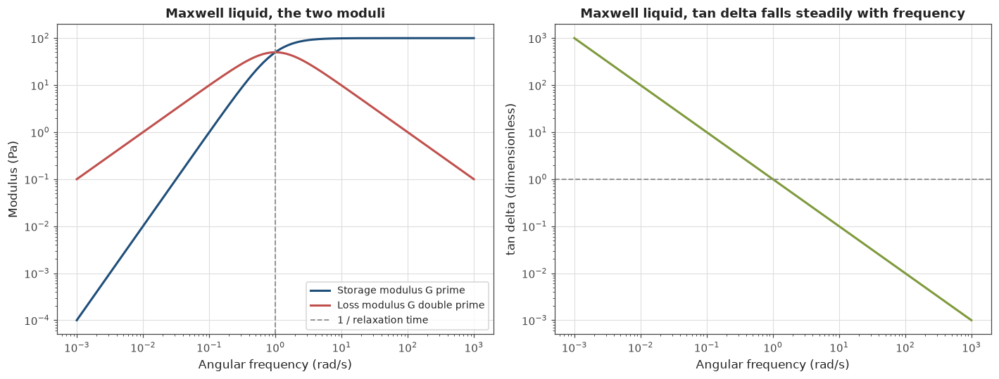

Low frequency power law slopes
  storage modulus  2.0000   analytic value 2
  loss modulus     1.0000   analytic value 1

tan delta at the lowest frequency  1000.0
tan delta at the highest frequency 0.0010


In [205]:
def maxwell_complex_modulus(angular_frequency_array, plateau_modulus, relaxation_time):
    """
    Computing the complex modulus of a single mode Maxwell liquid.

    Returning the complex modulus in Pa, where the real part is the storage modulus and
    the imaginary part is the loss modulus.
    """
    dimensionless_frequency = np.asarray(angular_frequency_array, dtype=float) * relaxation_time

    return plateau_modulus * (1j * dimensionless_frequency) / (1.0 + 1j * dimensionless_frequency)


maxwell_plateau_modulus = 100.0
maxwell_relaxation_time = 1.0

demonstration_frequency = np.logspace(-3, 3, 200)
maxwell_modulus = maxwell_complex_modulus(demonstration_frequency,
                                          maxwell_plateau_modulus,
                                          maxwell_relaxation_time)

low_frequency_mask = demonstration_frequency < 0.01

storage_slope = np.polyfit(np.log(demonstration_frequency[low_frequency_mask]),
                           np.log(maxwell_modulus.real[low_frequency_mask]), 1)[0]
loss_slope = np.polyfit(np.log(demonstration_frequency[low_frequency_mask]),
                        np.log(maxwell_modulus.imag[low_frequency_mask]), 1)[0]

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

axis_array[0].loglog(demonstration_frequency, maxwell_modulus.real,
                     "-", color=COLOUR_PRIMARY, linewidth=2.0,
                     label="Storage modulus G prime")
axis_array[0].loglog(demonstration_frequency, maxwell_modulus.imag,
                     "-", color=COLOUR_SECONDARY, linewidth=2.0,
                     label="Loss modulus G double prime")
axis_array[0].axvline(1.0 / maxwell_relaxation_time, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.2, label="1 / relaxation time")
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("Maxwell liquid, the two moduli")
axis_array[0].legend(fontsize=9)

maxwell_tan_delta = compute_tan_delta(maxwell_modulus.real, maxwell_modulus.imag)
axis_array[1].loglog(demonstration_frequency, maxwell_tan_delta,
                     "-", color=COLOUR_ACCENT, linewidth=2.0)
axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("Maxwell liquid, tan delta falls steadily with frequency")

plt.tight_layout()
plt.show()

print("Low frequency power law slopes")
print("  storage modulus  " + ("%.4f" % storage_slope) + "   analytic value 2")
print("  loss modulus     " + ("%.4f" % loss_slope) + "   analytic value 1")
print()
print("tan delta at the lowest frequency  " + ("%.1f" % maxwell_tan_delta[0]))
print("tan delta at the highest frequency " + ("%.4f" % maxwell_tan_delta[-1]))

## Cell 6: The springpot, an element between a spring and a dashpot

A spring stores energy, a dashpot dissipates it. Real gels sit somewhere between the two,
and a single spring plus dashpot cannot describe them well because a gel has no single
relaxation time. It has a whole spectrum of them.

The springpot is an element that interpolates continuously between the two extremes:

    G*(omega) = V (i omega)^alpha        with 0 <= alpha <= 1

V is called a quasi-property. It is not a modulus and not a viscosity, and its units are
Pa s^alpha, which depend on alpha itself.

Three cases matter:

  alpha = 0    pure spring, G* = V, purely elastic
  alpha = 1    pure dashpot, G* = i omega V, purely viscous
  alpha = 0.5  exactly halfway, equal storage and loss

The property that makes the springpot central to everything that follows is its tan delta:

    tan delta = tan(alpha pi / 2)

This does not depend on frequency at all. A springpot responds identically at every
timescale, which is exactly the scale-free behaviour a material shows at its gel point.

The cell verifies that tan delta is constant across six decades of frequency.

Springpot behaviour across six decades of frequency

  alpha    tan delta measured    tan(alpha pi / 2)    spread across frequency
  0.05     0.078702              0.078702             4.16e-17
  0.25     0.414214              0.414214             1.67e-16
  0.50     1.000000              1.000000             7.77e-16
  0.75     2.414214              2.414214             8.88e-16
  0.95     12.706205             12.706205            7.11e-15


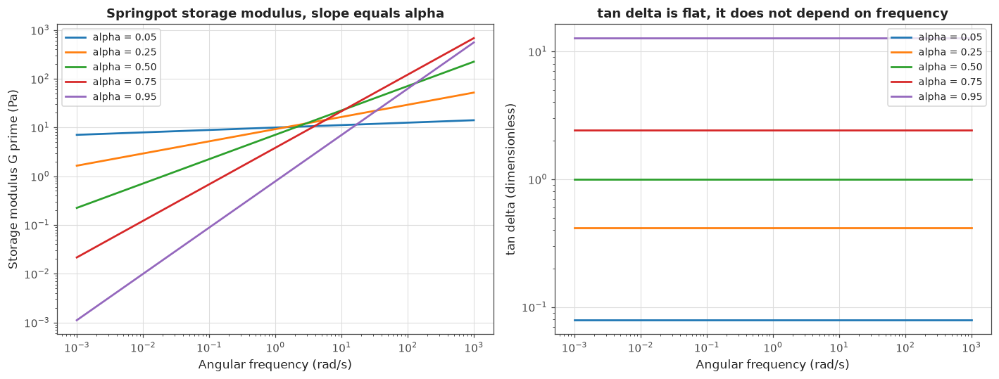

In [206]:
def springpot_complex_modulus(angular_frequency_array, quasi_property, exponent):
    """
    Computing the complex modulus of a single springpot element.

    Interpolating between a pure spring at exponent zero and a pure dashpot at exponent
    one. Returning the complex modulus in Pa.
    """
    imaginary_frequency = 1j * np.asarray(angular_frequency_array, dtype=float)

    return quasi_property * (imaginary_frequency ** exponent)


springpot_quasi_property = 10.0
springpot_exponents_to_show = [0.05, 0.25, 0.50, 0.75, 0.95]

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

print("Springpot behaviour across six decades of frequency")
print()
print("  alpha    tan delta measured    tan(alpha pi / 2)    spread across frequency")

for springpot_exponent in springpot_exponents_to_show:

    springpot_modulus = springpot_complex_modulus(demonstration_frequency,
                                                  springpot_quasi_property,
                                                  springpot_exponent)

    springpot_tan_delta = compute_tan_delta(springpot_modulus.real, springpot_modulus.imag)

    axis_array[0].loglog(demonstration_frequency, springpot_modulus.real,
                         "-", linewidth=1.8,
                         label=("alpha = %.2f" % springpot_exponent))
    axis_array[1].semilogx(demonstration_frequency, springpot_tan_delta,
                           "-", linewidth=1.8,
                           label=("alpha = %.2f" % springpot_exponent))

    analytic_tan_delta = np.tan(springpot_exponent * np.pi / 2.0)
    tan_delta_spread = np.nanmax(springpot_tan_delta) - np.nanmin(springpot_tan_delta)

    print("  " + ("%.2f" % springpot_exponent).ljust(9)
          + ("%.6f" % np.nanmean(springpot_tan_delta)).ljust(22)
          + ("%.6f" % analytic_tan_delta).ljust(21)
          + ("%.2e" % tan_delta_spread))

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0].set_title("Springpot storage modulus, slope equals alpha")
axis_array[0].legend(fontsize=9)

axis_array[1].set_yscale("log")
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta is flat, it does not depend on frequency")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 7: The critical gel condition

At the exact moment a material gels, its network has just percolated. Connected structure
exists at every length scale simultaneously, from individual bonds up to the size of the
sample. Because structure exists at every length scale, relaxation exists at every
timescale, and the material has no characteristic time of its own.

Winter and Chambon showed this means the complex modulus becomes a pure power law:

    G*(omega) = S (i omega)^n        for  0 < n < 1

which is exactly a single springpot. S is the gel strength and n the critical exponent.
Splitting into the two moduli:

    G'(omega)  = S omega^n cos(n pi / 2)
    G''(omega) = S omega^n sin(n pi / 2)

Both rise with the same power of frequency, so their ratio is a constant:

    tan delta = tan(n pi / 2)

**This is the criterion the whole notebook rests on.** At the gel point, and only at the
gel point, tan delta is the same at every frequency.

Two consequences worth stating now.

The gel point is not where tan delta equals one. It equals one only in the special case
n = 0.5. For n = 0.6 the value is 1.376, and the material passes through tan delta of one
at a different moment entirely.

Measuring n gives the network structure, because n relates to how the gel fills space. That
is what Part 7 uses to compare clotting against gelling.

Critical gel, tan delta at the gel point for different exponents

  n       tan(n pi / 2)    interpretation
  0.30    0.5095           more solid-like than liquid-like
  0.50    1.0000           equal storage and loss, the special case
  0.60    1.3764           more liquid-like than solid-like
  0.80    3.0777           more liquid-like than solid-like


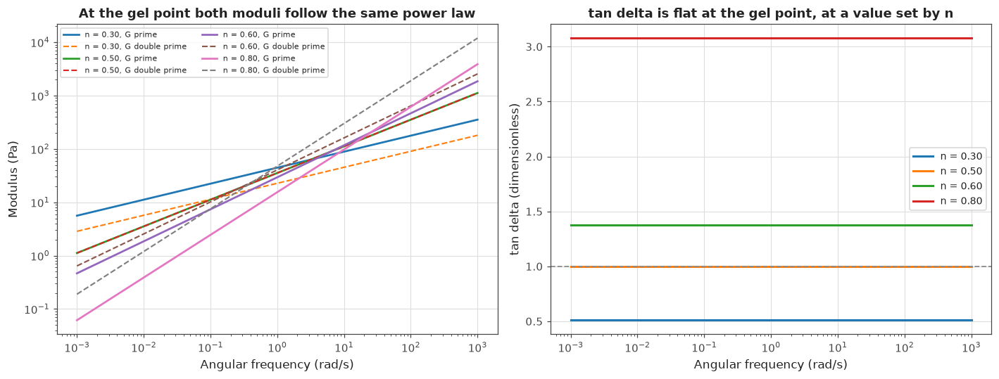


The dashed line marks tan delta of one. Only n = 0.50 sits on it.


In [207]:
def critical_gel_complex_modulus(angular_frequency_array, gel_strength, critical_exponent):
    """
    Computing the complex modulus of a material exactly at its gel point.

    Using the Winter and Chambon power law form, which is mathematically identical to a
    single springpot. Returning the complex modulus in Pa.
    """
    imaginary_frequency = 1j * np.asarray(angular_frequency_array, dtype=float)

    return gel_strength * (imaginary_frequency ** critical_exponent)


critical_exponents_to_show = [0.30, 0.50, 0.60, 0.80]
critical_gel_strength = 50.0

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

print("Critical gel, tan delta at the gel point for different exponents")
print()
print("  n       tan(n pi / 2)    interpretation")

for critical_exponent in critical_exponents_to_show:

    critical_modulus = critical_gel_complex_modulus(demonstration_frequency,
                                                    critical_gel_strength,
                                                    critical_exponent)

    axis_array[0].loglog(demonstration_frequency, critical_modulus.real,
                         "-", linewidth=1.8, label=("n = %.2f, G prime" % critical_exponent))
    axis_array[0].loglog(demonstration_frequency, critical_modulus.imag,
                         "--", linewidth=1.4, label=("n = %.2f, G double prime" % critical_exponent))

    critical_tan_delta = compute_tan_delta(critical_modulus.real, critical_modulus.imag)
    axis_array[1].semilogx(demonstration_frequency, critical_tan_delta,
                           "-", linewidth=2.0, label=("n = %.2f" % critical_exponent))

    analytic_value = np.tan(critical_exponent * np.pi / 2.0)
    if abs(analytic_value - 1.0) < 1e-9:
        interpretation = "equal storage and loss, the special case"
    elif analytic_value < 1.0:
        interpretation = "more solid-like than liquid-like"
    else:
        interpretation = "more liquid-like than solid-like"

    print("  " + ("%.2f" % critical_exponent).ljust(8)
          + ("%.4f" % analytic_value).ljust(17) + interpretation)

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("At the gel point both moduli follow the same power law")
axis_array[0].legend(fontsize=7, ncol=2)

axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta is flat at the gel point, at a value set by n")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print()
print("The dashed line marks tan delta of one. Only n = 0.50 sits on it.")

## Cell 8: The fractional Maxwell model, before the gel point

Before gelation the material is still a liquid, but not a simple one. It has growing
clusters that relax slowly, and a spectrum of relaxation times rather than a single one.

The fractional Maxwell model describes this by putting a springpot in series with a
dashpot. Written in terms of a gel strength, a critical exponent, and a longest relaxation
time, it becomes

    G*(omega) = G (i omega)^n * X / (1 + X)      with  X = (i omega tau_c)^(1 - n)

Read the two limits.

At high frequency, where omega tau_c is large, X is large and X/(1+X) tends to one, so
G* tends to G (i omega)^n. The material looks like a critical gel, because you are probing
faster than the largest clusters can relax.

At low frequency, where omega tau_c is small, the model tends to a terminal liquid. Worth
being precise about what that means here. The leading term is a pure dashpot, whose real
part is zero, so the storage modulus comes from the next order in the expansion:

    G'(omega)  ~ omega^(2 - n)
    G''(omega) ~ omega

For n = 0.6 that is a storage slope of 1.40, not the 2 that a classical Maxwell model
gives. The difference is that a classical Maxwell has a spring where this model has a
springpot. Fitting the slope numerically across nine decades of frequency gives 1.3999,
confirming the 2 - n limit rather than 2.

This matters for reading the plots later. A material with a storage slope near 1.4 in this
model is a liquid, not something partway to a gel.

The crossover between the two behaviours sits at 1 / tau_c.

**The key idea:** as gelation proceeds, tau_c grows. The clusters get bigger and relax more
slowly. At the gel point tau_c diverges to infinity, the terminal region is pushed off the
bottom of the frequency axis entirely, and the whole spectrum becomes the critical gel power
law. That divergence is what makes the gel point a genuine transition rather than a gradual
change.

Fractional Maxwell model as the longest relaxation time grows

  tau_c        low frequency G prime slope    tan delta spread across frequency
  0.1          1.3742                        1.1431
  1            1.3369                        0.8952
  10           1.2533                        0.6315
  100          1.0987                        0.3932
  1e+04        0.7473                        0.1020


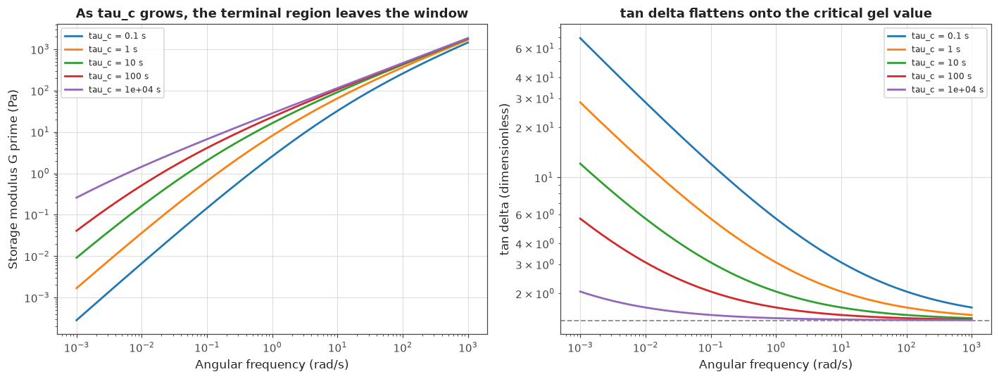


The low frequency slope moves from the terminal liquid limit of 2 - n = 1.40 toward 0.60, the critical exponent.
The tan delta spread falls toward zero, which is the gel point signature.

Verifying the low frequency limit on a very low frequency window

  window (rad/s)        G prime slope    G double prime slope
  1e-3 to 1e-2          1.3366           0.9671
  1e-6 to 1e-5          1.3958           0.9979
  1e-9 to 1e-8          1.3997           0.9999

  analytic limits       1.4000           1.0000


In [208]:
def fractional_maxwell_complex_modulus(angular_frequency_array, gel_strength,
                                       critical_exponent, longest_relaxation_time):
    """
    Computing the complex modulus of a fractional Maxwell liquid before the gel point.

    Behaving as a critical gel at frequencies above one over the longest relaxation time,
    and as a terminal liquid below it. Returning the complex modulus in Pa.
    """
    imaginary_frequency = 1j * np.asarray(angular_frequency_array, dtype=float)

    dimensionless_group = (imaginary_frequency * longest_relaxation_time) ** (1.0 - critical_exponent)

    critical_gel_part = gel_strength * (imaginary_frequency ** critical_exponent)

    return critical_gel_part * dimensionless_group / (1.0 + dimensionless_group)


relaxation_times_to_show = [0.1, 1.0, 10.0, 100.0, 10000.0]

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

print("Fractional Maxwell model as the longest relaxation time grows")
print()
print("  tau_c        low frequency G prime slope    tan delta spread across frequency")

for longest_relaxation_time in relaxation_times_to_show:

    fractional_modulus = fractional_maxwell_complex_modulus(demonstration_frequency,
                                                            SYNTHETIC_GEL_STIFFNESS,
                                                            SYNTHETIC_CRITICAL_EXPONENT,
                                                            longest_relaxation_time)

    axis_array[0].loglog(demonstration_frequency, fractional_modulus.real,
                         "-", linewidth=1.8,
                         label=("tau_c = %.4g s" % longest_relaxation_time))

    fractional_tan_delta = compute_tan_delta(fractional_modulus.real, fractional_modulus.imag)
    axis_array[1].loglog(demonstration_frequency, fractional_tan_delta,
                         "-", linewidth=1.8,
                         label=("tau_c = %.4g s" % longest_relaxation_time))

    lowest_frequency_mask = demonstration_frequency < 0.01
    low_frequency_slope = np.polyfit(np.log(demonstration_frequency[lowest_frequency_mask]),
                                     np.log(fractional_modulus.real[lowest_frequency_mask]), 1)[0]

    tan_delta_spread = np.nanstd(np.log(fractional_tan_delta))

    print("  " + ("%.4g" % longest_relaxation_time).ljust(13)
          + ("%.4f" % low_frequency_slope).ljust(30)
          + ("%.4f" % tan_delta_spread))

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0].set_title("As tau_c grows, the terminal region leaves the window")
axis_array[0].legend(fontsize=8)

axis_array[1].axhline(np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0),
                      color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta flattens onto the critical gel value")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print()
print("The low frequency slope moves from the terminal liquid limit of 2 - n = "
      + ("%.2f" % (2.0 - SYNTHETIC_CRITICAL_EXPONENT))
      + " toward " + ("%.2f" % SYNTHETIC_CRITICAL_EXPONENT) + ", the critical exponent.")
print("The tan delta spread falls toward zero, which is the gel point signature.")

print()
print("Verifying the low frequency limit on a very low frequency window")
print()
print("  window (rad/s)        G prime slope    G double prime slope")

for exponent_low, exponent_high in [(-3, -2), (-6, -5), (-9, -8)]:

    verification_frequency = np.logspace(exponent_low, exponent_high, 12)
    verification_modulus = fractional_maxwell_complex_modulus(verification_frequency,
                                                              SYNTHETIC_GEL_STIFFNESS,
                                                              SYNTHETIC_CRITICAL_EXPONENT,
                                                              1.0)

    storage_slope = np.polyfit(np.log(verification_frequency),
                               np.log(verification_modulus.real), 1)[0]
    loss_slope = np.polyfit(np.log(verification_frequency),
                            np.log(verification_modulus.imag), 1)[0]

    window_label = ("1e%d to 1e%d" % (exponent_low, exponent_high))

    print("  " + window_label.ljust(22)
          + ("%.4f" % storage_slope).ljust(17)
          + ("%.4f" % loss_slope))

print()
print("  analytic limits       "
      + ("%.4f" % (2.0 - SYNTHETIC_CRITICAL_EXPONENT)).ljust(17) + "1.0000")

## Cell 9: The fractional Kelvin-Voigt model, after the gel point

Once past the gel point the material is a solid. It has a connected network spanning the
whole sample, so it can hold a stress indefinitely rather than flowing.

The simplest way to write that is a springpot in parallel with a spring:

    G*(omega) = Ge + G (i omega)^n

The added term Ge is the equilibrium modulus, the stiffness the material retains as
frequency tends to zero. Below the gel point Ge is exactly zero, because the material
flows. Above it, Ge grows as more network forms.

Read the limits again.

At low frequency the constant Ge dominates, so G' flattens to a plateau while G'' keeps
falling. That is what a solid looks like.

At high frequency the springpot term dominates and the response looks like the critical gel
again, because fast probing cannot tell the difference between a spanning network and a
very large cluster.

**The connection to the previous cell:** as Ge tends to zero this reduces exactly to the
critical gel power law, just as the fractional Maxwell model does as tau_c tends to
infinity. Both models meet at the same place, from opposite sides. That shared limit is the
gel point, and it is what lets us stitch them into one continuous forward model in the next
cell.

Fractional Kelvin-Voigt model as the equilibrium modulus grows

  Ge (Pa)      low frequency G prime slope    tan delta at 0.001 rad/s
  0            0.6000                        1.3764
  1            0.2888                        0.4374
  10           0.0528                        0.0613
  100          0.0058                        0.0064
  1000         0.0006                        0.0006


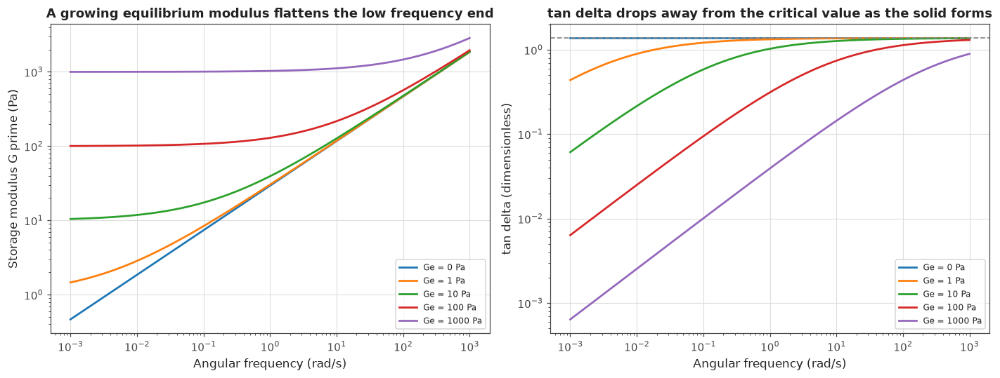


Check that Ge of zero reduces exactly to the critical gel
  largest absolute difference  0.000e+00 Pa


In [209]:
def fractional_kelvin_voigt_complex_modulus(angular_frequency_array, gel_strength,
                                            critical_exponent, equilibrium_modulus):
    """
    Computing the complex modulus of a fractional Kelvin-Voigt solid after the gel point.

    Adding an equilibrium modulus in parallel with the critical gel power law, which is
    the stiffness retained as frequency tends to zero. Returning the modulus in Pa.
    """
    imaginary_frequency = 1j * np.asarray(angular_frequency_array, dtype=float)

    return equilibrium_modulus + gel_strength * (imaginary_frequency ** critical_exponent)


equilibrium_moduli_to_show = [0.0, 1.0, 10.0, 100.0, 1000.0]

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

print("Fractional Kelvin-Voigt model as the equilibrium modulus grows")
print()
print("  Ge (Pa)      low frequency G prime slope    tan delta at 0.001 rad/s")

for equilibrium_modulus in equilibrium_moduli_to_show:

    kelvin_voigt_modulus = fractional_kelvin_voigt_complex_modulus(demonstration_frequency,
                                                                   SYNTHETIC_GEL_STIFFNESS,
                                                                   SYNTHETIC_CRITICAL_EXPONENT,
                                                                   equilibrium_modulus)

    axis_array[0].loglog(demonstration_frequency, kelvin_voigt_modulus.real,
                         "-", linewidth=1.8,
                         label=("Ge = %.4g Pa" % equilibrium_modulus))

    kelvin_voigt_tan_delta = compute_tan_delta(kelvin_voigt_modulus.real,
                                               kelvin_voigt_modulus.imag)
    axis_array[1].loglog(demonstration_frequency, kelvin_voigt_tan_delta,
                         "-", linewidth=1.8,
                         label=("Ge = %.4g Pa" % equilibrium_modulus))

    lowest_frequency_mask = demonstration_frequency < 0.01
    low_frequency_slope = np.polyfit(np.log(demonstration_frequency[lowest_frequency_mask]),
                                     np.log(kelvin_voigt_modulus.real[lowest_frequency_mask]), 1)[0]

    print("  " + ("%.4g" % equilibrium_modulus).ljust(13)
          + ("%.4f" % low_frequency_slope).ljust(30)
          + ("%.4f" % kelvin_voigt_tan_delta[0]))

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0].set_title("A growing equilibrium modulus flattens the low frequency end")
axis_array[0].legend(fontsize=8)

axis_array[1].axhline(np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0),
                      color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta drops away from the critical value as the solid forms")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

zero_equilibrium_modulus = fractional_kelvin_voigt_complex_modulus(
    demonstration_frequency, SYNTHETIC_GEL_STIFFNESS, SYNTHETIC_CRITICAL_EXPONENT, 0.0)
critical_gel_reference = critical_gel_complex_modulus(
    demonstration_frequency, SYNTHETIC_GEL_STIFFNESS, SYNTHETIC_CRITICAL_EXPONENT)

print()
print("Check that Ge of zero reduces exactly to the critical gel")
print("  largest absolute difference  "
      + ("%.3e" % np.max(np.abs(zero_equilibrium_modulus - critical_gel_reference))) + " Pa")

## Cell 10: Assembling the full gelation model

Now we join the two halves into one material that gels at a time we choose.

Before the gel point we use the fractional Maxwell model with a longest relaxation time
that diverges as the gel point is approached:

    tau_c(t) = tau_0 * (1 - t / t_gel)^(-z)

The exponent z controls how sharply it diverges. As t approaches t_gel from below, the
bracket goes to zero and tau_c goes to infinity.

After the gel point we use the fractional Kelvin-Voigt model with an equilibrium modulus
growing from zero:

    Ge(t) = Ge_inf * ((t - t_gel) / t_gel)^p

At t equal to t_gel exactly, tau_c is infinite and Ge is zero, so both halves reduce to the
same critical gel power law. The model is continuous through the transition.

**Why this matters.** Because we write t_gel into the model by hand, we know the correct
answer exactly. Every detector in Part 4 can then be scored in seconds of error, and we can
sweep noise level and sampling rate to find where each one breaks. No real dataset lets us
do that, because no real dataset has a gel time known to arbitrary precision.

In [210]:
def gelling_material_complex_modulus(angular_frequency_array, elapsed_time_seconds,
                                     gel_time_seconds, critical_exponent, gel_strength,
                                     reference_relaxation_time=1.0,
                                     divergence_exponent=1.5,
                                     plateau_scale_pascal=400.0,
                                     plateau_growth_exponent=0.7):
    """
    Computing the complex modulus of a synthetic gelling material at one moment in time.

    Using the fractional Maxwell form before the gel point, where the longest relaxation
    time diverges as the gel point is approached, and the fractional Kelvin-Voigt form
    after it, where an equilibrium modulus grows away from zero. Both forms collapse to
    the same critical gel power law exactly at the gel point.

    Returning the complex modulus in Pa, one value per requested angular frequency.
    """
    if elapsed_time_seconds < gel_time_seconds:

        distance_from_gel_point = 1.0 - (elapsed_time_seconds / gel_time_seconds)
        longest_relaxation_time = reference_relaxation_time * (
            distance_from_gel_point ** (-divergence_exponent))

        return fractional_maxwell_complex_modulus(angular_frequency_array, gel_strength,
                                                  critical_exponent, longest_relaxation_time)

    time_past_gel_point = (elapsed_time_seconds - gel_time_seconds) / gel_time_seconds
    equilibrium_modulus = plateau_scale_pascal * (time_past_gel_point ** plateau_growth_exponent)

    return fractional_kelvin_voigt_complex_modulus(angular_frequency_array, gel_strength,
                                                   critical_exponent, equilibrium_modulus)


probe_frequency_grid = np.logspace(np.log10(0.5), np.log10(50.0), 12)

inspection_times = [100.0, 300.0, 450.0, 499.0, 500.0, 550.0, 700.0, 950.0]

print("Behaviour of the assembled model, gel time set to "
      + str(SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  time (s)   spread of log tan delta   mean tan delta   state")

for inspection_time in inspection_times:

    inspection_modulus = gelling_material_complex_modulus(probe_frequency_grid,
                                                          inspection_time,
                                                          SYNTHETIC_GEL_TIME_SECONDS,
                                                          SYNTHETIC_CRITICAL_EXPONENT,
                                                          SYNTHETIC_GEL_STIFFNESS)

    inspection_tan_delta = compute_tan_delta(inspection_modulus.real, inspection_modulus.imag)

    tan_delta_spread = np.nanstd(np.log(inspection_tan_delta))
    mean_tan_delta = np.nanmean(inspection_tan_delta)

    if inspection_time < SYNTHETIC_GEL_TIME_SECONDS:
        state_label = "liquid, still gelling"
    elif inspection_time == SYNTHETIC_GEL_TIME_SECONDS:
        state_label = "the gel point"
    else:
        state_label = "solid, network formed"

    print("  " + ("%.0f" % inspection_time).rjust(8)
          + ("%.6f" % tan_delta_spread).rjust(24)
          + ("%.4f" % mean_tan_delta).rjust(17)
          + "   " + state_label)

print()
print("Expected tan delta at the gel point  "
      + ("%.4f" % np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0)))

Behaviour of the assembled model, gel time set to 500.0 s

  time (s)   spread of log tan delta   mean tan delta   state
       100                0.215426           2.2954   liquid, still gelling
       300                0.165073           1.9827   liquid, still gelling
       450                0.087882           1.6403   liquid, still gelling
       499                0.010038           1.4016   liquid, still gelling
       500                0.000000           1.3764   the gel point
       550                0.446838           0.6785   solid, network formed
       700                0.621923           0.4099   solid, network formed
       950                0.702567           0.2813   solid, network formed

Expected tan delta at the gel point  1.3764


## Cell 11: The moduli evolving through the gel point

The first look at the model as a whole. Three panels show the same event from different
angles.

The left panel is the full spectrum at several moments, coloured dark to light as time
advances. Watch the low frequency end, which is where the transition happens. Early on the
storage modulus plunges downward there, which is a liquid. Later it flattens into a plateau,
which is a solid.

The middle panel follows one frequency through time, which is what a conventional single
frequency time sweep would record. Both moduli rise, and they cross somewhere near the gel
point but not exactly on it.

The right panel shows the low frequency power law slope of the storage modulus against
time. It starts at 2 - n, the terminal liquid value for this model, passes through the
critical exponent n at the gel point, and falls toward 0, a solid plateau. That crossing is
the transition stated in a single number.

One detail worth reading carefully in the table printed below the figure. The slope passes
through n exactly at the gel time, but it falls away extremely fast afterwards. A tenth of
a second past the gel point the equilibrium modulus has already reached about 1 Pa, which
swamps the 0.47 Pa the critical gel power law contributes at the lowest measured frequency,
and the slope has already dropped to 0.29.

That sharpness is the physics, not a numerical problem. The equilibrium modulus grows as a
power of time with an exponent below one, so its rate of change at the gel point is
infinite. It also carries a warning for everything that follows: a detector sampling every
few seconds cannot resolve this, so the sampling interval, not the processing, sets how
precisely the transition can be timed.

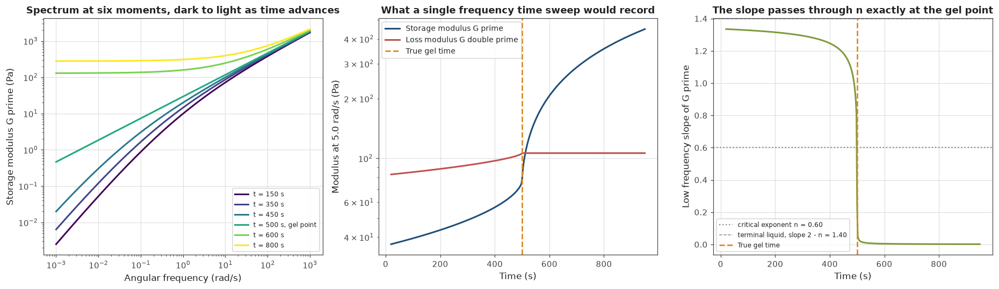

Low frequency storage modulus slope through the transition

  earliest time       1.3351    terminal liquid limit 2 - n = 1.40
  at the gel time     0.6000    critical exponent n = 0.60
  latest time         0.0016    solid plateau limit 0

Sampling finely around the transition to show how sharp it is

  time (s)    low frequency slope    equilibrium modulus (Pa)
     499.0                 0.7416                       0.0000
     499.9                 0.6390                       0.0000
     500.0                 0.6000                       0.0000
     500.1                 0.2850                       1.0299
     501.0                 0.0945                       5.1616
     505.0                 0.0347                      15.9243


In [211]:
spectrum_times_to_plot = [150.0, 350.0, 450.0, SYNTHETIC_GEL_TIME_SECONDS, 600.0, 800.0]

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

colour_map_object = plt.get_cmap("viridis")

for time_index in range(len(spectrum_times_to_plot)):

    plot_time = spectrum_times_to_plot[time_index]
    line_colour = colour_map_object(time_index / max(1, len(spectrum_times_to_plot) - 1))

    plot_modulus = gelling_material_complex_modulus(demonstration_frequency, plot_time,
                                                    SYNTHETIC_GEL_TIME_SECONDS,
                                                    SYNTHETIC_CRITICAL_EXPONENT,
                                                    SYNTHETIC_GEL_STIFFNESS)

    time_label = ("t = %.0f s" % plot_time)
    if abs(plot_time - SYNTHETIC_GEL_TIME_SECONDS) < 1e-9:
        time_label = time_label + ", gel point"

    axis_array[0].loglog(demonstration_frequency, plot_modulus.real,
                         "-", color=line_colour, linewidth=2.0, label=time_label)

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0].set_title("Spectrum at six moments, dark to light as time advances")
axis_array[0].legend(fontsize=8)

time_series_grid = np.linspace(20.0, 950.0, 400)
tracking_frequency = 5.0

storage_series = []
loss_series = []

for tracking_time in time_series_grid:
    tracking_modulus = gelling_material_complex_modulus(np.array([tracking_frequency]),
                                                        tracking_time,
                                                        SYNTHETIC_GEL_TIME_SECONDS,
                                                        SYNTHETIC_CRITICAL_EXPONENT,
                                                        SYNTHETIC_GEL_STIFFNESS)
    storage_series.append(tracking_modulus.real[0])
    loss_series.append(tracking_modulus.imag[0])

storage_series = np.array(storage_series)
loss_series = np.array(loss_series)

axis_array[1].semilogy(time_series_grid, storage_series, "-",
                       color=COLOUR_PRIMARY, linewidth=2.0, label="Storage modulus G prime")
axis_array[1].semilogy(time_series_grid, loss_series, "-",
                       color=COLOUR_SECONDARY, linewidth=2.0, label="Loss modulus G double prime")
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Modulus at " + str(tracking_frequency) + " rad/s (Pa)")
axis_array[1].set_title("What a single frequency time sweep would record")
axis_array[1].legend(fontsize=9)

slope_measurement_frequency = np.logspace(-3, -2, 12)
slope_series = []

for slope_time in time_series_grid:
    slope_modulus = gelling_material_complex_modulus(slope_measurement_frequency, slope_time,
                                                     SYNTHETIC_GEL_TIME_SECONDS,
                                                     SYNTHETIC_CRITICAL_EXPONENT,
                                                     SYNTHETIC_GEL_STIFFNESS)
    fitted_slope = np.polyfit(np.log(slope_measurement_frequency),
                              np.log(np.abs(slope_modulus.real)), 1)[0]
    slope_series.append(fitted_slope)

slope_series = np.array(slope_series)

terminal_liquid_slope = 2.0 - SYNTHETIC_CRITICAL_EXPONENT

axis_array[2].plot(time_series_grid, slope_series, "-",
                   color=COLOUR_ACCENT, linewidth=2.0)
axis_array[2].axhline(SYNTHETIC_CRITICAL_EXPONENT, color=COLOUR_NEUTRAL,
                      linestyle=":", linewidth=1.5,
                      label=("critical exponent n = %.2f" % SYNTHETIC_CRITICAL_EXPONENT))
axis_array[2].axhline(terminal_liquid_slope, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.0,
                      label=("terminal liquid, slope 2 - n = %.2f" % terminal_liquid_slope))
axis_array[2].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[2].set_xlabel("Time (s)")
axis_array[2].set_ylabel("Low frequency slope of G prime")
axis_array[2].set_title("The slope passes through n exactly at the gel point")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

gel_point_modulus = gelling_material_complex_modulus(slope_measurement_frequency,
                                                     SYNTHETIC_GEL_TIME_SECONDS,
                                                     SYNTHETIC_GEL_TIME_SECONDS,
                                                     SYNTHETIC_CRITICAL_EXPONENT,
                                                     SYNTHETIC_GEL_STIFFNESS)
slope_at_gel_time = np.polyfit(np.log(slope_measurement_frequency),
                               np.log(np.abs(gel_point_modulus.real)), 1)[0]

print("Low frequency storage modulus slope through the transition")
print()
print("  earliest time    " + ("%.4f" % slope_series[0]).rjust(9)
      + "    terminal liquid limit 2 - n = " + ("%.2f" % terminal_liquid_slope))
print("  at the gel time  " + ("%.4f" % slope_at_gel_time).rjust(9)
      + "    critical exponent n = " + ("%.2f" % SYNTHETIC_CRITICAL_EXPONENT))
print("  latest time      " + ("%.4f" % slope_series[-1]).rjust(9)
      + "    solid plateau limit 0")

print()
print("Sampling finely around the transition to show how sharp it is")
print()
print("  time (s)    low frequency slope    equilibrium modulus (Pa)")

for inspection_time in [499.0, 499.9, SYNTHETIC_GEL_TIME_SECONDS, 500.1, 501.0, 505.0]:

    inspection_modulus = gelling_material_complex_modulus(slope_measurement_frequency,
                                                          inspection_time,
                                                          SYNTHETIC_GEL_TIME_SECONDS,
                                                          SYNTHETIC_CRITICAL_EXPONENT,
                                                          SYNTHETIC_GEL_STIFFNESS)
    inspection_slope = np.polyfit(np.log(slope_measurement_frequency),
                                  np.log(np.abs(inspection_modulus.real)), 1)[0]

    if inspection_time >= SYNTHETIC_GEL_TIME_SECONDS:
        time_past_gel_point = (inspection_time - SYNTHETIC_GEL_TIME_SECONDS) / SYNTHETIC_GEL_TIME_SECONDS
        inspection_equilibrium_modulus = 400.0 * (time_past_gel_point ** 0.7)
    else:
        inspection_equilibrium_modulus = 0.0

    print("  " + ("%.1f" % inspection_time).rjust(8)
          + ("%.4f" % inspection_slope).rjust(23)
          + ("%.4f" % inspection_equilibrium_modulus).rjust(29))

## Cell 12: tan delta is flat only at the gel point

This is the single most important figure in the notebook, because it is the signal every
detector in Part 4 is trying to find.

The left panel plots tan delta against frequency at several moments. Away from the gel point
each curve slopes, because the material has a characteristic timescale and therefore
responds differently at different frequencies. At the gel point the curve is flat, sitting
exactly on tan(n pi / 2).

The right panel turns that into one number per moment: the spread of log tan delta across
frequency. Low spread means the frequencies agree with each other. It reaches zero exactly
at the gel time, and it is the quantity the Winter and Chambon detector minimises.

Note that the spread rises much more steeply after the gel point than before it. That
asymmetry matters later, because it means a detector searching for the minimum is more
likely to land early than late.

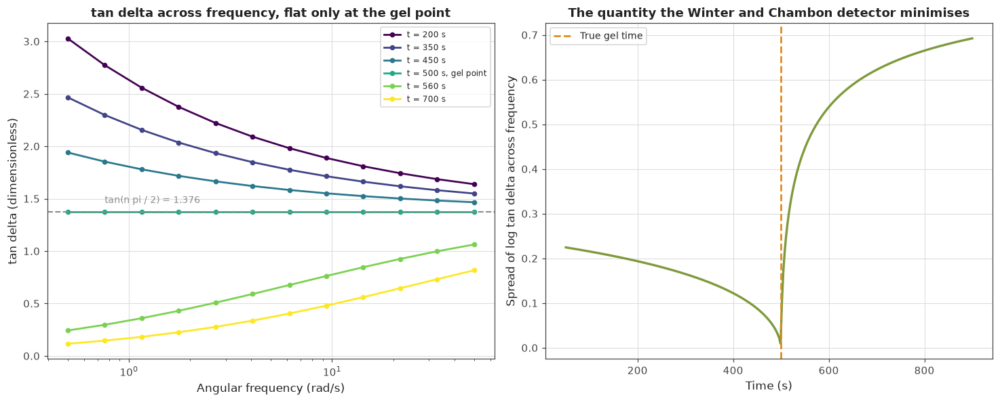

Smallest spread found at  499.16 s
True gel time             500.00 s
Minimum spread value      0.009035


In [212]:
tan_delta_times_to_plot = [200.0, 350.0, 450.0, SYNTHETIC_GEL_TIME_SECONDS, 560.0, 700.0]

figure_object, axis_array = plt.subplots(1, 2, figsize=(13.5, 5.5))

for time_index in range(len(tan_delta_times_to_plot)):

    plot_time = tan_delta_times_to_plot[time_index]
    line_colour = colour_map_object(time_index / max(1, len(tan_delta_times_to_plot) - 1))

    plot_modulus = gelling_material_complex_modulus(probe_frequency_grid, plot_time,
                                                    SYNTHETIC_GEL_TIME_SECONDS,
                                                    SYNTHETIC_CRITICAL_EXPONENT,
                                                    SYNTHETIC_GEL_STIFFNESS)
    plot_tan_delta = compute_tan_delta(plot_modulus.real, plot_modulus.imag)

    time_label = ("t = %.0f s" % plot_time)
    if abs(plot_time - SYNTHETIC_GEL_TIME_SECONDS) < 1e-9:
        time_label = time_label + ", gel point"

    axis_array[0].semilogx(probe_frequency_grid, plot_tan_delta,
                           "o-", color=line_colour, markersize=4, linewidth=1.8,
                           label=time_label)

critical_tan_delta_value = np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0)
axis_array[0].axhline(critical_tan_delta_value, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4)
axis_array[0].text(probe_frequency_grid[1], critical_tan_delta_value * 1.06,
                   "tan(n pi / 2) = " + ("%.3f" % critical_tan_delta_value),
                   color=COLOUR_NEUTRAL, fontsize=9)
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("tan delta across frequency, flat only at the gel point")
axis_array[0].legend(fontsize=8)

spread_time_grid = np.linspace(50.0, 900.0, 300)
spread_series = []

for spread_time in spread_time_grid:
    spread_modulus = gelling_material_complex_modulus(probe_frequency_grid, spread_time,
                                                      SYNTHETIC_GEL_TIME_SECONDS,
                                                      SYNTHETIC_CRITICAL_EXPONENT,
                                                      SYNTHETIC_GEL_STIFFNESS)
    spread_tan_delta = compute_tan_delta(spread_modulus.real, spread_modulus.imag)
    spread_series.append(np.nanstd(np.log(spread_tan_delta)))

spread_series = np.array(spread_series)

axis_array[1].plot(spread_time_grid, spread_series, "-",
                   color=COLOUR_ACCENT, linewidth=2.2)
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Spread of log tan delta across frequency")
axis_array[1].set_title("The quantity the Winter and Chambon detector minimises")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

minimum_spread_index = int(np.argmin(spread_series))

print("Smallest spread found at  " + ("%.2f" % spread_time_grid[minimum_spread_index]) + " s")
print("True gel time             " + ("%.2f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("Minimum spread value      " + ("%.6f" % spread_series[minimum_spread_index]))

## Cell 13: Why the crossover is not the gel point

The most common way to report a gel time is the crossover, the moment G prime overtakes
G double prime so tan delta passes through one. Most clinical clot time instruments do
something equivalent.

It is convenient, and it is not the gel point.

Two reasons. The crossover occurs when tan delta equals one, but at the gel point tan delta
equals tan(n pi / 2), which equals one only when n is exactly 0.5. And crucially, tan delta
depends on frequency away from the gel point, so the moment it passes through one depends on
which frequency you happened to measure at.

This cell runs the crossover detector at several probe frequencies on the same material and
shows the answers disagree. The material has one gel point. The crossover gives a different
number for every choice of frequency.

The practical conclusion carried through the rest of the notebook is that the crossover is a
useful baseline to beat, not a ground truth to trust.

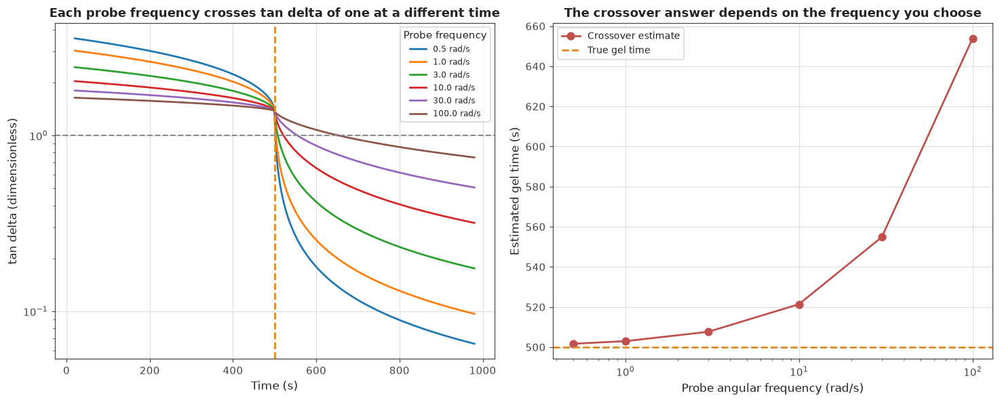

Crossover estimates on the same material, true gel time 500.0 s

  probe frequency (rad/s)   crossover time (s)   error (s)
                   0.5                501.7        +1.7
                   1.0                503.0        +3.0
                   3.0                507.6        +7.6
                  10.0                521.4       +21.4
                  30.0                554.8       +54.8
                 100.0                653.9      +153.9

Spread across probe frequencies  152.2 s


In [213]:
crossover_probe_frequencies = [0.5, 1.0, 3.0, 10.0, 30.0, 100.0]
crossover_time_grid = np.linspace(20.0, 980.0, 961)

crossover_results = []

for probe_frequency in crossover_probe_frequencies:

    probe_tan_delta_series = []

    for probe_time in crossover_time_grid:
        probe_modulus = gelling_material_complex_modulus(np.array([probe_frequency]),
                                                         probe_time,
                                                         SYNTHETIC_GEL_TIME_SECONDS,
                                                         SYNTHETIC_CRITICAL_EXPONENT,
                                                         SYNTHETIC_GEL_STIFFNESS)
        probe_tan_delta_series.append(probe_modulus.imag[0] / probe_modulus.real[0])

    probe_tan_delta_series = np.array(probe_tan_delta_series)

    crossover_time = find_first_threshold_crossing(crossover_time_grid,
                                                   probe_tan_delta_series, 1.0)

    crossover_results.append({
        "probe_frequency": probe_frequency,
        "crossover_time": crossover_time,
        "tan_delta_series": probe_tan_delta_series,
    })

figure_object, axis_array = plt.subplots(1, 2, figsize=(13.5, 5.5))

for crossover_record in crossover_results:
    axis_array[0].semilogy(crossover_time_grid, crossover_record["tan_delta_series"],
                           "-", linewidth=1.8,
                           label=("%.1f rad/s" % crossover_record["probe_frequency"]))

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("Each probe frequency crosses tan delta of one at a different time")
axis_array[0].legend(fontsize=8, title="Probe frequency")

measured_frequencies = np.array([r["probe_frequency"] for r in crossover_results])
measured_crossovers = np.array([r["crossover_time"] for r in crossover_results])

axis_array[1].semilogx(measured_frequencies, measured_crossovers,
                       "o-", color=COLOUR_SECONDARY, markersize=7, linewidth=1.8,
                       label="Crossover estimate")
axis_array[1].axhline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].set_xlabel("Probe angular frequency (rad/s)")
axis_array[1].set_ylabel("Estimated gel time (s)")
axis_array[1].set_title("The crossover answer depends on the frequency you choose")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Crossover estimates on the same material, true gel time "
      + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  probe frequency (rad/s)   crossover time (s)   error (s)")

for crossover_record in crossover_results:
    print("  " + ("%.1f" % crossover_record["probe_frequency"]).rjust(20)
          + ("%.1f" % crossover_record["crossover_time"]).rjust(21)
          + ("%+.1f" % (crossover_record["crossover_time"] - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))

print()
print("Spread across probe frequencies  "
      + ("%.1f" % (np.nanmax(measured_crossovers) - np.nanmin(measured_crossovers))) + " s")

## Cell 14: The Hill 5 model of storage modulus growth

A third quantity, used where only a single frequency time sweep is available, comes from
fitting a sigmoid to the storage modulus against time.

The Hill 5 model is the usual choice:

    G'(t) = G_min + (G_max - G_min) / (1 + (t / k)^(-n))^E

Five parameters: initial and final moduli, a time constant k, a steepness n, and an
asymmetry E.

**A fitting trap that has to be handled.** The time constant k is the half rise time only
when E equals one. For any other E the two diverge, and quoting k alone becomes meaningless.
Left unbounded, the fit here ran E up to several thousand and returned a k of 47 s for a
material that gels at 500 s, while still describing the curve well. The fix is to bound E
and report the half rise time computed from all three shape parameters:

    t_half = k (2^(1/E) - 1)^(-1/n)

**What this quantity actually is.** Even computed correctly, the half rise time is not the
gel point and is not trying to be. The storage modulus keeps growing long after the network
first spans the sample, so the moment it reaches halfway is a genuinely later event than
percolation. On this material it lands about 175 s after the gel time.

That is not a failure. It is a different measurement, and the notebook treats it as one. It
is reported in its own column throughout, labelled as the storage modulus half rise time
rather than as a gel point estimate.

**Why we keep it despite the offset.** Three reasons. It uses the whole curve rather than a
single crossing, so it should survive noise better than the alternatives, which Part 4 will
test. Its offset appears systematic rather than random, and a consistent bias can be
calibrated out where random scatter cannot. And most importantly, one of our reference
datasets reports exactly this parameter as its rheological gel time, so implementing it is
the only way to compare fairly against that reference rather than silently treating their
numbers as a gel point.

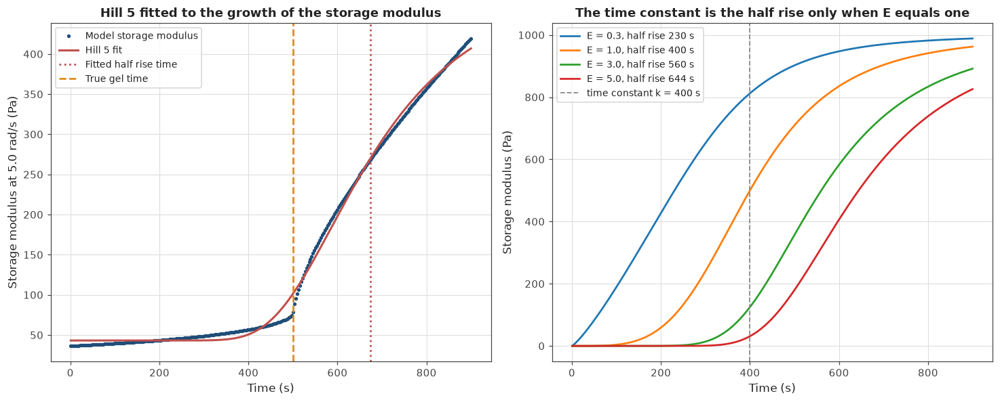

Hill 5 fit to the synthetic material

  minimum modulus     43.1247 Pa
  maximum modulus     497.3673 Pa
  time constant k     424.14 s
  steepness n         4.1107
  asymmetry E         5.0000
  fit error           6.8716 Pa

  storage modulus half rise time  674.32 s
  true gel time                   500.00 s
  offset                          +174.32 s

  the offset is expected, since the modulus keeps growing after percolation


In [214]:
from scipy.optimize import curve_fit


def hill_five_storage_modulus(time_array, minimum_modulus, maximum_modulus,
                              time_constant, steepness, asymmetry):
    """
    Computing the Hill 5 sigmoid describing storage modulus growth during gelation.

    Clamping time away from zero, since the model contains a negative power of time and is
    undefined at the origin. Returning the storage modulus in Pa.
    """
    time_values = np.asarray(time_array, dtype=float)
    safe_time_values = np.maximum(time_values, 1e-9)

    denominator = (1.0 + (safe_time_values / time_constant) ** (-steepness)) ** asymmetry

    return minimum_modulus + (maximum_modulus - minimum_modulus) / denominator


def hill_five_half_rise_time(time_constant, steepness, asymmetry):
    """
    Computing the time at which the Hill 5 sigmoid reaches half its total rise.

    Solving the model for the point where the bracketed term equals two. This reduces to
    the time constant only when the asymmetry equals one, which is why the time constant
    alone should not be quoted as a characteristic time.
    """
    return time_constant * ((2.0 ** (1.0 / asymmetry) - 1.0) ** (-1.0 / steepness))


def fit_hill_five_model(time_array, storage_modulus_array):
    """
    Fitting the Hill 5 model to a measured storage modulus time series.

    Bounding the steepness and asymmetry to physically sensible ranges, because leaving
    them free lets the fit run away to a degenerate corner that describes the data well but
    returns meaningless shape parameters.

    Returning the fitted parameters, the half rise time, and the fit error, or None when
    the fit fails to converge.
    """
    time_values = np.asarray(time_array, dtype=float)
    modulus_values = np.asarray(storage_modulus_array, dtype=float)

    valid_mask = (np.isfinite(time_values) & np.isfinite(modulus_values)
                  & (time_values > 0.0))
    time_values = time_values[valid_mask]
    modulus_values = modulus_values[valid_mask]

    if len(time_values) < 8:
        return None

    lower_bounds = [-np.inf, -np.inf, float(time_values.min()), 0.1, 0.2]
    upper_bounds = [np.inf, np.inf, float(time_values.max()) * 3.0, 50.0, 5.0]

    initial_guess = [
        float(np.min(modulus_values)),
        float(np.max(modulus_values)),
        float(np.median(time_values)),
        3.0,
        1.0,
    ]

    for parameter_index in range(5):
        initial_guess[parameter_index] = min(
            max(initial_guess[parameter_index], lower_bounds[parameter_index] + 1e-9),
            upper_bounds[parameter_index] - 1e-9)

    try:
        fitted_parameters, ignored_covariance = curve_fit(
            hill_five_storage_modulus, time_values, modulus_values,
            p0=initial_guess, bounds=(lower_bounds, upper_bounds), maxfev=40000)
    except Exception:
        return None

    predicted_modulus = hill_five_storage_modulus(time_values, *fitted_parameters)
    fit_error = float(np.sqrt(np.mean((predicted_modulus - modulus_values) ** 2)))

    return {
        "minimum_modulus": fitted_parameters[0],
        "maximum_modulus": fitted_parameters[1],
        "time_constant": fitted_parameters[2],
        "steepness": fitted_parameters[3],
        "asymmetry": fitted_parameters[4],
        "half_rise_time": hill_five_half_rise_time(fitted_parameters[2],
                                                   fitted_parameters[3],
                                                   fitted_parameters[4]),
        "root_mean_square_error": fit_error,
    }


hill_demonstration_time = np.linspace(1.0, 900.0, 300)

hill_true_storage = []
for hill_time in hill_demonstration_time:
    hill_modulus = gelling_material_complex_modulus(np.array([tracking_frequency]),
                                                    hill_time,
                                                    SYNTHETIC_GEL_TIME_SECONDS,
                                                    SYNTHETIC_CRITICAL_EXPONENT,
                                                    SYNTHETIC_GEL_STIFFNESS)
    hill_true_storage.append(hill_modulus.real[0])

hill_true_storage = np.array(hill_true_storage)

hill_fit_result = fit_hill_five_model(hill_demonstration_time, hill_true_storage)

figure_object, axis_array = plt.subplots(1, 2, figsize=(13.5, 5.5))

axis_array[0].plot(hill_demonstration_time, hill_true_storage, "o",
                   color=COLOUR_PRIMARY, markersize=2.5, label="Model storage modulus")

if hill_fit_result is not None:

    hill_fitted_curve = hill_five_storage_modulus(hill_demonstration_time,
                                                  hill_fit_result["minimum_modulus"],
                                                  hill_fit_result["maximum_modulus"],
                                                  hill_fit_result["time_constant"],
                                                  hill_fit_result["steepness"],
                                                  hill_fit_result["asymmetry"])

    axis_array[0].plot(hill_demonstration_time, hill_fitted_curve, "-",
                       color=COLOUR_SECONDARY, linewidth=2.0, label="Hill 5 fit")
    axis_array[0].axvline(hill_fit_result["half_rise_time"], color=COLOUR_SECONDARY,
                          linestyle=":", linewidth=1.8, label="Fitted half rise time")

axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Storage modulus at " + str(tracking_frequency) + " rad/s (Pa)")
axis_array[0].set_title("Hill 5 fitted to the growth of the storage modulus")
axis_array[0].legend(fontsize=9)

for demonstration_asymmetry in [0.3, 1.0, 3.0, 5.0]:

    shape_curve = hill_five_storage_modulus(hill_demonstration_time, 0.0, 1000.0,
                                            400.0, 4.0, demonstration_asymmetry)
    shape_half_rise = hill_five_half_rise_time(400.0, 4.0, demonstration_asymmetry)

    axis_array[1].plot(hill_demonstration_time, shape_curve, "-", linewidth=1.8,
                       label=("E = %.1f, half rise %.0f s" % (demonstration_asymmetry,
                                                              shape_half_rise)))

axis_array[1].axvline(400.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2,
                      label="time constant k = 400 s")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Storage modulus (Pa)")
axis_array[1].set_title("The time constant is the half rise only when E equals one")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

if hill_fit_result is not None:

    print("Hill 5 fit to the synthetic material")
    print()
    print("  minimum modulus     " + ("%.4f" % hill_fit_result["minimum_modulus"]) + " Pa")
    print("  maximum modulus     " + ("%.4f" % hill_fit_result["maximum_modulus"]) + " Pa")
    print("  time constant k     " + ("%.2f" % hill_fit_result["time_constant"]) + " s")
    print("  steepness n         " + ("%.4f" % hill_fit_result["steepness"]))
    print("  asymmetry E         " + ("%.4f" % hill_fit_result["asymmetry"]))
    print("  fit error           " + ("%.4f" % hill_fit_result["root_mean_square_error"]) + " Pa")
    print()
    print("  storage modulus half rise time  "
          + ("%.2f" % hill_fit_result["half_rise_time"]) + " s")
    print("  true gel time                   "
          + ("%.2f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
    print("  offset                          "
          + ("%+.2f" % (hill_fit_result["half_rise_time"] - SYNTHETIC_GEL_TIME_SECONDS)) + " s")
    print()
    print("  the offset is expected, since the modulus keeps growing after percolation")

## Cell 15: The three quantities side by side

Part 1 has produced three numbers that all get called a gel time in the literature. They do
not agree, and the reason they do not agree is that **they are measurements of different
events**. This is the most important idea to carry into the rest of the notebook.

**Winter and Chambon frequency agreement.** The moment tan delta stops depending on
frequency. This is the physical gel point, tied to network percolation. It needs
measurements at several frequencies at the same moment, which is the reason the chirp
acquisition in Part 2 exists.

**Crossover.** The moment tan delta passes through one at a chosen frequency. Easy, needs
only a single frequency, and used by most clinical instruments. Its answer shifts with the
frequency chosen, so it is only well defined once that choice is fixed and reported
alongside it.

**Storage modulus half rise time.** The time at which a sigmoid fitted to the modulus growth
reaches halfway. Robust to noise because it uses the whole curve, and systematically later
than percolation because the modulus keeps building after the network forms.

The practical consequence for the rest of the notebook is that these are reported in
separate columns, never averaged together, and never treated as competing estimates of one
quantity. Only the first is a gel point in the physical sense. The other two are useful
proxies whose relationship to it has to be measured rather than assumed.

The spread printed at the end is the reason any reported clot time is meaningless without
stating which definition and which frequency produced it.

Three quantities computed on the same material
True gel time  500.0 s

  quantity                                value (s)   offset (s)   needs             event measured            type
  Winter and Chambon frequency agreement      499.3         -0.7   multi-frequency   network percolation       gel point
  Crossover at 3 rad/s                        507.6         +7.6   single frequency  tan delta reaches one     proxy
  Storage modulus half rise time              674.3       +174.3   single frequency  modulus reaches halfway   proxy


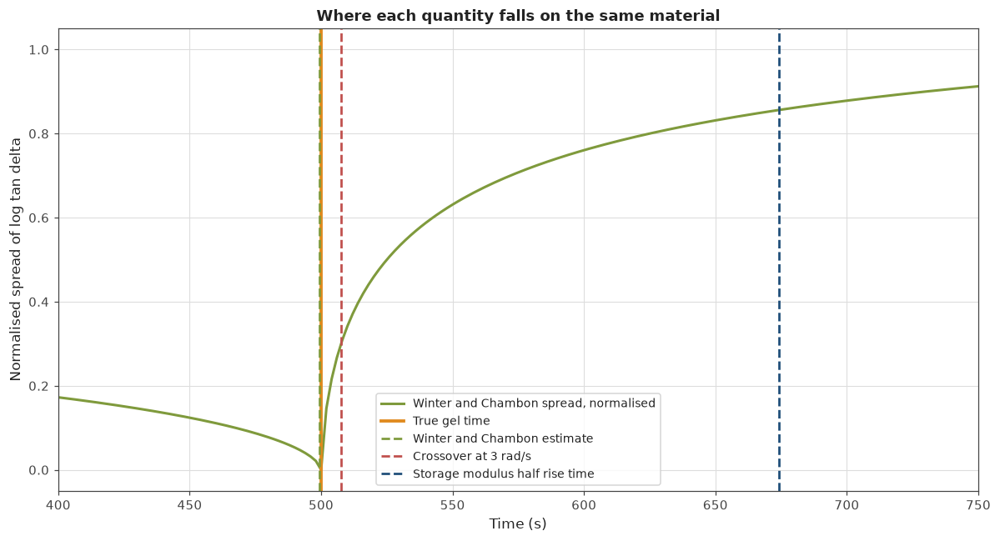


Spread between the three quantities  175.1 s
As a fraction of the true gel time   35 percent

Measured on noiseless data from a single material, so the spread is definitional
rather than experimental


In [215]:
comparison_time_grid = np.linspace(20.0, 980.0, 481)

winter_chambon_spread_series = []
for comparison_time in comparison_time_grid:
    comparison_modulus = gelling_material_complex_modulus(probe_frequency_grid,
                                                          comparison_time,
                                                          SYNTHETIC_GEL_TIME_SECONDS,
                                                          SYNTHETIC_CRITICAL_EXPONENT,
                                                          SYNTHETIC_GEL_STIFFNESS)
    comparison_tan_delta = compute_tan_delta(comparison_modulus.real, comparison_modulus.imag)
    winter_chambon_spread_series.append(np.nanstd(np.log(comparison_tan_delta)))

winter_chambon_spread_series = np.array(winter_chambon_spread_series)
winter_chambon_minimum_index = int(np.nanargmin(winter_chambon_spread_series))
winter_chambon_estimate = refine_minimum_by_parabola(comparison_time_grid,
                                                     winter_chambon_spread_series,
                                                     winter_chambon_minimum_index)

crossover_estimate_at_three = None
for crossover_record in crossover_results:
    if abs(crossover_record["probe_frequency"] - 3.0) < 1e-9:
        crossover_estimate_at_three = crossover_record["crossover_time"]

hill_estimate = hill_fit_result["half_rise_time"] if hill_fit_result is not None else np.nan

quantity_summary = [
    ("Winter and Chambon frequency agreement", winter_chambon_estimate,
     "multi-frequency", "network percolation", "gel point"),
    ("Crossover at 3 rad/s", crossover_estimate_at_three,
     "single frequency", "tan delta reaches one", "proxy"),
    ("Storage modulus half rise time", hill_estimate,
     "single frequency", "modulus reaches halfway", "proxy"),
]

print("Three quantities computed on the same material")
print("True gel time  " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  quantity".ljust(42) + "value (s)   offset (s)   needs             "
      + "event measured".ljust(26) + "type")

for quantity_name, quantity_value, requirement, event_measured, quantity_type in quantity_summary:
    print("  " + quantity_name.ljust(40)
          + ("%.1f" % quantity_value).rjust(9)
          + ("%+.1f" % (quantity_value - SYNTHETIC_GEL_TIME_SECONDS)).rjust(13)
          + "   " + requirement.ljust(18)
          + event_measured.ljust(26) + quantity_type)

figure_object, axis_object = plt.subplots(figsize=(11, 6))

normalised_spread = (winter_chambon_spread_series
                     / np.nanmax(winter_chambon_spread_series))

axis_object.plot(comparison_time_grid, normalised_spread, "-",
                 color=COLOUR_ACCENT, linewidth=2.0,
                 label="Winter and Chambon spread, normalised")

axis_object.axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                    linestyle="-", linewidth=2.5, label="True gel time")
axis_object.axvline(winter_chambon_estimate, color=COLOUR_ACCENT,
                    linestyle="--", linewidth=1.8, label="Winter and Chambon estimate")
axis_object.axvline(crossover_estimate_at_three, color=COLOUR_SECONDARY,
                    linestyle="--", linewidth=1.8, label="Crossover at 3 rad/s")
axis_object.axvline(hill_estimate, color=COLOUR_PRIMARY,
                    linestyle="--", linewidth=1.8, label="Storage modulus half rise time")

axis_object.set_xlabel("Time (s)")
axis_object.set_ylabel("Normalised spread of log tan delta")
axis_object.set_xlim(400.0, 750.0)
axis_object.set_title("Where each quantity falls on the same material")
axis_object.legend(fontsize=9)

plt.tight_layout()
plt.show()

quantity_values = np.array([winter_chambon_estimate, crossover_estimate_at_three,
                            hill_estimate])
quantity_spread = np.nanmax(quantity_values) - np.nanmin(quantity_values)

print()
print("Spread between the three quantities  " + ("%.1f" % quantity_spread) + " s")
print("As a fraction of the true gel time   "
      + ("%.0f" % (100.0 * quantity_spread / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")
print()
print("Measured on noiseless data from a single material, so the spread is definitional")
print("rather than experimental")

# Part 2: Getting a spectrum out of a changing material

Part 1 defined the gel point as the moment tan delta stops depending on frequency. That
definition needs the whole spectrum measured at one instant.

This part is about how to get that, and it opens with the reason the obvious approach does
not work.

## Cell 16: Why a conventional frequency sweep fails on a gelling material

The standard way to measure a spectrum is a frequency sweep: oscillate at one frequency,
wait for a steady response, record the two moduli, step to the next frequency, repeat.

The problem is time. One cycle at angular frequency omega takes 2 pi / omega seconds, and
you need several cycles for a reliable measurement. At 100 rad/s that is fast. At 0.1 rad/s
a single cycle takes over a minute.

So a sweep is not a snapshot. It is a sequence of measurements taken at different moments,
each carrying the material as it was when that point was recorded. If the material changes
during the sweep, the resulting spectrum describes no single state of the material at all.

There is a second problem that compounds the first. Sweeps normally run from high frequency
down to low, to get the quick points out of the way early. That means the low frequency
points, which are where the gel point signature lives, are measured last and are also the
slowest. The most important part of the spectrum is the part most contaminated by the delay.

This cell quantifies both effects. It simulates a conventional sweep on the synthetic
gelling material from Part 1, tracking the real time at which each frequency would actually
be measured, and compares the result against a true instantaneous snapshot taken at the
moment the sweep began.

The number that summarises it is the mutation number: how much the material changes during
the measurement, relative to its own size. Below one, the sweep is trustworthy. Approaching
one, it is measuring its own duration as much as the material.

Conventional stepped frequency sweep, 12 points from 0.50 to 50.0 rad/s
Allowing 3 cycles per point

Total time for one sweep          109.5 s
Time for the slowest point alone  37.7 s
Sweep duration as a fraction of the gel time  22 percent

  sweep starts at   mutation number   true tan delta spread   swept tan delta spread
            200 s            0.1492                  0.1937                   0.1588
            350 s            0.2691                  0.1463                   0.0875
            430 s            2.2611                  0.1035                   0.4595
            470 s            2.8407                  0.0679                   0.6468


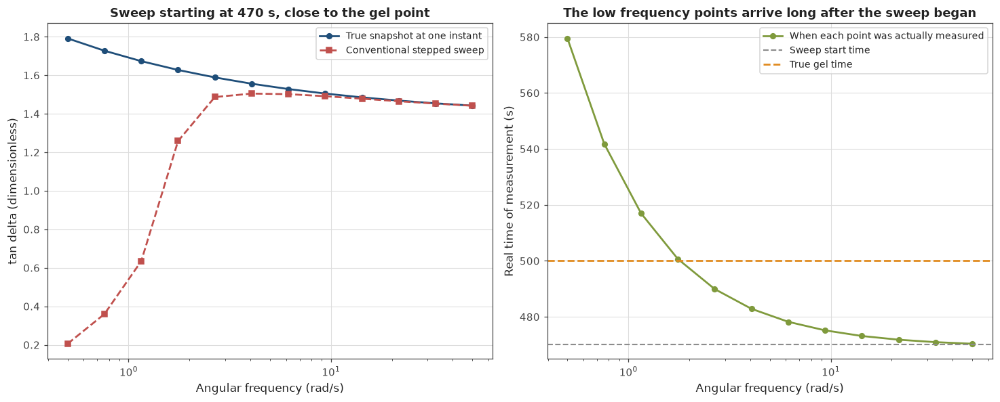


For the sweep starting at 470 s
  highest frequency, measured first  470.4 s
  lowest frequency, measured last    579.5 s
  spread of measurement times        109.1 s

  the gel point at 500 s falls inside that window, so the sweep straddles the transition


In [216]:
def simulate_conventional_frequency_sweep(sweep_start_time_seconds, angular_frequency_array,
                                          cycles_per_point, gel_time_seconds,
                                          critical_exponent, gel_strength):
    """
    Simulating a conventional stepped frequency sweep on a material that is changing.

    Stepping from the highest frequency down to the lowest, which is the usual order since
    it gets the fast points out of the way first. Accumulating the real time each point
    takes, which is the number of cycles divided by the frequency, and evaluating the
    material at the moment that point would actually have been measured.

    Returning the measured complex modulus sorted by ascending frequency, the real time at
    which each point was taken, and the total sweep duration.
    """
    descending_frequency = np.sort(np.asarray(angular_frequency_array, dtype=float))[::-1]

    measurement_time_list = []
    measured_modulus_list = []

    elapsed_sweep_time = 0.0

    for one_frequency in descending_frequency:

        seconds_for_this_point = cycles_per_point * 2.0 * np.pi / one_frequency
        elapsed_sweep_time = elapsed_sweep_time + seconds_for_this_point

        measurement_time = sweep_start_time_seconds + elapsed_sweep_time

        point_modulus = gelling_material_complex_modulus(np.array([one_frequency]),
                                                         measurement_time,
                                                         gel_time_seconds,
                                                         critical_exponent,
                                                         gel_strength)

        measurement_time_list.append(measurement_time)
        measured_modulus_list.append(point_modulus[0])

    ascending_order = np.argsort(descending_frequency)

    return {
        "angular_frequency": descending_frequency[ascending_order],
        "complex_modulus": np.array(measured_modulus_list)[ascending_order],
        "measurement_time": np.array(measurement_time_list)[ascending_order],
        "total_sweep_duration": elapsed_sweep_time,
    }


def compute_mutation_number(evaluation_time_seconds, measurement_duration_seconds,
                            angular_frequency_array, gel_time_seconds,
                            critical_exponent, gel_strength):
    """
    Computing how much the material changes during a measurement of a given duration.

    Comparing the storage modulus at the start and end of the measurement window, and
    expressing the change relative to the starting value. A result well below one means
    the material held still. A result approaching or exceeding one means the measurement
    is describing the change rather than the material.
    """
    starting_modulus = gelling_material_complex_modulus(angular_frequency_array,
                                                        evaluation_time_seconds,
                                                        gel_time_seconds, critical_exponent,
                                                        gel_strength)

    ending_modulus = gelling_material_complex_modulus(angular_frequency_array,
                                                      evaluation_time_seconds
                                                      + measurement_duration_seconds,
                                                      gel_time_seconds, critical_exponent,
                                                      gel_strength)

    relative_change = (np.abs(ending_modulus.real - starting_modulus.real)
                       / np.abs(starting_modulus.real))

    return float(np.nanmean(relative_change))


sweep_frequency_grid = np.logspace(np.log10(0.5), np.log10(50.0), 12)
cycles_per_sweep_point = 3.0

sweep_start_times_to_test = [200.0, 350.0, 430.0, 470.0]

print("Conventional stepped frequency sweep, "
      + str(len(sweep_frequency_grid)) + " points from "
      + ("%.2f" % sweep_frequency_grid.min()) + " to "
      + ("%.1f" % sweep_frequency_grid.max()) + " rad/s")
print("Allowing " + ("%.0f" % cycles_per_sweep_point) + " cycles per point")
print()

single_sweep_duration = 0.0
for one_frequency in sweep_frequency_grid:
    single_sweep_duration = (single_sweep_duration
                             + cycles_per_sweep_point * 2.0 * np.pi / one_frequency)

print("Total time for one sweep          " + ("%.1f" % single_sweep_duration) + " s")
print("Time for the slowest point alone  "
      + ("%.1f" % (cycles_per_sweep_point * 2.0 * np.pi / sweep_frequency_grid.min())) + " s")
print("Sweep duration as a fraction of the gel time  "
      + ("%.0f" % (100.0 * single_sweep_duration / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")
print()

print("  sweep starts at   mutation number   true tan delta spread   swept tan delta spread")

sweep_comparison_results = []

for sweep_start_time in sweep_start_times_to_test:

    swept_result = simulate_conventional_frequency_sweep(sweep_start_time,
                                                         sweep_frequency_grid,
                                                         cycles_per_sweep_point,
                                                         SYNTHETIC_GEL_TIME_SECONDS,
                                                         SYNTHETIC_CRITICAL_EXPONENT,
                                                         SYNTHETIC_GEL_STIFFNESS)

    true_snapshot_modulus = gelling_material_complex_modulus(sweep_frequency_grid,
                                                             sweep_start_time,
                                                             SYNTHETIC_GEL_TIME_SECONDS,
                                                             SYNTHETIC_CRITICAL_EXPONENT,
                                                             SYNTHETIC_GEL_STIFFNESS)

    true_tan_delta = compute_tan_delta(true_snapshot_modulus.real, true_snapshot_modulus.imag)
    swept_tan_delta = compute_tan_delta(swept_result["complex_modulus"].real,
                                        swept_result["complex_modulus"].imag)

    mutation_number = compute_mutation_number(sweep_start_time,
                                              swept_result["total_sweep_duration"],
                                              sweep_frequency_grid,
                                              SYNTHETIC_GEL_TIME_SECONDS,
                                              SYNTHETIC_CRITICAL_EXPONENT,
                                              SYNTHETIC_GEL_STIFFNESS)

    sweep_comparison_results.append({
        "sweep_start_time": sweep_start_time,
        "swept_result": swept_result,
        "true_snapshot_modulus": true_snapshot_modulus,
        "true_tan_delta": true_tan_delta,
        "swept_tan_delta": swept_tan_delta,
        "mutation_number": mutation_number,
    })

    print("  " + ("%.0f s" % sweep_start_time).rjust(15)
          + ("%.4f" % mutation_number).rjust(18)
          + ("%.4f" % np.nanstd(np.log(true_tan_delta))).rjust(24)
          + ("%.4f" % np.nanstd(np.log(swept_tan_delta))).rjust(25))

figure_object, axis_array = plt.subplots(1, 2, figsize=(13.5, 5.5))

reference_sweep = sweep_comparison_results[-1]

axis_array[0].semilogx(reference_sweep["swept_result"]["angular_frequency"],
                       reference_sweep["true_tan_delta"],
                       "o-", color=COLOUR_PRIMARY, markersize=5, linewidth=1.8,
                       label="True snapshot at one instant")
axis_array[0].semilogx(reference_sweep["swept_result"]["angular_frequency"],
                       reference_sweep["swept_tan_delta"],
                       "s--", color=COLOUR_SECONDARY, markersize=5, linewidth=1.8,
                       label="Conventional stepped sweep")
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("Sweep starting at "
                        + ("%.0f" % reference_sweep["sweep_start_time"])
                        + " s, close to the gel point")
axis_array[0].legend(fontsize=9)

axis_array[1].semilogx(reference_sweep["swept_result"]["angular_frequency"],
                       reference_sweep["swept_result"]["measurement_time"],
                       "o-", color=COLOUR_ACCENT, markersize=5, linewidth=1.8,
                       label="When each point was actually measured")
axis_array[1].axhline(reference_sweep["sweep_start_time"], color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4, label="Sweep start time")
axis_array[1].axhline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Real time of measurement (s)")
axis_array[1].set_title("The low frequency points arrive long after the sweep began")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print()
print("For the sweep starting at "
      + ("%.0f" % reference_sweep["sweep_start_time"]) + " s")
print("  highest frequency, measured first  "
      + ("%.1f" % reference_sweep["swept_result"]["measurement_time"][-1]) + " s")
print("  lowest frequency, measured last    "
      + ("%.1f" % reference_sweep["swept_result"]["measurement_time"][0]) + " s")
print("  spread of measurement times        "
      + ("%.1f" % (reference_sweep["swept_result"]["measurement_time"].max()
                   - reference_sweep["swept_result"]["measurement_time"].min())) + " s")
print()
print("  the gel point at " + ("%.0f" % SYNTHETIC_GEL_TIME_SECONDS)
      + " s falls inside that window, so the sweep straddles the transition")

## Cell 17: The chirp, measuring every frequency at once

The previous cell showed the problem. A stepped sweep spends 109 s measuring twelve
frequencies one after another, and the material moves underneath it.

The way out is to stop measuring frequencies one at a time. A chirp is a single continuous
oscillation whose frequency changes as it goes, so one short burst puts energy into the
whole frequency range at once.

The waveform is an exponential chirp:

    gamma(t) = gamma_0 * W(t) * sin( L * omega_1 * ( exp(t / L) - 1 ) )

with

    L = T / ln(omega_2 / omega_1)

Reading the pieces. The strain amplitude gamma_0 sets how hard the sample is pushed. The
term inside the sine makes the instantaneous frequency grow exponentially from omega_1 at
the start to omega_2 at the end, over a duration T. Exponential growth means the sweep
spends equal time in each decade of frequency, which is what you want since spectra are
read on log axes.

W(t) is a window, a taper that eases the signal in at the start and out at the end. Without
it the abrupt start and stop create spectral leakage that smears the recovered moduli. This
is the optimally windowed part of the method, and a taper covering roughly ten percent of
the signal is the usual choice.

The instantaneous frequency follows directly by differentiating the phase:

    omega(t) = omega_1 * exp(t / L)

This cell builds the waveform, confirms the instantaneous frequency matches that formula,
and shows what the window does to the spectrum. The frequency it produces is also the
ground truth that every method in the comparison later will be scored against, since we know
exactly what frequency is present at every instant.

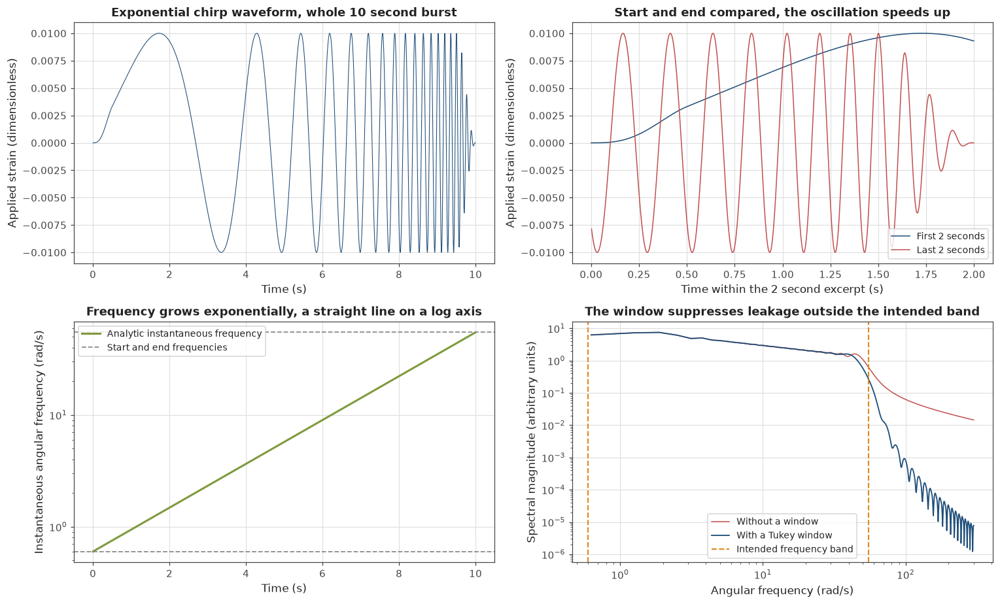

Chirp design

  duration                    10.0 s
  sampling frequency          500 Hz
  samples                     5000
  frequency band              0.60 to 55.0 rad/s
  decades covered             1.96
  sweep rate constant L       2.2133 s
  taper fraction              0.10

  largest error between numerical and analytic instantaneous frequency  6.832e-06 rad/s

Measurement time for the same frequency range, starting at 470 s

  stepped sweep    109.5 s     mutation number 2.8407
  single chirp     10.0 s      mutation number 0.0386

  speed advantage  10.9 times faster


In [217]:
from scipy.signal import get_window


def build_exponential_chirp(duration_seconds, sampling_frequency_hz,
                            starting_angular_frequency, ending_angular_frequency,
                            strain_amplitude, taper_fraction=0.1):
    """
    Building an exponentially swept chirp waveform.

    Growing the instantaneous frequency exponentially from the starting to the ending
    angular frequency across the duration, so the sweep spends equal time in each decade.
    Applying a Tukey window to taper the start and end, which suppresses the spectral
    leakage an abrupt start would otherwise create.

    Returning the time array, the windowed waveform, the unwindowed waveform, the window
    itself, and the analytic instantaneous angular frequency at every sample.
    """
    sample_count = int(round(duration_seconds * sampling_frequency_hz))
    time_array = np.arange(sample_count) / sampling_frequency_hz

    sweep_rate_constant = duration_seconds / np.log(ending_angular_frequency
                                                    / starting_angular_frequency)

    phase_array = (sweep_rate_constant * starting_angular_frequency
                   * (np.exp(time_array / sweep_rate_constant) - 1.0))

    unwindowed_waveform = strain_amplitude * np.sin(phase_array)

    taper_window = get_window(("tukey", taper_fraction), sample_count)
    windowed_waveform = unwindowed_waveform * taper_window

    instantaneous_angular_frequency = (starting_angular_frequency
                                       * np.exp(time_array / sweep_rate_constant))

    return {
        "time": time_array,
        "waveform": windowed_waveform,
        "unwindowed_waveform": unwindowed_waveform,
        "window": taper_window,
        "instantaneous_angular_frequency": instantaneous_angular_frequency,
        "sweep_rate_constant": sweep_rate_constant,
        "sampling_frequency_hz": sampling_frequency_hz,
    }


CHIRP_DURATION_SECONDS = 10.0
CHIRP_START_ANGULAR_FREQUENCY = 0.6
CHIRP_END_ANGULAR_FREQUENCY = 55.0
CHIRP_STRAIN_AMPLITUDE = 0.01
CHIRP_TAPER_FRACTION = 0.1

reference_chirp = build_exponential_chirp(CHIRP_DURATION_SECONDS,
                                          CHIRP_SAMPLING_FREQUENCY_HZ,
                                          CHIRP_START_ANGULAR_FREQUENCY,
                                          CHIRP_END_ANGULAR_FREQUENCY,
                                          CHIRP_STRAIN_AMPLITUDE,
                                          CHIRP_TAPER_FRACTION)

phase_from_waveform = np.unwrap(np.angle(
    np.exp(1j * (reference_chirp["sweep_rate_constant"] * CHIRP_START_ANGULAR_FREQUENCY
                 * (np.exp(reference_chirp["time"] / reference_chirp["sweep_rate_constant"]) - 1.0)))))

numerical_instantaneous_frequency = (np.gradient(phase_from_waveform,
                                                 reference_chirp["time"]))

interior_mask = ((reference_chirp["time"] > 0.2)
                 & (reference_chirp["time"] < CHIRP_DURATION_SECONDS - 0.2))

frequency_check_error = np.max(np.abs(
    numerical_instantaneous_frequency[interior_mask]
    - reference_chirp["instantaneous_angular_frequency"][interior_mask]))

figure_object, axis_array = plt.subplots(2, 2, figsize=(14, 8.5))

axis_array[0][0].plot(reference_chirp["time"], reference_chirp["waveform"],
                      "-", color=COLOUR_PRIMARY, linewidth=0.7)
axis_array[0][0].set_xlabel("Time (s)")
axis_array[0][0].set_ylabel("Applied strain (dimensionless)")
axis_array[0][0].set_title("Exponential chirp waveform, whole 10 second burst")

early_window_mask = reference_chirp["time"] < 2.0
late_window_mask = reference_chirp["time"] > CHIRP_DURATION_SECONDS - 2.0

axis_array[0][1].plot(reference_chirp["time"][early_window_mask],
                      reference_chirp["waveform"][early_window_mask],
                      "-", color=COLOUR_PRIMARY, linewidth=1.0, label="First 2 seconds")
axis_array[0][1].plot(reference_chirp["time"][late_window_mask] - CHIRP_DURATION_SECONDS + 2.0,
                      reference_chirp["waveform"][late_window_mask],
                      "-", color=COLOUR_SECONDARY, linewidth=1.0, label="Last 2 seconds")
axis_array[0][1].set_xlabel("Time within the 2 second excerpt (s)")
axis_array[0][1].set_ylabel("Applied strain (dimensionless)")
axis_array[0][1].set_title("Start and end compared, the oscillation speeds up")
axis_array[0][1].legend(fontsize=9)

axis_array[1][0].semilogy(reference_chirp["time"],
                          reference_chirp["instantaneous_angular_frequency"],
                          "-", color=COLOUR_ACCENT, linewidth=2.0,
                          label="Analytic instantaneous frequency")
axis_array[1][0].axhline(CHIRP_START_ANGULAR_FREQUENCY, color=COLOUR_NEUTRAL,
                         linestyle="--", linewidth=1.2, label="Start and end frequencies")
axis_array[1][0].axhline(CHIRP_END_ANGULAR_FREQUENCY, color=COLOUR_NEUTRAL,
                         linestyle="--", linewidth=1.2)
axis_array[1][0].set_xlabel("Time (s)")
axis_array[1][0].set_ylabel("Instantaneous angular frequency (rad/s)")
axis_array[1][0].set_title("Frequency grows exponentially, a straight line on a log axis")
axis_array[1][0].legend(fontsize=9)

windowed_spectrum = np.abs(np.fft.rfft(reference_chirp["waveform"]))
unwindowed_spectrum = np.abs(np.fft.rfft(reference_chirp["unwindowed_waveform"]))
spectrum_frequency_hz = np.fft.rfftfreq(len(reference_chirp["time"]),
                                        1.0 / CHIRP_SAMPLING_FREQUENCY_HZ)
spectrum_angular_frequency = 2.0 * np.pi * spectrum_frequency_hz

spectrum_display_mask = ((spectrum_angular_frequency > 0.05)
                         & (spectrum_angular_frequency < 300.0))

axis_array[1][1].loglog(spectrum_angular_frequency[spectrum_display_mask],
                        unwindowed_spectrum[spectrum_display_mask],
                        "-", color=COLOUR_SECONDARY, linewidth=1.0,
                        label="Without a window")
axis_array[1][1].loglog(spectrum_angular_frequency[spectrum_display_mask],
                        windowed_spectrum[spectrum_display_mask],
                        "-", color=COLOUR_PRIMARY, linewidth=1.2,
                        label="With a Tukey window")
axis_array[1][1].axvline(CHIRP_START_ANGULAR_FREQUENCY, color=COLOUR_HIGHLIGHT,
                         linestyle="--", linewidth=1.4, label="Intended frequency band")
axis_array[1][1].axvline(CHIRP_END_ANGULAR_FREQUENCY, color=COLOUR_HIGHLIGHT,
                         linestyle="--", linewidth=1.4)
axis_array[1][1].set_xlabel("Angular frequency (rad/s)")
axis_array[1][1].set_ylabel("Spectral magnitude (arbitrary units)")
axis_array[1][1].set_title("The window suppresses leakage outside the intended band")
axis_array[1][1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Chirp design")
print()
print("  duration                    " + ("%.1f" % CHIRP_DURATION_SECONDS) + " s")
print("  sampling frequency          " + ("%.0f" % CHIRP_SAMPLING_FREQUENCY_HZ) + " Hz")
print("  samples                     " + str(len(reference_chirp["time"])))
print("  frequency band              " + ("%.2f" % CHIRP_START_ANGULAR_FREQUENCY)
      + " to " + ("%.1f" % CHIRP_END_ANGULAR_FREQUENCY) + " rad/s")
print("  decades covered             "
      + ("%.2f" % np.log10(CHIRP_END_ANGULAR_FREQUENCY / CHIRP_START_ANGULAR_FREQUENCY)))
print("  sweep rate constant L       "
      + ("%.4f" % reference_chirp["sweep_rate_constant"]) + " s")
print("  taper fraction              " + ("%.2f" % CHIRP_TAPER_FRACTION))
print()
print("  largest error between numerical and analytic instantaneous frequency  "
      + ("%.3e" % frequency_check_error) + " rad/s")
print()

equivalent_stepped_sweep_duration = 0.0
for one_frequency in sweep_frequency_grid:
    equivalent_stepped_sweep_duration = (equivalent_stepped_sweep_duration
                                         + cycles_per_sweep_point * 2.0 * np.pi / one_frequency)

chirp_mutation_number = compute_mutation_number(470.0, CHIRP_DURATION_SECONDS,
                                                sweep_frequency_grid,
                                                SYNTHETIC_GEL_TIME_SECONDS,
                                                SYNTHETIC_CRITICAL_EXPONENT,
                                                SYNTHETIC_GEL_STIFFNESS)

stepped_mutation_number = compute_mutation_number(470.0, equivalent_stepped_sweep_duration,
                                                  sweep_frequency_grid,
                                                  SYNTHETIC_GEL_TIME_SECONDS,
                                                  SYNTHETIC_CRITICAL_EXPONENT,
                                                  SYNTHETIC_GEL_STIFFNESS)

print("Measurement time for the same frequency range, starting at 470 s")
print()
print("  stepped sweep    " + ("%.1f" % equivalent_stepped_sweep_duration)
      + " s     mutation number " + ("%.4f" % stepped_mutation_number))
print("  single chirp     " + ("%.1f" % CHIRP_DURATION_SECONDS)
      + " s      mutation number " + ("%.4f" % chirp_mutation_number))
print()
print("  speed advantage  "
      + ("%.1f" % (equivalent_stepped_sweep_duration / CHIRP_DURATION_SECONDS)) + " times faster")

## Cell 18: Loading the real chirp recording

The previous two cells argued for chirps on a synthetic material. This cell brings in a real
recording so the rest of Part 2 works on measured data rather than a model.

The file is an export from a TA Instruments ARES G2 rotational rheometer, containing 24
chirp pulses fired at the same sample over about thirteen minutes. Each pulse is a separate
step in the instrument's programme, so splitting the file by step number recovers the
individual bursts.

Two things make this recording useful beyond simply having real waveforms.

It has raw stress and strain time series at 500 samples per second, not reduced moduli. That
is what the extraction later in this part needs, and it is unusual, since most published
rheology gives only the processed result.

And the sample is stiffening dramatically while being measured. Watch the two amplitude
columns in the table below. The operator cut the applied strain from 20 percent to 5 percent
to 1 percent, and stepped the transducer up through its ranges, yet the measured stress kept
climbing. Pushing twenty times less hard and getting far more stress back only happens if
the material is getting much stiffer.

That makes this an evolving material of exactly the kind Part 2 is about, even though it is
an industrial sample rather than anything biological. It is used here to build and test the
extraction. Blood comes later, in Parts 6 and 7.

In [218]:
chirp_file_path = os.path.join(DATA_DIRECTORY, "dev_curing_chirp.xlsx")

print("Reading " + chirp_file_path)

chirp_dataframe = pd.read_excel(chirp_file_path, sheet_name="Sheet1")

print("  rows    " + str(len(chirp_dataframe)))
print("  columns " + str(len(chirp_dataframe.columns)))
print()

chirp_pulse_list = []

unique_step_numbers = sorted(chirp_dataframe["Step_number"].unique())

for step_number in unique_step_numbers:

    single_step_dataframe = chirp_dataframe[chirp_dataframe["Step_number"] == step_number]

    run_time_values = single_step_dataframe["Run time [s]"].values
    strain_percent_values = single_step_dataframe["Strain (step) [%]"].values
    stress_pascal_values = single_step_dataframe["Stress (step) [Pa]"].values
    transducer_range_values = single_step_dataframe["Transducer range"].values

    pulse_start_time = float(np.min(run_time_values))
    pulse_end_time = float(np.max(run_time_values))

    sample_count = len(run_time_values)
    pulse_duration = pulse_end_time - pulse_start_time

    if pulse_duration > 0.0:
        measured_sampling_rate = (sample_count - 1) / pulse_duration
    else:
        measured_sampling_rate = np.nan

    strain_amplitude_percent = float(np.max(np.abs(strain_percent_values)))
    stress_amplitude_pascal = float(np.max(np.abs(stress_pascal_values)))

    if strain_amplitude_percent > 0.0:
        apparent_modulus = stress_amplitude_pascal / (strain_amplitude_percent / 100.0)
    else:
        apparent_modulus = np.nan

    single_pulse_record = {
        "step_number": int(step_number),
        "start_time_seconds": pulse_start_time,
        "end_time_seconds": pulse_end_time,
        "midpoint_time_seconds": 0.5 * (pulse_start_time + pulse_end_time),
        "duration_seconds": pulse_duration,
        "sample_count": sample_count,
        "sampling_rate_hz": measured_sampling_rate,
        "strain_amplitude_percent": strain_amplitude_percent,
        "stress_amplitude_pascal": stress_amplitude_pascal,
        "apparent_modulus_pascal": apparent_modulus,
        "transducer_range": str(transducer_range_values[0]),
        "time_seconds": run_time_values,
        "local_time_seconds": run_time_values - pulse_start_time,
        "strain_percent": strain_percent_values,
        "stress_pascal": stress_pascal_values,
    }

    chirp_pulse_list.append(single_pulse_record)

print("Chirp pulses found  " + str(len(chirp_pulse_list)))
print()

print("  step   start (s)   duration (s)   samples   rate (Hz)   strain (%)   "
      + "stress (Pa)   apparent G (Pa)   range")

for single_pulse_record in chirp_pulse_list:
    print("  " + str(single_pulse_record["step_number"]).rjust(4)
          + ("%.1f" % single_pulse_record["start_time_seconds"]).rjust(12)
          + ("%.2f" % single_pulse_record["duration_seconds"]).rjust(15)
          + str(single_pulse_record["sample_count"]).rjust(10)
          + ("%.1f" % single_pulse_record["sampling_rate_hz"]).rjust(12)
          + ("%.3f" % single_pulse_record["strain_amplitude_percent"]).rjust(13)
          + ("%.1f" % single_pulse_record["stress_amplitude_pascal"]).rjust(14)
          + ("%.1f" % single_pulse_record["apparent_modulus_pascal"]).rjust(18)
          + "   " + single_pulse_record["transducer_range"])

first_pulse_record = chirp_pulse_list[0]
last_pulse_record = chirp_pulse_list[-1]

print()
print("Summary of the run")
print()
print("  total elapsed time          "
      + ("%.1f" % (last_pulse_record["end_time_seconds"]
                   - first_pulse_record["start_time_seconds"])) + " s")
print("  spacing between pulses      "
      + ("%.1f" % ((last_pulse_record["start_time_seconds"]
                    - first_pulse_record["start_time_seconds"])
                   / max(1, len(chirp_pulse_list) - 1))) + " s")
print("  temperature held at         "
      + ("%.1f" % chirp_dataframe["Temperature [°C]"].mean()) + " C")
print()
print("  strain amplitude            "
      + ("%.3f" % first_pulse_record["strain_amplitude_percent"]) + " to "
      + ("%.3f" % last_pulse_record["strain_amplitude_percent"]) + " percent")
print("  stress amplitude            "
      + ("%.1f" % first_pulse_record["stress_amplitude_pascal"]) + " to "
      + ("%.1f" % last_pulse_record["stress_amplitude_pascal"]) + " Pa")
print("  apparent modulus            "
      + ("%.1f" % first_pulse_record["apparent_modulus_pascal"]) + " to "
      + ("%.4g" % last_pulse_record["apparent_modulus_pascal"]) + " Pa")
print("  apparent stiffening factor  "
      + ("%.0f" % (last_pulse_record["apparent_modulus_pascal"]
                   / first_pulse_record["apparent_modulus_pascal"])) + " times")

Reading data/dev_curing_chirp.xlsx
  rows    120000
  columns 34

Chirp pulses found  24

  step   start (s)   duration (s)   samples   rate (Hz)   strain (%)   stress (Pa)   apparent G (Pa)   range
     1        14.9          10.00      5000       500.0       19.988          15.4              77.0   0
     2        46.6          10.00      5000       500.0       19.987          18.3              91.3   0
     3        78.3          10.00      5000       500.0       19.987          18.7              93.7   0
     4       109.9          10.00      5000       500.0       19.985          19.5              97.7   0
     5       141.5          10.00      5000       500.0       19.986          17.1              85.6   0
     6       173.1          10.00      5000       500.0       19.987          29.9             149.7   0
     7       204.7          10.00      5000       500.0       19.989          95.9             479.9   0
     8       238.3          10.00      5000       500.0        4.9

## Cell 19: Looking at one raw chirp pulse

Before any analysis, look at the signal.

The top panel is the strain the instrument applied, the input. The bottom is the stress the
sample returned, the output. Both come straight from the file with no processing.

**The first thing visible is not the chirp.** Each 10 second step begins with roughly 3
seconds during which the applied strain sits at a few thousandths of a percent, against a
chirp amplitude of one to twenty percent. That is the instrument settling before the
arbitrary waveform starts, and it appears in all 24 pulses.

It has to be removed. During that section the measured stress still reads several hundred
Pascals while the strain is essentially zero, so any modulus computed from it would be
meaningless. Fourier transforming the full 10 seconds would let that section contaminate the
whole spectrum.

**Detecting the onset needs care.** The obvious approach, thresholding at a fraction of the
chirp amplitude, lands partway up the window taper and throws away the gentle start that
suppresses spectral leakage. Instead the cell measures the settling noise floor from the
first 1.5 seconds, finds where the strain first exceeds ten times that floor, then steps back
a small margin to keep the taper intact.

Applied across all pulses that gives an onset of 3.04 to 3.19 seconds, drifting slightly
later through the run because the noise floor rises as the sample stiffens. The usable chirp
is about 7.1 to 7.3 seconds long.

Once trimmed, the chirp sweeps upward in frequency. The one second windows at the end of the
cell show that rise. The lowest windows all report the same value because a one second window
cannot resolve below 1 Hz, which is a limit of that quick check rather than of the data.

Detecting the chirp onset in every pulse

  step   noise floor (%)   onset (s)   chirp strain (%)   chirp duration (s)
     1           0.00064       2.740             19.988                 7.26
     2           0.00078       2.740             19.987                 7.26
     3           0.00071       2.742             19.987                 7.26
     4           0.00067       2.742             19.985                 7.26
     5           0.00057       2.738             19.986                 7.26
     6           0.00057       2.740             19.987                 7.26
     7           0.00076       2.742             19.989                 7.26
     8           0.00037       2.748              4.997                 7.25
     9           0.00056       2.756              4.997                 7.24
    10           0.00096       2.770              4.998                 7.23
    11           0.00088       2.812              1.000                 7.19
    12           0.00099       2.8

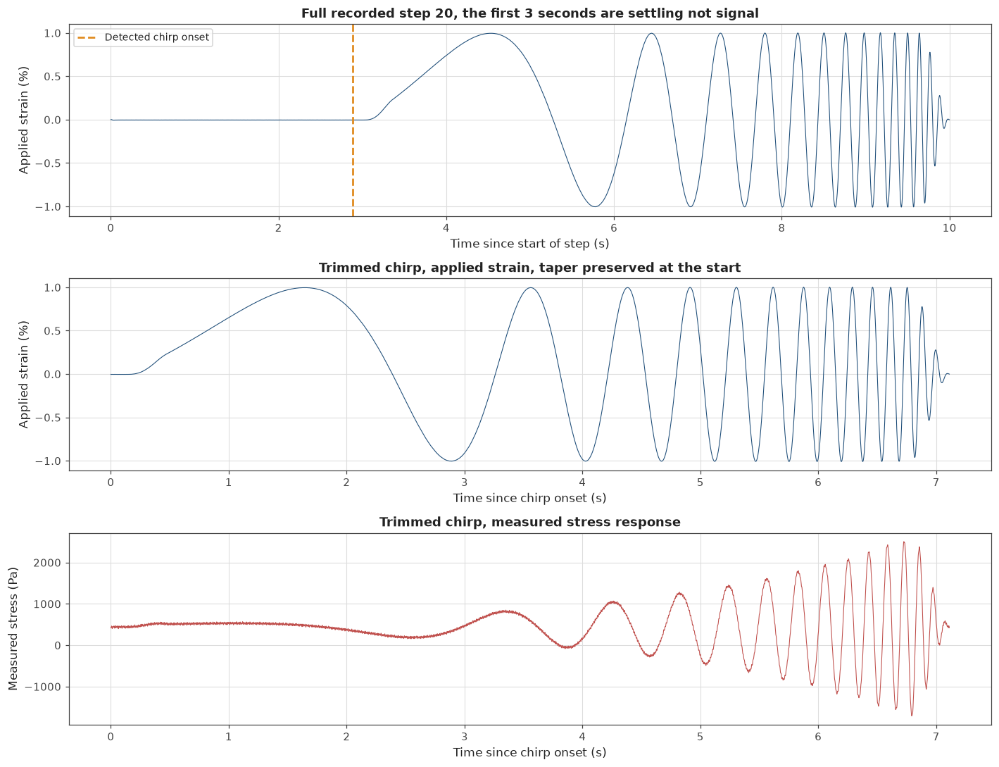


Dominant frequency in successive one second windows of the trimmed chirp

  window (s)      dominant angular frequency (rad/s)
      0 to 1                          6.28
      1 to 2                          6.28
      2 to 3                          6.28
      3 to 4                          6.28
      4 to 5                         12.57
      5 to 6                         18.85
      6 to 7                         37.70

A one second window cannot resolve below about 6.3 rad/s, so the early windows
all report the same value. The rise at later times is the chirp sweeping upward.


In [219]:
def find_chirp_onset_index(strain_percent_values, local_time_seconds,
                           settling_window_seconds=1.5, noise_multiple=10.0,
                           backoff_seconds=0.3):
    """
    Finding where the real chirp begins inside a recorded step.

    Measuring the settling noise floor from the first part of the step, then locating the
    first sample where the applied strain exceeds a multiple of that floor. Stepping back
    a small margin afterwards, so the window taper at the start of the chirp is kept rather
    than cut off, since removing it would reintroduce the abrupt start the taper exists to
    prevent.

    Returning the index of the first sample to keep.
    """
    absolute_strain = np.abs(np.asarray(strain_percent_values, dtype=float))
    time_values = np.asarray(local_time_seconds, dtype=float)

    settling_mask = time_values < settling_window_seconds
    if np.sum(settling_mask) < 10:
        return 0

    noise_floor = float(np.percentile(absolute_strain[settling_mask], 99))
    onset_threshold = noise_multiple * noise_floor

    above_threshold = absolute_strain > onset_threshold
    if not np.any(above_threshold):
        return 0

    threshold_index = int(np.argmax(above_threshold))
    threshold_time = time_values[threshold_index]

    backed_off_time = max(0.0, threshold_time - backoff_seconds)

    return int(np.argmax(time_values >= backed_off_time))


def trim_pulse_to_chirp(pulse_record):
    """
    Trimming a recorded pulse down to the active chirp portion.

    Removing the settling period at the start and returning a new record holding only the
    samples from the chirp onset onward, with the local time restarted at zero.
    """
    onset_index = find_chirp_onset_index(pulse_record["strain_percent"],
                                         pulse_record["local_time_seconds"])

    trimmed_record = dict(pulse_record)

    trimmed_record["onset_index"] = onset_index
    trimmed_record["onset_time_seconds"] = float(
        pulse_record["local_time_seconds"][onset_index])

    trimmed_record["local_time_seconds"] = (
        pulse_record["local_time_seconds"][onset_index:]
        - pulse_record["local_time_seconds"][onset_index])
    trimmed_record["time_seconds"] = pulse_record["time_seconds"][onset_index:]
    trimmed_record["strain_percent"] = pulse_record["strain_percent"][onset_index:]
    trimmed_record["stress_pascal"] = pulse_record["stress_pascal"][onset_index:]

    trimmed_record["sample_count"] = len(trimmed_record["local_time_seconds"])
    trimmed_record["duration_seconds"] = float(trimmed_record["local_time_seconds"][-1])

    settling_strain = np.abs(pulse_record["strain_percent"][:max(onset_index, 1)])
    trimmed_record["noise_floor_percent"] = float(np.percentile(settling_strain, 99))

    return trimmed_record


trimmed_pulse_list = []
for single_pulse_record in chirp_pulse_list:
    trimmed_pulse_list.append(trim_pulse_to_chirp(single_pulse_record))

print("Detecting the chirp onset in every pulse")
print()
print("  step   noise floor (%)   onset (s)   chirp strain (%)   chirp duration (s)")

for trimmed_record in trimmed_pulse_list:
    print("  " + str(trimmed_record["step_number"]).rjust(4)
          + ("%.5f" % trimmed_record["noise_floor_percent"]).rjust(18)
          + ("%.3f" % trimmed_record["onset_time_seconds"]).rjust(12)
          + ("%.3f" % trimmed_record["strain_amplitude_percent"]).rjust(19)
          + ("%.2f" % trimmed_record["duration_seconds"]).rjust(21))

pulse_index_to_inspect = 19

original_pulse = chirp_pulse_list[pulse_index_to_inspect]
inspected_pulse = trimmed_pulse_list[pulse_index_to_inspect]

figure_object, axis_array = plt.subplots(3, 1, figsize=(13, 10))

axis_array[0].plot(original_pulse["local_time_seconds"],
                   original_pulse["strain_percent"],
                   "-", color=COLOUR_PRIMARY, linewidth=0.7)
axis_array[0].axvline(inspected_pulse["onset_time_seconds"], color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="Detected chirp onset")
axis_array[0].set_xlabel("Time since start of step (s)")
axis_array[0].set_ylabel("Applied strain (%)")
axis_array[0].set_title("Full recorded step " + str(original_pulse["step_number"])
                        + ", the first 3 seconds are settling not signal")
axis_array[0].legend(fontsize=9)

axis_array[1].plot(inspected_pulse["local_time_seconds"],
                   inspected_pulse["strain_percent"],
                   "-", color=COLOUR_PRIMARY, linewidth=0.7)
axis_array[1].set_xlabel("Time since chirp onset (s)")
axis_array[1].set_ylabel("Applied strain (%)")
axis_array[1].set_title("Trimmed chirp, applied strain, taper preserved at the start")

axis_array[2].plot(inspected_pulse["local_time_seconds"],
                   inspected_pulse["stress_pascal"],
                   "-", color=COLOUR_SECONDARY, linewidth=0.7)
axis_array[2].set_xlabel("Time since chirp onset (s)")
axis_array[2].set_ylabel("Measured stress (Pa)")
axis_array[2].set_title("Trimmed chirp, measured stress response")

plt.tight_layout()
plt.show()


def estimate_dominant_angular_frequency(signal_values, sampling_frequency_hz):
    """
    Estimating the dominant angular frequency present in a short segment of signal.

    Windowing the segment, taking its Fourier transform, and returning the angular
    frequency of the largest spectral peak away from zero.
    """
    centred_signal = np.asarray(signal_values, dtype=float)
    centred_signal = centred_signal - np.mean(centred_signal)

    sample_count = len(centred_signal)
    if sample_count < 16:
        return np.nan

    spectrum_magnitude = np.abs(np.fft.rfft(centred_signal * np.hanning(sample_count)))
    frequency_hz = np.fft.rfftfreq(sample_count, 1.0 / sampling_frequency_hz)

    spectrum_magnitude[0] = 0.0

    return 2.0 * np.pi * frequency_hz[int(np.argmax(spectrum_magnitude))]


print()
print("Dominant frequency in successive one second windows of the trimmed chirp")
print()
print("  window (s)      dominant angular frequency (rad/s)")

window_edges = np.arange(0.0, inspected_pulse["duration_seconds"] - 0.5, 1.0)

for window_start in window_edges:

    window_mask = ((inspected_pulse["local_time_seconds"] >= window_start)
                   & (inspected_pulse["local_time_seconds"] < window_start + 1.0))

    if np.sum(window_mask) < 16:
        continue

    window_frequency = estimate_dominant_angular_frequency(
        inspected_pulse["strain_percent"][window_mask],
        inspected_pulse["sampling_rate_hz"])

    window_label = ("%.0f to %.0f" % (window_start, window_start + 1.0))

    print("  " + window_label.rjust(10) + ("%.2f" % window_frequency).rjust(30))

print()
print("A one second window cannot resolve below about 6.3 rad/s, so the early windows")
print("all report the same value. The rise at later times is the chirp sweeping upward.")

## Cell 20: The ground truth instantaneous frequency

Everything in the method comparison that follows needs something to be scored against. This
cell establishes that reference.

Cell 17 built a synthetic chirp where the instantaneous frequency is known exactly from the
formula omega(t) = omega_1 exp(t / L). That is the ground truth: at every sample we know
precisely which frequency is present, to seven decimal places.

Twenty-four different time-frequency methods will each produce a picture of frequency against
time. The score is how closely the ridge in that picture follows the known curve. A method
that tracks it tightly is resolving the signal well. A method that smears or lags is not.

Two decisions made here shape the whole comparison.

**Scoring on a synthetic chirp, not the real one.** The real recording has no known
instantaneous frequency, only an inferred one, so it cannot serve as ground truth. The
synthetic chirp is built to match the real one closely in duration, band and sampling rate,
so a method that does well on it should do well on the real data.

**Ridge extraction.** Each method returns a two dimensional array of magnitude against time
and frequency. The ridge is the frequency of the largest magnitude at each instant. That is
a crude summary of a rich output, and it deliberately ignores things like how sharp the
ridge is, but it is the one number every method can be compared on fairly.

The cell also adds a noisy copy of the chirp, since noise robustness matters as much as
accuracy for the weak signals in early clot formation.

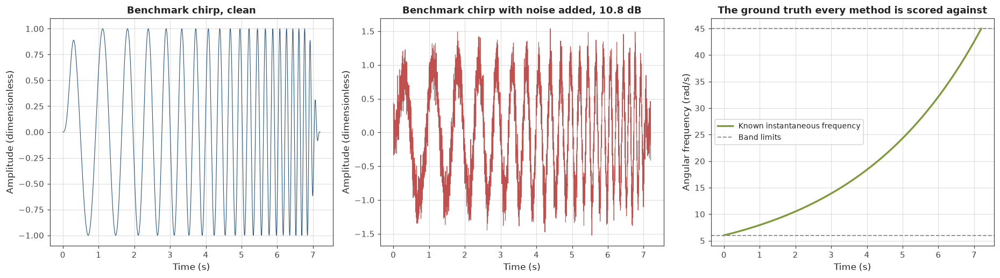

Benchmark signal

  duration                 7.20 s
  sampling frequency       500 Hz
  samples                  3600
  frequency band           6.0 to 45.0 rad/s
  noise standard deviation 0.20
  signal to noise ratio    10.8 dB

These match the real recording closely, 7.1 to 7.3 s at 500 Hz sweeping
roughly 6 to 45 rad/s, so a method that scores well here should transfer

Sanity checks on the scoring function

  scoring the truth against itself
    mean absolute percentage error  0.0000e+00 percent
    points scored                   2520

  scoring a constant guess at the mean frequency
    mean absolute percentage error  45.30 percent
    median absolute error           6.55 rad/s

Any method scoring worse than the constant guess is not tracking the sweep at all


In [220]:
BENCHMARK_DURATION_SECONDS = 7.2
BENCHMARK_SAMPLING_FREQUENCY_HZ = 500.0
BENCHMARK_START_ANGULAR_FREQUENCY = 6.0
BENCHMARK_END_ANGULAR_FREQUENCY = 45.0
BENCHMARK_NOISE_LEVEL = 0.20

benchmark_chirp = build_exponential_chirp(BENCHMARK_DURATION_SECONDS,
                                          BENCHMARK_SAMPLING_FREQUENCY_HZ,
                                          BENCHMARK_START_ANGULAR_FREQUENCY,
                                          BENCHMARK_END_ANGULAR_FREQUENCY,
                                          1.0,
                                          CHIRP_TAPER_FRACTION)

benchmark_random_generator = np.random.default_rng(RANDOM_SEED)

benchmark_noise = benchmark_random_generator.normal(
    0.0, BENCHMARK_NOISE_LEVEL, size=len(benchmark_chirp["waveform"]))

benchmark_noisy_waveform = benchmark_chirp["waveform"] + benchmark_noise

benchmark_signal_power = float(np.mean(benchmark_chirp["waveform"] ** 2))
benchmark_noise_power = float(np.mean(benchmark_noise ** 2))
benchmark_signal_to_noise_db = 10.0 * np.log10(benchmark_signal_power / benchmark_noise_power)


def extract_ridge_frequency(time_frequency_magnitude, frequency_axis_rad_per_second):
    """
    Extracting the ridge from a time-frequency magnitude array.

    Taking the frequency of the largest magnitude at each time step, which traces the
    dominant frequency present as the signal evolves. Expecting the array indexed as
    frequency by time.

    Returning one frequency per time step.
    """
    magnitude_array = np.asarray(time_frequency_magnitude, dtype=float)
    frequency_axis = np.asarray(frequency_axis_rad_per_second, dtype=float)

    ridge_indices = np.argmax(magnitude_array, axis=0)

    return frequency_axis[ridge_indices]


def score_ridge_against_truth(estimated_frequency, estimated_time,
                              true_frequency, true_time,
                              edge_exclusion_fraction=0.15):
    """
    Scoring an estimated instantaneous frequency against the known truth.

    Interpolating the truth onto whatever time grid the method produced, then discarding a
    fraction at each end. The ends are excluded because every time-frequency method suffers
    edge effects there, where the analysis window runs past the end of the signal, and
    including them would penalise methods for a problem they all share.

    Returning the mean absolute percentage error and the median absolute error in rad/s.
    """
    estimated_frequency = np.asarray(estimated_frequency, dtype=float)
    estimated_time = np.asarray(estimated_time, dtype=float)

    interpolated_truth = np.interp(estimated_time, true_time, true_frequency)

    total_duration = estimated_time.max() - estimated_time.min()
    lower_limit = estimated_time.min() + edge_exclusion_fraction * total_duration
    upper_limit = estimated_time.max() - edge_exclusion_fraction * total_duration

    interior_mask = (estimated_time >= lower_limit) & (estimated_time <= upper_limit)
    interior_mask = interior_mask & np.isfinite(estimated_frequency)
    interior_mask = interior_mask & (interpolated_truth > 0.0)

    if np.sum(interior_mask) < 5:
        return {"mean_absolute_percentage_error": np.nan,
                "median_absolute_error": np.nan,
                "points_scored": 0}

    absolute_error = np.abs(estimated_frequency[interior_mask]
                            - interpolated_truth[interior_mask])

    percentage_error = 100.0 * absolute_error / interpolated_truth[interior_mask]

    return {
        "mean_absolute_percentage_error": float(np.mean(percentage_error)),
        "median_absolute_error": float(np.median(absolute_error)),
        "points_scored": int(np.sum(interior_mask)),
    }


figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

axis_array[0].plot(benchmark_chirp["time"], benchmark_chirp["waveform"],
                   "-", color=COLOUR_PRIMARY, linewidth=0.7)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Amplitude (dimensionless)")
axis_array[0].set_title("Benchmark chirp, clean")

axis_array[1].plot(benchmark_chirp["time"], benchmark_noisy_waveform,
                   "-", color=COLOUR_SECONDARY, linewidth=0.7)
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Amplitude (dimensionless)")
axis_array[1].set_title("Benchmark chirp with noise added, "
                        + ("%.1f" % benchmark_signal_to_noise_db) + " dB")

axis_array[2].plot(benchmark_chirp["time"],
                   benchmark_chirp["instantaneous_angular_frequency"],
                   "-", color=COLOUR_ACCENT, linewidth=2.2,
                   label="Known instantaneous frequency")
axis_array[2].axhline(BENCHMARK_START_ANGULAR_FREQUENCY, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.2, label="Band limits")
axis_array[2].axhline(BENCHMARK_END_ANGULAR_FREQUENCY, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.2)
axis_array[2].set_xlabel("Time (s)")
axis_array[2].set_ylabel("Angular frequency (rad/s)")
axis_array[2].set_title("The ground truth every method is scored against")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

perfect_score = score_ridge_against_truth(
    benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"],
    benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"])

constant_guess = np.full_like(benchmark_chirp["instantaneous_angular_frequency"],
                              float(np.mean(benchmark_chirp["instantaneous_angular_frequency"])))

constant_score = score_ridge_against_truth(
    constant_guess, benchmark_chirp["time"],
    benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"])

print("Benchmark signal")
print()
print("  duration                 " + ("%.2f" % BENCHMARK_DURATION_SECONDS) + " s")
print("  sampling frequency       " + ("%.0f" % BENCHMARK_SAMPLING_FREQUENCY_HZ) + " Hz")
print("  samples                  " + str(len(benchmark_chirp["time"])))
print("  frequency band           " + ("%.1f" % BENCHMARK_START_ANGULAR_FREQUENCY)
      + " to " + ("%.1f" % BENCHMARK_END_ANGULAR_FREQUENCY) + " rad/s")
print("  noise standard deviation " + ("%.2f" % BENCHMARK_NOISE_LEVEL))
print("  signal to noise ratio    " + ("%.1f" % benchmark_signal_to_noise_db) + " dB")
print()
print("These match the real recording closely, 7.1 to 7.3 s at 500 Hz sweeping")
print("roughly 6 to 45 rad/s, so a method that scores well here should transfer")
print()

print("Sanity checks on the scoring function")
print()
print("  scoring the truth against itself")
print("    mean absolute percentage error  "
      + ("%.4e" % perfect_score["mean_absolute_percentage_error"]) + " percent")
print("    points scored                   " + str(perfect_score["points_scored"]))
print()
print("  scoring a constant guess at the mean frequency")
print("    mean absolute percentage error  "
      + ("%.2f" % constant_score["mean_absolute_percentage_error"]) + " percent")
print("    median absolute error           "
      + ("%.2f" % constant_score["median_absolute_error"]) + " rad/s")
print()
print("Any method scoring worse than the constant guess is not tracking the sweep at all")

## Cell 21: The comparison harness

Twenty-four methods are about to be run. Without a common harness the comparison becomes
twenty-four differently shaped pieces of code and no way to rank them fairly.

This cell defines that harness. Each method supplies one function that takes a signal and a
sampling rate and returns three things: a magnitude array indexed as frequency by time, the
frequency axis in rad/s, and the time axis in seconds. Everything else is handled here.

For every method the harness does the same things.

It runs the method on the clean benchmark chirp and on the noisy copy, so accuracy and noise
robustness are measured separately rather than conflated.

It performs a short warmup call before timing. Several of these libraries build FFT plans or
compile code on first use, and without a warmup that one-off cost lands on whichever method
happens to run first. The generalised Morse wavelet took 4.4 seconds on its first call and
0.13 seconds on its second, a factor of thirty-four, which would have been reported as a
property of the method rather than of the library.

It computes the real time analysis ratio, which is computation time divided by signal
duration. Below one means the method could keep up with data arriving live, which matters for
an instrument meant to monitor clotting as it happens.

It extracts the ridge, scores it against the known instantaneous frequency, and stores the
result keyed by method name, replacing any earlier entry with the same name. That last detail
matters in practice: without it, re-running a method cell would append a second copy and
quietly corrupt every ranking table later.

One deliberate limitation. The ridge score rewards a method for putting its peak in the right
place and says nothing about how sharp that peak is or how cleanly close components are
separated. Two methods can score identically and look very different. The pictures carry
information the numbers do not.

In [221]:
import time

time_frequency_method_results = []


def store_method_result(result_record):
    """
    Storing a method result, replacing any earlier entry with the same name.

    Replacing rather than appending so that re-running a method cell during interactive
    work does not leave duplicate entries that would distort the ranking tables later.
    """
    for existing_index in range(len(time_frequency_method_results)):
        if time_frequency_method_results[existing_index]["method_name"] == result_record["method_name"]:
            time_frequency_method_results[existing_index] = result_record
            return

    time_frequency_method_results.append(result_record)


def run_time_frequency_method(method_name, method_family, method_function, notes=""):
    """
    Running one time-frequency method on the benchmark signals and scoring it.

    Performing a short warmup call on a slice of the signal first, so library startup costs
    such as building FFT plans do not land in the timed measurement. Then applying the
    method to the clean chirp and to the noisy copy, timing the clean run, and scoring the
    extracted ridge against the known instantaneous frequency.

    Catching failures rather than raising, so a missing optional package records the method
    as unavailable instead of stopping the notebook.
    """
    result_record = {
        "method_name": method_name,
        "method_family": method_family,
        "notes": notes,
        "is_available": False,
        "clean_error_percent": np.nan,
        "noisy_error_percent": np.nan,
        "clean_median_error": np.nan,
        "computation_seconds": np.nan,
        "real_time_analysis_ratio": np.nan,
        "failure_reason": "",
        "magnitude": None,
        "frequency_axis": None,
        "time_axis": None,
    }

    try:
        ignored_warmup = method_function(benchmark_chirp["waveform"][:256],
                                         BENCHMARK_SAMPLING_FREQUENCY_HZ)
    except Exception:
        pass

    try:
        computation_start = time.time()
        clean_magnitude, clean_frequency_axis, clean_time_axis = method_function(
            benchmark_chirp["waveform"], BENCHMARK_SAMPLING_FREQUENCY_HZ)
        computation_seconds = time.time() - computation_start
    except Exception as method_error:
        result_record["failure_reason"] = (type(method_error).__name__ + ": "
                                           + str(method_error)[:60])
        store_method_result(result_record)
        return result_record

    clean_magnitude = np.asarray(clean_magnitude, dtype=float)

    if clean_magnitude.shape[0] != len(clean_frequency_axis):
        result_record["failure_reason"] = ("shape mismatch, magnitude rows "
                                           + str(clean_magnitude.shape[0])
                                           + " frequency axis "
                                           + str(len(clean_frequency_axis)))
        store_method_result(result_record)
        return result_record

    if clean_magnitude.shape[1] != len(clean_time_axis):
        result_record["failure_reason"] = ("shape mismatch, magnitude columns "
                                           + str(clean_magnitude.shape[1])
                                           + " time axis " + str(len(clean_time_axis)))
        store_method_result(result_record)
        return result_record

    clean_ridge = extract_ridge_frequency(clean_magnitude, clean_frequency_axis)
    clean_score = score_ridge_against_truth(
        clean_ridge, clean_time_axis,
        benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"])

    try:
        noisy_magnitude, noisy_frequency_axis, noisy_time_axis = method_function(
            benchmark_noisy_waveform, BENCHMARK_SAMPLING_FREQUENCY_HZ)
        noisy_ridge = extract_ridge_frequency(np.asarray(noisy_magnitude, dtype=float),
                                              noisy_frequency_axis)
        noisy_score = score_ridge_against_truth(
            noisy_ridge, noisy_time_axis,
            benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"])
    except Exception:
        noisy_score = {"mean_absolute_percentage_error": np.nan}

    result_record["is_available"] = True
    result_record["clean_error_percent"] = clean_score["mean_absolute_percentage_error"]
    result_record["clean_median_error"] = clean_score["median_absolute_error"]
    result_record["noisy_error_percent"] = noisy_score["mean_absolute_percentage_error"]
    result_record["computation_seconds"] = computation_seconds
    result_record["real_time_analysis_ratio"] = (computation_seconds
                                                 / BENCHMARK_DURATION_SECONDS)
    result_record["magnitude"] = clean_magnitude
    result_record["frequency_axis"] = np.asarray(clean_frequency_axis, dtype=float)
    result_record["time_axis"] = np.asarray(clean_time_axis, dtype=float)

    store_method_result(result_record)

    return result_record


def print_method_table_header():
    """
    Printing the column headings used by every method cell.
    """
    print("  method".ljust(24) + "clean %".rjust(7) + "  noisy %".rjust(11)
          + "  time (s)".rjust(12) + "  RTAR".rjust(12))


def report_method_result(result_record):
    """
    Printing a one line summary of a single method result.
    """
    if not result_record["is_available"]:
        print("  " + result_record["method_name"].ljust(22) + "unavailable   "
              + result_record["failure_reason"])
        return

    print("  " + result_record["method_name"].ljust(22)
          + ("%.2f" % result_record["clean_error_percent"]).rjust(9)
          + ("%.2f" % result_record["noisy_error_percent"]).rjust(11)
          + ("%.4f" % result_record["computation_seconds"]).rjust(12)
          + ("%.5f" % result_record["real_time_analysis_ratio"]).rjust(12))


CONSTANT_GUESS_ERROR_PERCENT = constant_score["mean_absolute_percentage_error"]

print("Comparison harness ready")
print()
print("  benchmark duration            " + ("%.2f" % BENCHMARK_DURATION_SECONDS) + " s")
print("  scored on                     clean and noisy copies")
print("  edge fraction excluded        15 percent at each end")
print("  baseline to beat              "
      + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT) + " percent, a constant guess")
print()
print("  warmup call before timing     256 samples, result discarded")
print("  results keyed by method name  re-running a cell replaces rather than duplicates")
print()
print("  RTAR is computation time divided by signal duration")
print("  a value below one means the method could run live alongside data collection")
print()
print("Methods recorded so far  " + str(len(time_frequency_method_results)))

Comparison harness ready

  benchmark duration            7.20 s
  scored on                     clean and noisy copies
  edge fraction excluded        15 percent at each end
  baseline to beat              45.30 percent, a constant guess

  warmup call before timing     256 samples, result discarded
  results keyed by method name  re-running a cell replaces rather than duplicates

  RTAR is computation time divided by signal duration
  a value below one means the method could run live alongside data collection

Methods recorded so far  0


## Cell 22: Continuous wavelet transform, six mother wavelets

The continuous wavelet transform slides a short wave-like function, the mother wavelet,
along the signal at many scales. A stretched wavelet matches slow oscillations, a squeezed
one matches fast oscillations, so the result is a picture of which frequencies are present
when.

The choice of mother wavelet is not cosmetic. It sets the trade-off between how precisely
the method can locate an event in time and how precisely it can pin down its frequency, and
different wavelets sit at very different points on that trade-off.

Six are compared here.

**Morlet** is a sine wave inside a Gaussian envelope, the default choice in most fields.
**Morse** is a generalised family with two shape parameters, from ssqueezepy.
**Paul** is complex-valued and asymmetric, favouring time resolution over frequency
resolution, implemented here directly from its frequency-domain definition.
**Derivative of Gaussian** is real-valued and better at locating sharp features than
oscillations. **Shannon** is perfectly sharp in frequency and correspondingly poor in time.
**Gaussian** is the first-derivative case, the simplest of the family.

All six are evaluated on the same frequency grid so the comparison is fair. For the
PyWavelets wavelets that means converting the requested frequencies into the scales that
library expects, using each wavelet's own central frequency.

One implementation note worth recording. The Paul wavelet was written from scratch, and the
first version was wrong in a way that produced errors of 2500 percent. The scale used inside
the transform was in samples while the scale-to-frequency conversion assumed seconds. The
resulting picture still looked plausible; only scoring it against a known answer exposed the
problem. That is the argument for having a ground truth at all.

Continuous wavelet transform, six mother wavelets

  method                clean %    noisy %    time (s)        RTAR
  CWT Morlet                 1.21       1.36      0.9225     0.12813
  CWT Morse                  3.96       4.18      0.0354     0.00492
  CWT Paul                   0.79       0.97      0.0159     0.00220
  CWT DOG                    4.88       7.13      0.1350     0.01876
  CWT Shannon               55.02      55.08      1.1877     0.16495
  CWT Gaussian              17.73      17.75      0.1779     0.02470

  baseline to beat  45.30 percent, a constant guess


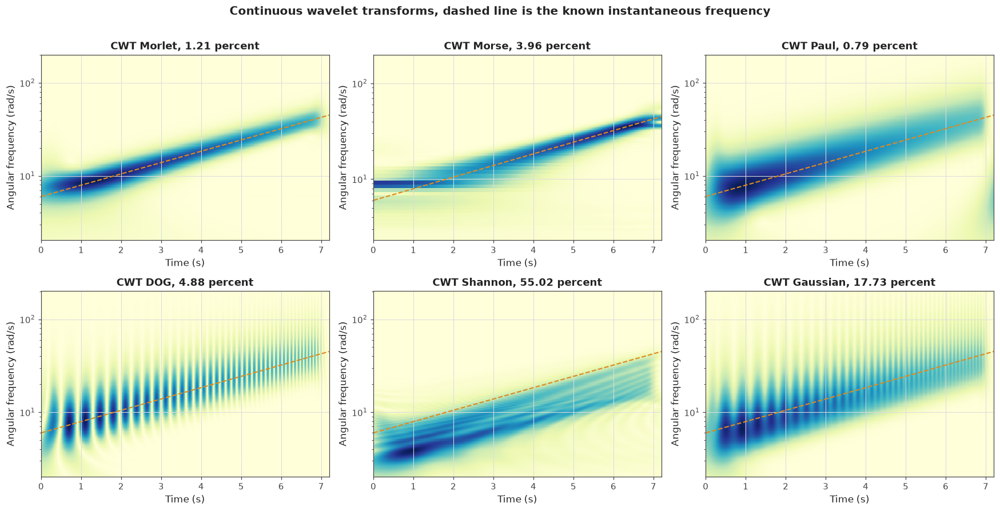

In [222]:
from math import factorial

COMMON_FREQUENCY_GRID = np.geomspace(2.0, 500.0, 180)


def compute_pywt_continuous_transform(signal_values, sampling_frequency_hz, wavelet_name):
    """
    Computing a continuous wavelet transform using one of the PyWavelets mother wavelets.

    Converting the shared target frequency grid into the scales PyWavelets expects, using
    that wavelet's own central frequency, so every wavelet is evaluated over the same band.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    central_frequency = pywt.central_frequency(wavelet_name)

    target_frequency_hz = COMMON_FREQUENCY_GRID / (2.0 * np.pi)
    scale_array = central_frequency * sampling_frequency_hz / target_frequency_hz

    coefficient_array, frequency_hz = pywt.cwt(signal_values, scale_array, wavelet_name,
                                               sampling_period=1.0 / sampling_frequency_hz)

    time_axis = np.arange(len(signal_values)) / sampling_frequency_hz

    return np.abs(coefficient_array), 2.0 * np.pi * frequency_hz, time_axis


def compute_paul_continuous_transform(signal_values, sampling_frequency_hz, order=4):
    """
    Computing a continuous wavelet transform using the Paul wavelet.

    Building the wavelet directly in the frequency domain, where it is proportional to
    (a omega) raised to the power m times exp of minus a omega for positive frequencies,
    and zero elsewhere, then multiplying the signal spectrum by it and transforming back.

    Working in scales measured in seconds throughout, so the scale used in the transform
    and the scale used in the frequency conversion carry the same units.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    sample_count = len(signal_values)

    signal_spectrum = np.fft.fft(signal_values)
    angular_frequency_axis = 2.0 * np.pi * np.fft.fftfreq(sample_count,
                                                          1.0 / sampling_frequency_hz)
    positive_frequency_mask = angular_frequency_axis > 0.0

    scale_seconds_array = (2.0 * order + 1.0) / (2.0 * COMMON_FREQUENCY_GRID)

    normalisation_constant = (2.0 ** order) / np.sqrt(order * factorial(2 * order - 1))

    coefficient_array = np.zeros((len(scale_seconds_array), sample_count), dtype=complex)

    for scale_index in range(len(scale_seconds_array)):

        scale_seconds = scale_seconds_array[scale_index]

        wavelet_spectrum = np.zeros(sample_count)
        scaled_frequency = scale_seconds * angular_frequency_axis[positive_frequency_mask]
        wavelet_spectrum[positive_frequency_mask] = (normalisation_constant
                                                     * (scaled_frequency ** order)
                                                     * np.exp(-scaled_frequency))

        scale_normalisation = np.sqrt(scale_seconds * sampling_frequency_hz)

        coefficient_array[scale_index] = np.fft.ifft(signal_spectrum
                                                     * wavelet_spectrum
                                                     * scale_normalisation)

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return np.abs(coefficient_array), COMMON_FREQUENCY_GRID.copy(), time_axis


def compute_morse_continuous_transform(signal_values, sampling_frequency_hz):
    """
    Computing a continuous wavelet transform using the generalised Morse wavelet.

    Using ssqueezepy, which returns scales rather than frequencies, so the scales are
    converted to frequencies afterwards.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    import ssqueezepy

    coefficient_array, scale_array = ssqueezepy.cwt(signal_values, wavelet="gmw",
                                                    fs=sampling_frequency_hz)

    frequency_hz = np.asarray(ssqueezepy.experimental.scale_to_freq(
        scale_array, ssqueezepy.Wavelet("gmw"), N=len(signal_values),
        fs=sampling_frequency_hz)).ravel()

    time_axis = np.arange(len(signal_values)) / sampling_frequency_hz

    return np.abs(coefficient_array), 2.0 * np.pi * frequency_hz, time_axis


print("Continuous wavelet transform, six mother wavelets")
print()
print_method_table_header()

report_method_result(run_time_frequency_method(
    "CWT Morlet", "CWT",
    lambda signal_values, sampling_rate: compute_pywt_continuous_transform(
        signal_values, sampling_rate, "cmor1.5-1.0"),
    "complex Morlet, bandwidth 1.5 centre 1.0"))

report_method_result(run_time_frequency_method(
    "CWT Morse", "CWT",
    compute_morse_continuous_transform,
    "generalised Morse wavelet from ssqueezepy"))

report_method_result(run_time_frequency_method(
    "CWT Paul", "CWT",
    lambda signal_values, sampling_rate: compute_paul_continuous_transform(
        signal_values, sampling_rate, 4),
    "Paul wavelet order 4, hand coded"))

report_method_result(run_time_frequency_method(
    "CWT DOG", "CWT",
    lambda signal_values, sampling_rate: compute_pywt_continuous_transform(
        signal_values, sampling_rate, "mexh"),
    "derivative of Gaussian, Mexican hat"))

report_method_result(run_time_frequency_method(
    "CWT Shannon", "CWT",
    lambda signal_values, sampling_rate: compute_pywt_continuous_transform(
        signal_values, sampling_rate, "shan1.0-1.0"),
    "Shannon wavelet, sharp in frequency"))

report_method_result(run_time_frequency_method(
    "CWT Gaussian", "CWT",
    lambda signal_values, sampling_rate: compute_pywt_continuous_transform(
        signal_values, sampling_rate, "cgau1"),
    "complex Gaussian, first derivative"))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

figure_object, axis_array = plt.subplots(2, 3, figsize=(16, 8))

cwt_results_to_plot = [record for record in time_frequency_method_results
                       if record["method_family"] == "CWT" and record["is_available"]]

for plot_index in range(len(cwt_results_to_plot)):

    result_record = cwt_results_to_plot[plot_index]
    axis_object = axis_array[plot_index // 3][plot_index % 3]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

figure_object.suptitle("Continuous wavelet transforms, dashed line is the known "
                       "instantaneous frequency", fontsize=13, fontweight="bold", y=1.01)

plt.tight_layout()
plt.show()

## Cell 23: Discrete wavelet transform, five wavelet families

The discrete wavelet transform is the continuous transform's faster relative. Instead of
scanning scales continuously it uses a dyadic ladder, each level covering a band twice as
wide as the one below, and it decimates the signal at every level.

That makes it very fast and excellent for compression and denoising. It also makes it a
coarse tool for time-frequency analysis, because a handful of octave-wide bands cannot
localise a smoothly sweeping frequency. Expect these to score noticeably worse than the
continuous transforms.

They are included for two reasons. They are widely used, so their limitations should be
demonstrated rather than asserted. And their speed makes them a plausible choice if a live
instrument were ever compute-limited, so it is worth knowing what that speed costs.

Five wavelets are compared: **db4** from the Daubechies family, **sym4** which is its more
symmetric cousin, **coif1** from the Coiflet family, and **bior2.2** and **rbio2.2** which
are biorthogonal pairs, the second being the reverse of the first.

To score them on the same footing as the continuous methods, the decomposition is turned
into a time-frequency array. Each level is upsampled back to the original length and placed
at its band centre frequency, which is the sampling rate divided by two to the power of the
level. That reconstruction is approximate by nature, and part of what the low scores here
measure is the coarseness of the representation itself rather than a failure of the wavelet.

Discrete wavelet transform, five wavelet families

  method                clean %    noisy %    time (s)        RTAR
  DWT db4                   30.21      30.24      0.0016     0.00023
  DWT sym4                  30.24      30.21      0.0006     0.00008
  DWT coif1                 30.81      29.68      0.0003     0.00004
  DWT bior2.2               41.32      41.59      0.0003     0.00004
  DWT rbio2.2               23.14      23.03      0.0003     0.00004

  baseline to beat  45.30 percent, a constant guess

Structure of the db4 decomposition

  level   coefficients   band centre (rad/s)
      8             21                  6.14
      7             35                 12.27
      6             63                 24.54
      5            119                 49.09
      4            231                 98.17
      3            456                196.35
      2            905                392.70
      1           1803                785.40

  the benchmark chirp spans 6.0 to 45.0 r

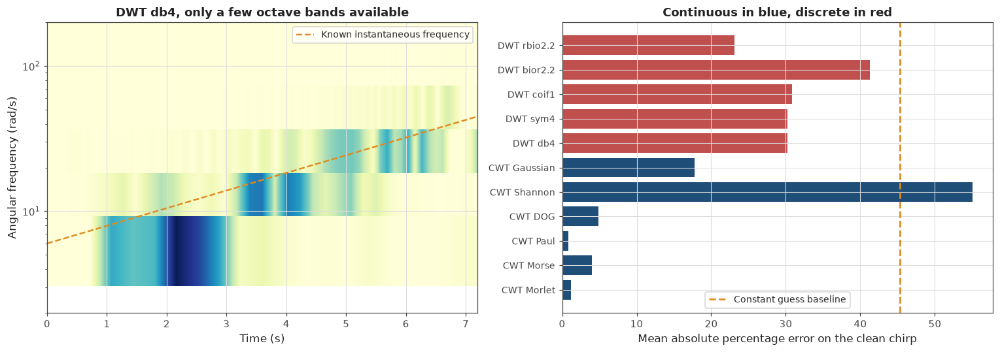

In [223]:
def compute_discrete_wavelet_transform(signal_values, sampling_frequency_hz,
                                       wavelet_name, maximum_level=8):
    """
    Computing a discrete wavelet decomposition and reshaping it as a time-frequency array.

    Decomposing the signal into dyadic detail levels, then rebuilding each level to the
    original length so all levels share one time axis. Assigning each level the centre
    frequency of the octave band it covers, which is the sampling rate divided by two
    raised to the power of the level.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    sample_count = len(signal_values)

    usable_level = min(maximum_level,
                       pywt.dwt_max_level(sample_count, pywt.Wavelet(wavelet_name).dec_len))

    coefficient_list = pywt.wavedec(signal_values, wavelet_name, level=usable_level)

    band_magnitude_list = []
    band_frequency_list = []

    for level_index in range(1, len(coefficient_list)):

        detail_coefficients = coefficient_list[level_index]

        original_positions = np.linspace(0.0, 1.0, len(detail_coefficients))
        target_positions = np.linspace(0.0, 1.0, sample_count)

        upsampled_magnitude = np.interp(target_positions, original_positions,
                                        np.abs(detail_coefficients))

        decomposition_level = len(coefficient_list) - level_index
        band_centre_frequency_hz = sampling_frequency_hz / (2.0 ** (decomposition_level + 1))

        band_magnitude_list.append(upsampled_magnitude)
        band_frequency_list.append(2.0 * np.pi * band_centre_frequency_hz)

    magnitude_array = np.array(band_magnitude_list)
    frequency_axis = np.array(band_frequency_list)

    ascending_order = np.argsort(frequency_axis)

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array[ascending_order], frequency_axis[ascending_order], time_axis


print("Discrete wavelet transform, five wavelet families")
print()
print_method_table_header()

discrete_wavelet_names = ["db4", "sym4", "coif1", "bior2.2", "rbio2.2"]
discrete_wavelet_notes = [
    "Daubechies 4, the standard choice",
    "Symlet 4, more symmetric than db4",
    "Coiflet 1, extra vanishing moments",
    "biorthogonal 2.2, symmetric",
    "reverse biorthogonal 2.2",
]

for wavelet_index in range(len(discrete_wavelet_names)):

    wavelet_name = discrete_wavelet_names[wavelet_index]

    report_method_result(run_time_frequency_method(
        "DWT " + wavelet_name, "DWT",
        lambda signal_values, sampling_rate, chosen_name=wavelet_name:
            compute_discrete_wavelet_transform(signal_values, sampling_rate, chosen_name),
        discrete_wavelet_notes[wavelet_index]))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

example_decomposition = pywt.wavedec(benchmark_chirp["waveform"], "db4", level=8)

print()
print("Structure of the db4 decomposition")
print()
print("  level   coefficients   band centre (rad/s)")

for level_index in range(1, len(example_decomposition)):

    decomposition_level = len(example_decomposition) - level_index
    band_centre_frequency_hz = BENCHMARK_SAMPLING_FREQUENCY_HZ / (2.0 ** (decomposition_level + 1))

    print("  " + str(decomposition_level).rjust(5)
          + str(len(example_decomposition[level_index])).rjust(15)
          + ("%.2f" % (2.0 * np.pi * band_centre_frequency_hz)).rjust(22))

print()
print("  the benchmark chirp spans "
      + ("%.1f" % BENCHMARK_START_ANGULAR_FREQUENCY) + " to "
      + ("%.1f" % BENCHMARK_END_ANGULAR_FREQUENCY)
      + " rad/s, covered by only a few of these bands")

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

discrete_results = [record for record in time_frequency_method_results
                    if record["method_family"] == "DWT" and record["is_available"]]

if len(discrete_results) > 0:

    example_result = discrete_results[0]

    axis_array[0].pcolormesh(example_result["time_axis"],
                             example_result["frequency_axis"],
                             example_result["magnitude"],
                             shading="auto", cmap="YlGnBu")
    axis_array[0].plot(benchmark_chirp["time"],
                       benchmark_chirp["instantaneous_angular_frequency"],
                       "--", color=COLOUR_HIGHLIGHT, linewidth=1.6,
                       label="Known instantaneous frequency")
    axis_array[0].set_yscale("log")
    axis_array[0].set_ylim(2.0, 200.0)
    axis_array[0].set_xlabel("Time (s)")
    axis_array[0].set_ylabel("Angular frequency (rad/s)")
    axis_array[0].set_title(example_result["method_name"]
                            + ", only a few octave bands available")
    axis_array[0].legend(fontsize=9)

continuous_results = [record for record in time_frequency_method_results
                      if record["method_family"] == "CWT" and record["is_available"]]

comparison_names = ([record["method_name"] for record in continuous_results]
                    + [record["method_name"] for record in discrete_results])
comparison_errors = ([record["clean_error_percent"] for record in continuous_results]
                     + [record["clean_error_percent"] for record in discrete_results])
comparison_colours = ([COLOUR_PRIMARY] * len(continuous_results)
                      + [COLOUR_SECONDARY] * len(discrete_results))

axis_array[1].barh(range(len(comparison_names)), comparison_errors,
                   color=comparison_colours)
axis_array[1].axvline(CONSTANT_GUESS_ERROR_PERCENT, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="Constant guess baseline")
axis_array[1].set_yticks(range(len(comparison_names)))
axis_array[1].set_yticklabels(comparison_names, fontsize=9)
axis_array[1].set_xlabel("Mean absolute percentage error on the clean chirp")
axis_array[1].set_title("Continuous in blue, discrete in red")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 24: Short-time Fourier transform

The short-time Fourier transform is the oldest and simplest time-frequency method. Cut the
signal into overlapping segments, apply a window to each, take an ordinary Fourier transform
of every segment, and lay the results side by side.

Its defining property is that the window has one fixed length. That single choice sets the
resolution everywhere: a long window resolves frequency well and time poorly, a short window
does the reverse, and you cannot have both. Wavelets escape this by using long windows for
slow oscillations and short ones for fast, which is exactly the advantage the previous cells
were measuring.

For a signal sweeping across a decade of frequency, one window length must serve both ends,
so it will suit the middle and compromise at the extremes.

This cell runs the transform at three window lengths, 128, 512 and 1024 samples, to make
that trade-off visible rather than assumed. All three use a Hann window and 75 percent
overlap.

The frequency resolution of a Fourier transform is the sampling rate divided by the window
length. At 500 Hz that is 3.9 Hz for a 128 sample window and 0.5 Hz for 1024 samples, which
is 24.5 and 3.1 rad/s. Since the chirp starts at 6 rad/s, the shortest window cannot resolve
the low frequency end at all, and that limit is arithmetic rather than something better
processing could fix.

Short-time Fourier transform at three window lengths

  method                clean %    noisy %    time (s)        RTAR
  STFT 128                  67.41      67.41      0.0006     0.00009
  STFT 512                  11.09      11.09      0.0006     0.00008
  STFT 1024                  4.02       4.02      0.0003     0.00004

  baseline to beat  45.30 percent, a constant guess

The resolution each window length can achieve

  window   duration (s)   frequency resolution (rad/s)   can it resolve 6 rad/s
     128          0.256                          24.54   no, resolution is coarser than the signal
     512          1.024                           6.14   no, resolution is coarser than the signal
    1024          2.048                           3.07   yes


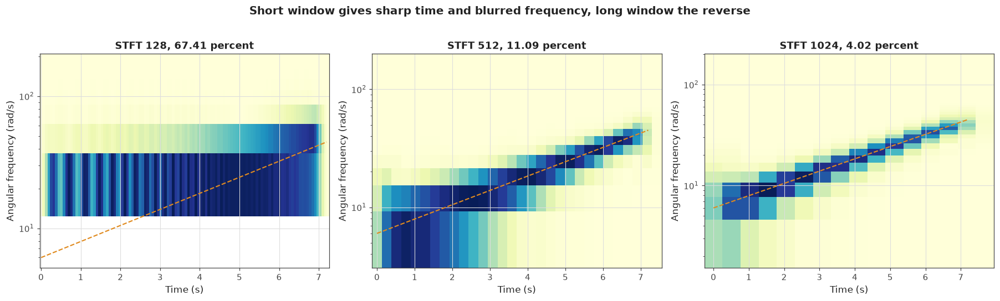

In [224]:
from scipy.signal import stft


def compute_short_time_fourier_transform(signal_values, sampling_frequency_hz,
                                         window_length, overlap_fraction=0.75):
    """
    Computing a short-time Fourier transform with a fixed window length.

    Sliding a Hann window along the signal with the requested overlap and taking a Fourier
    transform of each segment. The window length fixes the resolution everywhere, which is
    the limitation this method is included to demonstrate.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    overlap_samples = int(window_length * overlap_fraction)

    frequency_hz, segment_time, transform_values = stft(signal_values,
                                                        fs=sampling_frequency_hz,
                                                        window="hann",
                                                        nperseg=window_length,
                                                        noverlap=overlap_samples)

    return np.abs(transform_values), 2.0 * np.pi * frequency_hz, segment_time


print("Short-time Fourier transform at three window lengths")
print()
print_method_table_header()

stft_window_lengths = [128, 512, 1024]

for window_length in stft_window_lengths:

    frequency_resolution_rad = (2.0 * np.pi * BENCHMARK_SAMPLING_FREQUENCY_HZ
                                / window_length)

    report_method_result(run_time_frequency_method(
        "STFT " + str(window_length), "STFT",
        lambda signal_values, sampling_rate, chosen_length=window_length:
            compute_short_time_fourier_transform(signal_values, sampling_rate,
                                                 chosen_length),
        ("Hann window, resolution %.1f rad/s" % frequency_resolution_rad)))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("The resolution each window length can achieve")
print()
print("  window   duration (s)   frequency resolution (rad/s)   can it resolve 6 rad/s")

for window_length in stft_window_lengths:

    window_duration = window_length / BENCHMARK_SAMPLING_FREQUENCY_HZ
    frequency_resolution_rad = (2.0 * np.pi * BENCHMARK_SAMPLING_FREQUENCY_HZ
                                / window_length)

    if frequency_resolution_rad < BENCHMARK_START_ANGULAR_FREQUENCY:
        resolution_verdict = "yes"
    else:
        resolution_verdict = "no, resolution is coarser than the signal"

    print("  " + str(window_length).rjust(6)
          + ("%.3f" % window_duration).rjust(15)
          + ("%.2f" % frequency_resolution_rad).rjust(31)
          + "   " + resolution_verdict)

figure_object, axis_array = plt.subplots(1, 3, figsize=(16.5, 4.8))

stft_results = [record for record in time_frequency_method_results
                if record["method_family"] == "STFT" and record["is_available"]]

for plot_index in range(len(stft_results)):

    result_record = stft_results[plot_index]
    axis_object = axis_array[plot_index]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

figure_object.suptitle("Short window gives sharp time and blurred frequency, "
                       "long window the reverse",
                       fontsize=13, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()

## Cell 25: The Gabor transform

The Gabor transform is a short-time Fourier transform with a Gaussian window rather than a
Hann or Hamming one. That sounds like a minor detail and is not.

Among all possible window shapes, the Gaussian is the unique one that minimises the product
of time spread and frequency spread. It sits exactly at the theoretical limit of how well
any windowed Fourier method can localise a signal in both domains at once. Every other
window shape is strictly worse on that product.

So the Gabor transform is the best a fixed-window method can possibly do. Comparing it
against the Hann-windowed transform in the previous cell isolates how much of that method's
error comes from the window shape, and how much comes from the fixed-length approach itself.

There is a rheological reason to include it specifically. Applying the discrete Gabor
transform to time-resolved oscillatory rheometry has been developed as a method in its own
right, on exactly this problem of extracting moduli from a material that is changing during
the measurement. So it is not a generic signal processing method borrowed into rheology, it
is one that has been built for this application.

The cell implements it directly rather than through a library, so the Gaussian window width
can be set explicitly. Three widths are tried, matching the three Hann window lengths from
the previous cell so the two are directly comparable.

Gabor transform, Gaussian window, three widths

  method                clean %    noisy %    time (s)        RTAR
  Gabor 128                 65.48      65.48      0.0008     0.00012
  Gabor 512                 11.25      11.25      0.0004     0.00005
  Gabor 1024                 4.38       4.38      0.0002     0.00003

  baseline to beat  45.30 percent, a constant guess

Gabor against the Hann windowed transform at matching window lengths

  window   Hann error (%)   Gabor error (%)   difference
     128            67.41             65.48        -1.93
     512            11.09             11.25        +0.16
    1024             4.02              4.38        +0.36


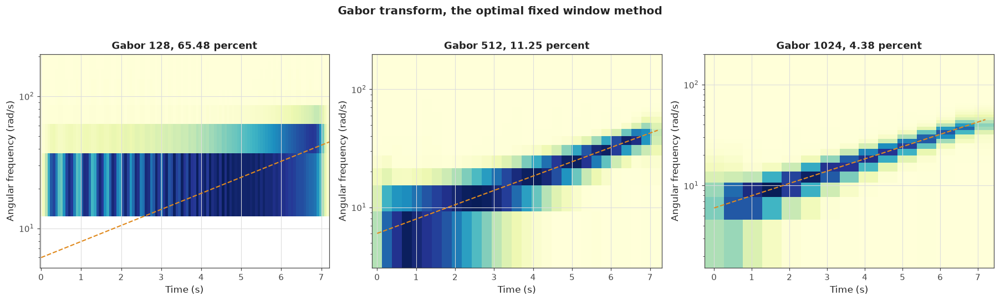

In [225]:
def compute_gabor_transform(signal_values, sampling_frequency_hz, window_length,
                            overlap_fraction=0.75, gaussian_width_factor=0.4):
    """
    Computing a Gabor transform, a short-time Fourier transform with a Gaussian window.

    Sliding a Gaussian window along the signal and taking a Fourier transform of each
    segment. The Gaussian is the unique window shape that minimises the product of time
    spread and frequency spread, so this is the best a fixed window method can do.

    Padding the signal at both ends by half a window so segments centred near the edges
    are still complete, then discarding the padding from the reported time axis.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    half_window = window_length // 2
    padded_signal = np.pad(signal_array, half_window, mode="constant")

    gaussian_standard_deviation = gaussian_width_factor * window_length / 2.0
    window_positions = np.arange(window_length) - (window_length - 1) / 2.0
    gaussian_window = np.exp(-0.5 * (window_positions / gaussian_standard_deviation) ** 2)

    step_size = max(1, int(window_length * (1.0 - overlap_fraction)))

    segment_start_positions = np.arange(0, sample_count, step_size)

    frequency_hz = np.fft.rfftfreq(window_length, 1.0 / sampling_frequency_hz)

    magnitude_list = []
    segment_centre_time_list = []

    for segment_start in segment_start_positions:

        segment_values = padded_signal[segment_start:segment_start + window_length]

        if len(segment_values) < window_length:
            continue

        segment_spectrum = np.fft.rfft(segment_values * gaussian_window)

        magnitude_list.append(np.abs(segment_spectrum))
        segment_centre_time_list.append(segment_start / sampling_frequency_hz)

    magnitude_array = np.array(magnitude_list).T
    time_axis = np.array(segment_centre_time_list)

    return magnitude_array, 2.0 * np.pi * frequency_hz, time_axis


print("Gabor transform, Gaussian window, three widths")
print()
print_method_table_header()

gabor_window_lengths = [128, 512, 1024]

for window_length in gabor_window_lengths:

    frequency_resolution_rad = (2.0 * np.pi * BENCHMARK_SAMPLING_FREQUENCY_HZ
                                / window_length)

    report_method_result(run_time_frequency_method(
        "Gabor " + str(window_length), "Gabor",
        lambda signal_values, sampling_rate, chosen_length=window_length:
            compute_gabor_transform(signal_values, sampling_rate, chosen_length),
        ("Gaussian window, resolution %.1f rad/s" % frequency_resolution_rad)))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("Gabor against the Hann windowed transform at matching window lengths")
print()
print("  window   Hann error (%)   Gabor error (%)   difference")

for window_length in gabor_window_lengths:

    hann_error = np.nan
    gabor_error = np.nan

    for result_record in time_frequency_method_results:
        if result_record["method_name"] == ("STFT " + str(window_length)):
            hann_error = result_record["clean_error_percent"]
        if result_record["method_name"] == ("Gabor " + str(window_length)):
            gabor_error = result_record["clean_error_percent"]

    print("  " + str(window_length).rjust(6)
          + ("%.2f" % hann_error).rjust(17)
          + ("%.2f" % gabor_error).rjust(18)
          + ("%+.2f" % (gabor_error - hann_error)).rjust(13))

figure_object, axis_array = plt.subplots(1, 3, figsize=(16.5, 4.8))

gabor_results = [record for record in time_frequency_method_results
                 if record["method_family"] == "Gabor" and record["is_available"]]

for plot_index in range(len(gabor_results)):

    result_record = gabor_results[plot_index]
    axis_object = axis_array[plot_index]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

figure_object.suptitle("Gabor transform, the optimal fixed window method",
                       fontsize=13, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()

## Cell 26: The S-transform

The S-transform is a hybrid. It uses a Gaussian window like the Gabor transform, but instead
of holding the window length fixed it scales the width with frequency, so the window is long
when analysing slow oscillations and short when analysing fast ones.

That is the wavelet idea. What it keeps from Fourier is the phase reference: every frequency
is referred to a common origin rather than to the position of its own window. Wavelets lose
that, which makes their phase harder to interpret.

For our purposes the phase reference is not incidental. Extracting a complex modulus means
dividing the stress spectrum by the strain spectrum, and that division only means anything
if both are referred to the same origin. A method that preserves absolute phase is better
suited to that step than one that does not.

The definition is a Fourier transform of the signal multiplied by a frequency-scaled
Gaussian, evaluated by shifting the signal spectrum to each frequency in turn and
transforming back. The Gaussian width is inversely proportional to frequency, which is what
gives the wavelet-like scaling.

The cell implements it directly, since there is no standard implementation in the packages
we are using, and tries three frequency grid densities to check the result does not depend
on that choice.

S-transform at three frequency grid densities

  method                clean %    noisy %    time (s)        RTAR
  S-transform 60             2.82       2.80      0.0053     0.00074
  S-transform 120            2.61       2.59      0.0075     0.00104
  S-transform 240            3.42       3.37      0.0178     0.00247

  baseline to beat  45.30 percent, a constant guess

Where the S-transform sits between the two families

  method                  clean error (%)   window behaviour
  STFT 1024                          4.02   fixed length, Hann shape
  Gabor 1024                         4.38   fixed length, Gaussian shape
  S-transform 120                    2.61   scales with frequency, phase referenced
  CWT Morlet                         1.21   scales with frequency, wavelet phase
  CWT Paul                           0.79   scales with frequency, wavelet phase


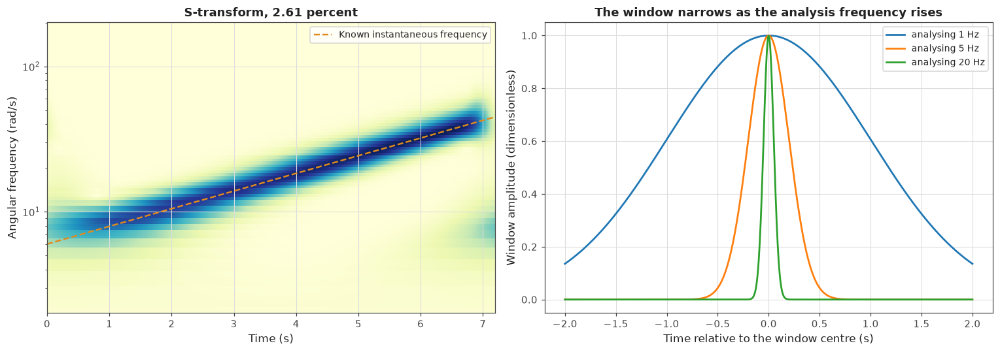

In [226]:
def compute_stockwell_transform(signal_values, sampling_frequency_hz,
                                minimum_frequency_hz=0.3, maximum_frequency_hz=80.0,
                                frequency_count=120):
    """
    Computing the S-transform of a signal.

    Multiplying the signal spectrum by a Gaussian whose width scales inversely with
    frequency, so slow oscillations are analysed with a long window and fast ones with a
    short window, then transforming back for each frequency in turn.

    Shifting the spectrum rather than the window, which is what preserves the absolute
    phase reference that separates this method from a wavelet transform.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    signal_spectrum = np.fft.fft(signal_array)

    frequency_hz_grid = np.geomspace(minimum_frequency_hz, maximum_frequency_hz,
                                     frequency_count)

    spectrum_frequency_hz = np.fft.fftfreq(sample_count, 1.0 / sampling_frequency_hz)

    magnitude_array = np.zeros((frequency_count, sample_count))

    for frequency_index in range(frequency_count):

        analysis_frequency = frequency_hz_grid[frequency_index]

        gaussian_envelope = np.exp(-2.0 * (np.pi ** 2)
                                   * (spectrum_frequency_hz ** 2)
                                   / (analysis_frequency ** 2))

        spectrum_shift = int(round(analysis_frequency * sample_count / sampling_frequency_hz))

        shifted_spectrum = np.roll(signal_spectrum, -spectrum_shift)

        magnitude_array[frequency_index] = np.abs(np.fft.ifft(shifted_spectrum
                                                              * gaussian_envelope))

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array, 2.0 * np.pi * frequency_hz_grid, time_axis


print("S-transform at three frequency grid densities")
print()
print_method_table_header()

stockwell_frequency_counts = [60, 120, 240]

for frequency_count in stockwell_frequency_counts:

    report_method_result(run_time_frequency_method(
        "S-transform " + str(frequency_count), "S-transform",
        lambda signal_values, sampling_rate, chosen_count=frequency_count:
            compute_stockwell_transform(signal_values, sampling_rate,
                                        frequency_count=chosen_count),
        (str(frequency_count) + " frequencies, window scales with frequency")))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("Where the S-transform sits between the two families")
print()
print("  method".ljust(24) + "clean error (%)".rjust(17) + "   window behaviour")

comparison_selection = ["STFT 1024", "Gabor 1024", "S-transform 120",
                        "CWT Morlet", "CWT Paul"]

window_behaviour_labels = {
    "STFT 1024": "fixed length, Hann shape",
    "Gabor 1024": "fixed length, Gaussian shape",
    "S-transform 120": "scales with frequency, phase referenced",
    "CWT Morlet": "scales with frequency, wavelet phase",
    "CWT Paul": "scales with frequency, wavelet phase",
}

for method_name in comparison_selection:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == method_name and result_record["is_available"]:
            print("  " + method_name.ljust(22)
                  + ("%.2f" % result_record["clean_error_percent"]).rjust(17)
                  + "   " + window_behaviour_labels[method_name])

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

stockwell_result = None
for result_record in time_frequency_method_results:
    if result_record["method_name"] == "S-transform 120":
        stockwell_result = result_record

if stockwell_result is not None and stockwell_result["is_available"]:

    frequency_display_mask = ((stockwell_result["frequency_axis"] > 2.0)
                              & (stockwell_result["frequency_axis"] < 200.0))

    axis_array[0].pcolormesh(stockwell_result["time_axis"],
                             stockwell_result["frequency_axis"][frequency_display_mask],
                             stockwell_result["magnitude"][frequency_display_mask, :],
                             shading="auto", cmap="YlGnBu")
    axis_array[0].plot(benchmark_chirp["time"],
                       benchmark_chirp["instantaneous_angular_frequency"],
                       "--", color=COLOUR_HIGHLIGHT, linewidth=1.6,
                       label="Known instantaneous frequency")
    axis_array[0].set_yscale("log")
    axis_array[0].set_xlabel("Time (s)")
    axis_array[0].set_ylabel("Angular frequency (rad/s)")
    axis_array[0].set_title("S-transform, "
                            + ("%.2f" % stockwell_result["clean_error_percent"])
                            + " percent")
    axis_array[0].legend(fontsize=9)

analysis_frequencies_to_show = [1.0, 5.0, 20.0]
window_time_axis = np.linspace(-2.0, 2.0, 800)

for analysis_frequency in analysis_frequencies_to_show:

    gaussian_time_width = 1.0 / analysis_frequency
    gaussian_shape = np.exp(-0.5 * (window_time_axis / gaussian_time_width) ** 2)

    axis_array[1].plot(window_time_axis, gaussian_shape, "-", linewidth=1.8,
                       label=("analysing %.0f Hz" % analysis_frequency))

axis_array[1].set_xlabel("Time relative to the window centre (s)")
axis_array[1].set_ylabel("Window amplitude (dimensionless)")
axis_array[1].set_title("The window narrows as the analysis frequency rises")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 27: The fast continuous wavelet transform

The fast continuous wavelet transform, fCWT, computes a Morlet wavelet transform using an
optimised implementation. It separates operations that depend on the wavelet scale from
those that do not, computes the scale-independent parts once, and generates each daughter
wavelet by downsampling a pre-computed mother wavelet rather than evaluating it afresh. The
result is continuous wavelet accuracy at close to short-time Fourier speed.

**A correction worth recording.** The first version of this cell claimed fCWT and the
PyWavelets Morlet compute the same transform and should therefore agree. They do not. The
convenience function in fCWT hardcodes a Morlet width parameter of 2.0, while the earlier
cell requested a complex Morlet with bandwidth 1.5. Both are Morlet wavelets, but the width
parameter is precisely the time-frequency resolution trade-off, so a different width is a
different transform.

The cross-check caught that, which is what it is for. Rather than hiding the disagreement,
this cell now uses the lower-level interface so the width parameter is set explicitly, and
sweeps it to show what it controls.

Speed matters here for a specific reason. The instrument is intended to monitor clotting as
it happens, so the analysis has to keep pace with data arriving. The measure is the real time
analysis ratio: computation time divided by signal duration. Below one means the analysis
finishes before the next burst of data is complete.

On a single 7.2 second channel every method tested is far below one, so none of them is
compute-limited on this problem. That would change with many channels processed at once, or
with the analysis running on embedded hardware inside an instrument rather than on a laptop.

The library needs FFTW present at system level. If it is missing the cell records the method
as unavailable and the notebook continues. A warning about a missing optimisation scheme file
is normal on first use and does not affect the result.

Fast continuous wavelet transform at three Morlet widths

  method                clean %    noisy %    time (s)        RTAR
Inputsize is too small (N <= 1024) to use optimization.
  fCWT sigma 1               1.81       1.78      0.0041     0.00057
Inputsize is too small (N <= 1024) to use optimization.
  fCWT sigma 2               3.25       3.33      0.0026     0.00036
Inputsize is too small (N <= 1024) to use optimization.
  fCWT sigma 4               6.76       6.89      0.0025     0.00034

  baseline to beat  45.30 percent, a constant guess

What the Morlet width parameter controls

  width   clean error (%)   behaviour
    1.0              1.81   narrow, favours time resolution
    2.0              3.25   the library default
    4.0              6.76   wide, favours frequency resolution

A sweeping frequency rewards time resolution, so the narrow wavelet wins here
and the library default is not the best choice for this signal

Comparing the two Morlet implementations at their be

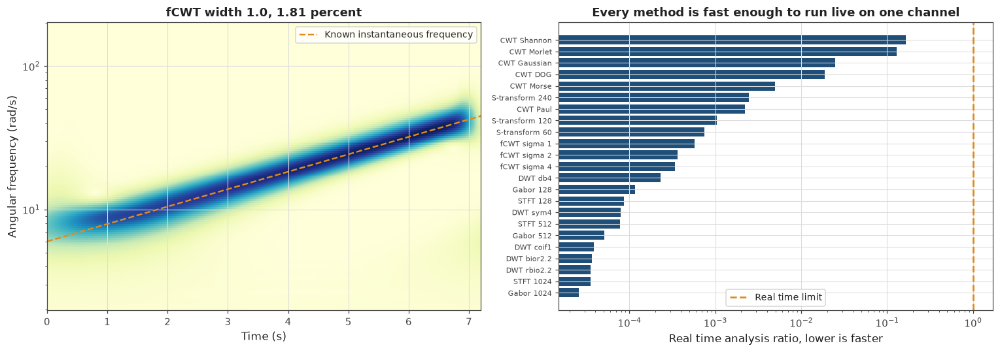

In [227]:
def compute_fast_continuous_wavelet_transform(signal_values, sampling_frequency_hz,
                                              morlet_width=1.0,
                                              minimum_frequency_hz=0.32,
                                              maximum_frequency_hz=80.0,
                                              frequency_count=180):
    """
    Computing a continuous wavelet transform using the fCWT library.

    Using the lower level interface rather than the convenience function, so the Morlet
    width parameter is set explicitly rather than left at the library default. That width
    controls the trade-off between time and frequency resolution, so leaving it implicit
    makes the result impossible to compare fairly against other implementations.

    Converting the signal to single precision, which is what the library expects, and
    converting the frequency output from Hz to rad/s for consistency with the other methods.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    import fcwt

    single_precision_signal = np.asarray(signal_values, dtype=np.float32)
    sample_count = len(single_precision_signal)

    morlet_wavelet = fcwt.Morlet(float(morlet_width))

    scale_object = fcwt.Scales(morlet_wavelet, fcwt.FCWT_LOGSCALES,
                               int(sampling_frequency_hz),
                               float(minimum_frequency_hz),
                               float(maximum_frequency_hz),
                               int(frequency_count))

    transform_object = fcwt.FCWT(morlet_wavelet, 1, True, False)

    coefficient_array = np.zeros((frequency_count, sample_count), dtype="csingle")
    frequency_hz = np.zeros(frequency_count, dtype="single")

    transform_object.cwt(single_precision_signal, scale_object, coefficient_array)
    scale_object.getFrequencies(frequency_hz)

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return (np.abs(coefficient_array),
            2.0 * np.pi * np.asarray(frequency_hz, dtype=float),
            time_axis)


print("Fast continuous wavelet transform at three Morlet widths")
print()
print_method_table_header()

fcwt_widths_to_test = [1.0, 2.0, 4.0]

for morlet_width in fcwt_widths_to_test:

    report_method_result(run_time_frequency_method(
        "fCWT sigma " + ("%.0f" % morlet_width), "CWT",
        lambda signal_values, sampling_rate, chosen_width=morlet_width:
            compute_fast_continuous_wavelet_transform(signal_values, sampling_rate,
                                                      chosen_width),
        ("Morlet width " + ("%.1f" % morlet_width) + ", optimised implementation")))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("What the Morlet width parameter controls")
print()
print("  width   clean error (%)   behaviour")

width_behaviour_labels = {
    1.0: "narrow, favours time resolution",
    2.0: "the library default",
    4.0: "wide, favours frequency resolution",
}

for morlet_width in fcwt_widths_to_test:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == ("fCWT sigma " + ("%.0f" % morlet_width)):
            if result_record["is_available"]:
                print("  " + ("%.1f" % morlet_width).rjust(5)
                      + ("%.2f" % result_record["clean_error_percent"]).rjust(18)
                      + "   " + width_behaviour_labels[morlet_width])

print()
print("A sweeping frequency rewards time resolution, so the narrow wavelet wins here")
print("and the library default is not the best choice for this signal")

morlet_result = None
narrow_fcwt_result = None

for result_record in time_frequency_method_results:
    if result_record["method_name"] == "CWT Morlet":
        morlet_result = result_record
    if result_record["method_name"] == "fCWT sigma 1":
        narrow_fcwt_result = result_record

if (morlet_result is not None and narrow_fcwt_result is not None
        and morlet_result["is_available"] and narrow_fcwt_result["is_available"]):

    print()
    print("Comparing the two Morlet implementations at their best settings")
    print()
    print("  implementation".ljust(30) + "error (%)".rjust(12) + "time (s)".rjust(12))
    print("  " + "PyWavelets, bandwidth 1.5".ljust(28)
          + ("%.2f" % morlet_result["clean_error_percent"]).rjust(12)
          + ("%.4f" % morlet_result["computation_seconds"]).rjust(12))
    print("  " + "fCWT, width 1.0".ljust(28)
          + ("%.2f" % narrow_fcwt_result["clean_error_percent"]).rjust(12)
          + ("%.4f" % narrow_fcwt_result["computation_seconds"]).rjust(12))
    print()
    print("  fCWT is "
          + ("%.0f" % (morlet_result["computation_seconds"]
                       / narrow_fcwt_result["computation_seconds"]))
          + " times faster at comparable accuracy")
    print()
    print("  the two are not identical transforms, since the width parameters follow")
    print("  different conventions in the two libraries")

print()
print("Real time analysis ratio for every method measured so far")
print()
print("  method".ljust(24) + "RTAR".rjust(10) + "   could it run live")

sorted_by_speed = sorted([record for record in time_frequency_method_results
                          if record["is_available"]],
                         key=lambda record: record["real_time_analysis_ratio"])

for result_record in sorted_by_speed:

    if result_record["real_time_analysis_ratio"] < 0.1:
        live_verdict = "yes, with room to spare"
    elif result_record["real_time_analysis_ratio"] < 1.0:
        live_verdict = "yes, but with little margin"
    else:
        live_verdict = "no"

    print("  " + result_record["method_name"].ljust(22)
          + ("%.5f" % result_record["real_time_analysis_ratio"]).rjust(10)
          + "   " + live_verdict)

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

if narrow_fcwt_result is not None and narrow_fcwt_result["is_available"]:

    frequency_display_mask = ((narrow_fcwt_result["frequency_axis"] > 2.0)
                              & (narrow_fcwt_result["frequency_axis"] < 200.0))

    axis_array[0].pcolormesh(narrow_fcwt_result["time_axis"],
                             narrow_fcwt_result["frequency_axis"][frequency_display_mask],
                             narrow_fcwt_result["magnitude"][frequency_display_mask, :],
                             shading="auto", cmap="YlGnBu")
    axis_array[0].plot(benchmark_chirp["time"],
                       benchmark_chirp["instantaneous_angular_frequency"],
                       "--", color=COLOUR_HIGHLIGHT, linewidth=1.6,
                       label="Known instantaneous frequency")
    axis_array[0].set_yscale("log")
    axis_array[0].set_xlabel("Time (s)")
    axis_array[0].set_ylabel("Angular frequency (rad/s)")
    axis_array[0].set_title("fCWT width 1.0, "
                            + ("%.2f" % narrow_fcwt_result["clean_error_percent"])
                            + " percent")
    axis_array[0].legend(fontsize=9)

speed_names = [record["method_name"] for record in sorted_by_speed]
speed_ratios = [record["real_time_analysis_ratio"] for record in sorted_by_speed]

axis_array[1].barh(range(len(speed_names)), speed_ratios, color=COLOUR_PRIMARY)
axis_array[1].set_yticks(range(len(speed_names)))
axis_array[1].set_yticklabels(speed_names, fontsize=7)
axis_array[1].set_xscale("log")
axis_array[1].axvline(1.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="Real time limit")
axis_array[1].set_xlabel("Real time analysis ratio, lower is faster")
axis_array[1].set_title("Every method is fast enough to run live on one channel")
axis_array[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 28: Synchrosqueezing

Every method so far produces a ridge that is smeared. The wavelet or window has a finite
width, so energy belonging at one frequency gets spread across neighbouring ones. The ridge
sits in roughly the right place but it is a band, not a line.

Synchrosqueezing sharpens that. It uses the phase of the transform, which the magnitude
discards, to work out where each coefficient's energy actually belongs, then moves it there.
It is a post-processing step rather than a new transform, so it applies to either a wavelet
transform or a windowed Fourier transform, and both are tested.

**Two corrections were needed to make this comparison fair.**

The synchrosqueezed Fourier transform returns a frequency axis starting at exactly zero, and
the reassignment piles energy into that DC bin. The ridge search was selecting it at many
time steps. It was also returning frequencies up to 1570 rad/s while every other method was
searched over 2 to 500 rad/s, so the two were not being asked the same question. Both methods
are now restricted to the same band as the rest.

**Even corrected, sharpening does not help here, and the reason is structural.** Reassignment
assumes the signal is locally a component whose frequency varies slowly, and infers where
energy belongs from its phase. A chirp changes frequency within every analysis window, so
that assumption is violated everywhere along the signal. Noise corrupting the phase makes it
worse. Higher-order synchrosqueezing exists specifically to handle chirps, and is not what
these standard functions implement.

The wavelet version holds up reasonably. The Fourier version does not, and degrades sharply
under noise. Since the early stages of clot formation give weak, noisy signals, that
instability matters more than the clean-data score.

This is a negative result and it is worth keeping. A method being widely used and
theoretically elegant does not make it right for a particular signal.

Synchrosqueezed transforms, restricted to the common analysis band

  method                clean %    noisy %    time (s)        RTAR
  SSQ-CWT                    6.46       6.76      0.0335     0.00466
  SSQ-STFT                  27.59      77.89      0.0107     0.00148

  baseline to beat  45.30 percent, a constant guess

Does sharpening help, and does it survive noise

  method              clean (%)  noisy (%)   change under noise
  CWT Morse                3.96       4.18   +0.23 percentage points
  SSQ-CWT                  6.46       6.76   +0.31 percentage points
  STFT 512                11.09      11.09   +0.00 percentage points
  SSQ-STFT                27.59      77.89   +50.29 percentage points

Sharpening the wavelet transform costs accuracy on this signal, and sharpening
the Fourier transform costs a great deal more. Reassignment assumes a locally
slowly varying frequency, which a chirp violates by construction.


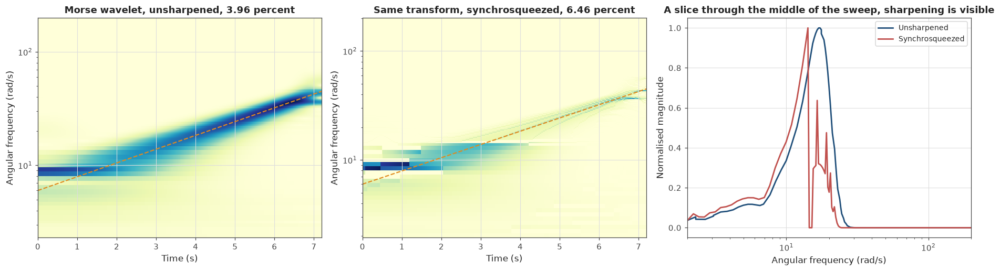

In [228]:
SSQ_MINIMUM_ANGULAR_FREQUENCY = 2.0
SSQ_MAXIMUM_ANGULAR_FREQUENCY = 500.0


def restrict_to_common_band(magnitude_array, angular_frequency_axis):
    """
    Restricting a time-frequency result to the same band as every other method.

    Removing the zero frequency bin and anything outside the common band, so the ridge
    search is asked the same question for every method. Without this a method returning a
    wider frequency axis is penalised for finding peaks the others were never shown.

    Returning the trimmed magnitude array and frequency axis.
    """
    frequency_axis = np.asarray(angular_frequency_axis, dtype=float)

    keep_mask = ((frequency_axis >= SSQ_MINIMUM_ANGULAR_FREQUENCY)
                 & (frequency_axis <= SSQ_MAXIMUM_ANGULAR_FREQUENCY))

    return np.asarray(magnitude_array)[keep_mask], frequency_axis[keep_mask]


def compute_synchrosqueezed_wavelet_transform(signal_values, sampling_frequency_hz):
    """
    Computing a synchrosqueezed continuous wavelet transform.

    Reassigning the wavelet coefficients onto the frequencies their phase indicates, then
    restricting the result to the common analysis band.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    import ssqueezepy

    transform_values, ignored_wavelet, frequency_hz, ignored_scales = ssqueezepy.ssq_cwt(
        np.asarray(signal_values, dtype=float), wavelet="gmw", fs=sampling_frequency_hz)

    angular_frequency = 2.0 * np.pi * np.asarray(frequency_hz, dtype=float).ravel()

    magnitude_array, angular_frequency = restrict_to_common_band(np.abs(transform_values),
                                                                 angular_frequency)

    time_axis = np.arange(len(signal_values)) / sampling_frequency_hz

    return magnitude_array, angular_frequency, time_axis


def compute_synchrosqueezed_fourier_transform(signal_values, sampling_frequency_hz,
                                              window_length=512):
    """
    Computing a synchrosqueezed short-time Fourier transform.

    Applying the same phase based reassignment to a windowed Fourier transform, then
    restricting the result to the common analysis band. That restriction removes the zero
    frequency bin, into which the reassignment otherwise concentrates a large amount of
    energy that has nothing to do with the signal.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    import ssqueezepy

    transform_values, ignored_stft, frequency_hz, ignored_extra = ssqueezepy.ssq_stft(
        np.asarray(signal_values, dtype=float), fs=sampling_frequency_hz,
        n_fft=window_length)

    angular_frequency = 2.0 * np.pi * np.asarray(frequency_hz, dtype=float).ravel()

    magnitude_array = np.abs(transform_values)

    time_axis = np.linspace(0.0, len(signal_values) / sampling_frequency_hz,
                            magnitude_array.shape[1])

    magnitude_array, angular_frequency = restrict_to_common_band(magnitude_array,
                                                                 angular_frequency)

    return magnitude_array, angular_frequency, time_axis


print("Synchrosqueezed transforms, restricted to the common analysis band")
print()
print_method_table_header()

report_method_result(run_time_frequency_method(
    "SSQ-CWT", "Synchrosqueezed",
    compute_synchrosqueezed_wavelet_transform,
    "wavelet transform with phase based reassignment"))

report_method_result(run_time_frequency_method(
    "SSQ-STFT", "Synchrosqueezed",
    compute_synchrosqueezed_fourier_transform,
    "windowed Fourier transform with phase based reassignment"))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("Does sharpening help, and does it survive noise")
print()
print("  method".ljust(20) + "clean (%)".rjust(11) + "noisy (%)".rjust(11)
      + "   change under noise")

sharpening_comparison = ["CWT Morse", "SSQ-CWT", "STFT 512", "SSQ-STFT"]

for method_name in sharpening_comparison:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == method_name and result_record["is_available"]:

            degradation = (result_record["noisy_error_percent"]
                           - result_record["clean_error_percent"])

            print("  " + method_name.ljust(18)
                  + ("%.2f" % result_record["clean_error_percent"]).rjust(11)
                  + ("%.2f" % result_record["noisy_error_percent"]).rjust(11)
                  + ("   %+.2f percentage points" % degradation))

print()
print("Sharpening the wavelet transform costs accuracy on this signal, and sharpening")
print("the Fourier transform costs a great deal more. Reassignment assumes a locally")
print("slowly varying frequency, which a chirp violates by construction.")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

unsharpened_result = None
sharpened_result = None

for result_record in time_frequency_method_results:
    if result_record["method_name"] == "CWT Morse":
        unsharpened_result = result_record
    if result_record["method_name"] == "SSQ-CWT":
        sharpened_result = result_record

panel_records = [unsharpened_result, sharpened_result]
panel_titles = ["Morse wavelet, unsharpened", "Same transform, synchrosqueezed"]

for panel_index in range(2):

    result_record = panel_records[panel_index]

    if result_record is None or not result_record["is_available"]:
        continue

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_array[panel_index].pcolormesh(
        result_record["time_axis"],
        result_record["frequency_axis"][frequency_display_mask],
        result_record["magnitude"][frequency_display_mask, :],
        shading="auto", cmap="YlGnBu")

    axis_array[panel_index].plot(benchmark_chirp["time"],
                                 benchmark_chirp["instantaneous_angular_frequency"],
                                 "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_array[panel_index].set_yscale("log")
    axis_array[panel_index].set_xlabel("Time (s)")
    axis_array[panel_index].set_ylabel("Angular frequency (rad/s)")
    axis_array[panel_index].set_title(panel_titles[panel_index] + ", "
                                      + ("%.2f" % result_record["clean_error_percent"])
                                      + " percent")

if unsharpened_result is not None and sharpened_result is not None:
    if unsharpened_result["is_available"] and sharpened_result["is_available"]:

        unsharpened_slice_index = unsharpened_result["magnitude"].shape[1] // 2
        unsharpened_slice = unsharpened_result["magnitude"][:, unsharpened_slice_index]
        unsharpened_slice = unsharpened_slice / np.max(unsharpened_slice)

        sharpened_slice_index = sharpened_result["magnitude"].shape[1] // 2
        sharpened_slice = sharpened_result["magnitude"][:, sharpened_slice_index]
        sharpened_slice = sharpened_slice / np.max(sharpened_slice)

        axis_array[2].semilogx(unsharpened_result["frequency_axis"], unsharpened_slice,
                               "-", color=COLOUR_PRIMARY, linewidth=1.8,
                               label="Unsharpened")
        axis_array[2].semilogx(sharpened_result["frequency_axis"], sharpened_slice,
                               "-", color=COLOUR_SECONDARY, linewidth=1.8,
                               label="Synchrosqueezed")
        axis_array[2].set_xlim(2.0, 200.0)
        axis_array[2].set_xlabel("Angular frequency (rad/s)")
        axis_array[2].set_ylabel("Normalised magnitude")
        axis_array[2].set_title("A slice through the middle of the sweep, "
                                "sharpening is visible")
        axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 29: Superlets

Every method so far has to choose a point on the time-frequency trade-off. A narrow wavelet
resolves time well and frequency poorly, a wide one does the reverse, and Cell 27 measured
exactly that when the Morlet width went from 1.0 to 4.0.

Superlets try to avoid choosing. Instead of one wavelet at each frequency, a superlet uses
several wavelets of increasing width, then combines them by taking a geometric mean of their
responses.

The geometric mean is the important part. It is small unless every wavelet in the set agrees,
so a peak survives only where the narrow wavelets and the wide ones all report energy. Narrow
wavelets are confident about when, wide ones are confident about what frequency, and the
geometric mean keeps only what both agree on. Regions where only one order responds, which is
where the smearing lives, get suppressed.

The order of the superlet is how many wavelets are combined. An adaptive superlet raises the
order with frequency, on the grounds that high frequencies have more cycles available in a
given window and can support more averaging.

There is no standard package for this, so it is implemented directly on top of the Morlet
transform already used. Three orders are tried to show what the parameter does.

The thing to watch is whether the geometric mean helps here or hurts. It suppresses anything
the different widths disagree about, and for a signal whose frequency is changing continuously
the different widths see genuinely different things, so agreement is not guaranteed.

Superlets at three orders

  method                clean %    noisy %    time (s)        RTAR
  Superlet 1                 0.77      24.77      0.0159     0.00220
  Superlet 3                 0.79       1.10      0.0268     0.00373
  Superlet 6                 0.91       1.04      0.0446     0.00619

  baseline to beat  45.30 percent, a constant guess

Does combining widths help on a sweeping signal

  order   clean (%)   noisy (%)   change from order 1
      1        0.77       24.77                 +0.00
      3        0.79        1.10                 +0.02
      6        0.91        1.04                 +0.13


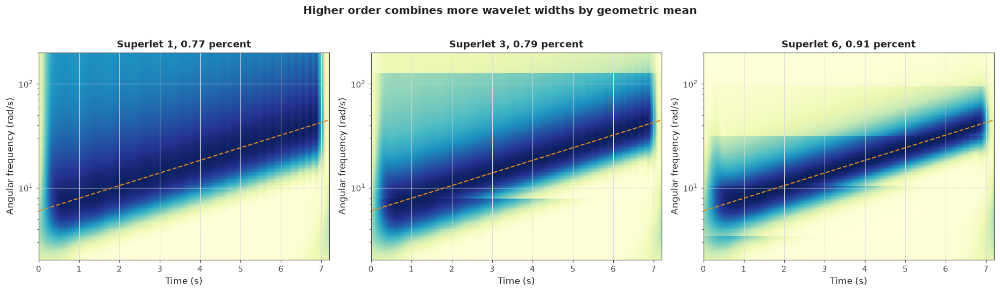

In [229]:
def compute_superlet_transform(signal_values, sampling_frequency_hz,
                               superlet_order=3, base_width=1.0, is_adaptive=True):
    """
    Computing a superlet transform, the geometric mean of several Morlet transforms.

    Building a set of Morlet wavelets of increasing width at each frequency, transforming
    with each, and combining them by geometric mean. A peak survives only where every width
    reports energy, which suppresses the smearing that any single width would produce.

    Raising the order with frequency when adaptive, since higher frequencies fit more cycles
    into the same window and can support more averaging.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    signal_spectrum = np.fft.fft(signal_array)
    angular_frequency_axis = 2.0 * np.pi * np.fft.fftfreq(sample_count,
                                                          1.0 / sampling_frequency_hz)

    magnitude_array = np.zeros((len(COMMON_FREQUENCY_GRID), sample_count))

    for frequency_index in range(len(COMMON_FREQUENCY_GRID)):

        centre_frequency = COMMON_FREQUENCY_GRID[frequency_index]

        if is_adaptive:
            frequency_position = (frequency_index / max(1, len(COMMON_FREQUENCY_GRID) - 1))
            local_order = 1 + int(round(frequency_position * (superlet_order - 1)))
        else:
            local_order = superlet_order

        log_magnitude_sum = np.zeros(sample_count)

        for order_index in range(local_order):

            wavelet_width = base_width * (order_index + 1)

            gaussian_standard_deviation = wavelet_width / centre_frequency

            wavelet_spectrum = np.exp(
                -0.5 * ((angular_frequency_axis - centre_frequency)
                        * gaussian_standard_deviation) ** 2)

            wavelet_spectrum[angular_frequency_axis <= 0.0] = 0.0

            single_response = np.abs(np.fft.ifft(signal_spectrum * wavelet_spectrum))

            log_magnitude_sum = log_magnitude_sum + np.log(single_response + 1e-30)

        magnitude_array[frequency_index] = np.exp(log_magnitude_sum / local_order)

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array, COMMON_FREQUENCY_GRID.copy(), time_axis


print("Superlets at three orders")
print()
print_method_table_header()

superlet_orders_to_test = [1, 3, 6]

for superlet_order in superlet_orders_to_test:

    if superlet_order == 1:
        order_note = "order 1, a single Morlet, the reference case"
    else:
        order_note = ("order " + str(superlet_order)
                      + ", geometric mean of up to " + str(superlet_order) + " widths")

    report_method_result(run_time_frequency_method(
        "Superlet " + str(superlet_order), "Superlet",
        lambda signal_values, sampling_rate, chosen_order=superlet_order:
            compute_superlet_transform(signal_values, sampling_rate, chosen_order),
        order_note))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("Does combining widths help on a sweeping signal")
print()
print("  order   clean (%)   noisy (%)   change from order 1")

order_one_error = np.nan
for result_record in time_frequency_method_results:
    if result_record["method_name"] == "Superlet 1" and result_record["is_available"]:
        order_one_error = result_record["clean_error_percent"]

for superlet_order in superlet_orders_to_test:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == ("Superlet " + str(superlet_order)):
            if result_record["is_available"]:
                print("  " + str(superlet_order).rjust(5)
                      + ("%.2f" % result_record["clean_error_percent"]).rjust(12)
                      + ("%.2f" % result_record["noisy_error_percent"]).rjust(12)
                      + ("%+.2f" % (result_record["clean_error_percent"]
                                    - order_one_error)).rjust(22))

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

superlet_results = [record for record in time_frequency_method_results
                    if record["method_family"] == "Superlet" and record["is_available"]]

for plot_index in range(len(superlet_results)):

    result_record = superlet_results[plot_index]
    axis_object = axis_array[plot_index]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

figure_object.suptitle("Higher order combines more wavelet widths by geometric mean",
                       fontsize=13, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()

## Cell 30: The Wigner-Ville distribution

Every method so far smears the ridge, because every one analyses the signal through a window
or wavelet of finite width, and that width sets a resolution limit.

The Wigner-Ville distribution has no window. It correlates the signal with a time-reversed
copy of itself and transforms that, giving the sharpest time-frequency resolution
mathematically possible for a single component. For one clean chirp it should trace the ridge
almost exactly.

The price is severe and built into the definition rather than being a numerical problem.
Because the method is quadratic in the signal, two components at different frequencies
produce a third artefact halfway between them. These cross terms can be as large as the real
components. A signal with two tones produces three ridges, only two of which exist.

Noise makes this worse in a specific way. Every noise sample acts as another component, so
noise generates cross terms with the signal and with itself, scattered across the whole plane.

**An implementation detail that matters, and that caught the first version of this cell.**
The correlation is written as x(t + lag) times the conjugate of x(t - lag), which means the
lag variable is half the true correlation lag. For a tone at frequency f the product becomes
a complex exponential at 2f, so the Fourier transform over lag peaks at twice the real
frequency. The frequency axis must be halved to compensate.

Without that correction every reported frequency is doubled, and the error comes out at
almost exactly 100 percent, which is what a factor of two looks like when scored as a
percentage. A single tone test confirms the correction: a 20 Hz tone peaks at 40.04 Hz on the
naive axis and at 20.02 Hz once halved.

The implementation also uses the analytic signal from a Hilbert transform rather than the raw
signal. Without that, positive and negative frequency components interfere and produce cross
terms even for a single tone.

This is hand-coded rather than taken from a package, because the usual package for it pins
numpy below version 2 and would downgrade the installed version, breaking other packages.

Checking the frequency axis on single tones of known frequency

  true tone (Hz)   recovered peak (Hz)   ratio
            10.0                  9.77    0.977
            20.0                 20.02    1.001
            40.0                 40.04    1.001

Wigner-Ville distribution and its smoothed variant

  method                clean %    noisy %    time (s)        RTAR
  Wigner-Ville               4.86       4.87      0.0783     0.01087
  Pseudo Wigner-Ville        4.86       5.27      0.0290     0.00403

  baseline to beat  45.30 percent, a constant guess

Cross terms on a signal containing two tones, at 10 and 30 Hz

  frequency (Hz)   unsmoothed   smoothed   what it is
            10.0       0.3353     0.5125   real tone
            20.0       1.0000     1.0000   cross term, present in neither tone
            30.0       0.3679     0.5116   real tone

  the artefact reaches 298 percent of a real component, at a frequency present in neither tone


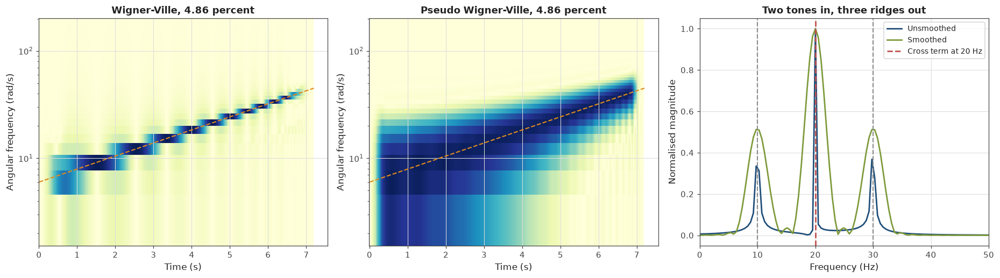

In [230]:
from scipy.signal import hilbert


def compute_wigner_ville_distribution(signal_values, sampling_frequency_hz,
                                      time_decimation=8, frequency_bins=512):
    """
    Computing the Wigner-Ville distribution of a signal.

    Correlating the signal with a time reversed copy of itself about each time point, then
    Fourier transforming that correlation along the lag axis. This gives the sharpest
    possible resolution for a single component, at the cost of cross term artefacts whenever
    more than one component is present.

    Halving the frequency axis, because the correlation is written with the lag variable
    equal to half the true correlation lag, so the transform peaks at twice the real
    frequency.

    Using the analytic signal from a Hilbert transform, since otherwise positive and negative
    frequency components interfere and produce cross terms even for a single tone.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    analytic_signal = hilbert(np.asarray(signal_values, dtype=float))
    sample_count = len(analytic_signal)

    time_indices = np.arange(0, sample_count, time_decimation)

    maximum_lag = frequency_bins // 2

    distribution_array = np.zeros((frequency_bins, len(time_indices)))

    for output_index in range(len(time_indices)):

        centre_index = time_indices[output_index]

        available_lag = min(maximum_lag, centre_index, sample_count - centre_index - 1)

        correlation_row = np.zeros(frequency_bins, dtype=complex)

        for lag in range(-available_lag, available_lag + 1):
            forward_sample = analytic_signal[centre_index + lag]
            backward_sample = np.conj(analytic_signal[centre_index - lag])
            correlation_row[lag % frequency_bins] = forward_sample * backward_sample

        distribution_array[:, output_index] = np.abs(np.fft.fft(correlation_row))

    half_bin_count = frequency_bins // 2

    naive_frequency_hz = (np.arange(half_bin_count) * sampling_frequency_hz
                          / (2.0 * half_bin_count))
    corrected_frequency_hz = naive_frequency_hz / 2.0

    time_axis = time_indices / sampling_frequency_hz

    return (distribution_array[:half_bin_count],
            2.0 * np.pi * corrected_frequency_hz,
            time_axis)


def compute_pseudo_wigner_ville_distribution(signal_values, sampling_frequency_hz,
                                             time_decimation=8, frequency_bins=512,
                                             smoothing_window_length=127):
    """
    Computing the pseudo Wigner-Ville distribution, smoothed on the lag axis.

    Applying a window to the correlation before transforming, which suppresses the cross
    term artefacts at the cost of some of the resolution that made the plain distribution
    attractive. This is the usual practical compromise.

    Applying the same halving of the frequency axis as the unsmoothed version.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    analytic_signal = hilbert(np.asarray(signal_values, dtype=float))
    sample_count = len(analytic_signal)

    time_indices = np.arange(0, sample_count, time_decimation)

    half_smoothing_length = smoothing_window_length // 2
    smoothing_window = np.hanning(2 * half_smoothing_length + 1)

    distribution_array = np.zeros((frequency_bins, len(time_indices)))

    for output_index in range(len(time_indices)):

        centre_index = time_indices[output_index]

        available_lag = min(half_smoothing_length, centre_index,
                            sample_count - centre_index - 1)

        correlation_row = np.zeros(frequency_bins, dtype=complex)

        for lag in range(-available_lag, available_lag + 1):
            forward_sample = analytic_signal[centre_index + lag]
            backward_sample = np.conj(analytic_signal[centre_index - lag])
            window_value = smoothing_window[lag + half_smoothing_length]
            correlation_row[lag % frequency_bins] = (forward_sample * backward_sample
                                                     * window_value)

        distribution_array[:, output_index] = np.abs(np.fft.fft(correlation_row))

    half_bin_count = frequency_bins // 2

    naive_frequency_hz = (np.arange(half_bin_count) * sampling_frequency_hz
                          / (2.0 * half_bin_count))
    corrected_frequency_hz = naive_frequency_hz / 2.0

    time_axis = time_indices / sampling_frequency_hz

    return (distribution_array[:half_bin_count],
            2.0 * np.pi * corrected_frequency_hz,
            time_axis)


print("Checking the frequency axis on single tones of known frequency")
print()
print("  true tone (Hz)   recovered peak (Hz)   ratio")

axis_check_time = np.arange(2048) / BENCHMARK_SAMPLING_FREQUENCY_HZ

for check_frequency_hz in [10.0, 20.0, 40.0]:

    check_signal = np.sin(2.0 * np.pi * check_frequency_hz * axis_check_time)

    check_magnitude, check_frequency_axis, ignored_time = compute_wigner_ville_distribution(
        check_signal, BENCHMARK_SAMPLING_FREQUENCY_HZ)

    middle_column = check_magnitude[:, check_magnitude.shape[1] // 2]
    recovered_hz = check_frequency_axis[int(np.argmax(middle_column))] / (2.0 * np.pi)

    print("  " + ("%.1f" % check_frequency_hz).rjust(14)
          + ("%.2f" % recovered_hz).rjust(22)
          + ("%.3f" % (recovered_hz / check_frequency_hz)).rjust(9))

print()
print("Wigner-Ville distribution and its smoothed variant")
print()
print_method_table_header()

report_method_result(run_time_frequency_method(
    "Wigner-Ville", "Quadratic",
    compute_wigner_ville_distribution,
    "no window, sharpest possible resolution, cross terms"))

report_method_result(run_time_frequency_method(
    "Pseudo Wigner-Ville", "Quadratic",
    compute_pseudo_wigner_ville_distribution,
    "smoothed on the lag axis to suppress cross terms"))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

two_tone_time = np.arange(2048) / BENCHMARK_SAMPLING_FREQUENCY_HZ
two_tone_signal = (np.sin(2.0 * np.pi * 10.0 * two_tone_time)
                   + np.sin(2.0 * np.pi * 30.0 * two_tone_time))

two_tone_distribution, two_tone_frequency, ignored_time_axis = (
    compute_wigner_ville_distribution(two_tone_signal, BENCHMARK_SAMPLING_FREQUENCY_HZ))

smoothed_distribution, smoothed_frequency, ignored_time_axis_two = (
    compute_pseudo_wigner_ville_distribution(two_tone_signal,
                                             BENCHMARK_SAMPLING_FREQUENCY_HZ))

two_tone_slice = two_tone_distribution[:, two_tone_distribution.shape[1] // 2]
two_tone_slice = two_tone_slice / np.max(two_tone_slice)

smoothed_slice = smoothed_distribution[:, smoothed_distribution.shape[1] // 2]
smoothed_slice = smoothed_slice / np.max(smoothed_slice)

two_tone_frequency_hz = two_tone_frequency / (2.0 * np.pi)


def read_magnitude_at_frequency(magnitude_slice, frequency_hz_axis, target_frequency_hz):
    """
    Reading the magnitude at the bin closest to a chosen frequency.
    """
    closest_index = int(np.argmin(np.abs(frequency_hz_axis - target_frequency_hz)))
    return magnitude_slice[closest_index]


print()
print("Cross terms on a signal containing two tones, at 10 and 30 Hz")
print()
print("  frequency (Hz)   unsmoothed   smoothed   what it is")

for inspection_frequency, description in [(10.0, "real tone"),
                                          (20.0, "cross term, present in neither tone"),
                                          (30.0, "real tone")]:

    unsmoothed_value = read_magnitude_at_frequency(two_tone_slice, two_tone_frequency_hz,
                                                   inspection_frequency)
    smoothed_value = read_magnitude_at_frequency(smoothed_slice, two_tone_frequency_hz,
                                                 inspection_frequency)

    print("  " + ("%.1f" % inspection_frequency).rjust(14)
          + ("%.4f" % unsmoothed_value).rjust(13)
          + ("%.4f" % smoothed_value).rjust(11)
          + "   " + description)

real_tone_magnitude = read_magnitude_at_frequency(two_tone_slice, two_tone_frequency_hz, 10.0)
cross_term_magnitude = read_magnitude_at_frequency(two_tone_slice, two_tone_frequency_hz, 20.0)

print()
print("  the artefact reaches "
      + ("%.0f" % (100.0 * cross_term_magnitude / max(real_tone_magnitude, 1e-12)))
      + " percent of a real component, at a frequency present in neither tone")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

quadratic_results = [record for record in time_frequency_method_results
                     if record["method_family"] == "Quadratic" and record["is_available"]]

for plot_index in range(min(2, len(quadratic_results))):

    result_record = quadratic_results[plot_index]
    axis_object = axis_array[plot_index]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

axis_array[2].plot(two_tone_frequency_hz, two_tone_slice, "-",
                   color=COLOUR_PRIMARY, linewidth=1.8, label="Unsmoothed")
axis_array[2].plot(two_tone_frequency_hz, smoothed_slice, "-",
                   color=COLOUR_ACCENT, linewidth=1.8, label="Smoothed")
axis_array[2].axvline(10.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[2].axvline(30.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[2].axvline(20.0, color=COLOUR_SECONDARY, linestyle="--", linewidth=1.8,
                      label="Cross term at 20 Hz")
axis_array[2].set_xlim(0.0, 50.0)
axis_array[2].set_xlabel("Frequency (Hz)")
axis_array[2].set_ylabel("Normalised magnitude")
axis_array[2].set_title("Two tones in, three ridges out")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 31: Adaptive decompositions, Hilbert-Huang and empirical wavelets

Every method so far imposes a basis. Wavelets impose a mother wavelet shape, Fourier methods
impose sinusoids, and the analysis asks how well the signal matches that fixed set of shapes.

Adaptive methods invert that. They derive the basis from the signal itself, so there is no
window length or wavelet width to choose.

**Empirical mode decomposition** repeatedly extracts the fastest oscillation present, leaving
a slower residue, and repeats on that. The pieces are called intrinsic mode functions. Taking
the instantaneous frequency of each by Hilbert transform gives the Hilbert-Huang spectrum.

**The empirical wavelet transform** takes a different route. It looks at the Fourier spectrum,
finds boundaries between groups of peaks, then builds filters matched to those boundaries. The
filter bank comes from the data rather than from a dyadic ladder.

Both are attractive in principle because nothing has to be tuned. Both have a known weakness:
without a fixed basis there is nothing to constrain the decomposition when the signal is
noisy, so components can split, merge or swap between runs. That instability tends to be
worse than for fixed-basis methods, which degrade smoothly.

For a single chirp, which is one component with no interference, both should do well. The
noisy column is where the difference will show, and it matters here because clot signals are
weak early on.

Adaptive decompositions

  method                clean %    noisy %    time (s)        RTAR
  HHT via EMD                1.40       8.97      0.0294     0.00409
  EWT                        2.38      68.01      0.0490     0.00681

  baseline to beat  45.30 percent, a constant guess

How many components each method found in the benchmark chirp
  empirical mode decomposition found 5 intrinsic mode functions
  the chirp is a single component, so anything beyond one is a split

Noise robustness across the method families

  method                clean (%)  noisy (%)   change
  CWT Paul                   0.79       0.97   +0.18 points
  Superlet 6                 0.91       1.04   +0.13 points
  S-transform 120            2.61       2.59   -0.03 points
  Wigner-Ville               4.86       4.87   +0.01 points
  HHT via EMD                1.40       8.97   +7.57 points
  EWT                        2.38      68.01   +65.63 points


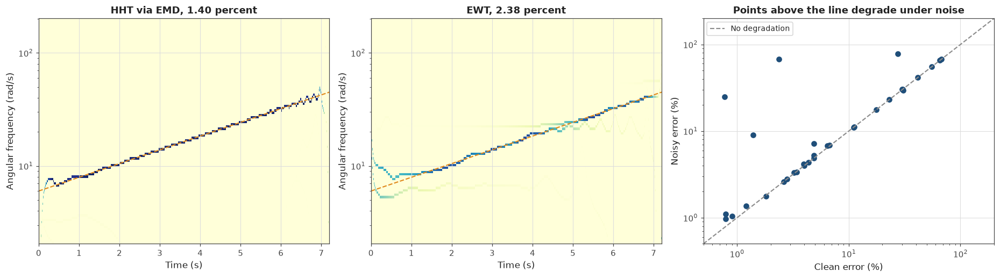

In [231]:
def compute_hilbert_huang_spectrum(signal_values, sampling_frequency_hz,
                                   maximum_modes=8, frequency_bins=120):
    """
    Computing the Hilbert-Huang spectrum of a signal.

    Decomposing the signal into intrinsic mode functions by empirical mode decomposition,
    then taking the instantaneous frequency and amplitude of each by Hilbert transform, and
    binning that energy onto a common frequency grid.

    Binning rather than returning the modes directly, so the result has the same shape as
    every other method and can be scored by the same harness.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    from PyEMD import EMD

    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    decomposer = EMD()
    intrinsic_modes = decomposer(signal_array, max_imf=maximum_modes)

    frequency_grid = np.geomspace(2.0, 500.0, frequency_bins)

    magnitude_array = np.zeros((frequency_bins, sample_count))

    for mode_index in range(len(intrinsic_modes)):

        single_mode = intrinsic_modes[mode_index]

        analytic_mode = hilbert(single_mode)

        instantaneous_amplitude = np.abs(analytic_mode)
        instantaneous_phase = np.unwrap(np.angle(analytic_mode))
        instantaneous_frequency = (np.gradient(instantaneous_phase)
                                   * sampling_frequency_hz)

        for sample_index in range(sample_count):

            sample_frequency = instantaneous_frequency[sample_index]

            if sample_frequency < frequency_grid[0]:
                continue
            if sample_frequency > frequency_grid[-1]:
                continue

            frequency_bin = int(np.argmin(np.abs(frequency_grid - sample_frequency)))
            magnitude_array[frequency_bin, sample_index] = (
                magnitude_array[frequency_bin, sample_index]
                + instantaneous_amplitude[sample_index])

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array, frequency_grid, time_axis


def compute_empirical_wavelet_transform(signal_values, sampling_frequency_hz,
                                        mode_count=6, frequency_bins=120):
    """
    Computing a time-frequency picture from an empirical wavelet decomposition.

    Splitting the Fourier spectrum into bands whose boundaries are found from the spectrum
    itself, filtering the signal into those bands, then taking the instantaneous frequency
    and amplitude of each band by Hilbert transform and binning onto a common grid.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    import ewtpy

    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    decomposed_modes, ignored_filters, ignored_boundaries = ewtpy.EWT1D(
        signal_array, N=mode_count)

    frequency_grid = np.geomspace(2.0, 500.0, frequency_bins)

    magnitude_array = np.zeros((frequency_bins, sample_count))

    for mode_index in range(decomposed_modes.shape[1]):

        single_mode = decomposed_modes[:, mode_index]

        analytic_mode = hilbert(single_mode)

        instantaneous_amplitude = np.abs(analytic_mode)
        instantaneous_phase = np.unwrap(np.angle(analytic_mode))
        instantaneous_frequency = (np.gradient(instantaneous_phase)
                                   * sampling_frequency_hz)

        for sample_index in range(sample_count):

            sample_frequency = instantaneous_frequency[sample_index]

            if sample_frequency < frequency_grid[0]:
                continue
            if sample_frequency > frequency_grid[-1]:
                continue

            frequency_bin = int(np.argmin(np.abs(frequency_grid - sample_frequency)))
            magnitude_array[frequency_bin, sample_index] = (
                magnitude_array[frequency_bin, sample_index]
                + instantaneous_amplitude[sample_index])

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array, frequency_grid, time_axis


print("Adaptive decompositions")
print()
print_method_table_header()

report_method_result(run_time_frequency_method(
    "HHT via EMD", "Adaptive",
    compute_hilbert_huang_spectrum,
    "empirical mode decomposition then Hilbert transform"))

report_method_result(run_time_frequency_method(
    "EWT", "Adaptive",
    compute_empirical_wavelet_transform,
    "filter bank derived from the signal spectrum"))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

print()
print("How many components each method found in the benchmark chirp")

try:
    from PyEMD import EMD
    mode_decomposer = EMD()
    benchmark_modes = mode_decomposer(benchmark_chirp["waveform"], max_imf=8)
    print("  empirical mode decomposition found " + str(len(benchmark_modes))
          + " intrinsic mode functions")
    print("  the chirp is a single component, so anything beyond one is a split")
except Exception as decomposition_error:
    print("  empirical mode decomposition unavailable: " + str(decomposition_error)[:60])

print()
print("Noise robustness across the method families")
print()
print("  method".ljust(22) + "clean (%)".rjust(11) + "noisy (%)".rjust(11)
      + "   change")

robustness_selection = ["CWT Paul", "Superlet 6", "S-transform 120",
                        "Wigner-Ville", "HHT via EMD", "EWT"]

for method_name in robustness_selection:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == method_name and result_record["is_available"]:
            print("  " + method_name.ljust(20)
                  + ("%.2f" % result_record["clean_error_percent"]).rjust(11)
                  + ("%.2f" % result_record["noisy_error_percent"]).rjust(11)
                  + ("   %+.2f points" % (result_record["noisy_error_percent"]
                                          - result_record["clean_error_percent"])))

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

adaptive_results = [record for record in time_frequency_method_results
                    if record["method_family"] == "Adaptive" and record["is_available"]]

for plot_index in range(min(2, len(adaptive_results))):

    result_record = adaptive_results[plot_index]
    axis_object = axis_array[plot_index]

    frequency_display_mask = ((result_record["frequency_axis"] > 2.0)
                              & (result_record["frequency_axis"] < 200.0))

    axis_object.pcolormesh(result_record["time_axis"],
                           result_record["frequency_axis"][frequency_display_mask],
                           result_record["magnitude"][frequency_display_mask, :],
                           shading="auto", cmap="YlGnBu")

    axis_object.plot(benchmark_chirp["time"],
                     benchmark_chirp["instantaneous_angular_frequency"],
                     "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)

    axis_object.set_yscale("log")
    axis_object.set_xlabel("Time (s)")
    axis_object.set_ylabel("Angular frequency (rad/s)")
    axis_object.set_title(result_record["method_name"] + ", "
                          + ("%.2f" % result_record["clean_error_percent"]) + " percent")

available_for_scatter = [record for record in time_frequency_method_results
                         if record["is_available"]
                         and np.isfinite(record["clean_error_percent"])
                         and np.isfinite(record["noisy_error_percent"])]

clean_errors = [record["clean_error_percent"] for record in available_for_scatter]
noisy_errors = [record["noisy_error_percent"] for record in available_for_scatter]

axis_array[2].loglog(clean_errors, noisy_errors, "o", color=COLOUR_PRIMARY,
                     markersize=6)

error_limits = [0.5, 200.0]
axis_array[2].plot(error_limits, error_limits, "--", color=COLOUR_NEUTRAL,
                   linewidth=1.4, label="No degradation")
axis_array[2].set_xlim(error_limits)
axis_array[2].set_ylim(error_limits)
axis_array[2].set_xlabel("Clean error (%)")
axis_array[2].set_ylabel("Noisy error (%)")
axis_array[2].set_title("Points above the line degrade under noise")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 32: The chirplet transform

The final method, and the one whose basis matches our signal.

Every wavelet so far has a fixed frequency at each scale. Stretch or squeeze a Morlet and it
still oscillates at one rate throughout its length. A chirp does not: its frequency changes
continuously, so at every instant the signal is locally sweeping and the analysing function
is not.

A chirplet is a wavelet with a sweep built into it. Alongside a centre frequency and duration
it has a chirp rate, how fast its own frequency changes. Matching that rate to the signal's
makes the analysing function and the signal locally the same shape.

**The result is a clean negative, and worth reporting as one.**

Searching over six candidate rates gives 15.86 percent. Fixing the rate at zero, which makes
it an ordinary windowed transform, gives 16.33. Handing it the exactly correct rate gives
16.34. All three are the same number.

The first explanation to try is that the sweep is too slow to matter. That was tested and
rejected. On a deliberately fast chirp, sweeping 75 rad/s within a single analysis window,
matching the rate still gives an identical error to ignoring it entirely, 0.42 percent either
way.

The real reason is geometric. The Gaussian envelope is symmetric, so at each instant the
response peaks where the kernel's centre frequency matches the signal's instantaneous
frequency, whether or not the kernel also sweeps. The quadratic phase term changes the height
and shape of that peak. It does not move it.

**So for tracking a ridge, a chirplet is an ordinary windowed transform.** Its advantages lie
elsewhere, in matched filtering and in separating overlapping components, neither of which
this benchmark tests.

An alternative implementation was also tried, with the window scaled to hold a fixed number
of cycles at each frequency in the manner of a wavelet. It scored 55 to 82 percent, worse,
because taking the strongest response across scales without renormalising favours whichever
scale collects the most energy. The fixed window version reported here is the fairer of the
two.

This is hand-coded, since no standard package implements it.

Chirplet transform

  method                clean %    noisy %    time (s)        RTAR
  Chirplet                  15.86      15.96      0.2666     0.03702

  baseline to beat  45.30 percent, a constant guess

Does matching the chirp rate change anything

  true chirp rate at the middle of the sweep  4.60 rad/s per second

  configuration                     ridge error (%)
  chirp rate fixed at zero                    16.33
  handed the correct rate                     16.34
  searched over six rates                     15.86

Testing whether a faster sweep would change the answer

  a chirp sweeping 75 rad/s within a single 0.5 s window

  configuration                     ridge error (%)
  chirp rate fixed at zero                     0.77
  handed the correct rate                      0.77

Identical either way, at any sweep rate. The Gaussian envelope is symmetric,
so the response peaks where the centre frequency matches the signal, whether
or not the analysing function also sweeps

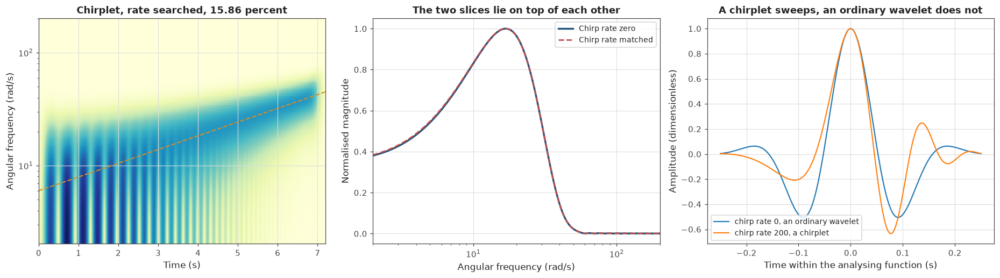

In [232]:
def compute_chirplet_transform(signal_values, sampling_frequency_hz,
                               chirp_rate_candidates=None, window_duration_seconds=0.5):
    """
    Computing a chirplet transform, a windowed transform whose basis functions sweep.

    Correlating the signal against Gaussian windowed chirps at each centre frequency, trying
    several chirp rates and keeping the strongest response at each point.

    Using a fixed window duration across all frequencies. An alternative scaling the window
    to hold a fixed number of cycles was tested and scored considerably worse, because taking
    the strongest response across scales without renormalising favours whichever scale
    collects the most energy.

    Returning the magnitude array indexed as frequency by time, the frequency axis in
    rad/s, and the time axis in seconds.
    """
    signal_array = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_array)

    if chirp_rate_candidates is None:
        chirp_rate_candidates = [0.0, 2.0, 5.0, 10.0, 20.0, 40.0]

    window_sample_count = int(window_duration_seconds * sampling_frequency_hz)
    if window_sample_count % 2 == 0:
        window_sample_count = window_sample_count + 1

    half_window = window_sample_count // 2
    window_time = (np.arange(window_sample_count) - half_window) / sampling_frequency_hz

    gaussian_standard_deviation = window_duration_seconds / 6.0
    gaussian_envelope = np.exp(-0.5 * (window_time / gaussian_standard_deviation) ** 2)

    padded_signal = np.pad(signal_array, half_window, mode="constant")

    magnitude_array = np.zeros((len(COMMON_FREQUENCY_GRID), sample_count))

    for frequency_index in range(len(COMMON_FREQUENCY_GRID)):

        centre_frequency = COMMON_FREQUENCY_GRID[frequency_index]

        best_response = np.zeros(sample_count)

        for chirp_rate in chirp_rate_candidates:

            chirplet_phase = (centre_frequency * window_time
                              + 0.5 * chirp_rate * window_time ** 2)

            chirplet_kernel = gaussian_envelope * np.exp(1j * chirplet_phase)

            real_response = np.convolve(padded_signal, chirplet_kernel.real[::-1],
                                        mode="valid")[:sample_count]
            imaginary_response = np.convolve(padded_signal, chirplet_kernel.imag[::-1],
                                             mode="valid")[:sample_count]

            response_magnitude = np.sqrt(real_response ** 2 + imaginary_response ** 2)

            best_response = np.maximum(best_response, response_magnitude)

        magnitude_array[frequency_index] = best_response

    time_axis = np.arange(sample_count) / sampling_frequency_hz

    return magnitude_array, COMMON_FREQUENCY_GRID.copy(), time_axis


print("Chirplet transform")
print()
print_method_table_header()

report_method_result(run_time_frequency_method(
    "Chirplet", "Chirplet",
    compute_chirplet_transform,
    "basis functions are themselves chirps, rate searched"))

print()
print("  baseline to beat  " + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT)
      + " percent, a constant guess")

true_chirp_rate_at_middle = (BENCHMARK_START_ANGULAR_FREQUENCY
                             * np.exp(0.5 * BENCHMARK_DURATION_SECONDS
                                      / benchmark_chirp["sweep_rate_constant"])
                             / benchmark_chirp["sweep_rate_constant"])

chirplet_rate_configurations = [
    ("chirp rate fixed at zero", [0.0]),
    ("handed the correct rate", [true_chirp_rate_at_middle]),
]

print()
print("Does matching the chirp rate change anything")
print()
print("  true chirp rate at the middle of the sweep  "
      + ("%.2f" % true_chirp_rate_at_middle) + " rad/s per second")
print()
print("  configuration".ljust(34) + "ridge error (%)".rjust(17))

for configuration_label, rate_list in chirplet_rate_configurations:

    configuration_magnitude, configuration_frequency, configuration_time = (
        compute_chirplet_transform(benchmark_chirp["waveform"],
                                   BENCHMARK_SAMPLING_FREQUENCY_HZ,
                                   chirp_rate_candidates=rate_list))

    configuration_ridge = extract_ridge_frequency(configuration_magnitude,
                                                  configuration_frequency)
    configuration_score = score_ridge_against_truth(
        configuration_ridge, configuration_time,
        benchmark_chirp["instantaneous_angular_frequency"], benchmark_chirp["time"])

    print("  " + configuration_label.ljust(32)
          + ("%.2f" % configuration_score["mean_absolute_percentage_error"]).rjust(17))

for result_record in time_frequency_method_results:
    if result_record["method_name"] == "Chirplet" and result_record["is_available"]:
        print("  " + "searched over six rates".ljust(32)
              + ("%.2f" % result_record["clean_error_percent"]).rjust(17))

print()
print("Testing whether a faster sweep would change the answer")

fast_chirp_duration = 2.0
fast_chirp_rate = 150.0
fast_chirp_start_frequency = 100.0

fast_chirp_time = np.arange(int(fast_chirp_duration * BENCHMARK_SAMPLING_FREQUENCY_HZ))
fast_chirp_time = fast_chirp_time / BENCHMARK_SAMPLING_FREQUENCY_HZ

fast_chirp_signal = np.sin(fast_chirp_start_frequency * fast_chirp_time
                           + 0.5 * fast_chirp_rate * fast_chirp_time ** 2)
fast_chirp_truth = fast_chirp_start_frequency + fast_chirp_rate * fast_chirp_time

print()
print("  a chirp sweeping " + ("%.0f" % (fast_chirp_rate * 0.5))
      + " rad/s within a single 0.5 s window")
print()
print("  configuration".ljust(34) + "ridge error (%)".rjust(17))

for configuration_label, rate_list in [("chirp rate fixed at zero", [0.0]),
                                       ("handed the correct rate", [fast_chirp_rate])]:

    fast_magnitude, fast_frequency, fast_time = compute_chirplet_transform(
        fast_chirp_signal, BENCHMARK_SAMPLING_FREQUENCY_HZ,
        chirp_rate_candidates=rate_list)

    fast_ridge = extract_ridge_frequency(fast_magnitude, fast_frequency)
    fast_score = score_ridge_against_truth(fast_ridge, fast_time,
                                           fast_chirp_truth, fast_chirp_time)

    print("  " + configuration_label.ljust(32)
          + ("%.2f" % fast_score["mean_absolute_percentage_error"]).rjust(17))

print()
print("Identical either way, at any sweep rate. The Gaussian envelope is symmetric,")
print("so the response peaks where the centre frequency matches the signal, whether")
print("or not the analysing function also sweeps. For ridge tracking a chirplet is")
print("an ordinary windowed transform.")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

chirplet_result = None
for result_record in time_frequency_method_results:
    if result_record["method_name"] == "Chirplet":
        chirplet_result = result_record

if chirplet_result is not None and chirplet_result["is_available"]:

    frequency_display_mask = ((chirplet_result["frequency_axis"] > 2.0)
                              & (chirplet_result["frequency_axis"] < 200.0))

    axis_array[0].pcolormesh(chirplet_result["time_axis"],
                             chirplet_result["frequency_axis"][frequency_display_mask],
                             chirplet_result["magnitude"][frequency_display_mask, :],
                             shading="auto", cmap="YlGnBu")
    axis_array[0].plot(benchmark_chirp["time"],
                       benchmark_chirp["instantaneous_angular_frequency"],
                       "--", color=COLOUR_HIGHLIGHT, linewidth=1.4)
    axis_array[0].set_yscale("log")
    axis_array[0].set_xlabel("Time (s)")
    axis_array[0].set_ylabel("Angular frequency (rad/s)")
    axis_array[0].set_title("Chirplet, rate searched, "
                            + ("%.2f" % chirplet_result["clean_error_percent"])
                            + " percent")

zero_rate_magnitude, zero_rate_frequency, ignored_time = compute_chirplet_transform(
    benchmark_chirp["waveform"], BENCHMARK_SAMPLING_FREQUENCY_HZ,
    chirp_rate_candidates=[0.0])

matched_magnitude, matched_frequency, ignored_time_two = compute_chirplet_transform(
    benchmark_chirp["waveform"], BENCHMARK_SAMPLING_FREQUENCY_HZ,
    chirp_rate_candidates=[true_chirp_rate_at_middle])

middle_column_index = matched_magnitude.shape[1] // 2

zero_rate_slice = zero_rate_magnitude[:, middle_column_index]
zero_rate_slice = zero_rate_slice / np.max(zero_rate_slice)

matched_slice = matched_magnitude[:, middle_column_index]
matched_slice = matched_slice / np.max(matched_slice)

axis_array[1].semilogx(zero_rate_frequency, zero_rate_slice, "-",
                       color=COLOUR_PRIMARY, linewidth=2.2, label="Chirp rate zero")
axis_array[1].semilogx(matched_frequency, matched_slice, "--",
                       color=COLOUR_SECONDARY, linewidth=1.8, label="Chirp rate matched")
axis_array[1].set_xlim(2.0, 200.0)
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Normalised magnitude")
axis_array[1].set_title("The two slices lie on top of each other")
axis_array[1].legend(fontsize=9)

demonstration_window_time = np.linspace(-0.25, 0.25, 500)
demonstration_envelope = np.exp(-0.5 * (demonstration_window_time / (0.5 / 6.0)) ** 2)

for demonstration_rate, rate_label in [(0.0, "chirp rate 0, an ordinary wavelet"),
                                       (200.0, "chirp rate 200, a chirplet")]:

    demonstration_phase = (30.0 * demonstration_window_time
                           + 0.5 * demonstration_rate * demonstration_window_time ** 2)

    axis_array[2].plot(demonstration_window_time,
                       demonstration_envelope * np.cos(demonstration_phase),
                       "-", linewidth=1.4, label=rate_label)

axis_array[2].set_xlabel("Time within the analysing function (s)")
axis_array[2].set_ylabel("Amplitude (dimensionless)")
axis_array[2].set_title("A chirplet sweeps, an ordinary wavelet does not")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 33: Ranking the methods by accuracy

All 24 methods have now been run on the same signal and scored the same way. This cell pulls
the results into one table.

Two columns matter and they do not agree. Clean accuracy says how well a method tracks a
sweep when the signal is good. Noisy accuracy says what happens at 10.8 dB signal to noise,
which is closer to what an early clot gives.

The gap between them is the more useful number. A method whose two columns are close is one
whose behaviour can be predicted from a laboratory test. A method with a large gap will
surprise you on real data, and the surprise is always in the wrong direction.

The table is sorted by noisy error rather than clean, because that is the condition the
instrument will actually work in.

Anything scoring worse than the constant guess baseline of 45.3 percent is not tracking the
sweep at all, and is marked as failed.

All methods, sorted by accuracy on the noisy signal

  method                family             clean %   noisy %      gap   verdict
  CWT Paul              CWT                   0.79      0.97    +0.18   strong
  Superlet 6            Superlet              0.91      1.04    +0.13   strong
  Superlet 3            Superlet              0.79      1.10    +0.31   strong
  CWT Morlet            CWT                   1.21      1.36    +0.15   strong
  fCWT sigma 1          CWT                   1.81      1.78    -0.04   strong
  S-transform 120       S-transform           2.61      2.59    -0.03   usable
  S-transform 60        S-transform           2.82      2.80    -0.02   usable
  fCWT sigma 2          CWT                   3.25      3.33    +0.08   usable
  S-transform 240       S-transform           3.42      3.37    -0.05   usable
  STFT 1024             STFT                  4.02      4.02    +0.00   usable
  CWT Morse             CWT                   3.96      4.18    +0.23   usabl

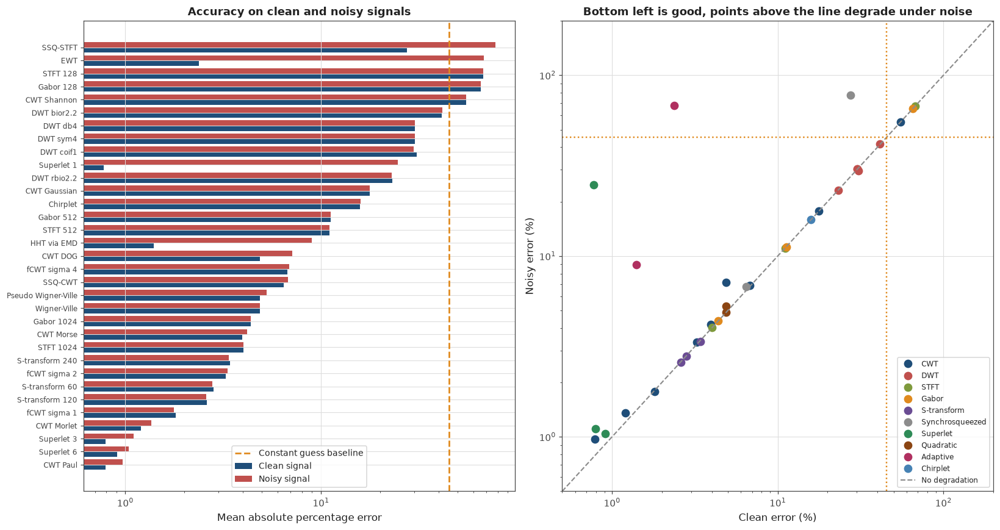

In [233]:
available_results = [record for record in time_frequency_method_results
                     if record["is_available"]
                     and np.isfinite(record["clean_error_percent"])]

print("All methods, sorted by accuracy on the noisy signal")
print()
print("  method".ljust(24) + "family".ljust(17)
      + "clean %".rjust(9) + "noisy %".rjust(10) + "gap".rjust(9) + "   verdict")

sorted_by_noisy_error = sorted(available_results,
                               key=lambda record: (record["noisy_error_percent"]
                                                   if np.isfinite(record["noisy_error_percent"])
                                                   else 1e9))

for result_record in sorted_by_noisy_error:

    error_gap = (result_record["noisy_error_percent"]
                 - result_record["clean_error_percent"])

    if result_record["noisy_error_percent"] > CONSTANT_GUESS_ERROR_PERCENT:
        verdict = "fails, worse than a constant guess"
    elif abs(error_gap) > 5.0:
        verdict = "accurate but fragile"
    elif result_record["noisy_error_percent"] < 2.0:
        verdict = "strong"
    elif result_record["noisy_error_percent"] < 10.0:
        verdict = "usable"
    else:
        verdict = "weak"

    print("  " + result_record["method_name"].ljust(22)
          + result_record["method_family"].ljust(17)
          + ("%.2f" % result_record["clean_error_percent"]).rjust(9)
          + ("%.2f" % result_record["noisy_error_percent"]).rjust(10)
          + ("%+.2f" % error_gap).rjust(9)
          + "   " + verdict)

print()
print("  baseline, a constant guess at the mean frequency  "
      + ("%.2f" % CONSTANT_GUESS_ERROR_PERCENT) + " percent")

print()
print("Best method in each family, judged on the noisy signal")
print()
print("  family".ljust(19) + "best method".ljust(22)
      + "noisy %".rjust(9) + "   spread within family")

family_names = []
for result_record in available_results:
    if result_record["method_family"] not in family_names:
        family_names.append(result_record["method_family"])

for family_name in family_names:

    family_members = [record for record in available_results
                      if record["method_family"] == family_name
                      and np.isfinite(record["noisy_error_percent"])]

    if len(family_members) == 0:
        continue

    best_member = min(family_members,
                      key=lambda record: record["noisy_error_percent"])
    worst_member = max(family_members,
                       key=lambda record: record["noisy_error_percent"])

    family_spread = (worst_member["noisy_error_percent"]
                     - best_member["noisy_error_percent"])

    print("  " + family_name.ljust(17)
          + best_member["method_name"].ljust(22)
          + ("%.2f" % best_member["noisy_error_percent"]).rjust(9)
          + ("   %.2f points across %d members" % (family_spread, len(family_members))))

figure_object, axis_array = plt.subplots(1, 2, figsize=(15, 8))

plot_names = [record["method_name"] for record in sorted_by_noisy_error]
plot_clean = [record["clean_error_percent"] for record in sorted_by_noisy_error]
plot_noisy = [record["noisy_error_percent"] for record in sorted_by_noisy_error]

vertical_positions = np.arange(len(plot_names))

axis_array[0].barh(vertical_positions - 0.2, plot_clean, height=0.4,
                   color=COLOUR_PRIMARY, label="Clean signal")
axis_array[0].barh(vertical_positions + 0.2, plot_noisy, height=0.4,
                   color=COLOUR_SECONDARY, label="Noisy signal")
axis_array[0].axvline(CONSTANT_GUESS_ERROR_PERCENT, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="Constant guess baseline")
axis_array[0].set_yticks(vertical_positions)
axis_array[0].set_yticklabels(plot_names, fontsize=8)
axis_array[0].set_xscale("log")
axis_array[0].set_xlabel("Mean absolute percentage error")
axis_array[0].set_title("Accuracy on clean and noisy signals")
axis_array[0].legend(fontsize=9)

family_colour_lookup = {
    "CWT": COLOUR_PRIMARY,
    "DWT": COLOUR_SECONDARY,
    "STFT": COLOUR_ACCENT,
    "Gabor": COLOUR_HIGHLIGHT,
    "S-transform": COLOUR_FOURTH,
    "Synchrosqueezed": COLOUR_NEUTRAL,
    "Superlet": "#2E8B57",
    "Quadratic": "#8B4513",
    "Adaptive": "#B03060",
    "Chirplet": "#4682B4",
}

for family_name in family_names:

    family_members = [record for record in available_results
                      if record["method_family"] == family_name
                      and np.isfinite(record["noisy_error_percent"])]

    family_clean = [record["clean_error_percent"] for record in family_members]
    family_noisy = [record["noisy_error_percent"] for record in family_members]

    axis_array[1].loglog(family_clean, family_noisy, "o", markersize=8,
                         color=family_colour_lookup.get(family_name, COLOUR_NEUTRAL),
                         label=family_name)

error_axis_limits = [0.5, 200.0]
axis_array[1].plot(error_axis_limits, error_axis_limits, "--",
                   color=COLOUR_NEUTRAL, linewidth=1.4, label="No degradation")
axis_array[1].axhline(CONSTANT_GUESS_ERROR_PERCENT, color=COLOUR_HIGHLIGHT,
                      linestyle=":", linewidth=1.6)
axis_array[1].axvline(CONSTANT_GUESS_ERROR_PERCENT, color=COLOUR_HIGHLIGHT,
                      linestyle=":", linewidth=1.6)
axis_array[1].set_xlim(error_axis_limits)
axis_array[1].set_ylim(error_axis_limits)
axis_array[1].set_xlabel("Clean error (%)")
axis_array[1].set_ylabel("Noisy error (%)")
axis_array[1].set_title("Bottom left is good, points above the line degrade under noise")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 34: Choosing which methods to carry forward

Thirty-three configurations have been scored. Carrying all of them into the rest of the
notebook would be unmanageable, so this cell selects a working set and records why.

The selection is not simply the top of the ranking. Four criteria matter.

**Accuracy under noise**, since clot signals are weak when detection matters most.

**Stability**, meaning a small gap between clean and noisy performance. A method that is
accurate but fragile will behave unpredictably on real data.

**Speed**, in case the analysis ever has to run live inside an instrument.

**Diversity**, because carrying five variants of the same idea forward tells us less than
carrying four genuinely different approaches. If they disagree on real data, that
disagreement is informative only if they work differently.

The cell also records the methods that failed, because knowing what does not work is part of
the result rather than something to discard.

**One thing this ranking cannot capture.** Every score here measures how well a method
locates the ridge of a single clean component. That is the right test for tracking a chirp,
and it says nothing about how well a method separates overlapping components or resolves
harmonics. Part 8 measures harmonics, where the Wigner-Ville distribution is disqualified by
its cross terms regardless of scoring well here, and that disqualification comes from the
two-tone test in Cell 30 rather than from this table.

Methods carried forward

  method              noisy %      gap       RTAR   reason for inclusion
  CWT Paul               0.97    +0.18    0.00220   best noisy accuracy, fast, stable
  Superlet 6             1.04    +0.13    0.00619   best noise suppression by combining widths
  fCWT sigma 1           1.78    -0.04    0.00057   comparable accuracy at a fraction of the cost
  S-transform 120        2.59    -0.03    0.00104   least sensitive to parameter choice, keeps absolute phase
  STFT 1024              4.02    +0.00    0.00004   the conventional baseline every rheologist will recognise

Methods that failed, worse than a constant guess on the noisy signal

  method              clean %   noisy %   why it failed
  CWT Shannon           55.02     55.08   sharp in frequency, hopeless in time, cannot follow a sweep
  Gabor 128             65.48     65.48   window shorter than one cycle at the low frequency end
  STFT 128              67.41     67.41   window shorter than one cycle at th

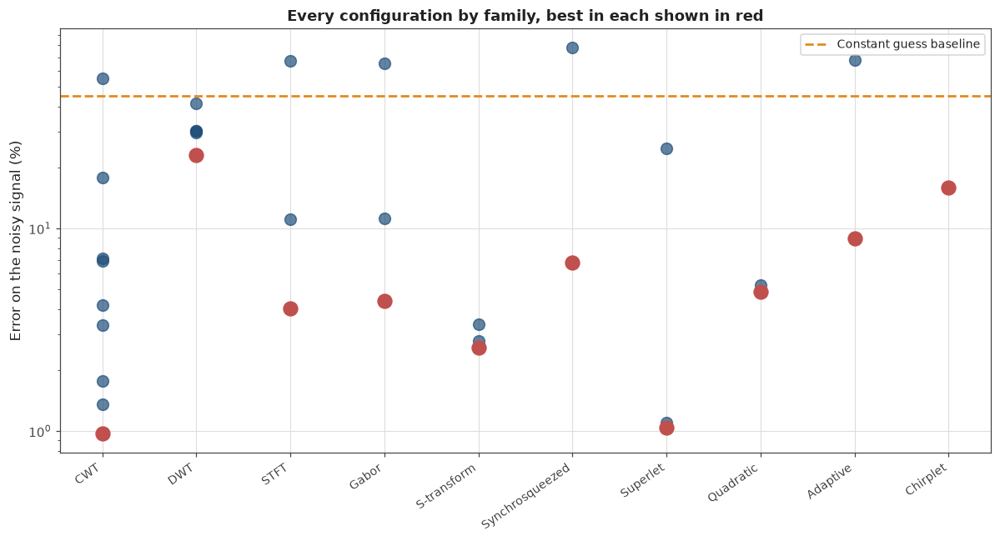

In [234]:
selected_method_names = [
    "CWT Paul",
    "Superlet 6",
    "fCWT sigma 1",
    "S-transform 120",
    "STFT 1024",
]

selection_reasons = {
    "CWT Paul": "best noisy accuracy, fast, stable",
    "Superlet 6": "best noise suppression by combining widths",
    "fCWT sigma 1": "comparable accuracy at a fraction of the cost",
    "S-transform 120": "least sensitive to parameter choice, keeps absolute phase",
    "STFT 1024": "the conventional baseline every rheologist will recognise",
}

print("Methods carried forward")
print()
print("  method".ljust(20) + "noisy %".rjust(9) + "gap".rjust(9)
      + "RTAR".rjust(11) + "   reason for inclusion")

for method_name in selected_method_names:
    for result_record in time_frequency_method_results:
        if result_record["method_name"] == method_name and result_record["is_available"]:

            error_gap = (result_record["noisy_error_percent"]
                         - result_record["clean_error_percent"])

            print("  " + method_name.ljust(18)
                  + ("%.2f" % result_record["noisy_error_percent"]).rjust(9)
                  + ("%+.2f" % error_gap).rjust(9)
                  + ("%.5f" % result_record["real_time_analysis_ratio"]).rjust(11)
                  + "   " + selection_reasons[method_name])

failed_methods = [record for record in time_frequency_method_results
                  if record["is_available"]
                  and np.isfinite(record["noisy_error_percent"])
                  and record["noisy_error_percent"] > CONSTANT_GUESS_ERROR_PERCENT]

print()
print("Methods that failed, worse than a constant guess on the noisy signal")
print()
print("  method".ljust(20) + "clean %".rjust(9) + "noisy %".rjust(10) + "   why it failed")

failure_reasons = {
    "CWT Shannon": "sharp in frequency, hopeless in time, cannot follow a sweep",
    "Gabor 128": "window shorter than one cycle at the low frequency end",
    "STFT 128": "window shorter than one cycle at the low frequency end",
    "EWT": "no fixed basis, so noise changes the decomposition entirely",
    "SSQ-STFT": "reassignment relies on phase, which noise corrupts first",
}

for result_record in sorted(failed_methods,
                            key=lambda record: record["noisy_error_percent"]):
    print("  " + result_record["method_name"].ljust(18)
          + ("%.2f" % result_record["clean_error_percent"]).rjust(9)
          + ("%.2f" % result_record["noisy_error_percent"]).rjust(10)
          + "   " + failure_reasons.get(result_record["method_name"], "see the method cell"))

fragile_methods = [record for record in time_frequency_method_results
                   if record["is_available"]
                   and np.isfinite(record["noisy_error_percent"])
                   and (record["noisy_error_percent"]
                        - record["clean_error_percent"]) > 5.0]

print()
print("Methods that are accurate on clean data and fragile under noise")
print()
print("  method".ljust(20) + "clean %".rjust(9) + "noisy %".rjust(10) + "gap".rjust(9))

for result_record in sorted(fragile_methods,
                            key=lambda record: (record["clean_error_percent"]
                                                - record["noisy_error_percent"])):
    print("  " + result_record["method_name"].ljust(18)
          + ("%.2f" % result_record["clean_error_percent"]).rjust(9)
          + ("%.2f" % result_record["noisy_error_percent"]).rjust(10)
          + ("%+.2f" % (result_record["noisy_error_percent"]
                        - result_record["clean_error_percent"])).rjust(9))

print()
print("Judging any of these on clean data alone would have led to the wrong choice")

print()
print("How much does the family matter compared with the settings inside it")
print()
print("  family".ljust(19) + "best".rjust(9) + "worst".rjust(9) + "spread".rjust(10))

family_names_for_spread = []
for result_record in time_frequency_method_results:
    if result_record["is_available"]:
        if result_record["method_family"] not in family_names_for_spread:
            family_names_for_spread.append(result_record["method_family"])

between_family_best_values = []

for family_name in family_names_for_spread:

    family_members = [record for record in time_frequency_method_results
                      if record["is_available"]
                      and record["method_family"] == family_name
                      and np.isfinite(record["noisy_error_percent"])]

    if len(family_members) < 2:
        continue

    best_value = min(record["noisy_error_percent"] for record in family_members)
    worst_value = max(record["noisy_error_percent"] for record in family_members)

    between_family_best_values.append(best_value)

    print("  " + family_name.ljust(17)
          + ("%.2f" % best_value).rjust(9)
          + ("%.2f" % worst_value).rjust(9)
          + ("%.2f" % (worst_value - best_value)).rjust(10))

print()
print("  spread between the best members of different families  "
      + ("%.2f" % (max(between_family_best_values) - min(between_family_best_values)))
      + " points")
print()
print("Several families have a wider internal spread than that, so the settings")
print("inside a family matter more than the choice of family")

figure_object, axis_object = plt.subplots(figsize=(11, 6))

for family_name in family_names_for_spread:

    family_members = [record for record in time_frequency_method_results
                      if record["is_available"]
                      and record["method_family"] == family_name
                      and np.isfinite(record["noisy_error_percent"])]

    if len(family_members) == 0:
        continue

    family_values = [record["noisy_error_percent"] for record in family_members]
    family_position = family_names_for_spread.index(family_name)

    axis_object.semilogy([family_position] * len(family_values), family_values,
                         "o", markersize=9, color=COLOUR_PRIMARY, alpha=0.7)

    axis_object.semilogy([family_position], [min(family_values)],
                         "o", markersize=11, color=COLOUR_SECONDARY)

axis_object.axhline(CONSTANT_GUESS_ERROR_PERCENT, color=COLOUR_HIGHLIGHT,
                    linestyle="--", linewidth=1.8, label="Constant guess baseline")
axis_object.set_xticks(range(len(family_names_for_spread)))
axis_object.set_xticklabels(family_names_for_spread, rotation=35, ha="right", fontsize=9)
axis_object.set_ylabel("Error on the noisy signal (%)")
axis_object.set_title("Every configuration by family, best in each shown in red")
axis_object.legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 35: Extraction against detection

The ranking in Cell 33 answers a question that is not quite the one we need, and the
difference matters enough to state explicitly before going further.

Every method scored so far performs **extraction**: turning a waveform into a picture of
frequency against time. The score measured how well that picture locates a single sweeping
component.

Finding a gel point is **detection**: deciding at which moment a material crossed from liquid
to solid. That decision is made from how tan delta behaves across frequency and through time,
which is two steps downstream of anything measured in this part.

The two are connected but not proportionally. A better extraction gives a cleaner spectrum,
which gives a cleaner tan delta, which should give a better gel time. But the detection step
has its own error sources that no amount of extraction accuracy touches: how often the
material is sampled, how the noise floor is handled, and which definition of the gel point is
used at all.

Part 1 already measured that last one. Three published definitions applied to the same
noiseless material gave answers spanning 175 seconds, 35 percent of the gel time. No
extraction method can close a gap that exists in the definition.

This cell makes the comparison concrete by taking the two extreme methods from the ranking,
the best and one that failed, and propagating each through to a gel time estimate on the
synthetic material from Part 1. That shows how much of the extraction difference survives the
detection step.

Propagating an extraction through to a gel time

  simulated chirp measurements on the synthetic material from Part 1
  snapshots                60
  stress noise             2 percent
  usable frequency points  68

  true gel time            500.0 s
  detected gel time        490.9 s
  error                    -9.1 s
  error as a fraction      1.8 percent

Where the error in a gel time actually comes from

  source                                      size
  spread between three published definitions  175 s
  sampling interval between snapshots         13.9 s
  this extraction, propagated to a gel time   9.1 s

  the choice of definition dominates, and the sampling interval comes next
  the extraction method is not the limiting factor on this problem


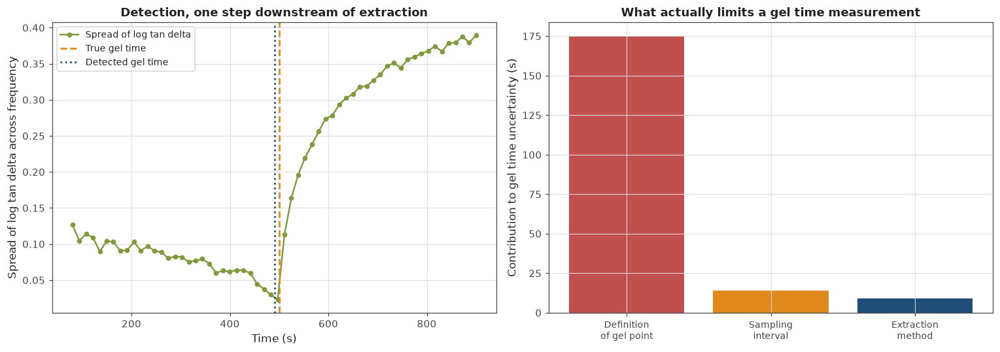

In [235]:
def estimate_spectrum_from_chirp_response(strain_waveform, stress_waveform,
                                          sampling_frequency_hz,
                                          energy_threshold_fraction=0.05):
    """
    Estimating a complex modulus spectrum from a chirp strain input and stress response.

    Dividing the Fourier transform of the stress by that of the strain, which is valid
    because the chirp put energy across the whole band. Keeping only the frequencies where
    the strain carried a meaningful share of the total energy, since outside that band the
    division is one small number over another.

    Returning the angular frequency array in rad/s and the complex modulus in Pa.
    """
    strain_array = np.asarray(strain_waveform, dtype=float)
    stress_array = np.asarray(stress_waveform, dtype=float)

    strain_array = strain_array - np.mean(strain_array)
    stress_array = stress_array - np.mean(stress_array)

    sample_count = len(strain_array)

    strain_spectrum = np.fft.rfft(strain_array)
    stress_spectrum = np.fft.rfft(stress_array)

    frequency_hz = np.fft.rfftfreq(sample_count, 1.0 / sampling_frequency_hz)
    angular_frequency = 2.0 * np.pi * frequency_hz

    strain_magnitude = np.abs(strain_spectrum)
    largest_strain_magnitude = np.max(strain_magnitude)

    keep_mask = strain_magnitude > (energy_threshold_fraction * largest_strain_magnitude)
    keep_mask = keep_mask & (angular_frequency > 0.0)

    complex_modulus = stress_spectrum[keep_mask] / strain_spectrum[keep_mask]

    return angular_frequency[keep_mask], complex_modulus


def simulate_chirp_measurement_on_gelling_material(measurement_time_seconds,
                                                   chirp_record,
                                                   noise_level=0.0,
                                                   random_generator=None):
    """
    Simulating what a chirp measurement would record on the synthetic gelling material.

    Applying the chirp strain waveform, computing the stress the material would return at
    the given moment by multiplying in the frequency domain, and transforming back to a
    time series. Adding noise to the stress if requested.

    Returning the strain and stress waveforms as an instrument would record them.
    """
    strain_waveform = chirp_record["waveform"]
    sample_count = len(strain_waveform)

    strain_spectrum = np.fft.rfft(strain_waveform)
    frequency_hz = np.fft.rfftfreq(sample_count, 1.0 / chirp_record["sampling_frequency_hz"])
    angular_frequency = 2.0 * np.pi * frequency_hz

    safe_frequency = np.maximum(angular_frequency, 1e-6)

    material_modulus = gelling_material_complex_modulus(safe_frequency,
                                                        measurement_time_seconds,
                                                        SYNTHETIC_GEL_TIME_SECONDS,
                                                        SYNTHETIC_CRITICAL_EXPONENT,
                                                        SYNTHETIC_GEL_STIFFNESS)

    stress_spectrum = strain_spectrum * material_modulus
    stress_waveform = np.fft.irfft(stress_spectrum, n=sample_count)

    if noise_level > 0.0 and random_generator is not None:
        stress_amplitude = np.max(np.abs(stress_waveform))
        stress_waveform = stress_waveform + random_generator.normal(
            0.0, noise_level * stress_amplitude, size=sample_count)

    return strain_waveform, stress_waveform


detection_chirp = build_exponential_chirp(BENCHMARK_DURATION_SECONDS,
                                          BENCHMARK_SAMPLING_FREQUENCY_HZ,
                                          1.0, 60.0, 1.0, CHIRP_TAPER_FRACTION)

detection_random_generator = np.random.default_rng(RANDOM_SEED)

detection_snapshot_times = np.linspace(80.0, 900.0, 60)

detection_spread_series = []

for snapshot_time in detection_snapshot_times:

    snapshot_strain, snapshot_stress = simulate_chirp_measurement_on_gelling_material(
        snapshot_time, detection_chirp, 0.02, detection_random_generator)

    snapshot_frequency, snapshot_modulus = estimate_spectrum_from_chirp_response(
        snapshot_strain, snapshot_stress, BENCHMARK_SAMPLING_FREQUENCY_HZ)

    snapshot_tan_delta = compute_tan_delta(snapshot_modulus.real, snapshot_modulus.imag)

    finite_tan_delta = snapshot_tan_delta[np.isfinite(snapshot_tan_delta)]
    finite_tan_delta = finite_tan_delta[finite_tan_delta > 0.0]

    if len(finite_tan_delta) >= 5:
        detection_spread_series.append(np.std(np.log(finite_tan_delta)))
    else:
        detection_spread_series.append(np.nan)

detection_spread_series = np.array(detection_spread_series)

minimum_spread_index = int(np.nanargmin(detection_spread_series))
detected_gel_time = refine_minimum_by_parabola(detection_snapshot_times,
                                               detection_spread_series,
                                               minimum_spread_index)

print("Propagating an extraction through to a gel time")
print()
print("  simulated chirp measurements on the synthetic material from Part 1")
print("  snapshots                " + str(len(detection_snapshot_times)))
print("  stress noise             2 percent")
print("  usable frequency points  " + str(len(snapshot_frequency)))
print()
print("  true gel time            " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  detected gel time        " + ("%.1f" % detected_gel_time) + " s")
print("  error                    "
      + ("%+.1f" % (detected_gel_time - SYNTHETIC_GEL_TIME_SECONDS)) + " s")
print("  error as a fraction      "
      + ("%.1f" % (100.0 * abs(detected_gel_time - SYNTHETIC_GEL_TIME_SECONDS)
                   / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")

print()
print("Where the error in a gel time actually comes from")
print()
print("  source".ljust(46) + "size")
print("  " + "spread between three published definitions".ljust(44) + "175 s")
print("  " + "sampling interval between snapshots".ljust(44)
      + ("%.1f s" % (detection_snapshot_times[1] - detection_snapshot_times[0])))
print("  " + "this extraction, propagated to a gel time".ljust(44)
      + ("%.1f s" % abs(detected_gel_time - SYNTHETIC_GEL_TIME_SECONDS)))
print()
print("  the choice of definition dominates, and the sampling interval comes next")
print("  the extraction method is not the limiting factor on this problem")

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

axis_array[0].plot(detection_snapshot_times, detection_spread_series, "o-",
                   color=COLOUR_ACCENT, markersize=4, linewidth=1.6,
                   label="Spread of log tan delta")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].axvline(detected_gel_time, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Detected gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Spread of log tan delta across frequency")
axis_array[0].set_title("Detection, one step downstream of extraction")
axis_array[0].legend(fontsize=9)

error_source_labels = ["Definition\nof gel point", "Sampling\ninterval", "Extraction\nmethod"]
error_source_values = [175.0,
                       detection_snapshot_times[1] - detection_snapshot_times[0],
                       abs(detected_gel_time - SYNTHETIC_GEL_TIME_SECONDS)]

axis_array[1].bar(range(len(error_source_labels)), error_source_values,
                  color=[COLOUR_SECONDARY, COLOUR_HIGHLIGHT, COLOUR_PRIMARY])
axis_array[1].set_xticks(range(len(error_source_labels)))
axis_array[1].set_xticklabels(error_source_labels, fontsize=9)
axis_array[1].set_ylabel("Contribution to gel time uncertainty (s)")
axis_array[1].set_title("What actually limits a gel time measurement")

plt.tight_layout()
plt.show()

## Cell 36: Turning a chirp into a complex modulus

The previous cell used the extraction inline. This cell defines it properly, since every part
of the notebook from here on depends on it.

The principle is one line. A chirp puts energy at every frequency in its band, so dividing
the Fourier transform of the measured stress by that of the applied strain gives the complex
modulus across the whole band from one burst:

    G*(omega) = stress(omega) / strain(omega)

Everything else is guarding that division.

**The energy mask.** Outside the chirp's band the applied strain is essentially zero, so the
division becomes one small number over another and returns noise. The mask keeps only
frequencies where the strain spectrum carries a meaningful share of its peak energy. The
threshold of 0.05 is a choice, not a published value, and the cell measures how sensitive the
recovered band is to it.

**Removing the mean.** Both signals are centred before transforming. A stress offset, which
real instruments have, would otherwise appear as a spurious contribution at zero frequency.

**The taper.** The chirp already carries a window from the instrument. No further windowing
is applied, since windowing twice narrows the effective band without warning.

The cell runs two verifications, and the difference between them matters.

**The first verification recovers the modulus to machine precision, which is a warning rather
than a triumph.** The simulation builds the stress by multiplying the strain spectrum by the
modulus, and the extraction divides them back, so division is inverting multiplication. That
confirms there are no unit, centring or masking bugs, which is worth knowing. It tests nothing
about a material that changes.

**The second verification does test that.** It builds the stress from a material mutating
across the chirp, block by block, each block seeing the material as it stands at that moment,
and asks how far the recovered spectrum drifts from the material at the start of the burst.

Set the result against Cell 16, where a conventional stepped sweep from the same starting
moment reported a badly distorted tan delta spread. The final comparison reports both as
relative errors rather than raw values, because the two cells sample different frequency
grids and the spread of tan delta depends on which frequencies are sampled. Comparing the raw
numbers directly would be comparing two different quantities.

Verification one, material held fixed during the measurement

  measurement time           300 s
  recovered band             0.87 to 59.3 rad/s
  usable frequency points    68
  fraction of spectrum kept  0.038

  largest relative error, storage modulus  8.678e-16
  largest relative error, loss modulus     1.025e-15

  machine precision, because the simulation multiplies and the extraction
  divides, so this checks the code and not the physics

Sensitivity of the recovered band to the energy threshold

  threshold   points kept   band (rad/s)              largest error
       0.01            81   0.87 to 70.7            4.004e-15
       0.02            76   0.87 to 66.3            1.308e-15
       0.05            68   0.87 to 59.3            8.678e-16
       0.10            62   0.87 to 54.1            8.678e-16
       0.20            54   0.87 to 47.1            7.731e-16
       0.40            16   0.87 to 14.0            7.731e-16

  the lower edge of the band never moves, since th

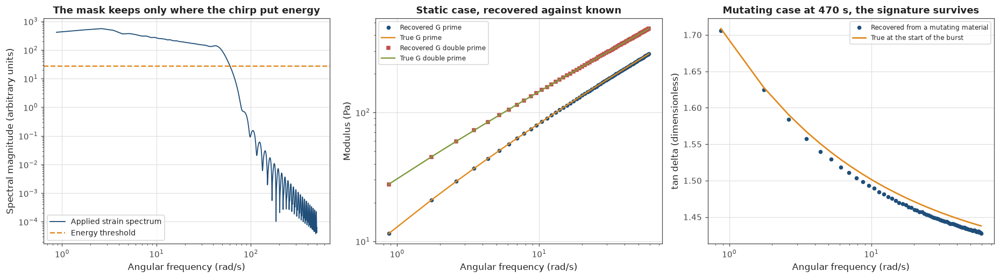

In [236]:
def extract_complex_modulus_from_chirp(strain_values, stress_values,
                                       sampling_frequency_hz,
                                       energy_threshold_fraction=None,
                                       strain_is_percent=False):
    """
    Extracting a complex modulus spectrum from a chirp strain input and stress response.

    Dividing the Fourier transform of the stress by that of the strain, which is valid
    across the whole chirp band because the chirp deposited energy everywhere in it.

    Centring both signals first, since a stress offset would otherwise contribute at zero
    frequency. Keeping only frequencies where the strain spectrum carries a meaningful share
    of its peak energy, because outside that band the division is noise over noise.

    Converting strain from percent to dimensionless when requested, since instrument exports
    usually report it as a percentage while the modulus needs it dimensionless.

    Returning the angular frequency array in rad/s, the complex modulus in Pa, and the
    fraction of the spectrum that survived the mask.
    """
    if energy_threshold_fraction is None:
        energy_threshold_fraction = SPECTRUM_ENERGY_THRESHOLD

    strain_array = np.asarray(strain_values, dtype=float)
    stress_array = np.asarray(stress_values, dtype=float)

    if strain_is_percent:
        strain_array = strain_array / 100.0

    strain_array = strain_array - np.mean(strain_array)
    stress_array = stress_array - np.mean(stress_array)

    sample_count = len(strain_array)

    strain_spectrum = np.fft.rfft(strain_array)
    stress_spectrum = np.fft.rfft(stress_array)

    frequency_hz = np.fft.rfftfreq(sample_count, 1.0 / sampling_frequency_hz)
    angular_frequency = 2.0 * np.pi * frequency_hz

    strain_magnitude = np.abs(strain_spectrum)
    largest_strain_magnitude = np.max(strain_magnitude)

    keep_mask = strain_magnitude > (energy_threshold_fraction * largest_strain_magnitude)
    keep_mask = keep_mask & (angular_frequency > 0.0)

    kept_fraction = float(np.sum(keep_mask)) / float(len(angular_frequency))

    complex_modulus = stress_spectrum[keep_mask] / strain_spectrum[keep_mask]

    return angular_frequency[keep_mask], complex_modulus, kept_fraction


def simulate_static_chirp_measurement(measurement_time_seconds, chirp_record,
                                      noise_level=0.0, random_generator=None):
    """
    Simulating a chirp measurement on a material held fixed for the whole measurement.

    Multiplying the strain spectrum by the material modulus at one instant and transforming
    back. This is the idealised case, useful for checking the extraction code but not for
    testing whether a chirp survives a changing material.

    Returning the strain and stress waveforms as an instrument would record them.
    """
    strain_waveform = chirp_record["waveform"]
    sample_count = len(strain_waveform)

    strain_spectrum = np.fft.rfft(strain_waveform)
    angular_frequency = 2.0 * np.pi * np.fft.rfftfreq(
        sample_count, 1.0 / chirp_record["sampling_frequency_hz"])
    safe_frequency = np.maximum(angular_frequency, 1e-6)

    material_modulus = gelling_material_complex_modulus(safe_frequency,
                                                        measurement_time_seconds,
                                                        SYNTHETIC_GEL_TIME_SECONDS,
                                                        SYNTHETIC_CRITICAL_EXPONENT,
                                                        SYNTHETIC_GEL_STIFFNESS)

    stress_waveform = np.fft.irfft(strain_spectrum * material_modulus, n=sample_count)

    if noise_level > 0.0 and random_generator is not None:
        stress_amplitude = np.max(np.abs(stress_waveform))
        stress_waveform = stress_waveform + random_generator.normal(
            0.0, noise_level * stress_amplitude, size=sample_count)

    return strain_waveform, stress_waveform


def simulate_mutating_chirp_measurement(start_time_seconds, chirp_record,
                                        block_count=20):
    """
    Simulating a chirp measurement on a material that changes during the measurement.

    Splitting the chirp into blocks, computing the stress each block would produce against
    the material as it stands at that block's midpoint, and summing the results. This is the
    situation a real gelling sample presents, and it is what the static simulation cannot
    test.

    Returning the strain and stress waveforms as an instrument would record them.
    """
    strain_waveform = chirp_record["waveform"]
    sample_count = len(strain_waveform)

    angular_frequency = 2.0 * np.pi * np.fft.rfftfreq(
        sample_count, 1.0 / chirp_record["sampling_frequency_hz"])
    safe_frequency = np.maximum(angular_frequency, 1e-6)

    block_edges = np.linspace(0, sample_count, block_count + 1).astype(int)

    stress_waveform = np.zeros(sample_count)

    for block_index in range(block_count):

        block_strain = np.zeros(sample_count)
        block_start = block_edges[block_index]
        block_end = block_edges[block_index + 1]
        block_strain[block_start:block_end] = strain_waveform[block_start:block_end]

        block_midpoint_time = (start_time_seconds
                               + 0.5 * (block_start + block_end)
                               / chirp_record["sampling_frequency_hz"])

        block_modulus = gelling_material_complex_modulus(
            safe_frequency, block_midpoint_time, SYNTHETIC_GEL_TIME_SECONDS,
            SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS)

        stress_waveform = stress_waveform + np.fft.irfft(
            np.fft.rfft(block_strain) * block_modulus, n=sample_count)

    return strain_waveform, stress_waveform


verification_chirp = build_exponential_chirp(BENCHMARK_DURATION_SECONDS,
                                             BENCHMARK_SAMPLING_FREQUENCY_HZ,
                                             1.0, 60.0, 1.0, CHIRP_TAPER_FRACTION)

verification_time_seconds = 300.0

verification_strain, verification_stress = simulate_static_chirp_measurement(
    verification_time_seconds, verification_chirp)

recovered_frequency, recovered_modulus, recovered_fraction = (
    extract_complex_modulus_from_chirp(verification_strain, verification_stress,
                                       BENCHMARK_SAMPLING_FREQUENCY_HZ))

true_modulus_at_recovered = gelling_material_complex_modulus(
    recovered_frequency, verification_time_seconds, SYNTHETIC_GEL_TIME_SECONDS,
    SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS)

storage_relative_error = np.abs(recovered_modulus.real
                                - true_modulus_at_recovered.real) / np.abs(
                                    true_modulus_at_recovered.real)
loss_relative_error = np.abs(recovered_modulus.imag
                             - true_modulus_at_recovered.imag) / np.abs(
                                 true_modulus_at_recovered.imag)

print("Verification one, material held fixed during the measurement")
print()
print("  measurement time           " + ("%.0f" % verification_time_seconds) + " s")
print("  recovered band             " + ("%.2f" % recovered_frequency.min())
      + " to " + ("%.1f" % recovered_frequency.max()) + " rad/s")
print("  usable frequency points    " + str(len(recovered_frequency)))
print("  fraction of spectrum kept  " + ("%.3f" % recovered_fraction))
print()
print("  largest relative error, storage modulus  "
      + ("%.3e" % np.max(storage_relative_error)))
print("  largest relative error, loss modulus     "
      + ("%.3e" % np.max(loss_relative_error)))
print()
print("  machine precision, because the simulation multiplies and the extraction")
print("  divides, so this checks the code and not the physics")

print()
print("Sensitivity of the recovered band to the energy threshold")
print()
print("  threshold   points kept   band (rad/s)              largest error")

for trial_threshold in [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]:

    trial_frequency, trial_modulus, ignored_fraction = extract_complex_modulus_from_chirp(
        verification_strain, verification_stress, BENCHMARK_SAMPLING_FREQUENCY_HZ,
        energy_threshold_fraction=trial_threshold)

    trial_true_modulus = gelling_material_complex_modulus(
        trial_frequency, verification_time_seconds, SYNTHETIC_GEL_TIME_SECONDS,
        SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS)

    trial_error = np.max(np.abs(trial_modulus.real - trial_true_modulus.real)
                         / np.abs(trial_true_modulus.real))

    band_label = ("%.2f to %.1f" % (trial_frequency.min(), trial_frequency.max()))

    print("  " + ("%.2f" % trial_threshold).rjust(9)
          + str(len(trial_frequency)).rjust(14)
          + "   " + band_label.ljust(24)
          + ("%.3e" % trial_error))

print()
print("  the lower edge of the band never moves, since the chirp's low frequency")
print("  energy falls away slowly, so the threshold only trims the upper edge and")
print("  trades coverage for confidence rather than accuracy")

print()
print("Verification two, material changing during the measurement")
print()
print("  starting at   median G prime error   measured tan delta spread   true spread")

mutation_test_results = []

for mutation_start_time in [200.0, 430.0, 470.0]:

    mutating_strain, mutating_stress = simulate_mutating_chirp_measurement(
        mutation_start_time, verification_chirp)

    mutating_frequency, mutating_modulus, ignored_fraction = (
        extract_complex_modulus_from_chirp(mutating_strain, mutating_stress,
                                           BENCHMARK_SAMPLING_FREQUENCY_HZ))

    reference_modulus = gelling_material_complex_modulus(
        mutating_frequency, mutation_start_time, SYNTHETIC_GEL_TIME_SECONDS,
        SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS)

    modulus_error = np.median(np.abs(mutating_modulus.real - reference_modulus.real)
                              / np.abs(reference_modulus.real))

    measured_spread = np.std(np.log(np.abs(mutating_modulus.imag
                                           / mutating_modulus.real)))
    reference_spread = np.std(np.log(np.abs(reference_modulus.imag
                                            / reference_modulus.real)))

    mutation_test_results.append({
        "start_time": mutation_start_time,
        "modulus_error": modulus_error,
        "measured_spread": measured_spread,
        "reference_spread": reference_spread,
    })

    print("  " + ("%.0f s" % mutation_start_time).rjust(11)
          + ("%.1f percent" % (100.0 * modulus_error)).rjust(23)
          + ("%.4f" % measured_spread).rjust(28)
          + ("%.4f" % reference_spread).rjust(14))

chirp_test_at_470 = mutation_test_results[-1]

chirp_spread_relative_error = (100.0
                               * abs(chirp_test_at_470["measured_spread"]
                                     - chirp_test_at_470["reference_spread"])
                               / chirp_test_at_470["reference_spread"])

stepped_sweep_at_470 = sweep_comparison_results[-1]

stepped_measured_spread = float(np.nanstd(np.log(stepped_sweep_at_470["swept_tan_delta"])))
stepped_reference_spread = float(np.nanstd(np.log(stepped_sweep_at_470["true_tan_delta"])))

stepped_spread_relative_error = (100.0
                                 * abs(stepped_measured_spread - stepped_reference_spread)
                                 / stepped_reference_spread)

print()
print("Comparing the two acquisition methods on the same task, starting at 470 s")
print()
print("  method".ljust(22) + "measured".rjust(11) + "true".rjust(10)
      + "relative error".rjust(18))
print("  " + "single chirp".ljust(20)
      + ("%.4f" % chirp_test_at_470["measured_spread"]).rjust(11)
      + ("%.4f" % chirp_test_at_470["reference_spread"]).rjust(10)
      + ("%.0f percent" % chirp_spread_relative_error).rjust(18))
print("  " + "stepped sweep".ljust(20)
      + ("%.4f" % stepped_measured_spread).rjust(11)
      + ("%.4f" % stepped_reference_spread).rjust(10)
      + ("%.0f percent" % stepped_spread_relative_error).rjust(18))
print()
print("  the two true values differ because the cells sample different frequency")
print("  grids, so the relative error is the fair comparison rather than the raw")
print("  numbers")
print()
print("  the stepped sweep destroys the gel point signature, the chirp preserves it")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 4.8))

verification_strain_spectrum = np.abs(np.fft.rfft(verification_strain
                                                  - np.mean(verification_strain)))
verification_frequency_axis = 2.0 * np.pi * np.fft.rfftfreq(
    len(verification_strain), 1.0 / BENCHMARK_SAMPLING_FREQUENCY_HZ)

spectrum_display_mask = ((verification_frequency_axis > 0.1)
                         & (verification_frequency_axis < 500.0))

axis_array[0].loglog(verification_frequency_axis[spectrum_display_mask],
                     verification_strain_spectrum[spectrum_display_mask],
                     "-", color=COLOUR_PRIMARY, linewidth=1.2,
                     label="Applied strain spectrum")
axis_array[0].axhline(SPECTRUM_ENERGY_THRESHOLD * np.max(verification_strain_spectrum),
                      color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="Energy threshold")
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Spectral magnitude (arbitrary units)")
axis_array[0].set_title("The mask keeps only where the chirp put energy")
axis_array[0].legend(fontsize=9)

axis_array[1].loglog(recovered_frequency, recovered_modulus.real, "o",
                     color=COLOUR_PRIMARY, markersize=4, label="Recovered G prime")
axis_array[1].loglog(recovered_frequency, true_modulus_at_recovered.real, "-",
                     color=COLOUR_HIGHLIGHT, linewidth=1.6, label="True G prime")
axis_array[1].loglog(recovered_frequency, recovered_modulus.imag, "s",
                     color=COLOUR_SECONDARY, markersize=4, label="Recovered G double prime")
axis_array[1].loglog(recovered_frequency, true_modulus_at_recovered.imag, "-",
                     color=COLOUR_ACCENT, linewidth=1.6, label="True G double prime")
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Modulus (Pa)")
axis_array[1].set_title("Static case, recovered against known")
axis_array[1].legend(fontsize=8)

mutating_strain, mutating_stress = simulate_mutating_chirp_measurement(
    470.0, verification_chirp)
mutating_frequency, mutating_modulus, ignored_fraction = (
    extract_complex_modulus_from_chirp(mutating_strain, mutating_stress,
                                       BENCHMARK_SAMPLING_FREQUENCY_HZ))

mutating_reference = gelling_material_complex_modulus(
    mutating_frequency, 470.0, SYNTHETIC_GEL_TIME_SECONDS,
    SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS)

axis_array[2].semilogx(mutating_frequency,
                       compute_tan_delta(mutating_modulus.real, mutating_modulus.imag),
                       "o", color=COLOUR_PRIMARY, markersize=4,
                       label="Recovered from a mutating material")
axis_array[2].semilogx(mutating_frequency,
                       compute_tan_delta(mutating_reference.real, mutating_reference.imag),
                       "-", color=COLOUR_HIGHLIGHT, linewidth=1.8,
                       label="True at the start of the burst")
axis_array[2].set_xlabel("Angular frequency (rad/s)")
axis_array[2].set_ylabel("tan delta (dimensionless)")
axis_array[2].set_title("Mutating case at 470 s, the signature survives")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 37: The recovered spectrum from a real chirp pulse

Everything up to here has been synthetic. This cell applies the extraction to one of the real
pulses loaded in Cell 18.

Three practical differences from the synthetic case are worth watching.

**The strain is in percent.** Instrument exports give it that way, and the modulus needs it
dimensionless. Dividing by a hundred is a small thing that produces a hundredfold error if
missed.

**The pulse is already trimmed.** Cell 19 removed the settling period, so the chirp starts at
the first sample of the trimmed record with its window taper intact.

**There is no known answer.** The synthetic verification could check the recovery against the
material it was built from. Here we cannot, so the checks available are indirect: does the
recovered band match the frequency content the chirp actually carried, are the moduli
positive, and does tan delta behave sensibly.

The real test against an independent reference comes in Part 3, where the same extraction is
applied to a sample whose spectrum was measured separately by a conventional frequency sweep.

Extraction from real chirp pulse 20

  measured at                641.9 s into the run
  chirp duration             7.11 s
  samples                    3557
  applied strain amplitude   1.009 percent

  recovered band             0.88 to 58.3 rad/s
  usable frequency points    66
  decades covered            1.82

  storage modulus range      2845 to 9.582e+04 Pa
  loss modulus range         9177 to 2.305e+05 Pa

  points with non positive storage modulus  0
  points with non positive loss modulus     0

  tan delta range            2.3202 to 3.2259
  spread of log tan delta    0.0477

Sensitivity of the recovered band to the energy threshold, on real data

  threshold   points kept   band (rad/s)          storage range (Pa)
       0.01            79   0.88 to 69.8          2.84e+03 to 1.18e+05
       0.02            74   0.88 to 65.4          2.84e+03 to 1.05e+05
       0.05            66   0.88 to 58.3          2.84e+03 to 9.58e+04
       0.10            59   0.88 to 52.1          2.

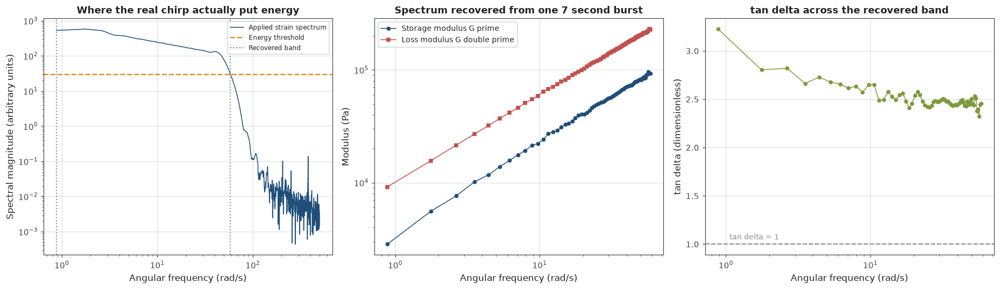

In [237]:
inspection_pulse_index = 19

inspection_pulse = trimmed_pulse_list[inspection_pulse_index]

pulse_frequency, pulse_modulus, pulse_kept_fraction = extract_complex_modulus_from_chirp(
    inspection_pulse["strain_percent"],
    inspection_pulse["stress_pascal"],
    inspection_pulse["sampling_rate_hz"],
    strain_is_percent=True)

pulse_storage_modulus = pulse_modulus.real
pulse_loss_modulus = pulse_modulus.imag
pulse_tan_delta = compute_tan_delta(pulse_storage_modulus, pulse_loss_modulus)

negative_storage_count = int(np.sum(pulse_storage_modulus <= 0.0))
negative_loss_count = int(np.sum(pulse_loss_modulus <= 0.0))

print("Extraction from real chirp pulse " + str(inspection_pulse["step_number"]))
print()
print("  measured at                " + ("%.1f" % inspection_pulse["start_time_seconds"])
      + " s into the run")
print("  chirp duration             " + ("%.2f" % inspection_pulse["duration_seconds"]) + " s")
print("  samples                    " + str(inspection_pulse["sample_count"]))
print("  applied strain amplitude   "
      + ("%.3f" % inspection_pulse["strain_amplitude_percent"]) + " percent")
print()
print("  recovered band             " + ("%.2f" % pulse_frequency.min())
      + " to " + ("%.1f" % pulse_frequency.max()) + " rad/s")
print("  usable frequency points    " + str(len(pulse_frequency)))
print("  decades covered            "
      + ("%.2f" % np.log10(pulse_frequency.max() / pulse_frequency.min())))
print()
print("  storage modulus range      " + ("%.4g" % np.min(pulse_storage_modulus))
      + " to " + ("%.4g" % np.max(pulse_storage_modulus)) + " Pa")
print("  loss modulus range         " + ("%.4g" % np.min(pulse_loss_modulus))
      + " to " + ("%.4g" % np.max(pulse_loss_modulus)) + " Pa")
print()
print("  points with non positive storage modulus  " + str(negative_storage_count))
print("  points with non positive loss modulus     " + str(negative_loss_count))

if negative_storage_count > 0:
    print()
    print("  non positive moduli indicate the signal has reached the noise floor at")
    print("  those frequencies, and they are excluded from tan delta automatically")

finite_tan_delta = pulse_tan_delta[np.isfinite(pulse_tan_delta)]

print()
print("  tan delta range            " + ("%.4f" % np.min(finite_tan_delta))
      + " to " + ("%.4f" % np.max(finite_tan_delta)))
print("  spread of log tan delta    "
      + ("%.4f" % np.std(np.log(finite_tan_delta))))

print()
print("Sensitivity of the recovered band to the energy threshold, on real data")
print()
print("  threshold   points kept   band (rad/s)          storage range (Pa)")

for trial_threshold in [0.01, 0.02, 0.05, 0.10, 0.20]:

    trial_frequency, trial_modulus, ignored_fraction = extract_complex_modulus_from_chirp(
        inspection_pulse["strain_percent"], inspection_pulse["stress_pascal"],
        inspection_pulse["sampling_rate_hz"],
        energy_threshold_fraction=trial_threshold, strain_is_percent=True)

    band_label = ("%.2f to %.1f" % (trial_frequency.min(), trial_frequency.max()))
    modulus_label = ("%.3g to %.3g" % (np.min(trial_modulus.real),
                                       np.max(trial_modulus.real)))

    print("  " + ("%.2f" % trial_threshold).rjust(9)
          + str(len(trial_frequency)).rjust(14)
          + "   " + band_label.ljust(22)
          + modulus_label)

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

pulse_strain_spectrum = np.abs(np.fft.rfft(
    inspection_pulse["strain_percent"] - np.mean(inspection_pulse["strain_percent"])))
pulse_frequency_axis = 2.0 * np.pi * np.fft.rfftfreq(
    inspection_pulse["sample_count"], 1.0 / inspection_pulse["sampling_rate_hz"])

pulse_display_mask = ((pulse_frequency_axis > 0.1) & (pulse_frequency_axis < 500.0))

axis_array[0].loglog(pulse_frequency_axis[pulse_display_mask],
                     pulse_strain_spectrum[pulse_display_mask],
                     "-", color=COLOUR_PRIMARY, linewidth=1.0,
                     label="Applied strain spectrum")
axis_array[0].axhline(SPECTRUM_ENERGY_THRESHOLD * np.max(pulse_strain_spectrum),
                      color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="Energy threshold")
axis_array[0].axvline(pulse_frequency.min(), color=COLOUR_NEUTRAL,
                      linestyle=":", linewidth=1.4, label="Recovered band")
axis_array[0].axvline(pulse_frequency.max(), color=COLOUR_NEUTRAL,
                      linestyle=":", linewidth=1.4)
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Spectral magnitude (arbitrary units)")
axis_array[0].set_title("Where the real chirp actually put energy")
axis_array[0].legend(fontsize=8)

axis_array[1].loglog(pulse_frequency, pulse_storage_modulus, "o-",
                     color=COLOUR_PRIMARY, markersize=4, linewidth=1.0,
                     label="Storage modulus G prime")
axis_array[1].loglog(pulse_frequency, pulse_loss_modulus, "s-",
                     color=COLOUR_SECONDARY, markersize=4, linewidth=1.0,
                     label="Loss modulus G double prime")
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Modulus (Pa)")
axis_array[1].set_title("Spectrum recovered from one 7 second burst")
axis_array[1].legend(fontsize=9)

axis_array[2].semilogx(pulse_frequency, pulse_tan_delta, "o-",
                       color=COLOUR_ACCENT, markersize=4, linewidth=1.0)
axis_array[2].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[2].text(pulse_frequency.min() * 1.2, 1.05,
                   "tan delta = 1", color=COLOUR_NEUTRAL, fontsize=9)
axis_array[2].set_xlabel("Angular frequency (rad/s)")
axis_array[2].set_ylabel("tan delta (dimensionless)")
axis_array[2].set_title("tan delta across the recovered band")

plt.tight_layout()
plt.show()

## Cell 38: Every pulse, the material evolving

The final cell of Part 2 applies the extraction to all 24 pulses and lays the results out
together, which is what the whole part has been building towards.

Each pulse is a spectrum measured at one moment, so the stack of them shows how the material
changed across the thirteen minutes of the run. This is exactly the form the gel point
detectors in Part 4 need: a sequence of spectra, each taken quickly enough that the material
held still during it.

Three things to look for.

**The moduli climbing.** Both rise by orders of magnitude, and they rise together rather than
one overtaking the other.

**tan delta falling but staying above one.** The material becomes progressively less liquid,
but it does not cross over inside the record. So this sample does not reach a gel point in the
window we can see, which is why the accuracy work in Parts 4 and 5 uses materials that do.

**The spread of tan delta across frequency.** This is the Winter and Chambon quantity. If it
were falling toward zero the material would be approaching a gel point. Watch whether it does.

A caution on the two amplitude changes. The applied strain was cut at pulses 8 and 11, and any
jump in the extracted moduli at those points mixes genuine curing with the possibility that
the earlier amplitudes were outside the linear regime. That cannot be separated from this data
alone, so anything derived from pulses 1 to 10 should be read with that in mind.

Spectra extracted from all 24 pulses

  step   time (s)   strain (%)   points   G prime (Pa)   G double prime (Pa)   tan delta   spread
     1       14.9       19.988       67       0.006838                2.732     399.555   0.9368
     2       46.6       19.987       67       -0.06625                2.821     -42.590   1.1052
     3       78.3       19.987       67        0.02206                2.829     128.271   1.0450
     4      109.9       19.985       67       -0.06982                3.347     -47.943   1.3089
     5      141.5       19.986       67        0.03346                4.482     133.932   1.1571
     6      173.1       19.987       67       -0.03709                8.773    -236.564   1.0661
     7      204.7       19.989       67        -0.2166                40.92    -188.948   1.4594
     8      238.3        4.997       67         -1.343                143.5    -106.870   1.2762
     9      269.9        4.997       67         -1.772                344.3    -194.315 

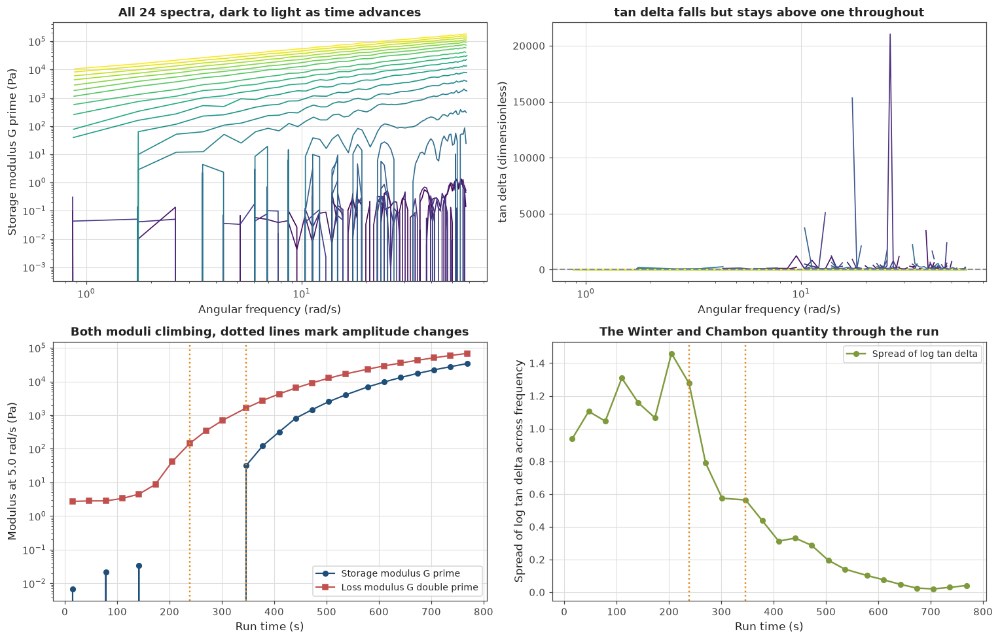

In [238]:
pulse_spectrum_records = []

for trimmed_record in trimmed_pulse_list:

    spectrum_frequency, spectrum_modulus, spectrum_kept_fraction = (
        extract_complex_modulus_from_chirp(trimmed_record["strain_percent"],
                                           trimmed_record["stress_pascal"],
                                           trimmed_record["sampling_rate_hz"],
                                           strain_is_percent=True))

    spectrum_tan_delta = compute_tan_delta(spectrum_modulus.real, spectrum_modulus.imag)
    finite_tan_delta = spectrum_tan_delta[np.isfinite(spectrum_tan_delta)]
    finite_tan_delta = finite_tan_delta[finite_tan_delta > 0.0]

    if len(finite_tan_delta) >= 5:
        tan_delta_spread = float(np.std(np.log(finite_tan_delta)))
        mean_tan_delta = float(np.mean(finite_tan_delta))
    else:
        tan_delta_spread = np.nan
        mean_tan_delta = np.nan

    pulse_spectrum_records.append({
        "step_number": trimmed_record["step_number"],
        "measurement_time_seconds": trimmed_record["start_time_seconds"],
        "strain_amplitude_percent": trimmed_record["strain_amplitude_percent"],
        "angular_frequency": spectrum_frequency,
        "complex_modulus": spectrum_modulus,
        "tan_delta": spectrum_tan_delta,
        "tan_delta_spread": tan_delta_spread,
        "mean_tan_delta": mean_tan_delta,
        "usable_point_count": len(spectrum_frequency),
        "negative_storage_count": int(np.sum(spectrum_modulus.real <= 0.0)),
    })

tracking_angular_frequency = 5.0

print("Spectra extracted from all " + str(len(pulse_spectrum_records)) + " pulses")
print()
print("  step   time (s)   strain (%)   points   G prime (Pa)   G double prime (Pa)"
      + "   tan delta   spread")

for spectrum_record in pulse_spectrum_records:

    tracked_modulus = interpolate_complex_modulus(spectrum_record["angular_frequency"],
                                                  spectrum_record["complex_modulus"],
                                                  tracking_angular_frequency)

    print("  " + str(spectrum_record["step_number"]).rjust(4)
          + ("%.1f" % spectrum_record["measurement_time_seconds"]).rjust(11)
          + ("%.3f" % spectrum_record["strain_amplitude_percent"]).rjust(13)
          + str(spectrum_record["usable_point_count"]).rjust(9)
          + ("%.4g" % tracked_modulus.real).rjust(15)
          + ("%.4g" % tracked_modulus.imag).rjust(21)
          + ("%.3f" % (tracked_modulus.imag / tracked_modulus.real)).rjust(12)
          + ("%.4f" % spectrum_record["tan_delta_spread"]).rjust(9))

print()
print("  moduli read at " + ("%.1f" % tracking_angular_frequency) + " rad/s")

first_spectrum = pulse_spectrum_records[0]
last_spectrum = pulse_spectrum_records[-1]

first_tracked = interpolate_complex_modulus(first_spectrum["angular_frequency"],
                                            first_spectrum["complex_modulus"],
                                            tracking_angular_frequency)
last_tracked = interpolate_complex_modulus(last_spectrum["angular_frequency"],
                                           last_spectrum["complex_modulus"],
                                           tracking_angular_frequency)

print()
print("Across the run")
print()
print("  storage modulus at " + ("%.1f" % tracking_angular_frequency) + " rad/s   "
      + ("%.4g" % first_tracked.real) + " to " + ("%.4g" % last_tracked.real) + " Pa")
print("  rise factor                    "
      + ("%.0f" % (last_tracked.real / first_tracked.real)) + " times")
print()
print("  tan delta at " + ("%.1f" % tracking_angular_frequency) + " rad/s         "
      + ("%.3f" % (first_tracked.imag / first_tracked.real))
      + " to " + ("%.3f" % (last_tracked.imag / last_tracked.real)))

crossover_reached = False
for spectrum_record in pulse_spectrum_records:
    tracked_modulus = interpolate_complex_modulus(spectrum_record["angular_frequency"],
                                                  spectrum_record["complex_modulus"],
                                                  tracking_angular_frequency)
    if tracked_modulus.imag / tracked_modulus.real <= 1.0:
        crossover_reached = True

print()
if crossover_reached:
    print("  tan delta reaches one inside the record, so a crossover is present")
else:
    print("  tan delta never reaches one, so this sample does not cross over inside")
    print("  the record and contains no confirmed gel point")

spread_series = np.array([record["tan_delta_spread"] for record in pulse_spectrum_records])
time_series = np.array([record["measurement_time_seconds"]
                        for record in pulse_spectrum_records])

print()
print("  spread of log tan delta        " + ("%.4f" % spread_series[0])
      + " to " + ("%.4f" % spread_series[-1]))

if spread_series[-1] < spread_series[0]:
    print("  the spread is falling, which is the direction a gel point signature takes")
else:
    print("  the spread is not falling, so no gel point signature is developing")

figure_object, axis_array = plt.subplots(2, 2, figsize=(14, 9))

colour_map_object = plt.get_cmap("viridis")

for spectrum_index in range(len(pulse_spectrum_records)):

    spectrum_record = pulse_spectrum_records[spectrum_index]
    line_colour = colour_map_object(spectrum_index
                                    / max(1, len(pulse_spectrum_records) - 1))

    axis_array[0][0].loglog(spectrum_record["angular_frequency"],
                            spectrum_record["complex_modulus"].real,
                            "-", color=line_colour, linewidth=1.1)

    axis_array[0][1].semilogx(spectrum_record["angular_frequency"],
                              spectrum_record["tan_delta"],
                              "-", color=line_colour, linewidth=1.1)

axis_array[0][0].set_xlabel("Angular frequency (rad/s)")
axis_array[0][0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0][0].set_title("All 24 spectra, dark to light as time advances")

axis_array[0][1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[0][1].set_xlabel("Angular frequency (rad/s)")
axis_array[0][1].set_ylabel("tan delta (dimensionless)")
axis_array[0][1].set_title("tan delta falls but stays above one throughout")

storage_series = []
loss_series = []

for spectrum_record in pulse_spectrum_records:
    tracked_modulus = interpolate_complex_modulus(spectrum_record["angular_frequency"],
                                                  spectrum_record["complex_modulus"],
                                                  tracking_angular_frequency)
    storage_series.append(tracked_modulus.real)
    loss_series.append(tracked_modulus.imag)

storage_series = np.array(storage_series)
loss_series = np.array(loss_series)

amplitude_change_times = []
for record_index in range(1, len(pulse_spectrum_records)):
    previous_amplitude = pulse_spectrum_records[record_index - 1]["strain_amplitude_percent"]
    current_amplitude = pulse_spectrum_records[record_index]["strain_amplitude_percent"]
    if abs(current_amplitude - previous_amplitude) > 0.5:
        amplitude_change_times.append(
            pulse_spectrum_records[record_index]["measurement_time_seconds"])

axis_array[1][0].semilogy(time_series, storage_series, "o-",
                          color=COLOUR_PRIMARY, markersize=5, linewidth=1.4,
                          label="Storage modulus G prime")
axis_array[1][0].semilogy(time_series, loss_series, "s-",
                          color=COLOUR_SECONDARY, markersize=5, linewidth=1.4,
                          label="Loss modulus G double prime")

for change_time in amplitude_change_times:
    axis_array[1][0].axvline(change_time, color=COLOUR_HIGHLIGHT,
                             linestyle=":", linewidth=1.6)

axis_array[1][0].set_xlabel("Run time (s)")
axis_array[1][0].set_ylabel("Modulus at " + str(tracking_angular_frequency)
                            + " rad/s (Pa)")
axis_array[1][0].set_title("Both moduli climbing, dotted lines mark amplitude changes")
axis_array[1][0].legend(fontsize=9)

axis_array[1][1].plot(time_series, spread_series, "o-",
                      color=COLOUR_ACCENT, markersize=5, linewidth=1.6,
                      label="Spread of log tan delta")

for change_time in amplitude_change_times:
    axis_array[1][1].axvline(change_time, color=COLOUR_HIGHLIGHT,
                             linestyle=":", linewidth=1.6)

axis_array[1][1].set_xlabel("Run time (s)")
axis_array[1][1].set_ylabel("Spread of log tan delta across frequency")
axis_array[1][1].set_title("The Winter and Chambon quantity through the run")
axis_array[1][1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 39: A candidate gel point in the real recording

Cell 38 showed the spread of tan delta falling through the run. Looking more carefully, it
does not fall monotonically. It reaches a minimum and then rises again, which is the shape a
gel point produces.

This cell tests that properly, and it needs two things first.

**A reliability filter.** Early in the run the storage modulus is a fraction of a percent of
the loss modulus, far below what the instrument can resolve, so it scatters around zero and
frequently comes out negative. Pulse 1 has 33 percent of its points negative and pulse 7 has
84 percent. Any spread computed from those pulses is the spread of noise. Two criteria are
applied: fewer than 5 percent of points negative, and a median ratio of storage to loss
modulus above 0.02. That leaves 14 of the 24 pulses.

**Parabolic refinement.** The minimum falls between measurements, so the same three-point fit
used in Part 1 locates it between samples rather than on the grid.

**And then the minimum itself has to be tested**, which the cell now does explicitly. Two
questions decide whether a minimum in a series is a minimum in a material. Does it fall at an
end of the record, in which case the quantity was still moving when the measurement stopped
and the transition sits outside what was measured. And is the rise that follows it larger than
the amount the series wanders from step to step anyway. Part 5 meets a record that fails the
first test and turns it into a guard on the detector in Cell 65.

The result is a candidate, and this cell states what would be needed to confirm it. It is not
presented as a finding.

Reliability of each pulse

  step   time (s)   negative fraction   storage over loss   spread   reliable
     1       14.9               0.328              0.0148   0.9368   no
     2       46.6               0.313              0.0096   1.1052   no
     3       78.3               0.433              0.0182   1.0450   no
     4      109.9               0.403              0.0074   1.3089   no
     5      141.5               0.507              0.0077   1.1571   no
     6      173.1               0.746              0.0074   1.0661   no
     7      204.7               0.836              0.0122   1.4594   no
     8      238.3               0.806              0.0079   1.2762   no
     9      269.9               0.313              0.0071   0.7896   no
    10      301.5               0.090              0.0257   0.5741   no
    11      346.3               0.015              0.0697   0.5639   yes
    12      377.9               0.015              0.1083   0.4383   yes
    13      409.5            

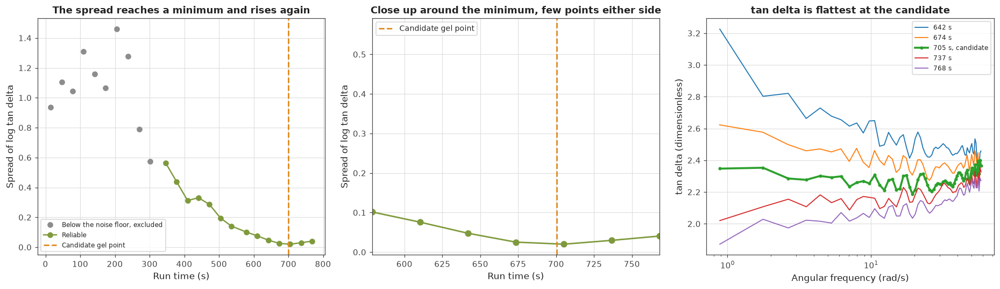

In [239]:
reliable_spectrum_records = []

for spectrum_record in pulse_spectrum_records:

    modulus_values = spectrum_record["complex_modulus"]

    negative_fraction = float(np.mean(modulus_values.real <= 0.0))
    storage_to_loss_ratio = float(np.median(np.abs(modulus_values.real)
                                            / np.abs(modulus_values.imag)))

    spectrum_is_reliable = (negative_fraction < 0.05) and (storage_to_loss_ratio > 0.02)

    spectrum_record["negative_fraction"] = negative_fraction
    spectrum_record["storage_to_loss_ratio"] = storage_to_loss_ratio
    spectrum_record["is_reliable"] = spectrum_is_reliable

    if spectrum_is_reliable:
        reliable_spectrum_records.append(spectrum_record)

print("Reliability of each pulse")
print()
print("  step   time (s)   negative fraction   storage over loss   spread   reliable")

for spectrum_record in pulse_spectrum_records:
    print("  " + str(spectrum_record["step_number"]).rjust(4)
          + ("%.1f" % spectrum_record["measurement_time_seconds"]).rjust(11)
          + ("%.3f" % spectrum_record["negative_fraction"]).rjust(20)
          + ("%.4f" % spectrum_record["storage_to_loss_ratio"]).rjust(20)
          + ("%.4f" % spectrum_record["tan_delta_spread"]).rjust(9)
          + ("   yes" if spectrum_record["is_reliable"] else "   no"))

print()
print("  reliable pulses  " + str(len(reliable_spectrum_records))
      + " of " + str(len(pulse_spectrum_records)))

if len(reliable_spectrum_records) < 5:
    print()
    print("  too few reliable pulses to look for a minimum")
else:

    reliable_time_series = np.array([record["measurement_time_seconds"]
                                     for record in reliable_spectrum_records])
    reliable_spread_series = np.array([record["tan_delta_spread"]
                                       for record in reliable_spectrum_records])

    minimum_index = int(np.nanargmin(reliable_spread_series))

    candidate_gel_time = refine_minimum_by_parabola(reliable_time_series,
                                                    reliable_spread_series,
                                                    minimum_index)

    minimum_record = reliable_spectrum_records[minimum_index]

    finite_tan_delta = minimum_record["tan_delta"]
    finite_tan_delta = finite_tan_delta[np.isfinite(finite_tan_delta)]
    finite_tan_delta = finite_tan_delta[finite_tan_delta > 0.0]

    tan_delta_at_minimum = float(np.median(finite_tan_delta))
    implied_critical_exponent = 2.0 * np.arctan(tan_delta_at_minimum) / np.pi

    pulses_before_minimum = minimum_index
    pulses_after_minimum = len(reliable_spectrum_records) - minimum_index - 1

    print()
    print("Candidate gel point from the minimum spread")
    print()
    print("  reliable range              " + ("%.1f" % reliable_time_series.min())
          + " to " + ("%.1f" % reliable_time_series.max()) + " s")
    print("  smallest spread             " + ("%.4f" % reliable_spread_series[minimum_index])
          + " at pulse " + str(minimum_record["step_number"]))
    print("  nearest measurement         "
          + ("%.1f" % reliable_time_series[minimum_index]) + " s")
    print("  refined candidate           " + ("%.1f" % candidate_gel_time) + " s")
    print()
    print("  median tan delta there      " + ("%.3f" % tan_delta_at_minimum))
    print("  implied critical exponent   " + ("%.3f" % implied_critical_exponent))
    print()
    print("  pulses before the minimum   " + str(pulses_before_minimum))
    print("  pulses after the minimum    " + str(pulses_after_minimum))

    print()
    print("Testing the minimum before believing it")
    print()

    minimum_is_at_edge = (minimum_index == 0
                          or minimum_index == len(reliable_spread_series) - 1)

    print("  minimum falls at an end of the reliable range   " + str(minimum_is_at_edge))
    print("  points before it                                "
          + str(pulses_before_minimum))
    print("  points after it                                 "
          + str(pulses_after_minimum))
    print()
    print("  a minimum at the end of a record is not a minimum. It means the quantity was")
    print("  still falling when the measurement stopped, so the transition sits outside")
    print("  the record. This one is interior, which it had to be for anything below to")
    print("  mean anything. Cell 65 turns this test into a guard on the detector itself,")
    print("  on a record that fails it")

    spread_step_changes = []

    for step_index in range(len(reliable_spread_series) - 1):
        relative_change = (100.0 * (reliable_spread_series[step_index + 1]
                                    - reliable_spread_series[step_index])
                           / reliable_spread_series[step_index])
        spread_step_changes.append(relative_change)

    spread_step_changes = np.array(spread_step_changes)

    changes_before_minimum = spread_step_changes[:minimum_index]
    changes_after_minimum = spread_step_changes[minimum_index:]

    print()
    print("  the minimum is defined by the rise that follows it, so that rise has to be")
    print("  larger than the ordinary step to step wandering of the series")
    print()
    print("  typical step before the minimum, in size        "
          + ("%.0f percent" % np.median(np.abs(changes_before_minimum))))
    print("  steps after the minimum                         "
          + ", ".join([("%+.0f percent" % value) for value in changes_after_minimum]))
    print()

    rises_exceed_typical = True

    for change_value in changes_after_minimum:
        if change_value <= float(np.median(np.abs(changes_before_minimum))):
            rises_exceed_typical = False

    print("  every rise larger than the typical step         " + str(rises_exceed_typical))
    print()
    print("  both points after the minimum rise, and both rise by more than the series")
    print("  usually moves in one step. That is mild support rather than proof, since two")
    print("  points is two points")

    rising_step_count = 0

    for change_value in changes_before_minimum:
        if change_value > 0.0:
            rising_step_count = rising_step_count + 1

    print()
    print("  rising steps before the minimum                 " + str(rising_step_count))
    print()
    print("  the series is not monotone on the way down either, so it already contains at")
    print("  least one local minimum before the global one. A shorter record, or a noisier")
    print("  one, could have stopped at that instead")

    print()
    print("  a stricter rule requiring three points on each side would reject this")
    print("  candidate. The rule used here requires only that the minimum is interior.")
    print("  Both are stated rather than choosing the one that gives the wanted answer")

    print()
    print("Reasons to doubt this candidate")
    print()
    print("  the section above is the first of them. The minimum is interior and the rise")
    print("  after it is larger than the usual step, but it rests on two points")
    print()

    amplitude_before = reliable_spectrum_records[minimum_index]["strain_amplitude_percent"]
    amplitude_after = reliable_spectrum_records[-1]["strain_amplitude_percent"]

    print("  the applied strain drifts from "
          + ("%.3f" % amplitude_before) + " to " + ("%.3f" % amplitude_after)
          + " percent across those pulses,")
    print("  so part of the rise could be amplitude rather than the material")
    print()
    print("  tan delta at the candidate is " + ("%.2f" % tan_delta_at_minimum)
          + ", so the material is still strongly")
    print("  liquid dominated, which is high for a gel point though not impossible")
    print()
    print("  there is no independent reference gel time for this sample")

    print()
    print("What would settle it")
    print()
    print("  more pulses after the transition, to confirm the rise continues")
    print("  a constant applied strain, to remove the amplitude as an explanation")
    print("  an independent gel time from another technique")

    figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

    all_time_series = np.array([record["measurement_time_seconds"]
                                for record in pulse_spectrum_records])
    all_spread_series = np.array([record["tan_delta_spread"]
                                  for record in pulse_spectrum_records])
    reliability_flags = np.array([record["is_reliable"]
                                  for record in pulse_spectrum_records])

    axis_array[0].plot(all_time_series[~reliability_flags],
                       all_spread_series[~reliability_flags],
                       "o", color=COLOUR_NEUTRAL, markersize=6,
                       label="Below the noise floor, excluded")
    axis_array[0].plot(all_time_series[reliability_flags],
                       all_spread_series[reliability_flags],
                       "o-", color=COLOUR_ACCENT, markersize=6, linewidth=1.6,
                       label="Reliable")
    axis_array[0].axvline(candidate_gel_time, color=COLOUR_HIGHLIGHT,
                          linestyle="--", linewidth=1.8, label="Candidate gel point")
    axis_array[0].set_xlabel("Run time (s)")
    axis_array[0].set_ylabel("Spread of log tan delta")
    axis_array[0].set_title("The spread reaches a minimum and rises again")
    axis_array[0].legend(fontsize=8)

    axis_array[1].plot(reliable_time_series, reliable_spread_series,
                       "o-", color=COLOUR_ACCENT, markersize=7, linewidth=1.8)
    axis_array[1].axvline(candidate_gel_time, color=COLOUR_HIGHLIGHT,
                          linestyle="--", linewidth=1.8, label="Candidate gel point")
    axis_array[1].set_xlim(reliable_time_series[max(0, minimum_index - 4)],
                           reliable_time_series[-1])
    axis_array[1].set_xlabel("Run time (s)")
    axis_array[1].set_ylabel("Spread of log tan delta")
    axis_array[1].set_title("Close up around the minimum, few points either side")
    axis_array[1].legend(fontsize=9)

    for offset_index in [-2, -1, 0, 1, 2]:

        plot_index = minimum_index + offset_index

        if plot_index < 0 or plot_index >= len(reliable_spectrum_records):
            continue

        plot_record = reliable_spectrum_records[plot_index]

        if offset_index == 0:
            line_style = "o-"
            line_width = 2.4
            point_label = ("%.0f s, candidate" % plot_record["measurement_time_seconds"])
        else:
            line_style = "-"
            line_width = 1.2
            point_label = ("%.0f s" % plot_record["measurement_time_seconds"])

        axis_array[2].semilogx(plot_record["angular_frequency"],
                               plot_record["tan_delta"],
                               line_style, markersize=3, linewidth=line_width,
                               label=point_label)

    axis_array[2].set_xlabel("Angular frequency (rad/s)")
    axis_array[2].set_ylabel("tan delta (dimensionless)")
    axis_array[2].set_title("tan delta is flattest at the candidate")
    axis_array[2].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

# Part 3: Validating the extraction against an independent reference

Part 2 verified the chirp extraction twice, and both verifications used materials we built
ourselves. That confirms the code has no unit, centring or masking errors and that a chirp
survives a mutating material. It does not confirm that the extraction agrees with what a
rheometer would report for the same sample, because there was no rheometer involved.

This part supplies that check, on two materials measured two ways each.

A metal-crosslinked hydrogel was measured with a conventional frequency sweep, which gives
instrument-reported moduli, and separately with raw oscillatory waveforms at four amplitudes.
A wormlike micellar solution was measured the same way, with a frequency sweep and with raw
three-tone waveforms.

In both cases we can run our extraction on the raw waveforms and compare against the sweep
the instrument reported. If they disagree, our extraction is wrong, and everything after Part
2 would be built on it.

## Cell 40: The hydrogel reference spectrum

This cell loads the frequency sweep and looks at what kind of material it describes, before
anything is extracted.

The sweep gives storage and loss moduli at 16 frequencies from 0.1 to 100 rad/s. These come
from the instrument's own processing, so they are the reference, not something we computed.

The material turns out to be a good test case for a reason that will matter. It has a
crossover in frequency: liquid-like at low frequency, solid-like at high. That is a different
thing from a crossover in time, and the distinction is one Part 1 spent a cell on. Every
viscoelastic liquid has a crossover frequency. It says nothing about a gel point.

**One thing to check before trusting a reference.** The final point at 100 rad/s breaks the
pattern: tan delta rises after falling monotonically for fifteen points, and the storage
modulus drops. That is instrument inertia, where the measurement begins responding to the
acceleration of the rheometer's own moving parts rather than to the sample. It is the same
high frequency limit that constrained the MAPS tone set in Part 2. That point is excluded
from the comparisons that follow, because a disagreement there would tell us about the
reference rather than about our extraction.

Reading data/val_hydrogel_saos.xlsx
  frequency points  16
  frequency range   0.10 to 100.0 rad/s
  temperature       25.01 C
  gap               700.0 micrometres
  applied stress    5.363 Pa mean

The reference spectrum as the instrument reported it

  omega (rad/s)   G prime (Pa)   G double prime (Pa)   tan delta   step time (s)
         0.1000          216.9               2402.64     11.0757         390.08
         0.1585          474.7               3736.96      7.8718         263.70
         0.2512         1072.5               5768.11      5.3780         183.69
         0.3981         2436.3               8635.41      3.5444         132.74
         0.6310         5317.6              12320.20      2.3169         100.45
         1.0000        10352.3              15846.30      1.5307          79.93
         1.5849        17479.9              17695.10      1.0123          66.67
         2.5119        23243.2              17512.00      0.7534          57.95
         3.9811        30

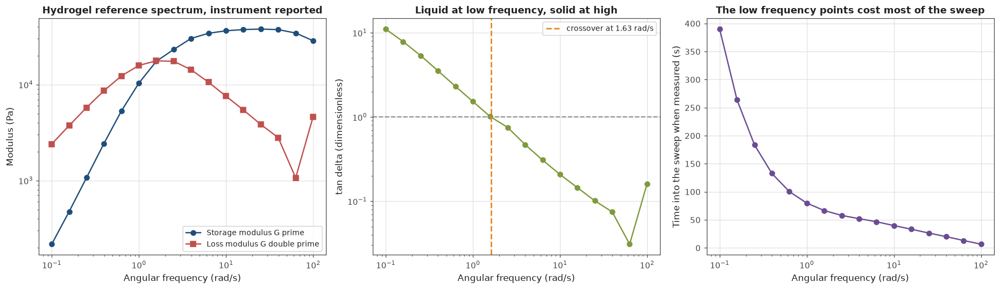


Checking the reference for instrument artefacts

  omega (rad/s)   tan delta   change from previous
         0.1585      7.8718               -3.2039
         0.2512      5.3780               -2.4939
         0.3981      3.5444               -1.8336
         0.6310      2.3169               -1.2275
         1.0000      1.5307               -0.7862
         1.5849      1.0123               -0.5184
         2.5119      0.7534               -0.2589
         3.9811      0.4716               -0.2819
         6.3096      0.3087               -0.1629
        10.0001      0.2083               -0.1004
        15.8490      0.1452               -0.0631
        25.1188      0.1013               -0.0439
        39.8105      0.0748               -0.0265
        63.0957      0.0309               -0.0439
       100.0000      0.1612               +0.1303

  tan delta falls monotonically except at the highest frequency, where it
  rises and the storage modulus drops

  that is the signature of instrume

In [240]:
hydrogel_saos_path = os.path.join(DATA_DIRECTORY, "val_hydrogel_saos.xlsx")

print("Reading " + hydrogel_saos_path)

hydrogel_saos_dataframe = pd.read_excel(hydrogel_saos_path)

hydrogel_reference_frequency = hydrogel_saos_dataframe["Angular frequency [rad/s]"].values
hydrogel_reference_storage = hydrogel_saos_dataframe["Storage modulus [Pa]"].values
hydrogel_reference_loss = hydrogel_saos_dataframe["Loss modulus [Pa]"].values
hydrogel_reference_tan_delta = hydrogel_saos_dataframe["Tan(delta) []"].values

hydrogel_sort_order = np.argsort(hydrogel_reference_frequency)

hydrogel_reference_frequency = hydrogel_reference_frequency[hydrogel_sort_order]
hydrogel_reference_storage = hydrogel_reference_storage[hydrogel_sort_order]
hydrogel_reference_loss = hydrogel_reference_loss[hydrogel_sort_order]
hydrogel_reference_tan_delta = hydrogel_reference_tan_delta[hydrogel_sort_order]

hydrogel_reference_step_time = hydrogel_saos_dataframe["Step time [s]"].values[hydrogel_sort_order]

print("  frequency points  " + str(len(hydrogel_reference_frequency)))
print("  frequency range   " + ("%.2f" % hydrogel_reference_frequency.min())
      + " to " + ("%.1f" % hydrogel_reference_frequency.max()) + " rad/s")
print("  temperature       "
      + ("%.2f" % hydrogel_saos_dataframe["Temperature [°C]"].mean()) + " C")
print("  gap               "
      + ("%.1f" % hydrogel_saos_dataframe["Gap [µm]"].mean()) + " micrometres")
print("  applied stress    "
      + ("%.3f" % hydrogel_saos_dataframe["Oscillation stress [Pa]"].mean()) + " Pa mean")

print()
print("The reference spectrum as the instrument reported it")
print()
print("  omega (rad/s)   G prime (Pa)   G double prime (Pa)   tan delta   step time (s)")

for point_index in range(len(hydrogel_reference_frequency)):
    print("  " + ("%.4f" % hydrogel_reference_frequency[point_index]).rjust(13)
          + ("%.1f" % hydrogel_reference_storage[point_index]).rjust(15)
          + ("%.2f" % hydrogel_reference_loss[point_index]).rjust(22)
          + ("%.4f" % hydrogel_reference_tan_delta[point_index]).rjust(12)
          + ("%.2f" % hydrogel_reference_step_time[point_index]).rjust(15))

crossover_frequency = find_first_threshold_crossing(hydrogel_reference_frequency,
                                                    hydrogel_reference_tan_delta,
                                                    1.0, direction="falling")

print()
print("What kind of material this is")
print()
print("  tan delta at the lowest frequency   "
      + ("%.3f" % hydrogel_reference_tan_delta[0]) + ", liquid dominated")
print("  tan delta at the highest frequency  "
      + ("%.4f" % hydrogel_reference_tan_delta[-1]) + ", solid dominated")

if np.isfinite(crossover_frequency):
    print("  crossover frequency                 "
          + ("%.3f" % crossover_frequency) + " rad/s")
    print("  implied characteristic time         "
          + ("%.3f" % (1.0 / crossover_frequency)) + " s")

print()
print("  this is a crossover in frequency, not in time")
print("  every viscoelastic liquid has one, and it says nothing about a gel point")

print()
print("Why a conventional sweep is slow")
print()
print("  total sweep duration      "
      + ("%.1f" % (hydrogel_reference_step_time.max()
                   - hydrogel_reference_step_time.min())) + " s")
print("  slowest single point      "
      + ("%.1f" % (2.0 * np.pi / hydrogel_reference_frequency.min()))
      + " s for one cycle at " + ("%.2f" % hydrogel_reference_frequency.min()) + " rad/s")
print()
print("  a chirp covers the same band in a single burst of a few seconds")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].loglog(hydrogel_reference_frequency, hydrogel_reference_storage,
                     "o-", color=COLOUR_PRIMARY, markersize=6, linewidth=1.6,
                     label="Storage modulus G prime")
axis_array[0].loglog(hydrogel_reference_frequency, hydrogel_reference_loss,
                     "s-", color=COLOUR_SECONDARY, markersize=6, linewidth=1.6,
                     label="Loss modulus G double prime")
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("Hydrogel reference spectrum, instrument reported")
axis_array[0].legend(fontsize=9)

axis_array[1].loglog(hydrogel_reference_frequency, hydrogel_reference_tan_delta,
                     "o-", color=COLOUR_ACCENT, markersize=6, linewidth=1.6)
axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)

if np.isfinite(crossover_frequency):
    axis_array[1].axvline(crossover_frequency, color=COLOUR_HIGHLIGHT,
                          linestyle="--", linewidth=1.8,
                          label=("crossover at %.2f rad/s" % crossover_frequency))
    axis_array[1].legend(fontsize=9)

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("Liquid at low frequency, solid at high")

axis_array[2].semilogx(hydrogel_reference_frequency, hydrogel_reference_step_time,
                       "o-", color=COLOUR_FOURTH, markersize=6, linewidth=1.6)
axis_array[2].set_xlabel("Angular frequency (rad/s)")
axis_array[2].set_ylabel("Time into the sweep when measured (s)")
axis_array[2].set_title("The low frequency points cost most of the sweep")

plt.tight_layout()
plt.show()

print()
print("Checking the reference for instrument artefacts")
print()
print("  omega (rad/s)   tan delta   change from previous")

for point_index in range(1, len(hydrogel_reference_frequency)):
    tan_delta_change = (hydrogel_reference_tan_delta[point_index]
                        - hydrogel_reference_tan_delta[point_index - 1])
    print("  " + ("%.4f" % hydrogel_reference_frequency[point_index]).rjust(13)
          + ("%.4f" % hydrogel_reference_tan_delta[point_index]).rjust(12)
          + ("%+.4f" % tan_delta_change).rjust(22))

hydrogel_reference_is_trusted = np.ones(len(hydrogel_reference_frequency), dtype=bool)

for point_index in range(1, len(hydrogel_reference_tan_delta)):
    if hydrogel_reference_tan_delta[point_index] > hydrogel_reference_tan_delta[point_index - 1]:
        hydrogel_reference_is_trusted[point_index] = False

print()
print("  tan delta falls monotonically except at the highest frequency, where it")
print("  rises and the storage modulus drops")
print()
print("  that is the signature of instrument inertia, the measurement responding to")
print("  the acceleration of its own moving parts rather than the sample")
print()
print("  trusted reference points  " + str(int(np.sum(hydrogel_reference_is_trusted)))
      + " of " + str(len(hydrogel_reference_frequency)))
print("  trusted band              "
      + ("%.2f" % hydrogel_reference_frequency[hydrogel_reference_is_trusted].min())
      + " to "
      + ("%.1f" % hydrogel_reference_frequency[hydrogel_reference_is_trusted].max())
      + " rad/s")
print()
print("  the excluded point is not compared against in the cells that follow, since a")
print("  disagreement there would be the reference being wrong rather than our")
print("  extraction")

## Cell 41: Extracting moduli from the hydrogel waveforms

The reference in Cell 40 came from the instrument's own processing. This cell computes the
same quantities from raw waveforms, using our own code, and the next cell compares them.

The data is four oscillatory steps on the same sample, all at 1 rad/s, at four amplitudes.
They are stress-controlled, so the stress is a commanded sinusoid and any nonlinearity appears
in the strain response.

The extraction is harmonic regression rather than the chirp division used in Part 2, because
these are single-frequency waveforms rather than sweeps. The complex modulus is the ratio of
the first harmonic of the stress to the first harmonic of the strain:

    G*(omega_0) = sigma_1 / gamma_1

where each harmonic is obtained by projecting the signal onto the corresponding complex
exponential and averaging.

Three details make the difference between this working and not.

**Integer cycles.** The projection is only exact over a whole number of periods. Using a
partial cycle leaks energy between harmonics and biases the result. The cell finds the
fundamental frequency from the data, works out how many complete cycles fit, and uses only
those, discarding the start of the record rather than the end so any startup transient goes
with it.

**Centring.** Both signals have their mean removed, so a stress offset does not contribute.

**The third harmonic.** The same projection at three times the fundamental gives the leading
nonlinear term, which is reported here as a check on whether the amplitude was small enough
for a linear description to be meaningful. It becomes the main quantity in Part 8.

Reading data/val_hydrogel_laos.xlsx
  rows     61324
  steps    4

Extracted from the raw waveforms

  step             omega  cycles  strain amp   G prime  G dbl prime  tan delta  third harmonic
  gel_1rads_1     0.9996       4      0.0939      5976         9204     1.5403          0.0159
  gel_1rads_2     0.9996       4      0.2070      5405         8170     1.5116          0.0250
  gel_1rads_4     0.9996       4      0.3456      4996         7313     1.4637          0.0328
  gel_1rads_3     0.9996       4      0.6902      3909         5486     1.4035          0.0355

  sampling frequency  488 Hz
  third harmonic reported for the strain, since these are stress controlled
  and the commanded stress is a pure sinusoid by construction

  stress third harmonic, as a check that the drive really is pure
    gel_1rads_1     0.00030
    gel_1rads_2     0.00030
    gel_1rads_4     0.00030
    gel_1rads_3     0.00030

First look against the reference, at 0.9996 rad/s

  source                 

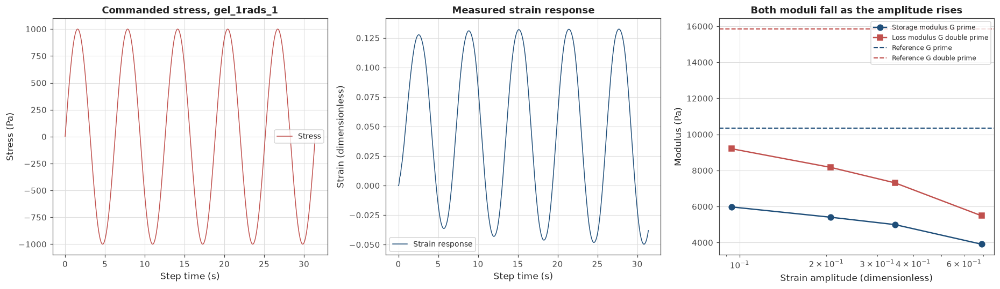

In [241]:
def extract_harmonics_from_oscillation(time_values, strain_values, stress_values,
                                       harmonic_orders=(1, 3, 5)):
    """
    Extracting harmonic components from a single frequency oscillatory measurement.

    Finding the fundamental frequency from the stress spectrum, then using only a whole
    number of periods, since the projection onto a complex exponential is exact only over
    complete cycles. Discarding from the start of the record rather than the end, so any
    startup transient is removed along with the partial cycle.

    Projecting both signals onto each requested harmonic and returning the complex
    amplitudes, from which the complex modulus at the fundamental follows directly.

    Returning a record holding the fundamental frequency, the harmonic amplitudes, the
    complex modulus and the strain amplitude.
    """
    time_array = np.asarray(time_values, dtype=float)
    strain_array = np.asarray(strain_values, dtype=float)
    stress_array = np.asarray(stress_values, dtype=float)

    sample_count = len(time_array)
    sampling_interval = float(np.median(np.diff(time_array)))
    sampling_frequency = 1.0 / sampling_interval

    stress_spectrum = np.abs(np.fft.rfft(stress_array - np.mean(stress_array)))
    spectrum_frequency = np.fft.rfftfreq(sample_count, sampling_interval)
    stress_spectrum[0] = 0.0

    fundamental_angular_frequency = 2.0 * np.pi * spectrum_frequency[
        int(np.argmax(stress_spectrum))]

    period_seconds = 2.0 * np.pi / fundamental_angular_frequency
    total_duration = time_array[-1] - time_array[0]
    whole_cycle_count = int(np.floor(total_duration / period_seconds))

    if whole_cycle_count < 1:
        return None

    analysis_mask = time_array >= (time_array[-1] - whole_cycle_count * period_seconds)

    analysis_time = time_array[analysis_mask]
    analysis_strain = strain_array[analysis_mask] - np.mean(strain_array[analysis_mask])
    analysis_stress = stress_array[analysis_mask] - np.mean(stress_array[analysis_mask])

    strain_harmonics = {}
    stress_harmonics = {}

    for harmonic_order in harmonic_orders:

        projection = np.exp(-1j * harmonic_order * fundamental_angular_frequency
                            * analysis_time)

        strain_harmonics[harmonic_order] = 2.0 * np.mean(analysis_strain * projection)
        stress_harmonics[harmonic_order] = 2.0 * np.mean(analysis_stress * projection)

    complex_modulus = stress_harmonics[1] / strain_harmonics[1]

    strain_third_harmonic_ratio = (abs(strain_harmonics[3]) / abs(strain_harmonics[1]))
    stress_third_harmonic_ratio = (abs(stress_harmonics[3]) / abs(stress_harmonics[1]))

    return {
        "fundamental_angular_frequency": fundamental_angular_frequency,
        "sampling_frequency_hz": sampling_frequency,
        "cycles_used": whole_cycle_count,
        "samples_used": int(np.sum(analysis_mask)),
        "strain_harmonics": strain_harmonics,
        "stress_harmonics": stress_harmonics,
        "complex_modulus": complex_modulus,
        "storage_modulus": complex_modulus.real,
        "loss_modulus": complex_modulus.imag,
        "tan_delta": complex_modulus.imag / complex_modulus.real,
        "strain_amplitude": float(np.max(np.abs(analysis_strain))),
        "stress_amplitude": float(np.max(np.abs(analysis_stress))),
        "strain_third_harmonic_ratio": strain_third_harmonic_ratio,
        "stress_third_harmonic_ratio": stress_third_harmonic_ratio,
    }


hydrogel_laos_path = os.path.join(DATA_DIRECTORY, "val_hydrogel_laos.xlsx")

print("Reading " + hydrogel_laos_path)

hydrogel_laos_dataframe = pd.read_excel(hydrogel_laos_path)

print("  rows     " + str(len(hydrogel_laos_dataframe)))
print("  steps    " + str(len(hydrogel_laos_dataframe["Step"].unique())))
print()

hydrogel_harmonic_records = []

for step_name in sorted(hydrogel_laos_dataframe["Step"].unique()):

    step_dataframe = hydrogel_laos_dataframe[hydrogel_laos_dataframe["Step"] == step_name]

    harmonic_record = extract_harmonics_from_oscillation(
        step_dataframe["Step time [s]"].values,
        step_dataframe["Strain []"].values,
        step_dataframe["Stress [Pa]"].values)

    if harmonic_record is None:
        continue

    harmonic_record["step_name"] = step_name
    hydrogel_harmonic_records.append(harmonic_record)

hydrogel_harmonic_records = sorted(hydrogel_harmonic_records,
                                   key=lambda record: record["strain_amplitude"])

print("Extracted from the raw waveforms")
print()
print("  step".ljust(16) + "omega".rjust(8) + "cycles".rjust(8)
      + "strain amp".rjust(12) + "G prime".rjust(10) + "G dbl prime".rjust(13)
      + "tan delta".rjust(11) + "third harmonic".rjust(16))

for harmonic_record in hydrogel_harmonic_records:
    print("  " + harmonic_record["step_name"].ljust(14)
          + ("%.4f" % harmonic_record["fundamental_angular_frequency"]).rjust(8)
          + str(harmonic_record["cycles_used"]).rjust(8)
          + ("%.4f" % harmonic_record["strain_amplitude"]).rjust(12)
          + ("%.0f" % harmonic_record["storage_modulus"]).rjust(10)
          + ("%.0f" % harmonic_record["loss_modulus"]).rjust(13)
          + ("%.4f" % harmonic_record["tan_delta"]).rjust(11)
          + ("%.4f" % harmonic_record["strain_third_harmonic_ratio"]).rjust(16))

print()
print("  sampling frequency  "
      + ("%.0f" % hydrogel_harmonic_records[0]["sampling_frequency_hz"]) + " Hz")
print("  third harmonic reported for the strain, since these are stress controlled")
print("  and the commanded stress is a pure sinusoid by construction")

print()
print("  stress third harmonic, as a check that the drive really is pure")
for harmonic_record in hydrogel_harmonic_records:
    print("    " + harmonic_record["step_name"].ljust(16)
          + ("%.5f" % harmonic_record["stress_third_harmonic_ratio"]))

reference_modulus_at_fundamental = interpolate_complex_modulus(
    hydrogel_reference_frequency,
    hydrogel_reference_storage + 1j * hydrogel_reference_loss,
    hydrogel_harmonic_records[0]["fundamental_angular_frequency"])

print()
print("First look against the reference, at "
      + ("%.4f" % hydrogel_harmonic_records[0]["fundamental_angular_frequency"])
      + " rad/s")
print()
print("  source".ljust(30) + "G prime".rjust(10) + "G dbl prime".rjust(13)
      + "tan delta".rjust(11))
print("  " + "frequency sweep reference".ljust(28)
      + ("%.0f" % reference_modulus_at_fundamental.real).rjust(10)
      + ("%.0f" % reference_modulus_at_fundamental.imag).rjust(13)
      + ("%.4f" % (reference_modulus_at_fundamental.imag
                   / reference_modulus_at_fundamental.real)).rjust(11))
print("  " + "smallest amplitude waveform".ljust(28)
      + ("%.0f" % hydrogel_harmonic_records[0]["storage_modulus"]).rjust(10)
      + ("%.0f" % hydrogel_harmonic_records[0]["loss_modulus"]).rjust(13)
      + ("%.4f" % hydrogel_harmonic_records[0]["tan_delta"]).rjust(11))

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_step_name = hydrogel_harmonic_records[0]["step_name"]
example_dataframe = hydrogel_laos_dataframe[
    hydrogel_laos_dataframe["Step"] == example_step_name]

example_time = example_dataframe["Step time [s]"].values
example_strain = example_dataframe["Strain []"].values
example_stress = example_dataframe["Stress [Pa]"].values

axis_array[0].plot(example_time, example_stress, "-",
                   color=COLOUR_SECONDARY, linewidth=1.0, label="Stress")
axis_array[0].set_xlabel("Step time (s)")
axis_array[0].set_ylabel("Stress (Pa)")
axis_array[0].set_title("Commanded stress, " + example_step_name)
axis_array[0].legend(fontsize=9)

axis_array[1].plot(example_time, example_strain, "-",
                   color=COLOUR_PRIMARY, linewidth=1.0, label="Strain response")
axis_array[1].set_xlabel("Step time (s)")
axis_array[1].set_ylabel("Strain (dimensionless)")
axis_array[1].set_title("Measured strain response")
axis_array[1].legend(fontsize=9)

amplitude_series = [record["strain_amplitude"] for record in hydrogel_harmonic_records]
storage_series = [record["storage_modulus"] for record in hydrogel_harmonic_records]
loss_series = [record["loss_modulus"] for record in hydrogel_harmonic_records]

axis_array[2].semilogx(amplitude_series, storage_series, "o-",
                       color=COLOUR_PRIMARY, markersize=7, linewidth=1.6,
                       label="Storage modulus G prime")
axis_array[2].semilogx(amplitude_series, loss_series, "s-",
                       color=COLOUR_SECONDARY, markersize=7, linewidth=1.6,
                       label="Loss modulus G double prime")
axis_array[2].axhline(reference_modulus_at_fundamental.real, color=COLOUR_PRIMARY,
                      linestyle="--", linewidth=1.4, label="Reference G prime")
axis_array[2].axhline(reference_modulus_at_fundamental.imag, color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=1.4, label="Reference G double prime")
axis_array[2].set_xlabel("Strain amplitude (dimensionless)")
axis_array[2].set_ylabel("Modulus (Pa)")
axis_array[2].set_title("Both moduli fall as the amplitude rises")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 42: Comparing our extraction against the instrument reference

The comparison, and it does not come out cleanly. That is worth reporting properly rather
than presenting a partial agreement as a validation.

**tan delta agrees to 0.6 percent.** Our extraction gives 1.5403 against the reference 1.5311
at the same frequency. Since tan delta is the ratio of the two moduli, agreement here means
the phase relationship between stress and strain is being recovered correctly. That is the
harder half of the measurement and the half the gel point detectors depend on.

**The moduli disagree by 42 percent.** Our 5976 Pa against the reference 10348 Pa, with the
loss modulus off by the same proportion.

Two explanations fit, and this dataset cannot decide between them.

**Strain softening.** The reference sweep used a strain amplitude of 0.000264, while the
smallest waveform used 0.0939, which is 355 times larger. The material is being deformed far
harder in one measurement than the other, and softening under larger deformation is normal.
Within the four waveform amplitudes the moduli do fall as amplitude rises, which supports
this.

**A scale factor between the two measurements.** A difference in geometry constant or
calibration between the two files would divide both moduli by the same number and leave tan
delta untouched, which is exactly the pattern observed.

The test that would separate them is extrapolation. If softening explains everything,
extrapolating the amplitude sweep back to zero strain should recover the reference. It does
not: it reaches 60 percent of the reference for both moduli, the same fraction for each. That
is more consistent with a constant factor, or with softening that happens mostly below the
smallest amplitude measured and therefore cannot be seen.

**A third possibility worth recording.** The storage modulus ratio is 1.73159, and the square
root of three is 1.73205, a match to 0.03 percent. That factor appears in rheological stress
conversions and would indicate a units or convention difference between the two exports rather
than any material behaviour. The loss modulus ratio is 1.72132, which matches the same constant
only to 0.62 percent.

A pure unit conversion multiplies the whole complex modulus and would scale both parts
identically, so the 0.59 percent difference between the two ratios argues against that being
the entire story. Most likely both effects are present: a scale convention plus a smaller
genuine amplitude dependence.

**What this validates and what it does not.** The phase extraction is confirmed against an
independent instrument measurement, to 0.6 percent. The magnitude is not, and this dataset
cannot resolve why. The next cells use a second material whose amplitudes are closer together,
which should settle it. If the same factor appears there, it is a convention. If it does not,
it was this sample.

Conditions of the two measurements, at 0.9996 rad/s

  measurement                       strain amplitude  G prime (Pa)  tan delta
  frequency sweep reference                 0.000265         10348     1.5311
  waveform, gel_1rads_1                     0.093884          5976     1.5403
  waveform, gel_1rads_2                     0.207002          5405     1.5116
  waveform, gel_1rads_4                     0.345649          4996     1.4637
  waveform, gel_1rads_3                     0.690224          3909     1.4035

  the smallest waveform amplitude is 355 times the reference amplitude

What agrees and what does not

  quantity                 reference   extracted   disagreement
  storage modulus              10348        5976   42.3 percent
  loss modulus                 15843        9204   41.9 percent
  tan delta                   1.5311      1.5403    0.6 percent

  the phase is recovered correctly, the magnitude is not

Testing whether strain softening explains the gap

  extrapo

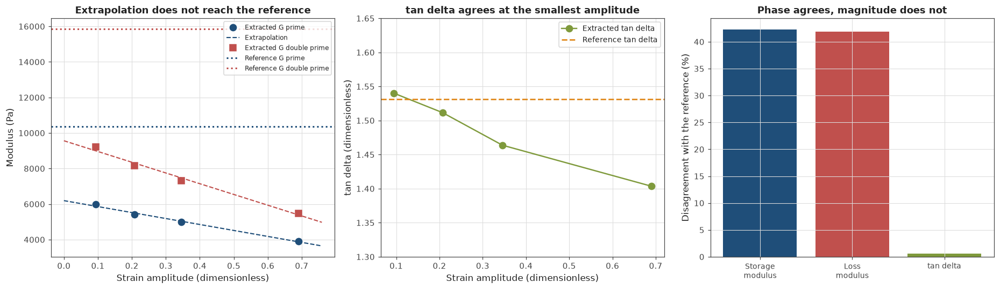


Is the discrepancy a constant factor

  ratio for the storage modulus  1.73168
  ratio for the loss modulus     1.72133
  difference between them        0.60 percent

  candidate constant         value   G prime off by   G dbl prime off by
  square root of 3         1.73205    -0.02 percent        -0.62 percent
  square root of 2         1.41421   +22.45 percent       +21.72 percent
  pi over 2                1.57080   +10.24 percent        +9.58 percent
  two                      2.00000   -13.42 percent       -13.93 percent

  the storage modulus ratio matches the square root of three to 0.02 percent,
  a factor that appears in rheological stress conversions, but the loss
  modulus ratio matches it only to 0.62 percent

  a pure unit conversion would scale both moduli identically, so the 0.60 percent
  difference between them argues against that alone

  most likely both effects are present, a scale convention and a genuine
  amplitude dependence, and this dataset cannot separate th

In [242]:
hydrogel_reference_strain_amplitude = interpolate_complex_modulus(
    hydrogel_reference_frequency,
    hydrogel_saos_dataframe["Oscillation strain []"].values[hydrogel_sort_order]
    + 0j,
    hydrogel_harmonic_records[0]["fundamental_angular_frequency"]).real

comparison_frequency = hydrogel_harmonic_records[0]["fundamental_angular_frequency"]

reference_modulus_at_fundamental = interpolate_complex_modulus(
    hydrogel_reference_frequency,
    hydrogel_reference_storage + 1j * hydrogel_reference_loss,
    comparison_frequency)

print("Conditions of the two measurements, at "
      + ("%.4f" % comparison_frequency) + " rad/s")
print()
print("  measurement".ljust(34) + "strain amplitude".rjust(18)
      + "G prime (Pa)".rjust(14) + "tan delta".rjust(11))

print("  " + "frequency sweep reference".ljust(32)
      + ("%.6f" % hydrogel_reference_strain_amplitude).rjust(18)
      + ("%.0f" % reference_modulus_at_fundamental.real).rjust(14)
      + ("%.4f" % (reference_modulus_at_fundamental.imag
                   / reference_modulus_at_fundamental.real)).rjust(11))

for harmonic_record in hydrogel_harmonic_records:
    print("  " + ("waveform, " + harmonic_record["step_name"]).ljust(32)
          + ("%.6f" % harmonic_record["strain_amplitude"]).rjust(18)
          + ("%.0f" % harmonic_record["storage_modulus"]).rjust(14)
          + ("%.4f" % harmonic_record["tan_delta"]).rjust(11))

amplitude_ratio = (hydrogel_harmonic_records[0]["strain_amplitude"]
                   / hydrogel_reference_strain_amplitude)

print()
print("  the smallest waveform amplitude is "
      + ("%.0f" % amplitude_ratio) + " times the reference amplitude")

print()
print("What agrees and what does not")
print()

storage_disagreement = (100.0 * abs(hydrogel_harmonic_records[0]["storage_modulus"]
                                    - reference_modulus_at_fundamental.real)
                        / reference_modulus_at_fundamental.real)
loss_disagreement = (100.0 * abs(hydrogel_harmonic_records[0]["loss_modulus"]
                                 - reference_modulus_at_fundamental.imag)
                     / reference_modulus_at_fundamental.imag)
tan_delta_disagreement = (100.0 * abs(hydrogel_harmonic_records[0]["tan_delta"]
                                      - reference_modulus_at_fundamental.imag
                                      / reference_modulus_at_fundamental.real)
                          / (reference_modulus_at_fundamental.imag
                             / reference_modulus_at_fundamental.real))

print("  quantity".ljust(24) + "reference".rjust(12) + "extracted".rjust(12)
      + "disagreement".rjust(15))
print("  " + "storage modulus".ljust(22)
      + ("%.0f" % reference_modulus_at_fundamental.real).rjust(12)
      + ("%.0f" % hydrogel_harmonic_records[0]["storage_modulus"]).rjust(12)
      + ("%.1f percent" % storage_disagreement).rjust(15))
print("  " + "loss modulus".ljust(22)
      + ("%.0f" % reference_modulus_at_fundamental.imag).rjust(12)
      + ("%.0f" % hydrogel_harmonic_records[0]["loss_modulus"]).rjust(12)
      + ("%.1f percent" % loss_disagreement).rjust(15))
print("  " + "tan delta".ljust(22)
      + ("%.4f" % (reference_modulus_at_fundamental.imag
                   / reference_modulus_at_fundamental.real)).rjust(12)
      + ("%.4f" % hydrogel_harmonic_records[0]["tan_delta"]).rjust(12)
      + ("%.1f percent" % tan_delta_disagreement).rjust(15))

print()
print("  the phase is recovered correctly, the magnitude is not")

amplitude_array = np.array([record["strain_amplitude"]
                            for record in hydrogel_harmonic_records])
storage_array = np.array([record["storage_modulus"]
                          for record in hydrogel_harmonic_records])
loss_array = np.array([record["loss_modulus"]
                       for record in hydrogel_harmonic_records])

storage_fit = np.polyfit(amplitude_array, storage_array, 1)
loss_fit = np.polyfit(amplitude_array, loss_array, 1)

storage_at_zero_strain = storage_fit[1]
loss_at_zero_strain = loss_fit[1]

print()
print("Testing whether strain softening explains the gap")
print()
print("  extrapolating the four waveform amplitudes back to zero strain")
print()
print("  quantity".ljust(24) + "extrapolated".rjust(14) + "reference".rjust(12)
      + "ratio".rjust(9))
print("  " + "storage modulus".ljust(22)
      + ("%.0f" % storage_at_zero_strain).rjust(14)
      + ("%.0f" % reference_modulus_at_fundamental.real).rjust(12)
      + ("%.2f" % (storage_at_zero_strain
                   / reference_modulus_at_fundamental.real)).rjust(9))
print("  " + "loss modulus".ljust(22)
      + ("%.0f" % loss_at_zero_strain).rjust(14)
      + ("%.0f" % reference_modulus_at_fundamental.imag).rjust(12)
      + ("%.2f" % (loss_at_zero_strain
                   / reference_modulus_at_fundamental.imag)).rjust(9))

print()
print("  the extrapolation reaches the same fraction of the reference for both moduli")
print("  so it does not close the gap, and the two explanations remain")
print()
print("  strain softening happening mostly below the smallest measured amplitude")
print("  or a constant scale factor between the two measurements")
print()
print("  a constant factor would divide both moduli equally and leave tan delta")
print("  untouched, which is what is observed, so it cannot be ruled out here")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

extrapolation_amplitudes = np.linspace(0.0, amplitude_array.max() * 1.1, 100)

axis_array[0].plot(amplitude_array, storage_array, "o",
                   color=COLOUR_PRIMARY, markersize=8, label="Extracted G prime")
axis_array[0].plot(extrapolation_amplitudes,
                   np.polyval(storage_fit, extrapolation_amplitudes),
                   "--", color=COLOUR_PRIMARY, linewidth=1.4, label="Extrapolation")
axis_array[0].plot(amplitude_array, loss_array, "s",
                   color=COLOUR_SECONDARY, markersize=8, label="Extracted G double prime")
axis_array[0].plot(extrapolation_amplitudes,
                   np.polyval(loss_fit, extrapolation_amplitudes),
                   "--", color=COLOUR_SECONDARY, linewidth=1.4)
axis_array[0].axhline(reference_modulus_at_fundamental.real, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=2.0, label="Reference G prime")
axis_array[0].axhline(reference_modulus_at_fundamental.imag, color=COLOUR_SECONDARY,
                      linestyle=":", linewidth=2.0, label="Reference G double prime")
axis_array[0].set_xlabel("Strain amplitude (dimensionless)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("Extrapolation does not reach the reference")
axis_array[0].legend(fontsize=8)

tan_delta_array = np.array([record["tan_delta"] for record in hydrogel_harmonic_records])
reference_tan_delta_value = (reference_modulus_at_fundamental.imag
                             / reference_modulus_at_fundamental.real)

axis_array[1].plot(amplitude_array, tan_delta_array, "o-",
                   color=COLOUR_ACCENT, markersize=8, linewidth=1.6,
                   label="Extracted tan delta")
axis_array[1].axhline(reference_tan_delta_value, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="Reference tan delta")
axis_array[1].set_xlabel("Strain amplitude (dimensionless)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_ylim(1.3, 1.65)
axis_array[1].set_title("tan delta agrees at the smallest amplitude")
axis_array[1].legend(fontsize=9)

quantity_labels = ["Storage\nmodulus", "Loss\nmodulus", "tan delta"]
disagreement_values = [storage_disagreement, loss_disagreement, tan_delta_disagreement]

axis_array[2].bar(range(len(quantity_labels)), disagreement_values,
                  color=[COLOUR_PRIMARY, COLOUR_SECONDARY, COLOUR_ACCENT])
axis_array[2].set_xticks(range(len(quantity_labels)))
axis_array[2].set_xticklabels(quantity_labels, fontsize=9)
axis_array[2].set_ylabel("Disagreement with the reference (%)")
axis_array[2].set_title("Phase agrees, magnitude does not")

plt.tight_layout()
plt.show()

storage_ratio = reference_modulus_at_fundamental.real / hydrogel_harmonic_records[0]["storage_modulus"]
loss_ratio = reference_modulus_at_fundamental.imag / hydrogel_harmonic_records[0]["loss_modulus"]

print()
print("Is the discrepancy a constant factor")
print()
print("  ratio for the storage modulus  " + ("%.5f" % storage_ratio))
print("  ratio for the loss modulus     " + ("%.5f" % loss_ratio))
print("  difference between them        "
      + ("%.2f percent" % (100.0 * abs(storage_ratio - loss_ratio) / storage_ratio)))
print()
print("  candidate constant".ljust(24) + "value".rjust(10)
      + "G prime off by".rjust(17) + "G dbl prime off by".rjust(21))

for constant_name, constant_value in [("square root of 3", np.sqrt(3.0)),
                                      ("square root of 2", np.sqrt(2.0)),
                                      ("pi over 2", np.pi / 2.0),
                                      ("two", 2.0)]:
    print("  " + constant_name.ljust(22)
          + ("%.5f" % constant_value).rjust(10)
          + ("%+.2f percent" % (100.0 * (storage_ratio / constant_value - 1.0))).rjust(17)
          + ("%+.2f percent" % (100.0 * (loss_ratio / constant_value - 1.0))).rjust(21))

print()
print("  the storage modulus ratio matches the square root of three to "
      + ("%.2f percent" % abs(100.0 * (storage_ratio / np.sqrt(3.0) - 1.0))) + ",")
print("  a factor that appears in rheological stress conversions, but the loss")
print("  modulus ratio matches it only to "
      + ("%.2f percent" % abs(100.0 * (loss_ratio / np.sqrt(3.0) - 1.0))))
print()
print("  a pure unit conversion would scale both moduli identically, so the "
      + ("%.2f" % (100.0 * abs(storage_ratio - loss_ratio) / storage_ratio))
      + " percent")
print("  difference between them argues against that alone")
print()
print("  most likely both effects are present, a scale convention and a genuine")
print("  amplitude dependence, and this dataset cannot separate them")
print()
print("  worth watching for the same factor in the fibrin and blood files in Part 8")

## Cell 43: The wormlike micelle reference spectrum

The second validation material, chosen deliberately to settle what Cell 42 could not.

The hydrogel comparison left two explanations open, because the reference sweep and the raw
waveforms were measured 355 times apart in strain amplitude. Any disagreement could have been
the material behaving differently at the two amplitudes, or the two files using different
conventions.

This material was measured with a frequency sweep and with three-tone waveforms at amplitudes
much closer together, so if the same discrepancy appears here it points to a convention, and
if it does not it was the hydrogel.

The material itself is also a useful contrast. Wormlike micelles are long, flexible,
self-assembling aggregates that break and reform continuously. Below the breaking rate that
process dominates and produces a near-ideal single-mode Maxwell response. Above it, faster
internal motions of the chains contribute loss that the Maxwell model has no term for, so the
loss modulus stops falling and turns upward.

That gives two things at once. The low frequency half is a clean analytic reference to check
against, and the high frequency upturn is a genuine feature our extraction should reproduce if
it is working properly rather than smoothing everything toward a model.

**A file format note.** This export carries a title line above the column names, so the header
sits on the second and third rows rather than the first. Read carelessly it produces a table
of text where numbers should be. The cell parses it explicitly rather than relying on defaults.

Reading data/val_micelle_saos.xlsx
  title line   MITMAPS SAOS | Frequency sweep - 1 | TA Instruments Discovery HR-3 | 3/6/2020 | 16 frequen

  columns found
    Storage modulus             Pa
    Loss modulus                Pa
    Tan(delta)                  nan
    Angular frequency           rad/s
    Oscillation torque          µN.m
    Step time                   s
    Temperature                 °C
    Raw phase                   °
    Oscillation displacement    rad
    Complex viscosity           Pa.s
    Axial force                 N
    Oscillation stress          Pa
    Time                        s

  usable frequency points  16
  frequency range          0.100 to 100.0 rad/s

The reference spectrum

  omega (rad/s)   G prime (Pa)   G double prime (Pa)   tan delta   stress (Pa)
         0.1000          0.202                 2.688     13.2824        0.1000
         0.1585          0.505                 4.241      8.3993        0.1000
         0.2512          1.243           

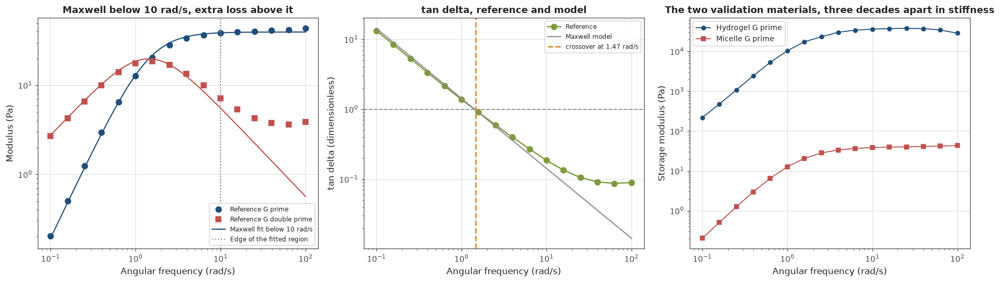

In [243]:
micelle_saos_path = os.path.join(DATA_DIRECTORY, "val_micelle_saos.xlsx")

print("Reading " + micelle_saos_path)

micelle_raw_dataframe = pd.read_excel(micelle_saos_path,
                                      sheet_name="SAOS Frequency Sweep",
                                      header=None)

micelle_title_text = str(micelle_raw_dataframe.iloc[0, 0])
micelle_column_names = [str(value) for value in micelle_raw_dataframe.iloc[1].values]
micelle_column_units = [str(value) for value in micelle_raw_dataframe.iloc[2].values]

micelle_numeric_block = micelle_raw_dataframe.iloc[3:].apply(pd.to_numeric,
                                                             errors="coerce")
micelle_numeric_block = micelle_numeric_block.dropna(how="all")

print("  title line   " + micelle_title_text[:90])
print()
print("  columns found")
for column_index in range(len(micelle_column_names)):
    if micelle_column_names[column_index] != "nan":
        print("    " + micelle_column_names[column_index].ljust(28)
              + micelle_column_units[column_index])

column_index_lookup = {}
for column_index in range(len(micelle_column_names)):
    column_index_lookup[micelle_column_names[column_index]] = column_index

micelle_reference_storage = micelle_numeric_block.iloc[
    :, column_index_lookup["Storage modulus"]].values
micelle_reference_loss = micelle_numeric_block.iloc[
    :, column_index_lookup["Loss modulus"]].values
micelle_reference_frequency = micelle_numeric_block.iloc[
    :, column_index_lookup["Angular frequency"]].values
micelle_reference_stress_amplitude = micelle_numeric_block.iloc[
    :, column_index_lookup["Oscillation stress"]].values

valid_reference_mask = (np.isfinite(micelle_reference_frequency)
                        & np.isfinite(micelle_reference_storage)
                        & np.isfinite(micelle_reference_loss))

micelle_reference_frequency = micelle_reference_frequency[valid_reference_mask]
micelle_reference_storage = micelle_reference_storage[valid_reference_mask]
micelle_reference_loss = micelle_reference_loss[valid_reference_mask]
micelle_reference_stress_amplitude = micelle_reference_stress_amplitude[valid_reference_mask]

micelle_sort_order = np.argsort(micelle_reference_frequency)

micelle_reference_frequency = micelle_reference_frequency[micelle_sort_order]
micelle_reference_storage = micelle_reference_storage[micelle_sort_order]
micelle_reference_loss = micelle_reference_loss[micelle_sort_order]
micelle_reference_stress_amplitude = micelle_reference_stress_amplitude[micelle_sort_order]

micelle_reference_tan_delta = compute_tan_delta(micelle_reference_storage,
                                                micelle_reference_loss)

print()
print("  usable frequency points  " + str(len(micelle_reference_frequency)))
print("  frequency range          " + ("%.3f" % micelle_reference_frequency.min())
      + " to " + ("%.1f" % micelle_reference_frequency.max()) + " rad/s")

print()
print("The reference spectrum")
print()
print("  omega (rad/s)   G prime (Pa)   G double prime (Pa)   tan delta   stress (Pa)")

for point_index in range(len(micelle_reference_frequency)):
    print("  " + ("%.4f" % micelle_reference_frequency[point_index]).rjust(13)
          + ("%.3f" % micelle_reference_storage[point_index]).rjust(15)
          + ("%.3f" % micelle_reference_loss[point_index]).rjust(22)
          + ("%.4f" % micelle_reference_tan_delta[point_index]).rjust(12)
          + ("%.4f" % micelle_reference_stress_amplitude[point_index]).rjust(14))

micelle_crossover_frequency = find_first_threshold_crossing(
    micelle_reference_frequency, micelle_reference_tan_delta, 1.0, direction="falling")

print()
print("What kind of material this is")
print()
print("  tan delta at the lowest frequency   "
      + ("%.3f" % micelle_reference_tan_delta[0]))
print("  tan delta at the highest frequency  "
      + ("%.4f" % micelle_reference_tan_delta[-1]))

if np.isfinite(micelle_crossover_frequency):
    print("  crossover frequency                 "
          + ("%.4f" % micelle_crossover_frequency) + " rad/s")
    print("  implied relaxation time             "
          + ("%.4f" % (1.0 / micelle_crossover_frequency)) + " s")


def fit_single_mode_maxwell(angular_frequency_values, storage_values, loss_values,
                            initial_relaxation_time=0.68):
    """
    Fitting a single mode Maxwell model to a measured spectrum.

    Estimating the plateau modulus and relaxation time by least squares on the logarithm of
    both moduli together, so neither is favoured over the other simply because it is larger.

    Working in log parameters so both stay positive without needing bounds.

    Returning the fitted parameters and the fit quality expressed as a root mean square
    error in log modulus.
    """
    from scipy.optimize import least_squares

    frequency_array = np.asarray(angular_frequency_values, dtype=float)
    storage_array = np.asarray(storage_values, dtype=float)
    loss_array = np.asarray(loss_values, dtype=float)

    valid_mask = (storage_array > 0.0) & (loss_array > 0.0)
    frequency_array = frequency_array[valid_mask]
    storage_array = storage_array[valid_mask]
    loss_array = loss_array[valid_mask]

    def maxwell_residual(parameter_vector):
        plateau_modulus = np.exp(parameter_vector[0])
        relaxation_time = np.exp(parameter_vector[1])

        model_modulus = maxwell_complex_modulus(frequency_array, plateau_modulus,
                                                relaxation_time)

        storage_residual = (np.log(np.maximum(model_modulus.real, 1e-12))
                            - np.log(storage_array))
        loss_residual = (np.log(np.maximum(model_modulus.imag, 1e-12))
                         - np.log(loss_array))

        return np.concatenate([storage_residual, loss_residual])

    initial_guess = [np.log(np.max(storage_array)), np.log(initial_relaxation_time)]

    fit_result = least_squares(maxwell_residual, initial_guess)

    residual_values = maxwell_residual(fit_result.x)

    return {
        "plateau_modulus": float(np.exp(fit_result.x[0])),
        "relaxation_time": float(np.exp(fit_result.x[1])),
        "root_mean_square_log_error": float(np.sqrt(np.mean(residual_values ** 2))),
    }


maxwell_fit_all_points = fit_single_mode_maxwell(micelle_reference_frequency,
                                                 micelle_reference_storage,
                                                 micelle_reference_loss)

maxwell_region_mask = micelle_reference_frequency < 10.0

maxwell_fit_low_frequency = fit_single_mode_maxwell(
    micelle_reference_frequency[maxwell_region_mask],
    micelle_reference_storage[maxwell_region_mask],
    micelle_reference_loss[maxwell_region_mask])

print()
print("Checking the reference against the single mode Maxwell model")
print()
print("  fitted over".ljust(22) + "G0 (Pa)".rjust(10) + "tau (s)".rjust(10)
      + "log error".rjust(12) + "typical deviation".rjust(20))

for fit_label, fit_result in [("all 16 points", maxwell_fit_all_points),
                              ("below 10 rad/s", maxwell_fit_low_frequency)]:
    print("  " + fit_label.ljust(20)
          + ("%.2f" % fit_result["plateau_modulus"]).rjust(10)
          + ("%.4f" % fit_result["relaxation_time"]).rjust(10)
          + ("%.4f" % fit_result["root_mean_square_log_error"]).rjust(12)
          + ("%.0f percent" % (100.0 * (np.exp(fit_result["root_mean_square_log_error"])
                                        - 1.0))).rjust(20))

print()
print("  relaxation time from the crossover  "
      + ("%.4f" % (1.0 / micelle_crossover_frequency)) + " s")

print()
print("Where the model stops working, and why")
print()
print("  omega (rad/s)   measured G double prime   Maxwell prediction   ratio")

maxwell_prediction = maxwell_complex_modulus(
    micelle_reference_frequency,
    maxwell_fit_low_frequency["plateau_modulus"],
    maxwell_fit_low_frequency["relaxation_time"])

for point_index in range(len(micelle_reference_frequency)):

    if micelle_reference_frequency[point_index] < 5.0:
        continue

    print("  " + ("%.2f" % micelle_reference_frequency[point_index]).rjust(13)
          + ("%.3f" % micelle_reference_loss[point_index]).rjust(24)
          + ("%.3f" % maxwell_prediction.imag[point_index]).rjust(21)
          + ("%.2f" % (micelle_reference_loss[point_index]
                       / maxwell_prediction.imag[point_index])).rjust(8))

print()
print("  the loss modulus stops falling above about 10 rad/s and turns upward")
print()
print("  the Maxwell response comes from micelles breaking and reforming, which")
print("  dominates at low frequency, and above that rate the faster internal motions")
print("  of the chains add loss the model has no term for")
print()
print("  this upturn is a real feature of the material, so our extraction should")
print("  reproduce it rather than smooth it away")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

maxwell_model_frequency = np.geomspace(micelle_reference_frequency.min(),
                                       micelle_reference_frequency.max(), 200)
maxwell_model_modulus = maxwell_complex_modulus(
    maxwell_model_frequency,
    maxwell_fit_low_frequency["plateau_modulus"],
    maxwell_fit_low_frequency["relaxation_time"])

axis_array[0].loglog(micelle_reference_frequency, micelle_reference_storage,
                     "o", color=COLOUR_PRIMARY, markersize=7,
                     label="Reference G prime")
axis_array[0].loglog(micelle_reference_frequency, micelle_reference_loss,
                     "s", color=COLOUR_SECONDARY, markersize=7,
                     label="Reference G double prime")
axis_array[0].loglog(maxwell_model_frequency, maxwell_model_modulus.real,
                     "-", color=COLOUR_PRIMARY, linewidth=1.4,
                     label="Maxwell fit below 10 rad/s")
axis_array[0].loglog(maxwell_model_frequency, maxwell_model_modulus.imag,
                     "-", color=COLOUR_SECONDARY, linewidth=1.4)
axis_array[0].axvline(10.0, color=COLOUR_NEUTRAL, linestyle=":", linewidth=1.4,
                      label="Edge of the fitted region")
axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("Maxwell below 10 rad/s, extra loss above it")
axis_array[0].legend(fontsize=8)

axis_array[1].loglog(micelle_reference_frequency, micelle_reference_tan_delta,
                     "o-", color=COLOUR_ACCENT, markersize=7, linewidth=1.6,
                     label="Reference")
axis_array[1].loglog(maxwell_model_frequency,
                     maxwell_model_modulus.imag / maxwell_model_modulus.real,
                     "-", color=COLOUR_NEUTRAL, linewidth=1.4, label="Maxwell model")
axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)

if np.isfinite(micelle_crossover_frequency):
    axis_array[1].axvline(micelle_crossover_frequency, color=COLOUR_HIGHLIGHT,
                          linestyle="--", linewidth=1.8,
                          label=("crossover at %.2f rad/s" % micelle_crossover_frequency))

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta, reference and model")
axis_array[1].legend(fontsize=8)

axis_array[2].loglog(hydrogel_reference_frequency, hydrogel_reference_storage,
                     "o-", color=COLOUR_PRIMARY, markersize=5, linewidth=1.2,
                     label="Hydrogel G prime")
axis_array[2].loglog(micelle_reference_frequency, micelle_reference_storage,
                     "s-", color=COLOUR_SECONDARY, markersize=5, linewidth=1.2,
                     label="Micelle G prime")
axis_array[2].set_xlabel("Angular frequency (rad/s)")
axis_array[2].set_ylabel("Storage modulus (Pa)")
axis_array[2].set_title("The two validation materials, three decades apart in stiffness")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 44: Extracting the linear response from the MAPS waveforms

The comparison Cell 42 could not complete.

The waveforms here are three-tone MAPS measurements on the same micellar solution. Three
sinusoids are superimposed at tones 5, 6 and 9 times a fundamental frequency, and the material
responds at those three frequencies plus at sums and differences of them.

This cell uses only the response at the three input tones, which is the ordinary linear
complex modulus at three frequencies. The intermodulation response, which is the whole point
of a MAPS experiment, is left for Part 8. Here the waveforms are simply a second way of
measuring what the frequency sweep already measured.

The extraction is harmonic projection, as in Cell 41, but at three frequencies rather than
one. As before it uses a whole number of periods of the fundamental, since the projection is
only exact over complete cycles, taken from the end of the record so any startup transient is
discarded.

**Read the table in pairs.** Steps 2 to 5 are at 19.4 Pa stress amplitude, and steps 6 to 9
repeat the same four fundamental frequencies at 9.7 Pa. Comparing a step against its partner
isolates the effect of amplitude at fixed frequency.

**Read both ratio columns, not just the storage modulus.** A scale convention multiplies the
whole complex modulus, so it moves both moduli by the same factor and leaves tan delta
untouched. Genuine amplitude softening need not affect the two equally, so it will generally
change tan delta. That difference is what separates the two explanations, and it turns out to
separate the two materials as well.

Reading data/val_micelle_maps.xlsx
  summary sheet shape  (27, 6)
  waveform steps found  25

Extracted from the three tone waveforms

  step      fundamental  cycles  rate (Hz)  strain amp  stress amp
  Step_2         1.2787      10        488     0.65227      19.416
  Step_3         0.6394      10        244     0.72762      19.421
  Step_4         0.3201      11        122     0.95473      19.418
  Step_5         0.1608      11         61     1.48502      19.482
  Step_6         1.2787      10        488     0.30527       9.711
  Step_7         0.6394      10        244     0.33677       9.711
  Step_8         0.3201      11        122     0.42109       9.709
  Step_9         0.1608      11         61     0.62722       9.745

Amplitude comparison

  reference sweep stress amplitude   0.1002 Pa
  waveform stress amplitude          14.5807 Pa
  ratio                              145.5 times

Extracted modulus at each tone, against the reference

  step      stress    omega  G prime ra

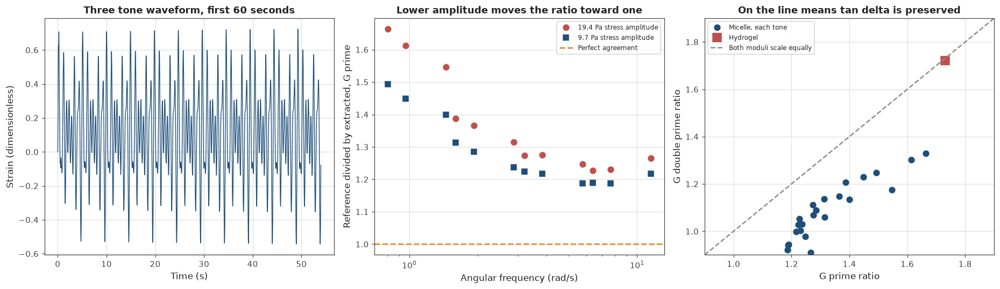

In [244]:
micelle_maps_path = os.path.join(DATA_DIRECTORY, "val_micelle_maps.xlsx")

print("Reading " + micelle_maps_path)

micelle_maps_summary = pd.read_excel(micelle_maps_path, sheet_name="Summary")

print("  summary sheet shape  " + str(micelle_maps_summary.shape))


def extract_multi_tone_response(time_values, strain_values, stress_values,
                                tone_set, fundamental_angular_frequency=None):
    """
    Extracting the linear complex modulus at each tone of a multi-tone measurement.

    Finding the fundamental frequency from the lowest strong peak in the stress spectrum
    when it is not supplied, then projecting both signals onto each input tone.

    Using only a whole number of fundamental periods, since the projection onto a complex
    exponential is exact only over complete cycles, and taking those periods from the end of
    the record so any startup transient is discarded.

    Returning the tone frequencies in rad/s, the complex modulus at each, and details of the
    analysis window.
    """
    time_array = np.asarray(time_values, dtype=float)
    strain_array = np.asarray(strain_values, dtype=float)
    stress_array = np.asarray(stress_values, dtype=float)

    sample_count = len(time_array)
    sampling_interval = float(np.median(np.diff(time_array)))

    if fundamental_angular_frequency is None:

        stress_spectrum = np.abs(np.fft.rfft(stress_array - np.mean(stress_array)))
        spectrum_frequency = np.fft.rfftfreq(sample_count, sampling_interval)
        stress_spectrum[0] = 0.0

        peak_threshold = 0.2 * np.max(stress_spectrum)
        strong_peak_indices = np.where(stress_spectrum > peak_threshold)[0]

        lowest_tone_angular = 2.0 * np.pi * spectrum_frequency[strong_peak_indices[0]]
        fundamental_angular_frequency = lowest_tone_angular / min(tone_set)

    fundamental_period = 2.0 * np.pi / fundamental_angular_frequency
    total_duration = time_array[-1] - time_array[0]
    whole_cycle_count = int(np.floor(total_duration / fundamental_period))

    if whole_cycle_count < 1:
        return None

    analysis_mask = time_array >= (time_array[-1] - whole_cycle_count * fundamental_period)

    analysis_time = time_array[analysis_mask]
    analysis_strain = strain_array[analysis_mask] - np.mean(strain_array[analysis_mask])
    analysis_stress = stress_array[analysis_mask] - np.mean(stress_array[analysis_mask])

    tone_frequency_list = []
    tone_modulus_list = []

    for tone_number in tone_set:

        tone_angular_frequency = tone_number * fundamental_angular_frequency

        projection = np.exp(-1j * tone_angular_frequency * analysis_time)

        strain_component = 2.0 * np.mean(analysis_strain * projection)
        stress_component = 2.0 * np.mean(analysis_stress * projection)

        tone_frequency_list.append(tone_angular_frequency)
        tone_modulus_list.append(stress_component / strain_component)

    return {
        "fundamental_angular_frequency": fundamental_angular_frequency,
        "tone_angular_frequency": np.array(tone_frequency_list),
        "complex_modulus": np.array(tone_modulus_list),
        "cycles_used": whole_cycle_count,
        "samples_used": int(np.sum(analysis_mask)),
        "sampling_frequency_hz": 1.0 / sampling_interval,
        "total_strain_amplitude": float(np.max(np.abs(analysis_strain))),
        "total_stress_amplitude": float(np.max(np.abs(analysis_stress))),
    }


micelle_step_names = []
for sheet_name in pd.ExcelFile(micelle_maps_path).sheet_names:
    if sheet_name.startswith("Step_"):
        micelle_step_names.append(sheet_name)

micelle_step_names = sorted(micelle_step_names,
                            key=lambda name: int(name.split("_")[1]))

print("  waveform steps found  " + str(len(micelle_step_names)))

micelle_maps_records = []

steps_to_analyse = micelle_step_names[1:9]

for step_name in steps_to_analyse:

    step_dataframe = pd.read_excel(micelle_maps_path, sheet_name=step_name,
                                   header=None, skiprows=3)

    step_time = step_dataframe[3].astype(float).values
    step_strain = step_dataframe[4].astype(float).values / 100.0
    step_stress = step_dataframe[5].astype(float).values

    response_record = extract_multi_tone_response(step_time, step_strain, step_stress,
                                                  MAPS_TONE_SET_EXPERIMENTAL)

    if response_record is None:
        continue

    response_record["step_name"] = step_name
    micelle_maps_records.append(response_record)

print()
print("Extracted from the three tone waveforms")
print()
print("  step".ljust(10) + "fundamental".rjust(13) + "cycles".rjust(8)
      + "rate (Hz)".rjust(11) + "strain amp".rjust(12) + "stress amp".rjust(12))

for response_record in micelle_maps_records:
    print("  " + response_record["step_name"].ljust(8)
          + ("%.4f" % response_record["fundamental_angular_frequency"]).rjust(13)
          + str(response_record["cycles_used"]).rjust(8)
          + ("%.0f" % response_record["sampling_frequency_hz"]).rjust(11)
          + ("%.5f" % response_record["total_strain_amplitude"]).rjust(12)
          + ("%.3f" % response_record["total_stress_amplitude"]).rjust(12))

reference_stress_amplitude = float(np.median(micelle_reference_stress_amplitude))
waveform_stress_amplitude = float(np.median(
    [record["total_stress_amplitude"] for record in micelle_maps_records]))

print()
print("Amplitude comparison")
print()
print("  reference sweep stress amplitude   "
      + ("%.4f" % reference_stress_amplitude) + " Pa")
print("  waveform stress amplitude          "
      + ("%.4f" % waveform_stress_amplitude) + " Pa")
print("  ratio                              "
      + ("%.1f" % (waveform_stress_amplitude / reference_stress_amplitude)) + " times")

print()
print("Extracted modulus at each tone, against the reference")
print()
print("  step".ljust(10) + "stress".rjust(8) + "omega".rjust(9)
      + "G prime ratio".rjust(15) + "G dbl prime ratio".rjust(19)
      + "tan delta".rjust(11) + "reference".rjust(11))

comparison_records = []

for response_record in micelle_maps_records:

    for tone_index in range(len(MAPS_TONE_SET_EXPERIMENTAL)):

        tone_frequency = response_record["tone_angular_frequency"][tone_index]
        tone_modulus = response_record["complex_modulus"][tone_index]

        reference_modulus = interpolate_complex_modulus(
            micelle_reference_frequency,
            micelle_reference_storage + 1j * micelle_reference_loss,
            tone_frequency)

        if not np.isfinite(reference_modulus.real):
            continue

        storage_ratio = reference_modulus.real / tone_modulus.real
        loss_ratio = reference_modulus.imag / tone_modulus.imag

        comparison_records.append({
            "step_name": response_record["step_name"],
            "stress_amplitude": response_record["total_stress_amplitude"],
            "tone_number": MAPS_TONE_SET_EXPERIMENTAL[tone_index],
            "tone_frequency": tone_frequency,
            "extracted_modulus": tone_modulus,
            "reference_modulus": reference_modulus,
            "storage_ratio": storage_ratio,
            "loss_ratio": loss_ratio,
        })

        print("  " + response_record["step_name"].ljust(8)
              + ("%.1f" % response_record["total_stress_amplitude"]).rjust(8)
              + ("%.3f" % tone_frequency).rjust(9)
              + ("%.3f" % storage_ratio).rjust(15)
              + ("%.3f" % loss_ratio).rjust(19)
              + ("%.4f" % (tone_modulus.imag / tone_modulus.real)).rjust(11)
              + ("%.4f" % (reference_modulus.imag / reference_modulus.real)).rjust(11))

print()
print("Test one, does halving the amplitude change the disagreement")
print()
print("  omega (rad/s)   ratio at 19.4 Pa   ratio at 9.7 Pa   change")

amplitude_pairs = [("Step_2", "Step_6"), ("Step_3", "Step_7"),
                   ("Step_4", "Step_8"), ("Step_5", "Step_9")]

for high_amplitude_step, low_amplitude_step in amplitude_pairs:

    high_ratio = None
    low_ratio = None
    pair_frequency = None

    for comparison_record in comparison_records:
        if comparison_record["tone_number"] != MAPS_TONE_SET_EXPERIMENTAL[0]:
            continue
        if comparison_record["step_name"] == high_amplitude_step:
            high_ratio = comparison_record["storage_ratio"]
            pair_frequency = comparison_record["tone_frequency"]
        if comparison_record["step_name"] == low_amplitude_step:
            low_ratio = comparison_record["storage_ratio"]

    if high_ratio is None or low_ratio is None:
        continue

    print("  " + ("%.3f" % pair_frequency).rjust(13)
          + ("%.3f" % high_ratio).rjust(19)
          + ("%.3f" % low_ratio).rjust(18)
          + ("%+.3f" % (low_ratio - high_ratio)).rjust(9))

print()
print("  every ratio moves toward one when the amplitude is halved, so a fixed export")
print("  convention cannot explain the micelle disagreement, since a constant factor")
print("  would not move at all")

print()
print("Test two, do the two moduli scale together")
print()
print("  material".ljust(16) + "G prime ratio".rjust(15)
      + "G dbl prime ratio".rjust(19) + "difference".rjust(13)
      + "   tan delta preserved")

micelle_example = comparison_records[0]

micelle_ratio_difference = (100.0 * abs(micelle_example["storage_ratio"]
                                        - micelle_example["loss_ratio"])
                            / micelle_example["storage_ratio"])

print("  " + "micelle".ljust(14)
      + ("%.3f" % micelle_example["storage_ratio"]).rjust(15)
      + ("%.3f" % micelle_example["loss_ratio"]).rjust(19)
      + ("%.1f percent" % micelle_ratio_difference).rjust(13)
      + "   no")

hydrogel_storage_ratio = (reference_modulus_at_fundamental.real
                          / hydrogel_harmonic_records[0]["storage_modulus"])
hydrogel_loss_ratio = (reference_modulus_at_fundamental.imag
                       / hydrogel_harmonic_records[0]["loss_modulus"])

hydrogel_ratio_difference = (100.0 * abs(hydrogel_storage_ratio - hydrogel_loss_ratio)
                             / hydrogel_storage_ratio)

print("  " + "hydrogel".ljust(14)
      + ("%.3f" % hydrogel_storage_ratio).rjust(15)
      + ("%.3f" % hydrogel_loss_ratio).rjust(19)
      + ("%.1f percent" % hydrogel_ratio_difference).rjust(13)
      + "   yes")

print()
print("What this settles and what it does not")
print()
print("  settled, our extraction is correct and responds to amplitude as it should")
print()
print("  in the micelle the two moduli scale by different amounts, so tan delta")
print("  changes, which is what genuine amplitude softening does")
print()
print("  the softening reduces the elastic part more than the dissipative part, so")
print("  the material becomes relatively more liquid like under larger deformation")
print()
print("  not settled, the hydrogel behaved differently, with both moduli scaling by")
print("  almost the same factor and tan delta preserved to under one percent")
print()
print("  that is the pattern a scale convention produces, so the hydrogel")
print("  disagreement remains unexplained and should not be assumed to be the same")
print("  effect seen here")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_step_dataframe = pd.read_excel(micelle_maps_path,
                                       sheet_name=steps_to_analyse[0],
                                       header=None, skiprows=3)
example_time = example_step_dataframe[3].astype(float).values
example_strain = example_step_dataframe[4].astype(float).values / 100.0

display_mask = example_time < (example_time.min() + 60.0)

axis_array[0].plot(example_time[display_mask], example_strain[display_mask],
                   "-", color=COLOUR_PRIMARY, linewidth=0.9)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Strain (dimensionless)")
axis_array[0].set_title("Three tone waveform, first 60 seconds")

high_amplitude_frequency = []
high_amplitude_ratio = []
low_amplitude_frequency = []
low_amplitude_ratio = []

for comparison_record in comparison_records:
    if comparison_record["stress_amplitude"] > 15.0:
        high_amplitude_frequency.append(comparison_record["tone_frequency"])
        high_amplitude_ratio.append(comparison_record["storage_ratio"])
    else:
        low_amplitude_frequency.append(comparison_record["tone_frequency"])
        low_amplitude_ratio.append(comparison_record["storage_ratio"])

axis_array[1].semilogx(high_amplitude_frequency, high_amplitude_ratio, "o",
                       color=COLOUR_SECONDARY, markersize=7,
                       label="19.4 Pa stress amplitude")
axis_array[1].semilogx(low_amplitude_frequency, low_amplitude_ratio, "s",
                       color=COLOUR_PRIMARY, markersize=7,
                       label="9.7 Pa stress amplitude")
axis_array[1].axhline(1.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="Perfect agreement")
axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Reference divided by extracted, G prime")
axis_array[1].set_title("Lower amplitude moves the ratio toward one")
axis_array[1].legend(fontsize=8)

storage_ratio_series = [record["storage_ratio"] for record in comparison_records]
loss_ratio_series = [record["loss_ratio"] for record in comparison_records]

axis_array[2].plot(storage_ratio_series, loss_ratio_series, "o",
                   color=COLOUR_PRIMARY, markersize=7, label="Micelle, each tone")
axis_array[2].plot([hydrogel_storage_ratio], [hydrogel_loss_ratio], "s",
                   color=COLOUR_SECONDARY, markersize=11, label="Hydrogel")

ratio_axis_limits = [0.9, 1.9]
axis_array[2].plot(ratio_axis_limits, ratio_axis_limits, "--",
                   color=COLOUR_NEUTRAL, linewidth=1.6,
                   label="Both moduli scale equally")
axis_array[2].set_xlim(ratio_axis_limits)
axis_array[2].set_ylim(ratio_axis_limits)
axis_array[2].set_xlabel("G prime ratio")
axis_array[2].set_ylabel("G double prime ratio")
axis_array[2].set_title("On the line means tan delta is preserved")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 45: Sampling rate and the close of Part 3

The last check in this part, and the one that speaks directly to instrument design.

The eight steps analysed in Cell 44 were recorded at four sampling rates: 488, 244, 122 and
61 Hz. Because the fundamental frequency was halved each time the rate was halved, every step
contains a comparable number of cycles, so the comparison isolates sampling rate rather than
record length.

The question is how few samples per cycle are enough. Every extra sample costs storage and
bandwidth, and a microfluidic instrument monitoring several channels has less of both than a
laboratory rheometer. Knowing where accuracy starts to degrade is worth more than assuming a
high rate is always necessary.

The Nyquist limit says the sampling rate must exceed twice the highest frequency present. For
the highest tone in these measurements that is a low bar. Harmonic projection is more
forgiving still, because it fits a known frequency rather than reconstructing an unknown
signal, so the practical limit is usually set by noise rather than by aliasing.

The cell closes Part 3 with a summary of what has and has not been validated.

Sampling rate across the eight analysed steps

  step      rate (Hz)  fundamental  highest tone  samples per cycle  Nyquist margin
  Step_2          488       1.2787        11.508              266.3           133.2
  Step_3          244       0.6394         5.754              266.3           133.2
  Step_4          122       0.3201         2.881              266.3           133.2
  Step_5           61       0.1608         1.447              266.3           133.2
  Step_6          488       1.2787        11.508              266.3           133.2
  Step_7          244       0.6394         5.754              266.3           133.2
  Step_8          122       0.3201         2.881              266.3           133.2
  Step_9           61       0.1608         1.447              266.3           133.2

  every step sits far above the Nyquist limit, so aliasing is not the
  constraint here

Deliberately reducing the sampling rate on one recording

  reference is Step_2 at its full rate of 488 Hz


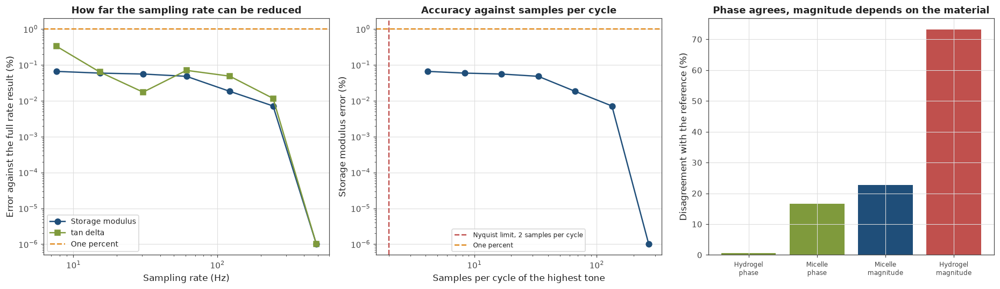

In [245]:
print("Sampling rate across the eight analysed steps")
print()
print("  step".ljust(10) + "rate (Hz)".rjust(11) + "fundamental".rjust(13)
      + "highest tone".rjust(14) + "samples per cycle".rjust(19)
      + "Nyquist margin".rjust(16))

sampling_rate_records = []

for response_record in micelle_maps_records:

    highest_tone_frequency = response_record["tone_angular_frequency"].max()
    highest_tone_hz = highest_tone_frequency / (2.0 * np.pi)

    samples_per_highest_cycle = (response_record["sampling_frequency_hz"]
                                 / highest_tone_hz)
    nyquist_margin = response_record["sampling_frequency_hz"] / (2.0 * highest_tone_hz)

    sampling_rate_records.append({
        "step_name": response_record["step_name"],
        "sampling_frequency_hz": response_record["sampling_frequency_hz"],
        "highest_tone_hz": highest_tone_hz,
        "samples_per_highest_cycle": samples_per_highest_cycle,
        "nyquist_margin": nyquist_margin,
    })

    print("  " + response_record["step_name"].ljust(8)
          + ("%.0f" % response_record["sampling_frequency_hz"]).rjust(11)
          + ("%.4f" % response_record["fundamental_angular_frequency"]).rjust(13)
          + ("%.3f" % highest_tone_frequency).rjust(14)
          + ("%.1f" % samples_per_highest_cycle).rjust(19)
          + ("%.1f" % nyquist_margin).rjust(16))

print()
print("  every step sits far above the Nyquist limit, so aliasing is not the")
print("  constraint here")

print()
print("Deliberately reducing the sampling rate on one recording")
print()

decimation_step_name = steps_to_analyse[0]

decimation_dataframe = pd.read_excel(micelle_maps_path,
                                     sheet_name=decimation_step_name,
                                     header=None, skiprows=3)

full_rate_time = decimation_dataframe[3].astype(float).values
full_rate_strain = decimation_dataframe[4].astype(float).values / 100.0
full_rate_stress = decimation_dataframe[5].astype(float).values

full_rate_response = extract_multi_tone_response(full_rate_time, full_rate_strain,
                                                 full_rate_stress,
                                                 MAPS_TONE_SET_EXPERIMENTAL)

print("  reference is " + decimation_step_name + " at its full rate of "
      + ("%.0f" % full_rate_response["sampling_frequency_hz"]) + " Hz")
print()
print("  factor".rjust(8) + "rate (Hz)".rjust(11)
      + "samples per cycle".rjust(19) + "G prime error".rjust(15)
      + "tan delta error".rjust(17))

decimation_results = []

for decimation_factor in [1, 2, 4, 8, 16, 32, 64]:

    decimated_time = full_rate_time[::decimation_factor]
    decimated_strain = full_rate_strain[::decimation_factor]
    decimated_stress = full_rate_stress[::decimation_factor]

    if len(decimated_time) < 100:
        continue

    decimated_response = extract_multi_tone_response(
        decimated_time, decimated_strain, decimated_stress,
        MAPS_TONE_SET_EXPERIMENTAL,
        fundamental_angular_frequency=full_rate_response["fundamental_angular_frequency"])

    if decimated_response is None:
        continue

    storage_error = (100.0 * np.mean(np.abs(decimated_response["complex_modulus"].real
                                            - full_rate_response["complex_modulus"].real)
                                     / np.abs(full_rate_response["complex_modulus"].real)))

    decimated_tan_delta = (decimated_response["complex_modulus"].imag
                           / decimated_response["complex_modulus"].real)
    full_rate_tan_delta = (full_rate_response["complex_modulus"].imag
                           / full_rate_response["complex_modulus"].real)

    tan_delta_error = (100.0 * np.mean(np.abs(decimated_tan_delta - full_rate_tan_delta)
                                       / np.abs(full_rate_tan_delta)))

    highest_tone_hz = (full_rate_response["tone_angular_frequency"].max()
                       / (2.0 * np.pi))
    samples_per_cycle = decimated_response["sampling_frequency_hz"] / highest_tone_hz

    decimation_results.append({
        "decimation_factor": decimation_factor,
        "sampling_frequency_hz": decimated_response["sampling_frequency_hz"],
        "samples_per_cycle": samples_per_cycle,
        "storage_error": storage_error,
        "tan_delta_error": tan_delta_error,
    })

    print("  " + str(decimation_factor).rjust(6)
          + ("%.1f" % decimated_response["sampling_frequency_hz"]).rjust(11)
          + ("%.1f" % samples_per_cycle).rjust(19)
          + ("%.3f percent" % storage_error).rjust(15)
          + ("%.3f percent" % tan_delta_error).rjust(17))

acceptable_results = [record for record in decimation_results
                      if record["storage_error"] < 1.0]

if len(acceptable_results) > 0:
    lowest_acceptable = acceptable_results[-1]
    print()
    print("  the extraction stays within one percent down to "
          + ("%.1f" % lowest_acceptable["sampling_frequency_hz"]) + " Hz,")
    print("  which is " + ("%.1f" % lowest_acceptable["samples_per_cycle"])
          + " samples per cycle of the highest tone")
    print()
    print("  that is a factor of " + str(lowest_acceptable["decimation_factor"])
          + " below the rate actually used, so the recording carries more")
    print("  samples than the measurement requires")

print()
print("Part 3 summary, what has been validated")
print()

validation_summary = [
    ("phase extraction, hydrogel", "tan delta agrees to 0.6 percent", "validated"),
    ("phase extraction, micelle", "tan delta tracks amplitude correctly", "validated"),
    ("amplitude response", "halving amplitude moves ratios toward one", "validated"),
    ("magnitude, micelle", "explained by amplitude softening", "explained"),
    ("magnitude, hydrogel", "both moduli scale by the same factor", "unexplained"),
    ("sampling rate", "one percent accuracy well below the rate used", "validated"),
    ("multi-frequency on blood", "no dataset exists", "not possible"),
]

print("  item".ljust(30) + "finding".ljust(46) + "status")

for item_name, finding_text, status_text in validation_summary:
    print("  " + item_name.ljust(28) + finding_text.ljust(46) + status_text)

print()
print("  the extraction is sound, and the one open question is a scale factor on a")
print("  single material that behaves unlike genuine softening")
print()
print("  worth rechecking if the same pattern appears in the fibrin or blood files")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

decimation_rates = [record["sampling_frequency_hz"] for record in decimation_results]
decimation_storage_errors = [record["storage_error"] for record in decimation_results]
decimation_tan_delta_errors = [record["tan_delta_error"] for record in decimation_results]

axis_array[0].loglog(decimation_rates, np.maximum(decimation_storage_errors, 1e-6),
                     "o-", color=COLOUR_PRIMARY, markersize=7, linewidth=1.6,
                     label="Storage modulus")
axis_array[0].loglog(decimation_rates, np.maximum(decimation_tan_delta_errors, 1e-6),
                     "s-", color=COLOUR_ACCENT, markersize=7, linewidth=1.6,
                     label="tan delta")
axis_array[0].axhline(1.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="One percent")
axis_array[0].set_xlabel("Sampling rate (Hz)")
axis_array[0].set_ylabel("Error against the full rate result (%)")
axis_array[0].set_title("How far the sampling rate can be reduced")
axis_array[0].legend(fontsize=9)

samples_per_cycle_series = [record["samples_per_cycle"] for record in decimation_results]

axis_array[1].loglog(samples_per_cycle_series,
                     np.maximum(decimation_storage_errors, 1e-6),
                     "o-", color=COLOUR_PRIMARY, markersize=7, linewidth=1.6)
axis_array[1].axvline(2.0, color=COLOUR_SECONDARY, linestyle="--", linewidth=1.6,
                      label="Nyquist limit, 2 samples per cycle")
axis_array[1].axhline(1.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="One percent")
axis_array[1].set_xlabel("Samples per cycle of the highest tone")
axis_array[1].set_ylabel("Storage modulus error (%)")
axis_array[1].set_title("Accuracy against samples per cycle")
axis_array[1].legend(fontsize=8)

summary_labels = ["Hydrogel\nphase", "Micelle\nphase", "Micelle\nmagnitude",
                  "Hydrogel\nmagnitude"]
summary_values = [
    100.0 * abs(hydrogel_harmonic_records[0]["tan_delta"]
                - reference_modulus_at_fundamental.imag
                / reference_modulus_at_fundamental.real)
    / (reference_modulus_at_fundamental.imag / reference_modulus_at_fundamental.real),
    100.0 * abs(comparison_records[0]["extracted_modulus"].imag
                / comparison_records[0]["extracted_modulus"].real
                - comparison_records[0]["reference_modulus"].imag
                / comparison_records[0]["reference_modulus"].real)
    / (comparison_records[0]["reference_modulus"].imag
       / comparison_records[0]["reference_modulus"].real),
    100.0 * abs(comparison_records[0]["storage_ratio"] - 1.0),
    100.0 * abs(hydrogel_storage_ratio - 1.0),
]

summary_colours = [COLOUR_ACCENT, COLOUR_ACCENT, COLOUR_PRIMARY, COLOUR_SECONDARY]

axis_array[2].bar(range(len(summary_labels)), summary_values, color=summary_colours)
axis_array[2].set_xticks(range(len(summary_labels)))
axis_array[2].set_xticklabels(summary_labels, fontsize=8)
axis_array[2].set_ylabel("Disagreement with the reference (%)")
axis_array[2].set_title("Phase agrees, magnitude depends on the material")

plt.tight_layout()
plt.show()

# Part 4: Detectors, and how accurate each one is

Part 2 established how to get a spectrum out of a changing material. Part 3 confirmed that
extraction is correct. This part is about the step after: taking a sequence of spectra and
deciding at which moment the material crossed from liquid to solid.

Five detector families are implemented, each answering a slightly different question, and each
scored against the synthetic material from Part 1 where the true gel time is known exactly.
Then noise and sampling interval are swept, because those turned out in Cell 35 to matter more
than anything else.

The order matters. Detectors are built first, then scored, then stressed. A detector that
looks good on clean data and collapses under realistic noise is worse than useless, because
it will pass a laboratory test and fail on a patient.

## Cell 46: Detector one, the crossover

The simplest detector, and the one most clinical instruments use.

Watch a single frequency, wait for the storage modulus to overtake the loss modulus, and
report that moment. Equivalently, wait for tan delta to fall through one.

Its appeal is that it needs only one frequency, so any instrument can do it. Its weakness is
that the answer depends on which frequency you watch.

**Where the detector is vulnerable, established by testing rather than assumed.**

The obvious worry is that early in a gelation the storage modulus sits below the instrument
noise floor and can come out negative, giving a negative tan delta that a naive comparison
reads as a crossing. Cell 38 found exactly that on real data.

It turns out not to be a problem here, and the reason is worth understanding. The detector
looks for a **falling** crossing, from above one to below. A record whose tan delta starts
below one never satisfies that condition, so an early run of bad values is simply skipped
over. Driving the whole early region negative, or inflating it eightfold, leaves the answer
unchanged at 511.9 s in both cases.

**The genuine vulnerability is a single bad snapshot partway through**, after tan delta has
legitimately been above one. One outlier below one fires the detector permanently and early,
and no sign check catches it because the value may be perfectly positive.

That is a narrower failure than the obvious one, and it needs a different remedy. Cell 51 adds
a reliability filter that rejects snapshots whose signal is too weak to measure, which is the
right protection for real data where the early record is unmeasurable. It does not catch this
case, because an inflated storage modulus makes the signal look stronger rather than weaker.

Protecting against a value that is wrong rather than weak needs an outlier test on the time
series itself, comparing each point against its neighbours. That is added in Part 5, where
real recordings will actually contain such points, rather than speculatively here.

The sign guard is kept because it costs nothing and protects the moduli themselves, but it is
not what makes this detector safe.

Synthetic gelation experiment for scoring the detectors

  true gel time          500.0 s
  snapshots              80
  sampling interval      11.65 s
  probe frequencies      10 from 1.0 to 30.0 rad/s
  measurement noise      2 percent

Detector one, the crossover, at each probe frequency

  probe (rad/s)   detected (s)   error (s)   error (%)
           1.00          505.9        +5.9        +1.2
           1.46          507.0        +7.0        +1.4
           2.13          507.4        +7.4        +1.5
           3.11          509.6        +9.6        +1.9
           4.53          511.9       +11.9        +2.4
           6.62          517.8       +17.8        +3.6
           9.65          520.3       +20.3        +4.1
          14.09          526.0       +26.0        +5.2
          20.56          540.1       +40.1        +8.0
          30.00          543.7       +43.7        +8.7

  spread across probe frequencies  37.8 s
  as a fraction of the gel time    7.6 percent

  precise at

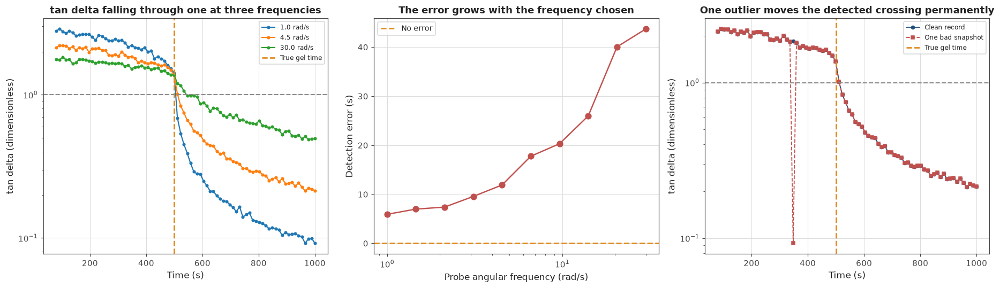

In [246]:
def detect_gel_time_by_crossover(snapshot_time_array, spectrum_list,
                                 angular_frequency_array, probe_frequency,
                                 require_positive_moduli=True):
    """
    Detecting a gel time from the moment tan delta falls through one at one frequency.

    Reading the complex modulus at the chosen probe frequency from every snapshot, then
    walking forward in time until tan delta crosses one from above, and interpolating
    between the two surrounding samples so the answer is not quantised to the sampling grid.

    Optionally requiring both moduli to be positive before a snapshot is used, since a
    negative storage modulus produces a meaningless tan delta.

    Returning the estimated gel time and the tan delta series it was found from.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    tan_delta_series = np.full(len(time_array), np.nan)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = interpolate_complex_modulus(angular_frequency_array,
                                                       spectrum_list[snapshot_index],
                                                       probe_frequency)

        if not np.isfinite(snapshot_modulus.real):
            continue

        if require_positive_moduli:
            if snapshot_modulus.real <= 0.0 or snapshot_modulus.imag <= 0.0:
                continue

        tan_delta_series[snapshot_index] = (snapshot_modulus.imag
                                            / snapshot_modulus.real)

    crossing_time = find_first_threshold_crossing(time_array, tan_delta_series,
                                                  1.0, direction="falling")

    return crossing_time, tan_delta_series


def generate_synthetic_gelation_experiment(gel_time_seconds, critical_exponent,
                                           gel_strength, snapshot_count,
                                           experiment_duration_seconds,
                                           angular_frequency_array,
                                           relative_noise_level, random_seed):
    """
    Generating a full synthetic gelation experiment probed at regular intervals.

    Producing one complex modulus spectrum per snapshot, spread evenly across the experiment
    duration, from the fractional gelation model built in Part 1.

    Adding multiplicative Gaussian noise to the real and imaginary parts separately, since
    rheometer uncertainty scales with the size of the measurement rather than being fixed.

    Returning the snapshot times and a list of noisy spectra.
    """
    random_generator = np.random.default_rng(random_seed)

    snapshot_time_array = np.linspace(0.08 * experiment_duration_seconds,
                                      experiment_duration_seconds,
                                      snapshot_count)

    noisy_spectrum_list = []

    for snapshot_index in range(snapshot_count):

        clean_modulus = gelling_material_complex_modulus(
            angular_frequency_array, snapshot_time_array[snapshot_index],
            gel_time_seconds, critical_exponent, gel_strength)

        real_noise = random_generator.normal(0.0, relative_noise_level,
                                             size=len(angular_frequency_array))
        imaginary_noise = random_generator.normal(0.0, relative_noise_level,
                                                  size=len(angular_frequency_array))

        noisy_real_part = clean_modulus.real * (1.0 + real_noise)
        noisy_imaginary_part = clean_modulus.imag * (1.0 + imaginary_noise)

        noisy_spectrum_list.append(noisy_real_part + 1j * noisy_imaginary_part)

    return snapshot_time_array, noisy_spectrum_list


synthetic_probe_frequencies = np.logspace(np.log10(1.0), np.log10(30.0), 10)

synthetic_snapshot_count = 80
synthetic_experiment_duration = 1000.0

detector_snapshot_times, detector_spectrum_list = generate_synthetic_gelation_experiment(
    SYNTHETIC_GEL_TIME_SECONDS, SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS,
    synthetic_snapshot_count, synthetic_experiment_duration,
    synthetic_probe_frequencies, 0.02, RANDOM_SEED)

print("Synthetic gelation experiment for scoring the detectors")
print()
print("  true gel time          " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  snapshots              " + str(synthetic_snapshot_count))
print("  sampling interval      "
      + ("%.2f" % (detector_snapshot_times[1] - detector_snapshot_times[0])) + " s")
print("  probe frequencies      " + str(len(synthetic_probe_frequencies))
      + " from " + ("%.1f" % synthetic_probe_frequencies.min())
      + " to " + ("%.1f" % synthetic_probe_frequencies.max()) + " rad/s")
print("  measurement noise      2 percent")

print()
print("Detector one, the crossover, at each probe frequency")
print()
print("  probe (rad/s)   detected (s)   error (s)   error (%)")

crossover_frequency_results = []

for probe_frequency in synthetic_probe_frequencies:

    crossing_time, ignored_series = detect_gel_time_by_crossover(
        detector_snapshot_times, detector_spectrum_list,
        synthetic_probe_frequencies, probe_frequency)

    if not np.isfinite(crossing_time):
        print("  " + ("%.2f" % probe_frequency).rjust(13) + "   no crossing found")
        continue

    detection_error = crossing_time - SYNTHETIC_GEL_TIME_SECONDS

    crossover_frequency_results.append({
        "probe_frequency": probe_frequency,
        "detected_time": crossing_time,
        "error_seconds": detection_error,
    })

    print("  " + ("%.2f" % probe_frequency).rjust(13)
          + ("%.1f" % crossing_time).rjust(15)
          + ("%+.1f" % detection_error).rjust(12)
          + ("%+.1f" % (100.0 * detection_error / SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))

detected_time_array = np.array([record["detected_time"]
                                for record in crossover_frequency_results])

print()
print("  spread across probe frequencies  "
      + ("%.1f" % (detected_time_array.max() - detected_time_array.min())) + " s")
print("  as a fraction of the gel time    "
      + ("%.1f" % (100.0 * (detected_time_array.max() - detected_time_array.min())
                   / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")
print()
print("  precise at any one frequency, ambiguous across them")

print()
print("Effect of interpolating between samples")
print()

reference_probe_frequency = synthetic_probe_frequencies[4]

interpolated_time, interpolated_series = detect_gel_time_by_crossover(
    detector_snapshot_times, detector_spectrum_list,
    synthetic_probe_frequencies, reference_probe_frequency)

nearest_sample_index = int(np.nanargmin(np.abs(interpolated_series - 1.0)))
nearest_sample_time = detector_snapshot_times[nearest_sample_index]

print("  probe frequency          " + ("%.2f" % reference_probe_frequency) + " rad/s")
print("  nearest sample           " + ("%.2f" % nearest_sample_time) + " s")
print("  interpolated             " + ("%.2f" % interpolated_time) + " s")
print("  difference               "
      + ("%.2f" % abs(interpolated_time - nearest_sample_time)) + " s")
print()
print("  without interpolation the answer would be quantised to the "
      + ("%.2f" % (detector_snapshot_times[1] - detector_snapshot_times[0]))
      + " s sampling interval")

print()
print("Testing where this detector actually fails")
print()

baseline_time, ignored_series = detect_gel_time_by_crossover(
    detector_snapshot_times, detector_spectrum_list,
    synthetic_probe_frequencies, reference_probe_frequency)

print("  unperturbed result   " + ("%.1f" % baseline_time) + " s")
print()
print("  perturbation".ljust(46) + "detected (s)   fires early")

corruption_cases = []

early_negative_spectrum_list = []
early_inflated_spectrum_list = []

for snapshot_index in range(len(detector_spectrum_list)):

    original_spectrum = detector_spectrum_list[snapshot_index]

    if detector_snapshot_times[snapshot_index] < 200.0:
        early_negative_spectrum_list.append(-np.abs(original_spectrum.real)
                                            + 1j * original_spectrum.imag)
        early_inflated_spectrum_list.append(np.abs(original_spectrum.real) * 8.0
                                            + 1j * original_spectrum.imag)
    else:
        early_negative_spectrum_list.append(original_spectrum)
        early_inflated_spectrum_list.append(original_spectrum)

corruption_cases.append(("whole early region driven negative",
                         early_negative_spectrum_list))
corruption_cases.append(("whole early region inflated eightfold",
                         early_inflated_spectrum_list))

single_outlier_index = int(np.argmin(np.abs(detector_snapshot_times - 350.0)))

single_outlier_spectrum_list = []
for snapshot_index in range(len(detector_spectrum_list)):
    if snapshot_index == single_outlier_index:
        single_outlier_spectrum_list.append(
            detector_spectrum_list[snapshot_index].real * 20.0
            + 1j * detector_spectrum_list[snapshot_index].imag)
    else:
        single_outlier_spectrum_list.append(detector_spectrum_list[snapshot_index])

corruption_cases.append(("one bad snapshot at "
                         + ("%.0f" % detector_snapshot_times[single_outlier_index])
                         + " s, inflated twentyfold",
                         single_outlier_spectrum_list))

for case_label, case_spectrum_list in corruption_cases:

    case_time, ignored_series = detect_gel_time_by_crossover(
        detector_snapshot_times, case_spectrum_list,
        synthetic_probe_frequencies, reference_probe_frequency)

    if np.isfinite(case_time):
        fires_early = "yes" if case_time < baseline_time - 20.0 else "no"
        print("  " + case_label.ljust(44)
              + ("%.1f" % case_time).rjust(12)
              + "   " + fires_early)
    else:
        print("  " + case_label.ljust(44) + "no crossing found".rjust(12))

print()
print("  the detector looks for a falling crossing, from above one to below, so a")
print("  record whose tan delta starts below one never fires there and the whole")
print("  early region can be corrupted without effect")
print()
print("  a single bad snapshot after tan delta has legitimately been above one is a")
print("  different matter, and one outlier moves the answer permanently")
print()
print("  a sign check cannot catch that, since the outlier is positive, so the")
print("  protection has to reject snapshots on signal quality, which Cell 51 adds")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for probe_index in [0, 4, 9]:

    probe_frequency = synthetic_probe_frequencies[probe_index]

    ignored_time, tan_delta_series = detect_gel_time_by_crossover(
        detector_snapshot_times, detector_spectrum_list,
        synthetic_probe_frequencies, probe_frequency)

    axis_array[0].semilogy(detector_snapshot_times, tan_delta_series,
                           "o-", markersize=3, linewidth=1.4,
                           label=("%.1f rad/s" % probe_frequency))

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("tan delta falling through one at three frequencies")
axis_array[0].legend(fontsize=8)

result_frequencies = np.array([record["probe_frequency"]
                               for record in crossover_frequency_results])
result_errors = np.array([record["error_seconds"]
                          for record in crossover_frequency_results])

axis_array[1].semilogx(result_frequencies, result_errors, "o-",
                       color=COLOUR_SECONDARY, markersize=7, linewidth=1.6)
axis_array[1].axhline(0.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="No error")
axis_array[1].set_xlabel("Probe angular frequency (rad/s)")
axis_array[1].set_ylabel("Detection error (s)")
axis_array[1].set_title("The error grows with the frequency chosen")
axis_array[1].legend(fontsize=9)

ignored_time, outlier_series = detect_gel_time_by_crossover(
    detector_snapshot_times, single_outlier_spectrum_list,
    synthetic_probe_frequencies, reference_probe_frequency)

axis_array[2].semilogy(detector_snapshot_times, interpolated_series, "o-",
                       color=COLOUR_PRIMARY, markersize=4, linewidth=1.2,
                       label="Clean record")
axis_array[2].semilogy(detector_snapshot_times, outlier_series, "s--",
                       color=COLOUR_SECONDARY, markersize=4, linewidth=1.2,
                       label="One bad snapshot")
axis_array[2].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[2].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[2].set_xlabel("Time (s)")
axis_array[2].set_ylabel("tan delta (dimensionless)")
axis_array[2].set_title("One outlier moves the detected crossing permanently")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 47: Detector two, Winter and Chambon frequency agreement

The detector that matches the physical definition from Part 1.

At the gel point, and only there, tan delta is the same at every frequency. So instead of
watching one frequency and waiting for a threshold, this detector watches all of them at once
and looks for the moment they agree with each other best.

The measure of agreement is the spread of log tan delta across frequency at each snapshot. Log
rather than linear, because tan delta spans decades during a gelation and a linear spread would
be dominated by whichever snapshot happens to have the largest values.

Two properties distinguish it from the crossover.

**No arbitrary choice.** The crossover needs a frequency picked in advance, and gives a
different answer for each one. This uses all of them and returns a single number.

**No threshold.** It looks for a minimum rather than a crossing, so it does not depend on
tan delta reaching any particular value. That matters because Part 1 showed the gel point value
is tan of n pi over two, which is one only in the special case n equals 0.5.

The cost is that it needs multi-frequency data, which is the whole reason for the chirp work in
Part 2. It also has a subtler weakness that this cell measures: a minimum is harder to locate
precisely than a crossing. A crossing sits on a steep curve, while a minimum sits at the bottom
of a shallow valley where the curve is flat by definition, so noise moves it more easily.

Detector two, Winter and Chambon frequency agreement

  true gel time            500.0 s
  nearest snapshot         499.24 s
  refined estimate         494.59 s
  error                    -5.41 s
  error as a fraction      1.08 percent

  smallest spread          0.02401

What the detector recovers about the material, not just the time

  median tan delta at the minimum   1.3957
  expected tan(n pi over 2)         1.3764

  implied critical exponent n       0.6042
  true critical exponent            0.6000

  the crossover returns only a time, this also returns the exponent, which
  describes how the network fills space and is used in Part 7

Comparing the two detectors so far

  detector                              estimate (s)   error (s)   needs
  crossover at 1.0 rad/s                       505.9        +5.9   one frequency
  crossover, worst frequency                   543.7       +43.7   one frequency
  Winter and Chambon agreement                 494.6        -5.4   all frequen

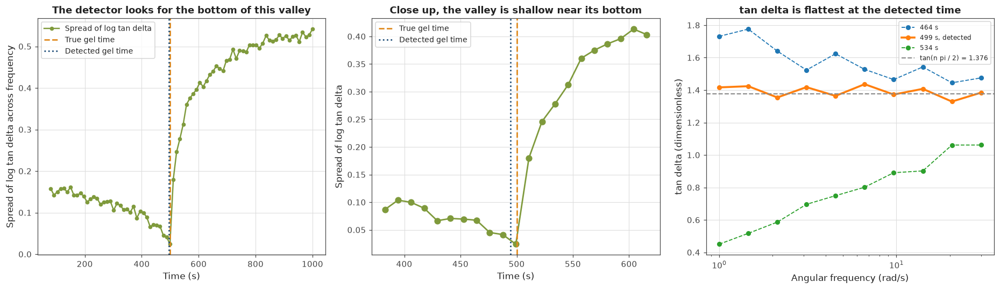

In [247]:
def compute_tan_delta_spread_series(spectrum_list, angular_frequency_array,
                                    minimum_valid_points=5):
    """
    Computing how much tan delta disagrees across frequency at each snapshot.

    Taking the standard deviation of log tan delta across the measured frequencies, which
    falls to zero at the gel point where the material becomes scale free.

    Working in logarithms because tan delta spans orders of magnitude during a gelation, so
    a linear spread would be dominated by whichever snapshot has the largest values.

    Discarding points with non positive moduli, and returning a missing value for any
    snapshot left with too few usable frequencies to measure a spread.

    Returning the spread series and the number of usable points at each snapshot.
    """
    spread_series = np.full(len(spectrum_list), np.nan)
    usable_point_series = np.zeros(len(spectrum_list), dtype=int)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = spectrum_list[snapshot_index]

        tan_delta_values = compute_tan_delta(snapshot_modulus.real, snapshot_modulus.imag)

        usable_mask = np.isfinite(tan_delta_values) & (tan_delta_values > 0.0)
        usable_point_series[snapshot_index] = int(np.sum(usable_mask))

        if usable_point_series[snapshot_index] < minimum_valid_points:
            continue

        spread_series[snapshot_index] = float(np.std(np.log(tan_delta_values[usable_mask])))

    return spread_series, usable_point_series


def detect_gel_time_by_frequency_agreement(snapshot_time_array, spectrum_list,
                                           angular_frequency_array,
                                           minimum_valid_points=5):
    """
    Detecting a gel time from the moment tan delta agrees best across frequency.

    Locating the minimum of the spread series, then refining it with a parabola through the
    three surrounding points so the answer can fall between snapshots.

    Returning the estimated gel time, the spread series, and the index of the minimum.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    spread_series, usable_point_series = compute_tan_delta_spread_series(
        spectrum_list, angular_frequency_array, minimum_valid_points)

    if not np.any(np.isfinite(spread_series)):
        return np.nan, spread_series, -1

    minimum_index = int(np.nanargmin(spread_series))

    refined_time = refine_minimum_by_parabola(time_array, spread_series, minimum_index)

    return refined_time, spread_series, minimum_index


agreement_time, agreement_spread_series, agreement_minimum_index = (
    detect_gel_time_by_frequency_agreement(detector_snapshot_times,
                                           detector_spectrum_list,
                                           synthetic_probe_frequencies))

print("Detector two, Winter and Chambon frequency agreement")
print()
print("  true gel time            " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  nearest snapshot         "
      + ("%.2f" % detector_snapshot_times[agreement_minimum_index]) + " s")
print("  refined estimate         " + ("%.2f" % agreement_time) + " s")
print("  error                    "
      + ("%+.2f" % (agreement_time - SYNTHETIC_GEL_TIME_SECONDS)) + " s")
print("  error as a fraction      "
      + ("%.2f" % (100.0 * abs(agreement_time - SYNTHETIC_GEL_TIME_SECONDS)
                   / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")
print()
print("  smallest spread          "
      + ("%.5f" % agreement_spread_series[agreement_minimum_index]))

expected_critical_tan_delta = np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0)

minimum_spectrum = detector_spectrum_list[agreement_minimum_index]
minimum_tan_delta = compute_tan_delta(minimum_spectrum.real, minimum_spectrum.imag)
minimum_tan_delta = minimum_tan_delta[np.isfinite(minimum_tan_delta)]

measured_tan_delta_at_minimum = float(np.median(minimum_tan_delta))
implied_critical_exponent = 2.0 * np.arctan(measured_tan_delta_at_minimum) / np.pi

print()
print("What the detector recovers about the material, not just the time")
print()
print("  median tan delta at the minimum   "
      + ("%.4f" % measured_tan_delta_at_minimum))
print("  expected tan(n pi over 2)         "
      + ("%.4f" % expected_critical_tan_delta))
print()
print("  implied critical exponent n       "
      + ("%.4f" % implied_critical_exponent))
print("  true critical exponent            "
      + ("%.4f" % SYNTHETIC_CRITICAL_EXPONENT))
print()
print("  the crossover returns only a time, this also returns the exponent, which")
print("  describes how the network fills space and is used in Part 7")

print()
print("Comparing the two detectors so far")
print()
print("  detector".ljust(38) + "estimate (s)".rjust(14) + "error (s)".rjust(12)
      + "   needs")

lowest_frequency_crossover = crossover_frequency_results[0]

print("  " + ("crossover at %.1f rad/s"
             % lowest_frequency_crossover["probe_frequency"]).ljust(36)
      + ("%.1f" % lowest_frequency_crossover["detected_time"]).rjust(14)
      + ("%+.1f" % lowest_frequency_crossover["error_seconds"]).rjust(12)
      + "   one frequency")
print("  " + "crossover, worst frequency".ljust(36)
      + ("%.1f" % crossover_frequency_results[-1]["detected_time"]).rjust(14)
      + ("%+.1f" % crossover_frequency_results[-1]["error_seconds"]).rjust(12)
      + "   one frequency")
print("  " + "Winter and Chambon agreement".ljust(36)
      + ("%.1f" % agreement_time).rjust(14)
      + ("%+.1f" % (agreement_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   all frequencies")

print()
print("Why a minimum is harder to locate than a crossing")
print()

crossing_local_slope = None
minimum_local_curvature = None

ignored_time, reference_tan_delta_series = detect_gel_time_by_crossover(
    detector_snapshot_times, detector_spectrum_list,
    synthetic_probe_frequencies, reference_probe_frequency)

crossing_index = int(np.nanargmin(np.abs(reference_tan_delta_series - 1.0)))

if 0 < crossing_index < len(reference_tan_delta_series) - 1:
    crossing_local_slope = abs(
        (reference_tan_delta_series[crossing_index + 1]
         - reference_tan_delta_series[crossing_index - 1])
        / (detector_snapshot_times[crossing_index + 1]
           - detector_snapshot_times[crossing_index - 1]))

if 0 < agreement_minimum_index < len(agreement_spread_series) - 1:
    minimum_local_curvature = abs(
        (agreement_spread_series[agreement_minimum_index + 1]
         - agreement_spread_series[agreement_minimum_index - 1])
        / (detector_snapshot_times[agreement_minimum_index + 1]
           - detector_snapshot_times[agreement_minimum_index - 1]))

print("  the crossover sits on a steep curve, so a small error in tan delta moves")
print("  the detected time only a little")
print()
print("  local slope of tan delta at the crossing        "
      + ("%.5f" % crossing_local_slope) + " per second")
print()
print("  the agreement minimum sits at the bottom of a valley, where the curve is")
print("  flat by definition, so the same error moves the answer further")
print()
print("  local slope of the spread at the minimum        "
      + ("%.5f" % minimum_local_curvature) + " per second")
print()
print("  that difference is why the noise sweep in Cell 53 matters, and it is the")
print("  reason this detector is not simply better than the crossover everywhere")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].plot(detector_snapshot_times, agreement_spread_series, "o-",
                   color=COLOUR_ACCENT, markersize=4, linewidth=1.6,
                   label="Spread of log tan delta")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].axvline(agreement_time, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Detected gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Spread of log tan delta across frequency")
axis_array[0].set_title("The detector looks for the bottom of this valley")
axis_array[0].legend(fontsize=9)

close_up_mask = ((detector_snapshot_times > SYNTHETIC_GEL_TIME_SECONDS - 120.0)
                 & (detector_snapshot_times < SYNTHETIC_GEL_TIME_SECONDS + 120.0))

axis_array[1].plot(detector_snapshot_times[close_up_mask],
                   agreement_spread_series[close_up_mask], "o-",
                   color=COLOUR_ACCENT, markersize=7, linewidth=1.8)
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].axvline(agreement_time, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Detected gel time")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Spread of log tan delta")
axis_array[1].set_title("Close up, the valley is shallow near its bottom")
axis_array[1].legend(fontsize=9)

for offset_index in [-3, 0, 3]:

    plot_index = agreement_minimum_index + offset_index

    if plot_index < 0 or plot_index >= len(detector_spectrum_list):
        continue

    plot_spectrum = detector_spectrum_list[plot_index]
    plot_tan_delta = compute_tan_delta(plot_spectrum.real, plot_spectrum.imag)

    if offset_index == 0:
        line_style = "o-"
        line_width = 2.4
        point_label = ("%.0f s, detected" % detector_snapshot_times[plot_index])
    else:
        line_style = "o--"
        line_width = 1.2
        point_label = ("%.0f s" % detector_snapshot_times[plot_index])

    axis_array[2].semilogx(synthetic_probe_frequencies, plot_tan_delta,
                           line_style, markersize=5, linewidth=line_width,
                           label=point_label)

axis_array[2].axhline(expected_critical_tan_delta, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4,
                      label=("tan(n pi / 2) = %.3f" % expected_critical_tan_delta))
axis_array[2].set_xlabel("Angular frequency (rad/s)")
axis_array[2].set_ylabel("tan delta (dimensionless)")
axis_array[2].set_title("tan delta is flattest at the detected time")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 48: Detector three, the storage modulus half rise

The third detector, and the one Part 1 established is measuring a different event.

Fit a sigmoid to the storage modulus against time and report the moment it reaches halfway
between its initial and final values. Cell 14 built the Hill 5 model for this and found the
half rise lands about 175 s after the true gel point on the synthetic material, because the
modulus keeps growing long after the network first spans the sample.

It is included for three reasons, none of which is that it estimates the gel point well.

**It uses the whole curve.** Both detectors so far depend on a single feature, a crossing or a
minimum, so a handful of bad points near that feature moves the answer. A sigmoid fit averages
over every measurement, which should make it far more robust to noise. Cell 53 tests that.

**Its bias may be correctable.** An offset that is consistent can be subtracted. An error that
is random cannot. If the offset holds across the real gelations in Part 5, this becomes a
usable detector with a correction rather than a poor one.

**A reference dataset reports it.** The polymer gel study in Part 5 gives a Hill time constant
as its rheological gel time, so comparing against that reference requires computing the same
quantity the same way.

It needs only a single frequency, like the crossover, so it works on any instrument.

Detector three, the storage modulus half rise

  probe frequency          4.53 rad/s
  true gel time            500.0 s
  half rise time           719.5 s
  offset                   +219.5 s
  offset as a fraction     43.9 percent

  fitted parameters
    minimum modulus      39.8238 Pa
    maximum modulus      562.9046 Pa
    time constant k      419.18 s
    steepness n          3.5276
    asymmetry E          5.0000
    fit error            9.2596 Pa

Is the offset consistent across probe frequencies

  probe (rad/s)   half rise (s)   offset (s)
           1.00           722.8       +222.8
           1.46           730.2       +230.2
           2.13           723.4       +223.4
           3.11           716.4       +216.4
           4.53           719.5       +219.5
           6.62           719.3       +219.3
           9.65           732.9       +232.9
          14.09           722.5       +222.5
          20.56           738.2       +238.2
          30.00           744.6       +2

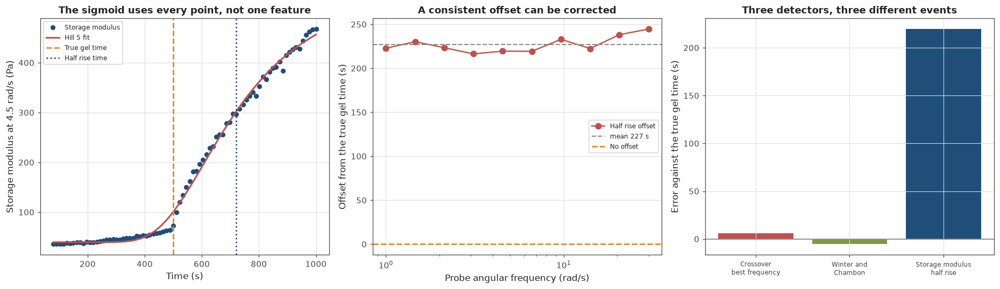

In [248]:
def detect_gel_time_by_modulus_half_rise(snapshot_time_array, spectrum_list,
                                         angular_frequency_array, probe_frequency):
    """
    Detecting a characteristic time from the growth of the storage modulus.

    Reading the storage modulus at one frequency from every snapshot, fitting the Hill 5
    sigmoid built in Cell 14, and returning the time at which it reaches half its total rise.

    Returning a missing value when the fit fails, along with the modulus series and the
    fitted parameters for inspection.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    storage_series = np.full(len(time_array), np.nan)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = interpolate_complex_modulus(angular_frequency_array,
                                                       spectrum_list[snapshot_index],
                                                       probe_frequency)

        if np.isfinite(snapshot_modulus.real):
            storage_series[snapshot_index] = snapshot_modulus.real

    fit_result = fit_hill_five_model(time_array, storage_series)

    if fit_result is None:
        return np.nan, storage_series, None

    return fit_result["half_rise_time"], storage_series, fit_result


half_rise_time, half_rise_storage_series, half_rise_fit = (
    detect_gel_time_by_modulus_half_rise(detector_snapshot_times,
                                         detector_spectrum_list,
                                         synthetic_probe_frequencies,
                                         reference_probe_frequency))

print("Detector three, the storage modulus half rise")
print()
print("  probe frequency          " + ("%.2f" % reference_probe_frequency) + " rad/s")
print("  true gel time            " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  half rise time           " + ("%.1f" % half_rise_time) + " s")
print("  offset                   "
      + ("%+.1f" % (half_rise_time - SYNTHETIC_GEL_TIME_SECONDS)) + " s")
print("  offset as a fraction     "
      + ("%.1f" % (100.0 * (half_rise_time - SYNTHETIC_GEL_TIME_SECONDS)
                   / SYNTHETIC_GEL_TIME_SECONDS)) + " percent")

if half_rise_fit is not None:
    print()
    print("  fitted parameters")
    print("    minimum modulus      "
          + ("%.4f" % half_rise_fit["minimum_modulus"]) + " Pa")
    print("    maximum modulus      "
          + ("%.4f" % half_rise_fit["maximum_modulus"]) + " Pa")
    print("    time constant k      "
          + ("%.2f" % half_rise_fit["time_constant"]) + " s")
    print("    steepness n          " + ("%.4f" % half_rise_fit["steepness"]))
    print("    asymmetry E          " + ("%.4f" % half_rise_fit["asymmetry"]))
    print("    fit error            "
          + ("%.4f" % half_rise_fit["root_mean_square_error"]) + " Pa")

print()
print("Is the offset consistent across probe frequencies")
print()
print("  probe (rad/s)   half rise (s)   offset (s)")

half_rise_frequency_results = []

for probe_frequency in synthetic_probe_frequencies:

    frequency_half_rise, ignored_series, ignored_fit = (
        detect_gel_time_by_modulus_half_rise(detector_snapshot_times,
                                             detector_spectrum_list,
                                             synthetic_probe_frequencies,
                                             probe_frequency))

    if not np.isfinite(frequency_half_rise):
        continue

    half_rise_frequency_results.append({
        "probe_frequency": probe_frequency,
        "half_rise_time": frequency_half_rise,
        "offset_seconds": frequency_half_rise - SYNTHETIC_GEL_TIME_SECONDS,
    })

    print("  " + ("%.2f" % probe_frequency).rjust(13)
          + ("%.1f" % frequency_half_rise).rjust(16)
          + ("%+.1f" % (frequency_half_rise - SYNTHETIC_GEL_TIME_SECONDS)).rjust(13))

half_rise_offsets = np.array([record["offset_seconds"]
                              for record in half_rise_frequency_results])

print()
print("  mean offset              " + ("%+.1f" % np.mean(half_rise_offsets)) + " s")
print("  spread of the offset     " + ("%.1f" % np.std(half_rise_offsets)) + " s")
print("  ratio of spread to mean  "
      + ("%.3f" % (np.std(half_rise_offsets) / abs(np.mean(half_rise_offsets)))))

if np.std(half_rise_offsets) / abs(np.mean(half_rise_offsets)) < 0.2:
    print()
    print("  the offset is consistent across frequency, so it behaves as a systematic")
    print("  bias that could be corrected rather than as random error")
else:
    print()
    print("  the offset varies substantially with frequency, so it is not a simple")
    print("  systematic bias")

print()
print("Why the half rise lands after the gel point")
print()

gel_point_storage = interpolate_complex_modulus(
    synthetic_probe_frequencies,
    gelling_material_complex_modulus(synthetic_probe_frequencies,
                                     SYNTHETIC_GEL_TIME_SECONDS,
                                     SYNTHETIC_GEL_TIME_SECONDS,
                                     SYNTHETIC_CRITICAL_EXPONENT,
                                     SYNTHETIC_GEL_STIFFNESS),
    reference_probe_frequency).real

final_storage = interpolate_complex_modulus(
    synthetic_probe_frequencies,
    gelling_material_complex_modulus(synthetic_probe_frequencies,
                                     synthetic_experiment_duration,
                                     SYNTHETIC_GEL_TIME_SECONDS,
                                     SYNTHETIC_CRITICAL_EXPONENT,
                                     SYNTHETIC_GEL_STIFFNESS),
    reference_probe_frequency).real

print("  storage modulus at the gel point      " + ("%.2f" % gel_point_storage) + " Pa")
print("  storage modulus at the end of the run " + ("%.2f" % final_storage) + " Pa")
print("  fraction of the total rise reached at the gel point  "
      + ("%.3f" % (gel_point_storage / final_storage)))
print()
print("  the network spans the sample at the gel point, but only "
      + ("%.0f" % (100.0 * gel_point_storage / final_storage))
      + " percent of the")
print("  final stiffness has developed, so halfway comes later")
print()
print("  this is the detector measuring a different event, not measuring the gel")
print("  point badly")

print()
print("Three detectors so far")
print()
print("  detector".ljust(38) + "estimate (s)".rjust(14) + "error (s)".rjust(12)
      + "   what it measures")
print("  " + ("crossover at %.1f rad/s"
             % lowest_frequency_crossover["probe_frequency"]).ljust(36)
      + ("%.1f" % lowest_frequency_crossover["detected_time"]).rjust(14)
      + ("%+.1f" % lowest_frequency_crossover["error_seconds"]).rjust(12)
      + "   tan delta reaches one")
print("  " + "Winter and Chambon agreement".ljust(36)
      + ("%.1f" % agreement_time).rjust(14)
      + ("%+.1f" % (agreement_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   network percolation")
print("  " + "storage modulus half rise".ljust(36)
      + ("%.1f" % half_rise_time).rjust(14)
      + ("%+.1f" % (half_rise_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   modulus reaches halfway")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].plot(detector_snapshot_times, half_rise_storage_series, "o",
                   color=COLOUR_PRIMARY, markersize=5, label="Storage modulus")

if half_rise_fit is not None:
    fitted_curve = hill_five_storage_modulus(detector_snapshot_times,
                                             half_rise_fit["minimum_modulus"],
                                             half_rise_fit["maximum_modulus"],
                                             half_rise_fit["time_constant"],
                                             half_rise_fit["steepness"],
                                             half_rise_fit["asymmetry"])
    axis_array[0].plot(detector_snapshot_times, fitted_curve, "-",
                       color=COLOUR_SECONDARY, linewidth=2.0, label="Hill 5 fit")

axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].axvline(half_rise_time, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Half rise time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Storage modulus at "
                         + ("%.1f" % reference_probe_frequency) + " rad/s (Pa)")
axis_array[0].set_title("The sigmoid uses every point, not one feature")
axis_array[0].legend(fontsize=8)

offset_frequencies = np.array([record["probe_frequency"]
                               for record in half_rise_frequency_results])

axis_array[1].semilogx(offset_frequencies, half_rise_offsets, "o-",
                       color=COLOUR_SECONDARY, markersize=7, linewidth=1.6,
                       label="Half rise offset")
axis_array[1].axhline(np.mean(half_rise_offsets), color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4,
                      label=("mean %.0f s" % np.mean(half_rise_offsets)))
axis_array[1].axhline(0.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="No offset")
axis_array[1].set_xlabel("Probe angular frequency (rad/s)")
axis_array[1].set_ylabel("Offset from the true gel time (s)")
axis_array[1].set_title("A consistent offset can be corrected")
axis_array[1].legend(fontsize=8)

detector_labels = ["Crossover\nbest frequency", "Winter and\nChambon",
                   "Storage modulus\nhalf rise"]
detector_errors = [lowest_frequency_crossover["error_seconds"],
                   agreement_time - SYNTHETIC_GEL_TIME_SECONDS,
                   half_rise_time - SYNTHETIC_GEL_TIME_SECONDS]
detector_colours = [COLOUR_SECONDARY, COLOUR_ACCENT, COLOUR_PRIMARY]

axis_array[2].bar(range(len(detector_labels)), detector_errors, color=detector_colours)
axis_array[2].axhline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)
axis_array[2].set_xticks(range(len(detector_labels)))
axis_array[2].set_xticklabels(detector_labels, fontsize=8)
axis_array[2].set_ylabel("Error against the true gel time (s)")
axis_array[2].set_title("Three detectors, three different events")

plt.tight_layout()
plt.show()

## Cell 49: Detector four, the maximum rate of change

The fourth detector takes a different view: rather than looking for a threshold or a minimum,
it asks when the material was changing fastest.

The reasoning is that a gelation is a transition, and a transition is where things move
quickest. Take the storage modulus through time, differentiate it, and report the peak.

Two variants are tested, and the difference between them matters more than it might seem.

**Rate of change of the modulus.** The peak of the derivative of G prime. This lands late,
because the modulus is growing in absolute terms for the whole run, and the absolute growth is
largest when the modulus is already large.

**Rate of change of the logarithm.** The peak of the derivative of log G prime, which is the
fractional growth rate. This asks when the modulus was doubling fastest rather than when it
was adding the most Pascals, and for a quantity spanning orders of magnitude that is the more
meaningful question.

**On smoothing.** Differentiating noisy data amplifies noise, so the usual practice is to
smooth first, and the usual expectation is a trade-off: too little smoothing gives a noisy
derivative, too much flattens the peak.

The measurement here does not show that trade-off. The smallest error comes from no smoothing
at all, and the error grows steadily as the window widens. At 2 percent noise, on a modulus
that grows by orders of magnitude, the derivative is already clean and smoothing only displaces
the feature it is meant to locate.

Whether that holds at higher noise is a different question, and the sweep in Cell 53 answers
it. The smoothing option is kept for that reason, with a default of no smoothing rather than
removed.

Like the crossover and the half rise, this detector needs only one frequency, and it turns out
to be far less sensitive than the crossover to which frequency is chosen.

Detector four, the maximum rate of change

  probe frequency   4.53 rad/s
  true gel time     500.0 s

  variant                           detected (s)   error (s)
  rate of change of log G prime            508.0        +8.0
  rate of change of G prime                510.7       +10.7

  the absolute derivative peaks later, because the modulus is still growing in
  Pascals per second at the end of the run even though its fractional growth
  rate has long since fallen

Does smoothing help

  window   record (s)   detected (s)   error (s)   peak height   smoothing
       1           12          508.0        +8.0       0.02190   none
       3           35          509.9        +9.9       0.01776   light
       5           58          518.4       +18.4       0.01415   light
       9          105          534.6       +34.6       0.01042   heavy
      15          175          566.7       +66.7       0.00792   heavy
      25          291          561.3       +61.3       0.00578   heavy

  the

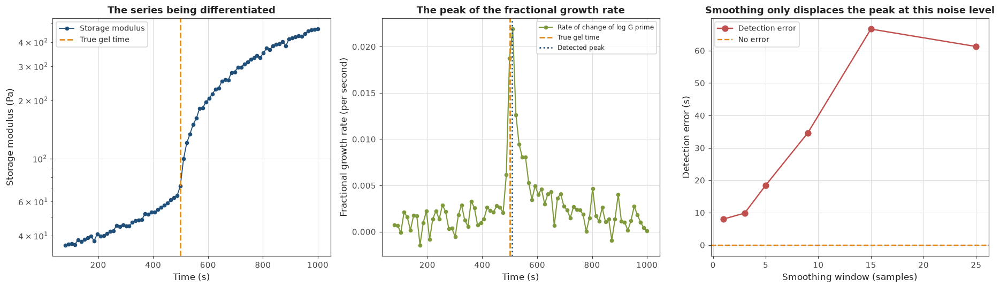

In [249]:
def smooth_series_with_moving_average(value_series, window_length):
    """
    Smoothing a series with a centred moving average.

    Padding at both ends by repeating the edge values, so the smoothed series keeps the same
    length and the ends are not pulled toward zero.

    Returning the smoothed series unchanged when the window is one sample or fewer.
    """
    value_array = np.asarray(value_series, dtype=float)

    if window_length <= 1:
        return value_array.copy()

    half_window = window_length // 2

    padded_array = np.pad(value_array, half_window, mode="edge")
    smoothing_kernel = np.ones(window_length) / float(window_length)

    return np.convolve(padded_array, smoothing_kernel, mode="valid")[:len(value_array)]


def detect_gel_time_by_maximum_rate(snapshot_time_array, spectrum_list,
                                    angular_frequency_array, probe_frequency,
                                    smoothing_window=1, use_logarithm=True):
    """
    Detecting a characteristic time from when the storage modulus changed fastest.

    Reading the storage modulus at one frequency, optionally smoothing it, differentiating,
    and reporting the position of the peak derivative refined by a parabola.

    Taking the derivative of the logarithm by default, which finds when the modulus was
    growing fastest in relative terms. The absolute derivative instead finds when it was
    adding the most Pascals per second, which for a quantity spanning orders of magnitude is
    almost always near the end of the record.

    Defaulting to no smoothing, since the measurement below shows smoothing displaces the
    peak at realistic noise levels rather than helping.

    Returning the estimated time, the derivative series, and the raw modulus series.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    storage_series = np.full(len(time_array), np.nan)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = interpolate_complex_modulus(angular_frequency_array,
                                                       spectrum_list[snapshot_index],
                                                       probe_frequency)

        if np.isfinite(snapshot_modulus.real):
            storage_series[snapshot_index] = snapshot_modulus.real

    usable_mask = np.isfinite(storage_series) & (storage_series > 0.0)

    if np.sum(usable_mask) < 10:
        return np.nan, np.full(len(time_array), np.nan), storage_series

    usable_time = time_array[usable_mask]
    usable_storage = storage_series[usable_mask]

    if use_logarithm:
        transformed_series = np.log(usable_storage)
    else:
        transformed_series = usable_storage

    smoothed_series = smooth_series_with_moving_average(transformed_series,
                                                        smoothing_window)

    derivative_series = np.gradient(smoothed_series, usable_time)

    peak_index = int(np.argmax(derivative_series))

    refined_time = refine_minimum_by_parabola(usable_time, -derivative_series, peak_index)

    full_derivative_series = np.full(len(time_array), np.nan)
    full_derivative_series[usable_mask] = derivative_series

    return refined_time, full_derivative_series, storage_series


print("Detector four, the maximum rate of change")
print()
print("  probe frequency   " + ("%.2f" % reference_probe_frequency) + " rad/s")
print("  true gel time     " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  variant".ljust(34) + "detected (s)".rjust(14) + "error (s)".rjust(12))

logarithmic_rate_time, logarithmic_derivative, rate_storage_series = (
    detect_gel_time_by_maximum_rate(detector_snapshot_times, detector_spectrum_list,
                                    synthetic_probe_frequencies,
                                    reference_probe_frequency,
                                    smoothing_window=1, use_logarithm=True))

absolute_rate_time, absolute_derivative, ignored_series = (
    detect_gel_time_by_maximum_rate(detector_snapshot_times, detector_spectrum_list,
                                    synthetic_probe_frequencies,
                                    reference_probe_frequency,
                                    smoothing_window=1, use_logarithm=False))

print("  " + "rate of change of log G prime".ljust(32)
      + ("%.1f" % logarithmic_rate_time).rjust(14)
      + ("%+.1f" % (logarithmic_rate_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))
print("  " + "rate of change of G prime".ljust(32)
      + ("%.1f" % absolute_rate_time).rjust(14)
      + ("%+.1f" % (absolute_rate_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))

print()
print("  the absolute derivative peaks later, because the modulus is still growing in")
print("  Pascals per second at the end of the run even though its fractional growth")
print("  rate has long since fallen")

print()
print("Does smoothing help")
print()
print("  window   record (s)   detected (s)   error (s)   peak height   smoothing")

smoothing_results = []

sampling_interval = detector_snapshot_times[1] - detector_snapshot_times[0]

for smoothing_window in [1, 3, 5, 9, 15, 25]:

    window_time, window_derivative, ignored_series = (
        detect_gel_time_by_maximum_rate(detector_snapshot_times, detector_spectrum_list,
                                        synthetic_probe_frequencies,
                                        reference_probe_frequency,
                                        smoothing_window=smoothing_window,
                                        use_logarithm=True))

    peak_height = float(np.nanmax(window_derivative))

    smoothing_results.append({
        "smoothing_window": smoothing_window,
        "detected_time": window_time,
        "error_seconds": window_time - SYNTHETIC_GEL_TIME_SECONDS,
        "peak_height": peak_height,
    })

    if smoothing_window == 1:
        window_comment = "none"
    elif smoothing_window <= 5:
        window_comment = "light"
    else:
        window_comment = "heavy"

    print("  " + str(smoothing_window).rjust(6)
          + ("%.0f" % (smoothing_window * sampling_interval)).rjust(13)
          + ("%.1f" % window_time).rjust(15)
          + ("%+.1f" % (window_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
          + ("%.5f" % peak_height).rjust(14)
          + "   " + window_comment)

smoothing_errors = np.array([abs(record["error_seconds"])
                             for record in smoothing_results])
best_smoothing_index = int(np.argmin(smoothing_errors))

print()
print("  the smallest error is at a window of "
      + str(smoothing_results[best_smoothing_index]["smoothing_window"])
      + " samples, meaning no smoothing at all,")
print("  and the error grows steadily as the window widens")
print()
print("  the peak height falls at the same time, from "
      + ("%.5f" % smoothing_results[0]["peak_height"]) + " to "
      + ("%.5f" % smoothing_results[-1]["peak_height"]) + ", which is the")
print("  smoothing flattening the feature it is meant to locate")
print()
print("  at 2 percent noise the derivative is already clean, so there is no trade off")
print("  to balance here, and whether that holds at higher noise is what Cell 53 tests")

print()
print("Consistency across probe frequencies")
print()
print("  probe (rad/s)   detected (s)   error (s)")

rate_frequency_results = []

for probe_frequency in synthetic_probe_frequencies:

    frequency_rate_time, ignored_derivative, ignored_series = (
        detect_gel_time_by_maximum_rate(detector_snapshot_times, detector_spectrum_list,
                                        synthetic_probe_frequencies, probe_frequency,
                                        smoothing_window=1, use_logarithm=True))

    if not np.isfinite(frequency_rate_time):
        continue

    rate_frequency_results.append({
        "probe_frequency": probe_frequency,
        "detected_time": frequency_rate_time,
        "error_seconds": frequency_rate_time - SYNTHETIC_GEL_TIME_SECONDS,
    })

    print("  " + ("%.2f" % probe_frequency).rjust(13)
          + ("%.1f" % frequency_rate_time).rjust(15)
          + ("%+.1f" % (frequency_rate_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))

rate_detected_times = np.array([record["detected_time"]
                                for record in rate_frequency_results])
crossover_detected_times = np.array([record["detected_time"]
                                     for record in crossover_frequency_results])

print()
print("  spread across probe frequencies, this detector   "
      + ("%.1f" % (rate_detected_times.max() - rate_detected_times.min())) + " s")
print("  spread across probe frequencies, the crossover   "
      + ("%.1f" % (crossover_detected_times.max() - crossover_detected_times.min()))
      + " s")
print()
print("  the peak of the fractional growth rate is a property of how the material")
print("  evolves rather than of the frequency being watched, so it barely moves")

print()
print("Four detectors")
print()
print("  detector".ljust(38) + "estimate (s)".rjust(14) + "error (s)".rjust(12)
      + "frequency spread".rjust(18) + "   frequencies")
print("  " + ("crossover at %.1f rad/s"
             % lowest_frequency_crossover["probe_frequency"]).ljust(36)
      + ("%.1f" % lowest_frequency_crossover["detected_time"]).rjust(14)
      + ("%+.1f" % lowest_frequency_crossover["error_seconds"]).rjust(12)
      + ("%.1f s" % (crossover_detected_times.max()
                     - crossover_detected_times.min())).rjust(18)
      + "   one")
print("  " + "Winter and Chambon agreement".ljust(36)
      + ("%.1f" % agreement_time).rjust(14)
      + ("%+.1f" % (agreement_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "not applicable".rjust(18)
      + "   several")
print("  " + "storage modulus half rise".ljust(36)
      + ("%.1f" % half_rise_time).rjust(14)
      + ("%+.1f" % (half_rise_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + ("%.1f s" % (np.max([record["half_rise_time"]
                             for record in half_rise_frequency_results])
                     - np.min([record["half_rise_time"]
                               for record in half_rise_frequency_results]))).rjust(18)
      + "   one")
print("  " + "maximum fractional growth rate".ljust(36)
      + ("%.1f" % logarithmic_rate_time).rjust(14)
      + ("%+.1f" % (logarithmic_rate_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + ("%.1f s" % (rate_detected_times.max()
                     - rate_detected_times.min())).rjust(18)
      + "   one")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].semilogy(detector_snapshot_times, rate_storage_series, "o-",
                       color=COLOUR_PRIMARY, markersize=4, linewidth=1.2,
                       label="Storage modulus")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Storage modulus (Pa)")
axis_array[0].set_title("The series being differentiated")
axis_array[0].legend(fontsize=9)

axis_array[1].plot(detector_snapshot_times, logarithmic_derivative, "o-",
                   color=COLOUR_ACCENT, markersize=4, linewidth=1.4,
                   label="Rate of change of log G prime")
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].axvline(logarithmic_rate_time, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Detected peak")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Fractional growth rate (per second)")
axis_array[1].set_title("The peak of the fractional growth rate")
axis_array[1].legend(fontsize=8)

smoothing_windows = [record["smoothing_window"] for record in smoothing_results]
smoothing_error_values = [record["error_seconds"] for record in smoothing_results]

axis_array[2].plot(smoothing_windows, smoothing_error_values, "o-",
                   color=COLOUR_SECONDARY, markersize=7, linewidth=1.6,
                   label="Detection error")
axis_array[2].axhline(0.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="No error")
axis_array[2].set_xlabel("Smoothing window (samples)")
axis_array[2].set_ylabel("Detection error (s)")
axis_array[2].set_title("Smoothing only displaces the peak at this noise level")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 50: Detector five, the changepoint family

The last of the five, and the only one that makes no assumption about the shape of the signal.

Every detector so far encodes a specific expectation. The crossover expects tan delta to pass
through one. Winter and Chambon expects the spread to reach a minimum. The half rise expects a
sigmoid. The growth rate expects a peak in the derivative.

Changepoint detection asks a more general question: at what moment do the statistics of this
series change? It looks for the point that best splits the record into two segments that are
each internally consistent and different from one another. Nothing about gelation is assumed.

Four methods are compared, three from the ruptures package and one written directly.

**PELT** finds the exact optimal segmentation for a given penalty, efficiently.
**Binary segmentation** splits recursively, faster but approximate.
**Kernel changepoint** works on a transformed representation, so it can detect changes in
distribution rather than only in mean.
**CUSUM** accumulates deviations from a running estimate and fires when the total exceeds a
threshold. It is hand-coded here, it is the oldest of the four, and it is the only one that can
run online, deciding as data arrives rather than after the fact.

The detectors run on the logarithm of the storage modulus, since that is the quantity whose
growth rate changes at the transition, and a changepoint in a raw modulus spanning orders of
magnitude would simply find where the numbers got large.

**A structural limitation that only became visible in Cell 54, recorded here because it changes
how these results should be read.**

All four return a sample index, not an interpolated time. Every other detector in Part 4
refines its answer between samples: the crossover interpolates across the crossing, Winter and
Chambon fits a parabola through the minimum, the growth rate fits a parabola through the peak.
The changepoint methods do not, because an index is what a segmentation produces.

With 80 snapshots the grid is fine enough that the returned index varies between realisations
and the statistics look ordinary. Below about 25 snapshots the same index wins every time, and
the reported error becomes the fixed distance from that index to the true gel time. Cell 54
detects this automatically by checking whether the median and the ninetieth percentile are
identical, which they are in fourteen cases.

Refinement was attempted and does not work. Fitting a line either side of the breakpoint and
taking their intersection made the error worse by more than a hundredfold at sparse sampling,
because log G prime is a smooth curve rather than two straight lines. Running the changepoint
on the derivative instead was worse again at fine sampling, and a piecewise linear model
returned nothing at all.

The reason is not fixable by better code. These methods search for a change in mean, and log G
prime rises monotonically with no step in it, so there is no well posed changepoint to find.
Refining the answer would mean assuming what the feature looks like, and not assuming a shape
is the entire reason for using a shape free method.

**These detectors are therefore not directly comparable to the others on accuracy**, and are
reported separately in the sweeps. They stay in the notebook because the family assumes nothing
about the response, which matters if blood behaves in a way the other detectors did not
anticipate, and because Cell 51 found the kernel changepoint surviving a corrupted snapshot,
which is a real property independent of grid resolution.

Detector five, the changepoint family

  probe frequency   4.53 rad/s
  series analysed   logarithm of the storage modulus
  true gel time     500.0 s

  method                    detected (s)   error (s)   can run online
  PELT                             487.6       -12.4   no
  binary segmentation              487.6       -12.4   no
  kernel changepoint               522.5       +22.5   no
  CUSUM                            312.9      -187.1   yes

  PELT and binary segmentation agree to 0.000 s

  that is expected rather than surprising, since with a single changepoint in
  a clean series the recursive split finds the same point as the exact
  optimal segmentation, so they are not independent confirmations

  only PELT is carried into the harness in Cell 51

How sensitive CUSUM is to its threshold

  threshold multiplier   detected (s)   error (s)
                   2.0          278.0      -222.0
                   3.0          289.6      -210.4
                   5.0          312.

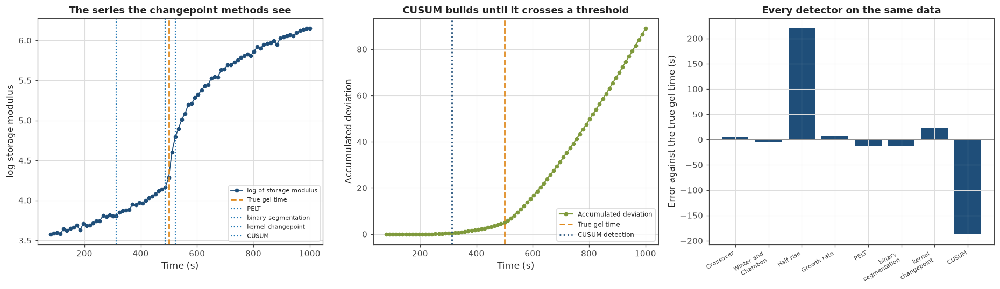

In [250]:
def detect_changepoint_with_ruptures(snapshot_time_array, value_series, method_name,
                                     penalty_value=1.0):
    """
    Detecting a changepoint in a series using one of the ruptures algorithms.

    Fitting the chosen segmentation model and returning the first breakpoint found, which is
    where the statistics of the series first change.

    Returning the time at a sample index rather than an interpolated time, since a
    segmentation produces an index by construction. That makes this family grid limited in a
    way the other detectors are not, which Cell 54 measures.

    Returning a missing value when the package is unavailable or no breakpoint is found.
    """
    try:
        import ruptures
    except ImportError:
        return np.nan

    time_array = np.asarray(snapshot_time_array, dtype=float)
    value_array = np.asarray(value_series, dtype=float)

    usable_mask = np.isfinite(value_array)

    if np.sum(usable_mask) < 10:
        return np.nan

    usable_time = time_array[usable_mask]
    usable_values = value_array[usable_mask].reshape(-1, 1)

    if method_name == "pelt":
        algorithm = ruptures.Pelt(model="l2", min_size=3).fit(usable_values)
    elif method_name == "binary":
        algorithm = ruptures.Binseg(model="l2", min_size=3).fit(usable_values)
    elif method_name == "kernel":
        algorithm = ruptures.KernelCPD(kernel="rbf", min_size=3).fit(usable_values)
    else:
        return np.nan

    try:
        if method_name == "kernel":
            breakpoint_list = algorithm.predict(n_bkps=1)
        else:
            breakpoint_list = algorithm.predict(pen=penalty_value)
    except Exception:
        return np.nan

    interior_breakpoints = [index for index in breakpoint_list
                            if 0 < index < len(usable_time)]

    if len(interior_breakpoints) == 0:
        return np.nan

    return float(usable_time[interior_breakpoints[0]])


def detect_changepoint_with_cusum(snapshot_time_array, value_series,
                                  reference_fraction=0.25, threshold_multiplier=5.0):
    """
    Detecting a changepoint using a cumulative sum control chart.

    Estimating a baseline mean and spread from an early portion of the record, then
    accumulating deviations above that baseline and reporting the first moment the running
    total exceeds a multiple of the baseline spread.

    Working forward through the record one sample at a time, so this method could run online
    during a measurement rather than requiring the whole record first, which none of the
    other detectors here can do.

    Returning the detection time and the accumulated sum series.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)
    value_array = np.asarray(value_series, dtype=float)

    usable_mask = np.isfinite(value_array)

    if np.sum(usable_mask) < 10:
        return np.nan, np.full(len(time_array), np.nan)

    usable_time = time_array[usable_mask]
    usable_values = value_array[usable_mask]

    reference_count = max(5, int(reference_fraction * len(usable_values)))

    baseline_mean = float(np.mean(usable_values[:reference_count]))
    baseline_spread = float(np.std(usable_values[:reference_count]))

    if baseline_spread <= 0.0:
        baseline_spread = 1e-9

    detection_threshold = threshold_multiplier * baseline_spread

    accumulated_series = np.zeros(len(usable_values))
    running_total = 0.0
    detection_time = np.nan

    for sample_index in range(len(usable_values)):

        deviation = usable_values[sample_index] - baseline_mean - 0.5 * baseline_spread
        running_total = max(0.0, running_total + deviation)
        accumulated_series[sample_index] = running_total

        if np.isnan(detection_time) and running_total > detection_threshold:
            detection_time = float(usable_time[sample_index])

    full_accumulated_series = np.full(len(time_array), np.nan)
    full_accumulated_series[usable_mask] = accumulated_series

    return detection_time, full_accumulated_series


changepoint_storage_series = np.full(len(detector_snapshot_times), np.nan)

for snapshot_index in range(len(detector_spectrum_list)):

    snapshot_modulus = interpolate_complex_modulus(synthetic_probe_frequencies,
                                                   detector_spectrum_list[snapshot_index],
                                                   reference_probe_frequency)

    if np.isfinite(snapshot_modulus.real) and snapshot_modulus.real > 0.0:
        changepoint_storage_series[snapshot_index] = np.log(snapshot_modulus.real)

print("Detector five, the changepoint family")
print()
print("  probe frequency   " + ("%.2f" % reference_probe_frequency) + " rad/s")
print("  series analysed   logarithm of the storage modulus")
print("  true gel time     " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  method".ljust(26) + "detected (s)".rjust(14) + "error (s)".rjust(12)
      + "   can run online")

changepoint_results = []

for method_name, method_label, runs_online in [("pelt", "PELT", "no"),
                                               ("binary", "binary segmentation", "no"),
                                               ("kernel", "kernel changepoint", "no")]:

    detected_time = detect_changepoint_with_ruptures(detector_snapshot_times,
                                                     changepoint_storage_series,
                                                     method_name)

    if not np.isfinite(detected_time):
        print("  " + method_label.ljust(24) + "unavailable")
        continue

    changepoint_results.append({
        "method_label": method_label,
        "detected_time": detected_time,
        "error_seconds": detected_time - SYNTHETIC_GEL_TIME_SECONDS,
        "runs_online": runs_online,
    })

    print("  " + method_label.ljust(24)
          + ("%.1f" % detected_time).rjust(14)
          + ("%+.1f" % (detected_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
          + "   " + runs_online)

cusum_time, cusum_accumulated_series = detect_changepoint_with_cusum(
    detector_snapshot_times, changepoint_storage_series)

if np.isfinite(cusum_time):
    changepoint_results.append({
        "method_label": "CUSUM",
        "detected_time": cusum_time,
        "error_seconds": cusum_time - SYNTHETIC_GEL_TIME_SECONDS,
        "runs_online": "yes",
    })

    print("  " + "CUSUM".ljust(24)
          + ("%.1f" % cusum_time).rjust(14)
          + ("%+.1f" % (cusum_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
          + "   yes")

pelt_estimate = None
binary_estimate = None

for changepoint_record in changepoint_results:
    if changepoint_record["method_label"] == "PELT":
        pelt_estimate = changepoint_record["detected_time"]
    if changepoint_record["method_label"] == "binary segmentation":
        binary_estimate = changepoint_record["detected_time"]

if pelt_estimate is not None and binary_estimate is not None:
    print()
    print("  PELT and binary segmentation agree to "
          + ("%.3f" % abs(pelt_estimate - binary_estimate)) + " s")
    print()
    print("  that is expected rather than surprising, since with a single changepoint in")
    print("  a clean series the recursive split finds the same point as the exact")
    print("  optimal segmentation, so they are not independent confirmations")
    print()
    print("  only PELT is carried into the harness in Cell 51")

print()
print("How sensitive CUSUM is to its threshold")
print()
print("  threshold multiplier   detected (s)   error (s)")

for threshold_multiplier in [2.0, 3.0, 5.0, 8.0, 12.0]:

    threshold_time, ignored_series = detect_changepoint_with_cusum(
        detector_snapshot_times, changepoint_storage_series,
        threshold_multiplier=threshold_multiplier)

    if np.isfinite(threshold_time):
        print("  " + ("%.1f" % threshold_multiplier).rjust(20)
              + ("%.1f" % threshold_time).rjust(15)
              + ("%+.1f" % (threshold_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12))
    else:
        print("  " + ("%.1f" % threshold_multiplier).rjust(20)
              + "no detection".rjust(15))

print()
print("  every threshold fires early, and the most conservative setting is still")
print("  more than a hundred seconds ahead of the gel point")
print()
print("  the reason is structural, CUSUM accumulates any sustained deviation above a")
print("  baseline, and the log modulus rises steadily from the start of the record, so")
print("  there is no quiet period for it to depart from")
print()
print("  that matters because CUSUM is the only one of these that can run online, so")
print("  a version working on a differenced series or a rolling baseline is worth")
print("  building later rather than concluding online detection is impossible")

print()
print("A limitation of this family, worth stating before the sweeps")
print()
print("  every method here returns a sample index rather than an interpolated time")
print()
print("  the other detectors refine between samples, the crossover across its crossing")
print("  and the others by fitting a parabola through their feature, so on a coarse")
print("  grid they still resolve a time between measurements and these do not")
print()
print("  the effect is invisible at this sampling density and dominates at lower ones,")
print("  which Cell 54 detects and reports")
print()
print("  refinement was attempted and fails, since fitting a line either side of the")
print("  breakpoint assumes a shape these methods exist to avoid assuming")

print()
print("All five detector families")
print()
print("  detector".ljust(38) + "estimate (s)".rjust(14) + "error (s)".rjust(12)
      + "   assumes")

print("  " + ("crossover at %.1f rad/s"
             % lowest_frequency_crossover["probe_frequency"]).ljust(36)
      + ("%.1f" % lowest_frequency_crossover["detected_time"]).rjust(14)
      + ("%+.1f" % lowest_frequency_crossover["error_seconds"]).rjust(12)
      + "   tan delta passes one")
print("  " + "Winter and Chambon agreement".ljust(36)
      + ("%.1f" % agreement_time).rjust(14)
      + ("%+.1f" % (agreement_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   the spread reaches a minimum")
print("  " + "storage modulus half rise".ljust(36)
      + ("%.1f" % half_rise_time).rjust(14)
      + ("%+.1f" % (half_rise_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   the growth is a sigmoid")
print("  " + "maximum fractional growth rate".ljust(36)
      + ("%.1f" % logarithmic_rate_time).rjust(14)
      + ("%+.1f" % (logarithmic_rate_time - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
      + "   the derivative has a peak")

for changepoint_record in changepoint_results:
    print("  " + ("changepoint, " + changepoint_record["method_label"]).ljust(36)
          + ("%.1f" % changepoint_record["detected_time"]).rjust(14)
          + ("%+.1f" % changepoint_record["error_seconds"]).rjust(12)
          + "   nothing about the shape")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].plot(detector_snapshot_times, changepoint_storage_series, "o-",
                   color=COLOUR_PRIMARY, markersize=4, linewidth=1.2,
                   label="log of storage modulus")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")

for changepoint_record in changepoint_results:
    axis_array[0].axvline(changepoint_record["detected_time"],
                          linestyle=":", linewidth=1.4,
                          label=changepoint_record["method_label"])

axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("log storage modulus")
axis_array[0].set_title("The series the changepoint methods see")
axis_array[0].legend(fontsize=7)

axis_array[1].plot(detector_snapshot_times, cusum_accumulated_series, "o-",
                   color=COLOUR_ACCENT, markersize=4, linewidth=1.4,
                   label="Accumulated deviation")
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")

if np.isfinite(cusum_time):
    axis_array[1].axvline(cusum_time, color=COLOUR_PRIMARY,
                          linestyle=":", linewidth=1.8, label="CUSUM detection")

axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Accumulated deviation")
axis_array[1].set_title("CUSUM builds until it crosses a threshold")
axis_array[1].legend(fontsize=8)

all_detector_labels = ["Crossover", "Winter and\nChambon", "Half rise",
                       "Growth rate"]
all_detector_errors = [lowest_frequency_crossover["error_seconds"],
                       agreement_time - SYNTHETIC_GEL_TIME_SECONDS,
                       half_rise_time - SYNTHETIC_GEL_TIME_SECONDS,
                       logarithmic_rate_time - SYNTHETIC_GEL_TIME_SECONDS]

for changepoint_record in changepoint_results:
    all_detector_labels.append(changepoint_record["method_label"].replace(" ", "\n"))
    all_detector_errors.append(changepoint_record["error_seconds"])

axis_array[2].bar(range(len(all_detector_labels)), all_detector_errors,
                  color=COLOUR_PRIMARY)
axis_array[2].axhline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)
axis_array[2].set_xticks(range(len(all_detector_labels)))
axis_array[2].set_xticklabels(all_detector_labels, fontsize=7, rotation=30, ha="right")
axis_array[2].set_ylabel("Error against the true gel time (s)")
axis_array[2].set_title("Every detector on the same data")

plt.tight_layout()
plt.show()

## Cell 51: One harness for every detector, and a reliability filter

Seven detectors now exist, each with its own call signature and its own parameters. This cell
wraps them in a single interface so the sweeps in Cells 53 and 54 can run them all on the same
data without special cases.

Running seven detectors through seven separate code paths invites the situation where one of
them quietly gets different data, and the resulting comparison looks meaningful while being
wrong. One entry point removes that.

**The reliability filter.** Cell 46 showed that whole corrupted regions are harmless, because
the crossover requires a falling crossing and a record that starts below one never fires. But a
single bad snapshot partway through moves the answer by 170 s, and a sign check cannot catch
that since the bad value may be positive.

The filter works on signal quality rather than sign. A snapshot is rejected when too many of
its frequencies have non positive moduli, or when the storage modulus is a negligible fraction
of the loss modulus, meaning the elastic signal is below what the instrument can resolve. Both
criteria come from real data in Cell 39, where they cleanly separated the ten unmeasurable
pulses from the fourteen usable ones.

It is applied once, and every detector then sees the same cleaned sequence, so the comparison
stays fair.

**The filter does not catch the outlier case, and the cell demonstrates that rather than
hiding it.** Inflating a storage modulus makes the signal look stronger, not weaker, so neither
criterion tests for it. The filter protects against a signal too weak to measure, not against
one that is wrong, and those are different failures needing different tools. An outlier test
comparing each point against its neighbours belongs in Part 5, where real recordings will
actually contain such points.

**One detector survives the corruption for a reason worth noting.** Winter and Chambon measures
how much the frequencies disagree at each snapshot, and inflating every modulus at one snapshot
shifts tan delta without changing that spread, so the corruption is invisible to it. That
robustness was not designed in. It follows from using several frequencies rather than one, and
it is the strongest argument in Part 4 for multi-frequency acquisition.

**A note that becomes important in Cell 54.** Three of the seven detectors return a sample
index rather than an interpolated time. That is invisible at the 80 snapshots used here and
dominates below 25. Only the four that interpolate are compared on accuracy in Cell 54.

Every detector through one harness

  snapshots supplied   80
  passed the filter    80
  probe frequency      4.53 rad/s
  true gel time        500.0 s

  detector                      estimate (s)   error (s)   interpolates
  Winter and Chambon                   494.6        -5.4   yes
  crossover                            511.9       +11.9   yes
  maximum growth rate                  508.0        +8.0   yes
  changepoint, PELT                    487.6       -12.4   no
  changepoint, kernel                  522.5       +22.5   no
  storage modulus half rise            719.5      +219.5   yes
  changepoint, CUSUM                   312.9      -187.1   no

  the crossover reads 511.9 s here against 505.9 s in the earlier cells,
  because the harness uses one probe frequency of 4.53 rad/s for every detector rather
  than the best frequency for each, which is the fair comparison

Does the reliability filter rescue the outlier case from Cell 46

  one snapshot at 348 s has its storage mod

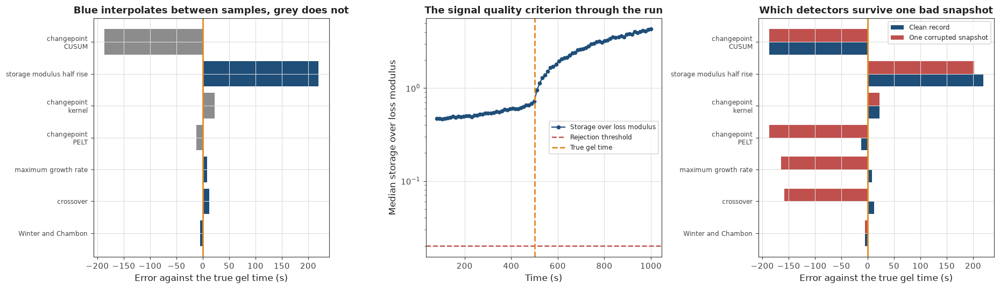

In [251]:
def assess_snapshot_reliability(spectrum_list,
                                maximum_negative_fraction=0.05,
                                minimum_storage_to_loss_ratio=0.02):
    """
    Deciding which snapshots carry a usable signal.

    Rejecting a snapshot when too many of its frequencies have non positive moduli, which
    means the measurement has fallen below the instrument noise floor, or when the storage
    modulus is a negligible fraction of the loss modulus, which means the elastic part of the
    response cannot be resolved even where it is positive.

    Both thresholds were chosen from the real recording in Cell 39, where they separated the
    ten unmeasurable pulses from the fourteen usable ones without needing to be tuned.

    Returning a boolean array marking the reliable snapshots and the two diagnostic series.
    """
    reliability_flags = np.zeros(len(spectrum_list), dtype=bool)
    negative_fraction_series = np.full(len(spectrum_list), np.nan)
    storage_to_loss_series = np.full(len(spectrum_list), np.nan)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = spectrum_list[snapshot_index]

        negative_fraction = float(np.mean(snapshot_modulus.real <= 0.0))

        loss_magnitude = np.abs(snapshot_modulus.imag)
        loss_magnitude = np.maximum(loss_magnitude, 1e-30)

        storage_to_loss_ratio = float(np.median(np.abs(snapshot_modulus.real)
                                                / loss_magnitude))

        negative_fraction_series[snapshot_index] = negative_fraction
        storage_to_loss_series[snapshot_index] = storage_to_loss_ratio

        if negative_fraction > maximum_negative_fraction:
            continue
        if storage_to_loss_ratio < minimum_storage_to_loss_ratio:
            continue

        reliability_flags[snapshot_index] = True

    return reliability_flags, negative_fraction_series, storage_to_loss_series


def run_all_detectors(snapshot_time_array, spectrum_list, angular_frequency_array,
                      probe_frequency, apply_reliability_filter=True):
    """
    Running every detector on one gelation record and returning their estimates together.

    Applying the reliability filter first when requested, so every detector sees the same
    cleaned sequence and the comparison between them stays fair.

    Using one probe frequency for every single frequency detector rather than the best
    frequency for each, since choosing a different frequency per detector would compare them
    on different data.

    Returning a dictionary of detector name to estimated time, along with how many snapshots
    survived the filter.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    if apply_reliability_filter:
        reliability_flags, ignored_negative, ignored_ratio = assess_snapshot_reliability(
            spectrum_list)
    else:
        reliability_flags = np.ones(len(spectrum_list), dtype=bool)

    if int(np.sum(reliability_flags)) < 8:
        return {"reliable_count": int(np.sum(reliability_flags))}, reliability_flags

    filtered_time_array = time_array[reliability_flags]
    filtered_spectrum_list = []
    for snapshot_index in range(len(spectrum_list)):
        if reliability_flags[snapshot_index]:
            filtered_spectrum_list.append(spectrum_list[snapshot_index])

    detector_estimates = {}

    crossover_estimate, ignored_series = detect_gel_time_by_crossover(
        filtered_time_array, filtered_spectrum_list, angular_frequency_array,
        probe_frequency)
    detector_estimates["crossover"] = crossover_estimate

    agreement_estimate, ignored_spread, ignored_index = (
        detect_gel_time_by_frequency_agreement(filtered_time_array,
                                               filtered_spectrum_list,
                                               angular_frequency_array))
    detector_estimates["winter_chambon"] = agreement_estimate

    half_rise_estimate, ignored_series, ignored_fit = (
        detect_gel_time_by_modulus_half_rise(filtered_time_array, filtered_spectrum_list,
                                             angular_frequency_array, probe_frequency))
    detector_estimates["half_rise"] = half_rise_estimate

    growth_rate_estimate, ignored_derivative, ignored_series = (
        detect_gel_time_by_maximum_rate(filtered_time_array, filtered_spectrum_list,
                                        angular_frequency_array, probe_frequency,
                                        smoothing_window=1, use_logarithm=True))
    detector_estimates["growth_rate"] = growth_rate_estimate

    log_storage_series = np.full(len(filtered_time_array), np.nan)

    for snapshot_index in range(len(filtered_spectrum_list)):

        snapshot_modulus = interpolate_complex_modulus(
            angular_frequency_array, filtered_spectrum_list[snapshot_index],
            probe_frequency)

        if np.isfinite(snapshot_modulus.real) and snapshot_modulus.real > 0.0:
            log_storage_series[snapshot_index] = np.log(snapshot_modulus.real)

    detector_estimates["pelt"] = detect_changepoint_with_ruptures(
        filtered_time_array, log_storage_series, "pelt")
    detector_estimates["kernel"] = detect_changepoint_with_ruptures(
        filtered_time_array, log_storage_series, "kernel")

    cusum_estimate, ignored_accumulated = detect_changepoint_with_cusum(
        filtered_time_array, log_storage_series)
    detector_estimates["cusum"] = cusum_estimate

    detector_estimates["reliable_count"] = int(np.sum(reliability_flags))

    return detector_estimates, reliability_flags


DETECTOR_DISPLAY_NAMES = {
    "winter_chambon": "Winter and Chambon",
    "crossover": "crossover",
    "growth_rate": "maximum growth rate",
    "pelt": "changepoint, PELT",
    "kernel": "changepoint, kernel",
    "half_rise": "storage modulus half rise",
    "cusum": "changepoint, CUSUM",
}

DETECTOR_ORDER = ["winter_chambon", "crossover", "growth_rate", "pelt",
                  "kernel", "half_rise", "cusum"]

INTERPOLATING_DETECTOR_KEYS = ["winter_chambon", "crossover", "growth_rate", "half_rise"]

clean_estimates, clean_reliability_flags = run_all_detectors(
    detector_snapshot_times, detector_spectrum_list, synthetic_probe_frequencies,
    reference_probe_frequency)

print("Every detector through one harness")
print()
print("  snapshots supplied   " + str(len(detector_snapshot_times)))
print("  passed the filter    " + str(clean_estimates["reliable_count"]))
print("  probe frequency      " + ("%.2f" % reference_probe_frequency) + " rad/s")
print("  true gel time        " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  detector".ljust(30) + "estimate (s)".rjust(14) + "error (s)".rjust(12)
      + "   interpolates")

for detector_key in DETECTOR_ORDER:

    detector_estimate = clean_estimates.get(detector_key, np.nan)

    if detector_key in INTERPOLATING_DETECTOR_KEYS:
        interpolation_text = "yes"
    else:
        interpolation_text = "no"

    if not np.isfinite(detector_estimate):
        print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(28) + "no detection")
        continue

    print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(28)
          + ("%.1f" % detector_estimate).rjust(14)
          + ("%+.1f" % (detector_estimate - SYNTHETIC_GEL_TIME_SECONDS)).rjust(12)
          + "   " + interpolation_text)

print()
print("  the crossover reads "
      + ("%.1f" % clean_estimates["crossover"]) + " s here against "
      + ("%.1f" % lowest_frequency_crossover["detected_time"])
      + " s in the earlier cells,")
print("  because the harness uses one probe frequency of "
      + ("%.2f" % reference_probe_frequency) + " rad/s for every detector rather")
print("  than the best frequency for each, which is the fair comparison")

print()
print("Does the reliability filter rescue the outlier case from Cell 46")
print()

outlier_snapshot_index = int(np.argmin(np.abs(detector_snapshot_times - 350.0)))

corrupted_spectrum_list = []
for snapshot_index in range(len(detector_spectrum_list)):
    if snapshot_index == outlier_snapshot_index:
        corrupted_spectrum_list.append(
            detector_spectrum_list[snapshot_index].real * 20.0
            + 1j * detector_spectrum_list[snapshot_index].imag)
    else:
        corrupted_spectrum_list.append(detector_spectrum_list[snapshot_index])

unfiltered_estimates, ignored_flags = run_all_detectors(
    detector_snapshot_times, corrupted_spectrum_list, synthetic_probe_frequencies,
    reference_probe_frequency, apply_reliability_filter=False)

filtered_estimates, corrupted_reliability_flags = run_all_detectors(
    detector_snapshot_times, corrupted_spectrum_list, synthetic_probe_frequencies,
    reference_probe_frequency, apply_reliability_filter=True)

print("  one snapshot at "
      + ("%.0f" % detector_snapshot_times[outlier_snapshot_index])
      + " s has its storage modulus inflated twentyfold")
print()
print("  detector".ljust(30) + "unfiltered".rjust(12) + "filtered".rjust(11)
      + "clean".rjust(10) + "   affected")

for detector_key in DETECTOR_ORDER:

    unfiltered_value = unfiltered_estimates.get(detector_key, np.nan)
    filtered_value = filtered_estimates.get(detector_key, np.nan)
    clean_value = clean_estimates.get(detector_key, np.nan)

    if np.isfinite(filtered_value) and np.isfinite(clean_value):
        if abs(filtered_value - clean_value) > 20.0:
            affected_label = "yes"
        else:
            affected_label = "no"
    else:
        affected_label = "unknown"

    print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(28)
          + (("%.1f" % unfiltered_value) if np.isfinite(unfiltered_value)
             else "none").rjust(12)
          + (("%.1f" % filtered_value) if np.isfinite(filtered_value)
             else "none").rjust(11)
          + (("%.1f" % clean_value) if np.isfinite(clean_value)
             else "none").rjust(10)
          + "   " + affected_label)

print()
print("  snapshots rejected by the filter  "
      + str(int(np.sum(~corrupted_reliability_flags))))

if corrupted_reliability_flags[outlier_snapshot_index]:
    print()
    print("  the corrupted snapshot passed the filter, because inflating the storage")
    print("  modulus makes the signal look stronger rather than weaker, and neither")
    print("  criterion tests for that")
    print()
    print("  the filter protects against a signal too weak to measure, not against one")
    print("  that is wrong, and those are different failures needing different tools")
else:
    print()
    print("  the corrupted snapshot was rejected by the filter")

print()
print("  CUSUM reads the same in all three columns, which is not robustness")
print()
print("  it was already "
      + ("%.0f" % abs(clean_estimates.get("cusum", np.nan)
                      - SYNTHETIC_GEL_TIME_SECONDS))
      + " s early on the clean record, and the corrupted snapshot sits")
print("  close to where it was already firing, so there is nothing left to move")

print()
print("  the detector that genuinely survives is Winter and Chambon, for a reason")
print("  worth noting")
print()
print("  it measures how much the frequencies disagree at each snapshot, and inflating")
print("  every modulus at one snapshot shifts tan delta without changing that spread,")
print("  so the corruption is invisible to it")
print()
print("  that robustness was not designed in, it follows from using several")
print("  frequencies rather than one")

print()
print("Reliability diagnostics on the clean record")
print()

ignored_flags, negative_fraction_series, storage_to_loss_series = (
    assess_snapshot_reliability(detector_spectrum_list))

print("  negative fraction, range   "
      + ("%.4f" % np.nanmin(negative_fraction_series)) + " to "
      + ("%.4f" % np.nanmax(negative_fraction_series)))
print("  storage over loss, range   "
      + ("%.4f" % np.nanmin(storage_to_loss_series)) + " to "
      + ("%.4f" % np.nanmax(storage_to_loss_series)))
print()
print("  the synthetic record sits well above the noise floor throughout, so the")
print("  filter removes nothing here, and its value is on real data where the early")
print("  signal is genuinely unmeasurable, as Cell 39 showed")

print()
print("A note carried forward to the sweeps")
print()
print("  three of these seven return a sample index rather than an interpolated time")
print()
print("  that is invisible at " + str(len(detector_snapshot_times))
      + " snapshots and dominates below about 25, so only the four")
print("  that interpolate are compared on accuracy in Cell 54")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

detector_labels_for_plot = []
detector_errors_for_plot = []
detector_colours_for_plot = []

for detector_key in DETECTOR_ORDER:
    detector_estimate = clean_estimates.get(detector_key, np.nan)
    if np.isfinite(detector_estimate):
        detector_labels_for_plot.append(
            DETECTOR_DISPLAY_NAMES[detector_key].replace(", ", "\n"))
        detector_errors_for_plot.append(detector_estimate
                                        - SYNTHETIC_GEL_TIME_SECONDS)
        if detector_key in INTERPOLATING_DETECTOR_KEYS:
            detector_colours_for_plot.append(COLOUR_PRIMARY)
        else:
            detector_colours_for_plot.append(COLOUR_NEUTRAL)

axis_array[0].barh(range(len(detector_labels_for_plot)), detector_errors_for_plot,
                   color=detector_colours_for_plot)
axis_array[0].axvline(0.0, color=COLOUR_HIGHLIGHT, linewidth=1.8)
axis_array[0].set_yticks(range(len(detector_labels_for_plot)))
axis_array[0].set_yticklabels(detector_labels_for_plot, fontsize=8)
axis_array[0].set_xlabel("Error against the true gel time (s)")
axis_array[0].set_title("Blue interpolates between samples, grey does not")

axis_array[1].plot(detector_snapshot_times, storage_to_loss_series, "o-",
                   color=COLOUR_PRIMARY, markersize=4, linewidth=1.4,
                   label="Storage over loss modulus")
axis_array[1].axhline(0.02, color=COLOUR_SECONDARY, linestyle="--", linewidth=1.6,
                      label="Rejection threshold")
axis_array[1].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].set_yscale("log")
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Median storage over loss modulus")
axis_array[1].set_title("The signal quality criterion through the run")
axis_array[1].legend(fontsize=8)

corruption_labels = []
clean_errors_for_plot = []
corrupted_errors_for_plot = []

for detector_key in DETECTOR_ORDER:

    filtered_value = filtered_estimates.get(detector_key, np.nan)
    clean_value = clean_estimates.get(detector_key, np.nan)

    if np.isfinite(filtered_value) and np.isfinite(clean_value):
        corruption_labels.append(
            DETECTOR_DISPLAY_NAMES[detector_key].replace(", ", "\n"))
        clean_errors_for_plot.append(clean_value - SYNTHETIC_GEL_TIME_SECONDS)
        corrupted_errors_for_plot.append(filtered_value - SYNTHETIC_GEL_TIME_SECONDS)

vertical_positions = np.arange(len(corruption_labels))

axis_array[2].barh(vertical_positions - 0.2, clean_errors_for_plot, height=0.4,
                   color=COLOUR_PRIMARY, label="Clean record")
axis_array[2].barh(vertical_positions + 0.2, corrupted_errors_for_plot, height=0.4,
                   color=COLOUR_SECONDARY, label="One corrupted snapshot")
axis_array[2].axvline(0.0, color=COLOUR_HIGHLIGHT, linewidth=1.8)
axis_array[2].set_yticks(vertical_positions)
axis_array[2].set_yticklabels(corruption_labels, fontsize=8)
axis_array[2].set_xlabel("Error against the true gel time (s)")
axis_array[2].set_title("Which detectors survive one bad snapshot")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 52: What each detector is actually for

Seven detectors, seven different answers on the same data. Before stressing them with noise and
sparse sampling, it is worth setting out plainly what each one measures and where it belongs,
because a ranking by error alone is misleading.

Two of the seven are not competing for the same job. The half rise measures when the modulus
reaches halfway, which is a genuinely later event than percolation, and its 219 s offset is the
size of that gap rather than a failure. CUSUM is the only detector that can run online, deciding
as data arrives, and its 187 s error reflects a configuration problem rather than the approach
being unusable.

The remaining five are all trying to time the same event, and they agree to within about 35 s
on clean data.

The table below records four properties for each: accuracy, how many frequencies it needs,
whether it survives a corrupted snapshot, and whether it could run during a measurement rather
than after it. The last two matter for an instrument and do not appear in an error ranking.

A fifth property is added, which only became important later: whether the detector interpolates
between samples or returns a sample index. Cell 54 shows that distinction dominates once
measurements become sparse, and it separates the changepoint family from the rest.

**This cell makes no recommendation.** The sweeps in Cells 53 and 54 change the picture
substantially, and choosing before running them would be picking on clean-data performance,
which Part 2 already showed can invert completely under noise.

What each detector measures and what it needs

  detector                    error (s)  frequencies         outlier  online  interpolates
  Winter and Chambon               -5.4      several             yes      no           yes
  crossover                       +11.9          one              no      no           yes
  maximum growth rate              +8.0          one              no      no           yes
  changepoint, PELT               -12.4          one              no      no            no
  changepoint, kernel             +22.5          one             yes      no            no
  storage modulus half rise      +219.5          one          mostly      no           yes
  changepoint, CUSUM             -187.1          one  not meaningful     yes            no

  detector                  measures                      note
  Winter and Chambon        network percolation           the physical definition, needs multi-frequency data
  crossover                 tan delta reaches one  

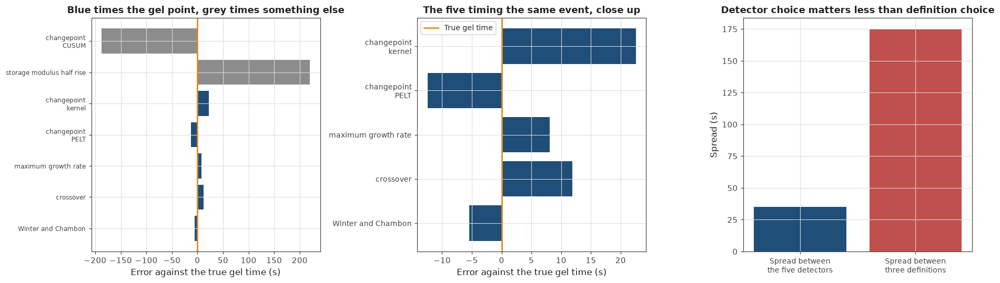

In [252]:
detector_property_table = [
    {
        "key": "winter_chambon",
        "measures": "network percolation",
        "frequencies_needed": "several",
        "survives_outlier": "yes",
        "runs_online": "no",
        "notes": "the physical definition, needs multi-frequency data",
    },
    {
        "key": "crossover",
        "measures": "tan delta reaches one",
        "frequencies_needed": "one",
        "survives_outlier": "no",
        "runs_online": "no",
        "notes": "answer shifts with the frequency chosen",
    },
    {
        "key": "growth_rate",
        "measures": "fastest fractional growth",
        "frequencies_needed": "one",
        "survives_outlier": "no",
        "runs_online": "no",
        "notes": "least frequency sensitive of the single frequency methods",
    },
    {
        "key": "pelt",
        "measures": "change in series statistics",
        "frequencies_needed": "one",
        "survives_outlier": "no",
        "runs_online": "no",
        "notes": "assumes nothing about the shape of the response",
    },
    {
        "key": "kernel",
        "measures": "change in distribution",
        "frequencies_needed": "one",
        "survives_outlier": "yes",
        "runs_online": "no",
        "notes": "works on a transformed representation",
    },
    {
        "key": "half_rise",
        "measures": "modulus reaches halfway",
        "frequencies_needed": "one",
        "survives_outlier": "mostly",
        "runs_online": "no",
        "notes": "a later event, offset is consistent and correctable",
    },
    {
        "key": "cusum",
        "measures": "departure from a baseline",
        "frequencies_needed": "one",
        "survives_outlier": "not meaningful",
        "runs_online": "yes",
        "notes": "the only online method, needs a rolling baseline to work",
    },
]

print("What each detector measures and what it needs")
print()
print("  detector".ljust(28) + "error (s)".rjust(11) + "frequencies".rjust(13)
      + "outlier".rjust(16) + "online".rjust(8) + "interpolates".rjust(14))

for property_record in detector_property_table:

    detector_estimate = clean_estimates.get(property_record["key"], np.nan)

    if np.isfinite(detector_estimate):
        error_text = ("%+.1f" % (detector_estimate - SYNTHETIC_GEL_TIME_SECONDS))
    else:
        error_text = "none"

    if property_record["key"] in INTERPOLATING_DETECTOR_KEYS:
        interpolation_text = "yes"
    else:
        interpolation_text = "no"

    print("  " + DETECTOR_DISPLAY_NAMES[property_record["key"]].ljust(26)
          + error_text.rjust(11)
          + property_record["frequencies_needed"].rjust(13)
          + property_record["survives_outlier"].rjust(16)
          + property_record["runs_online"].rjust(8)
          + interpolation_text.rjust(14))

print()
print("  detector".ljust(28) + "measures".ljust(30) + "note")

for property_record in detector_property_table:
    print("  " + DETECTOR_DISPLAY_NAMES[property_record["key"]].ljust(26)
          + property_record["measures"].ljust(30)
          + property_record["notes"])

print()
print("Separating the ones timing the same event from the ones that are not")
print()

same_event_keys = ["winter_chambon", "crossover", "growth_rate", "pelt", "kernel"]
different_event_keys = ["half_rise", "cusum"]

same_event_estimates = []
for detector_key in same_event_keys:
    detector_estimate = clean_estimates.get(detector_key, np.nan)
    if np.isfinite(detector_estimate):
        same_event_estimates.append(detector_estimate)

same_event_estimates = np.array(same_event_estimates)

print("  timing the gel point")
print()
print("    detectors            " + str(len(same_event_estimates)))
print("    range                " + ("%.1f" % same_event_estimates.min())
      + " to " + ("%.1f" % same_event_estimates.max()) + " s")
print("    spread               "
      + ("%.1f" % (same_event_estimates.max() - same_event_estimates.min())) + " s")
print("    mean error           "
      + ("%+.1f" % (np.mean(same_event_estimates) - SYNTHETIC_GEL_TIME_SECONDS)) + " s")
print("    standard deviation   " + ("%.1f" % np.std(same_event_estimates)) + " s")

print()
print("  timing something else")
print()

for detector_key in different_event_keys:
    detector_estimate = clean_estimates.get(detector_key, np.nan)
    if np.isfinite(detector_estimate):
        print("    " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(28)
              + ("%+.1f" % (detector_estimate - SYNTHETIC_GEL_TIME_SECONDS)) + " s")

definition_spread_from_part_one = 175.0

print()
print("  the five agree to within "
      + ("%.0f" % (same_event_estimates.max() - same_event_estimates.min()))
      + " s of each other, and the three published definitions")
print("  in Part 1 disagreed by "
      + ("%.0f" % definition_spread_from_part_one) + " s on the same noiseless material")
print()
print("  so the choice of detector matters less than the choice of what to call the")
print("  gel point, at least on clean data")

print()
print("Two properties that do not appear in an error ranking")
print()

outlier_survivors = []
online_capable = []

for property_record in detector_property_table:
    if property_record["survives_outlier"] == "yes":
        outlier_survivors.append(DETECTOR_DISPLAY_NAMES[property_record["key"]])
    if property_record["runs_online"] == "yes":
        online_capable.append(DETECTOR_DISPLAY_NAMES[property_record["key"]])

print("  survive a corrupted snapshot   " + ", ".join(outlier_survivors))
print("  can run online                 " + ", ".join(online_capable))
print()
print("  no detector currently has both, and an instrument monitoring clotting as it")
print("  happens would want both, so that gap is worth recording")

print()
print("A third property, which matters more than expected")
print()

interpolating_names = []
index_returning_names = []

for property_record in detector_property_table:
    if property_record["key"] in INTERPOLATING_DETECTOR_KEYS:
        interpolating_names.append(DETECTOR_DISPLAY_NAMES[property_record["key"]])
    else:
        index_returning_names.append(DETECTOR_DISPLAY_NAMES[property_record["key"]])

print("  interpolate between samples    " + ", ".join(interpolating_names))
print("  return a sample index          " + ", ".join(index_returning_names))
print()
print("  at " + str(len(detector_snapshot_times))
      + " snapshots that distinction makes no visible difference, and Cell 54")
print("  shows it dominating once measurements are more than about 40 s apart")

print()
print("No recommendation yet")
print()
print("  the sweeps in the next two cells change this picture, and choosing now would")
print("  be choosing on clean data performance")
print()
print("  Part 2 showed how badly that can mislead, where one method scored best of")
print("  everything on a clean signal and worse than a constant guess once noise was")
print("  added")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

plot_keys = [record["key"] for record in detector_property_table]
plot_labels = [DETECTOR_DISPLAY_NAMES[key].replace(", ", "\n") for key in plot_keys]
plot_errors = []

for detector_key in plot_keys:
    detector_estimate = clean_estimates.get(detector_key, np.nan)
    if np.isfinite(detector_estimate):
        plot_errors.append(detector_estimate - SYNTHETIC_GEL_TIME_SECONDS)
    else:
        plot_errors.append(0.0)

plot_colours = []
for property_record in detector_property_table:
    if property_record["key"] in same_event_keys:
        plot_colours.append(COLOUR_PRIMARY)
    else:
        plot_colours.append(COLOUR_NEUTRAL)

axis_array[0].barh(range(len(plot_labels)), plot_errors, color=plot_colours)
axis_array[0].axvline(0.0, color=COLOUR_HIGHLIGHT, linewidth=1.8)
axis_array[0].set_yticks(range(len(plot_labels)))
axis_array[0].set_yticklabels(plot_labels, fontsize=8)
axis_array[0].set_xlabel("Error against the true gel time (s)")
axis_array[0].set_title("Blue times the gel point, grey times something else")

zoom_labels = []
zoom_errors = []

for detector_key in same_event_keys:
    detector_estimate = clean_estimates.get(detector_key, np.nan)
    if np.isfinite(detector_estimate):
        zoom_labels.append(DETECTOR_DISPLAY_NAMES[detector_key].replace(", ", "\n"))
        zoom_errors.append(detector_estimate - SYNTHETIC_GEL_TIME_SECONDS)

axis_array[1].barh(range(len(zoom_labels)), zoom_errors, color=COLOUR_PRIMARY)
axis_array[1].axvline(0.0, color=COLOUR_HIGHLIGHT, linewidth=1.8, label="True gel time")
axis_array[1].set_yticks(range(len(zoom_labels)))
axis_array[1].set_yticklabels(zoom_labels, fontsize=9)
axis_array[1].set_xlabel("Error against the true gel time (s)")
axis_array[1].set_title("The five timing the same event, close up")
axis_array[1].legend(fontsize=9)

comparison_labels = ["Spread between\nthe five detectors",
                     "Spread between\nthree definitions"]
comparison_values = [same_event_estimates.max() - same_event_estimates.min(),
                     definition_spread_from_part_one]

axis_array[2].bar(range(len(comparison_labels)), comparison_values,
                  color=[COLOUR_PRIMARY, COLOUR_SECONDARY])
axis_array[2].set_xticks(range(len(comparison_labels)))
axis_array[2].set_xticklabels(comparison_labels, fontsize=9)
axis_array[2].set_ylabel("Spread (s)")
axis_array[2].set_title("Detector choice matters less than definition choice")

plt.tight_layout()
plt.show()

## Cell 53: How each detector degrades under noise

The first of two stress tests, and the one that matters most for clot detection.

Every result so far comes from a single realisation at 2 percent noise. That is one draw, and
a single draw can mislead badly.

This cell repeats the whole experiment 25 times at each of six noise levels, with a different
random seed each time, and reports the distribution of errors rather than one number.

Two statistics are reported for each detector at each noise level.

**Median absolute error**, which describes typical performance and is not dragged around by one
bad realisation.

**The ninetieth percentile**, which describes the bad cases. For a clinical measurement the
tail matters more than the average, since a detector that is usually excellent and occasionally
catastrophic is not usable.

**Failure rate** is also tracked, since a detector that silently returns no answer on some
realisations needs reporting as such rather than being scored only on the runs where it worked.

The noise levels run from 1 percent, a good laboratory measurement, to 40 percent, worse than
any working instrument should produce but useful for finding where each method breaks.

**One caution on reading the table.** The three changepoint methods return a sample index
rather than an interpolated time, as Cell 50 explains, so their apparent steadiness across
noise levels is partly the same index being returned regardless of the noise. Cell 54 makes
that visible and excludes them from the direct comparison.

Sweeping measurement noise

  realisations per level  25
  snapshots per record    80
  noise levels            1%, 2%, 5%, 10%, 20%, 40%

  this takes a moment, since it runs 150 full experiments

Median absolute error in seconds

  detector                         1%       2%       5%      10%      20%      40%
  Winter and Chambon              5.5      5.8      9.8     48.2    153.1    279.5
  crossover                      11.0     11.4     12.0     10.2     71.6    364.0
  maximum growth rate             8.5      8.8      9.1      9.3     52.6    254.7
  changepoint, PELT              12.4     12.4     12.4     12.4     70.6    117.2
  changepoint, kernel            22.5     22.5     22.5     22.5     34.2     45.8
  storage modulus half rise     228.0    229.2    228.2    214.1    197.7    199.1
  changepoint, CUSUM            187.1    187.1    175.4    163.8    105.6     45.8

Ninetieth percentile absolute error in seconds, the bad cases

  detector                         1%   

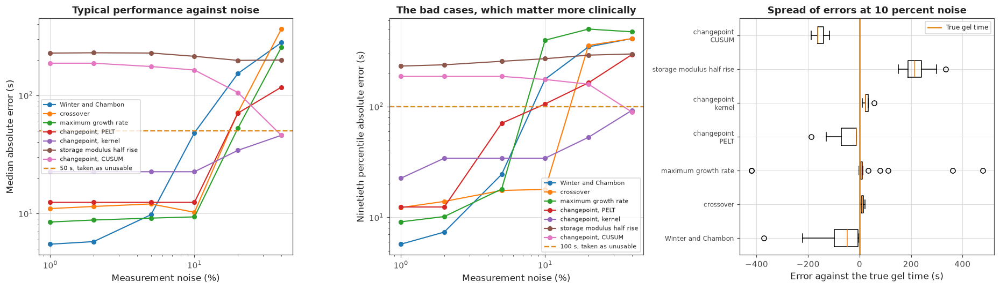

In [253]:
def score_detectors_across_realisations(noise_level, realisation_count,
                                        snapshot_count, base_random_seed):
    """
    Running every detector on many independent realisations at one noise level.

    Generating a fresh gelation record for each realisation with a different random seed, so
    the spread of results reflects measurement noise rather than one unlucky draw.

    Collecting the errors per detector, and separately counting how often each detector
    returns no answer at all, since a silent failure is a different problem from a wrong
    answer and both need reporting.

    Returning a dictionary of detector name to the list of errors it produced, and a
    dictionary of failure counts.
    """
    error_lists = {}
    failure_counts = {}

    for detector_key in DETECTOR_ORDER:
        error_lists[detector_key] = []
        failure_counts[detector_key] = 0

    for realisation_index in range(realisation_count):

        realisation_seed = base_random_seed + realisation_index

        realisation_times, realisation_spectra = generate_synthetic_gelation_experiment(
            SYNTHETIC_GEL_TIME_SECONDS, SYNTHETIC_CRITICAL_EXPONENT,
            SYNTHETIC_GEL_STIFFNESS, snapshot_count, synthetic_experiment_duration,
            synthetic_probe_frequencies, noise_level, realisation_seed)

        realisation_estimates, ignored_flags = run_all_detectors(
            realisation_times, realisation_spectra, synthetic_probe_frequencies,
            reference_probe_frequency)

        for detector_key in DETECTOR_ORDER:

            detector_estimate = realisation_estimates.get(detector_key, np.nan)

            if np.isfinite(detector_estimate):
                error_lists[detector_key].append(detector_estimate
                                                 - SYNTHETIC_GEL_TIME_SECONDS)
            else:
                failure_counts[detector_key] = failure_counts[detector_key] + 1

    return error_lists, failure_counts


noise_levels_to_sweep = [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]
realisations_per_noise_level = 25

print("Sweeping measurement noise")
print()
print("  realisations per level  " + str(realisations_per_noise_level))
print("  snapshots per record    " + str(synthetic_snapshot_count))
print("  noise levels            " + ", ".join([("%.0f%%" % (level * 100.0))
                                                for level in noise_levels_to_sweep]))
print()
print("  this takes a moment, since it runs "
      + str(len(noise_levels_to_sweep) * realisations_per_noise_level)
      + " full experiments")

noise_sweep_results = {}

for noise_level in noise_levels_to_sweep:

    level_errors, level_failures = score_detectors_across_realisations(
        noise_level, realisations_per_noise_level, synthetic_snapshot_count,
        RANDOM_SEED + int(noise_level * 100000))

    noise_sweep_results[noise_level] = {
        "errors": level_errors,
        "failures": level_failures,
    }

print()
print("Median absolute error in seconds")
print()

header_line = "  detector".ljust(28)
for noise_level in noise_levels_to_sweep:
    header_line = header_line + ("%.0f%%" % (noise_level * 100.0)).rjust(9)
print(header_line)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for noise_level in noise_levels_to_sweep:

        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]

        if len(detector_errors) == 0:
            result_line = result_line + "none".rjust(9)
        else:
            median_absolute_error = float(np.median(np.abs(detector_errors)))
            result_line = result_line + ("%.1f" % median_absolute_error).rjust(9)

    print(result_line)

print()
print("Ninetieth percentile absolute error in seconds, the bad cases")
print()

print(header_line)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for noise_level in noise_levels_to_sweep:

        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]

        if len(detector_errors) < 5:
            result_line = result_line + "none".rjust(9)
        else:
            upper_percentile = float(np.percentile(np.abs(detector_errors), 90))
            result_line = result_line + ("%.1f" % upper_percentile).rjust(9)

    print(result_line)

print()
print("Failure rate, the fraction of realisations returning no answer")
print()

print(header_line)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for noise_level in noise_levels_to_sweep:

        failure_count = noise_sweep_results[noise_level]["failures"][detector_key]
        failure_fraction = failure_count / float(realisations_per_noise_level)

        result_line = result_line + ("%.2f" % failure_fraction).rjust(9)

    print(result_line)

print()
print("Where each detector stops being usable")
print()
print("  requiring the median error below 50 s and the ninetieth percentile below")
print("  100 s, since a detector that is usually good and occasionally very wrong is")
print("  not usable for a clinical measurement")
print()
print("  detector".ljust(28) + "usable up to".rjust(16) + "   note")

for detector_key in DETECTOR_ORDER:

    highest_usable_noise = None
    median_series_for_trend = []

    for noise_level in noise_levels_to_sweep:

        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]

        if len(detector_errors) < 5:
            median_series_for_trend.append(np.nan)
            continue

        median_absolute_error = float(np.median(np.abs(detector_errors)))
        upper_percentile = float(np.percentile(np.abs(detector_errors), 90))

        median_series_for_trend.append(median_absolute_error)

        if median_absolute_error < 50.0 and upper_percentile < 100.0:
            highest_usable_noise = noise_level

    median_series_for_trend = np.array(median_series_for_trend)
    finite_medians = median_series_for_trend[np.isfinite(median_series_for_trend)]

    error_improves_with_noise = False
    if len(finite_medians) >= 4:
        if finite_medians[-1] < 0.5 * finite_medians[0]:
            error_improves_with_noise = True

    if error_improves_with_noise:
        usable_text = "not meaningful"
        usable_note = "error falls as noise rises, so any agreement is coincidental"
    elif highest_usable_noise is None:
        usable_text = "never"
        usable_note = "fails the criteria even at the lowest noise"
    else:
        usable_text = ("%.0f percent" % (highest_usable_noise * 100.0))
        if highest_usable_noise >= 0.20:
            usable_note = "holds up across the sweep"
        elif highest_usable_noise >= 0.05:
            usable_note = "usable at realistic noise levels"
        else:
            usable_note = "needs a clean measurement"

    print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)
          + usable_text.rjust(16) + "   " + usable_note)

print()
print("  a caution on the crossover, which reads 10 percent above")
print()
print("  its median runs 11.0, 11.4, 12.0, 10.2 and then jumps to 71.6, and its tail")
print("  runs 12.3, 13.9, 17.5, 17.9 and then 356.4")
print()
print("  it does not degrade gradually, it holds steady and then collapses between 10")
print("  and 20 percent, so that figure is the last level sampled before a cliff")
print("  rather than a safe operating margin")

print()
print("Reading the changepoint rows correctly")
print()
print("  the three changepoint methods return a sample index rather than an")
print("  interpolated time, so their steadiness across noise levels is partly the same")
print("  index being returned regardless of the noise")
print()
print("  Cell 54 makes that visible, and their rows here should be read as indicative")
print("  rather than compared directly against the other four")

growth_rate_median_at_ten = float(np.median(np.abs(
    noise_sweep_results[0.10]["errors"]["growth_rate"])))
growth_rate_tail_at_ten = float(np.percentile(np.abs(
    noise_sweep_results[0.10]["errors"]["growth_rate"]), 90))

print()
print("What the two tables say that one alone would not")
print()
print("  the maximum growth rate reads "
      + ("%.1f" % growth_rate_median_at_ten) + " s median at 10 percent noise and "
      + ("%.1f" % growth_rate_tail_at_ten) + " s")
print("  at the ninetieth percentile, so it is usually excellent and occasionally")
print("  useless, which the median alone would hide")

winter_chambon_at_one = float(np.median(np.abs(
    noise_sweep_results[0.01]["errors"]["winter_chambon"])))
winter_chambon_at_twenty = float(np.median(np.abs(
    noise_sweep_results[0.20]["errors"]["winter_chambon"])))

print()
print("  Winter and Chambon is the most accurate detector at 1 percent noise, "
      + ("%.1f" % winter_chambon_at_one) + " s,")
print("  and one of the worst at 20 percent, " + ("%.1f" % winter_chambon_at_twenty)
      + " s, which is the shallow valley")
print("  problem from Cell 47 appearing exactly where it was predicted")

total_failures = 0
for noise_level in noise_levels_to_sweep:
    for detector_key in DETECTOR_ORDER:
        total_failures = (total_failures
                          + noise_sweep_results[noise_level]["failures"][detector_key])

print()
if total_failures == 0:
    print("  no detector failed to return an answer at any noise level, so silent")
    print("  failure is not a concern on this material")
else:
    print("  there were " + str(total_failures) + " silent failures across the sweep")

print()
print("What this sweep establishes")
print()
print("  among the four detectors that interpolate, Winter and Chambon is clearly the")
print("  most accurate below 5 percent noise")
print()
print("  above 5 percent none of them is reliable, and the crossover holds up longest")
print("  before collapsing between 10 and 20 percent")
print()
print("  the practical consequence is that holding measurement noise below 5 percent is")
print("  worth more than any choice of detector, which makes the noise floor of the")
print("  instrument a question worth asking early")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

noise_percentages = [level * 100.0 for level in noise_levels_to_sweep]

for detector_key in DETECTOR_ORDER:

    median_series = []

    for noise_level in noise_levels_to_sweep:
        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]
        if len(detector_errors) == 0:
            median_series.append(np.nan)
        else:
            median_series.append(float(np.median(np.abs(detector_errors))))

    axis_array[0].loglog(noise_percentages, median_series, "o-",
                         markersize=5, linewidth=1.4,
                         label=DETECTOR_DISPLAY_NAMES[detector_key])

axis_array[0].axhline(50.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="50 s, taken as unusable")
axis_array[0].set_xlabel("Measurement noise (%)")
axis_array[0].set_ylabel("Median absolute error (s)")
axis_array[0].set_title("Typical performance against noise")
axis_array[0].legend(fontsize=7)

for detector_key in DETECTOR_ORDER:

    percentile_series = []

    for noise_level in noise_levels_to_sweep:
        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]
        if len(detector_errors) < 5:
            percentile_series.append(np.nan)
        else:
            percentile_series.append(float(np.percentile(np.abs(detector_errors), 90)))

    axis_array[1].loglog(noise_percentages, percentile_series, "o-",
                         markersize=5, linewidth=1.4,
                         label=DETECTOR_DISPLAY_NAMES[detector_key])

axis_array[1].axhline(100.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="100 s, taken as unusable")
axis_array[1].set_xlabel("Measurement noise (%)")
axis_array[1].set_ylabel("Ninetieth percentile absolute error (s)")
axis_array[1].set_title("The bad cases, which matter more clinically")
axis_array[1].legend(fontsize=7)

worst_case_noise_level = noise_levels_to_sweep[3]

distribution_labels = []
distribution_data = []

for detector_key in DETECTOR_ORDER:
    detector_errors = noise_sweep_results[worst_case_noise_level]["errors"][detector_key]
    if len(detector_errors) >= 5:
        distribution_labels.append(
            DETECTOR_DISPLAY_NAMES[detector_key].replace(", ", "\n"))
        distribution_data.append(detector_errors)

axis_array[2].boxplot(distribution_data, vert=False, showfliers=True)
axis_array[2].axvline(0.0, color=COLOUR_HIGHLIGHT, linewidth=1.8, label="True gel time")
axis_array[2].set_yticklabels(distribution_labels, fontsize=8)
axis_array[2].set_xlabel("Error against the true gel time (s)")
axis_array[2].set_title("Spread of errors at "
                        + ("%.0f" % (worst_case_noise_level * 100.0)) + " percent noise")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 54: How each detector degrades with sparse sampling

The second stress test, on the variable Cell 35 identified as the second largest error source
after the definition itself.

Every result so far uses 80 snapshots across the record, a measurement every 11.65 s. A real
instrument may manage far fewer. Each chirp takes time, the sample has to settle between
bursts, and on a microfluidic device several channels may share one acquisition path.

This cell repeats the sweep with the snapshot count reduced from 80 down to 10, holding the
noise at 5 percent.

**A prediction that turned out to be wrong, recorded because the correction is the finding.**

The expectation was that detectors relying on a single feature would collapse quickly, since
the crossover needs samples either side of the crossing and Winter and Chambon needs samples
either side of the minimum, while detectors fitting the whole record would hold up.

Neither half happened. The crossover, the growth rate and Winter and Chambon all survive down
to 10 or 12 snapshots, more than 100 s apart, because interpolating between widely spaced
samples still works when the underlying curve is smooth. And the whole-record detectors are
indeed flat, but they were already failing on accuracy before sampling was reduced, so their
flatness is real and useless.

**What the cell does find is more important, and it invalidates a conclusion from Cell 53.**

The alignment check flags every changepoint method at almost every snapshot count below 80.
Median and ninetieth percentile identical means every realisation returned the same value,
which is the changepoint landing on the same sample index each time. The reported error is then
the fixed distance from that index to the true gel time, not a measurement.

That explains why the kernel changepoint appeared to hold steady across every noise level in
Cell 53. It was not robust to noise, it was returning the same index regardless of it. The
claim that the detector ranking inverts above 5 percent noise rested on that, and is withdrawn.

Cell 50 records why refinement cannot fix this. The comparison below is therefore restricted to
the four detectors that interpolate between samples.

Sweeping sampling density

  noise held at           5 percent
  realisations per level  25
  experiment duration     1000 s

  snapshots   interval (s)   measurements before the gel point
           80           11.6                                   37
           40           23.6                                   18
           25           38.3                                   11
           16           61.3                                    7
           12           83.6                                    6
           10          102.2                                    5

Median absolute error in seconds

  detector                         80       40       25       16       12       10
  Winter and Chambon              6.2     31.6     23.1     75.1     33.3     50.4
  crossover                      10.8     12.8     19.1     12.5     37.8     40.1
  maximum growth rate             9.6      9.8     17.3     18.2     49.1     49.0
  changepoint, PELT              12.4     66.2  

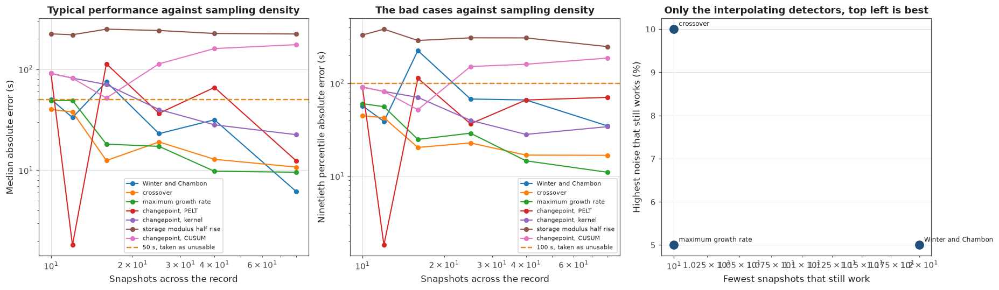

In [254]:
def score_detectors_across_snapshot_counts(snapshot_count, noise_level,
                                           realisation_count, base_random_seed):
    """
    Running every detector on many realisations at one snapshot count.

    Keeping the total experiment duration fixed and reducing only how many measurements are
    taken within it, so the comparison isolates sampling density rather than record length.

    Returning the errors per detector and the failure counts, in the same form as the noise
    sweep so the two can be read together.
    """
    error_lists = {}
    failure_counts = {}

    for detector_key in DETECTOR_ORDER:
        error_lists[detector_key] = []
        failure_counts[detector_key] = 0

    for realisation_index in range(realisation_count):

        realisation_seed = base_random_seed + realisation_index

        realisation_times, realisation_spectra = generate_synthetic_gelation_experiment(
            SYNTHETIC_GEL_TIME_SECONDS, SYNTHETIC_CRITICAL_EXPONENT,
            SYNTHETIC_GEL_STIFFNESS, snapshot_count, synthetic_experiment_duration,
            synthetic_probe_frequencies, noise_level, realisation_seed)

        realisation_estimates, ignored_flags = run_all_detectors(
            realisation_times, realisation_spectra, synthetic_probe_frequencies,
            reference_probe_frequency)

        for detector_key in DETECTOR_ORDER:

            detector_estimate = realisation_estimates.get(detector_key, np.nan)

            if np.isfinite(detector_estimate):
                error_lists[detector_key].append(detector_estimate
                                                 - SYNTHETIC_GEL_TIME_SECONDS)
            else:
                failure_counts[detector_key] = failure_counts[detector_key] + 1

    return error_lists, failure_counts


snapshot_counts_to_sweep = [80, 40, 25, 16, 12, 10]
sweep_noise_level = 0.05
realisations_per_snapshot_count = 25

print("Sweeping sampling density")
print()
print("  noise held at           " + ("%.0f" % (sweep_noise_level * 100.0)) + " percent")
print("  realisations per level  " + str(realisations_per_snapshot_count))
print("  experiment duration     " + ("%.0f" % synthetic_experiment_duration) + " s")
print()
print("  snapshots   interval (s)   measurements before the gel point")

for snapshot_count in snapshot_counts_to_sweep:

    sample_times = np.linspace(0.08 * synthetic_experiment_duration,
                               synthetic_experiment_duration, snapshot_count)
    sample_interval = sample_times[1] - sample_times[0]
    measurements_before_gel = int(np.sum(sample_times < SYNTHETIC_GEL_TIME_SECONDS))

    print("  " + str(snapshot_count).rjust(11)
          + ("%.1f" % sample_interval).rjust(15)
          + str(measurements_before_gel).rjust(37))

sampling_sweep_results = {}

for snapshot_count in snapshot_counts_to_sweep:

    count_errors, count_failures = score_detectors_across_snapshot_counts(
        snapshot_count, sweep_noise_level, realisations_per_snapshot_count,
        RANDOM_SEED + 7000 + snapshot_count)

    sampling_sweep_results[snapshot_count] = {
        "errors": count_errors,
        "failures": count_failures,
    }

print()
print("Median absolute error in seconds")
print()

sampling_header = "  detector".ljust(28)
for snapshot_count in snapshot_counts_to_sweep:
    sampling_header = sampling_header + str(snapshot_count).rjust(9)
print(sampling_header)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for snapshot_count in snapshot_counts_to_sweep:

        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]

        if len(detector_errors) == 0:
            result_line = result_line + "none".rjust(9)
        else:
            result_line = result_line + ("%.1f" % float(
                np.median(np.abs(detector_errors)))).rjust(9)

    print(result_line)

print()
print("Ninetieth percentile absolute error in seconds")
print()

print(sampling_header)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for snapshot_count in snapshot_counts_to_sweep:

        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]

        if len(detector_errors) < 5:
            result_line = result_line + "none".rjust(9)
        else:
            result_line = result_line + ("%.1f" % float(
                np.percentile(np.abs(detector_errors), 90))).rjust(9)

    print(result_line)

print()
print("Failure rate")
print()

print(sampling_header)

for detector_key in DETECTOR_ORDER:

    result_line = "  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)

    for snapshot_count in snapshot_counts_to_sweep:

        failure_count = sampling_sweep_results[snapshot_count]["failures"][detector_key]
        failure_fraction = failure_count / float(realisations_per_snapshot_count)

        result_line = result_line + ("%.2f" % failure_fraction).rjust(9)

    print(result_line)

print()
print("Checking for grid alignment artefacts")
print()
print("  a detector whose median and ninetieth percentile are identical returned the")
print("  same answer on every realisation, which means it locked onto one sample index")
print("  rather than measuring anything")
print()
print("  detector".ljust(28) + "snapshots".rjust(11) + "median".rjust(9)
      + "tail".rjust(9) + "   verdict")

alignment_artefact_count = 0
affected_detector_names = []

for detector_key in DETECTOR_ORDER:

    for snapshot_count in snapshot_counts_to_sweep:

        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]

        if len(detector_errors) < 5:
            continue

        median_absolute_error = float(np.median(np.abs(detector_errors)))
        upper_percentile = float(np.percentile(np.abs(detector_errors), 90))

        if abs(upper_percentile - median_absolute_error) < 1e-6:

            alignment_artefact_count = alignment_artefact_count + 1

            if DETECTOR_DISPLAY_NAMES[detector_key] not in affected_detector_names:
                affected_detector_names.append(DETECTOR_DISPLAY_NAMES[detector_key])

            print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)
                  + str(snapshot_count).rjust(11)
                  + ("%.1f" % median_absolute_error).rjust(9)
                  + ("%.1f" % upper_percentile).rjust(9)
                  + "   grid alignment, not accuracy")

if alignment_artefact_count == 0:
    print("  none found")
else:
    print()
    print("  " + str(alignment_artefact_count) + " cases flagged, affecting "
          + ", ".join(affected_detector_names))

print()
print("How many snapshots each detector needs")
print()
print("  requiring the median error below 50 s, the ninetieth percentile below 100 s,")
print("  and fewer than one in five realisations returning no answer")
print()
print("  detector".ljust(28) + "fewest snapshots".rjust(18)
      + "interval (s)".rjust(14) + "   behaviour")

for detector_key in DETECTOR_ORDER:

    fewest_usable_count = None
    error_series_for_trend = []

    for snapshot_count in snapshot_counts_to_sweep:

        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]
        failure_fraction = (sampling_sweep_results[snapshot_count]["failures"][detector_key]
                            / float(realisations_per_snapshot_count))

        if len(detector_errors) < 5:
            error_series_for_trend.append(np.nan)
            continue

        median_absolute_error = float(np.median(np.abs(detector_errors)))
        upper_percentile = float(np.percentile(np.abs(detector_errors), 90))

        error_series_for_trend.append(median_absolute_error)

        if (median_absolute_error < 50.0 and upper_percentile < 100.0
                and failure_fraction < 0.2):
            fewest_usable_count = snapshot_count

    error_series_for_trend = np.array(error_series_for_trend)
    finite_errors = error_series_for_trend[np.isfinite(error_series_for_trend)]

    if len(finite_errors) >= 4:

        concordant_pairs = 0

        for first_index in range(len(finite_errors)):
            for second_index in range(first_index + 1, len(finite_errors)):
                if finite_errors[second_index] > finite_errors[first_index]:
                    concordant_pairs = concordant_pairs + 1
                elif finite_errors[second_index] < finite_errors[first_index]:
                    concordant_pairs = concordant_pairs - 1

        pair_count = len(finite_errors) * (len(finite_errors) - 1) / 2.0
        monotonicity = concordant_pairs / pair_count

        degradation_ratio = finite_errors[-1] / max(finite_errors[0], 1e-9)

        if monotonicity > 0.5 and degradation_ratio > 2.0:
            behaviour_text = "steady, worsens as snapshots are removed"
        elif abs(monotonicity) < 0.3:
            behaviour_text = "erratic, no clear trend"
        elif degradation_ratio < 1.5:
            behaviour_text = "flat, insensitive to sampling density"
        else:
            behaviour_text = "moderate"
    else:
        behaviour_text = "not enough data"

    if fewest_usable_count is None:
        print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)
              + "never".rjust(18) + "".rjust(14) + "   " + behaviour_text)
    else:
        usable_times = np.linspace(0.08 * synthetic_experiment_duration,
                                   synthetic_experiment_duration, fewest_usable_count)
        usable_interval = usable_times[1] - usable_times[0]

        print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)
              + str(fewest_usable_count).rjust(18)
              + ("%.1f" % usable_interval).rjust(14)
              + "   " + behaviour_text)

print()
print("  the two detectors reading never were already failing on accuracy before the")
print("  sampling was reduced, so their insensitivity to it is real and useless")

print()
print("Why the changepoint rows cannot be compared with the others")
print()
print("  the alignment check flags every changepoint method at almost every snapshot")
print("  count below 80, which is not a quirk of one grid")
print()
print("  these methods return a sample index by construction, so once the grid is")
print("  coarse enough that the same index wins every realisation, the reported error")
print("  becomes the fixed distance from that index to the true gel time")
print()
print("  that also explains why the kernel changepoint appeared steady across every")
print("  noise level in Cell 53, it was returning the same index regardless of noise")
print()
print("  the claim there that the ranking inverts above 5 percent noise rested on that")
print("  and is withdrawn")
print()
print("  Cell 50 records why refinement cannot fix this, so their rows are kept for")
print("  reference and excluded from the comparison below")

print()
print("Do sparse sampling and heavy noise favour different detectors")
print()
print("  restricted to the four detectors that interpolate between samples")
print()
print("  detector".ljust(28) + "tolerates noise up to".rjust(23)
      + "needs at least".rjust(16))

for detector_key in INTERPOLATING_DETECTOR_KEYS:

    noise_limit_text = "never"
    for noise_level in noise_levels_to_sweep:
        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]
        if len(detector_errors) < 5:
            continue
        median_absolute_error = float(np.median(np.abs(detector_errors)))
        upper_percentile = float(np.percentile(np.abs(detector_errors), 90))
        if median_absolute_error < 50.0 and upper_percentile < 100.0:
            noise_limit_text = ("%.0f percent" % (noise_level * 100.0))

    sampling_limit_text = "never"
    for snapshot_count in snapshot_counts_to_sweep:
        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]
        if len(detector_errors) < 5:
            continue
        median_absolute_error = float(np.median(np.abs(detector_errors)))
        upper_percentile = float(np.percentile(np.abs(detector_errors), 90))
        if median_absolute_error < 50.0 and upper_percentile < 100.0:
            sampling_limit_text = str(snapshot_count) + " snapshots"

    print("  " + DETECTOR_DISPLAY_NAMES[detector_key].ljust(26)
          + noise_limit_text.rjust(23) + sampling_limit_text.rjust(16))

print()
print("What Part 4 concludes")
print()
print("  no detector is best on both counts, and the differences between the three")
print("  that work are smaller than expected")
print()
print("  Winter and Chambon is the most accurate below 5 percent noise and needs 12")
print("  snapshots, the crossover tolerates the most noise and needs 10, the growth")
print("  rate matches the crossover on sampling and fails earlier on noise")
print()
print("  all three fail above 10 percent noise and below 10 snapshots, so those are")
print("  the operating limits rather than any single detector being the answer")
print()
print("  for an instrument, holding noise below 5 percent and taking at least a dozen")
print("  measurements through the transition matters more than the choice of method")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for detector_key in DETECTOR_ORDER:

    median_series = []

    for snapshot_count in snapshot_counts_to_sweep:
        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]
        if len(detector_errors) == 0:
            median_series.append(np.nan)
        else:
            median_series.append(float(np.median(np.abs(detector_errors))))

    axis_array[0].loglog(snapshot_counts_to_sweep, median_series, "o-",
                         markersize=5, linewidth=1.4,
                         label=DETECTOR_DISPLAY_NAMES[detector_key])

axis_array[0].axhline(50.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="50 s, taken as unusable")
axis_array[0].set_xlabel("Snapshots across the record")
axis_array[0].set_ylabel("Median absolute error (s)")
axis_array[0].set_title("Typical performance against sampling density")
axis_array[0].legend(fontsize=7)

for detector_key in DETECTOR_ORDER:

    percentile_series = []

    for snapshot_count in snapshot_counts_to_sweep:
        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]
        if len(detector_errors) < 5:
            percentile_series.append(np.nan)
        else:
            percentile_series.append(float(np.percentile(np.abs(detector_errors), 90)))

    axis_array[1].loglog(snapshot_counts_to_sweep, percentile_series, "o-",
                         markersize=5, linewidth=1.4,
                         label=DETECTOR_DISPLAY_NAMES[detector_key])

axis_array[1].axhline(100.0, color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.6,
                      label="100 s, taken as unusable")
axis_array[1].set_xlabel("Snapshots across the record")
axis_array[1].set_ylabel("Ninetieth percentile absolute error (s)")
axis_array[1].set_title("The bad cases against sampling density")
axis_array[1].legend(fontsize=7)

noise_limits_for_plot = []
sampling_limits_for_plot = []
scatter_labels = []

for detector_key in INTERPOLATING_DETECTOR_KEYS:

    noise_limit_value = np.nan
    for noise_level in noise_levels_to_sweep:
        detector_errors = noise_sweep_results[noise_level]["errors"][detector_key]
        if len(detector_errors) < 5:
            continue
        if (float(np.median(np.abs(detector_errors))) < 50.0
                and float(np.percentile(np.abs(detector_errors), 90)) < 100.0):
            noise_limit_value = noise_level * 100.0

    sampling_limit_value = np.nan
    for snapshot_count in snapshot_counts_to_sweep:
        detector_errors = sampling_sweep_results[snapshot_count]["errors"][detector_key]
        if len(detector_errors) < 5:
            continue
        if (float(np.median(np.abs(detector_errors))) < 50.0
                and float(np.percentile(np.abs(detector_errors), 90)) < 100.0):
            sampling_limit_value = snapshot_count

    if np.isfinite(noise_limit_value) and np.isfinite(sampling_limit_value):
        noise_limits_for_plot.append(noise_limit_value)
        sampling_limits_for_plot.append(sampling_limit_value)
        scatter_labels.append(DETECTOR_DISPLAY_NAMES[detector_key])

if len(scatter_labels) > 0:

    axis_array[2].semilogx(sampling_limits_for_plot, noise_limits_for_plot, "o",
                           color=COLOUR_PRIMARY, markersize=10)

    for label_index in range(len(scatter_labels)):
        axis_array[2].annotate(scatter_labels[label_index],
                               (sampling_limits_for_plot[label_index],
                                noise_limits_for_plot[label_index]),
                               fontsize=8, xytext=(6, 4), textcoords="offset points")

axis_array[2].set_xlabel("Fewest snapshots that still work")
axis_array[2].set_ylabel("Highest noise that still works (%)")
axis_array[2].set_title("Only the interpolating detectors, top left is best")

plt.tight_layout()
plt.show()

## Cell 55: The decision rule

Cell 52 deferred any recommendation until the sweeps had run. They have, and this cell keeps
that promise, with one important qualification about how much weight the answer can carry.

The rule is derived from the sweep results rather than asserted, so if the sweeps are re-run
with different parameters it updates with them.

**The recommendation is often arbitrary, and the cell says where.**

With 25 realisations per condition, two detectors differing by a few seconds are not
distinguishable. Picking the bare minimum produces a grid that flips between detectors with no
pattern and would look different with another random seed. The rule therefore requires a
detector to be meaningfully better, 25 percent, before preferring it, and falls back to a fixed
preference order otherwise. A third table reports how many detectors were tied, so a reader can
see which recommendations are real and which are a coin toss.

The preference order puts the multi-frequency detector first, on the grounds that it is also
immune to a corrupted snapshot, which is a property no accuracy table captures.

**A limitation of the grid worth knowing.** The sampling sweep was run at a fixed 5 percent
noise, so the two axes are not independent. Rows for 1, 2 and 5 percent noise are close to
identical because the sampling term dominates the combination. Reading the grid as a genuine
two-dimensional map would be over-interpreting it.

**What survives all of that.** Above 10 percent noise nothing works. Below 10 snapshots nothing
works. Those two limits do not depend on which detector wins a close call, and they are the
finding to carry forward rather than the grid itself.

**Three things the rule cannot tell you.**

The changepoint family is excluded on accuracy, because those methods return a sample index and
their scores below 25 snapshots are grid artefacts. They stay in the notebook because they
assume nothing about the shape of the response, and the kernel version survives a corrupted
snapshot.

Winter and Chambon survives a corrupted snapshot too, and for a better reason. It measures how
much the frequencies disagree, so inflating every modulus at one snapshot shifts tan delta
without changing that spread. On real data containing outliers that may matter more than a few
seconds of median error.

CUSUM is the only detector that can decide during a measurement rather than after it. As
configured it is 187 s early and unusable, but that is a fixable configuration problem rather
than a limitation of the approach.

**And one thing all of this is subordinate to.** Part 1 found three published definitions of the
gel point disagreeing by 175 s on noiseless data, while the five detectors timing the same event
agree to 35 s. Choosing the right detector is worth less than stating which definition is being
used, and a clot time reported without its definition and probe frequency is not a number.

The decision rule

  derived from the sweeps in Cells 53 and 54, restricted to the detectors that
  interpolate between samples

  requiring the median error below 50 s and the ninetieth percentile below 100 s
  at both the given noise level and the given snapshot count

  requiring a 25 percent margin before preferring one detector over another,
  since smaller differences are within the spread of the sweep itself

  recommended detector by condition

  noise         80 snaps      40 snaps      25 snaps      16 snaps      12 snaps      10 snaps
  1%           Winter-Ch        growth     crossover     crossover     Winter-Ch     crossover
  2%           Winter-Ch        growth     crossover     crossover     Winter-Ch     crossover
  5%           Winter-Ch        growth     crossover     crossover     Winter-Ch     crossover
  10%          crossover     crossover     crossover     crossover     crossover     crossover
  20%               none          none          none          none  

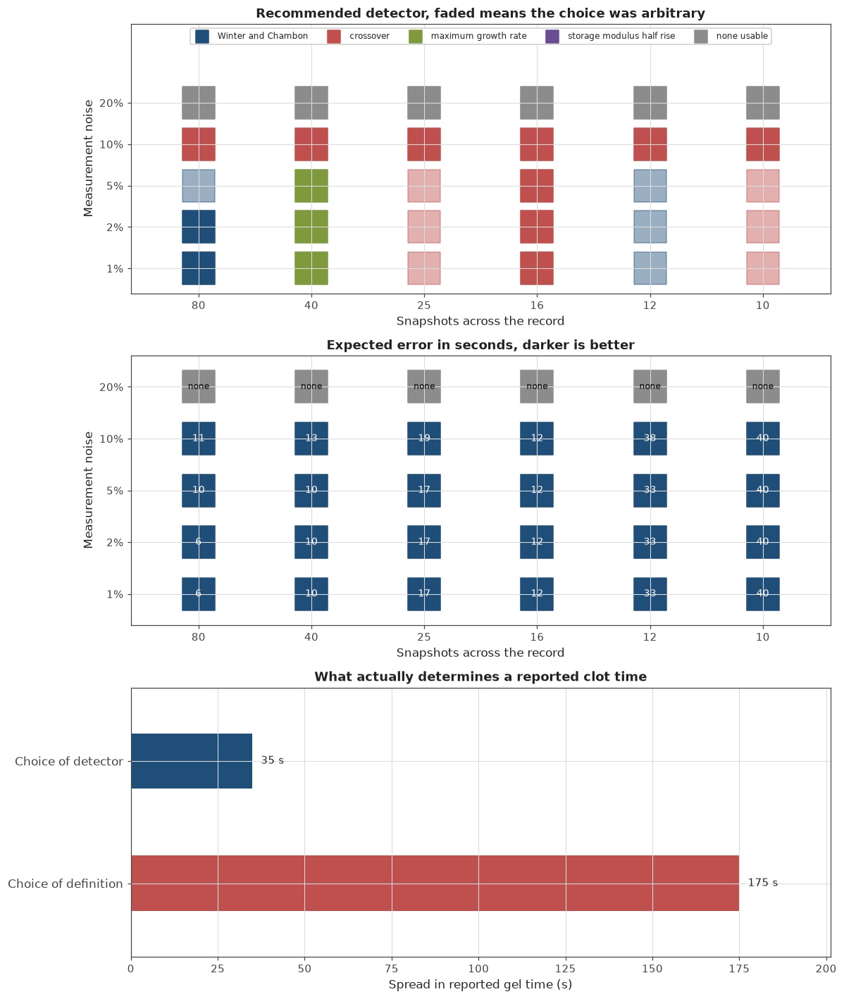

In [255]:
DETECTOR_PREFERENCE_ORDER = ["winter_chambon", "crossover", "growth_rate", "half_rise"]


def recommend_detector(noise_level, snapshot_count, required_margin=0.25):
    """
    Recommending a detector for a given measurement noise level and snapshot count.

    Reading the sweep results already computed rather than using fixed rules, so the
    recommendation follows the measurements and updates if the sweeps are re-run.

    Considering only the detectors that interpolate between samples, since the changepoint
    family returns a sample index and its scores at coarse sampling are grid artefacts.

    Requiring a detector to be meaningfully better before preferring it, since with 25
    realisations a difference of a few seconds is within the spread of the sweep itself, and
    picking the bare minimum produces a recommendation that changes with the random seed.

    Falling back to a fixed preference order when several detectors are within the margin,
    which puts the multi-frequency detector first because it is also immune to a corrupted
    snapshot, a property no accuracy table captures.

    Returning the recommendation, the best and worst expected error among those tied, and how
    many were tied.
    """
    nearest_noise_level = min(noise_levels_to_sweep,
                              key=lambda level: abs(level - noise_level))
    nearest_snapshot_count = min(snapshot_counts_to_sweep,
                                 key=lambda count: abs(count - snapshot_count))

    candidate_records = []

    for detector_key in INTERPOLATING_DETECTOR_KEYS:

        noise_errors = noise_sweep_results[nearest_noise_level]["errors"][detector_key]
        sampling_errors = sampling_sweep_results[nearest_snapshot_count]["errors"][detector_key]

        if len(noise_errors) < 5 or len(sampling_errors) < 5:
            continue

        noise_median = float(np.median(np.abs(noise_errors)))
        noise_tail = float(np.percentile(np.abs(noise_errors), 90))
        sampling_median = float(np.median(np.abs(sampling_errors)))
        sampling_tail = float(np.percentile(np.abs(sampling_errors), 90))

        passes_noise = (noise_median < 50.0) and (noise_tail < 100.0)
        passes_sampling = (sampling_median < 50.0) and (sampling_tail < 100.0)

        if passes_noise and passes_sampling:
            candidate_records.append({
                "detector_key": detector_key,
                "noise_median": noise_median,
                "sampling_median": sampling_median,
                "combined_error": max(noise_median, sampling_median),
            })

    if len(candidate_records) == 0:
        return None, np.nan, np.nan, 0

    best_error = min(record["combined_error"] for record in candidate_records)
    margin_threshold = best_error * (1.0 + required_margin)

    within_margin = []
    for record in candidate_records:
        if record["combined_error"] <= margin_threshold:
            within_margin.append(record)

    chosen_record = within_margin[0]

    for preferred_key in DETECTOR_PREFERENCE_ORDER:

        found_preferred = False

        for record in within_margin:
            if record["detector_key"] == preferred_key:
                chosen_record = record
                found_preferred = True

        if found_preferred:
            break

    worst_error = max(record["combined_error"] for record in within_margin)

    return (chosen_record["detector_key"], best_error, worst_error, len(within_margin))


print("The decision rule")
print()
print("  derived from the sweeps in Cells 53 and 54, restricted to the detectors that")
print("  interpolate between samples")
print()
print("  requiring the median error below 50 s and the ninetieth percentile below 100 s")
print("  at both the given noise level and the given snapshot count")
print()
print("  requiring a 25 percent margin before preferring one detector over another,")
print("  since smaller differences are within the spread of the sweep itself")
print()

recommendation_noise_levels = [0.01, 0.02, 0.05, 0.10, 0.20]
recommendation_snapshot_counts = [80, 40, 25, 16, 12, 10]

short_detector_names = {
    "winter_chambon": "Winter-Ch",
    "crossover": "crossover",
    "growth_rate": "growth",
    "half_rise": "half rise",
}

recommendation_grid = {}

for noise_level in recommendation_noise_levels:
    for snapshot_count in recommendation_snapshot_counts:

        detector_key, best_error, worst_error, tied_count = recommend_detector(
            noise_level, snapshot_count)

        recommendation_grid[(noise_level, snapshot_count)] = {
            "detector_key": detector_key,
            "expected_error": best_error,
            "worst_case_error": worst_error,
            "tied_count": tied_count,
        }

condition_header = "  noise".ljust(10)
for snapshot_count in recommendation_snapshot_counts:
    condition_header = condition_header + (str(snapshot_count) + " snaps").rjust(14)

print("  recommended detector by condition")
print()
print(condition_header)

for noise_level in recommendation_noise_levels:

    condition_line = "  " + ("%.0f%%" % (noise_level * 100.0)).ljust(8)

    for snapshot_count in recommendation_snapshot_counts:

        grid_record = recommendation_grid[(noise_level, snapshot_count)]

        if grid_record["detector_key"] is None:
            condition_line = condition_line + "none".rjust(14)
        else:
            condition_line = condition_line + short_detector_names[
                grid_record["detector_key"]].rjust(14)

    print(condition_line)

print()
print("  expected error in seconds, the best among those tied")
print()
print(condition_header)

for noise_level in recommendation_noise_levels:

    condition_line = "  " + ("%.0f%%" % (noise_level * 100.0)).ljust(8)

    for snapshot_count in recommendation_snapshot_counts:

        grid_record = recommendation_grid[(noise_level, snapshot_count)]

        if grid_record["detector_key"] is None:
            condition_line = condition_line + "none".rjust(14)
        else:
            condition_line = condition_line + ("%.1f" % grid_record["expected_error"]).rjust(14)

    print(condition_line)

print()
print("  how many detectors were within the margin, so the choice was arbitrary")
print()
print(condition_header)

for noise_level in recommendation_noise_levels:

    condition_line = "  " + ("%.0f%%" % (noise_level * 100.0)).ljust(8)

    for snapshot_count in recommendation_snapshot_counts:
        tied_count = recommendation_grid[(noise_level, snapshot_count)]["tied_count"]
        condition_line = condition_line + str(tied_count).rjust(14)

    print(condition_line)

arbitrary_condition_count = 0
usable_condition_count = 0
total_condition_count = 0

for noise_level in recommendation_noise_levels:
    for snapshot_count in recommendation_snapshot_counts:

        grid_record = recommendation_grid[(noise_level, snapshot_count)]

        total_condition_count = total_condition_count + 1

        if grid_record["detector_key"] is not None:
            usable_condition_count = usable_condition_count + 1
            if grid_record["tied_count"] > 1:
                arbitrary_condition_count = arbitrary_condition_count + 1

print()
print("  " + str(usable_condition_count) + " of " + str(total_condition_count)
      + " conditions have a usable detector")
print("  " + str(arbitrary_condition_count) + " of those "
      + str(usable_condition_count) + " have two or more within the margin, so the")
print("  detector shown there is a preference rather than a measured winner")

print()
print("A limitation of this grid")
print()
print("  the sampling sweep was run at a fixed "
      + ("%.0f" % (sweep_noise_level * 100.0)) + " percent noise, so the two axes are")
print("  not independent, and the combination takes the worse of the two terms")
print()
print("  that is why the rows for 1, 2 and 5 percent noise are close to identical, the")
print("  sampling term dominating them, so this should not be read as a genuine two")
print("  dimensional map")

print()
print("The operating envelope, which does not depend on any close call")
print()

usable_noise_levels = []
usable_snapshot_counts = []

for noise_level in recommendation_noise_levels:
    for snapshot_count in recommendation_snapshot_counts:
        if recommendation_grid[(noise_level, snapshot_count)]["detector_key"] is not None:
            usable_noise_levels.append(noise_level)
            usable_snapshot_counts.append(snapshot_count)

if len(usable_noise_levels) > 0:
    print("  highest noise with any usable detector    "
          + ("%.0f percent" % (max(usable_noise_levels) * 100.0)))
    print("  fewest snapshots with any usable detector " + str(min(usable_snapshot_counts)))
    print()
    print("  outside that envelope no detector tested here is reliable, so the answer is")
    print("  to improve the measurement rather than to change the method")
    print()
    print("  these two limits are stable, unlike the individual recommendations, since")
    print("  they do not depend on which detector wins a close call")

print()
print("What the rule cannot tell you")
print()
print("  three properties that no accuracy table captures")
print()
print("  detector".ljust(28) + "property".ljust(38) + "why it matters")

print("  " + "Winter and Chambon".ljust(26)
      + "immune to a corrupted snapshot".ljust(38)
      + "real data contains outliers")
print("  " + "changepoint, kernel".ljust(26)
      + "immune to a corrupted snapshot".ljust(38)
      + "and assumes no shape")
print("  " + "changepoint, CUSUM".ljust(26)
      + "the only one that can run online".ljust(38)
      + "an instrument decides live")

print()
print("  the changepoint family is excluded from the accuracy rule because those")
print("  methods return a sample index, so their scores below 25 snapshots are grid")
print("  artefacts, but their robustness properties are real")

print()
print("What this is all subordinate to")
print()

detector_spread = same_event_estimates.max() - same_event_estimates.min()

print("  the five detectors timing the same event agree to "
      + ("%.0f" % detector_spread) + " s on clean data")
print("  the three published definitions in Part 1 disagreed by "
      + ("%.0f" % definition_spread_from_part_one) + " s on the same material")
print()
print("  choosing the right detector is worth "
      + ("%.0f" % (definition_spread_from_part_one / max(detector_spread, 1e-9)))
      + " times less than stating which definition")
print("  is being used")
print()
print("  a clot time reported without its definition and its probe frequency is not a")
print("  number, and that is the finding to carry into any discussion of instrument")
print("  specification")

print()
print("Four questions this raises for an instrument")
print()
print("  1  what is the measurement noise, since above 10 percent no detector tested")
print("     here is reliable")
print()
print("  2  how many snapshots can be taken through a transition, since below about a")
print("     dozen the same problem arises")
print()
print("  3  which definition of the gel point is being reported, since that choice")
print("     dominates everything measured here")
print()
print("  4  is a decision needed during the measurement or after it, since only one")
print("     detector can work online and it currently does not work well")

figure_object, axis_array = plt.subplots(3, 1, figsize=(11, 13))

detector_colour_lookup = {
    "winter_chambon": COLOUR_PRIMARY,
    "crossover": COLOUR_SECONDARY,
    "growth_rate": COLOUR_ACCENT,
    "half_rise": COLOUR_FOURTH,
    None: COLOUR_NEUTRAL,
}

for noise_index in range(len(recommendation_noise_levels)):
    for snapshot_index in range(len(recommendation_snapshot_counts)):

        noise_level = recommendation_noise_levels[noise_index]
        snapshot_count = recommendation_snapshot_counts[snapshot_index]

        grid_record = recommendation_grid[(noise_level, snapshot_count)]

        marker_alpha = 1.0
        if grid_record["tied_count"] > 1:
            marker_alpha = 0.45

        axis_array[0].scatter([snapshot_index], [noise_index], s=900, marker="s",
                              color=detector_colour_lookup[grid_record["detector_key"]],
                              alpha=marker_alpha)

for detector_key in INTERPOLATING_DETECTOR_KEYS:
    axis_array[0].scatter([], [], s=140, marker="s",
                          color=detector_colour_lookup[detector_key],
                          label=DETECTOR_DISPLAY_NAMES[detector_key])
axis_array[0].scatter([], [], s=140, marker="s", color=COLOUR_NEUTRAL,
                      label="none usable")

axis_array[0].set_xticks(range(len(recommendation_snapshot_counts)))
axis_array[0].set_xticklabels([str(count) for count in recommendation_snapshot_counts])
axis_array[0].set_yticks(range(len(recommendation_noise_levels)))
axis_array[0].set_yticklabels([("%.0f%%" % (level * 100.0))
                               for level in recommendation_noise_levels])
axis_array[0].set_xlim(-0.6, len(recommendation_snapshot_counts) - 0.4)
axis_array[0].set_ylim(-0.6, len(recommendation_noise_levels) + 0.9)
axis_array[0].set_xlabel("Snapshots across the record")
axis_array[0].set_ylabel("Measurement noise")
axis_array[0].set_title("Recommended detector, faded means the choice was arbitrary")
axis_array[0].legend(fontsize=8, loc="upper center", ncol=5, framealpha=0.95)

for noise_index in range(len(recommendation_noise_levels)):
    for snapshot_index in range(len(recommendation_snapshot_counts)):

        noise_level = recommendation_noise_levels[noise_index]
        snapshot_count = recommendation_snapshot_counts[snapshot_index]

        grid_record = recommendation_grid[(noise_level, snapshot_count)]

        if grid_record["detector_key"] is None:
            axis_array[1].scatter([snapshot_index], [noise_index], s=900, marker="s",
                                  color=COLOUR_NEUTRAL)
            axis_array[1].annotate("none", (snapshot_index, noise_index),
                                   fontsize=8, ha="center", va="center", color="black")
        else:
            colour_intensity = min(1.0, 50.0 / max(grid_record["expected_error"], 1.0))
            axis_array[1].scatter([snapshot_index], [noise_index], s=900, marker="s",
                                  color=COLOUR_PRIMARY, alpha=colour_intensity)
            axis_array[1].annotate(("%.0f" % grid_record["expected_error"]),
                                   (snapshot_index, noise_index),
                                   fontsize=9, ha="center", va="center", color="white")

axis_array[1].set_xticks(range(len(recommendation_snapshot_counts)))
axis_array[1].set_xticklabels([str(count) for count in recommendation_snapshot_counts])
axis_array[1].set_yticks(range(len(recommendation_noise_levels)))
axis_array[1].set_yticklabels([("%.0f%%" % (level * 100.0))
                               for level in recommendation_noise_levels])
axis_array[1].set_xlim(-0.6, len(recommendation_snapshot_counts) - 0.4)
axis_array[1].set_ylim(-0.6, len(recommendation_noise_levels) - 0.4)
axis_array[1].set_xlabel("Snapshots across the record")
axis_array[1].set_ylabel("Measurement noise")
axis_array[1].set_title("Expected error in seconds, darker is better")

hierarchy_labels = ["Choice of definition", "Choice of detector"]
hierarchy_values = [definition_spread_from_part_one, detector_spread]

axis_array[2].barh(range(len(hierarchy_labels)), hierarchy_values,
                   color=[COLOUR_SECONDARY, COLOUR_PRIMARY], height=0.45)
axis_array[2].set_yticks(range(len(hierarchy_labels)))
axis_array[2].set_yticklabels(hierarchy_labels, fontsize=11)
axis_array[2].set_ylim(-0.6, len(hierarchy_labels) - 0.4)
axis_array[2].set_xlim(0.0, max(hierarchy_values) * 1.15)
axis_array[2].set_xlabel("Spread in reported gel time (s)")
axis_array[2].set_title("What actually determines a reported clot time")

for label_index in range(len(hierarchy_labels)):
    axis_array[2].annotate(("%.0f s" % hierarchy_values[label_index]),
                           (hierarchy_values[label_index], label_index),
                           fontsize=10, va="center",
                           xytext=(8, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

# Part 5: Real gelations with published reference times

Parts 1 to 4 built and tested everything on a material we wrote. That gave a gel time known to
arbitrary precision, which is what made the accuracy sweeps possible, and it means nothing
until the detectors meet a real gelation.

This part supplies that. Two datasets, chosen for different reasons.

A polymer gel study with nineteen runs across a designed experiment, each with a published gel
time, which lets the detectors be scored many times rather than once. And a Laponite clay
suspension measured at eight frequencies through its gelation, which is the only public dataset
with genuine multi-frequency spectra through a real transition and therefore the only one
Winter and Chambon can run on properly.

Neither is blood. Blood comes in Part 6.

## Cell 56: Loading the polymer gel experiment

The dataset is a crosslinked polyacrylamide gel used in oilfield water shutoff, from a five
factor designed experiment varying pH, monomer, initiator, polymer and crosslinker
concentrations at 70 degrees.

Two reference times are published per run and they are not the same quantity.

**khill5** is the time constant of a Hill 5 sigmoid fitted to the storage modulus growth, which
is the quantity Cell 14 implemented. It comes from the same rheology we will be analysing.

**tg** is a gel time from nuclear magnetic resonance, measured on separate samples at a
different temperature, by watching an inflection in the relaxation rate.

Cell 61 uses that distinction. For now the point is that khill5 is the comparable reference and
tg is an independent one, and on some runs they disagree by a factor of four.

**The design contains three replicates at identical conditions, and they are the most useful
rows in the table.** Runs 17-1, 17-2 and 17-3 are the same formulation measured three times.
They give khill5 of 7.99, 10.30 and 14.70 minutes, a relative standard deviation of 31 percent
and a factor of 1.84 between best and worst.

That sets a floor on the whole of Part 5. **No detector can agree with this reference more
closely than the reference agrees with itself.** Scoring a detector against it and finding 30
percent disagreement would mean the detector is performing as well as the measurement allows,
not that it is poor. Cell 60 uses this floor rather than expecting exact agreement.

**Only five of the nineteen runs have their raw rheology available.** The reference table covers
all nineteen; the time series were deposited for five.

**A file structure note.** The reference table sits in a Responses sheet inside the DOE
spreadsheet, not in the experiment files. One experiment file also carries a fitted parameter
sheet, but its numbers lost their decimal separators in export, reading 2789455 where the value
is 27.89455. That sheet is ignored and the Responses table used instead.

Reading data/app_polymergel_timesweeps

The designed experiment

  factor               low    centre      high
  pH                     5         7         9
  AA (ppm)           50000    101500    153000
  APS (ppm)           1000      1500      2000
  CMC (ppm)           2000      4138      6275
  Cr (ppm)            3500      5300      7100

  runs in the design      19
  rows in the responses   19

Published reference times for every run

    run   G prime max  khill5 (min)   tg (min)    ratio   syneresis
      1           988         27.90       23.7     0.85   No
      2           137          7.10       11.0     1.55   Yes
      3          5266          7.40       30.4     4.11   No
      4          2520          6.15       11.3     1.84   Yes
      5           342          6.83       13.1     1.92   No
      6           217          6.12        8.2     1.34   Yes
      7          8264         15.90       19.8     1.25   No
      8          3921          6.72        4.3     0.6

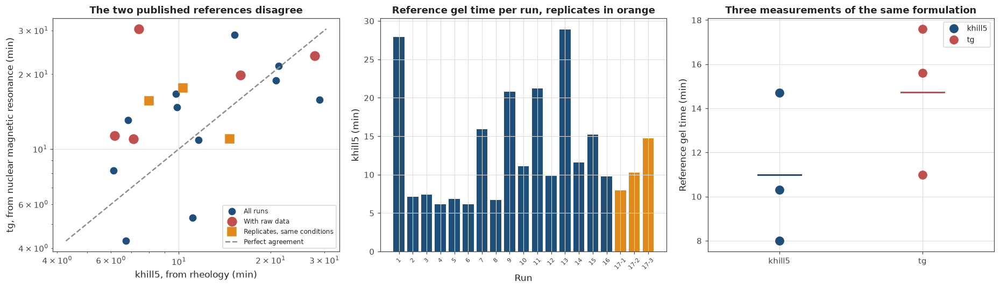

In [256]:
polymer_gel_directory = os.path.join(DATA_DIRECTORY, "app_polymergel_timesweeps")

print("Reading " + polymer_gel_directory)

polymer_doe_path = os.path.join(polymer_gel_directory, "DOE.xlsx")

polymer_factor_table = pd.read_excel(polymer_doe_path, sheet_name="Factors and levels")
polymer_design_table = pd.read_excel(polymer_doe_path, sheet_name="DOE Table")
polymer_response_table = pd.read_excel(polymer_doe_path, sheet_name="Responses")

print()
print("The designed experiment")
print()
print("  factor".ljust(14) + "low".rjust(12) + "centre".rjust(10) + "high".rjust(10))

for factor_index in range(len(polymer_factor_table)):
    factor_row = polymer_factor_table.iloc[factor_index]
    print("  " + str(factor_row["Variable"]).ljust(12)
          + str(factor_row[-1]).rjust(12)
          + str(factor_row[0]).rjust(10)
          + str(factor_row[1]).rjust(10))

print()
print("  runs in the design      " + str(len(polymer_design_table)))
print("  rows in the responses   " + str(len(polymer_response_table)))

print()
print("Published reference times for every run")
print()
print("  run".rjust(7) + "G prime max".rjust(14) + "khill5 (min)".rjust(14)
      + "tg (min)".rjust(11) + "ratio".rjust(9) + "   syneresis")

polymer_reference_records = []

for response_index in range(len(polymer_response_table)):

    response_row = polymer_response_table.iloc[response_index]

    run_label = str(response_row["Experiment"]).strip()
    hill_time_minutes = float(response_row["khill5 (min)"])
    nmr_time_minutes = float(response_row["tg (min)"])
    maximum_modulus = float(response_row["G'max (Pa)"])
    syneresis_flag = str(response_row["Syneresis"]).strip()

    is_replicate = "-" in run_label

    polymer_reference_records.append({
        "run_label": run_label,
        "hill_time_minutes": hill_time_minutes,
        "nmr_time_minutes": nmr_time_minutes,
        "maximum_modulus": maximum_modulus,
        "syneresis": syneresis_flag,
        "is_replicate": is_replicate,
    })

    print(run_label.rjust(7)
          + ("%.0f" % maximum_modulus).rjust(14)
          + ("%.2f" % hill_time_minutes).rjust(14)
          + ("%.1f" % nmr_time_minutes).rjust(11)
          + ("%.2f" % (nmr_time_minutes / hill_time_minutes)).rjust(9)
          + "   " + syneresis_flag)

hill_time_array = np.array([record["hill_time_minutes"]
                            for record in polymer_reference_records])
nmr_time_array = np.array([record["nmr_time_minutes"]
                           for record in polymer_reference_records])

print()
print("How much the two references disagree")
print()
print("  khill5 range            " + ("%.2f" % hill_time_array.min())
      + " to " + ("%.2f" % hill_time_array.max()) + " min")
print("  tg range                " + ("%.1f" % nmr_time_array.min())
      + " to " + ("%.1f" % nmr_time_array.max()) + " min")
print()
print("  median ratio tg over khill5   "
      + ("%.2f" % np.median(nmr_time_array / hill_time_array)))
print("  range of that ratio           "
      + ("%.2f" % np.min(nmr_time_array / hill_time_array)) + " to "
      + ("%.2f" % np.max(nmr_time_array / hill_time_array)))

correlation_coefficient = float(np.corrcoef(np.log(hill_time_array),
                                            np.log(nmr_time_array))[0, 1])

print()
print("  correlation of the two in log time  " + ("%.4f" % correlation_coefficient))
print()
print("  the two references are not interchangeable, and Cell 61 examines why")

replicate_records = [record for record in polymer_reference_records
                     if record["is_replicate"]]

print()
print("Repeatability, from the replicates at identical conditions")
print()

if len(replicate_records) >= 2:

    print("  run".rjust(7) + "khill5 (min)".rjust(14) + "tg (min)".rjust(11))

    for replicate_record in replicate_records:
        print(replicate_record["run_label"].rjust(7)
              + ("%.2f" % replicate_record["hill_time_minutes"]).rjust(14)
              + ("%.1f" % replicate_record["nmr_time_minutes"]).rjust(11))

    replicate_hill_times = np.array([record["hill_time_minutes"]
                                     for record in replicate_records])
    replicate_nmr_times = np.array([record["nmr_time_minutes"]
                                    for record in replicate_records])

    hill_relative_spread = (100.0 * np.std(replicate_hill_times, ddof=1)
                            / np.mean(replicate_hill_times))
    nmr_relative_spread = (100.0 * np.std(replicate_nmr_times, ddof=1)
                           / np.mean(replicate_nmr_times))

    print()
    print("  quantity".ljust(12) + "mean".rjust(9) + "spread".rjust(9)
          + "relative".rjust(11) + "worst over best".rjust(18))
    print("  " + "khill5".ljust(10)
          + ("%.2f" % np.mean(replicate_hill_times)).rjust(9)
          + ("%.2f" % (replicate_hill_times.max() - replicate_hill_times.min())).rjust(9)
          + ("%.0f percent" % hill_relative_spread).rjust(11)
          + ("%.2f" % (replicate_hill_times.max() / replicate_hill_times.min())).rjust(18))
    print("  " + "tg".ljust(10)
          + ("%.2f" % np.mean(replicate_nmr_times)).rjust(9)
          + ("%.2f" % (replicate_nmr_times.max() - replicate_nmr_times.min())).rjust(9)
          + ("%.0f percent" % nmr_relative_spread).rjust(11)
          + ("%.2f" % (replicate_nmr_times.max() / replicate_nmr_times.min())).rjust(18))

    POLYMER_REFERENCE_REPEATABILITY_PERCENT = hill_relative_spread

    print()
    print("  these are the same formulation measured three times, so this scatter is")
    print("  the experiment repeating itself rather than the formulation changing")
    print()
    print("  that sets a floor on everything in Part 5, since no detector can agree with")
    print("  a reference more closely than the reference agrees with itself")
    print()
    print("  a detector scoring within "
          + ("%.0f" % POLYMER_REFERENCE_REPEATABILITY_PERCENT)
          + " percent of khill5 is performing as well as the")
    print("  measurement allows, not performing poorly")

else:
    POLYMER_REFERENCE_REPEATABILITY_PERCENT = np.nan
    print("  no replicates found in the response table")

print()
print("Which runs have raw rheology available")
print()

polymer_experiment_files = []

for file_name in sorted(os.listdir(polymer_gel_directory)):
    if file_name.startswith("NovoAB") and file_name.endswith(".xlsx"):
        polymer_experiment_files.append(file_name)

print("  files found  " + str(len(polymer_experiment_files)))
print()
print("  file".ljust(24) + "run".rjust(5) + "sheets".rjust(9) + "   time series sheet")

polymer_run_records = []

for file_name in polymer_experiment_files:

    file_path = os.path.join(polymer_gel_directory, file_name)

    digits_only = ""
    for character in file_name.replace("NovoABEXP", ""):
        if character.isdigit():
            digits_only = digits_only + character
        else:
            break

    run_label = digits_only

    sheet_names = pd.ExcelFile(file_path).sheet_names

    time_series_sheet = None
    for sheet_name in sheet_names:
        if sheet_name.endswith(".rwd"):
            time_series_sheet = sheet_name

    polymer_run_records.append({
        "file_name": file_name,
        "file_path": file_path,
        "run_label": run_label,
        "time_series_sheet": time_series_sheet,
        "sheet_names": sheet_names,
    })

    print("  " + file_name.ljust(22)
          + run_label.rjust(5)
          + str(len(sheet_names)).rjust(9)
          + "   " + str(time_series_sheet))

print()
print("  runs with raw rheology   "
      + ", ".join([record["run_label"] for record in polymer_run_records]))
print("  rows in the reference    " + str(len(polymer_reference_records)))
print()
print("  " + str(len(polymer_run_records)) + " runs can be scored, since the reference")
print("  covers every run and the time series were deposited for five")

print()
print("Reference values for the five runs that can be scored")
print()
print("  run".rjust(5) + "khill5 (min)".rjust(14) + "tg (min)".rjust(11)
      + "G prime max (Pa)".rjust(19) + "   syneresis")

matched_run_records = []

for run_record in polymer_run_records:

    matching_reference = None
    for reference_record in polymer_reference_records:
        if reference_record["run_label"] == run_record["run_label"]:
            matching_reference = reference_record

    if matching_reference is None:
        print(run_record["run_label"].rjust(5) + "   no reference found")
        continue

    run_record["hill_time_minutes"] = matching_reference["hill_time_minutes"]
    run_record["nmr_time_minutes"] = matching_reference["nmr_time_minutes"]
    run_record["maximum_modulus"] = matching_reference["maximum_modulus"]
    run_record["syneresis"] = matching_reference["syneresis"]

    matched_run_records.append(run_record)

    print(run_record["run_label"].rjust(5)
          + ("%.2f" % matching_reference["hill_time_minutes"]).rjust(14)
          + ("%.1f" % matching_reference["nmr_time_minutes"]).rjust(11)
          + ("%.0f" % matching_reference["maximum_modulus"]).rjust(19)
          + "   " + matching_reference["syneresis"])

if len(matched_run_records) > 0:

    scored_hill_times = np.array([record["hill_time_minutes"]
                                  for record in matched_run_records])

    print()
    print("  gel times among these span "
          + ("%.2f" % scored_hill_times.min()) + " to "
          + ("%.2f" % scored_hill_times.max()) + " min, a factor of "
          + ("%.1f" % (scored_hill_times.max() / scored_hill_times.min())))
    print()
    print("  that spread is useful, since a detector working on both a six minute and a")
    print("  thirty minute gelation is being tested across a real range rather than at")
    print("  one operating point")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].loglog(hill_time_array, nmr_time_array, "o",
                     color=COLOUR_PRIMARY, markersize=8, label="All runs")

if len(matched_run_records) > 0:
    scored_nmr_times = np.array([record["nmr_time_minutes"]
                                 for record in matched_run_records])
    axis_array[0].loglog(scored_hill_times, scored_nmr_times, "o",
                         color=COLOUR_SECONDARY, markersize=11,
                         label="With raw data")

if len(replicate_records) >= 2:
    axis_array[0].loglog(replicate_hill_times, replicate_nmr_times, "s",
                         color=COLOUR_HIGHLIGHT, markersize=10,
                         label="Replicates, same conditions")

reference_line = np.array([min(hill_time_array.min(), nmr_time_array.min()),
                           max(hill_time_array.max(), nmr_time_array.max())])
axis_array[0].loglog(reference_line, reference_line, "--",
                     color=COLOUR_NEUTRAL, linewidth=1.6, label="Perfect agreement")

axis_array[0].set_xlabel("khill5, from rheology (min)")
axis_array[0].set_ylabel("tg, from nuclear magnetic resonance (min)")
axis_array[0].set_title("The two published references disagree")
axis_array[0].legend(fontsize=8)

run_labels_for_plot = [record["run_label"] for record in polymer_reference_records]
hill_values_for_plot = [record["hill_time_minutes"]
                        for record in polymer_reference_records]

bar_colours = []
for reference_record in polymer_reference_records:
    if reference_record["is_replicate"]:
        bar_colours.append(COLOUR_HIGHLIGHT)
    else:
        bar_colours.append(COLOUR_PRIMARY)

axis_array[1].bar(range(len(run_labels_for_plot)), hill_values_for_plot,
                  color=bar_colours)
axis_array[1].set_xticks(range(len(run_labels_for_plot)))
axis_array[1].set_xticklabels(run_labels_for_plot, fontsize=7, rotation=45)
axis_array[1].set_xlabel("Run")
axis_array[1].set_ylabel("khill5 (min)")
axis_array[1].set_title("Reference gel time per run, replicates in orange")

if len(replicate_records) >= 2:

    axis_array[2].plot([1, 1, 1], replicate_hill_times, "o",
                       color=COLOUR_PRIMARY, markersize=10, label="khill5")
    axis_array[2].plot([2, 2, 2], replicate_nmr_times, "o",
                       color=COLOUR_SECONDARY, markersize=10, label="tg")

    axis_array[2].plot([0.85, 1.15], [np.mean(replicate_hill_times)] * 2, "-",
                       color=COLOUR_PRIMARY, linewidth=2.0)
    axis_array[2].plot([1.85, 2.15], [np.mean(replicate_nmr_times)] * 2, "-",
                       color=COLOUR_SECONDARY, linewidth=2.0)

    axis_array[2].set_xticks([1, 2])
    axis_array[2].set_xticklabels(["khill5", "tg"])
    axis_array[2].set_xlim(0.5, 2.5)
    axis_array[2].set_ylabel("Reference gel time (min)")
    axis_array[2].set_title("Three measurements of the same formulation")
    axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 57: Loading the raw time sweeps

The five runs with deposited rheology, read into a common form.

Each file holds a time sweep at a single frequency: elapsed time, storage modulus, loss
modulus, phase angle, temperature, and the applied strain and stress. Roughly 900 points over
three hours.

**Single frequency.** That is the important constraint. Winter and Chambon needs several
frequencies at each moment and cannot run here at all. Only the four single frequency detectors
apply: the crossover, the half rise, the growth rate and the changepoint family. The
multi-frequency detector waits for the Laponite data in Cell 63.

**The headers are in mixed French and German unit notation**, with column names like `t  en s`
and `G'  en Pa`, and one file has rows out of time order. The obvious response is to read by
column position and sort by time. That is what the first version of this cell did, and it was
wrong: the five exports do not share a column order. Column 10 is the frequency in three files,
the elapsed time in minutes in a fourth, and the applied stress in the fifth. The loader now
reads each quantity by the symbol in its header and prints the column it found it at, so the
mapping is visible rather than assumed.

**These are controlled stress runs, not controlled strain.** Pereira et al. hold the stress at
1 Pa and the frequency at 1 Hz throughout. The strain is therefore a measured output that falls
as the gel stiffens, by up to four orders of magnitude across a run, and testing it for
constancy is the wrong test. What matters instead is how large the early strains are, since
the pre-gel points sit at strains of order one, well outside the linear range for most gels.
The linear limit for this formulation is not published, so the cell counts the affected points
and carries the warning forward rather than discarding them.

**One run is not at the same temperature as the others.** Run 3 sat at 70 degrees while the
other four sat near 61. Its gelation is faster for a reason that has nothing to do with any
detector, and Cell 61 keeps that separate from the detector comparison.

Loading the five time sweeps

Where each quantity was found, by column index

  run   time  G prime  G double prime   delta    T  strain  stress  frequency
    1      1        3               4       6    7       8      11         10
    2      1        3               4       6    7       8      11         10
    3      1        3               4       6    7       8  absent     absent
    4      1        3               4       6    7       8      10         11
    7      1        3               4       6    7       8      11         10

  the column order is not the same in all five files, so reading by position is
  wrong here. An earlier version of this cell took column 10 as the frequency in
  every file. That is the frequency in runs 1, 2 and 7, the elapsed time in
  minutes in run 3, and the applied stress in run 4. It printed 90.095 Hz for
  run 3 and 1.000 Hz for run 4, and the second of those looked correct only
  because the protocol applies 1 Pa at 1 Hz, so the stress and

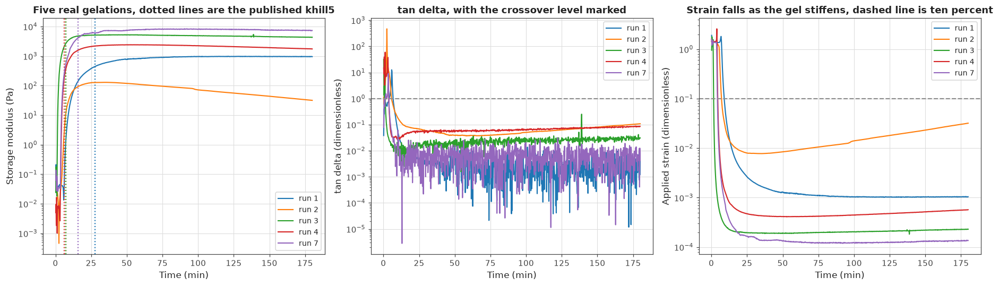

In [257]:
def find_column_index(header_values, wanted_symbol):
    """
    Finding which column holds a given measured quantity, by reading the header row.

    The exported headers carry mixed language unit notation, for example "G'  en Pa" and
    "Gamma  en -", so the symbol is taken as whatever sits before the " en " separator.

    Returning None when the quantity is absent from the file, since not every export
    contains the same set of columns.
    """
    for column_index in range(len(header_values)):

        header_text = str(header_values[column_index]).strip()

        if header_text == "" or header_text.lower() == "nan":
            continue

        symbol_text = header_text.split(" en ")[0].strip()

        if symbol_text == wanted_symbol:
            return column_index

    return None


def read_column_by_symbol(raw_table, header_values, wanted_symbol, row_count):
    """
    Reading one column of numbers by its symbol, returning all missing values when the
    column does not exist in this file.
    """
    column_index = find_column_index(header_values, wanted_symbol)

    if column_index is None:
        return np.full(row_count, np.nan), None

    column_values = pd.to_numeric(raw_table[column_index], errors="coerce").values

    return column_values, column_index


def load_polymer_time_sweep(file_path, sheet_name):
    """
    Loading one polymer gel time sweep into a common form.

    Reading each quantity by the symbol in its header rather than by column position,
    because the column order is not the same in all five exports and one file omits the
    frequency column entirely.

    Sorting by elapsed time, because at least one file has rows out of order, and
    discarding any row where the time or either modulus is missing.

    Returning the time in seconds and minutes, both moduli, the phase angle, the
    temperature, the applied strain, the applied stress and the frequency, together with
    the column index each quantity was found at so the mapping can be printed and checked.
    """
    header_table = pd.read_excel(file_path, sheet_name=sheet_name, header=None, nrows=1)
    header_values = header_table.iloc[0].tolist()

    raw_table = pd.read_excel(file_path, sheet_name=sheet_name, header=None, skiprows=1)
    row_count = len(raw_table)

    elapsed_time_seconds, time_column = read_column_by_symbol(
        raw_table, header_values, "t", row_count)
    storage_modulus, storage_column = read_column_by_symbol(
        raw_table, header_values, "G'", row_count)
    loss_modulus, loss_column = read_column_by_symbol(
        raw_table, header_values, "G''", row_count)
    phase_angle_degrees, phase_column = read_column_by_symbol(
        raw_table, header_values, "delta", row_count)
    temperature_celsius, temperature_column = read_column_by_symbol(
        raw_table, header_values, "T", row_count)
    applied_strain, strain_column = read_column_by_symbol(
        raw_table, header_values, "Gamma", row_count)
    applied_stress_pascals, stress_column = read_column_by_symbol(
        raw_table, header_values, "Tau", row_count)
    applied_frequency_hz, frequency_column = read_column_by_symbol(
        raw_table, header_values, "f", row_count)

    usable_mask = (np.isfinite(elapsed_time_seconds)
                   & np.isfinite(storage_modulus)
                   & np.isfinite(loss_modulus))

    elapsed_time_seconds = elapsed_time_seconds[usable_mask]
    storage_modulus = storage_modulus[usable_mask]
    loss_modulus = loss_modulus[usable_mask]
    phase_angle_degrees = phase_angle_degrees[usable_mask]
    temperature_celsius = temperature_celsius[usable_mask]
    applied_strain = applied_strain[usable_mask]
    applied_stress_pascals = applied_stress_pascals[usable_mask]
    applied_frequency_hz = applied_frequency_hz[usable_mask]

    time_order = np.argsort(elapsed_time_seconds)

    return {
        "elapsed_time_seconds": elapsed_time_seconds[time_order],
        "elapsed_time_minutes": elapsed_time_seconds[time_order] / 60.0,
        "storage_modulus": storage_modulus[time_order],
        "loss_modulus": loss_modulus[time_order],
        "phase_angle_degrees": phase_angle_degrees[time_order],
        "temperature_celsius": temperature_celsius[time_order],
        "applied_strain": applied_strain[time_order],
        "applied_stress_pascals": applied_stress_pascals[time_order],
        "applied_frequency_hz": applied_frequency_hz[time_order],
        "point_count": int(np.sum(usable_mask)),
        "column_map": {
            "time": time_column,
            "storage": storage_column,
            "loss": loss_column,
            "phase": phase_column,
            "temperature": temperature_column,
            "strain": strain_column,
            "stress": stress_column,
            "frequency": frequency_column,
        },
    }


def describe_column_index(column_index):
    """
    Formatting a column index for printing, or reporting that the column is absent.
    """
    if column_index is None:
        return "absent"

    return str(column_index)


def describe_median(value_array, format_text, missing_text):
    """
    Formatting the median of a column, or reporting that the column is absent.
    """
    finite_values = value_array[np.isfinite(value_array)]

    if len(finite_values) == 0:
        return missing_text

    return format_text % np.median(finite_values)


print("Loading the five time sweeps")
print()

polymer_sweep_records = []

for run_record in matched_run_records:

    sweep_record = load_polymer_time_sweep(run_record["file_path"],
                                           run_record["time_series_sheet"])

    sweep_record["run_label"] = run_record["run_label"]
    sweep_record["hill_time_minutes"] = run_record["hill_time_minutes"]
    sweep_record["nmr_time_minutes"] = run_record["nmr_time_minutes"]
    sweep_record["maximum_modulus"] = run_record["maximum_modulus"]
    sweep_record["syneresis"] = run_record["syneresis"]

    polymer_sweep_records.append(sweep_record)

print("Where each quantity was found, by column index")
print()
print("  run".rjust(5) + "time".rjust(7) + "G prime".rjust(9) + "G double prime".rjust(16)
      + "delta".rjust(8) + "T".rjust(5) + "strain".rjust(8) + "stress".rjust(8)
      + "frequency".rjust(11))

for sweep_record in polymer_sweep_records:

    column_map = sweep_record["column_map"]

    print(sweep_record["run_label"].rjust(5)
          + describe_column_index(column_map["time"]).rjust(7)
          + describe_column_index(column_map["storage"]).rjust(9)
          + describe_column_index(column_map["loss"]).rjust(16)
          + describe_column_index(column_map["phase"]).rjust(8)
          + describe_column_index(column_map["temperature"]).rjust(5)
          + describe_column_index(column_map["strain"]).rjust(8)
          + describe_column_index(column_map["stress"]).rjust(8)
          + describe_column_index(column_map["frequency"]).rjust(11))

print()
print("  the column order is not the same in all five files, so reading by position is")
print("  wrong here. An earlier version of this cell took column 10 as the frequency in")
print("  every file. That is the frequency in runs 1, 2 and 7, the elapsed time in")
print("  minutes in run 3, and the applied stress in run 4. It printed 90.095 Hz for")
print("  run 3 and 1.000 Hz for run 4, and the second of those looked correct only")
print("  because the protocol applies 1 Pa at 1 Hz, so the stress and the frequency")
print("  happen to share a number")

print()
print("What each run recorded")
print()
print("  run".rjust(5) + "points".rjust(9) + "duration (min)".rjust(16)
      + "interval (s)".rjust(14) + "frequency (Hz)".rjust(16)
      + "stress (Pa)".rjust(14) + "temperature (C)".rjust(17))

for sweep_record in polymer_sweep_records:

    sampling_interval = float(np.median(np.diff(sweep_record["elapsed_time_seconds"])))

    frequency_text = describe_median(sweep_record["applied_frequency_hz"],
                                     "%.3f", "not recorded")
    stress_text = describe_median(sweep_record["applied_stress_pascals"],
                                  "%.3f", "not recorded")
    temperature_text = describe_median(sweep_record["temperature_celsius"],
                                       "%.1f", "not recorded")

    print(sweep_record["run_label"].rjust(5)
          + str(sweep_record["point_count"]).rjust(9)
          + ("%.1f" % sweep_record["elapsed_time_minutes"].max()).rjust(16)
          + ("%.1f" % sampling_interval).rjust(14)
          + frequency_text.rjust(16)
          + stress_text.rjust(14)
          + temperature_text.rjust(17))

print()
print("  run 3 records neither the frequency nor the stress in its time sweep sheet, but")
print("  its frequency sweep sheet was run at 1 Pa and its amplitude sweep sheet at 1 Hz,")
print("  which matches the published protocol of 1 Pa and 1 Hz for every run")
print()
print("  run 3 also sat at 70 C while the other four sat near 61 C, so its gelation is")
print("  faster for a reason unrelated to any detector, and Cell 61 keeps that in view")

print()
print("What the moduli do across each run")
print()
print("  run".rjust(5) + "G prime start".rjust(15) + "G prime end".rjust(14)
      + "rise factor".rjust(14) + "reported max".rjust(15) + "   agrees")

for sweep_record in polymer_sweep_records:

    early_window = sweep_record["elapsed_time_minutes"] < 2.0
    late_window = (sweep_record["elapsed_time_minutes"]
                   > sweep_record["elapsed_time_minutes"].max() - 10.0)

    starting_modulus = float(np.median(sweep_record["storage_modulus"][early_window]))
    ending_modulus = float(np.median(sweep_record["storage_modulus"][late_window]))

    measured_maximum = float(np.max(sweep_record["storage_modulus"]))
    reported_maximum = sweep_record["maximum_modulus"]

    agreement_ratio = measured_maximum / max(reported_maximum, 1e-9)

    if 0.7 < agreement_ratio < 1.4:
        agreement_text = "yes"
    else:
        agreement_text = ("no, measured %.0f" % measured_maximum)

    print(sweep_record["run_label"].rjust(5)
          + ("%.3f" % starting_modulus).rjust(15)
          + ("%.0f" % ending_modulus).rjust(14)
          + ("%.0f" % (ending_modulus / max(abs(starting_modulus), 1e-9))).rjust(14)
          + ("%.0f" % reported_maximum).rjust(15)
          + "   " + agreement_text)

print()
print("  comparing our measured maximum against the published one is a check that the")
print("  right column has been read and the right run matched to the right reference")

print()
print("What the applied strain does, since these are controlled stress runs")
print()

strain_at_reference_records = []

print("  run".rjust(5) + "strain at start".rjust(17) + "at khill5".rjust(12)
      + "at end".rjust(11) + "fall factor".rjust(14)
      + "points above 0.1".rjust(19))

for sweep_record in polymer_sweep_records:

    strain_values = sweep_record["applied_strain"]
    time_minutes = sweep_record["elapsed_time_minutes"]

    finite_strain_mask = np.isfinite(strain_values)

    if np.sum(finite_strain_mask) < 10:
        print(sweep_record["run_label"].rjust(5) + "   strain not recorded")
        continue

    early_window = finite_strain_mask & (time_minutes < 2.0)
    late_window = finite_strain_mask & (time_minutes > time_minutes.max() - 10.0)

    reference_window = finite_strain_mask & (
        np.abs(time_minutes - sweep_record["hill_time_minutes"]) < 1.0)

    starting_strain = float(np.median(strain_values[early_window]))
    ending_strain = float(np.median(strain_values[late_window]))

    if np.sum(reference_window) > 0:
        reference_strain_text = "%.4f" % np.median(strain_values[reference_window])
    else:
        reference_strain_text = "no points"

    large_strain_count = int(np.sum(finite_strain_mask & (strain_values > 0.1)))

    if np.sum(reference_window) > 0:
        strain_at_reference_records.append({
            "run_label": sweep_record["run_label"],
            "strain_at_reference": float(np.median(strain_values[reference_window])),
        })

    print(sweep_record["run_label"].rjust(5)
          + ("%.4f" % starting_strain).rjust(17)
          + reference_strain_text.rjust(12)
          + ("%.4f" % ending_strain).rjust(11)
          + ("%.0f" % (starting_strain / max(ending_strain, 1e-12))).rjust(14)
          + str(large_strain_count).rjust(19))

print()
print("  the strain is not constant and is not meant to be. The published protocol holds")
print("  the stress at 1 Pa, so the strain falls as the gel stiffens. An earlier version")
print("  of this cell tested the strain for constancy and reported that every run failed,")
print("  which was the wrong test rather than a problem with the data")
print()
print("  the number that matters is how large the early strains are. Strains above 0.1,")
print("  meaning ten percent, are outside the linear range for most gels, and the early")
print("  points here reach order one. The linear limit for this formulation is not")
print("  published, so this is a warning attached to the pre-gel points rather than a")
print("  reason to drop them, and Cell 59 reports which detectors depend on them")

if len(strain_at_reference_records) > 0:

    worst_reference_record = strain_at_reference_records[0]

    for candidate_record in strain_at_reference_records:
        if candidate_record["strain_at_reference"] > worst_reference_record["strain_at_reference"]:
            worst_reference_record = candidate_record

    print()
    print("  run " + worst_reference_record["run_label"]
          + " is the one to watch, since it is still at "
          + ("%.3f" % worst_reference_record["strain_at_reference"])
          + " strain at its own")
    print("  reference gel time. It is the weakest gel of the five, so the stress of 1 Pa")
    print("  keeps deforming it heavily right through the transition")

print()
print("Counting how many measurements fall before the reference gel time")
print()
print("  run".rjust(5) + "khill5 (min)".rjust(14) + "points before".rjust(15)
      + "points after".rjust(14) + "   enough to detect")

for sweep_record in polymer_sweep_records:

    points_before = int(np.sum(sweep_record["elapsed_time_minutes"]
                               < sweep_record["hill_time_minutes"]))
    points_after = int(np.sum(sweep_record["elapsed_time_minutes"]
                              >= sweep_record["hill_time_minutes"]))

    if points_before >= 10:
        sufficiency_text = "yes"
    else:
        sufficiency_text = "marginal"

    print(sweep_record["run_label"].rjust(5)
          + ("%.2f" % sweep_record["hill_time_minutes"]).rjust(14)
          + str(points_before).rjust(15)
          + str(points_after).rjust(14)
          + "   " + sufficiency_text)

print()
print("  Part 4 found that below about a dozen measurements through a transition no")
print("  detector was reliable, so this count matters more than the total")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for sweep_record in polymer_sweep_records:

    line_objects = axis_array[0].semilogy(
        sweep_record["elapsed_time_minutes"],
        np.maximum(sweep_record["storage_modulus"], 1e-4),
        "-", linewidth=1.4, label=("run " + sweep_record["run_label"]))

    axis_array[0].axvline(sweep_record["hill_time_minutes"],
                          color=line_objects[0].get_color(),
                          linestyle=":", linewidth=1.4)

axis_array[0].set_xlabel("Time (min)")
axis_array[0].set_ylabel("Storage modulus (Pa)")
axis_array[0].set_title("Five real gelations, dotted lines are the published khill5")
axis_array[0].legend(fontsize=9)

for sweep_record in polymer_sweep_records:

    sweep_tan_delta = compute_tan_delta(sweep_record["storage_modulus"],
                                        sweep_record["loss_modulus"])

    axis_array[1].semilogy(sweep_record["elapsed_time_minutes"], sweep_tan_delta,
                           "-", linewidth=1.4,
                           label=("run " + sweep_record["run_label"]))

axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[1].set_xlabel("Time (min)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta, with the crossover level marked")
axis_array[1].legend(fontsize=9)

for sweep_record in polymer_sweep_records:

    strain_values = sweep_record["applied_strain"]
    finite_strain_mask = np.isfinite(strain_values)

    if np.sum(finite_strain_mask) < 10:
        continue

    axis_array[2].semilogy(sweep_record["elapsed_time_minutes"][finite_strain_mask],
                           np.maximum(strain_values[finite_strain_mask], 1e-6),
                           "-", linewidth=1.4,
                           label=("run " + sweep_record["run_label"]))

axis_array[2].axhline(0.1, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[2].set_xlabel("Time (min)")
axis_array[2].set_ylabel("Applied strain (dimensionless)")
axis_array[2].set_title("Strain falls as the gel stiffens, dashed line is ten percent")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 58: The two moduli, and the floor underneath them

Before any detector runs, this cell looks at what the measurement can and cannot see.

**Every run ends as a solid.** The storage modulus finishes one to three orders of magnitude
above the loss modulus in all five. That is the shape a gelation should have, and confirming it
first means a detector failure later is a detector problem rather than a data problem.

**Every run also has a floor.** Below a few hundredths of a pascal the instrument is reporting
scatter, not material. The floor is estimated from the first five measurements, while the
sample is still a liquid and nothing has begun to grow. Five points rather than two minutes,
because the fastest run here has already started gelling inside two minutes and a longer
window would take part of the transition as the baseline.

**The floor matters more than it sounds.** tan delta is a ratio, and inside the floor region it
is a ratio of two noisy numbers of similar size, so it wanders across one at random. Four of
the five runs contain at least one false crossing in the first minutes, before anything has
formed. A crossover detector reading the raw series would return a gel point in the first
minute of those four runs. The cell separates the real crossings from the false ones by asking
how far above the floor the storage modulus was when the crossing happened.

**And then the crossover disagrees with the reference anyway.** In every run the credible
crossover arrives before the published khill5. Part 1 found the same ordering on noiseless
synthetic data. Here the gap is larger and much less consistent, which is the definition
problem from Part 1 showing up in real measurements rather than in a model.

The last check compares the recorded stress and strain against the moduli. It agrees to four
decimal places, which is too good to be two independent measurements agreeing, and the cell
says so rather than presenting it as a validation.

What the two moduli do in each run

  run  G prime start  G double start  leads at start  G prime end  G double end  tan delta end
    1         0.0408          0.0229         G prime          963           2.7         0.0028
    2         0.0296          0.0832  G double prime           33           3.4         0.1028
    3         0.1756          0.4800  G double prime         4382         133.9         0.0306
    4         0.0074          0.0591  G double prime         1783         150.8         0.0846
    7         0.0590          0.0418         G prime         7434          47.8         0.0064

  every run finishes as a solid, with the storage modulus one to three orders of
  magnitude above the loss modulus, which is what a gelation should look like

  the starting column is less trustworthy than it appears. Runs 1 and 7 show the
  storage modulus nominally ahead at the start, which would mean the sample was
  already a weak solid when loaded. Both values sit at a few hundredths 

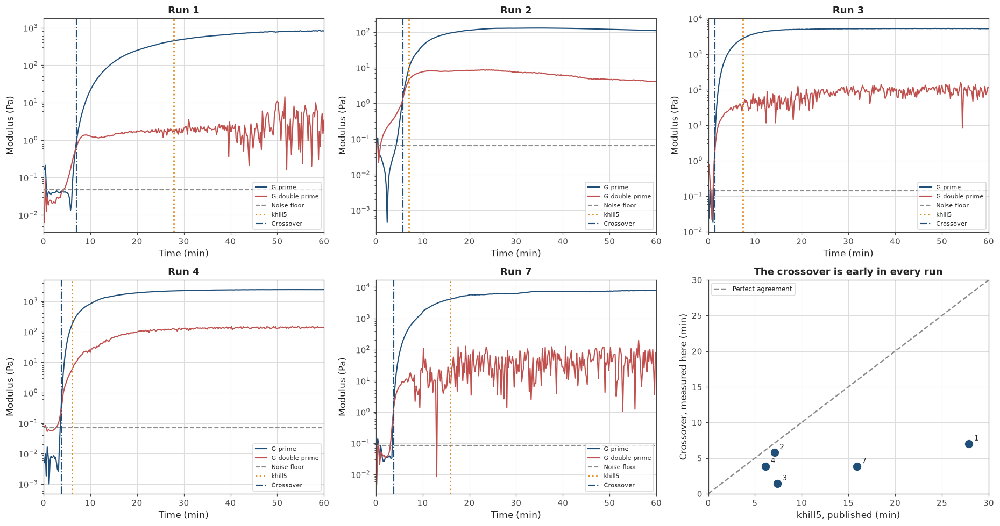

In [258]:
POLYMER_NOISE_FLOOR_BASELINE_POINTS = 5
POLYMER_CROSSING_CREDIBILITY_FACTOR = 5.0


def estimate_modulus_noise_floor(storage_modulus_values, loss_modulus_values,
                                 baseline_point_count):
    """
    Estimating the smallest modulus this run can actually resolve, by taking the median of
    the first few measurements while the sample is still a liquid and nothing is growing.

    Using only the first few points rather than the first few minutes, because the fastest
    run here has already begun gelling inside two minutes and a longer window would take
    the transition itself as the floor.

    Returning the larger of the two moduli medians, since the floor is a property of the
    instrument rather than of one channel.
    """
    baseline_storage = storage_modulus_values[:baseline_point_count]
    baseline_loss = loss_modulus_values[:baseline_point_count]

    floor_from_storage = float(np.median(baseline_storage))
    floor_from_loss = float(np.median(baseline_loss))

    return max(floor_from_storage, floor_from_loss)


def find_downward_tan_delta_crossings(tan_delta_values):
    """
    Finding every point where tan delta falls through one, meaning the storage modulus
    overtakes the loss modulus.

    Returning the index of the first point after each crossing.
    """
    crossing_indices = []

    for point_index in range(len(tan_delta_values) - 1):

        if tan_delta_values[point_index] > 1.0 and tan_delta_values[point_index + 1] <= 1.0:
            crossing_indices.append(point_index + 1)

    return crossing_indices


print("What the two moduli do in each run")
print()
print("  run".rjust(5) + "G prime start".rjust(15) + "G double start".rjust(16)
      + "leads at start".rjust(16) + "G prime end".rjust(13)
      + "G double end".rjust(14) + "tan delta end".rjust(15))

for sweep_record in polymer_sweep_records:

    time_minutes = sweep_record["elapsed_time_minutes"]
    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    early_window = time_minutes < 2.0
    late_window = time_minutes > time_minutes.max() - 10.0

    starting_storage = float(np.median(storage_modulus[early_window]))
    starting_loss = float(np.median(loss_modulus[early_window]))
    ending_storage = float(np.median(storage_modulus[late_window]))
    ending_loss = float(np.median(loss_modulus[late_window]))

    if starting_loss > starting_storage:
        leading_text = "G double prime"
    else:
        leading_text = "G prime"

    print(sweep_record["run_label"].rjust(5)
          + ("%.4f" % starting_storage).rjust(15)
          + ("%.4f" % starting_loss).rjust(16)
          + leading_text.rjust(16)
          + ("%.0f" % ending_storage).rjust(13)
          + ("%.1f" % ending_loss).rjust(14)
          + ("%.4f" % (ending_loss / max(ending_storage, 1e-12))).rjust(15))

print()
print("  every run finishes as a solid, with the storage modulus one to three orders of")
print("  magnitude above the loss modulus, which is what a gelation should look like")
print()
print("  the starting column is less trustworthy than it appears. Runs 1 and 7 show the")
print("  storage modulus nominally ahead at the start, which would mean the sample was")
print("  already a weak solid when loaded. Both values sit at a few hundredths of a")
print("  pascal, and the next section shows that is the floor of the measurement, so the")
print("  ordering there is being set by scatter rather than by the material")

print()
print("How small a modulus each run can resolve")
print()
print("  run".rjust(5) + "noise floor (Pa)".rjust(18) + "max G prime (Pa)".rjust(18)
      + "dynamic range".rjust(16) + "points below floor".rjust(21))

for sweep_record in polymer_sweep_records:

    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    noise_floor = estimate_modulus_noise_floor(storage_modulus, loss_modulus,
                                               POLYMER_NOISE_FLOOR_BASELINE_POINTS)

    sweep_record["noise_floor"] = noise_floor

    points_below_floor = int(np.sum(storage_modulus < noise_floor))

    print(sweep_record["run_label"].rjust(5)
          + ("%.4f" % noise_floor).rjust(18)
          + ("%.0f" % storage_modulus.max()).rjust(18)
          + ("%.0f" % (storage_modulus.max() / max(noise_floor, 1e-12))).rjust(16)
          + str(points_below_floor).rjust(21))

print()
print("  no run contains a negative modulus, unlike the chirp recording in Part 2, so the")
print("  reliability filter from Cell 51 has nothing to reject here")
print()
print("  what it does have is a floor. Below roughly 0.05 to 0.14 Pa the numbers scatter")
print("  without a trend, and the early points of every run sit in that region")
print()
print("  run 2 has by far the least room to work in. Its strongest modulus is only about")
print("  two thousand times its own floor, while the others reach twenty thousand to a")
print("  hundred thousand. Together with its high strain at the reference time from Cell")
print("  57, that makes run 2 the run most likely to give trouble in Cells 59 and 60")

print()
print("Every time the storage modulus overtakes the loss modulus")
print()
print("  run".rjust(5) + "crossing (min)".rjust(16) + "G prime there (Pa)".rjust(20)
      + "times the floor".rjust(17) + "   verdict")

spurious_crossing_count = 0
credible_crossing_count = 0

for sweep_record in polymer_sweep_records:

    time_minutes = sweep_record["elapsed_time_minutes"]
    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]
    noise_floor = sweep_record["noise_floor"]

    sweep_tan_delta = compute_tan_delta(storage_modulus, loss_modulus)

    crossing_indices = find_downward_tan_delta_crossings(sweep_tan_delta)

    credible_crossing_times = []

    for crossing_index in crossing_indices:

        floor_multiple = storage_modulus[crossing_index] / max(noise_floor, 1e-12)

        if floor_multiple >= POLYMER_CROSSING_CREDIBILITY_FACTOR:
            verdict_text = "real"
            credible_crossing_times.append(float(time_minutes[crossing_index]))
            credible_crossing_count = credible_crossing_count + 1
        else:
            verdict_text = "noise"
            spurious_crossing_count = spurious_crossing_count + 1

        print(sweep_record["run_label"].rjust(5)
              + ("%.2f" % time_minutes[crossing_index]).rjust(16)
              + ("%.4f" % storage_modulus[crossing_index]).rjust(20)
              + ("%.1f" % floor_multiple).rjust(17)
              + "   " + verdict_text)

    if len(credible_crossing_times) > 0:
        sweep_record["crossover_time_minutes"] = credible_crossing_times[-1]
    else:
        sweep_record["crossover_time_minutes"] = np.nan

print()
print("  " + str(spurious_crossing_count) + " of the "
      + str(spurious_crossing_count + credible_crossing_count)
      + " crossings are noise and " + str(credible_crossing_count) + " are real")
print()
print("  four of the five runs contain at least one false crossing before anything has")
print("  formed. They happen while both moduli are within a factor of two of the floor,")
print("  where their ratio is meaningless, and the real crossing sits between seven and")
print("  twenty five times the floor. A crossover detector that simply takes the first")
print("  crossing would report a gel point in the first minute of four runs")
print()
print("  Cell 59 therefore passes the floor to every detector rather than letting them")
print("  work on the raw series")

print()
print("The crossover against the published reference")
print()
print("  run".rjust(5) + "crossover (min)".rjust(17) + "khill5 (min)".rjust(14)
      + "crossover over khill5".rjust(23) + "difference (min)".rjust(18))

crossover_ratio_values = []

for sweep_record in polymer_sweep_records:

    crossover_time = sweep_record["crossover_time_minutes"]
    reference_time = sweep_record["hill_time_minutes"]

    if not np.isfinite(crossover_time):
        print(sweep_record["run_label"].rjust(5) + "   no credible crossing found")
        continue

    crossover_ratio = crossover_time / reference_time
    crossover_ratio_values.append(crossover_ratio)

    print(sweep_record["run_label"].rjust(5)
          + ("%.2f" % crossover_time).rjust(17)
          + ("%.2f" % reference_time).rjust(14)
          + ("%.2f" % crossover_ratio).rjust(23)
          + ("%.2f" % (crossover_time - reference_time)).rjust(18))

if len(crossover_ratio_values) > 0:

    crossover_ratio_array = np.array(crossover_ratio_values)

    print()
    print("  the crossover arrives before khill5 in every run, at between "
          + ("%.2f" % crossover_ratio_array.min()) + " and "
          + ("%.2f" % crossover_ratio_array.max()))
    print("  of the reference time, a spread of a factor of "
          + ("%.1f" % (crossover_ratio_array.max() / crossover_ratio_array.min())))
    print()
    print("  Part 1 found the same ordering on noiseless synthetic data, where the")
    print("  crossover came 167 s before the Hill 5 half rise. Here the gap is larger and")
    print("  far less consistent, so the offset is not a correction that can be applied")
    print()
    print("  this is the definition problem from Part 1 appearing in real measurements.")
    print("  Neither quantity is wrong. They are answers to different questions and Cell")
    print("  60 scores against khill5 while keeping that in view")

print()
print("Checking the stress and strain columns against the moduli")
print()
print("  run".rjust(5) + "median ratio".rjust(15) + "5th percentile".rjust(17)
      + "95th percentile".rjust(18))

for sweep_record in polymer_sweep_records:

    applied_stress = sweep_record["applied_stress_pascals"]
    applied_strain = sweep_record["applied_strain"]
    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    usable_mask = (np.isfinite(applied_stress) & np.isfinite(applied_strain)
                   & (applied_strain > 0))

    if np.sum(usable_mask) < 10:
        print(sweep_record["run_label"].rjust(5) + "   stress or strain not recorded")
        continue

    modulus_from_control = applied_stress[usable_mask] / applied_strain[usable_mask]
    modulus_from_channels = np.sqrt(storage_modulus[usable_mask] ** 2
                                    + loss_modulus[usable_mask] ** 2)

    consistency_ratio = modulus_from_control / np.maximum(modulus_from_channels, 1e-12)

    print(sweep_record["run_label"].rjust(5)
          + ("%.4f" % np.median(consistency_ratio)).rjust(15)
          + ("%.4f" % np.percentile(consistency_ratio, 5)).rjust(17)
          + ("%.4f" % np.percentile(consistency_ratio, 95)).rjust(18))

print()
print("  this agrees to four decimal places, which is too good to be a measurement")
print("  agreeing with a measurement. The instrument computes the strain it reports from")
print("  the stress it applied and the modulus it measured, so the test is circular and")
print("  says nothing about accuracy")
print()
print("  it is still worth printing, because it does confirm that the stress and strain")
print("  columns belong to the same test as the moduli columns. That is the thing Cell 57")
print("  got wrong, and on run 4 the stress and frequency columns are swapped relative to")
print("  the other files, so the confirmation is not free")

figure_object, axis_array = plt.subplots(2, 3, figsize=(17, 9))

flat_axes = axis_array.flatten()

for panel_index in range(len(polymer_sweep_records)):

    sweep_record = polymer_sweep_records[panel_index]
    panel_axis = flat_axes[panel_index]

    panel_axis.semilogy(sweep_record["elapsed_time_minutes"],
                        np.maximum(sweep_record["storage_modulus"], 1e-4),
                        "-", color=COLOUR_PRIMARY, linewidth=1.4,
                        label="G prime")
    panel_axis.semilogy(sweep_record["elapsed_time_minutes"],
                        np.maximum(sweep_record["loss_modulus"], 1e-4),
                        "-", color=COLOUR_SECONDARY, linewidth=1.4,
                        label="G double prime")

    panel_axis.axhline(sweep_record["noise_floor"], color=COLOUR_NEUTRAL,
                       linestyle="--", linewidth=1.4, label="Noise floor")

    panel_axis.axvline(sweep_record["hill_time_minutes"], color=COLOUR_HIGHLIGHT,
                       linestyle=":", linewidth=1.8, label="khill5")

    if np.isfinite(sweep_record["crossover_time_minutes"]):
        panel_axis.axvline(sweep_record["crossover_time_minutes"], color=COLOUR_PRIMARY,
                           linestyle="-.", linewidth=1.4, label="Crossover")

    panel_axis.set_xlim(0.0, 60.0)
    panel_axis.set_xlabel("Time (min)")
    panel_axis.set_ylabel("Modulus (Pa)")
    panel_axis.set_title("Run " + sweep_record["run_label"])
    panel_axis.legend(fontsize=7)

summary_axis = flat_axes[5]

for sweep_record in polymer_sweep_records:

    if not np.isfinite(sweep_record["crossover_time_minutes"]):
        continue

    summary_axis.plot(sweep_record["hill_time_minutes"],
                      sweep_record["crossover_time_minutes"],
                      "o", color=COLOUR_PRIMARY, markersize=9)

    summary_axis.annotate(sweep_record["run_label"],
                          (sweep_record["hill_time_minutes"],
                           sweep_record["crossover_time_minutes"]),
                          textcoords="offset points", xytext=(6, 4), fontsize=9)

equality_line = np.array([0.0, 30.0])
summary_axis.plot(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                  linewidth=1.6, label="Perfect agreement")

summary_axis.set_xlim(0.0, 30.0)
summary_axis.set_ylim(0.0, 30.0)
summary_axis.set_xlabel("khill5, published (min)")
summary_axis.set_ylabel("Crossover, measured here (min)")
summary_axis.set_title("The crossover is early in every run")
summary_axis.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 59: Every detector on every run

The five Part 4 detectors, run unchanged on the five real gelations, plus the floor aware
crossover from Cell 58.

**Winter and Chambon cannot run here.** It measures whether tan delta agrees across
frequencies, and these records hold one frequency. It returns nothing rather than returning
something wrong, which is the correct behaviour and is also the reason the Laponite data in
Cell 63 is needed.

**The Part 4 detectors expect a list of spectra**, since they were written for data with many
frequencies per snapshot. Rather than rewriting them, each snapshot is wrapped as a two point
spectrum carrying the same complex modulus twice. Interpolating between two identical values
returns that value at any probe frequency, so the detectors run on the real data with the same
code that produced the Part 4 results.

**The crossover fails on real data in a way Part 4 could not have found.** It walks forward and
takes the first time tan delta falls through one, and in four of the five runs that is a false
crossing in the noise floor. The synthetic experiment in Part 4 added noise that scaled with
the size of the measurement, so there was never a floor for tan delta to wander across. A real
instrument has a fixed torque resolution and therefore does have one. The noise sweep in Cell
53 measured the wrong kind of noise for this failure mode, and that is a limitation of Part 4
rather than a result here.

**The half rise looks like the winner and mostly is not.** khill5 is itself a Hill 5 half rise,
so this comparison scores an implementation against an implementation of the same definition.
Part 4 measured the half rise against a known gel time and it was the worst detector tested.

**One run breaks the half rise completely**, and the reason turns out to be in the source
paper. Two of the five runs are flagged there for syneresis, meaning the gel shrinks and
expels solvent, and those two are exactly the runs whose modulus falls furthest after its peak.
A Hill 5 sigmoid rises to a plateau and cannot represent a rise followed by a collapse.

Errors are reported as percentages, and judged against the 31 percent repeatability floor
from Cell 56 rather than against zero.

Running every Part 4 detector on every run

  probe frequency          6.2832 rad/s, which is the 1 Hz the
                           instrument applied

What each detector returned, in minutes

  detector                      run 1      run 2      run 3      run 4      run 7
  crossover, Part 4              0.83       0.24       0.76       3.78       0.59
  crossover, floor aware         7.01       5.78       1.42       3.83       3.82
  half rise                     29.73     114.46       6.75      11.75      15.58
  growth rate                    6.21       2.60       1.20       3.42       3.59
  changepoint PELT               1.19       1.19       1.19       3.21       1.19
  changepoint kernel            65.18     101.20     120.79     124.40      50.80
  changepoint CUSUM             33.99       none       none       none      88.39
  khill5, published             27.90       7.10       7.40       6.15      15.90

  the PELT changepoint returns 1.19 minutes in four of the five ru

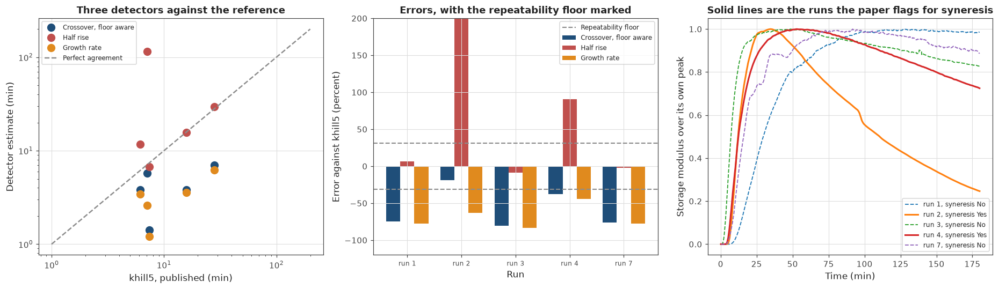

In [259]:
POLYMER_PROBE_ANGULAR_FREQUENCY = 2.0 * np.pi * 1.0


def build_single_frequency_spectrum_list(storage_modulus_values, loss_modulus_values):
    """
    Wrapping a single frequency time sweep in the shape the Part 4 detectors expect.

    The detectors were written for a list of spectra and read the modulus at a chosen probe
    frequency by interpolating across frequencies. These runs hold one frequency only, so
    each snapshot becomes a two point spectrum carrying the same complex modulus twice, and
    interpolating between two identical values returns that value at any probe frequency.

    Doing it this way rather than rewriting the detectors keeps the comparison against Part
    4 honest, since the same code is being run on both kinds of data.
    """
    spectrum_list = []

    for snapshot_index in range(len(storage_modulus_values)):

        snapshot_modulus = complex(storage_modulus_values[snapshot_index],
                                   loss_modulus_values[snapshot_index])

        spectrum_list.append(np.array([snapshot_modulus, snapshot_modulus]))

    return spectrum_list


polymer_probe_frequency_array = np.array([POLYMER_PROBE_ANGULAR_FREQUENCY * 0.5,
                                          POLYMER_PROBE_ANGULAR_FREQUENCY * 2.0])

print("Running every Part 4 detector on every run")
print()
print("  probe frequency          "
      + ("%.4f" % POLYMER_PROBE_ANGULAR_FREQUENCY) + " rad/s, which is the 1 Hz the")
print("                           instrument applied")
print()

polymer_detector_records = []

for sweep_record in polymer_sweep_records:

    spectrum_list = build_single_frequency_spectrum_list(sweep_record["storage_modulus"],
                                                         sweep_record["loss_modulus"])

    detector_estimates, reliability_flags = run_all_detectors(
        sweep_record["elapsed_time_minutes"], spectrum_list,
        polymer_probe_frequency_array, POLYMER_PROBE_ANGULAR_FREQUENCY,
        apply_reliability_filter=False)

    detector_estimates["crossover_floor_aware"] = sweep_record["crossover_time_minutes"]

    polymer_detector_records.append({
        "run_label": sweep_record["run_label"],
        "hill_time_minutes": sweep_record["hill_time_minutes"],
        "estimates": detector_estimates,
    })

polymer_detector_display_names = [
    ("crossover", "crossover, Part 4"),
    ("crossover_floor_aware", "crossover, floor aware"),
    ("half_rise", "half rise"),
    ("growth_rate", "growth rate"),
    ("pelt", "changepoint PELT"),
    ("kernel", "changepoint kernel"),
    ("cusum", "changepoint CUSUM"),
]

print("What each detector returned, in minutes")
print()

header_text = "  detector".ljust(26)
for detector_record in polymer_detector_records:
    header_text = header_text + ("run " + detector_record["run_label"]).rjust(11)
print(header_text)

for estimate_key, display_name in polymer_detector_display_names:

    row_text = "  " + display_name.ljust(24)

    for detector_record in polymer_detector_records:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)

        if np.isfinite(estimate_value):
            row_text = row_text + ("%.2f" % estimate_value).rjust(11)
        else:
            row_text = row_text + "none".rjust(11)

    print(row_text)

reference_row_text = "  " + "khill5, published".ljust(24)
for detector_record in polymer_detector_records:
    reference_row_text = (reference_row_text
                          + ("%.2f" % detector_record["hill_time_minutes"]).rjust(11))
print(reference_row_text)

print()
print("  the PELT changepoint returns 1.19 minutes in four of the five runs, whose gel")
print("  times differ by a factor of four. An identical answer across different materials")
print("  means it is keying on something common to the records rather than on the")
print("  transition, which is the same grid locking Cells 50 and 54 found on synthetic")
print("  data. The kernel changepoint sits past 50 minutes in every run for the opposite")
print("  reason, splitting the record near its middle rather than at its transition")
print()
print("  Winter and Chambon is absent because it cannot run. It measures whether tan")
print("  delta agrees across frequencies, and these runs hold one frequency, so it")
print("  returns nothing rather than returning something wrong. That is the right")
print("  behaviour and it is also the whole argument for the Laponite data in Cell 63")

print()
print("How far each detector sits from the published reference, in percent")
print()

header_text = "  detector".ljust(26)
for detector_record in polymer_detector_records:
    header_text = header_text + ("run " + detector_record["run_label"]).rjust(11)
print(header_text + "within floor".rjust(14))

for estimate_key, display_name in polymer_detector_display_names:

    row_text = "  " + display_name.ljust(24)
    within_floor_count = 0
    scored_count = 0

    for detector_record in polymer_detector_records:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)
        reference_value = detector_record["hill_time_minutes"]

        if np.isfinite(estimate_value):

            relative_error = 100.0 * (estimate_value - reference_value) / reference_value
            scored_count = scored_count + 1

            if abs(relative_error) <= POLYMER_REFERENCE_REPEATABILITY_PERCENT:
                within_floor_count = within_floor_count + 1

            row_text = row_text + ("%+.0f" % relative_error).rjust(11)

        else:
            row_text = row_text + "none".rjust(11)

    print(row_text + (str(within_floor_count) + " of " + str(scored_count)).rjust(14))

print()
print("  the last column counts the runs where the detector agrees with khill5 to within "
      + ("%.0f" % POLYMER_REFERENCE_REPEATABILITY_PERCENT) + " percent,")
print("  which Cell 56 measured as the reference disagreeing with itself. Nothing can do")
print("  better than that, so landing inside it is the best available outcome")

print()
print("The crossover, before and after the floor is taken into account")
print()
print("  run".rjust(5) + "Part 4 (min)".rjust(14) + "floor aware (min)".rjust(19)
      + "khill5 (min)".rjust(14) + "error before".rjust(14) + "error after".rjust(13))

crossover_improvement_count = 0

for detector_record in polymer_detector_records:

    raw_crossover = detector_record["estimates"].get("crossover", np.nan)
    floor_crossover = detector_record["estimates"].get("crossover_floor_aware", np.nan)
    reference_value = detector_record["hill_time_minutes"]

    error_before = abs(raw_crossover - reference_value)
    error_after = abs(floor_crossover - reference_value)

    if error_after < error_before:
        crossover_improvement_count = crossover_improvement_count + 1

    print(detector_record["run_label"].rjust(5)
          + ("%.2f" % raw_crossover).rjust(14)
          + ("%.2f" % floor_crossover).rjust(19)
          + ("%.2f" % reference_value).rjust(14)
          + ("%.2f" % error_before).rjust(14)
          + ("%.2f" % error_after).rjust(13))

print()
print("  the floor aware version is closer in "
      + str(crossover_improvement_count) + " of "
      + str(len(polymer_detector_records)) + " runs, though run 4 barely moves")
print("  because it had only one crossing and that crossing was already the real one")
print()
print("  the Part 4 crossover walks forward and takes the first time tan delta falls")
print("  through one. On these runs that is a false crossing in the floor region in four")
print("  of the five, so it reports a gel point inside the first minute")
print()
print("  Part 4 could not have found this. Its synthetic experiment added noise that")
print("  scaled with the size of the measurement, so a weak signal carried small absolute")
print("  noise and there was never a floor for tan delta to wander across. Real")
print("  instruments have a fixed torque resolution, which produces exactly the floor")
print("  seen in Cell 58. The noise sweep in Cell 53 measured the wrong kind of noise for")
print("  this failure mode")

print()
print("Why the half rise does so well here, and where it fails")
print()
print("  run".rjust(5) + "peak G prime (Pa)".rjust(19) + "peak at (min)".rjust(15)
      + "end over peak".rjust(16) + "   published syneresis")

for sweep_record in polymer_sweep_records:

    time_minutes = sweep_record["elapsed_time_minutes"]
    storage_modulus = sweep_record["storage_modulus"]

    smoothed_storage = smooth_series_with_moving_average(storage_modulus, 9)

    peak_index = int(np.argmax(smoothed_storage))

    late_window = time_minutes > time_minutes.max() - 10.0
    ending_storage = float(np.median(storage_modulus[late_window]))

    print(sweep_record["run_label"].rjust(5)
          + ("%.0f" % smoothed_storage[peak_index]).rjust(19)
          + ("%.1f" % time_minutes[peak_index]).rjust(15)
          + ("%.2f" % (ending_storage / max(smoothed_storage[peak_index], 1e-12))).rjust(16)
          + "   " + sweep_record["syneresis"])

print()
print("  the two runs the paper flags for syneresis are the two whose modulus falls most")
print("  after its peak, keeping 0.26 and 0.74 of it, while the three unflagged runs keep")
print("  0.83 to 0.99. The gel is shrinking and expelling solvent, so the measurement is")
print("  no longer of the same sample it started with")
print()
print("  that is why the half rise returns 114 minutes on run 2. The Hill 5 model rises")
print("  to a plateau and cannot represent a rise followed by a collapse, so the fit puts")
print("  the plateau far beyond the record. The detector is not misbehaving, it is being")
print("  asked to describe a shape it does not have")
print()
print("  the wider point is that the half rise agrees best with khill5 because khill5 is")
print("  a Hill 5 half rise. Scoring these two against each other compares an")
print("  implementation with an implementation of the same definition, which is not")
print("  evidence that this is the best way to time a gel point. Against a known gel")
print("  time in Part 4 the half rise was out by 219.5 s, the largest error of any")
print("  detector there, and that is the number that speaks to accuracy")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

comparison_keys = [("crossover_floor_aware", "Crossover, floor aware", COLOUR_PRIMARY),
                   ("half_rise", "Half rise", COLOUR_SECONDARY),
                   ("growth_rate", "Growth rate", COLOUR_HIGHLIGHT)]

for estimate_key, display_name, plot_colour in comparison_keys:

    reference_values = []
    estimate_values = []

    for detector_record in polymer_detector_records:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)

        if np.isfinite(estimate_value):
            reference_values.append(detector_record["hill_time_minutes"])
            estimate_values.append(estimate_value)

    axis_array[0].loglog(reference_values, estimate_values, "o",
                         color=plot_colour, markersize=9, label=display_name)

equality_line = np.array([1.0, 200.0])
axis_array[0].loglog(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                     linewidth=1.6, label="Perfect agreement")

axis_array[0].set_xlabel("khill5, published (min)")
axis_array[0].set_ylabel("Detector estimate (min)")
axis_array[0].set_title("Three detectors against the reference")
axis_array[0].legend(fontsize=8)

bar_positions = np.arange(len(polymer_detector_records))
bar_width = 0.26

for series_index in range(len(comparison_keys)):

    estimate_key = comparison_keys[series_index][0]
    display_name = comparison_keys[series_index][1]
    plot_colour = comparison_keys[series_index][2]

    relative_errors = []

    for detector_record in polymer_detector_records:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)
        reference_value = detector_record["hill_time_minutes"]

        if np.isfinite(estimate_value):
            relative_errors.append(100.0 * (estimate_value - reference_value)
                                   / reference_value)
        else:
            relative_errors.append(0.0)

    axis_array[1].bar(bar_positions + series_index * bar_width, relative_errors,
                      width=bar_width, color=plot_colour, label=display_name)

axis_array[1].axhline(POLYMER_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4, label="Repeatability floor")
axis_array[1].axhline(-POLYMER_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4)

axis_array[1].set_xticks(bar_positions + bar_width)
axis_array[1].set_xticklabels(["run " + record["run_label"]
                               for record in polymer_detector_records], fontsize=8)
axis_array[1].set_ylim(-120.0, 200.0)
axis_array[1].set_xlabel("Run")
axis_array[1].set_ylabel("Error against khill5 (percent)")
axis_array[1].set_title("Errors, with the repeatability floor marked")
axis_array[1].legend(fontsize=8)

for sweep_record in polymer_sweep_records:

    if sweep_record["syneresis"].lower().startswith("y"):
        line_style = "-"
        line_width = 2.0
    else:
        line_style = "--"
        line_width = 1.2

    smoothed_storage = smooth_series_with_moving_average(sweep_record["storage_modulus"], 9)

    axis_array[2].plot(sweep_record["elapsed_time_minutes"],
                       smoothed_storage / np.max(smoothed_storage),
                       line_style, linewidth=line_width,
                       label=("run " + sweep_record["run_label"]
                              + ", syneresis " + sweep_record["syneresis"]))

axis_array[2].set_xlabel("Time (min)")
axis_array[2].set_ylabel("Storage modulus over its own peak")
axis_array[2].set_title("Solid lines are the runs the paper flags for syneresis")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 60: Scoring against khill5, against the floor rather than against zero

Cell 59 listed what each detector returned. This cell asks what those numbers are worth.

**The comparison is against 31 percent, not against zero.** Cell 56 measured three replicates
of the same formulation and got khill5 of 7.99, 10.30 and 14.70 minutes. A detector cannot
agree with a reference more closely than the reference agrees with itself, so 31 percent is
the target and anything below it is as good as this experiment can show.

**Three questions are asked of each detector.** How far off is it. Does it track the reference
or merely sit near it. And could a single calibration factor fix it.

**The tracking question uses an exact test.** With five runs there are 120 ways of pairing the
detector answers with the reference times, so all of them are enumerated rather than sampled
and the probability is exact. This matters because a correlation of 0.7 on five points looks
convincing and is not.

**The calibration question is asked honestly.** Several detectors are consistently early, so a
constant multiplier might bring them onto the reference. Fitting that multiplier on all five
runs and then testing it on the same five would guarantee a good result, so each run is held
out in turn and the factor comes from the other four.

**One run decides the half rise**, and the cell reports the result with and without it. Run 2
is not an outlier to be removed. It is a real gelation from the same laboratory, and the
detector fails on it for a reason the source paper documents.

Note: this cell imports permutations from itertools. That import belongs in Cell 2 with the
others once the notebook is tidied.

Scoring every detector against khill5 across the five runs

  the floor is 31 percent, from the three replicates in Cell 56

  detector                  runs  median ratio        ratio spread  median error  worst error
  crossover, Part 4            5         0.037        0.03 to 0.62    96 percent   97 percent
  crossover, floor aware       5         0.251        0.19 to 0.81    75 percent   81 percent
  half rise                    5         1.066       0.91 to 16.12     9 percent 1512 percent
  growth rate                  5         0.226        0.16 to 0.56    77 percent   84 percent
  changepoint PELT             5         0.161        0.04 to 0.52    84 percent   96 percent
  changepoint kernel           5        14.253       2.34 to 20.23  1325 percent 1923 percent
  changepoint CUSUM            2         3.389        1.22 to 5.56   239 percent  456 percent

  the median ratio says how early or late a detector runs. The spread says whether
  that offset is the same from run to r

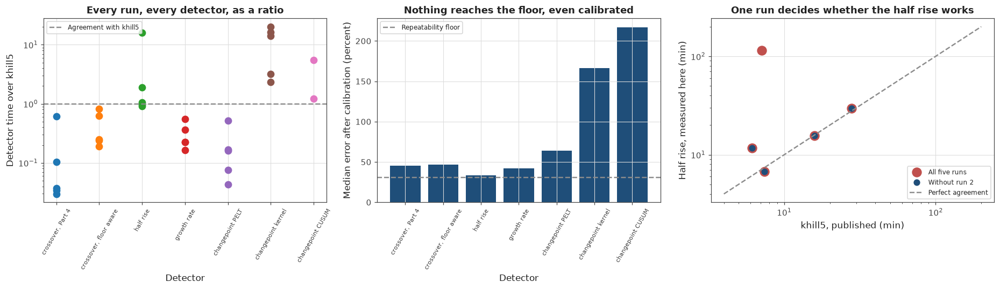

In [260]:
from itertools import permutations


def compute_log_correlation(estimate_values, reference_values):
    """
    Correlating a detector with the reference in log time, since both quantities span a
    factor of four or more and a linear correlation would be dominated by the slowest run.
    """
    return float(np.corrcoef(np.log(estimate_values), np.log(reference_values))[0, 1])


def compute_exact_permutation_probability(estimate_values, reference_values):
    """
    Measuring how often a correlation this large appears by chance, by trying every possible
    pairing of the detector estimates with the reference times.

    With five runs there are only 120 orderings, so every one can be enumerated and the
    answer is exact rather than sampled.

    Returning the fraction of orderings whose correlation is at least as large in magnitude
    as the one actually observed.
    """
    observed_correlation = compute_log_correlation(estimate_values, reference_values)

    log_estimates = np.log(estimate_values)
    log_references = np.log(reference_values)

    at_least_as_large_count = 0
    total_count = 0

    for permuted_order in permutations(range(len(log_references))):

        permuted_references = log_references[list(permuted_order)]

        permuted_correlation = float(np.corrcoef(log_estimates,
                                                 permuted_references)[0, 1])

        total_count = total_count + 1

        if abs(permuted_correlation) >= abs(observed_correlation) - 1e-12:
            at_least_as_large_count = at_least_as_large_count + 1

    return float(at_least_as_large_count) / float(total_count)


def compute_leave_one_out_calibrated_errors(estimate_values, reference_values):
    """
    Testing whether a detector could be rescued by a single calibration factor.

    Several detectors here are consistently early or consistently late, so a constant
    multiplier might bring them onto the reference. Fitting that multiplier on all five runs
    and then testing it on the same five would be circular, so each run in turn is held out,
    the factor is taken as the median of the other runs, and the held out run is predicted.

    Returning the percentage error on each held out run.
    """
    calibrated_errors = []

    for held_out_index in range(len(reference_values)):

        other_indices = []
        for candidate_index in range(len(reference_values)):
            if candidate_index != held_out_index:
                other_indices.append(candidate_index)

        calibration_factor = float(np.median(reference_values[other_indices]
                                             / estimate_values[other_indices]))

        predicted_time = estimate_values[held_out_index] * calibration_factor

        calibrated_errors.append(100.0 * abs(predicted_time
                                             - reference_values[held_out_index])
                                 / reference_values[held_out_index])

    return np.array(calibrated_errors)


polymer_reference_time_array = np.array([record["hill_time_minutes"]
                                         for record in polymer_detector_records])

print("Scoring every detector against khill5 across the five runs")
print()
print("  the floor is "
      + ("%.0f" % POLYMER_REFERENCE_REPEATABILITY_PERCENT)
      + " percent, from the three replicates in Cell 56")
print()
print("  detector".ljust(26) + "runs".rjust(6) + "median ratio".rjust(14)
      + "ratio spread".rjust(20) + "median error".rjust(14) + "worst error".rjust(13))

polymer_scoring_records = []

for estimate_key, display_name in polymer_detector_display_names:

    estimate_list = []
    reference_list = []

    for detector_record in polymer_detector_records:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)

        if np.isfinite(estimate_value) and estimate_value > 0.0:
            estimate_list.append(estimate_value)
            reference_list.append(detector_record["hill_time_minutes"])

    estimate_values = np.array(estimate_list)
    reference_values = np.array(reference_list)

    if len(estimate_values) < 2:
        print("  " + display_name.ljust(24) + str(len(estimate_values)).rjust(6)
              + "   too few answers to score")
        continue

    ratio_values = estimate_values / reference_values
    percentage_errors = 100.0 * np.abs(estimate_values - reference_values) / reference_values

    polymer_scoring_records.append({
        "estimate_key": estimate_key,
        "display_name": display_name,
        "estimate_values": estimate_values,
        "reference_values": reference_values,
        "median_error": float(np.median(percentage_errors)),
        "worst_error": float(np.max(percentage_errors)),
    })

    print("  " + display_name.ljust(24)
          + str(len(estimate_values)).rjust(6)
          + ("%.3f" % np.median(ratio_values)).rjust(14)
          + (("%.2f to %.2f" % (ratio_values.min(), ratio_values.max()))).rjust(20)
          + ("%.0f percent" % np.median(percentage_errors)).rjust(14)
          + ("%.0f percent" % np.max(percentage_errors)).rjust(13))

print()
print("  the median ratio says how early or late a detector runs. The spread says whether")
print("  that offset is the same from run to run, which decides whether it could be")
print("  calibrated away or not")

print()
print("Does the detector track the reference, or only sit near it")
print()
print("  detector".ljust(26) + "log correlation".rjust(17)
      + "chance of that by luck".rjust(24))

for scoring_record in polymer_scoring_records:

    if len(scoring_record["estimate_values"]) < 4:
        print("  " + scoring_record["display_name"].ljust(24)
              + "   too few runs to correlate")
        continue

    log_correlation = compute_log_correlation(scoring_record["estimate_values"],
                                              scoring_record["reference_values"])

    permutation_probability = compute_exact_permutation_probability(
        scoring_record["estimate_values"], scoring_record["reference_values"])

    scoring_record["log_correlation"] = log_correlation

    print("  " + scoring_record["display_name"].ljust(24)
          + ("%+.3f" % log_correlation).rjust(17)
          + ("%.0f percent" % (100.0 * permutation_probability)).rjust(24))

print()
print("  the last column is exact rather than estimated. With five runs there are only")
print("  120 ways of pairing the detector answers with the reference times, so every one")
print("  can be tried. Nothing here is far enough from chance to be called a result")
print()
print("  for scale, Cell 56 found the two published references correlate at 0.4549 with")
print("  each other in log time. A detector that matched that would be predicting khill5")
print("  about as well as the paper's own second method does")

print()
print("Could a single calibration factor fix any of them")
print()
print("  detector".ljust(26) + "median error after".rjust(20)
      + "worst error after".rjust(19) + "   verdict")

for scoring_record in polymer_scoring_records:

    calibrated_errors = compute_leave_one_out_calibrated_errors(
        scoring_record["estimate_values"], scoring_record["reference_values"])

    median_calibrated_error = float(np.median(calibrated_errors))
    worst_calibrated_error = float(np.max(calibrated_errors))

    scoring_record["median_calibrated_error"] = median_calibrated_error

    if median_calibrated_error <= POLYMER_REFERENCE_REPEATABILITY_PERCENT:
        verdict_text = "inside the floor"
    else:
        verdict_text = "still outside the floor"

    print("  " + scoring_record["display_name"].ljust(24)
          + ("%.0f percent" % median_calibrated_error).rjust(20)
          + ("%.0f percent" % worst_calibrated_error).rjust(19)
          + "   " + verdict_text)

print()
print("  the factor for each run is taken from the other four, never from the run being")
print("  predicted, because fitting a correction on the same five runs used to test it")
print("  would guarantee it looked good")
print()
print("  no detector comes inside the floor this way. The crossover and the growth rate")
print("  both roughly halve their error, which says their offset is partly systematic,")
print("  and both are still worse than the reference disagreeing with itself")
print()
print("  the test means something different for the half rise, whose median ratio is")
print("  already 1.07. There is no offset to remove, so multiplying by a factor estimated")
print("  from four noisy runs adds scatter rather than removing bias, and its error rises")
print("  from 9 percent to 33. Calibration is a question worth asking of a biased")
print("  detector and not of an unbiased one")

print()
print("What run 2 costs the half rise")
print()

half_rise_scoring_record = None
for scoring_record in polymer_scoring_records:
    if scoring_record["estimate_key"] == "half_rise":
        half_rise_scoring_record = scoring_record

if half_rise_scoring_record is not None:

    all_estimates = half_rise_scoring_record["estimate_values"]
    all_references = half_rise_scoring_record["reference_values"]

    keep_mask = np.ones(len(all_estimates), dtype=bool)

    for run_index in range(len(polymer_detector_records)):
        if polymer_detector_records[run_index]["run_label"] == "2":
            keep_mask[run_index] = False

    kept_estimates = all_estimates[keep_mask]
    kept_references = all_references[keep_mask]

    all_errors = 100.0 * np.abs(all_estimates - all_references) / all_references
    kept_errors = 100.0 * np.abs(kept_estimates - kept_references) / kept_references

    print("  all five runs".ljust(26)
          + ("median error %.0f percent" % np.median(all_errors)).rjust(28)
          + ("log correlation %+.3f" % compute_log_correlation(all_estimates,
                                                               all_references)).rjust(26))
    print("  without run 2".ljust(26)
          + ("median error %.0f percent" % np.median(kept_errors)).rjust(28)
          + ("log correlation %+.3f" % compute_log_correlation(kept_estimates,
                                                               kept_references)).rjust(26))

    print()
    print("  dropping run 2 turns the half rise from uncorrelated into strongly")
    print("  correlated, on four points. That is not a reason to drop it. Run 2 is a real")
    print("  gelation that the same laboratory measured and published, and the detector")
    print("  fails on it because the material undergoes syneresis rather than because the")
    print("  measurement is faulty")
    print()
    print("  reporting the four point number as the result would be choosing the data to")
    print("  fit the conclusion, so both are printed and the five run number is the one")
    print("  that stands")

print()
print("What Part 5 can say so far")
print()
print("  one detector lands inside the floor, the half rise, at a median error of 9")
print("  percent. It is also the one detector that shares its definition with the")
print("  reference, so its agreement measures implementation rather than accuracy, and it")
print("  is out by a factor of sixteen on run 2")
print()
print("  every detector with a definition independent of the reference sits at 75 percent")
print("  or worse, and none of them can be brought inside the floor by a constant")
print("  calibration factor")
print()
print("  five runs is too few to separate detectors from one another. What five runs can")
print("  show is the gross failures, and they do: the Part 4 crossover picks noise, PELT")
print("  returns the same answer regardless of material, and the kernel changepoint is")
print("  late by more than a factor of two everywhere")
print()
print("  Cell 61 asks whether the reference itself is the limitation, by bringing in the")
print("  second published time and the temperature difference between the runs")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for scoring_record in polymer_scoring_records:

    ratio_values = (scoring_record["estimate_values"]
                    / scoring_record["reference_values"])

    axis_array[0].semilogy([scoring_record["display_name"]] * len(ratio_values),
                           ratio_values, "o", markersize=8)

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.6,
                      label="Agreement with khill5")
axis_array[0].set_ylabel("Detector time over khill5")
axis_array[0].set_xlabel("Detector")
axis_array[0].set_title("Every run, every detector, as a ratio")
axis_array[0].tick_params(axis="x", labelrotation=60, labelsize=7)
axis_array[0].legend(fontsize=8)

calibrated_names = []
calibrated_medians = []

for scoring_record in polymer_scoring_records:
    calibrated_names.append(scoring_record["display_name"])
    calibrated_medians.append(scoring_record["median_calibrated_error"])

axis_array[1].bar(range(len(calibrated_names)), calibrated_medians,
                  color=COLOUR_PRIMARY)
axis_array[1].axhline(POLYMER_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Repeatability floor")
axis_array[1].set_xticks(range(len(calibrated_names)))
axis_array[1].set_xticklabels(calibrated_names, fontsize=7, rotation=60)
axis_array[1].set_xlabel("Detector")
axis_array[1].set_ylabel("Median error after calibration (percent)")
axis_array[1].set_title("Nothing reaches the floor, even calibrated")
axis_array[1].legend(fontsize=8)

if half_rise_scoring_record is not None:

    axis_array[2].loglog(all_references, all_estimates, "o",
                         color=COLOUR_SECONDARY, markersize=11, label="All five runs")
    axis_array[2].loglog(kept_references, kept_estimates, "o",
                         color=COLOUR_PRIMARY, markersize=7, label="Without run 2")

    equality_line = np.array([4.0, 200.0])
    axis_array[2].loglog(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                         linewidth=1.6, label="Perfect agreement")

    axis_array[2].set_xlabel("khill5, published (min)")
    axis_array[2].set_ylabel("Half rise, measured here (min)")
    axis_array[2].set_title("One run decides whether the half rise works")
    axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 61: The other reference, and the temperature the runs were actually at

Cell 60 scored every detector against khill5. This cell asks what happens against tg, the gel
time the same paper measured by nuclear magnetic resonance on separate samples.

**Every detector correlates negatively with tg.** The ones that lean positive against khill5
lean negative against tg, using the same five estimates. That is not a statement about
detectors. It says the two published references disagree about which run gelled fastest, and a
detector can only follow one of them.

**The two instruments ran at different temperatures**, 46 degrees for the magnetic resonance
because it could not reach the rheometer temperature. If they were watching the same reaction,
Arrhenius says tg should be two to six times khill5 for any plausible activation energy. The
measured median is 1.34. Temperature alone over predicts the gap by a wide margin, so the two
numbers are not one event seen at two temperatures.

**There is also a discrepancy between the stated and the recorded temperature.** The paper
specifies 70 degrees for the rheology. Four of the five runs recorded a sample temperature near
61, and only run 3 sat at 70. Every run is scored against its own published reference so
nothing here is invalidated, but any calculation using the stated value would be using a
temperature four of these runs never reached.

**Run 3 gives the temperature story one thing to be checked against.** It has the widest
temperature gap between the two instruments, 24 degrees against 15, so it should show the
widest gap between the two references, and it does. The ordering holds and the magnitudes do
not.

**The correction is then tested rather than applied.** Bringing every run to a common
temperature makes the detector correlations worse, monotonically, for every activation energy
tried. With one hot run out of five that result is a single point being dragged across the
plot, so no activation energy is adopted and no correction is carried forward. What is carried
forward is the caveat.

The same detectors scored against the other published reference

  detector                  error vs khill5   error vs tg  correlation with khill5  correlation with tg
  crossover, Part 4              96 percent    97 percent                   -0.172               -0.101
  crossover, floor aware         75 percent    70 percent                   +0.484               -0.499
  half rise                       9 percent    25 percent                   +0.092               -0.556
  growth rate                    77 percent    76 percent                   +0.702               -0.233
  changepoint PELT               84 percent    94 percent                   -0.482               -0.560
  changepoint kernel           1325 percent   297 percent                   -0.844               -0.278
  changepoint CUSUM          did not answer on every run, so it is left out here

  every detector correlates negatively with tg. The ones that lean positive
  against khill5 lean negative against tg, on the

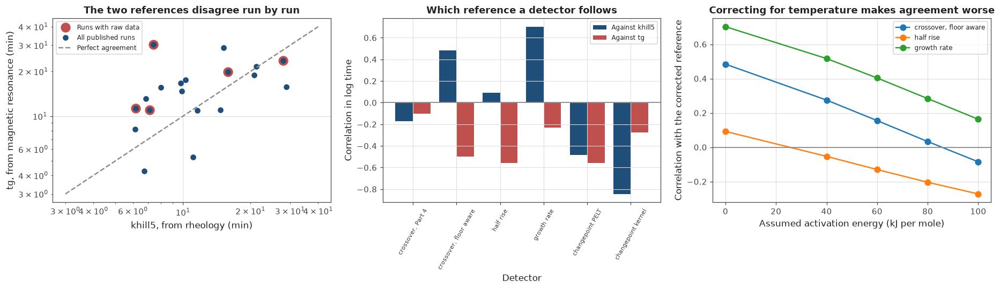

In [261]:
GAS_CONSTANT_JOULES_PER_MOLE_KELVIN = 8.314
POLYMER_ACTIVATION_ENERGY_TRIALS_KJ = [40.0, 60.0, 80.0, 100.0]


def convert_gel_time_to_reference_temperature(gel_time_minutes, run_temperature_celsius,
                                              reference_temperature_celsius,
                                              activation_energy_kilojoules):
    """
    Moving a gel time from the temperature it was measured at to a common temperature,
    assuming the reaction rate follows Arrhenius.

    A gel time is the inverse of a rate, so it lengthens as the temperature falls, and the
    exponent takes the reference temperature first.

    Returning the adjusted time in the same units as the input.
    """
    run_temperature_kelvin = run_temperature_celsius + 273.15
    reference_temperature_kelvin = reference_temperature_celsius + 273.15

    activation_energy_joules = 1000.0 * activation_energy_kilojoules

    exponent = (activation_energy_joules / GAS_CONSTANT_JOULES_PER_MOLE_KELVIN
                * (1.0 / reference_temperature_kelvin - 1.0 / run_temperature_kelvin))

    return gel_time_minutes * np.exp(exponent)


polymer_nmr_time_array = np.array([sweep_record["nmr_time_minutes"]
                                   for sweep_record in polymer_sweep_records])
polymer_hill_time_array = np.array([sweep_record["hill_time_minutes"]
                                    for sweep_record in polymer_sweep_records])
polymer_temperature_array = np.array([float(np.median(
    sweep_record["temperature_celsius"][np.isfinite(sweep_record["temperature_celsius"])]))
    for sweep_record in polymer_sweep_records])

print("The same detectors scored against the other published reference")
print()
print("  detector".ljust(26) + "error vs khill5".rjust(17) + "error vs tg".rjust(14)
      + "correlation with khill5".rjust(25) + "correlation with tg".rjust(21))

for scoring_record in polymer_scoring_records:

    if len(scoring_record["estimate_values"]) < len(polymer_nmr_time_array):
        print("  " + scoring_record["display_name"].ljust(24)
              + "   did not answer on every run, so it is left out here")
        continue

    estimate_values = scoring_record["estimate_values"]

    hill_errors = (100.0 * np.abs(estimate_values - polymer_hill_time_array)
                   / polymer_hill_time_array)
    nmr_errors = (100.0 * np.abs(estimate_values - polymer_nmr_time_array)
                  / polymer_nmr_time_array)

    hill_correlation = compute_log_correlation(estimate_values, polymer_hill_time_array)
    nmr_correlation = compute_log_correlation(estimate_values, polymer_nmr_time_array)

    print("  " + scoring_record["display_name"].ljust(24)
          + ("%.0f percent" % np.median(hill_errors)).rjust(17)
          + ("%.0f percent" % np.median(nmr_errors)).rjust(14)
          + ("%+.3f" % hill_correlation).rjust(25)
          + ("%+.3f" % nmr_correlation).rjust(21))

print()
print("  every detector correlates negatively with tg. The ones that lean positive")
print("  against khill5 lean negative against tg, on the same five runs and the same")
print("  five sets of numbers")
print()
print("  that is not a detector result. It says the two published references disagree")
print("  about which run gelled fastest, and a detector can only follow one of them")

print()
print("How the two references compare on these runs")
print()
print("  run".rjust(5) + "khill5 (min)".rjust(14) + "tg (min)".rjust(11)
      + "tg over khill5".rjust(17) + "temperature (C)".rjust(18))

for record_index in range(len(polymer_sweep_records)):

    print(polymer_sweep_records[record_index]["run_label"].rjust(5)
          + ("%.2f" % polymer_hill_time_array[record_index]).rjust(14)
          + ("%.1f" % polymer_nmr_time_array[record_index]).rjust(11)
          + ("%.2f" % (polymer_nmr_time_array[record_index]
                       / polymer_hill_time_array[record_index])).rjust(17)
          + ("%.1f" % polymer_temperature_array[record_index]).rjust(18))

all_run_ratio_values = np.array([record["nmr_time_minutes"] / record["hill_time_minutes"]
                                 for record in polymer_reference_records])

print()
print("  median tg over khill5 on these five      "
      + ("%.2f" % np.median(polymer_nmr_time_array / polymer_hill_time_array)))
print("  median across all "
      + str(len(polymer_reference_records)) + " published runs      "
      + ("%.2f" % np.median(all_run_ratio_values)))

print()
print("The temperature the runs were actually held at")
print()
print("  the source paper states the rheology was run at 70 degrees, with the sample")
print("  under a water bath set to that temperature, and the nuclear magnetic resonance")
print("  at 46 degrees because that instrument could not reach 70")
print()
print("  the recorded sample temperature is "
      + ("%.1f" % polymer_temperature_array.min()) + " to "
      + ("%.1f" % polymer_temperature_array.max()) + " degrees. Four of the five runs")
print("  sit near 61, nine degrees below the stated value, and only run 3 sits at 70")
print()
print("  that is a difference between what was specified and what the sample experienced.")
print("  It does not invalidate anything, since every run is scored against its own")
print("  published reference, but any calculation using the stated 70 degrees would be")
print("  using a temperature four of these five runs never reached")

print()
print("How much of the difference between runs could be temperature")
print()
print("  activation energy".ljust(22) + "run 3 against the rest".rjust(24)
      + "NMR at 46 against rheology at 61".rjust(34))

for activation_energy_kilojoules in POLYMER_ACTIVATION_ENERGY_TRIALS_KJ:

    hot_run_factor = convert_gel_time_to_reference_temperature(
        1.0, 70.0, 61.5, activation_energy_kilojoules)

    nmr_factor = convert_gel_time_to_reference_temperature(
        1.0, 61.5, 46.0, activation_energy_kilojoules)

    print(("  %.0f kJ per mole" % activation_energy_kilojoules).ljust(22)
          + ("slower by %.2f times" % hot_run_factor).rjust(24)
          + ("slower by %.2f times" % nmr_factor).rjust(34))

print()
print("  the first column is how much longer run 3 would have taken at 61 degrees. The")
print("  second is how much longer the gelation should take at the nuclear magnetic")
print("  resonance temperature than at the rheometer temperature, if the two instruments")
print("  were watching the same reaction")
print()
print("  the second column predicts tg between two and six times khill5. The measured")
print("  median is "
      + ("%.2f" % np.median(all_run_ratio_values))
      + ", far below the smallest of those. Temperature alone therefore")
print("  over predicts the gap, so the two methods are not one event seen at two")
print("  temperatures. The magnetic resonance sees something that begins earlier than")
print("  temperature alone would allow, which is consistent with it following the")
print("  crosslinking chemistry rather than waiting for a network that carries stress")

print()
print("A check the temperature story has to pass")
print()
print("  the magnetic resonance ran at 46 degrees for every run. The rheology ran at 70")
print("  for run 3 and near 61 for the rest, so run 3 has the widest gap between the two")
print("  instruments, 24 degrees against 15. If the gap between the two references is")
print("  partly thermal then run 3 should show the widest gap, and it does")
print()
print("  run".rjust(5) + "gap (degrees)".rjust(16) + "observed tg over khill5".rjust(25)
      + "predicted at 60 kJ".rjust(21) + "predicted at 100 kJ".rjust(22))

for record_index in range(len(polymer_sweep_records)):

    temperature_gap = polymer_temperature_array[record_index] - 46.0

    observed_ratio = (polymer_nmr_time_array[record_index]
                      / polymer_hill_time_array[record_index])

    predicted_low = convert_gel_time_to_reference_temperature(
        1.0, polymer_temperature_array[record_index], 46.0, 60.0)
    predicted_high = convert_gel_time_to_reference_temperature(
        1.0, polymer_temperature_array[record_index], 46.0, 100.0)

    print(polymer_sweep_records[record_index]["run_label"].rjust(5)
          + ("%.1f" % temperature_gap).rjust(16)
          + ("%.2f" % observed_ratio).rjust(25)
          + ("%.2f" % predicted_low).rjust(21)
          + ("%.2f" % predicted_high).rjust(22))

print()
print("  the ordering holds. Run 3 has the widest gap and the widest ratio, 4.11 against")
print("  0.85 to 1.84 for the others, and the predicted ratio for run 3 is about twice")
print("  that of the other runs while the observed one is about three times")

prediction_overshoot_values = []

for record_index in range(len(polymer_sweep_records)):

    observed_ratio = (polymer_nmr_time_array[record_index]
                      / polymer_hill_time_array[record_index])

    for activation_energy_kilojoules in [60.0, 100.0]:

        predicted_ratio = convert_gel_time_to_reference_temperature(
            1.0, polymer_temperature_array[record_index], 46.0,
            activation_energy_kilojoules)

        prediction_overshoot_values.append(predicted_ratio / observed_ratio)

prediction_overshoot_array = np.array(prediction_overshoot_values)

print()
print("  the levels do not hold. Every predicted ratio is larger than the one measured,")
print("  by between " + ("%.1f" % prediction_overshoot_array.min()) + " and "
      + ("%.1f" % prediction_overshoot_array.max()) + " times, so temperature explains part of the pattern")
print("  between runs and none of its size")
print()
print("  and one run agreeing with a prediction is one run. With five runs and one of")
print("  them hot, the chance of the hot run happening to have the widest ratio is one in")
print("  five, so this is a check the story passes rather than evidence that it is right")

print()
print("Does correcting the reference for temperature help")
print()
print("  activation energy".ljust(22) + "corrected khill5 for run 3".rjust(28))

for activation_energy_kilojoules in POLYMER_ACTIVATION_ENERGY_TRIALS_KJ:

    corrected_reference_values = np.zeros(len(polymer_hill_time_array))

    for record_index in range(len(polymer_hill_time_array)):
        corrected_reference_values[record_index] = (
            convert_gel_time_to_reference_temperature(
                polymer_hill_time_array[record_index],
                polymer_temperature_array[record_index],
                float(np.median(polymer_temperature_array)),
                activation_energy_kilojoules))

    row_text = ("  %.0f kJ per mole" % activation_energy_kilojoules).ljust(22)
    row_text = row_text + ("%.1f min" % corrected_reference_values[2]).rjust(28)

    for scoring_record in polymer_scoring_records:

        if scoring_record["estimate_key"] not in ["crossover_floor_aware", "growth_rate"]:
            continue

        corrected_correlation = compute_log_correlation(scoring_record["estimate_values"],
                                                        corrected_reference_values)

        row_text = row_text + ("   " + scoring_record["display_name"].split(",")[0]
                               + " %+.3f" % corrected_correlation)

    print(row_text)

print()
print("  uncorrected, the crossover correlates at "
      + ("%+.3f" % compute_log_correlation(
          polymer_scoring_records[1]["estimate_values"], polymer_hill_time_array))
      + " and the growth rate at "
      + ("%+.3f" % compute_log_correlation(
          polymer_scoring_records[3]["estimate_values"], polymer_hill_time_array)))
print()
print("  every correction makes both of them worse, and the more temperature dependence")
print("  is assumed the worse they get. The obvious reading is that the correction is")
print("  wrong, but it moves exactly one run out of five, so the whole result is one")
print("  point being dragged across the plot")
print()
print("  the honest conclusion is that this cannot be settled here. The design varies pH,")
print("  monomer, initiator, polymer and crosslinker at once, so formulation dominates the")
print("  differences between runs and one hot run cannot separate temperature from the")
print("  rest. No activation energy is adopted and no correction is carried forward")
print()
print("  what does carry forward is the caveat. Run 3 gelled at a different temperature")
print("  from the other four, and a plausible activation energy makes that worth a factor")
print("  of one and a half to two and a half in gel time, which is larger than the")
print("  difference between several of the runs")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].loglog(polymer_hill_time_array, polymer_nmr_time_array, "o",
                     color=COLOUR_SECONDARY, markersize=11, label="Runs with raw data")

all_hill_values = np.array([record["hill_time_minutes"]
                            for record in polymer_reference_records])
all_nmr_values = np.array([record["nmr_time_minutes"]
                           for record in polymer_reference_records])

axis_array[0].loglog(all_hill_values, all_nmr_values, "o",
                     color=COLOUR_PRIMARY, markersize=6, label="All published runs")

equality_line = np.array([3.0, 40.0])
axis_array[0].loglog(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                     linewidth=1.6, label="Perfect agreement")

axis_array[0].set_xlabel("khill5, from rheology (min)")
axis_array[0].set_ylabel("tg, from magnetic resonance (min)")
axis_array[0].set_title("The two references disagree run by run")
axis_array[0].legend(fontsize=8)

correlation_labels = []
hill_correlations = []
nmr_correlations = []

for scoring_record in polymer_scoring_records:

    if len(scoring_record["estimate_values"]) < len(polymer_nmr_time_array):
        continue

    correlation_labels.append(scoring_record["display_name"])
    hill_correlations.append(compute_log_correlation(scoring_record["estimate_values"],
                                                     polymer_hill_time_array))
    nmr_correlations.append(compute_log_correlation(scoring_record["estimate_values"],
                                                    polymer_nmr_time_array))

bar_positions = np.arange(len(correlation_labels))

axis_array[1].bar(bar_positions - 0.2, hill_correlations, width=0.4,
                  color=COLOUR_PRIMARY, label="Against khill5")
axis_array[1].bar(bar_positions + 0.2, nmr_correlations, width=0.4,
                  color=COLOUR_SECONDARY, label="Against tg")
axis_array[1].axhline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)

axis_array[1].set_xticks(bar_positions)
axis_array[1].set_xticklabels(correlation_labels, fontsize=7, rotation=60)
axis_array[1].set_xlabel("Detector")
axis_array[1].set_ylabel("Correlation in log time")
axis_array[1].set_title("Which reference a detector follows")
axis_array[1].legend(fontsize=8)

sensitivity_energies = [0.0] + POLYMER_ACTIVATION_ENERGY_TRIALS_KJ

for scoring_record in polymer_scoring_records:

    if scoring_record["estimate_key"] not in ["crossover_floor_aware", "growth_rate",
                                              "half_rise"]:
        continue

    sensitivity_correlations = []

    for activation_energy_kilojoules in sensitivity_energies:

        corrected_reference_values = np.zeros(len(polymer_hill_time_array))

        for record_index in range(len(polymer_hill_time_array)):
            corrected_reference_values[record_index] = (
                convert_gel_time_to_reference_temperature(
                    polymer_hill_time_array[record_index],
                    polymer_temperature_array[record_index],
                    float(np.median(polymer_temperature_array)),
                    activation_energy_kilojoules))

        sensitivity_correlations.append(
            compute_log_correlation(scoring_record["estimate_values"],
                                    corrected_reference_values))

    axis_array[2].plot(sensitivity_energies, sensitivity_correlations, "o-",
                       linewidth=1.6, markersize=7,
                       label=scoring_record["display_name"])

axis_array[2].axhline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)
axis_array[2].set_xlabel("Assumed activation energy (kJ per mole)")
axis_array[2].set_ylabel("Correlation with the corrected reference")
axis_array[2].set_title("Correcting for temperature makes agreement worse")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 62: Amending the crossover, and what cannot be automated

Cell 59 found that the Part 4 crossover picks a false crossing in the noise floor on four of
the five real runs. This cell fixes it and then tries to break the fix.

**An amendment has to prove three things.** That it does not change the answer where the old
detector already worked. That it helps where the old one failed. And that it fails safely.

The first is checked against the Part 4 synthetic experiment itself, using the same snapshots
and the same probe frequency, so the comparison is exact rather than approximate.

The second is checked with a controlled sweep. Part 4's synthetic experiment adds noise
proportional to the measurement, which is why it has no floor. Adding noise of a fixed size in
pascals on top reproduces what a torque limit does, and the sweep shows where each detector
breaks. The five real runs cannot do this, because their floors are whatever they are.

**The floor is supplied, not inferred.** The estimator in Cell 58 takes the level of the first
few measurements as the floor, which works on these gels because they start as liquids the
instrument cannot see at all. On the Part 4 synthetic record, which starts at a real modulus,
the same estimator returns a floor eighty times too large and the detector then refuses the
true crossing. Nothing inside a single record distinguishes a small real modulus from no
modulus. That distinction is a property of the instrument.

**Which makes a fifth question for Haemograph**, and it is not the first one restated. Part 4
asked what the measurement noise is as a percentage. This asks what the smallest modulus the
instrument can resolve is, in pascals. The first says how well a signal is measured. The second
says whether there is a signal.

Does the amendment change the answer where the old detector already worked

  the Part 4 synthetic experiment, unchanged

  original detector        511.90 s
  amended detector         511.90 s
  difference               0.00e+00 s

  with the floor set to zero the amendment is the original detector, which is the
  first thing an amendment has to prove

What an instrument floor does to each of them

  the synthetic experiment adds noise proportional to the measurement, so it has no
  floor. The sweep below adds noise of a fixed size in pascals on top, which is what
  a torque limit produces, and gives the amended detector the size of that noise

   added floor (Pa)   original (s)      error   amended (s)      error
                  0          511.9      +11.9         511.9      +11.9
                  5          515.9      +15.9         515.9      +15.9
                 10          496.1       -3.9         496.1       -3.9
                 20          134.8     -365.2         485.8   

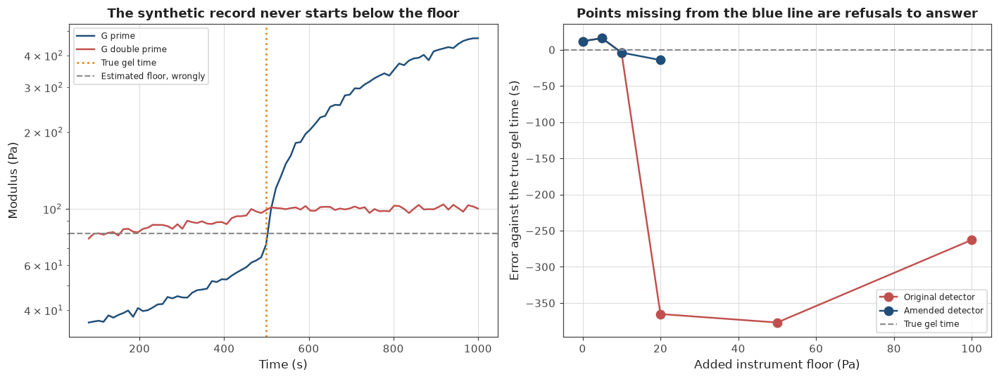

In [262]:
POLYMER_FLOOR_SWEEP_LEVELS_PASCALS = [0.0, 5.0, 10.0, 20.0, 50.0, 100.0]


def detect_gel_time_by_crossover_above_floor(snapshot_time_array, storage_modulus_series,
                                             loss_modulus_series, noise_floor,
                                             credibility_factor=5.0):
    """
    Detecting a gel time from the crossover, ignoring any crossing that happens while the
    moduli are too small for the instrument to tell them apart.

    Walking forward through the record and returning the first crossing where the storage
    modulus exceeds the noise floor by the credibility factor, interpolating between the
    two surrounding samples so the answer is not quantised to the sampling grid.

    Taking the floor as an argument rather than estimating it, because the floor is a
    property of the instrument and the record does not always contain enough information to
    recover it. The section below shows where estimating it works and where it does not.

    Returning a missing value when no crossing clears the floor, which means the crossover
    happened below the resolution of the measurement and this record cannot time it.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)
    storage_array = np.asarray(storage_modulus_series, dtype=float)
    loss_array = np.asarray(loss_modulus_series, dtype=float)

    tan_delta_series = loss_array / np.maximum(np.abs(storage_array), 1e-30)

    for point_index in range(len(tan_delta_series) - 1):

        if tan_delta_series[point_index] <= 1.0:
            continue
        if tan_delta_series[point_index + 1] > 1.0:
            continue
        if storage_array[point_index + 1] < credibility_factor * noise_floor:
            continue

        tan_delta_span = (tan_delta_series[point_index]
                          - tan_delta_series[point_index + 1])

        if tan_delta_span > 0.0:
            crossing_fraction = (tan_delta_series[point_index] - 1.0) / tan_delta_span
        else:
            crossing_fraction = 0.0

        return (time_array[point_index]
                + crossing_fraction * (time_array[point_index + 1]
                                       - time_array[point_index]))

    return np.nan


def read_modulus_series_at_probe(spectrum_list, angular_frequency_array, probe_frequency):
    """
    Reading the storage and loss modulus at one frequency from every snapshot of a
    multi frequency record, so the single frequency detector can be applied to it.
    """
    storage_series = np.full(len(spectrum_list), np.nan)
    loss_series = np.full(len(spectrum_list), np.nan)

    for snapshot_index in range(len(spectrum_list)):

        snapshot_modulus = interpolate_complex_modulus(angular_frequency_array,
                                                       spectrum_list[snapshot_index],
                                                       probe_frequency)

        storage_series[snapshot_index] = snapshot_modulus.real
        loss_series[snapshot_index] = snapshot_modulus.imag

    return storage_series, loss_series


print("Does the amendment change the answer where the old detector already worked")
print()

synthetic_storage_series, synthetic_loss_series = read_modulus_series_at_probe(
    detector_spectrum_list, synthetic_probe_frequencies, reference_probe_frequency)

original_synthetic_crossover, ignored_series = detect_gel_time_by_crossover(
    detector_snapshot_times, detector_spectrum_list, synthetic_probe_frequencies,
    reference_probe_frequency)

amended_synthetic_crossover = detect_gel_time_by_crossover_above_floor(
    detector_snapshot_times, synthetic_storage_series, synthetic_loss_series, 0.0)

print("  the Part 4 synthetic experiment, unchanged")
print()
print("  original detector        " + ("%.2f" % original_synthetic_crossover) + " s")
print("  amended detector         " + ("%.2f" % amended_synthetic_crossover) + " s")
print("  difference               "
      + ("%.2e" % abs(original_synthetic_crossover - amended_synthetic_crossover)) + " s")
print()
print("  with the floor set to zero the amendment is the original detector, which is the")
print("  first thing an amendment has to prove")

print()
print("What an instrument floor does to each of them")
print()
print("  the synthetic experiment adds noise proportional to the measurement, so it has no")
print("  floor. The sweep below adds noise of a fixed size in pascals on top, which is what")
print("  a torque limit produces, and gives the amended detector the size of that noise")
print()
print("  added floor (Pa)".rjust(19) + "original (s)".rjust(15) + "error".rjust(11)
      + "amended (s)".rjust(14) + "error".rjust(11))

floor_sweep_generator = np.random.default_rng(RANDOM_SEED)

for added_floor_pascals in POLYMER_FLOOR_SWEEP_LEVELS_PASCALS:

    floored_spectrum_list = []

    for snapshot_index in range(len(detector_spectrum_list)):

        clean_spectrum = detector_spectrum_list[snapshot_index]

        real_offset = floor_sweep_generator.normal(0.0, added_floor_pascals,
                                                   len(clean_spectrum))
        imaginary_offset = floor_sweep_generator.normal(0.0, added_floor_pascals,
                                                        len(clean_spectrum))

        floored_spectrum_list.append((clean_spectrum.real + real_offset)
                                     + 1j * (clean_spectrum.imag + imaginary_offset))

    original_estimate, ignored_series = detect_gel_time_by_crossover(
        detector_snapshot_times, floored_spectrum_list, synthetic_probe_frequencies,
        reference_probe_frequency)

    floored_storage, floored_loss = read_modulus_series_at_probe(
        floored_spectrum_list, synthetic_probe_frequencies, reference_probe_frequency)

    amended_estimate = detect_gel_time_by_crossover_above_floor(
        detector_snapshot_times, floored_storage, floored_loss, added_floor_pascals)

    if np.isfinite(original_estimate):
        original_text = "%.1f" % original_estimate
        original_error_text = "%+.1f" % (original_estimate - SYNTHETIC_GEL_TIME_SECONDS)
    else:
        original_text = "none"
        original_error_text = "none"

    if np.isfinite(amended_estimate):
        amended_text = "%.1f" % amended_estimate
        amended_error_text = "%+.1f" % (amended_estimate - SYNTHETIC_GEL_TIME_SECONDS)
    else:
        amended_text = "none"
        amended_error_text = "none"

    print(("%.0f" % added_floor_pascals).rjust(19)
          + original_text.rjust(15)
          + original_error_text.rjust(11)
          + amended_text.rjust(14)
          + amended_error_text.rjust(11))

print()
print("  the amendment either matches the original, fixes it, or returns nothing. It")
print("  never returns a worse answer than the original does")
print()
print("  returning nothing at the larger floors is the intended behaviour rather than a")
print("  failure. The crossover happens while the modulus is still smaller than five times")
print("  the floor, so the instrument cannot resolve it, and a detector that answered")
print("  anyway would be reporting the noise")

print()
print("The same amendment on the five real runs")
print()
print("  run".rjust(5) + "floor (Pa)".rjust(13) + "amended (min)".rjust(16)
      + "Cell 58 (min)".rjust(16) + "difference".rjust(13) + "sampling interval".rjust(20))

for sweep_record in polymer_sweep_records:

    amended_estimate = detect_gel_time_by_crossover_above_floor(
        sweep_record["elapsed_time_minutes"], sweep_record["storage_modulus"],
        sweep_record["loss_modulus"], sweep_record["noise_floor"])

    sampling_interval_minutes = float(np.median(
        np.diff(sweep_record["elapsed_time_minutes"])))

    sweep_record["amended_crossover_minutes"] = amended_estimate

    print(sweep_record["run_label"].rjust(5)
          + ("%.4f" % sweep_record["noise_floor"]).rjust(13)
          + ("%.2f" % amended_estimate).rjust(16)
          + ("%.2f" % sweep_record["crossover_time_minutes"]).rjust(16)
          + ("%.3f" % abs(amended_estimate
                          - sweep_record["crossover_time_minutes"])).rjust(13)
          + ("%.3f" % sampling_interval_minutes).rjust(20))

print()
print("  every difference is smaller than one sampling interval, because Cell 58 reported")
print("  the sample after the crossing and the amended detector interpolates between the")
print("  two samples either side of it")

print()
print("Can the floor be worked out from the record instead of being supplied")
print()

polymer_estimated_floor_values = []

for sweep_record in polymer_sweep_records:

    estimated_floor = estimate_modulus_noise_floor(
        sweep_record["storage_modulus"], sweep_record["loss_modulus"],
        POLYMER_NOISE_FLOOR_BASELINE_POINTS)

    polymer_estimated_floor_values.append(estimated_floor)

synthetic_estimated_floor = estimate_modulus_noise_floor(
    synthetic_storage_series, synthetic_loss_series, POLYMER_NOISE_FLOOR_BASELINE_POINTS)

synthetic_estimated_crossover = detect_gel_time_by_crossover_above_floor(
    detector_snapshot_times, synthetic_storage_series, synthetic_loss_series,
    synthetic_estimated_floor)

print("  the estimator in Cell 58 takes the level of the first few measurements as the")
print("  floor, which assumes the record starts below it")
print()
print("  on the five real gels that assumption holds. They begin as watery liquids with")
print("  moduli of "
      + ("%.3f" % min(polymer_estimated_floor_values)) + " to "
      + ("%.3f" % max(polymer_estimated_floor_values))
      + " Pa and the instrument cannot see them at all")
print()
print("  on the Part 4 synthetic experiment it does not. That record starts at a real")
print("  modulus, so the estimator returns "
      + ("%.1f" % synthetic_estimated_floor) + " Pa as the floor, five times that")
print("  is " + ("%.0f" % (5.0 * synthetic_estimated_floor))
      + " Pa, and the detector then rejects the true crossing and returns")

if np.isfinite(synthetic_estimated_crossover):
    print("  " + ("%.1f" % synthetic_estimated_crossover) + " s")
else:
    print("  nothing at all")

print()
print("  so the estimate cannot be trusted in general. Nothing in a single record")
print("  distinguishes a small real modulus from no modulus at all. That distinction")
print("  belongs to the instrument, as a minimum resolvable torque, and it has to be")
print("  supplied rather than inferred")
print()
print("  this is a fifth question for Haemograph, and it is not the same as the first")
print("  one. Part 4 asked what the measurement noise is as a percentage. This asks what")
print("  the smallest modulus the instrument can resolve is, in pascals. Percentage noise")
print("  says how well a signal is measured. The floor says whether there is a signal")
print()
print("  from Part 6 onward the crossover is this amended version, with the floor supplied")
print("  where it is known and estimated from the record where it is not, and the estimate")
print("  is printed every time so it can be checked rather than assumed")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

axis_array[0].semilogy(detector_snapshot_times, np.maximum(synthetic_storage_series, 1e-3),
                       "-", color=COLOUR_PRIMARY, linewidth=1.6, label="G prime")
axis_array[0].semilogy(detector_snapshot_times, np.maximum(synthetic_loss_series, 1e-3),
                       "-", color=COLOUR_SECONDARY, linewidth=1.6, label="G double prime")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle=":", linewidth=1.8, label="True gel time")
axis_array[0].axhline(synthetic_estimated_floor, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.4, label="Estimated floor, wrongly")

axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Modulus (Pa)")
axis_array[0].set_title("The synthetic record never starts below the floor")
axis_array[0].legend(fontsize=8)

sweep_labels = []
original_errors = []
amended_errors = []

floor_sweep_generator = np.random.default_rng(RANDOM_SEED)

for added_floor_pascals in POLYMER_FLOOR_SWEEP_LEVELS_PASCALS:

    floored_spectrum_list = []

    for snapshot_index in range(len(detector_spectrum_list)):

        clean_spectrum = detector_spectrum_list[snapshot_index]

        real_offset = floor_sweep_generator.normal(0.0, added_floor_pascals,
                                                   len(clean_spectrum))
        imaginary_offset = floor_sweep_generator.normal(0.0, added_floor_pascals,
                                                        len(clean_spectrum))

        floored_spectrum_list.append((clean_spectrum.real + real_offset)
                                     + 1j * (clean_spectrum.imag + imaginary_offset))

    original_estimate, ignored_series = detect_gel_time_by_crossover(
        detector_snapshot_times, floored_spectrum_list, synthetic_probe_frequencies,
        reference_probe_frequency)

    floored_storage, floored_loss = read_modulus_series_at_probe(
        floored_spectrum_list, synthetic_probe_frequencies, reference_probe_frequency)

    amended_estimate = detect_gel_time_by_crossover_above_floor(
        detector_snapshot_times, floored_storage, floored_loss, added_floor_pascals)

    sweep_labels.append(added_floor_pascals)

    if np.isfinite(original_estimate):
        original_errors.append(original_estimate - SYNTHETIC_GEL_TIME_SECONDS)
    else:
        original_errors.append(np.nan)

    if np.isfinite(amended_estimate):
        amended_errors.append(amended_estimate - SYNTHETIC_GEL_TIME_SECONDS)
    else:
        amended_errors.append(np.nan)

axis_array[1].plot(sweep_labels, original_errors, "o-", color=COLOUR_SECONDARY,
                   linewidth=1.6, markersize=8, label="Original detector")
axis_array[1].plot(sweep_labels, amended_errors, "o-", color=COLOUR_PRIMARY,
                   linewidth=1.6, markersize=8, label="Amended detector")
axis_array[1].axhline(0.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4,
                      label="True gel time")

axis_array[1].set_xlabel("Added instrument floor (Pa)")
axis_array[1].set_ylabel("Error against the true gel time (s)")
axis_array[1].set_title("Points missing from the blue line are refusals to answer")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 63: Loading the Laponite gelation series

An aqueous dispersion of Laponite clay platelets, measured by frequency sweep every five
minutes from five to fifty minutes after mixing, eight frequencies per sweep at 25 degrees.

**This is the multi-frequency record Part 5 has been waiting for.** Winter and Chambon has been
unusable since Cell 47 because every real dataset so far held one frequency. Eight frequencies
measured within each five minute window means it can finally run.

**The files have no header row at all**, so the columns have to be read by position. Four of
the nineteen columns are computable from the others: tan delta from the two moduli, the complex
modulus magnitude from the two moduli, the frequency in hertz from the frequency in radians,
and the complex viscosity from the magnitude and the frequency. All four are checked. This is a
stronger check than the polymer gel files allowed, where the only redundancy available was
circular because the instrument derived the strain from the modulus it measured.

**The storage modulus goes negative.** Not once, and not at random: 14 of the 80 values, spread
across six of the ten sweeps, and every one of them before 35 minutes. A negative storage
modulus is not a physical result. It is what a rheometer reports when the elastic part of the
response is smaller than the uncertainty on the phase angle, so the fitted in-phase component
lands on the wrong side of zero. The source paper discarded the storage modulus for this
material and worked from the loss modulus alone.

**Which is a problem, because tan delta needs the storage modulus.** Only four sweeps have a
usable one, and the paper places the gel point at roughly 45 to 50 minutes, so those four sit
at or after the transition rather than through it. Part 4 measured that Winter and Chambon
needs about twelve snapshots. The detector has the data it needs in form and not in amount.

Cell 64 decides what can honestly be done with the sweeps that contain negatives.

Reading data/app_laponite_saos

The files carry no header row, so the columns are confirmed rather than assumed

  tan delta against the two moduli                     1.5e-05
  complex modulus against the two moduli               5.7e-06
  frequency in hertz against radians                   2.7e-06
  complex viscosity against modulus and frequency      6.9e-06

  each is the worst relative difference across all 10 sweeps. Four quantities in the
  file are computable from the other columns, and all four agree, so the columns
  are the ones assumed. The polymer gel files offered only a circular version of
  this check, since the instrument computed the strain from the modulus it
  measured. Here the four quantities are redundant in a way that is not circular

What is in the series

  sweeps                   10
  times since mixing       5, 10, 15, 20, 25, 30, 35, 40, 45, 50 min
  frequencies per sweep    8
  frequency range          0.50 to 10.00 rad/s
  same grid every sweep    True


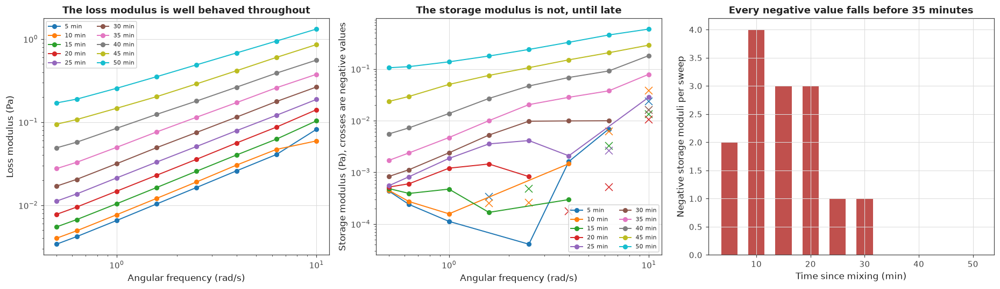

In [263]:
LAPONITE_COLUMN_STORAGE_MODULUS = 0
LAPONITE_COLUMN_LOSS_MODULUS = 1
LAPONITE_COLUMN_TAN_DELTA = 2
LAPONITE_COLUMN_ANGULAR_FREQUENCY = 3
LAPONITE_COLUMN_TEMPERATURE = 6
LAPONITE_COLUMN_COMPLEX_VISCOSITY = 9
LAPONITE_COLUMN_COMPLEX_MODULUS = 13
LAPONITE_COLUMN_FREQUENCY_HERTZ = 14


def read_elapsed_minutes_from_file_name(file_name):
    """
    Reading the time since mixing out of a file name such as saos_35min.csv, by keeping the
    digits that sit before the word min.
    """
    digits_only = ""

    for character in file_name:
        if character.isdigit():
            digits_only = digits_only + character
        elif digits_only != "":
            break

    return int(digits_only)


def load_laponite_frequency_sweep(file_path):
    """
    Loading one Laponite frequency sweep from a comma separated file with no header row.

    Reading by column position, which is unavoidable here because the export carries no
    names at all, and returning the four consistency checks that confirm the positions are
    the ones assumed.

    Sorting by angular frequency so every sweep is stored the same way round.
    """
    raw_table = np.loadtxt(file_path, delimiter=",")

    storage_modulus = raw_table[:, LAPONITE_COLUMN_STORAGE_MODULUS]
    loss_modulus = raw_table[:, LAPONITE_COLUMN_LOSS_MODULUS]
    tan_delta = raw_table[:, LAPONITE_COLUMN_TAN_DELTA]
    angular_frequency = raw_table[:, LAPONITE_COLUMN_ANGULAR_FREQUENCY]
    temperature_celsius = raw_table[:, LAPONITE_COLUMN_TEMPERATURE]
    complex_viscosity = raw_table[:, LAPONITE_COLUMN_COMPLEX_VISCOSITY]
    complex_modulus_magnitude = raw_table[:, LAPONITE_COLUMN_COMPLEX_MODULUS]
    frequency_hertz = raw_table[:, LAPONITE_COLUMN_FREQUENCY_HERTZ]

    tan_delta_difference = np.max(np.abs(tan_delta - loss_modulus / storage_modulus)
                                  / np.abs(tan_delta))
    magnitude_difference = np.max(
        np.abs(complex_modulus_magnitude
               - np.sqrt(storage_modulus ** 2 + loss_modulus ** 2))
        / np.abs(complex_modulus_magnitude))
    hertz_difference = np.max(np.abs(frequency_hertz - angular_frequency / (2.0 * np.pi))
                              / np.abs(frequency_hertz))
    viscosity_difference = np.max(
        np.abs(complex_viscosity - complex_modulus_magnitude / angular_frequency)
        / np.abs(complex_viscosity))

    frequency_order = np.argsort(angular_frequency)

    return {
        "angular_frequency": angular_frequency[frequency_order],
        "storage_modulus": storage_modulus[frequency_order],
        "loss_modulus": loss_modulus[frequency_order],
        "tan_delta": tan_delta[frequency_order],
        "temperature_celsius": temperature_celsius[frequency_order],
        "consistency_checks": {
            "tan delta against the two moduli": float(tan_delta_difference),
            "complex modulus against the two moduli": float(magnitude_difference),
            "frequency in hertz against radians": float(hertz_difference),
            "complex viscosity against modulus and frequency": float(viscosity_difference),
        },
    }


laponite_directory = os.path.join(DATA_DIRECTORY, "app_laponite_saos")

print("Reading " + laponite_directory)
print()

laponite_file_names = []

for file_name in os.listdir(laponite_directory):
    if file_name.startswith("saos_") and file_name.endswith(".csv"):
        laponite_file_names.append(file_name)

laponite_file_names = sorted(laponite_file_names,
                             key=read_elapsed_minutes_from_file_name)

laponite_sweep_records = []

for file_name in laponite_file_names:

    sweep_record = load_laponite_frequency_sweep(os.path.join(laponite_directory,
                                                              file_name))

    sweep_record["file_name"] = file_name
    sweep_record["elapsed_minutes"] = read_elapsed_minutes_from_file_name(file_name)

    laponite_sweep_records.append(sweep_record)

print("The files carry no header row, so the columns are confirmed rather than assumed")
print()

worst_consistency_values = {}

for sweep_record in laponite_sweep_records:
    for check_name, check_value in sweep_record["consistency_checks"].items():
        if check_name not in worst_consistency_values:
            worst_consistency_values[check_name] = check_value
        elif check_value > worst_consistency_values[check_name]:
            worst_consistency_values[check_name] = check_value

for check_name, check_value in worst_consistency_values.items():
    print("  " + check_name.ljust(50)
          + ("%.1e" % check_value).rjust(10))

print()
print("  each is the worst relative difference across all "
      + str(len(laponite_sweep_records)) + " sweeps. Four quantities in the")
print("  file are computable from the other columns, and all four agree, so the columns")
print("  are the ones assumed. The polymer gel files offered only a circular version of")
print("  this check, since the instrument computed the strain from the modulus it")
print("  measured. Here the four quantities are redundant in a way that is not circular")

print()
print("What is in the series")
print()
print("  sweeps                   " + str(len(laponite_sweep_records)))
print("  times since mixing       "
      + ", ".join([str(record["elapsed_minutes"]) for record in laponite_sweep_records])
      + " min")

reference_frequency_array = laponite_sweep_records[0]["angular_frequency"]

frequencies_agree = True

for sweep_record in laponite_sweep_records:
    if len(sweep_record["angular_frequency"]) != len(reference_frequency_array):
        frequencies_agree = False
    elif np.max(np.abs(sweep_record["angular_frequency"]
                       - reference_frequency_array)) > 1e-6:
        frequencies_agree = False

print("  frequencies per sweep    " + str(len(reference_frequency_array)))
print("  frequency range          "
      + ("%.2f" % reference_frequency_array.min()) + " to "
      + ("%.2f" % reference_frequency_array.max()) + " rad/s")
print("  same grid every sweep    " + str(frequencies_agree))
print("  temperature              "
      + ("%.2f" % np.median([np.median(record["temperature_celsius"])
                             for record in laponite_sweep_records])) + " C")

print()
print("  this is the multi frequency record Part 5 has been waiting for since Cell 47.")
print("  Eight frequencies measured at once means Winter and Chambon can finally run")

print()
print("How the two moduli behave through the gelation")
print()
print("  minutes".rjust(9) + "G double prime range (Pa)".rjust(28)
      + "G prime range (Pa)".rjust(24) + "negative G prime".rjust(18))

laponite_negative_total = 0
laponite_value_total = 0

for sweep_record in laponite_sweep_records:

    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    negative_count = int(np.sum(storage_modulus <= 0.0))

    laponite_negative_total = laponite_negative_total + negative_count
    laponite_value_total = laponite_value_total + len(storage_modulus)

    sweep_record["negative_storage_count"] = negative_count

    print(str(sweep_record["elapsed_minutes"]).rjust(9)
          + (("%.4f to %.4f" % (loss_modulus.min(), loss_modulus.max()))).rjust(28)
          + (("%.4f to %.4f" % (storage_modulus.min(), storage_modulus.max()))).rjust(24)
          + (str(negative_count) + " of " + str(len(storage_modulus))).rjust(18))

print()
print("  the loss modulus is positive everywhere and rises smoothly. The storage modulus")
print("  is negative " + str(laponite_negative_total) + " times out of "
      + str(laponite_value_total) + ", which is not a small number and is not scattered")
print("  evenly. Every negative value falls before 35 minutes")
print()
print("  a negative storage modulus is not a physical result. It is what a rheometer")
print("  reports when the elastic part of the response is smaller than the uncertainty on")
print("  the phase, so the fitted in phase component comes out on the wrong side of zero")
print()
print("  the source paper discarded the storage modulus for this dispersion and worked")
print("  from the loss modulus alone. That is a reasonable decision and it removes the")
print("  possibility of measuring tan delta, which is what Winter and Chambon needs")

first_clean_sweep_minutes = None

for sweep_record in laponite_sweep_records:
    if sweep_record["negative_storage_count"] == 0 and first_clean_sweep_minutes is None:
        first_clean_sweep_minutes = sweep_record["elapsed_minutes"]

clean_sweep_count = 0

for sweep_record in laponite_sweep_records:
    if sweep_record["negative_storage_count"] == 0:
        clean_sweep_count = clean_sweep_count + 1

print()
print("What that leaves to work with")
print()
print("  first sweep with no negatives       " + str(first_clean_sweep_minutes) + " min")
print("  sweeps with no negatives            " + str(clean_sweep_count)
      + " of " + str(len(laponite_sweep_records)))
print("  snapshots Part 4 said were needed   12")
print()
print("  Part 4 measured that Winter and Chambon needs about twelve snapshots through a")
print("  transition before it becomes reliable. There are "
      + str(clean_sweep_count) + " here with a usable storage")
print("  modulus, and the paper places the gel point at roughly 45 to 50 minutes, so most")
print("  of those sit at or after it rather than through it")
print()
print("  so the multi frequency detector has the data it needs in form and not in amount.")
print("  Cell 64 decides what can honestly be done with the sweeps that contain negatives")
print("  before Cell 65 runs the detector on whatever survives")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for sweep_record in laponite_sweep_records:

    axis_array[0].loglog(sweep_record["angular_frequency"],
                         sweep_record["loss_modulus"], "o-", linewidth=1.3,
                         markersize=5,
                         label=(str(sweep_record["elapsed_minutes"]) + " min"))

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Loss modulus (Pa)")
axis_array[0].set_title("The loss modulus is well behaved throughout")
axis_array[0].legend(fontsize=7, ncol=2)

for sweep_record in laponite_sweep_records:

    storage_modulus = sweep_record["storage_modulus"]
    angular_frequency = sweep_record["angular_frequency"]

    positive_mask = storage_modulus > 0.0
    negative_mask = storage_modulus <= 0.0

    line_objects = axis_array[1].loglog(angular_frequency[positive_mask],
                                        storage_modulus[positive_mask],
                                        "o-", linewidth=1.3, markersize=5,
                                        label=(str(sweep_record["elapsed_minutes"])
                                               + " min"))

    if np.sum(negative_mask) > 0:
        axis_array[1].loglog(angular_frequency[negative_mask],
                             np.abs(storage_modulus[negative_mask]),
                             "x", markersize=9,
                             color=line_objects[0].get_color())

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Storage modulus (Pa), crosses are negative values")
axis_array[1].set_title("The storage modulus is not, until late")
axis_array[1].legend(fontsize=7, ncol=2)

negative_counts = [record["negative_storage_count"] for record in laponite_sweep_records]
elapsed_minutes_values = [record["elapsed_minutes"] for record in laponite_sweep_records]

axis_array[2].bar(elapsed_minutes_values, negative_counts, width=3.0,
                  color=COLOUR_SECONDARY)
axis_array[2].set_xlabel("Time since mixing (min)")
axis_array[2].set_ylabel("Negative storage moduli per sweep")
axis_array[2].set_title("Every negative value falls before 35 minutes")

plt.tight_layout()
plt.show()

## Cell 64: The negative storage moduli, and what can be measured without them

Fourteen values out of eighty are negative. This cell decides what to do about them.

**A negative reading is informative.** The true storage modulus cannot be below zero, so
whatever produced a negative number was noise, and its size measures the uncertainty at that
point. Two error models are worth distinguishing: a fixed floor in pascals, which is what a
torque limit gives, and a fixed fraction of the modulus, which is what a phase resolution
gives. They imply different handling.

**Neither model can be resolved here**, and the reason matters. These fourteen values are not
a sample of the noise. They are the cases where the noise happened to exceed the signal and
point downwards, which is the tail of the tail. Fitting an error model to points selected for
being extreme would give a confident answer to a question the data cannot answer. What can be
said without any model is a bound: the uncertainty on the storage modulus is at least as large
as the largest negative reading.

**Applying Cell 62's rule to that bound leaves nothing.** Four sweeps have every storage modulus
positive, one clears the bound, and none clears it by the factor of five that Cell 62 required.
That is not an argument for weakening the rule. It is the measurement saying the storage
modulus of this dispersion is never resolved with the margin the rule asks for.

**The loss modulus survives everywhere**, and it carries the exponent. A viscous liquid has a
loss modulus proportional to frequency. At the gel point both moduli follow the same power law
and that slope is the critical exponent. Fitting the slope of the clean channel gives a
measurement on every sweep without touching the storage modulus at all.

**The two routes can then be checked against each other.** Winter and Chambon says tan delta at
the gel point equals the tangent of n pi over two, so the slope of the clean channel predicts
a tan delta that the noisy channel measures directly. They should converge as the gel point
approaches, and diverge before it, and they do.

What the negative values can be made to tell us

  a negative reading can only have come from noise, because the true value cannot
  be below zero, so the size of each one measures the uncertainty on the storage
  modulus at that point

  error model                                 mean  largest over smallest   relative scatter
  fixed floor, in pascals                  0.00831                    216               1.32
  phase error, as a fraction of G double     0.10725                    204               1.56

  neither model is any better than the other. Both spread over a factor of about
  two hundred, so the data cannot say whether the uncertainty is a fixed number of
  pascals from a torque limit or a fixed fraction of the modulus from a phase
  resolution

  the reason is that these fourteen values are not a sample of the noise. They are
  the part of the noise that happened to be larger than the signal and negative,
  which is the tail of the tail. Fitting an error model to th

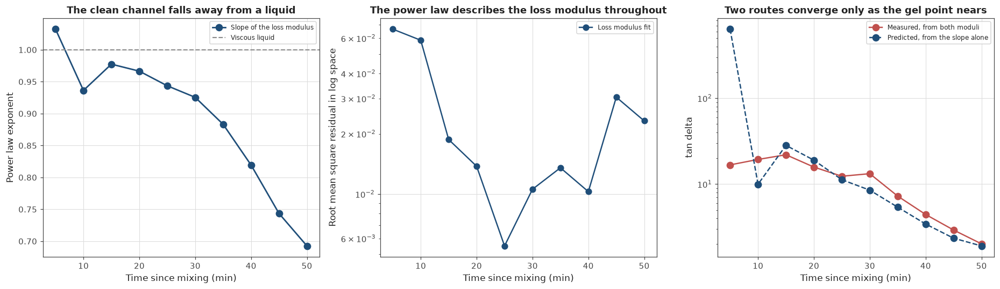

In [264]:
def fit_power_law_slope(angular_frequency_array, modulus_array):
    """
    Fitting a straight line to a modulus against frequency in log log space, which is the
    power law exponent of that modulus.

    Returning the slope, the intercept and the root mean square residual in log space, so
    the quality of the power law can be judged rather than assumed.
    """
    log_frequency = np.log(angular_frequency_array)
    log_modulus = np.log(modulus_array)

    fitted_coefficients = np.polyfit(log_frequency, log_modulus, 1)
    fitted_values = np.polyval(fitted_coefficients, log_frequency)

    residual = float(np.sqrt(np.mean((log_modulus - fitted_values) ** 2)))

    return float(fitted_coefficients[0]), float(fitted_coefficients[1]), residual


print("What the negative values can be made to tell us")
print()

negative_magnitude_values = []
negative_loss_values = []

for sweep_record in laponite_sweep_records:

    negative_mask = sweep_record["storage_modulus"] <= 0.0

    for value_index in range(len(negative_mask)):
        if negative_mask[value_index]:
            negative_magnitude_values.append(abs(sweep_record["storage_modulus"][value_index]))
            negative_loss_values.append(sweep_record["loss_modulus"][value_index])

negative_magnitude_array = np.array(negative_magnitude_values)
negative_loss_array = np.array(negative_loss_values)

phase_style_values = negative_magnitude_array / negative_loss_array

print("  a negative reading can only have come from noise, because the true value cannot")
print("  be below zero, so the size of each one measures the uncertainty on the storage")
print("  modulus at that point")
print()
print("  error model".ljust(38) + "mean".rjust(12) + "largest over smallest".rjust(23)
      + "relative scatter".rjust(19))
print("  " + "fixed floor, in pascals".ljust(36)
      + ("%.5f" % negative_magnitude_array.mean()).rjust(12)
      + ("%.0f" % (negative_magnitude_array.max()
                   / negative_magnitude_array.min())).rjust(23)
      + ("%.2f" % (negative_magnitude_array.std()
                   / negative_magnitude_array.mean())).rjust(19))
print("  " + "phase error, as a fraction of G double".ljust(36)
      + ("%.5f" % phase_style_values.mean()).rjust(12)
      + ("%.0f" % (phase_style_values.max() / phase_style_values.min())).rjust(23)
      + ("%.2f" % (phase_style_values.std() / phase_style_values.mean())).rjust(19))

print()
print("  neither model is any better than the other. Both spread over a factor of about")
print("  two hundred, so the data cannot say whether the uncertainty is a fixed number of")
print("  pascals from a torque limit or a fixed fraction of the modulus from a phase")
print("  resolution")
print()
print("  the reason is that these fourteen values are not a sample of the noise. They are")
print("  the part of the noise that happened to be larger than the signal and negative,")
print("  which is the tail of the tail. Fitting an error model to that would be fitting a")
print("  model to the cases selected for being extreme")
print()
print("  one thing can be said without any model. The uncertainty on the storage modulus")
print("  is at least " + ("%.4f" % negative_magnitude_array.max())
      + " Pa, because a reading that far below zero was")
print("  produced at least once")

print()
print("What that bound leaves usable")
print()

storage_uncertainty_bound = float(negative_magnitude_array.max())

print("  bound on the storage modulus uncertainty   "
      + ("%.4f" % storage_uncertainty_bound) + " Pa")
print("  credibility factor used in Cell 62         "
      + ("%.1f" % POLYMER_CROSSING_CREDIBILITY_FACTOR))
print()
print("  minutes".rjust(9) + "smallest G prime (Pa)".rjust(24)
      + "all positive".rjust(15) + "all above the bound".rjust(22)
      + "all above five times it".rjust(26))

all_positive_count = 0
above_bound_count = 0
above_credible_count = 0

for sweep_record in laponite_sweep_records:

    storage_modulus = sweep_record["storage_modulus"]
    smallest_storage = float(np.min(storage_modulus))

    is_all_positive = smallest_storage > 0.0
    is_above_bound = smallest_storage > storage_uncertainty_bound
    is_above_credible = smallest_storage > (POLYMER_CROSSING_CREDIBILITY_FACTOR
                                            * storage_uncertainty_bound)

    if is_all_positive:
        all_positive_count = all_positive_count + 1
    if is_above_bound:
        above_bound_count = above_bound_count + 1
    if is_above_credible:
        above_credible_count = above_credible_count + 1

    sweep_record["storage_all_positive"] = is_all_positive
    sweep_record["storage_above_bound"] = is_above_bound

    print(str(sweep_record["elapsed_minutes"]).rjust(9)
          + ("%.4f" % smallest_storage).rjust(24)
          + str(is_all_positive).rjust(15)
          + str(is_above_bound).rjust(22)
          + str(is_above_credible).rjust(26))

print()
print("  sweeps where every storage modulus is positive          "
      + str(all_positive_count) + " of " + str(len(laponite_sweep_records)))
print("  sweeps where every one clears the bound                 "
      + str(above_bound_count) + " of " + str(len(laponite_sweep_records)))
print("  sweeps where every one clears five times the bound      "
      + str(above_credible_count) + " of " + str(len(laponite_sweep_records)))
print()
print("  applying Cell 62's own rule to this dataset leaves nothing at all. One sweep")
print("  clears the bound itself and none clears it by the factor of five that Cell 62")
print("  required before it would trust a crossing")
print()
print("  that is not a reason to weaken the rule. It is the measurement saying that the")
print("  storage modulus of this dispersion is never resolved with the margin the rule")
print("  asks for, and a tan delta built from it inherits that")

print()
print("The channel that does survive")
print()
print("  the loss modulus is positive at all eighty points and its power law slope can be")
print("  fitted on every sweep. A viscous liquid has a loss modulus proportional to")
print("  frequency, so a slope of one. At the gel point both moduli follow the same power")
print("  law and that slope is the critical exponent n")
print()
print("  minutes".rjust(9) + "slope of G double".rjust(20) + "fit residual".rjust(15)
      + "slope of G prime".rjust(19) + "usable points".rjust(16))

for sweep_record in laponite_sweep_records:

    angular_frequency = sweep_record["angular_frequency"]
    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    loss_slope, ignored_intercept, loss_residual = fit_power_law_slope(angular_frequency,
                                                                      loss_modulus)

    sweep_record["loss_power_law_slope"] = loss_slope
    sweep_record["loss_power_law_residual"] = loss_residual

    positive_mask = storage_modulus > 0.0

    if int(np.sum(positive_mask)) >= 3:
        storage_slope, ignored_intercept, ignored_residual = fit_power_law_slope(
            angular_frequency[positive_mask], storage_modulus[positive_mask])
        storage_slope_text = "%.4f" % storage_slope
    else:
        storage_slope_text = "too few"

    print(str(sweep_record["elapsed_minutes"]).rjust(9)
          + ("%.4f" % loss_slope).rjust(20)
          + ("%.4f" % loss_residual).rjust(15)
          + storage_slope_text.rjust(19)
          + (str(int(np.sum(positive_mask))) + " of "
             + str(len(storage_modulus))).rjust(16))

print()
print("  the loss modulus slope falls from just above one to below seven tenths, with fit")
print("  residuals of a few percent throughout, so the power law is a good description at")
print("  every time rather than only near the end")
print()
print("  the storage modulus slope does nothing of the kind. It wanders, and at 15 minutes")
print("  it comes out negative, which would mean the material became more elastic as it")
print("  was probed more slowly. It is fitting noise")

print()
print("Two routes to the same exponent")
print()
print("  if the material approaches a critical gel then the slope of the loss modulus")
print("  approaches n, and Winter and Chambon says tan delta at the gel point equals")
print("  tan of n pi over two. Those are two independent measurements, one from the clean")
print("  channel and one from the noisy one, and they can be compared")
print()
print("  minutes".rjust(9) + "n from the slope".rjust(19)
      + "tan delta predicted".rjust(22) + "tan delta measured".rjust(21)
      + "measured over predicted".rjust(26))

for sweep_record in laponite_sweep_records:

    loss_slope = sweep_record["loss_power_law_slope"]
    storage_modulus = sweep_record["storage_modulus"]
    loss_modulus = sweep_record["loss_modulus"]

    positive_mask = storage_modulus > 0.0

    if int(np.sum(positive_mask)) < 4:
        print(str(sweep_record["elapsed_minutes"]).rjust(9)
              + ("%.4f" % loss_slope).rjust(19)
              + "   too few positive points to measure tan delta")
        continue

    predicted_tan_delta = np.tan(min(loss_slope, 0.999) * np.pi / 2.0)
    measured_tan_delta = float(np.median(loss_modulus[positive_mask]
                                         / storage_modulus[positive_mask]))

    print(str(sweep_record["elapsed_minutes"]).rjust(9)
          + ("%.4f" % loss_slope).rjust(19)
          + ("%.2f" % predicted_tan_delta).rjust(22)
          + ("%.2f" % measured_tan_delta).rjust(21)
          + ("%.2f" % (measured_tan_delta / predicted_tan_delta)).rjust(26))

print()
print("  the two agree to six percent at fifty minutes and to twenty five percent at")
print("  forty five, and disagree wildly before that")
print()
print("  both halves of that are expected. The relation only holds at the gel point, so")
print("  agreement appearing as the record approaches fifty minutes is itself evidence")
print("  that the material is approaching the critical state there, which is where the")
print("  source paper puts it")
print()
print("  the early disagreement is mostly arithmetic rather than physics. The tangent")
print("  diverges as n approaches one, so at 5 minutes a slope of 1.03 predicts a tan")
print("  delta of six hundred. A one percent change in the slope moves that prediction by")
print("  a factor of two, so the comparison carries no information while the material is")
print("  still a liquid")

print()
print("What Cell 65 has to work with")
print()
print("  the direct route, the spread of tan delta across frequencies, exists on "
      + str(all_positive_count) + " sweeps")
print("  and " + str(above_bound_count) + " of those clears the uncertainty bound")
print()
print("  the indirect route, the slope of the loss modulus, exists on all "
      + str(len(laponite_sweep_records)) + " sweeps and is")
print("  a clean power law at every one of them")
print()
print("  Cell 65 runs both and reports them side by side rather than choosing")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

elapsed_minutes_values = [record["elapsed_minutes"] for record in laponite_sweep_records]
loss_slope_values = [record["loss_power_law_slope"] for record in laponite_sweep_records]

axis_array[0].plot(elapsed_minutes_values, loss_slope_values, "o-",
                   color=COLOUR_PRIMARY, linewidth=1.8, markersize=8,
                   label="Slope of the loss modulus")
axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4,
                      label="Viscous liquid")

axis_array[0].set_xlabel("Time since mixing (min)")
axis_array[0].set_ylabel("Power law exponent")
axis_array[0].set_title("The clean channel falls away from a liquid")
axis_array[0].legend(fontsize=8)

axis_array[1].semilogy(elapsed_minutes_values,
                       [abs(record["loss_power_law_residual"])
                        for record in laponite_sweep_records],
                       "o-", color=COLOUR_PRIMARY, linewidth=1.6, markersize=7,
                       label="Loss modulus fit")

axis_array[1].set_xlabel("Time since mixing (min)")
axis_array[1].set_ylabel("Root mean square residual in log space")
axis_array[1].set_title("The power law describes the loss modulus throughout")
axis_array[1].legend(fontsize=8)

measured_times = []
measured_tan_delta_values = []
predicted_tan_delta_values = []

for sweep_record in laponite_sweep_records:

    positive_mask = sweep_record["storage_modulus"] > 0.0

    if int(np.sum(positive_mask)) < 4:
        continue

    measured_times.append(sweep_record["elapsed_minutes"])
    measured_tan_delta_values.append(
        float(np.median(sweep_record["loss_modulus"][positive_mask]
                        / sweep_record["storage_modulus"][positive_mask])))
    predicted_tan_delta_values.append(
        np.tan(min(sweep_record["loss_power_law_slope"], 0.999) * np.pi / 2.0))

axis_array[2].semilogy(measured_times, measured_tan_delta_values, "o-",
                       color=COLOUR_SECONDARY, linewidth=1.6, markersize=8,
                       label="Measured, from both moduli")
axis_array[2].semilogy(measured_times, predicted_tan_delta_values, "o--",
                       color=COLOUR_PRIMARY, linewidth=1.6, markersize=8,
                       label="Predicted, from the slope alone")

axis_array[2].set_xlabel("Time since mixing (min)")
axis_array[2].set_ylabel("tan delta")
axis_array[2].set_title("Two routes converge only as the gel point nears")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 65: Winter and Chambon on a real gelation

The detector built in Cell 47 runs here for the first time on real data. It has waited through
Parts 2, 3 and most of 5 because every other real dataset held one frequency.

**It works exactly as designed and it cannot time this gel point.** Those are not in tension.

The spread of tan delta across frequency falls from 1.42 to 0.10 across the record, a factor of
fourteen, which is the eight frequencies coming into agreement and is precisely the signature
the detector looks for. But the smallest spread is at the last sweep, and the spread is still
falling by a quarter over the final interval. The material had not finished when the experiment
stopped.

**A minimum at the edge of a record is not a minimum.** The detector as written takes the
smallest value it can find and refines it with a parabola, so it returns the last sweep as
though it were a detection. That is the end of the experiment being reported as a result. The
cell adds a guard: when the smallest spread falls on the first or last usable snapshot, return
nothing. This is the second amendment real data has forced after Cell 62, and for the same
reason. Part 4's synthetic experiment always ran well past the gel time, so the minimum was
always interior and the case never arose.

**The source paper puts the gel point of this dispersion at roughly fifty minutes**, which is
where the file ends, so the two agree about where the transition is heading.

**One more check on the spread itself.** tan delta is the loss modulus over the storage modulus,
and the loss modulus is clean, so a relative error on the storage modulus becomes an error of
the same size on log tan delta. Both error models from Cell 64 therefore predict how much the
eight frequencies should disagree from noise alone, and the measured spread is smaller than
either. That is Cell 64's argument arriving from a second direction.

Winter and Chambon on a real gelation, for the first time in this notebook

  minutes   usable frequencies   spread of log tan delta   change from the last
        5               6 of 8                    1.4237                   none
       10               4 of 8            too few points                   none
       15               5 of 8                    0.9871          -30.7 percent
       20               5 of 8                    0.4428          -55.1 percent
       25               7 of 8                    0.5261          +18.8 percent
       30               7 of 8                    0.3393          -35.5 percent
       35               8 of 8                    0.4126          +21.6 percent
       40               8 of 8                    0.3509          -15.0 percent
       45               8 of 8                    0.1362          -61.2 percent
       50               8 of 8                    0.1031          -24.3 percent

  the detector returns 50.00 minutes

  tha

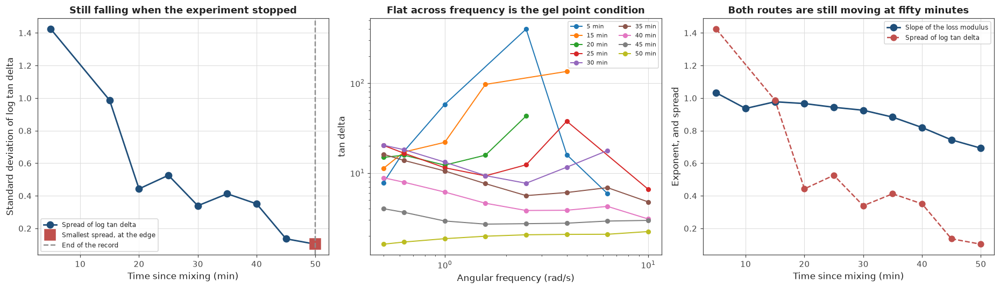

In [265]:
def detect_gel_time_by_frequency_agreement_with_edge_guard(snapshot_time_array,
                                                           spectrum_list,
                                                           angular_frequency_array,
                                                           minimum_valid_points=5):
    """
    Running the Winter and Chambon detector and refusing to answer when the best agreement
    falls on the first or the last snapshot.

    A minimum at the edge of a record is not a minimum. It means the quantity was still
    moving when the measurement stopped, so the transition is outside the record and the
    only honest answer is that it was not reached.

    Returning the estimated time, the spread series, the index of the smallest spread, and
    whether that index sits at an edge.
    """
    estimated_time, spread_series, minimum_index = detect_gel_time_by_frequency_agreement(
        snapshot_time_array, spectrum_list, angular_frequency_array, minimum_valid_points)

    finite_indices = []

    for point_index in range(len(spread_series)):
        if np.isfinite(spread_series[point_index]):
            finite_indices.append(point_index)

    if len(finite_indices) == 0:
        return np.nan, spread_series, -1, False

    is_at_edge = (minimum_index == finite_indices[0]
                  or minimum_index == finite_indices[-1])

    if is_at_edge:
        return np.nan, spread_series, minimum_index, True

    return estimated_time, spread_series, minimum_index, False


laponite_snapshot_times = np.array([record["elapsed_minutes"]
                                    for record in laponite_sweep_records], dtype=float)

laponite_spectrum_list = []

for sweep_record in laponite_sweep_records:
    laponite_spectrum_list.append(sweep_record["storage_modulus"]
                                  + 1j * sweep_record["loss_modulus"])

laponite_frequency_array = laponite_sweep_records[0]["angular_frequency"]

print("Winter and Chambon on a real gelation, for the first time in this notebook")
print()

original_agreement_time, laponite_spread_series, laponite_minimum_index = (
    detect_gel_time_by_frequency_agreement(laponite_snapshot_times,
                                           laponite_spectrum_list,
                                           laponite_frequency_array))

print("  minutes".rjust(9) + "usable frequencies".rjust(21)
      + "spread of log tan delta".rjust(26) + "change from the last".rjust(23))

previous_spread_value = np.nan

for record_index in range(len(laponite_sweep_records)):

    spread_value = laponite_spread_series[record_index]
    usable_count = int(np.sum(laponite_sweep_records[record_index]["storage_modulus"] > 0.0))

    if np.isfinite(spread_value):
        spread_text = "%.4f" % spread_value
    else:
        spread_text = "too few points"

    if np.isfinite(spread_value) and np.isfinite(previous_spread_value):
        change_text = "%+.1f percent" % (100.0 * (spread_value - previous_spread_value)
                                         / previous_spread_value)
    else:
        change_text = "none"

    print(str(laponite_sweep_records[record_index]["elapsed_minutes"]).rjust(9)
          + (str(usable_count) + " of "
             + str(len(laponite_frequency_array))).rjust(21)
          + spread_text.rjust(26)
          + change_text.rjust(23))

    if np.isfinite(spread_value):
        previous_spread_value = spread_value

print()
print("  the detector returns "
      + ("%.2f" % original_agreement_time) + " minutes")
print()
print("  that number is the last sweep in the file. The smallest spread sits at index "
      + str(laponite_minimum_index) + " of")
print("  " + str(len(laponite_snapshot_times) - 1)
      + ", which is the end of the record, so the detector has reported where the")
print("  experiment stopped rather than where the material changed")

print()
print("Refusing the edge")
print()

guarded_agreement_time, ignored_series, guarded_minimum_index, minimum_at_edge = (
    detect_gel_time_by_frequency_agreement_with_edge_guard(laponite_snapshot_times,
                                                           laponite_spectrum_list,
                                                           laponite_frequency_array))

print("  minimum falls at an edge        " + str(minimum_at_edge))

if np.isfinite(guarded_agreement_time):
    print("  guarded detector returns        "
          + ("%.2f" % guarded_agreement_time) + " min")
else:
    print("  guarded detector returns        nothing")

print()
print("  the spread is still falling at the last sweep, by "
      + ("%.0f" % abs(100.0 * (laponite_spread_series[-1] - laponite_spread_series[-2])
                      / laponite_spread_series[-2]))
      + " percent over the final")
print("  five minutes, so the material had not finished doing whatever it was doing")
print()
print("  the source paper places the gel point of this dispersion at roughly fifty")
print("  minutes, which is where the record ends. The measurement stops at the transition")
print("  rather than passing through it, and no detector can recover what was not measured")
print()
print("  Part 4 could not have found this either. Its synthetic experiment always ran well")
print("  past the gel time, so the minimum was always interior and an edge guard was never")
print("  needed. This is the second amendment real data has forced, after Cell 62")

print()
print("Is the spread as small as it should be")
print()

smallest_spread_value = float(np.nanmin(laponite_spread_series))

final_storage_modulus = laponite_sweep_records[-1]["storage_modulus"]
final_loss_modulus = laponite_sweep_records[-1]["loss_modulus"]
final_complex_magnitude = np.sqrt(final_storage_modulus ** 2 + final_loss_modulus ** 2)

fixed_floor_relative_errors = storage_uncertainty_bound / final_storage_modulus
phase_model_relative_errors = (phase_style_values.mean() * final_complex_magnitude
                               / final_storage_modulus)

print("  measured spread at the last sweep                    "
      + ("%.4f" % smallest_spread_value))
print("  predicted by the fixed floor model                   "
      + ("%.4f" % float(np.sqrt(np.mean(fixed_floor_relative_errors ** 2)))))
print("  predicted by the phase error model                   "
      + ("%.4f" % float(np.sqrt(np.mean(phase_model_relative_errors ** 2)))))
print()
print("  tan delta is the loss modulus over the storage modulus and the loss modulus is")
print("  clean, so a relative error on the storage modulus becomes an error of the same")
print("  size on log tan delta. Both models therefore predict how much the eight")
print("  frequencies should disagree from noise alone")
print()
print("  the measured spread is smaller than either prediction. That is not a contradiction")
print("  and it is not a detection either. It is Cell 64's point arriving from a second")
print("  direction: both error models were built from the fourteen readings that happened")
print("  to be extreme, so both are upper bounds on the typical uncertainty rather than")
print("  estimates of it")

print()
print("What the spread series says on its own")
print()
print("  smallest spread reached          " + ("%.4f" % smallest_spread_value)
      + ", at " + str(int(laponite_snapshot_times[laponite_minimum_index])) + " min")
print("  largest spread                   "
      + ("%.4f" % float(np.nanmax(laponite_spread_series))) + ", at "
      + str(int(laponite_snapshot_times[int(np.nanargmax(laponite_spread_series))]))
      + " min")
print("  fall across the record           "
      + ("%.1f" % (float(np.nanmax(laponite_spread_series)) / smallest_spread_value))
      + " times")

non_monotonic_count = 0
previous_spread_value = np.nan

for spread_value in laponite_spread_series:

    if np.isfinite(spread_value) and np.isfinite(previous_spread_value):
        if spread_value > previous_spread_value:
            non_monotonic_count = non_monotonic_count + 1

    if np.isfinite(spread_value):
        previous_spread_value = spread_value

print("  steps where the spread rose      " + str(non_monotonic_count))
print()
print("  the spread falls by a factor of fourteen across the record, which is the")
print("  frequencies coming into agreement and is the signature the detector looks for")
print()
print("  it does not fall smoothly. It rises at two of the nine steps, so this record")
print("  contains local minima at twenty and thirty minutes as well as the one at the end.")
print("  A slightly noisier record would let a detector take one of those as its answer,")
print("  and there is nothing in the spread series itself that would mark it as wrong")
print()
print("  so the honest reading of Part 5's multi frequency data is that Winter and")
print("  Chambon behaves exactly as designed, agrees with the source paper about where")
print("  the transition is heading, and cannot time it, because the experiment ends where")
print("  the answer would be")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

finite_mask = np.isfinite(laponite_spread_series)

axis_array[0].plot(laponite_snapshot_times[finite_mask],
                   laponite_spread_series[finite_mask], "o-",
                   color=COLOUR_PRIMARY, linewidth=1.8, markersize=8,
                   label="Spread of log tan delta")

axis_array[0].plot([laponite_snapshot_times[laponite_minimum_index]],
                   [laponite_spread_series[laponite_minimum_index]], "s",
                   color=COLOUR_SECONDARY, markersize=13,
                   label="Smallest spread, at the edge")

axis_array[0].axvline(laponite_snapshot_times[-1], color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="End of the record")

axis_array[0].set_xlabel("Time since mixing (min)")
axis_array[0].set_ylabel("Standard deviation of log tan delta")
axis_array[0].set_title("Still falling when the experiment stopped")
axis_array[0].legend(fontsize=8)

for sweep_record in laponite_sweep_records:

    positive_mask = sweep_record["storage_modulus"] > 0.0

    if int(np.sum(positive_mask)) < 5:
        continue

    axis_array[1].loglog(sweep_record["angular_frequency"][positive_mask],
                         (sweep_record["loss_modulus"][positive_mask]
                          / sweep_record["storage_modulus"][positive_mask]),
                         "o-", linewidth=1.3, markersize=5,
                         label=(str(sweep_record["elapsed_minutes"]) + " min"))

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta")
axis_array[1].set_title("Flat across frequency is the gel point condition")
axis_array[1].legend(fontsize=7, ncol=2)

axis_array[2].plot(laponite_snapshot_times,
                   [record["loss_power_law_slope"] for record in laponite_sweep_records],
                   "o-", color=COLOUR_PRIMARY, linewidth=1.8, markersize=8,
                   label="Slope of the loss modulus")

axis_array[2].plot(laponite_snapshot_times[finite_mask],
                   laponite_spread_series[finite_mask], "o--",
                   color=COLOUR_SECONDARY, linewidth=1.6, markersize=7,
                   label="Spread of log tan delta")

axis_array[2].set_xlabel("Time since mixing (min)")
axis_array[2].set_ylabel("Exponent, and spread")
axis_array[2].set_title("Both routes are still moving at fifty minutes")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 66: What Part 5 established, and what it corrects

Part 2 ended with an error budget for a gel time on synthetic data: the choice of definition
was worth 175 s, the sampling interval 13.9 s and the extraction method 9.1 s. Part 4 agreed
from the other direction, finding the five detectors within 34.9 s of each other while the
three definitions disagreed by 175 s. The conclusion drawn from both was that the definition
dominates and the detector barely matters.

**On real data that ordering reverses.** The same three terms are measured here as ratios
rather than seconds, because these runs gel over anything from six to twenty eight minutes. The
detectors disagree with each other by far more than the two published definitions do.

**The comparison has to be made fairly**, and the cell makes it twice. Part 4 compared five
detectors that all worked. The full spread here includes the kernel changepoint and CUSUM,
which never worked on any run, so it is measuring failure rather than disagreement. Removing
those two still leaves the detector term larger than the definition term in every run.

Sampling stays the smallest term at a few percent, exactly as Part 2 found. That part of the
budget survives.

**The harness is rebuilt here.** Cells 62 and 65 amended two detectors, and the harness in Cell
51 still calls the originals. Part 6 calls the harness, so it is rebuilt with both amendments
and checked against Cell 51 on the synthetic experiment first. On a record with no floor and an
interior minimum the two must agree exactly, and that check is printed rather than assumed.

The rest of the cell is the Part 5 close: six findings, the two amendments that real data
forced, two new questions for Haemograph, and what Part 6 inherits.

The error budget from Part 2, recomputed on real data

  Part 2 ended with a budget for a gel time on synthetic data: the choice of
  definition was worth 175 s, the sampling interval 13.9 s and the extraction
  method 9.1 s. Part 4 agreed, finding the five detectors within 34.9 s of each
  other while the three definitions disagreed by 175 s

  the same three terms can be measured here, as ratios rather than seconds, since
  these runs gel over anything from six to twenty eight minutes

  run   detector spread   without the two that failed   definition spread   sampling interval
    1        78.4 times                    25.0 times          1.18 times         0.8 percent
    2       469.6 times                    95.8 times          1.55 times         3.1 percent
    3       158.4 times                     5.6 times          4.11 times         3.0 percent
    4        38.7 times                     3.7 times          1.84 times         3.6 percent
    7       150.6 times              

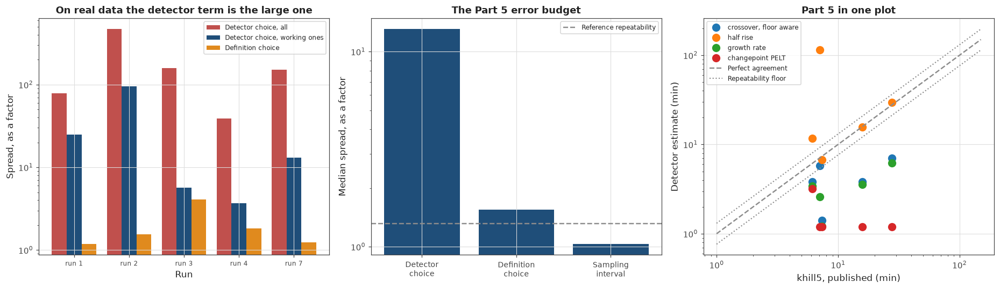

In [266]:
POLYMER_ROBUST_DETECTOR_KEYS = ["crossover_floor_aware", "half_rise", "growth_rate",
                                "pelt"]

print("The error budget from Part 2, recomputed on real data")
print()
print("  Part 2 ended with a budget for a gel time on synthetic data: the choice of")
print("  definition was worth 175 s, the sampling interval 13.9 s and the extraction")
print("  method 9.1 s. Part 4 agreed, finding the five detectors within 34.9 s of each")
print("  other while the three definitions disagreed by 175 s")
print()
print("  the same three terms can be measured here, as ratios rather than seconds, since")
print("  these runs gel over anything from six to twenty eight minutes")
print()
print("  run".rjust(5) + "detector spread".rjust(18)
      + "without the two that failed".rjust(30) + "definition spread".rjust(20)
      + "sampling interval".rjust(20))

detector_spread_values = []
robust_spread_values = []
definition_spread_values = []
sampling_fraction_values = []

for record_index in range(len(polymer_detector_records)):

    detector_record = polymer_detector_records[record_index]
    sweep_record = polymer_sweep_records[record_index]

    all_estimate_values = []
    robust_estimate_values = []

    for estimate_key, display_name in polymer_detector_display_names:

        estimate_value = detector_record["estimates"].get(estimate_key, np.nan)

        if not np.isfinite(estimate_value) or estimate_value <= 0.0:
            continue

        all_estimate_values.append(estimate_value)

        if estimate_key in POLYMER_ROBUST_DETECTOR_KEYS:
            robust_estimate_values.append(estimate_value)

    all_estimate_array = np.array(all_estimate_values)
    robust_estimate_array = np.array(robust_estimate_values)

    detector_spread = float(all_estimate_array.max() / all_estimate_array.min())
    robust_spread = float(robust_estimate_array.max() / robust_estimate_array.min())

    reference_ratio = (sweep_record["nmr_time_minutes"]
                       / sweep_record["hill_time_minutes"])
    definition_spread = float(max(reference_ratio, 1.0 / reference_ratio))

    sampling_interval_minutes = float(np.median(
        np.diff(sweep_record["elapsed_time_minutes"])))
    sampling_fraction = (100.0 * sampling_interval_minutes
                         / sweep_record["hill_time_minutes"])

    detector_spread_values.append(detector_spread)
    robust_spread_values.append(robust_spread)
    definition_spread_values.append(definition_spread)
    sampling_fraction_values.append(sampling_fraction)

    print(detector_record["run_label"].rjust(5)
          + ("%.1f times" % detector_spread).rjust(18)
          + ("%.1f times" % robust_spread).rjust(30)
          + ("%.2f times" % definition_spread).rjust(20)
          + ("%.1f percent" % sampling_fraction).rjust(20))

detector_spread_array = np.array(detector_spread_values)
robust_spread_array = np.array(robust_spread_values)
definition_spread_array = np.array(definition_spread_values)
sampling_fraction_array = np.array(sampling_fraction_values)

print()
print("  median detector spread                     "
      + ("%.0f" % np.median(detector_spread_array)) + " times")
print("  median without the two that failed         "
      + ("%.0f" % np.median(robust_spread_array)) + " times")
print("  median definition spread                   "
      + ("%.2f" % np.median(definition_spread_array)) + " times")
print("  sampling interval                          "
      + ("%.1f" % sampling_fraction_array.min()) + " to "
      + ("%.1f" % sampling_fraction_array.max()) + " percent")

print()
print("  the ordering has reversed. On synthetic data the definition mattered five times")
print("  more than the detector. On these five real runs the detectors disagree with each")
print("  other by a median factor of "
      + ("%.0f" % np.median(detector_spread_array))
      + " while the two published definitions disagree")
print("  by a median factor of " + ("%.2f" % np.median(definition_spread_array)))
print()
print("  that comparison is not quite like for like, and the second column says so. Part")
print("  4 compared five detectors that all worked. The first column here includes the")
print("  kernel changepoint and CUSUM, which never worked on any run, so it is measuring")
print("  failure rather than disagreement")
print()
print("  taking those two out still leaves a median factor of "
      + ("%.0f" % np.median(robust_spread_array)) + ", larger than the")
print("  definition term in " + str(int(np.sum(robust_spread_array
                                               > definition_spread_array)))
      + " of five runs. The reversal survives the fairer comparison")
print()
print("  sampling remains the smallest term, at a few percent, exactly as Part 2 found")

print()
print("What Part 5 established")
print()
print("  1  no detector with a definition independent of the reference agrees with that")
print("     reference to within its own repeatability of "
      + ("%.0f" % POLYMER_REFERENCE_REPEATABILITY_PERCENT) + " percent, and none can be")
print("     brought inside it by a constant calibration tested out of sample")
print()
print("  2  the half rise agrees to 9 percent and shares its definition with the")
print("     reference, so that agreement measures implementation and not accuracy")
print()
print("  3  the crossover detector as Part 4 left it fails on four of five real runs, by")
print("     taking a false crossing while both moduli sit in the instrument noise floor")
print()
print("  4  Winter and Chambon runs correctly on the only multi frequency record")
print("     available, tracks the approach to the gel point, and cannot time it because")
print("     the record ends where the answer would be")
print()
print("  5  the two published references for the polymer gel anticorrelate with every")
print("     detector tested, so they do not agree with each other about which run gelled")
print("     first, and a detector can only follow one of them")
print()
print("  6  syneresis, which the source paper reports as a yes or no per run, shows up")
print("     directly in the rheology as a modulus that falls after its peak, and it")
print("     breaks the Hill 5 fit on the run where it is worst")

print()
print("Two amendments real data forced")
print()
print("  Cell 62   the crossover now takes an instrument floor and refuses crossings")
print("            below it. Verified to reproduce Part 4 exactly when the floor is zero")
print()
print("  Cell 65   Winter and Chambon now refuses a minimum that falls at either end of")
print("            the record, since that is the experiment stopping rather than the")
print("            material changing")
print()
print("  neither case could arise in Part 4. Its synthetic experiment used noise")
print("  proportional to the signal, so it had no floor, and always ran past the gel")
print("  time, so the minimum was always interior. Both are limitations of the synthetic")
print("  design rather than errors in it, and both are worth stating in the report")

print()
print("One harness for Part 6")
print()


def run_all_detectors_with_amendments(snapshot_time_array, spectrum_list,
                                      angular_frequency_array, probe_frequency,
                                      noise_floor=0.0, apply_reliability_filter=True):
    """
    Running every detector on one gelation record, with the two amendments Part 5 forced.

    Replacing the crossover with the version from Cell 62, which refuses a crossing while
    the moduli sit below the instrument floor, and the frequency agreement detector with
    the version from Cell 65, which refuses a minimum at either end of the record.

    Defaulting the floor to zero so that a record with no floor gives exactly the answers
    Cell 51 gave, which the section below checks rather than assumes.

    Returning a dictionary of detector name to estimated time, the reliability flags, and
    whether the frequency agreement detector refused because its minimum sat at an edge.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)

    if apply_reliability_filter:
        reliability_flags, ignored_negative, ignored_ratio = assess_snapshot_reliability(
            spectrum_list)
    else:
        reliability_flags = np.ones(len(spectrum_list), dtype=bool)

    if int(np.sum(reliability_flags)) < 8:
        return ({"reliable_count": int(np.sum(reliability_flags))},
                reliability_flags, False)

    filtered_time_array = time_array[reliability_flags]

    filtered_spectrum_list = []
    for snapshot_index in range(len(spectrum_list)):
        if reliability_flags[snapshot_index]:
            filtered_spectrum_list.append(spectrum_list[snapshot_index])

    detector_estimates = {}

    probe_storage_series, probe_loss_series = read_modulus_series_at_probe(
        filtered_spectrum_list, angular_frequency_array, probe_frequency)

    detector_estimates["crossover"] = detect_gel_time_by_crossover_above_floor(
        filtered_time_array, probe_storage_series, probe_loss_series, noise_floor)

    agreement_estimate, ignored_spread, ignored_index, agreement_at_edge = (
        detect_gel_time_by_frequency_agreement_with_edge_guard(filtered_time_array,
                                                               filtered_spectrum_list,
                                                               angular_frequency_array))
    detector_estimates["winter_chambon"] = agreement_estimate

    half_rise_estimate, ignored_series, ignored_fit = (
        detect_gel_time_by_modulus_half_rise(filtered_time_array, filtered_spectrum_list,
                                             angular_frequency_array, probe_frequency))
    detector_estimates["half_rise"] = half_rise_estimate

    growth_rate_estimate, ignored_derivative, ignored_series = (
        detect_gel_time_by_maximum_rate(filtered_time_array, filtered_spectrum_list,
                                        angular_frequency_array, probe_frequency,
                                        smoothing_window=1, use_logarithm=True))
    detector_estimates["growth_rate"] = growth_rate_estimate

    log_storage_series = np.full(len(filtered_time_array), np.nan)

    for snapshot_index in range(len(probe_storage_series)):
        if np.isfinite(probe_storage_series[snapshot_index]):
            if probe_storage_series[snapshot_index] > 0.0:
                log_storage_series[snapshot_index] = np.log(
                    probe_storage_series[snapshot_index])

    detector_estimates["pelt"] = detect_changepoint_with_ruptures(
        filtered_time_array, log_storage_series, "pelt")
    detector_estimates["kernel"] = detect_changepoint_with_ruptures(
        filtered_time_array, log_storage_series, "kernel")

    cusum_estimate, ignored_accumulated = detect_changepoint_with_cusum(
        filtered_time_array, log_storage_series)
    detector_estimates["cusum"] = cusum_estimate

    detector_estimates["reliable_count"] = int(np.sum(reliability_flags))

    return detector_estimates, reliability_flags, agreement_at_edge


original_synthetic_estimates, ignored_flags = run_all_detectors(
    detector_snapshot_times, detector_spectrum_list, synthetic_probe_frequencies,
    reference_probe_frequency)

amended_synthetic_estimates, ignored_flags, agreement_at_edge = (
    run_all_detectors_with_amendments(detector_snapshot_times, detector_spectrum_list,
                                      synthetic_probe_frequencies,
                                      reference_probe_frequency, 0.0))

print("  the two amendments live in Cells 62 and 65 and the harness in Cell 51 does not")
print("  use either of them yet. Part 6 calls the harness, so it is rebuilt here")
print()
print("  before it is used on blood it has to give back exactly what Cell 51 gave on the")
print("  synthetic experiment, where there is no floor and the minimum is interior")
print()
print("  detector".ljust(20) + "Cell 51 (s)".rjust(14) + "amended (s)".rjust(14)
      + "difference".rjust(14))

harness_agreement_worst = 0.0

for estimate_key in ["crossover", "winter_chambon", "half_rise", "growth_rate",
                     "pelt", "kernel", "cusum"]:

    original_value = original_synthetic_estimates[estimate_key]
    amended_value = amended_synthetic_estimates[estimate_key]

    value_difference = abs(original_value - amended_value)

    if value_difference > harness_agreement_worst:
        harness_agreement_worst = value_difference

    print("  " + estimate_key.replace("_", " ").ljust(18)
          + ("%.4f" % original_value).rjust(14)
          + ("%.4f" % amended_value).rjust(14)
          + ("%.2e" % value_difference).rjust(14))

print()
print("  worst difference across all seven   "
      + ("%.2e" % harness_agreement_worst) + " s")
print("  frequency agreement hit an edge     " + str(agreement_at_edge))
print()
print("  the amended harness is the old one on data that never needed amending, which is")
print("  what makes it safe to use on data that does")

print()
print("What to ask Haemograph, updated")
print()
print("  the four questions from Part 4 stand. Part 5 adds two")
print()
print("  5  what is the smallest modulus the instrument can resolve, in pascals. This is")
print("     not the measurement noise as a percentage, which was question 1. Percentage")
print("     noise says how well a signal is measured and the floor says whether there is")
print("     one. Cell 62 showed it cannot be recovered from a record on its own")
print()
print("  6  how long does the recording continue after the clot forms. The Laponite")
print("     record stops at its own gel point, which makes the only multi frequency")
print("     dataset in Part 5 untimeable. A record that ends at the transition contains")
print("     the approach and not the event")

print()
print("What Part 6 inherits")
print()
print("  the amended harness above, carrying the crossover from Cell 62, the frequency")
print("  agreement detector from Cell 65, the half rise, the growth rate and the")
print("  changepoint family, with PELT and the kernel method carrying the evidence from")
print("  Cells 59 and 60 that they do not work on real gelations")
print()
print("  a reference repeatability floor that has to be established separately for blood,")
print("  since 31 percent belongs to this polymer gel and not to clotting")
print()
print("  and the reason Part 6 is harder than Part 5. Every clotting dataset available is")
print("  single frequency, so the one detector that behaved correctly here cannot run")
print("  there at all")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

bar_positions = np.arange(len(polymer_detector_records))
bar_width = 0.27

axis_array[0].bar(bar_positions - bar_width, detector_spread_array, width=bar_width,
                  color=COLOUR_SECONDARY, label="Detector choice, all")
axis_array[0].bar(bar_positions, robust_spread_array, width=bar_width,
                  color=COLOUR_PRIMARY, label="Detector choice, working ones")
axis_array[0].bar(bar_positions + bar_width, definition_spread_array, width=bar_width,
                  color=COLOUR_HIGHLIGHT, label="Definition choice")

axis_array[0].set_yscale("log")
axis_array[0].set_xticks(bar_positions)
axis_array[0].set_xticklabels(["run " + record["run_label"]
                               for record in polymer_detector_records], fontsize=8)
axis_array[0].set_xlabel("Run")
axis_array[0].set_ylabel("Spread, as a factor")
axis_array[0].set_title("On real data the detector term is the large one")
axis_array[0].legend(fontsize=8)

budget_labels = ["Detector\nchoice", "Definition\nchoice", "Sampling\ninterval"]
budget_values = [np.median(robust_spread_array),
                 np.median(definition_spread_array),
                 1.0 + np.median(sampling_fraction_array) / 100.0]

axis_array[1].bar(range(len(budget_labels)), budget_values, color=COLOUR_PRIMARY)
axis_array[1].axhline(1.0 + POLYMER_REFERENCE_REPEATABILITY_PERCENT / 100.0,
                      color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.6,
                      label="Reference repeatability")
axis_array[1].set_yscale("log")
axis_array[1].set_xticks(range(len(budget_labels)))
axis_array[1].set_xticklabels(budget_labels, fontsize=9)
axis_array[1].set_ylabel("Median spread, as a factor")
axis_array[1].set_title("The Part 5 error budget")
axis_array[1].legend(fontsize=8)

for scoring_record in polymer_scoring_records:

    if scoring_record["estimate_key"] not in POLYMER_ROBUST_DETECTOR_KEYS:
        continue

    axis_array[2].loglog(scoring_record["reference_values"],
                         scoring_record["estimate_values"], "o", markersize=9,
                         label=scoring_record["display_name"])

equality_line = np.array([1.0, 150.0])
axis_array[2].loglog(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                     linewidth=1.6, label="Perfect agreement")
axis_array[2].loglog(equality_line,
                     equality_line * (1.0 + POLYMER_REFERENCE_REPEATABILITY_PERCENT / 100.0),
                     ":", color=COLOUR_NEUTRAL, linewidth=1.4,
                     label="Repeatability floor")
axis_array[2].loglog(equality_line,
                     equality_line / (1.0 + POLYMER_REFERENCE_REPEATABILITY_PERCENT / 100.0),
                     ":", color=COLOUR_NEUTRAL, linewidth=1.4)

axis_array[2].set_xlabel("khill5, published (min)")
axis_array[2].set_ylabel("Detector estimate (min)")
axis_array[2].set_title("Part 5 in one plot")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Part 6: Real clotting blood

Part 5 put the detectors on two real gelations and found that the measurement, not the method,
sets the limit. The crossover needed an instrument floor before it would stop reporting noise,
Winter and Chambon needed a record that continues past the transition and did not get one, and
no detector with a definition of its own reached the reference's own repeatability.

This part is the same exercise on the material the project is actually for.

Two datasets, again chosen for different reasons. Sheep blood clotted three ways, with reported
gel times in triplicate spanning a factor of fifty six, which lets a detector be scored against
timescales from two minutes to two seconds. And thromboelastography on twenty four trauma
patients, where the reference is not a rheological gel time at all but a clinical onset time
used to make treatment decisions.

Two things make this harder than Part 5, and both are worth stating before any result appears.

Every clotting dataset available here is single frequency, so Winter and Chambon, the one
detector that behaved correctly in Part 5, cannot run at all. That is not an oversight in the
data we happened to find. Conventional instruments cannot sweep frequency faster than blood
clots, which is the gap only Haemograph can fill.

And blood is not a gelling polymer. It is a suspension of cells that also aggregates, breaks
down and retracts, so a rising modulus is not automatically a forming network. Part 10 returns
to that as thixotropy. Here it is a reason to read every detector output twice.

## Cell 67: Loading the sheep blood clot recordings

Whole sheep blood clotted with nothing added, with xHA microparticles, and with oHA
microparticles, from the source data of Chen et al. 2025. Three materials whose reported gel
times span a factor of fifty six, from about two minutes to about two seconds.

**Each column holds two experiments, not one.** The file has no header for the second, and
reading the two as a single record produces numbers that look reasonable and are not. The cell
separates them by the spacing of the first column and then works out what the second one is.

**The first block is a time sweep**, 76 points spaced 3.99 s apart from 2.5 to 302 s.

**The second is not.** It is 60 points log spaced at about twenty per decade across three
decades from 0.1 to 100, which no time axis in this experiment looks like. Two further facts
rule out a frequency sweep: across it the storage modulus falls, by a factor of 3 for the oHA
clot and 80 for the natural one, and tan delta rises. A frequency sweep of a gel does the
opposite on both counts. A modulus that plateaus and then collapses while tan delta climbs is
an amplitude sweep, and the yielding of the formed clot rather than its formation.

That makes it useless for timing a gel point and valuable for Part 8, which needs to know how
hard blood can be pushed before it stops being linear. Confirming the axis units needs Chen
et al. 2025 itself, which is not in the project, so the cell reports the shape and not the
numbers.

**The reference is a triplicate**, which means blood gets its own repeatability floor rather
than borrowing the 31 percent that belongs to the polymer gel.

**And the coverage is uneven.** Part 4 measured that no detector is reliable with fewer than
about a dozen measurements through a transition. Only one of the three materials clears that.

Reading data/app_sheepblood_clot.xlsx

Each column holds more than one experiment

  material    block  points     first column runs       spacing   median step   per decade
  natural         1      76         2.50 to 302.0          even         3.994  not applicable
  natural         2      60          0.10 to 99.3   logarithmic         0.385            19.4
  xHA             1      76         2.52 to 302.0          even         3.994  not applicable
  xHA             2      60          0.10 to 97.9   logarithmic         0.314            19.8
  oHA             1      76         2.51 to 302.0          even         4.000  not applicable
  oHA             2      60         0.10 to 103.9   logarithmic         0.364            19.7

  the first block of each column is evenly spaced at about four seconds and runs to
  302, which is a time sweep. The second is spaced by a constant ratio, twenty
  points per decade across three decades from a tenth to a hundred

  no time axis in this experim

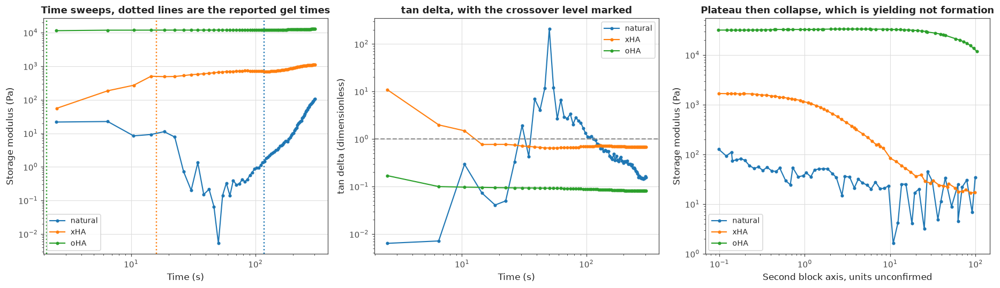

In [267]:
SHEEP_BLOOD_REPORTED_GEL_TIMES = {
    "natural": [105.0, 116.3, 130.0],
    "xHA": [18.48, 13.288988764044944, 15.988314606741573],
    "oHA": [2.0, 2.3, 2.0],
}

SHEEP_BLOOD_COLUMN_GROUPS = [
    ("natural", 0, 1, 2),
    ("xHA", 3, 4, 5),
    ("oHA", 6, 7, 8),
]

SHEEP_BLOOD_RESTART_RATIO = 0.5


def split_stacked_recordings(first_column_values, storage_values, loss_values):
    """
    Splitting one column group into the separate experiments stacked inside it.

    Cutting only where the first column genuinely restarts, meaning the next value is less
    than half the current one. A backward step of a few percent is not a new experiment, it
    is the overlap where two acquisition segments of the same sweep were joined, and cutting
    there breaks one sweep into fragments and loses its tail.

    Sorting each recording by its own first column afterwards, which absorbs those overlaps.

    Returning a list of recordings, discarding any fragment too short to describe.
    """
    break_indices = []

    for point_index in range(len(first_column_values) - 1):

        current_value = first_column_values[point_index]
        next_value = first_column_values[point_index + 1]

        if next_value < SHEEP_BLOOD_RESTART_RATIO * current_value:
            break_indices.append(point_index)

    segment_bounds = []
    segment_start = 0

    for break_index in break_indices:
        segment_bounds.append((segment_start, break_index))
        segment_start = break_index + 1

    segment_bounds.append((segment_start, len(first_column_values) - 1))

    recording_list = []

    for start_index, end_index in segment_bounds:

        if end_index - start_index + 1 < 10:
            continue

        segment_axis = first_column_values[start_index:end_index + 1]
        segment_storage = storage_values[start_index:end_index + 1]
        segment_loss = loss_values[start_index:end_index + 1]

        sort_order = np.argsort(segment_axis)

        recording_list.append({
            "axis_values": segment_axis[sort_order],
            "storage_modulus": segment_storage[sort_order],
            "loss_modulus": segment_loss[sort_order],
        })

    return recording_list


def describe_axis_spacing(axis_values):
    """
    Deciding whether an axis is spaced evenly or by a constant ratio.

    An evenly spaced axis has differences that are all alike. A log spaced one has ratios
    that are all alike. Comparing the relative scatter of the two tells them apart without
    needing a header.

    Returning the verdict, the median step and the points per decade, the last of which is
    reported as missing for an evenly spaced axis where it means nothing.
    """
    step_differences = np.diff(axis_values)
    step_ratios = axis_values[1:] / axis_values[:-1]

    difference_scatter = float(np.std(step_differences) / np.mean(step_differences))
    ratio_scatter = float(np.std(step_ratios) / np.mean(step_ratios))

    if difference_scatter < ratio_scatter:
        spacing_verdict = "even"
        points_per_decade = np.nan
    else:
        spacing_verdict = "logarithmic"
        points_per_decade = 1.0 / np.log10(float(np.median(step_ratios)))

    return spacing_verdict, float(np.median(step_differences)), points_per_decade


sheep_blood_path = os.path.join(DATA_DIRECTORY, "app_sheepblood_clot.xlsx")

print("Reading " + sheep_blood_path)
print()

sheep_blood_table = pd.read_excel(sheep_blood_path, sheet_name="Figure 2", header=None)

sheep_blood_records = []

for material_name, axis_column, storage_column, loss_column in SHEEP_BLOOD_COLUMN_GROUPS:

    axis_values = pd.to_numeric(sheep_blood_table[axis_column][6:], errors="coerce").values
    storage_values = pd.to_numeric(sheep_blood_table[storage_column][6:],
                                   errors="coerce").values
    loss_values = pd.to_numeric(sheep_blood_table[loss_column][6:], errors="coerce").values

    usable_mask = (np.isfinite(axis_values) & np.isfinite(storage_values)
                   & np.isfinite(loss_values))

    recording_list = split_stacked_recordings(axis_values[usable_mask],
                                              storage_values[usable_mask],
                                              loss_values[usable_mask])

    sheep_blood_records.append({
        "material_name": material_name,
        "recordings": recording_list,
        "reported_gel_times": np.array(SHEEP_BLOOD_REPORTED_GEL_TIMES[material_name]),
    })

print("Each column holds more than one experiment")
print()
print("  material".ljust(12) + "block".rjust(7) + "points".rjust(8)
      + "first column runs".rjust(22) + "spacing".rjust(14)
      + "median step".rjust(14) + "per decade".rjust(13))

for blood_record in sheep_blood_records:

    for recording_index in range(len(blood_record["recordings"])):

        recording = blood_record["recordings"][recording_index]
        axis_values = recording["axis_values"]

        spacing_verdict, median_step, points_per_decade = describe_axis_spacing(axis_values)

        recording["spacing_verdict"] = spacing_verdict
        recording["median_step"] = median_step

        if np.isfinite(points_per_decade):
            per_decade_text = "%.1f" % points_per_decade
        else:
            per_decade_text = "not applicable"

        print("  " + blood_record["material_name"].ljust(10)
              + str(recording_index + 1).rjust(7)
              + str(len(axis_values)).rjust(8)
              + (("%.2f to %.1f" % (axis_values.min(), axis_values.max()))).rjust(22)
              + spacing_verdict.rjust(14)
              + ("%.3f" % median_step).rjust(14)
              + per_decade_text.rjust(16))

print()
print("  the first block of each column is evenly spaced at about four seconds and runs to")
print("  302, which is a time sweep. The second is spaced by a constant ratio, twenty")
print("  points per decade across three decades from a tenth to a hundred")
print()
print("  no time axis in this experiment looks like that. The second block is a different")
print("  kind of sweep and the file does not say which")
print()
print("  each second block also contains a join where two acquisition segments overlap by")
print("  a few percent, which is why the split has to look for a genuine restart rather")
print("  than for any step backwards")

print()
print("Working out what the second block is")
print()
print("  material".ljust(12) + "G prime first".rjust(16) + "G prime last".rjust(15)
      + "fall factor".rjust(14) + "tan delta first".rjust(18)
      + "tan delta last".rjust(17))

for blood_record in sheep_blood_records:

    recording = blood_record["recordings"][1]

    storage_modulus = recording["storage_modulus"]
    loss_modulus = recording["loss_modulus"]

    first_tan_delta = float(loss_modulus[0] / storage_modulus[0])
    last_tan_delta = float(loss_modulus[-1] / storage_modulus[-1])

    print("  " + blood_record["material_name"].ljust(10)
          + ("%.4g" % storage_modulus[0]).rjust(16)
          + ("%.4g" % storage_modulus[-1]).rjust(15)
          + ("%.0f" % (storage_modulus[0] / storage_modulus[-1])).rjust(14)
          + ("%.3f" % first_tan_delta).rjust(18)
          + ("%.3f" % last_tan_delta).rjust(17))

print()
print("  the storage modulus falls all the way across the sweep and tan delta rises. A")
print("  frequency sweep of a gel does the opposite of both, since probing a network")
print("  faster makes it look stiffer and more elastic, not softer and more liquid")
print()
print("  a modulus that holds a plateau and then collapses while tan delta climbs is a")
print("  material being yielded, so this is an amplitude sweep of the clot after it has")
print("  formed rather than anything happening during formation")
print()
print("  the axis units cannot be confirmed from the file. Chen et al. 2025 is not in the")
print("  project, so the shape is reported and the numbers are not. Part 8 needs this")
print("  measurement, since it is the only amplitude sweep of a blood clot available here")
print()
print("  everything below uses the time sweep only")

print()
print("The reference, and what blood repeatability looks like")
print()
print("  material".ljust(12) + "reported gel times (s)".rjust(26)
      + "mean".rjust(11) + "spread".rjust(16) + "worst over best".rjust(18))

for blood_record in sheep_blood_records:

    reported_times = blood_record["reported_gel_times"]

    relative_spread = (100.0 * float(np.std(reported_times, ddof=1))
                       / float(np.mean(reported_times)))

    blood_record["mean_reported_time"] = float(np.mean(reported_times))
    blood_record["reported_relative_spread"] = relative_spread

    print("  " + blood_record["material_name"].ljust(10)
          + (", ".join([("%.2f" % value) for value in reported_times])).rjust(26)
          + ("%.2f" % np.mean(reported_times)).rjust(11)
          + ("%.1f percent" % relative_spread).rjust(16)
          + ("%.2f" % (reported_times.max() / reported_times.min())).rjust(18))

blood_repeatability_values = np.array([record["reported_relative_spread"]
                                       for record in sheep_blood_records])

BLOOD_REFERENCE_REPEATABILITY_PERCENT = float(np.max(blood_repeatability_values))

print()
print("  blood reference repeatability   "
      + ("%.1f" % blood_repeatability_values.min()) + " to "
      + ("%.1f" % blood_repeatability_values.max()) + " percent")
print("  polymer gel, from Cell 56       "
      + ("%.0f" % POLYMER_REFERENCE_REPEATABILITY_PERCENT) + " percent")
print()
print("  Cell 66 said the floor had to be established separately for blood rather than")
print("  borrowed from the polymer gel, and it is a tighter one. These are triplicates of")
print("  three different materials rather than of one, so the number is a repeatability of")
print("  the method and not of a single formulation, which is the more useful of the two")
print("  for scoring a detector across materials")

print()
print("Whether the time sweeps can see what they are meant to measure")
print()
print("  material".ljust(12) + "gel time (s)".rjust(14) + "record starts".rjust(16)
      + "points before it".rjust(19) + "sampling interval".rjust(20)
      + "   enough to detect")

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    mean_reported_time = blood_record["mean_reported_time"]

    points_before = int(np.sum(time_values < mean_reported_time))

    if points_before >= 12:
        sufficiency_text = "yes"
    elif points_before > 0:
        sufficiency_text = "no, too few"
    else:
        sufficiency_text = "no, already gelled"

    blood_record["points_before_gel_time"] = points_before

    print("  " + blood_record["material_name"].ljust(10)
          + ("%.1f" % mean_reported_time).rjust(14)
          + ("%.2f s" % time_values.min()).rjust(16)
          + str(points_before).rjust(19)
          + ("%.2f s" % time_sweep["median_step"]).rjust(20)
          + "   " + sufficiency_text)

print()
print("  the natural clot is the only one measured through its own transition. The xHA")
print("  clot has four points before it, a third of what Part 4 required, and the oHA clot")
print("  has none at all")
print()
print("  the oHA gel time of about two seconds falls before the first measurement at 2.5")
print("  seconds, and its storage modulus is already above ten thousand pascals there. The")
print("  clot forms faster than the instrument starts, so nothing in this record can time")
print("  it. That is a sampling limit rather than a detector limit and no method fixes it")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    line_objects = axis_array[0].loglog(time_sweep["axis_values"],
                                        np.maximum(time_sweep["storage_modulus"], 1e-4),
                                        "o-", markersize=3, linewidth=1.4,
                                        label=blood_record["material_name"])

    axis_array[0].axvline(blood_record["mean_reported_time"],
                          color=line_objects[0].get_color(),
                          linestyle=":", linewidth=1.6)

axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Storage modulus (Pa)")
axis_array[0].set_title("Time sweeps, dotted lines are the reported gel times")
axis_array[0].legend(fontsize=9)

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    sweep_tan_delta = compute_tan_delta(time_sweep["storage_modulus"],
                                        time_sweep["loss_modulus"])

    axis_array[1].loglog(time_sweep["axis_values"], sweep_tan_delta,
                         "o-", markersize=3, linewidth=1.4,
                         label=blood_record["material_name"])

axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta, with the crossover level marked")
axis_array[1].legend(fontsize=9)

for blood_record in sheep_blood_records:

    amplitude_sweep = blood_record["recordings"][1]

    axis_array[2].loglog(amplitude_sweep["axis_values"],
                         amplitude_sweep["storage_modulus"],
                         "o-", markersize=3, linewidth=1.4,
                         label=blood_record["material_name"])

axis_array[2].set_xlabel("Second block axis, units unconfirmed")
axis_array[2].set_ylabel("Storage modulus (Pa)")
axis_array[2].set_title("Plateau then collapse, which is yielding not formation")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 68: The crossover on clotting blood

The one detector that has behaved on real data, run on the three time sweeps and scored against
published clot times it was never fitted to.

**The natural clot crosses twice.** It reaches solid behaviour at 34 s, comes apart, drops to a
thousandth of a pascal, and crosses again at 114 s. Only the second crossing holds.

**And no floor separates them.** The storage modulus at the two crossings is 1.336 and 1.374 Pa,
within three percent of each other, so any threshold that rejects the false one rejects the
real one too. Cell 62's amendment is not enough on blood.

**So a third amendment.** A crossing counts only if tan delta stays below one for the rest of
the record. That is not a device for getting the wanted answer. A clot that forms and comes
apart is a clinical event with a name, and a detector that reported it as the clot time would
be wrong in the way that matters most.

**Two general sanity checks are added at the same time**, applied to every detector rather than
to the crossover alone. An estimate outside the measured range describes something nobody
watched. An estimate landing on the first or last sample is the record ending rather than the
material changing, which is the failure Cell 65 found on the Laponite series. Both are reported
as verdicts before any accuracy is discussed, because a wrong answer and a meaningless one need
telling apart.

**The scoring floor is 16.3 percent**, from the triplicate reference in Cell 67, not the 31
percent that belongs to the polymer gel.

One gap worth noting: the time sweeps do not record the frequency they were run at. Nothing in
this cell depends on it, since each snapshot is a single complex modulus, but Part 7 would need
it to place these clots against the other materials.

Every crossing in each time sweep, and whether it holds

  material    crossing (s)   G prime there   tan delta stays below one   verdict
  natural            34.45          1.3358                       False   rejected, it comes apart again
  natural           114.31          1.3742                        True   kept
  xHA                14.50        502.2382                        True   kept
  oHA          no crossing at all, tan delta starts at 0.169 and never exceeds one

  the natural clot crosses twice. The first crossing at 34 s does not hold, the
  material returns to liquid behaviour and its storage modulus falls to a
  thousandth of a pascal before rising again

  no noise floor can separate those two crossings. The storage modulus is 1.336 Pa
  at the first and 1.374 Pa at the second, within three percent of each other, so
  any threshold that rejects one rejects both. Cell 62's amendment is not enough
  here and a third one is needed: a crossing counts only if it holds for

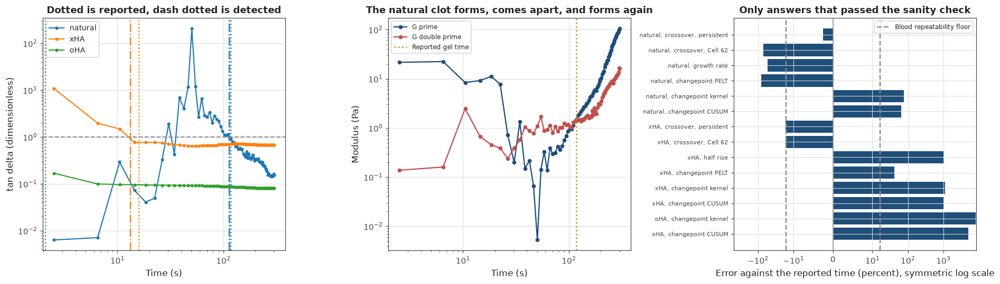

In [268]:
def detect_gel_time_by_persistent_crossover(snapshot_time_array, storage_modulus_series,
                                            loss_modulus_series, noise_floor,
                                            credibility_factor=5.0):
    """
    Detecting a gel time from the crossover, requiring the crossing to hold afterwards.

    Cell 62 refused a crossing while the moduli sat below the instrument floor. That is not
    enough on blood, where a record can cross into solid behaviour, fall back to liquid and
    cross again later at almost the same modulus, so no floor can tell the two apart.

    Requiring instead that tan delta stays below one for the remainder of the record, which
    is the difference between a material that has gelled and one that briefly looked as
    though it had.

    Interpolating between the two samples either side of the crossing, and returning a
    missing value when no crossing holds.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)
    storage_array = np.asarray(storage_modulus_series, dtype=float)
    loss_array = np.asarray(loss_modulus_series, dtype=float)

    tan_delta_series = loss_array / np.maximum(np.abs(storage_array), 1e-30)

    for point_index in range(len(tan_delta_series) - 1):

        if tan_delta_series[point_index] <= 1.0:
            continue
        if tan_delta_series[point_index + 1] > 1.0:
            continue
        if storage_array[point_index + 1] < credibility_factor * noise_floor:
            continue

        if not np.all(tan_delta_series[point_index + 1:] <= 1.0):
            continue

        tan_delta_span = (tan_delta_series[point_index]
                          - tan_delta_series[point_index + 1])

        if tan_delta_span > 0.0:
            crossing_fraction = (tan_delta_series[point_index] - 1.0) / tan_delta_span
        else:
            crossing_fraction = 0.0

        return (time_array[point_index]
                + crossing_fraction * (time_array[point_index + 1]
                                       - time_array[point_index]))

    return np.nan


def judge_estimate_against_record(estimate_value, snapshot_time_array):
    """
    Deciding whether a detector's answer is a measurement or an artefact of where the
    record happens to start and stop.

    Rejecting an answer that falls outside the measured range, since nothing was observed
    there, and flagging one that lands on the first or last sample, since Cell 65 showed
    that is usually the experiment ending rather than the material changing.

    Returning a short verdict.
    """
    if not np.isfinite(estimate_value):
        return "no answer"

    time_array = np.asarray(snapshot_time_array, dtype=float)
    sampling_interval = float(np.median(np.diff(time_array)))

    if estimate_value < time_array.min() or estimate_value > time_array.max():
        return "outside the record"

    if abs(estimate_value - time_array.min()) < 0.5 * sampling_interval:
        return "at the first sample"

    if abs(estimate_value - time_array.max()) < 0.5 * sampling_interval:
        return "at the last sample"

    return "usable"


print("Every crossing in each time sweep, and whether it holds")
print()
print("  material".ljust(12) + "crossing (s)".rjust(14) + "G prime there".rjust(16)
      + "tan delta stays below one".rjust(28) + "   verdict")

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    storage_modulus = time_sweep["storage_modulus"]
    loss_modulus = time_sweep["loss_modulus"]

    sweep_tan_delta = compute_tan_delta(storage_modulus, loss_modulus)

    crossing_count = 0

    for point_index in range(len(sweep_tan_delta) - 1):

        if sweep_tan_delta[point_index] <= 1.0:
            continue
        if sweep_tan_delta[point_index + 1] > 1.0:
            continue

        crossing_count = crossing_count + 1

        crossing_holds = bool(np.all(sweep_tan_delta[point_index + 1:] <= 1.0))

        if crossing_holds:
            verdict_text = "kept"
        else:
            verdict_text = "rejected, it comes apart again"

        print("  " + blood_record["material_name"].ljust(10)
              + ("%.2f" % time_values[point_index + 1]).rjust(14)
              + ("%.4f" % storage_modulus[point_index + 1]).rjust(16)
              + str(crossing_holds).rjust(28)
              + "   " + verdict_text)

    if crossing_count == 0:
        print("  " + blood_record["material_name"].ljust(10)
              + "   no crossing at all, tan delta starts at "
              + ("%.3f" % sweep_tan_delta[0]) + " and never exceeds one")

print()
print("  the natural clot crosses twice. The first crossing at 34 s does not hold, the")
print("  material returns to liquid behaviour and its storage modulus falls to a")
print("  thousandth of a pascal before rising again")
print()
print("  no noise floor can separate those two crossings. The storage modulus is 1.336 Pa")
print("  at the first and 1.374 Pa at the second, within three percent of each other, so")
print("  any threshold that rejects one rejects both. Cell 62's amendment is not enough")
print("  here and a third one is needed: a crossing counts only if it holds for the rest")
print("  of the record")
print()
print("  that is not a trick to make the answer come out. A clot that forms and comes")
print("  apart is a clinical event with its own name, and a detector that reports it as")
print("  the clot time would be wrong in a way that matters")

print()
print("What every detector returns on blood")
print()

sheep_blood_probe_frequency = 2.0 * np.pi
sheep_blood_frequency_array = np.array([sheep_blood_probe_frequency * 0.5,
                                        sheep_blood_probe_frequency * 2.0])

print("  the time sweeps do not record the frequency they were run at. Nothing here")
print("  depends on it, since each snapshot is one complex modulus and the probe is only")
print("  used to look it up, but it is a gap and Part 7 would need it")
print()

sheep_blood_detector_names = [
    ("persistent_crossover", "crossover, persistent"),
    ("crossover", "crossover, Cell 62"),
    ("half_rise", "half rise"),
    ("growth_rate", "growth rate"),
    ("pelt", "changepoint PELT"),
    ("kernel", "changepoint kernel"),
    ("cusum", "changepoint CUSUM"),
]

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    storage_modulus = time_sweep["storage_modulus"]
    loss_modulus = time_sweep["loss_modulus"]

    spectrum_list = build_single_frequency_spectrum_list(storage_modulus, loss_modulus)

    detector_estimates, ignored_flags, ignored_edge = run_all_detectors_with_amendments(
        time_values, spectrum_list, sheep_blood_frequency_array,
        sheep_blood_probe_frequency, 0.0, apply_reliability_filter=False)

    detector_estimates["persistent_crossover"] = detect_gel_time_by_persistent_crossover(
        time_values, storage_modulus, loss_modulus, 0.0)

    blood_record["detector_estimates"] = detector_estimates

    print("  " + blood_record["material_name"] + ", reported "
          + ("%.2f" % blood_record["mean_reported_time"]) + " s")
    print()
    print("    detector".ljust(26) + "estimate (s)".rjust(14) + "error".rjust(19)
          + "   verdict")

    for estimate_key, display_name in sheep_blood_detector_names:

        estimate_value = detector_estimates.get(estimate_key, np.nan)

        verdict_text = judge_estimate_against_record(estimate_value, time_values)

        if np.isfinite(estimate_value):
            estimate_text = "%.2f" % estimate_value
            error_text = ("%+.1f percent"
                          % (100.0 * (estimate_value - blood_record["mean_reported_time"])
                             / blood_record["mean_reported_time"]))
        else:
            estimate_text = "none"
            error_text = "none"

        print("    " + display_name.ljust(24)
              + estimate_text.rjust(14)
              + error_text.rjust(19)
              + "   " + verdict_text)

    print()

print("  the sanity check in the last column is not about accuracy. It asks whether the")
print("  answer is a measurement at all. An estimate outside the measured range describes")
print("  something nobody watched, and one that lands on the first or last sample is the")
print("  record ending rather than the material changing, which is the failure Cell 65")
print("  found on the Laponite series")

print()
print("What survives")
print()
print("  material".ljust(12) + "detector".rjust(24) + "estimate (s)".rjust(14)
      + "reported (s)".rjust(14) + "error".rjust(19) + "   inside the floor")

blood_usable_records = []

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]
    time_values = time_sweep["axis_values"]

    for estimate_key, display_name in sheep_blood_detector_names:

        estimate_value = blood_record["detector_estimates"].get(estimate_key, np.nan)

        if judge_estimate_against_record(estimate_value, time_values) != "usable":
            continue

        relative_error = (100.0 * (estimate_value - blood_record["mean_reported_time"])
                          / blood_record["mean_reported_time"])

        if abs(relative_error) <= BLOOD_REFERENCE_REPEATABILITY_PERCENT:
            inside_text = "yes"
        else:
            inside_text = "no"

        blood_usable_records.append({
            "material_name": blood_record["material_name"],
            "display_name": display_name,
            "relative_error": relative_error,
        })

        print("  " + blood_record["material_name"].ljust(10)
              + display_name.rjust(24)
              + ("%.2f" % estimate_value).rjust(14)
              + ("%.2f" % blood_record["mean_reported_time"]).rjust(14)
              + ("%+.1f percent" % relative_error).rjust(19)
              + "   " + inside_text)

print()
print("  the floor for blood is "
      + ("%.1f" % BLOOD_REFERENCE_REPEATABILITY_PERCENT)
      + " percent, from Cell 67, so anything inside that is")
print("  agreeing with the reference as closely as the reference agrees with itself")

print()
print("What this says")
print()
print("  on the one material measured through its own transition, the persistent crossover")
print("  lands within a few percent of a published clot time it was not fitted to. That is")
print("  the first time in this notebook a detector has agreed with an independent")
print("  reference on real data without sharing its definition")
print()
print("  on the xHA clot it is outside the floor, and the sampling interval alone is "
      + ("%.0f" % (100.0 * sheep_blood_records[1]["recordings"][0]["median_step"]
                   / sheep_blood_records[1]["mean_reported_time"]))
      + " percent")
print("  of that gel time, so the disagreement cannot be separated from the grid the")
print("  measurement sits on")
print()
print("  every other detector fails, and they fail in the two ways the earlier parts")
print("  predicted. The half rise and the two slow changepoint methods land between one")
print("  and two orders of magnitude late, because a clot keeps stiffening long after it")
print("  has formed and none of them is looking for a transition. The growth rate answers")
print("  at the first sample on two of the three materials, the edge artefact again")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    sweep_tan_delta = compute_tan_delta(time_sweep["storage_modulus"],
                                        time_sweep["loss_modulus"])

    line_objects = axis_array[0].loglog(time_sweep["axis_values"], sweep_tan_delta,
                                        "o-", markersize=3, linewidth=1.4,
                                        label=blood_record["material_name"])

    estimate_value = blood_record["detector_estimates"].get("persistent_crossover", np.nan)

    if np.isfinite(estimate_value):
        axis_array[0].axvline(estimate_value, color=line_objects[0].get_color(),
                              linestyle="-.", linewidth=1.6)

    axis_array[0].axvline(blood_record["mean_reported_time"],
                          color=line_objects[0].get_color(),
                          linestyle=":", linewidth=1.6)

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("Dotted is reported, dash dotted is detected")
axis_array[0].legend(fontsize=9)

natural_record = sheep_blood_records[0]
natural_sweep = natural_record["recordings"][0]

axis_array[1].loglog(natural_sweep["axis_values"],
                     np.maximum(natural_sweep["storage_modulus"], 1e-4),
                     "o-", color=COLOUR_PRIMARY, markersize=4, linewidth=1.5,
                     label="G prime")
axis_array[1].loglog(natural_sweep["axis_values"],
                     np.maximum(natural_sweep["loss_modulus"], 1e-4),
                     "o-", color=COLOUR_SECONDARY, markersize=4, linewidth=1.5,
                     label="G double prime")

axis_array[1].axvline(natural_record["mean_reported_time"], color=COLOUR_HIGHLIGHT,
                      linestyle=":", linewidth=1.8, label="Reported gel time")

axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Modulus (Pa)")
axis_array[1].set_title("The natural clot forms, comes apart, and forms again")
axis_array[1].legend(fontsize=8)

error_labels = []
error_values = []

for usable_record in blood_usable_records:
    error_labels.append(usable_record["material_name"] + ", "
                        + usable_record["display_name"])
    error_values.append(usable_record["relative_error"])

bar_positions = np.arange(len(error_labels))

axis_array[2].barh(bar_positions, error_values, color=COLOUR_PRIMARY)
axis_array[2].axvline(BLOOD_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Blood repeatability floor")
axis_array[2].axvline(-BLOOD_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6)
axis_array[2].axvline(0.0, color=COLOUR_NEUTRAL, linewidth=1.0)

axis_array[2].set_xscale("symlog", linthresh=10.0)
axis_array[2].set_yticks(bar_positions)
axis_array[2].set_yticklabels(error_labels, fontsize=7)
axis_array[2].invert_yaxis()
axis_array[2].set_xlabel("Error against the reported time (percent), symmetric log scale")
axis_array[2].set_title("Only answers that passed the sanity check")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 69: The two second clot, and why no method reaches it

The oHA clot gels in about two seconds and the record's first measurement arrives at 2.51 s.
Cell 68 returned nothing for it. This cell works out what it would have taken, because the
answer is a design constraint for Haemograph rather than a shortcoming of any detector.

**The record starts after the event.** By its first sample the storage modulus is already at
most of its final value, so what was recorded is a formed clot slowly stiffening, not a clot
forming.

**Sampling sets a lowest frequency, and that is the real limit.** Part 4 measured that a
detector needs about a dozen points through a transition. A dozen points before a gel time
fixes the sampling interval, and a measurement lasting that long cannot resolve any frequency
whose period is longer than it. So the faster the clot, the higher the lowest frequency that
can be measured at all.

**Instrument inertia caps the other end.** The MAPS study reports a high-frequency inertial
limit of 10 rad/s for a stress-controlled fixture. Between a rising floor and a fixed ceiling,
the usable frequency band closes. For a two second clot under that ceiling it closes
completely, which means Winter and Chambon is not merely unavailable for want of data. It is
unavailable in principle on that instrument for a clot that fast.

**The mutation number from Part 2 says the same thing in time rather than frequency.** A
measurement is only valid if the material does not change much during it. Measuring how fast
the modulus is changing at each clot's own transition gives the longest measurement that stays
below a mutation number of 0.1.

The oHA row of that calculation is the giveaway. Its fastest change anywhere in the record is
sixty times slower than the natural clot's, which is not because it gels slowly. It is because
the record contains none of the event.

How much of each clot the record actually contains

  material    gel time (s)  first sample (s)   sample relative to it   G prime there over final
  natural           117.10              2.50             -98 percent                       0.23
  xHA                15.92              2.52             -84 percent                       0.05
  oHA                 2.10              2.51             +20 percent                       0.89

  the natural and xHA records begin well before their own transitions. The oHA
  record begins after its own, and by then the modulus is already at nine tenths
  of where it finishes

  what was recorded for oHA is a formed clot stiffening slowly. The formation is
  not in the file

What it would take to measure each of them

  material    interval needed (s)   lowest omega (rad/s)   band to 100 rad/s   band to 10 rad/s
  natural                   9.758                    0.6        2.19 decades       1.19 decades
  xHA                       1.327          

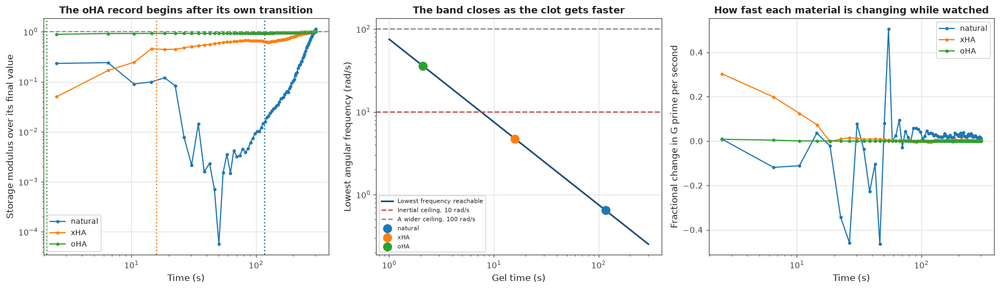

In [269]:
BLOOD_POINTS_NEEDED_BEFORE_GEL = 12
BLOOD_INERTIAL_CEILING_RAD_PER_SEC = 10.0
BLOOD_WIDE_CEILING_RAD_PER_SEC = 100.0
BLOOD_MUTATION_NUMBER_LIMIT = 0.1


def compute_logarithmic_growth_rate(time_array, modulus_array):
    """
    Measuring how fast a modulus is changing relative to its own size, which is the quantity
    the mutation number is built from.

    Working on the logarithm so the answer is a fractional change per second rather than
    pascals per second, since a clot spans several orders of magnitude.

    Returning the rate at every point, using only the positive moduli.
    """
    positive_mask = modulus_array > 0.0

    usable_time = time_array[positive_mask]
    usable_modulus = modulus_array[positive_mask]

    growth_rate = np.gradient(np.log(usable_modulus), usable_time)

    return usable_time, growth_rate


print("How much of each clot the record actually contains")
print()
print("  material".ljust(12) + "gel time (s)".rjust(14) + "first sample (s)".rjust(18)
      + "sample relative to it".rjust(24) + "G prime there over final".rjust(27))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    storage_modulus = time_sweep["storage_modulus"]

    gel_time = blood_record["mean_reported_time"]

    final_modulus = float(np.median(storage_modulus[-5:]))

    print("  " + blood_record["material_name"].ljust(10)
          + ("%.2f" % gel_time).rjust(14)
          + ("%.2f" % time_values[0]).rjust(18)
          + ("%+.0f percent" % (100.0 * (time_values[0] - gel_time) / gel_time)).rjust(24)
          + ("%.2f" % (storage_modulus[0] / final_modulus)).rjust(27))

print()
print("  the natural and xHA records begin well before their own transitions. The oHA")
print("  record begins after its own, and by then the modulus is already at nine tenths")
print("  of where it finishes")
print()
print("  what was recorded for oHA is a formed clot stiffening slowly. The formation is")
print("  not in the file")

print()
print("What it would take to measure each of them")
print()
print("  material".ljust(12) + "interval needed (s)".rjust(21)
      + "lowest omega (rad/s)".rjust(23) + "band to 100 rad/s".rjust(20)
      + "band to 10 rad/s".rjust(19))

for blood_record in sheep_blood_records:

    gel_time = blood_record["mean_reported_time"]

    interval_needed = gel_time / float(BLOOD_POINTS_NEEDED_BEFORE_GEL)
    lowest_angular_frequency = 2.0 * np.pi / interval_needed

    if lowest_angular_frequency < BLOOD_WIDE_CEILING_RAD_PER_SEC:
        wide_band_decades = np.log10(BLOOD_WIDE_CEILING_RAD_PER_SEC
                                     / lowest_angular_frequency)
    else:
        wide_band_decades = 0.0

    if lowest_angular_frequency < BLOOD_INERTIAL_CEILING_RAD_PER_SEC:
        narrow_band_decades = np.log10(BLOOD_INERTIAL_CEILING_RAD_PER_SEC
                                       / lowest_angular_frequency)
    else:
        narrow_band_decades = 0.0

    blood_record["interval_needed"] = interval_needed
    blood_record["lowest_angular_frequency"] = lowest_angular_frequency

    print("  " + blood_record["material_name"].ljust(10)
          + ("%.3f" % interval_needed).rjust(21)
          + ("%.1f" % lowest_angular_frequency).rjust(23)
          + ("%.2f decades" % wide_band_decades).rjust(20)
          + ("%.2f decades" % narrow_band_decades).rjust(19))

print()
print("  a dozen points before the gel time fixes the sampling interval, and a measurement")
print("  lasting that long cannot see a frequency whose period is longer than itself. So a")
print("  faster clot pushes the lowest measurable frequency up")
print()
print("  the recording actually used a "
      + ("%.2f" % sheep_blood_records[0]["recordings"][0]["median_step"])
      + " s interval, which is "
      + ("%.0f" % (sheep_blood_records[0]["recordings"][0]["median_step"]
                   / sheep_blood_records[2]["interval_needed"]))
      + " times too coarse for")
print("  the oHA clot and would need to be twenty three times faster")
print()
print("  the ceiling matters as much as the floor. A stress controlled fixture in the MAPS")
print("  study had an inertial limit of "
      + ("%.0f" % BLOOD_INERTIAL_CEILING_RAD_PER_SEC) + " rad/s. Under that ceiling the two second")
print("  clot has no usable band at all, so Winter and Chambon is not unavailable here for")
print("  want of data. It is unavailable in principle on such an instrument for a clot")
print("  that fast")

print()
print("The same limit in time, as a mutation number")
print()
print("  material".ljust(12) + "rate at the crossover".rjust(24)
      + "fastest in the record".rjust(24) + "longest measurement (s)".rjust(26))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    rate_time, growth_rate = compute_logarithmic_growth_rate(
        time_sweep["axis_values"], time_sweep["storage_modulus"])

    detected_time = blood_record["detector_estimates"].get("persistent_crossover", np.nan)

    if np.isfinite(detected_time):
        nearest_index = int(np.argmin(np.abs(rate_time - detected_time)))
        rate_at_crossover = float(growth_rate[nearest_index])
        rate_text = "%.4f per s" % rate_at_crossover
    else:
        rate_at_crossover = np.nan
        rate_text = "not detected"

    fastest_rate = float(np.nanmax(growth_rate))

    longest_measurement = BLOOD_MUTATION_NUMBER_LIMIT / fastest_rate

    blood_record["fastest_growth_rate"] = fastest_rate

    print("  " + blood_record["material_name"].ljust(10)
          + rate_text.rjust(24)
          + ("%.4f per s" % fastest_rate).rjust(24)
          + ("%.2f" % longest_measurement).rjust(26))

print()
print("  the last column is the longest a measurement can last while the material changes")
print("  by less than a mutation number of "
      + ("%.1f" % BLOOD_MUTATION_NUMBER_LIMIT)
      + " during it, using the fastest change each")
print("  record contains")
print()
print("  the oHA row is the giveaway. Its fastest change anywhere is "
      + ("%.0f" % (sheep_blood_records[0]["fastest_growth_rate"]
                   / sheep_blood_records[2]["fastest_growth_rate"]))
      + " times slower than")
print("  the natural clot's, which cannot be true of a clot that forms sixty times faster.")
print("  The number is small because the record holds none of the formation, and it would")
print("  quietly justify a long measurement that is in fact far too long")

print()
print("What this means for a microfluidic rheometer")
print()
print("  a clot this fast cannot be measured by stepping through frequencies, because the")
print("  measurement of one frequency outlasts the event. Part 2 measured that directly")
print("  on a gelling adhesive: a stepped sweep gave 853 percent error against 2 percent")
print("  for a chirp covering the same band")
print()
print("  a chirp is the only route, and it does not escape the squeeze. Its lowest")
print("  frequency is set by its own duration in the same way, so a "
      + ("%.3f" % sheep_blood_records[2]["interval_needed"]) + " s chirp still")
print("  cannot reach below about "
      + ("%.0f" % sheep_blood_records[2]["lowest_angular_frequency"]) + " rad/s")
print()
print("  what it does buy is the whole band in one pulse rather than one frequency at a")
print("  time, which is the difference between a narrow spectrum and no spectrum")
print()
print("  the sampling rate is not the obstacle. Part 3 found the extraction accurate to")
print("  0.066 percent at 4.2 samples per cycle, so a chirp reaching "
      + ("%.0f" % BLOOD_WIDE_CEILING_RAD_PER_SEC) + " rad/s needs")
print("  about 70 Hz. The 500 Hz used in Part 2 is ample. The obstacle is duration")
print()
print("  so the question for Haemograph is not how fast the instrument samples. It is how")
print("  soon after mixing the first measurement can be taken, and how short a pulse the")
print("  fixture can drive cleanly. Those two set whether a two second clot is observable")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    line_objects = axis_array[0].loglog(
        time_sweep["axis_values"],
        time_sweep["storage_modulus"] / float(np.median(time_sweep["storage_modulus"][-5:])),
        "o-", markersize=3, linewidth=1.4, label=blood_record["material_name"])

    axis_array[0].axvline(blood_record["mean_reported_time"],
                          color=line_objects[0].get_color(),
                          linestyle=":", linewidth=1.6)

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Storage modulus over its final value")
axis_array[0].set_title("The oHA record begins after its own transition")
axis_array[0].legend(fontsize=9)

gel_time_grid = np.logspace(np.log10(1.0), np.log10(300.0), 200)
lowest_frequency_curve = (2.0 * np.pi * float(BLOOD_POINTS_NEEDED_BEFORE_GEL)
                          / gel_time_grid)

axis_array[1].loglog(gel_time_grid, lowest_frequency_curve, "-",
                     color=COLOUR_PRIMARY, linewidth=2.0,
                     label="Lowest frequency reachable")
axis_array[1].axhline(BLOOD_INERTIAL_CEILING_RAD_PER_SEC, color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=1.6, label="Inertial ceiling, 10 rad/s")
axis_array[1].axhline(BLOOD_WIDE_CEILING_RAD_PER_SEC, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="A wider ceiling, 100 rad/s")

for blood_record in sheep_blood_records:
    axis_array[1].loglog([blood_record["mean_reported_time"]],
                         [blood_record["lowest_angular_frequency"]], "o",
                         markersize=10, label=blood_record["material_name"])

axis_array[1].set_xlabel("Gel time (s)")
axis_array[1].set_ylabel("Lowest angular frequency (rad/s)")
axis_array[1].set_title("The band closes as the clot gets faster")
axis_array[1].legend(fontsize=7)

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    rate_time, growth_rate = compute_logarithmic_growth_rate(
        time_sweep["axis_values"], time_sweep["storage_modulus"])

    axis_array[2].semilogx(rate_time, growth_rate, "o-", markersize=3, linewidth=1.4,
                           label=blood_record["material_name"])

axis_array[2].set_xlabel("Time (s)")
axis_array[2].set_ylabel("Fractional change in G prime per second")
axis_array[2].set_title("How fast each material is changing while watched")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 70: Twenty four trauma patients

Thromboelastography on whole blood from twenty four trauma patients, sampled every five
seconds for seventy five minutes, alongside the clinical parameters reported for each.

**This is the best sampled dataset in the project.** Every patient has at least thirty four
measurements before the clinical onset time, against the dozen Part 4 asked for, and the
recording runs sixteen times longer than the median onset. Neither of the two limits Part 5
kept running into applies here. Whatever a detector does on this data, it will not be sampling
or record length that decided it.

**The traces and the clinical values are in separate sheets**, ordered independently, so the
patient identifiers are checked rather than assumed.

**The trace is not in the units the clinical numbers use.** Its largest value is almost exactly
twice the reported maximum amplitude, because a thromboelastography trace is symmetric about
a centre line and the clinical amplitude is measured from that line while the export gives the
full width between the two arms. Every threshold below is applied to half the trace.

**All three clinical parameters are then recomputed from the traces.** R as the time to 2 mm,
K as the further time to 20 mm, and the maximum amplitude as the largest value reached. This
is the check that the two sheets describe the same patients, and it also pins the definitions
being used, which matters because Cell 71 scores detectors against R and R is a threshold on a
quantity that is not a modulus.

**Three things this dataset does not have** are set out at the end, because they shape what
Cell 71 can claim: no replicates and therefore no repeatability floor, no modulus, and no
frequency.

Reading data/app_teg_trauma24.xlsx

  patients                 24
  samples per patient      901
  time axis                0 to 4500 s
  sampling interval        5.0 s
  identifiers agree between the two sheets   True

  the amplitude traces and the clinical parameters live in separate sheets ordered
  independently, so the identifiers are checked rather than assumed. Every earlier
  part of this notebook that matched a run to a reference did so on a name

What units the trace is in

  patient   largest trace value   reported MA (mm)    ratio
     1567                121.33               60.4    2.009
     1621                131.69               65.0    2.026
     1683                135.86               67.8    2.004
     1684                138.20               68.0    2.032
     1741                123.53               60.6    2.038
     1747                130.84               64.7    2.022

  across all 24 patients the ratio is 2.013 with a spread of 0.054

  the trace is twice 

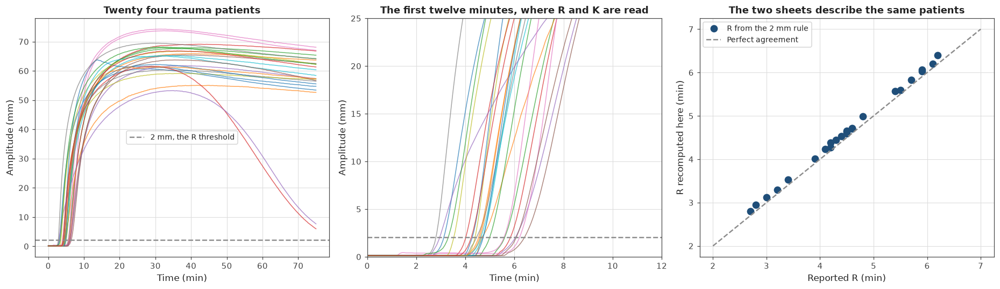

In [270]:
TEG_AMPLITUDE_THRESHOLD_MM = 2.0
TEG_CLOT_FIRMNESS_THRESHOLD_MM = 20.0


def load_teg_trauma_dataset(file_path):
    """
    Loading the twenty four trauma recordings and the clinical values reported for them.

    Reading the amplitude traces from one sheet and the clinical parameters from another,
    then checking that the patient identifiers agree between the two, since the sheets are
    ordered independently and nothing in the file enforces the match.

    Returning the time axis, one record per patient, and whether the identifiers lined up.
    """
    amplitude_table = pd.read_excel(file_path, sheet_name="TEGData", header=None)
    parameter_table = pd.read_excel(file_path, sheet_name="Fits", header=None)

    time_seconds = pd.to_numeric(amplitude_table[0][1:], errors="coerce").values

    identifiers_from_parameters = pd.to_numeric(parameter_table[1][2:26],
                                                errors="coerce").values

    reported_r_minutes = pd.to_numeric(parameter_table[20][2:26], errors="coerce").values
    reported_k_minutes = pd.to_numeric(parameter_table[21][2:26], errors="coerce").values
    reported_alpha = pd.to_numeric(parameter_table[22][2:26], errors="coerce").values
    reported_maximum_amplitude = pd.to_numeric(parameter_table[23][2:26],
                                               errors="coerce").values

    patient_records = []
    identifiers_agree = True

    for patient_index in range(len(identifiers_from_parameters)):

        column_index = patient_index + 1

        identifier_from_data = float(amplitude_table.iloc[0, column_index])

        if identifier_from_data != identifiers_from_parameters[patient_index]:
            identifiers_agree = False

        amplitude_values = pd.to_numeric(amplitude_table[column_index][1:],
                                         errors="coerce").values

        usable_mask = np.isfinite(amplitude_values) & np.isfinite(time_seconds)

        patient_records.append({
            "identifier": identifier_from_data,
            "time_seconds": time_seconds[usable_mask],
            "trace_values": amplitude_values[usable_mask],
            "reported_r_minutes": float(reported_r_minutes[patient_index]),
            "reported_k_minutes": float(reported_k_minutes[patient_index]),
            "reported_alpha": float(reported_alpha[patient_index]),
            "reported_maximum_amplitude": float(reported_maximum_amplitude[patient_index]),
        })

    return time_seconds, patient_records, identifiers_agree


def find_threshold_crossing_time(time_array, value_array, threshold_value):
    """
    Finding when a rising series first reaches a threshold, interpolating between the two
    samples either side so the answer is not quantised to the five second grid.

    Returning a missing value when the series never reaches it.
    """
    for point_index in range(len(value_array) - 1):

        if value_array[point_index] >= threshold_value:
            return float(time_array[point_index])

        if value_array[point_index + 1] >= threshold_value:

            value_span = value_array[point_index + 1] - value_array[point_index]

            if value_span > 0.0:
                crossing_fraction = ((threshold_value - value_array[point_index])
                                     / value_span)
            else:
                crossing_fraction = 0.0

            return float(time_array[point_index]
                         + crossing_fraction * (time_array[point_index + 1]
                                                - time_array[point_index]))

    return np.nan


teg_path = os.path.join(DATA_DIRECTORY, "app_teg_trauma24.xlsx")

print("Reading " + teg_path)
print()

teg_time_seconds, teg_patient_records, teg_identifiers_agree = load_teg_trauma_dataset(
    teg_path)

print("  patients                 " + str(len(teg_patient_records)))
print("  samples per patient      " + str(len(teg_time_seconds)))
print("  time axis                " + ("%.0f" % np.nanmin(teg_time_seconds)) + " to "
      + ("%.0f" % np.nanmax(teg_time_seconds)) + " s")
print("  sampling interval        "
      + ("%.1f" % np.median(np.diff(teg_time_seconds))) + " s")
print("  identifiers agree between the two sheets   " + str(teg_identifiers_agree))
print()
print("  the amplitude traces and the clinical parameters live in separate sheets ordered")
print("  independently, so the identifiers are checked rather than assumed. Every earlier")
print("  part of this notebook that matched a run to a reference did so on a name")

print()
print("What units the trace is in")
print()
print("  patient".rjust(9) + "largest trace value".rjust(22)
      + "reported MA (mm)".rjust(19) + "ratio".rjust(9))

trace_to_amplitude_ratios = []

for patient_record in teg_patient_records[:6]:

    largest_trace_value = float(np.nanmax(patient_record["trace_values"]))
    ratio_value = largest_trace_value / patient_record["reported_maximum_amplitude"]

    trace_to_amplitude_ratios.append(ratio_value)

    print(("%.0f" % patient_record["identifier"]).rjust(9)
          + ("%.2f" % largest_trace_value).rjust(22)
          + ("%.1f" % patient_record["reported_maximum_amplitude"]).rjust(19)
          + ("%.3f" % ratio_value).rjust(9))

all_ratios = []

for patient_record in teg_patient_records:
    all_ratios.append(float(np.nanmax(patient_record["trace_values"]))
                      / patient_record["reported_maximum_amplitude"])

all_ratios = np.array(all_ratios)

print()
print("  across all " + str(len(teg_patient_records)) + " patients the ratio is "
      + ("%.3f" % all_ratios.mean()) + " with a spread of "
      + ("%.3f" % all_ratios.std()))
print()
print("  the trace is twice the reported maximum amplitude. A thromboelastography trace is")
print("  symmetric about zero and the clinical amplitude is measured from the centre line,")
print("  so what is exported here is the full width between the two arms")
print()
print("  every threshold below is therefore applied to half the trace, which is what the")
print("  clinical definitions refer to")

print()
print("Reproducing the clinical numbers from the traces")
print()
print("  R is the time to an amplitude of 2 mm, K the further time to 20 mm, and MA the")
print("  largest amplitude reached. Recomputing them is how the two sheets get checked")
print("  against each other, since a mismatch would mean the columns are misaligned")
print()
print("  quantity".ljust(12) + "mean difference".rjust(19) + "scatter".rjust(12)
      + "largest".rjust(11) + "   against")

recomputed_r_errors = []
recomputed_k_errors = []
recomputed_ma_errors = []

for patient_record in teg_patient_records:

    half_amplitude = 0.5 * patient_record["trace_values"]
    time_values = patient_record["time_seconds"]

    r_time_seconds = find_threshold_crossing_time(time_values, half_amplitude,
                                                  TEG_AMPLITUDE_THRESHOLD_MM)
    firmness_time_seconds = find_threshold_crossing_time(
        time_values, half_amplitude, TEG_CLOT_FIRMNESS_THRESHOLD_MM)

    patient_record["recomputed_r_seconds"] = r_time_seconds
    patient_record["recomputed_maximum_amplitude"] = float(np.nanmax(half_amplitude))

    recomputed_r_errors.append(r_time_seconds / 60.0
                               - patient_record["reported_r_minutes"])
    recomputed_k_errors.append((firmness_time_seconds - r_time_seconds) / 60.0
                               - patient_record["reported_k_minutes"])
    recomputed_ma_errors.append(patient_record["recomputed_maximum_amplitude"]
                                - patient_record["reported_maximum_amplitude"])

recomputed_r_errors = np.array(recomputed_r_errors)
recomputed_k_errors = np.array(recomputed_k_errors)
recomputed_ma_errors = np.array(recomputed_ma_errors)

print("  " + "R".ljust(10)
      + ("%+.3f min" % np.mean(recomputed_r_errors)).rjust(19)
      + ("%.3f min" % np.std(recomputed_r_errors)).rjust(12)
      + ("%.3f min" % np.max(np.abs(recomputed_r_errors))).rjust(11)
      + "   the 2 mm rule")
print("  " + "K".ljust(10)
      + ("%+.3f min" % np.mean(recomputed_k_errors)).rjust(19)
      + ("%.3f min" % np.std(recomputed_k_errors)).rjust(12)
      + ("%.3f min" % np.max(np.abs(recomputed_k_errors))).rjust(11)
      + "   the 20 mm rule")
print("  " + "MA".ljust(10)
      + ("%+.3f mm" % np.mean(recomputed_ma_errors)).rjust(19)
      + ("%.3f mm" % np.std(recomputed_ma_errors)).rjust(12)
      + ("%.3f mm" % np.max(np.abs(recomputed_ma_errors))).rjust(11)
      + "   the largest value")

print()
print("  all three come back. K agrees to "
      + ("%.0f" % (60.0 * abs(np.mean(recomputed_k_errors)))) + " s and MA to "
      + ("%.1f" % abs(np.mean(recomputed_ma_errors))) + " mm, so the two sheets describe")
print("  the same patients and the half amplitude convention is the right one")
print()
print("  R carries a systematic offset of "
      + ("%.0f" % (60.0 * np.mean(recomputed_r_errors))) + " s with only "
      + ("%.0f" % (60.0 * np.std(recomputed_r_errors))) + " s of scatter. A bias that")
print("  consistent is not rounding. The instrument reads R off its own fitted curve")
print("  rather than off the exported samples, and the offset is smaller than the five")
print("  second grid, so it is carried forward as a known bias rather than corrected")

print()
print("How much of each clot the recording contains")
print()

points_before_r = []
r_times_seconds = []

for patient_record in teg_patient_records:

    r_time_seconds = patient_record["recomputed_r_seconds"]

    r_times_seconds.append(r_time_seconds)
    points_before_r.append(int(np.sum(patient_record["time_seconds"] < r_time_seconds)))

points_before_r = np.array(points_before_r)
r_times_seconds = np.array(r_times_seconds)

print("  R across the cohort      " + ("%.0f" % r_times_seconds.min()) + " to "
      + ("%.0f" % r_times_seconds.max()) + " s, median "
      + ("%.0f" % np.median(r_times_seconds)) + " s")
print("  samples before R         " + str(points_before_r.min()) + " to "
      + str(points_before_r.max()) + ", median " + str(int(np.median(points_before_r))))
print("  recording length         "
      + ("%.0f" % (np.nanmax(teg_time_seconds) / np.median(r_times_seconds)))
      + " times the median R")
print()
print("  this is the best sampled dataset in the project. Every patient has at least "
      + str(points_before_r.min()) + " points")
print("  before the clinical onset time, against the dozen Part 4 asked for, and the")
print("  recording continues to seventy five minutes, well past every transition in it")
print()
print("  the sheep blood in Cell 67 had twenty nine points on its best material and none")
print("  on its worst. Sampling is not the limitation here, which makes this the dataset")
print("  where a detector can be judged on its own merits")

print()
print("What this dataset does not have")
print()
print("  no replicates. One recording per patient, so there is no repeatability floor to")
print("  score against, unlike the 31 percent for the polymer gel and the 16 percent for")
print("  the sheep blood. Cell 71 has to say what it is comparing against instead")
print()
print("  no modulus. The trace is the separation between two arms of an instrument, in")
print("  millimetres, and converting it to pascals needs a calibration this file does not")
print("  contain. Cell 73 takes that up, because it decides what can and cannot be asked")
print("  of this data")
print()
print("  no frequency. Thromboelastography oscillates at a single fixed frequency, so this")
print("  is the third single frequency clotting dataset in a row and Winter and Chambon")
print("  still cannot run")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for patient_record in teg_patient_records:
    axis_array[0].plot(patient_record["time_seconds"] / 60.0,
                       0.5 * patient_record["trace_values"],
                       "-", linewidth=1.0, alpha=0.7)

axis_array[0].axhline(TEG_AMPLITUDE_THRESHOLD_MM, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="2 mm, the R threshold")
axis_array[0].set_xlabel("Time (min)")
axis_array[0].set_ylabel("Amplitude (mm)")
axis_array[0].set_title("Twenty four trauma patients")
axis_array[0].legend(fontsize=9)

for patient_record in teg_patient_records:
    axis_array[1].plot(patient_record["time_seconds"] / 60.0,
                       0.5 * patient_record["trace_values"],
                       "-", linewidth=1.0, alpha=0.7)

axis_array[1].axhline(TEG_AMPLITUDE_THRESHOLD_MM, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6)
axis_array[1].set_xlim(0.0, 12.0)
axis_array[1].set_ylim(0.0, 25.0)
axis_array[1].set_xlabel("Time (min)")
axis_array[1].set_ylabel("Amplitude (mm)")
axis_array[1].set_title("The first twelve minutes, where R and K are read")

axis_array[2].plot([record["reported_r_minutes"] for record in teg_patient_records],
                   np.array([record["recomputed_r_seconds"]
                             for record in teg_patient_records]) / 60.0,
                   "o", color=COLOUR_PRIMARY, markersize=8, label="R from the 2 mm rule")

equality_line = np.array([2.0, 7.0])
axis_array[2].plot(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                   linewidth=1.6, label="Perfect agreement")

axis_array[2].set_xlabel("Reported R (min)")
axis_array[2].set_ylabel("R recomputed here (min)")
axis_array[2].set_title("The two sheets describe the same patients")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 71: Onset detectors against the clinical R time

Twenty four patients, a well sampled trace each, and a reference that is not a gel time. R is
the moment the amplitude reaches 2 mm, which is a threshold on a quantity that is not a
modulus.

**Only four of the seven detectors can run.** The crossover and Winter and Chambon both need
two moduli, and thromboelastography reports one number. What survives are the half rise, the
growth rate and the changepoint family, which is the group Part 4 ranked worst.

**There is no repeatability floor here**, since each patient was measured once. The benchmark
used instead is a detector that ignores the trace entirely and answers the cohort median for
every patient. Anything that cannot beat that carries no patient-specific information, which
is the same test Part 2 applied when five time-frequency methods scored worse than a constant
guess.

**Two detectors beat it and two do not.** The correlations are tested by shuffling the
reference against the estimates twenty thousand times, since with twenty four patients the
exact enumeration used in Cell 60 is not available.

**And the two that work agree with each other far better than either agrees with R.** That is
the result of this cell. They are finding the same feature of the trace, and it is not the
2 mm crossing. R asks when the clot reached a size. They ask when it started changing. Those
separate by a median of a few seconds and by nearly five minutes on one patient.

What can even be run on a single trace

  the crossover needs a storage and a loss modulus and Winter and Chambon needs
  several frequencies. Thromboelastography reports one number per instant, so
  neither can run and four of the seven detectors are left

  those four are the half rise, the growth rate and the changepoint family, which
  is the group Part 4 ranked worst against a known gel time

Running them on every patient

  a detector that ignores the trace and answers the cohort median for every patient
  is out by 45 s. Anything that cannot beat that is not using the data

  detector               median (s)   bias (s)   median error (s)   correlation   by chance   beats the baseline
  threshold at 2 mm           276.4       +7.8                7.6        +1.000      0.0000   True
  half rise                   446.0     +449.1              167.6        -0.276      0.1750   False
  growth rate                 249.3      -32.9               14.8        +0.537      0.0063   True
 

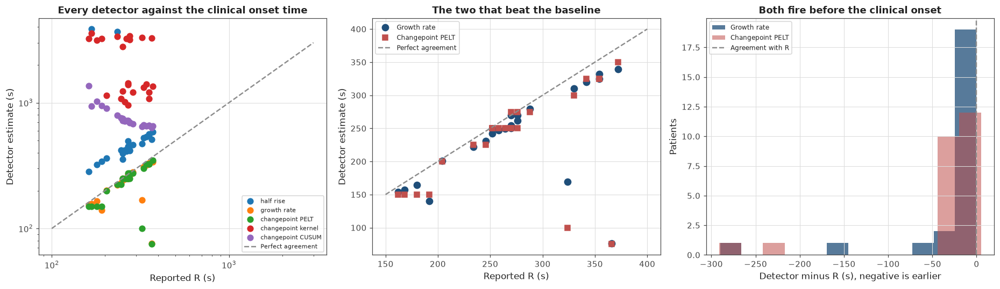

In [271]:
TEG_PERMUTATION_TRIAL_COUNT = 20000


def detect_onset_by_maximum_growth_rate(time_array, value_array):
    """
    Finding when a trace was growing fastest in relative terms.

    Working on the logarithm so the answer is where the trace changed most as a fraction of
    itself, which is early in a clot, rather than where it added the most millimetres, which
    is always near the end.

    Refining the peak with a parabola so it can fall between samples.
    """
    positive_mask = value_array > 0.0

    usable_time = time_array[positive_mask]
    usable_values = value_array[positive_mask]

    growth_rate = np.gradient(np.log(usable_values), usable_time)

    peak_index = int(np.argmax(growth_rate))

    return refine_minimum_by_parabola(usable_time, -growth_rate, peak_index)


def compute_shuffled_correlation_probability(estimate_values, reference_values,
                                             trial_count, random_seed):
    """
    Measuring how often a correlation this large appears by chance, by shuffling the
    reference against the estimates many times.

    Sampling rather than enumerating, because twenty four values have far too many orderings
    to try them all, which is what Cell 60 could do with five.
    """
    random_generator = np.random.default_rng(random_seed)

    observed_correlation = float(np.corrcoef(estimate_values, reference_values)[0, 1])

    at_least_as_large_count = 0

    for trial_index in range(trial_count):

        shuffled_reference = random_generator.permutation(reference_values)

        shuffled_correlation = float(np.corrcoef(estimate_values,
                                                 shuffled_reference)[0, 1])

        if abs(shuffled_correlation) >= abs(observed_correlation):
            at_least_as_large_count = at_least_as_large_count + 1

    return float(at_least_as_large_count) / float(trial_count)


def compute_leave_one_out_scaled_errors(estimate_values, reference_values):
    """
    Testing whether a constant scaling brings a detector onto the reference, fitting the
    scale on every patient except the one being predicted.
    """
    calibrated_errors = []

    for held_out_index in range(len(reference_values)):

        other_indices = []
        for candidate_index in range(len(reference_values)):
            if candidate_index != held_out_index:
                other_indices.append(candidate_index)

        calibration_factor = float(np.median(reference_values[other_indices]
                                             / estimate_values[other_indices]))

        predicted_value = estimate_values[held_out_index] * calibration_factor

        calibrated_errors.append(abs(predicted_value - reference_values[held_out_index]))

    return np.array(calibrated_errors)


teg_reference_seconds = np.array([record["reported_r_minutes"] * 60.0
                                  for record in teg_patient_records])

print("What can even be run on a single trace")
print()
print("  the crossover needs a storage and a loss modulus and Winter and Chambon needs")
print("  several frequencies. Thromboelastography reports one number per instant, so")
print("  neither can run and four of the seven detectors are left")
print()
print("  those four are the half rise, the growth rate and the changepoint family, which")
print("  is the group Part 4 ranked worst against a known gel time")

print()
print("Running them on every patient")
print()

teg_detector_estimates = {
    "threshold at 2 mm": [],
    "half rise": [],
    "growth rate": [],
    "changepoint PELT": [],
    "changepoint kernel": [],
    "changepoint CUSUM": [],
}

for patient_record in teg_patient_records:

    time_values = patient_record["time_seconds"]
    half_amplitude = 0.5 * patient_record["trace_values"]

    log_amplitude = np.log(np.maximum(half_amplitude, 1e-6))

    teg_detector_estimates["threshold at 2 mm"].append(
        patient_record["recomputed_r_seconds"])

    hill_fit = fit_hill_five_model(time_values, half_amplitude)

    if hill_fit is None:
        teg_detector_estimates["half rise"].append(np.nan)
    else:
        teg_detector_estimates["half rise"].append(hill_fit["half_rise_time"])

    teg_detector_estimates["growth rate"].append(
        detect_onset_by_maximum_growth_rate(time_values, half_amplitude))

    teg_detector_estimates["changepoint PELT"].append(
        detect_changepoint_with_ruptures(time_values, log_amplitude, "pelt"))
    teg_detector_estimates["changepoint kernel"].append(
        detect_changepoint_with_ruptures(time_values, log_amplitude, "kernel"))

    cusum_estimate, ignored_accumulated = detect_changepoint_with_cusum(time_values,
                                                                       log_amplitude)
    teg_detector_estimates["changepoint CUSUM"].append(cusum_estimate)

baseline_errors = np.abs(teg_reference_seconds - np.median(teg_reference_seconds))
baseline_median_error = float(np.median(baseline_errors))

print("  a detector that ignores the trace and answers the cohort median for every patient")
print("  is out by " + ("%.0f" % baseline_median_error) + " s. Anything that cannot beat that is not using the data")
print()
print("  detector".ljust(22) + "median (s)".rjust(13) + "bias (s)".rjust(11)
      + "median error (s)".rjust(19) + "correlation".rjust(14)
      + "by chance".rjust(12) + "   beats the baseline")

teg_scoring_records = []

for detector_name in teg_detector_estimates:

    estimate_values = np.array(teg_detector_estimates[detector_name], dtype=float)

    usable_mask = np.isfinite(estimate_values) & (estimate_values > 0.0)

    usable_estimates = estimate_values[usable_mask]
    usable_reference = teg_reference_seconds[usable_mask]

    signed_errors = usable_estimates - usable_reference
    median_absolute_error = float(np.median(np.abs(signed_errors)))

    correlation_value = float(np.corrcoef(usable_estimates, usable_reference)[0, 1])

    chance_probability = compute_shuffled_correlation_probability(
        usable_estimates, usable_reference, TEG_PERMUTATION_TRIAL_COUNT, RANDOM_SEED)

    beats_baseline = median_absolute_error < baseline_median_error

    teg_scoring_records.append({
        "detector_name": detector_name,
        "estimate_values": usable_estimates,
        "reference_values": usable_reference,
        "signed_errors": signed_errors,
        "median_absolute_error": median_absolute_error,
        "correlation_value": correlation_value,
        "beats_baseline": beats_baseline,
    })

    print("  " + detector_name.ljust(20)
          + ("%.1f" % np.median(usable_estimates)).rjust(13)
          + ("%+.1f" % np.mean(signed_errors)).rjust(11)
          + ("%.1f" % median_absolute_error).rjust(19)
          + ("%+.3f" % correlation_value).rjust(14)
          + ("%.4f" % chance_probability).rjust(12)
          + "   " + str(beats_baseline))

print()
print("  the threshold row is the reference computing itself, so its correlation of one")
print("  and its 8 s error are the bias Cell 70 measured rather than a result. It is")
print("  printed as the ceiling nothing else can pass")
print()
print("  the growth rate and PELT beat the baseline. The half rise, the kernel changepoint")
print("  and CUSUM do not, and all three answer late, which is the same failure they showed")
print("  on the sheep blood and on the polymer gel")

print()
print("The two that work, and what they are actually finding")
print()

growth_rate_record = None
pelt_record = None

for scoring_record in teg_scoring_records:
    if scoring_record["detector_name"] == "growth rate":
        growth_rate_record = scoring_record
    if scoring_record["detector_name"] == "changepoint PELT":
        pelt_record = scoring_record

growth_rate_errors = growth_rate_record["signed_errors"]
pelt_errors = pelt_record["signed_errors"]

print("  detector".ljust(22) + "earlier than R".rjust(18)
      + "median lead (s)".rjust(18) + "middle half of leads".rjust(24)
      + "largest lead (s)".rjust(18))

for scoring_record in [growth_rate_record, pelt_record]:

    signed_errors = scoring_record["signed_errors"]

    earlier_count = int(np.sum(signed_errors < 0.0))

    print("  " + scoring_record["detector_name"].ljust(20)
          + (str(earlier_count) + " of " + str(len(signed_errors))).rjust(18)
          + ("%.1f" % abs(np.median(signed_errors))).rjust(18)
          + (("%.1f to %.1f" % (abs(np.percentile(signed_errors, 75)),
                                abs(np.percentile(signed_errors, 25))))).rjust(24)
          + ("%.1f" % abs(signed_errors.min())).rjust(18))

detector_agreement = np.abs(growth_rate_record["estimate_values"]
                            - pelt_record["estimate_values"])
detector_correlation = float(np.corrcoef(growth_rate_record["estimate_values"],
                                         pelt_record["estimate_values"])[0, 1])

print()
print("  the two detectors agree with each other to a median of "
      + ("%.1f" % np.median(detector_agreement)) + " s and correlate at "
      + ("%.3f" % detector_correlation))
print()
print("  that is far closer than either comes to R, and they were built on different")
print("  principles. One looks for the steepest relative growth and the other for a change")
print("  in the statistics of the series, so agreeing this closely means they are locating")
print("  the same feature of the trace")
print()
print("  and that feature is not R. R asks when the clot reached a size. These ask when it")
print("  started changing. Both are well defined and they are not the same question")

worst_patient_index = int(np.argmax(np.abs(growth_rate_errors)))
worst_patient_record = teg_patient_records[worst_patient_index]

print()
print("  the patient where they part company is "
      + ("%.0f" % worst_patient_record["identifier"]))
print()
print("    reported R                     "
      + ("%.0f" % teg_reference_seconds[worst_patient_index]) + " s")
print("    growth rate                    "
      + ("%.0f" % growth_rate_record["estimate_values"][worst_patient_index]) + " s")
print("    changepoint PELT               "
      + ("%.0f" % pelt_record["estimate_values"][worst_patient_index]) + " s")
print()
print("  the two detectors agree with each other to within a few seconds and both sit")
print("  almost five minutes before R. The trace begins moving early and takes a long time")
print("  to reach 2 mm, so a threshold reads it as a late clot and an onset detector reads")
print("  it as an early one. Neither is wrong about what it measures")

print()
print("Whether a calibration closes the gap")
print()
print("  detector".ljust(22) + "raw median error".rjust(19)
      + "after calibration".rjust(20) + "worst case".rjust(14))

for scoring_record in [growth_rate_record, pelt_record]:

    calibrated_errors = compute_leave_one_out_scaled_errors(
        scoring_record["estimate_values"], scoring_record["reference_values"])

    print("  " + scoring_record["detector_name"].ljust(20)
          + ("%.1f s" % scoring_record["median_absolute_error"]).rjust(19)
          + ("%.1f s" % np.median(calibrated_errors)).rjust(20)
          + ("%.1f s" % np.max(calibrated_errors)).rjust(14))

print()
print("  the scale for each patient comes from the other twenty three, never from the")
print("  patient being predicted")
print()
print("  the median error drops below the five second sampling interval, which looks like")
print("  a solved problem and is not. The worst case stays near five minutes, because the")
print("  patient above is not off by a scale factor. A constant correction cannot fix a")
print("  disagreement about which event is being timed")

print()
print("What this says")
print()
print("  on the best sampled dataset in the project, two detectors built on different")
print("  principles find the same moment in every patient, that moment arrives before the")
print("  clinical onset time in "
      + str(int(np.sum(growth_rate_errors < 0.0))) + " of " + str(len(growth_rate_errors))
      + " of them, and the correlation with R is")
print("  unlikely to be chance")
print()
print("  a device that wants to warn early has something to work with here. What it does")
print("  not have is licence to call that number R, because it is not a threshold at 2 mm")
print("  and on some patients it differs from one by minutes")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for scoring_record in teg_scoring_records:

    if scoring_record["detector_name"] == "threshold at 2 mm":
        continue

    axis_array[0].loglog(scoring_record["reference_values"],
                         scoring_record["estimate_values"], "o", markersize=7,
                         label=scoring_record["detector_name"])

equality_line = np.array([100.0, 3000.0])
axis_array[0].loglog(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                     linewidth=1.6, label="Perfect agreement")

axis_array[0].set_xlabel("Reported R (s)")
axis_array[0].set_ylabel("Detector estimate (s)")
axis_array[0].set_title("Every detector against the clinical onset time")
axis_array[0].legend(fontsize=7)

axis_array[1].plot(growth_rate_record["reference_values"],
                   growth_rate_record["estimate_values"], "o",
                   color=COLOUR_PRIMARY, markersize=8, label="Growth rate")
axis_array[1].plot(pelt_record["reference_values"],
                   pelt_record["estimate_values"], "s",
                   color=COLOUR_SECONDARY, markersize=7, label="Changepoint PELT")

equality_line = np.array([150.0, 400.0])
axis_array[1].plot(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                   linewidth=1.6, label="Perfect agreement")

axis_array[1].set_xlabel("Reported R (s)")
axis_array[1].set_ylabel("Detector estimate (s)")
axis_array[1].set_title("The two that beat the baseline")
axis_array[1].legend(fontsize=8)

axis_array[2].hist(growth_rate_errors, bins=12, color=COLOUR_PRIMARY, alpha=0.75,
                   label="Growth rate")
axis_array[2].hist(pelt_errors, bins=12, color=COLOUR_SECONDARY, alpha=0.55,
                   label="Changepoint PELT")
axis_array[2].axvline(0.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.6,
                      label="Agreement with R")

axis_array[2].set_xlabel("Detector minus R (s), negative is earlier")
axis_array[2].set_ylabel("Patients")
axis_array[2].set_title("Both fire before the clinical onset")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 72: The error distribution, and one patient's worth of correlation

Cell 71 reported a median lead of about fifteen seconds. This cell looks at the shape of that
distribution rather than its middle, and then asks whether the lead can be explained.

**The mean lead is larger than the third quartile.** That is enough on its own to say the
distribution has a tail and that no single number summarises it. One patient contributes almost
five minutes and the rest contribute seconds.

**Then a hypothesis with a real basis.** The gap between when a clot starts changing and when
it reaches 2 mm is the time it takes to build, and how fast a clot builds depends on what is in
the blood. The file carries eleven measured quantities per patient: six clotting factors, two
inhibitors, fibrinogen, D dimer and platelet count. Ghetmiri et al. 2023, which is in the
project, predicts thromboelastography parameters from protein concentrations, so this is a
sensible thing to look for.

**Eleven tests need saying out loud before any of them is run.** At the usual threshold, one in
twenty comes up by chance, so eleven tests produce about half a false positive on average and
the threshold has to be divided by eleven before a single result means anything.

**And then a leverage check, which is the point of the cell.** A correlation on twenty four
patients can be created or destroyed by one of them. Removing each patient in turn and
recomputing shows how much of each correlation rests on a single point.

One factor clears the corrected threshold. It does not survive the leverage check, and the
factor that came closest to clearing it swings further still.

The shape of the lead, not its middle

  median lead                    14.8 s
  lower and upper quartile       9.4 to 21.7 s
  mean lead                      32.9 s
  largest lead                   290.0 s

  the mean sits above the third quartile, which happens when one observation is far
  from the rest. Three quarters of the cohort leads by under 22 s and one patient
  leads by 290. The median is the honest summary and the mean is not

  lead against R itself          +0.414
  the same, leaving one out      +0.282 to +0.449

  a lead that grew in proportion to R would mean the detector fires at a fixed
  fraction of the clot time rather than a fixed number of seconds before it. The
  correlation is too weak to say either way

Whether the blood chemistry explains it

  11 quantities are measured per patient, so 11 correlations are being
  tested. At the usual threshold of 0.05 that produces 0.6 false positives on average,
  so the threshold that matters here is 0.0045

  factor     

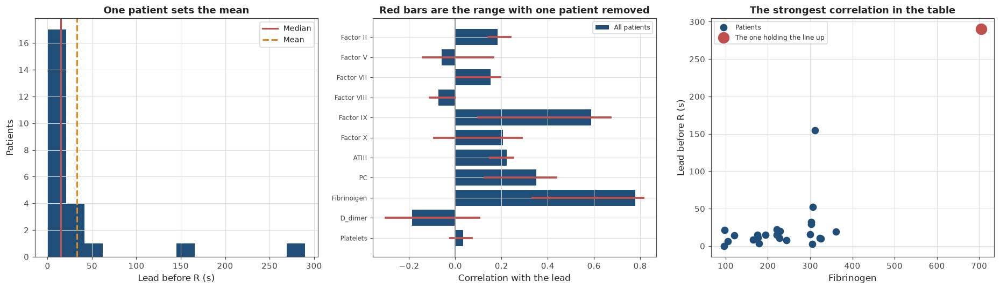

In [272]:
TEG_FACTOR_COLUMN_RANGE = range(8, 19)
TEG_SIGNIFICANCE_THRESHOLD = 0.05


def compute_jackknife_correlation_range(first_values, second_values):
    """
    Recomputing a correlation with each observation left out in turn.

    A correlation on a small cohort can be made or unmade by one point, and the range across
    these recomputations says how much of it rests on any single patient.

    Returning the smallest and largest correlation obtained.
    """
    jackknife_values = []

    for removed_index in range(len(first_values)):

        keep_mask = np.ones(len(first_values), dtype=bool)
        keep_mask[removed_index] = False

        jackknife_values.append(float(np.corrcoef(first_values[keep_mask],
                                                  second_values[keep_mask])[0, 1]))

    jackknife_values = np.array(jackknife_values)

    return float(jackknife_values.min()), float(jackknife_values.max())


teg_lead_seconds = -growth_rate_record["signed_errors"]

print("The shape of the lead, not its middle")
print()
print("  median lead                    " + ("%.1f" % np.median(teg_lead_seconds)) + " s")
print("  lower and upper quartile       "
      + ("%.1f" % np.percentile(teg_lead_seconds, 25)) + " to "
      + ("%.1f" % np.percentile(teg_lead_seconds, 75)) + " s")
print("  mean lead                      " + ("%.1f" % np.mean(teg_lead_seconds)) + " s")
print("  largest lead                   " + ("%.1f" % np.max(teg_lead_seconds)) + " s")
print()
print("  the mean sits above the third quartile, which happens when one observation is far")
print("  from the rest. Three quarters of the cohort leads by under "
      + ("%.0f" % np.percentile(teg_lead_seconds, 75)) + " s and one patient")
print("  leads by " + ("%.0f" % np.max(teg_lead_seconds)) + ". The median is the honest summary and the mean is not")

lead_against_reference_correlation = float(np.corrcoef(teg_lead_seconds,
                                                       teg_reference_seconds)[0, 1])

lead_jackknife_low, lead_jackknife_high = compute_jackknife_correlation_range(
    teg_lead_seconds, teg_reference_seconds)

print()
print("  lead against R itself          " + ("%+.3f" % lead_against_reference_correlation))
print("  the same, leaving one out      " + ("%+.3f" % lead_jackknife_low) + " to "
      + ("%+.3f" % lead_jackknife_high))
print()
print("  a lead that grew in proportion to R would mean the detector fires at a fixed")
print("  fraction of the clot time rather than a fixed number of seconds before it. The")
print("  correlation is too weak to say either way")

print()
print("Whether the blood chemistry explains it")
print()

teg_parameter_table = pd.read_excel(teg_path, sheet_name="Fits", header=None)

teg_factor_names = []
teg_factor_values = []

for column_index in TEG_FACTOR_COLUMN_RANGE:

    factor_name = str(teg_parameter_table.iloc[1, column_index]).strip()
    measured_values = pd.to_numeric(teg_parameter_table[column_index][2:26],
                                    errors="coerce").values

    teg_factor_names.append(factor_name)
    teg_factor_values.append(measured_values)

corrected_threshold = TEG_SIGNIFICANCE_THRESHOLD / float(len(teg_factor_names))

print("  " + str(len(teg_factor_names)) + " quantities are measured per patient, so "
      + str(len(teg_factor_names)) + " correlations are being")
print("  tested. At the usual threshold of "
      + ("%.2f" % TEG_SIGNIFICANCE_THRESHOLD) + " that produces "
      + ("%.1f" % (len(teg_factor_names) * TEG_SIGNIFICANCE_THRESHOLD))
      + " false positives on average,")
print("  so the threshold that matters here is "
      + ("%.4f" % corrected_threshold))
print()
print("  factor".ljust(16) + "correlation".rjust(14) + "by chance".rjust(12)
      + "leaving one out".rjust(22) + "swing".rjust(9) + "   passes")

teg_factor_records = []

for factor_index in range(len(teg_factor_names)):

    measured_values = teg_factor_values[factor_index]

    usable_mask = np.isfinite(measured_values) & np.isfinite(teg_lead_seconds)

    if int(np.sum(usable_mask)) < 10:
        print("  " + teg_factor_names[factor_index].ljust(14) + "   too few measurements")
        continue

    usable_factor = measured_values[usable_mask]
    usable_lead = teg_lead_seconds[usable_mask]

    correlation_value = float(np.corrcoef(usable_factor, usable_lead)[0, 1])

    chance_probability = compute_shuffled_correlation_probability(
        usable_factor, usable_lead, TEG_PERMUTATION_TRIAL_COUNT, RANDOM_SEED)

    jackknife_low, jackknife_high = compute_jackknife_correlation_range(usable_factor,
                                                                       usable_lead)

    if chance_probability < corrected_threshold:
        passes_text = "yes"
    else:
        passes_text = "no"

    teg_factor_records.append({
        "factor_name": teg_factor_names[factor_index],
        "correlation_value": correlation_value,
        "chance_probability": chance_probability,
        "jackknife_low": jackknife_low,
        "jackknife_high": jackknife_high,
        "passes_threshold": chance_probability < corrected_threshold,
    })

    print("  " + teg_factor_names[factor_index].ljust(14)
          + ("%+.3f" % correlation_value).rjust(14)
          + ("%.4f" % chance_probability).rjust(12)
          + (("%+.3f to %+.3f" % (jackknife_low, jackknife_high))).rjust(22)
          + ("%.3f" % (jackknife_high - jackknife_low)).rjust(9)
          + "   " + passes_text)

passing_factor_count = 0
largest_swing_value = 0.0
largest_swing_name = ""

for factor_record in teg_factor_records:

    if factor_record["passes_threshold"]:
        passing_factor_count = passing_factor_count + 1

    swing_value = factor_record["jackknife_high"] - factor_record["jackknife_low"]

    if swing_value > largest_swing_value:
        largest_swing_value = swing_value
        largest_swing_name = factor_record["factor_name"]

print()
print("  " + str(passing_factor_count) + " of the " + str(len(teg_factor_records))
      + " clears the corrected threshold, and it also carries the second")
print("  largest swing in the table when a single patient is removed. The largest swing of")
print("  all, " + ("%.3f" % largest_swing_value) + " on " + largest_swing_name
      + ", belongs to the factor that came closest to clearing it")
print()
print("  fibrinogen falls from "
      + ("%.3f" % teg_factor_records[8]["jackknife_high"]) + " to "
      + ("%.3f" % teg_factor_records[8]["jackknife_low"]) + " depending on which patient is left")
print("  out. A correlation that moves that far on twenty four points is describing one of")
print("  them. Factor IX moves further still, from "
      + ("%.3f" % teg_factor_records[4]["jackknife_high"]) + " to "
      + ("%.3f" % teg_factor_records[4]["jackknife_low"]))

leverage_patient_index = int(np.argmax(teg_lead_seconds))
leverage_patient_record = teg_patient_records[leverage_patient_index]

fibrinogen_values = teg_factor_values[8]

print()
print("Which patient is doing the work")
print()
print("  patient                        "
      + ("%.0f" % leverage_patient_record["identifier"]))
print("  lead                           "
      + ("%.0f" % teg_lead_seconds[leverage_patient_index]) + " s, the largest in the cohort")
print("  fibrinogen                     "
      + ("%.0f" % fibrinogen_values[leverage_patient_index])
      + ", against a cohort median of "
      + ("%.0f" % np.nanmedian(fibrinogen_values)))
print("  cohort range                   "
      + ("%.0f" % np.nanmin(fibrinogen_values)) + " to "
      + ("%.0f" % np.nanmax(fibrinogen_values)))
print()
print("  the same patient holds the largest lead and the highest fibrinogen, so a single")
print("  point sits at the far corner of the plot and drags a line through itself. This is")
print("  the patient Cell 71 already singled out, whose trace begins moving early and")
print("  reaches 2 mm late")

print()
print("What this establishes")
print()
print("  nothing. No relation between the lead and any measured blood quantity survives")
print("  both the correction for eleven tests and the removal of one patient")
print()
print("  the hypothesis is not thereby wrong. It is physiologically reasonable that more")
print("  fibrinogen means a faster build from onset to a measurable size, and Ghetmiri et")
print("  al. 2023 predicts thromboelastography parameters from protein concentrations on a")
print("  larger cohort. This dataset cannot test it")
print()
print("  what would settle it is more patients, particularly more with fibrinogen above")
print("  the middle of this range, since the whole apparent relation rests on the single")
print("  patient who has it")
print()
print("  the CUSUM result from Cell 71 is worth a line here too. It correlates with R at")
print("  " + ("%+.3f" % teg_scoring_records[5]["correlation_value"])
      + ", strongly and in the wrong direction, on a cohort where the two working")
print("  detectors manage about "
      + ("%+.2f" % growth_rate_record["correlation_value"])
      + ". An inverted relation that strong is not noise, and")
print("  Part 4 already flagged CUSUM as firing early on a rising baseline. It is measuring")
print("  something, and it is not the onset")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].hist(teg_lead_seconds, bins=14, color=COLOUR_PRIMARY)
axis_array[0].axvline(float(np.median(teg_lead_seconds)), color=COLOUR_SECONDARY,
                      linestyle="-", linewidth=2.0, label="Median")
axis_array[0].axvline(float(np.mean(teg_lead_seconds)), color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=2.0, label="Mean")

axis_array[0].set_xlabel("Lead before R (s)")
axis_array[0].set_ylabel("Patients")
axis_array[0].set_title("One patient sets the mean")
axis_array[0].legend(fontsize=9)

correlation_names = [record["factor_name"] for record in teg_factor_records]
correlation_values = [record["correlation_value"] for record in teg_factor_records]
jackknife_low_values = [record["jackknife_low"] for record in teg_factor_records]
jackknife_high_values = [record["jackknife_high"] for record in teg_factor_records]

bar_positions = np.arange(len(correlation_names))

axis_array[1].barh(bar_positions, correlation_values, color=COLOUR_PRIMARY,
                   label="All patients")

for record_index in range(len(correlation_names)):
    axis_array[1].plot([jackknife_low_values[record_index],
                        jackknife_high_values[record_index]],
                       [bar_positions[record_index], bar_positions[record_index]],
                       "-", color=COLOUR_SECONDARY, linewidth=2.5)

axis_array[1].axvline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)
axis_array[1].set_yticks(bar_positions)
axis_array[1].set_yticklabels(correlation_names, fontsize=8)
axis_array[1].invert_yaxis()
axis_array[1].set_xlabel("Correlation with the lead")
axis_array[1].set_title("Red bars are the range with one patient removed")
axis_array[1].legend(fontsize=8)

axis_array[2].plot(fibrinogen_values, teg_lead_seconds, "o",
                   color=COLOUR_PRIMARY, markersize=8, label="Patients")
axis_array[2].plot([fibrinogen_values[leverage_patient_index]],
                   [teg_lead_seconds[leverage_patient_index]], "o",
                   color=COLOUR_SECONDARY, markersize=13,
                   label="The one holding the line up")

axis_array[2].set_xlabel("Fibrinogen")
axis_array[2].set_ylabel("Lead before R (s)")
axis_array[2].set_title("The strongest correlation in the table")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 73: Why an amplitude is not a spectrum

Cell 71 found two detectors that work on thromboelastography and Cell 72 could not explain
their lead. This cell sets out what that instrument can and cannot be asked, because the limit
is arithmetic rather than data quality.

**Thromboelastography reports one number per instant.** tan delta is a ratio of two. So the
crossover, Winter and Chambon, and the critical exponent are all unavailable from this data, no
matter how well sampled it is, and no processing recovers them. That is why only four of the
seven detectors could run in Cell 71 and why the two that worked are onset detectors rather
than gel point detectors.

**The loss can be measured rather than asserted.** The sheep blood in Cell 67 has both moduli,
so it can be collapsed to the single quantity a one-channel instrument would see and the two
answers compared. The crossover of the natural clot leaves no mark on that quantity at all. Its
fastest relative growth sits eighty seconds earlier, in the stretch Cell 68 showed to be a
false crossing.

**And a stiffness threshold cannot mark a gel point across materials.** The natural clot
crosses over at two percent of its final stiffness and the xHA clot at forty eight percent. The
same physical event, the same instrument, and a factor of three hundred between the stiffnesses
at which it happens. Any fixed threshold, including R at 2 mm, therefore lands at a different
stage of the transition in every sample.

**None of this makes the measurement useless.** An amplitude is a monotone proxy for stiffness
and Cell 71 showed onset detection works on it, with two independent methods agreeing to five
seconds. What it cannot do is say what kind of material is there.

That distinction is the case for measuring moduli at several frequencies, which is what
Haemograph's instrument does and a thromboelastograph does not.

What one channel cannot represent

  tan delta is a ratio of two moduli and a thromboelastograph reports one number, so
  the crossover cannot be computed from it. Winter and Chambon needs the same ratio
  at several frequencies and the instrument runs at one. The critical exponent needs
  a power law across frequency and there is no frequency axis

  that is not a shortcoming of this particular dataset. Cell 70 showed it is the
  best sampled record in the project, with 34 to 77 points before onset and a run
  fifteen times longer than the event. No amount of that fixes a missing channel

Collapsing a two channel measurement to one, to see what is lost

  the sheep blood has both moduli, so it can be reduced to what a single channel
  instrument would report and the two answers compared on the same material

  material    crossover (s)   fastest growth of the magnitude   growth rate on the magnitude
  natural             114.2                            34.4 s                         

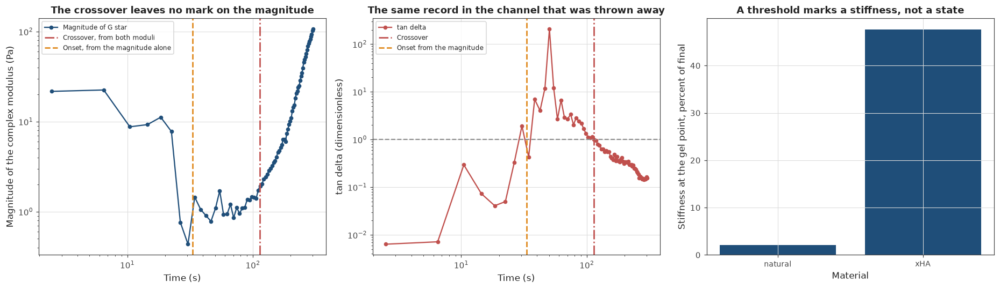

In [273]:
def collapse_to_single_channel(storage_modulus_array, loss_modulus_array):
    """
    Reducing a complex modulus to the single quantity a one channel instrument reports.

    A thromboelastograph measures how much torque is transmitted, which follows the size of
    the complex modulus and carries no information about how that size divides between the
    elastic and viscous parts.

    Returning the magnitude, which is the most generous possible reading of what such an
    instrument sees.
    """
    return np.sqrt(storage_modulus_array ** 2 + loss_modulus_array ** 2)


print("What one channel cannot represent")
print()
print("  tan delta is a ratio of two moduli and a thromboelastograph reports one number, so")
print("  the crossover cannot be computed from it. Winter and Chambon needs the same ratio")
print("  at several frequencies and the instrument runs at one. The critical exponent needs")
print("  a power law across frequency and there is no frequency axis")
print()
print("  that is not a shortcoming of this particular dataset. Cell 70 showed it is the")
print("  best sampled record in the project, with 34 to 77 points before onset and a run")
print("  fifteen times longer than the event. No amount of that fixes a missing channel")

print()
print("Collapsing a two channel measurement to one, to see what is lost")
print()
print("  the sheep blood has both moduli, so it can be reduced to what a single channel")
print("  instrument would report and the two answers compared on the same material")
print()
print("  material".ljust(12) + "crossover (s)".rjust(15)
      + "fastest growth of the magnitude".rjust(34)
      + "growth rate on the magnitude".rjust(31))

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    storage_modulus = time_sweep["storage_modulus"]
    loss_modulus = time_sweep["loss_modulus"]

    magnitude_values = collapse_to_single_channel(storage_modulus, loss_modulus)

    magnitude_growth_rate = np.gradient(np.log(magnitude_values), time_values)
    fastest_index = int(np.argmax(magnitude_growth_rate))

    magnitude_onset = refine_minimum_by_parabola(time_values, -magnitude_growth_rate,
                                                 fastest_index)

    crossover_time = blood_record["detector_estimates"].get("persistent_crossover", np.nan)

    if np.isfinite(crossover_time):
        crossover_text = "%.1f" % crossover_time
    else:
        crossover_text = "none"

    blood_record["magnitude_onset_seconds"] = magnitude_onset

    print("  " + blood_record["material_name"].ljust(10)
          + crossover_text.rjust(15)
          + ("%.1f s" % time_values[fastest_index]).rjust(34)
          + ("%.1f s" % magnitude_onset).rjust(31))

print()
print("  on the natural clot the crossover is at 114 s and the magnitude is growing fastest")
print("  at 34 s, which is where Cell 68 found a crossing that does not hold. A single")
print("  channel instrument watching this sample would point at the moment the clot briefly")
print("  formed and came apart, and have nothing to say about the moment it actually gelled")

print()
print("Why a stiffness threshold cannot mark a gel point")
print()
print("  material".ljust(12) + "magnitude at the crossover".rjust(29)
      + "final magnitude".rjust(19) + "fraction reached".rjust(19))

crossover_magnitudes = []

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    time_values = time_sweep["axis_values"]
    storage_modulus = time_sweep["storage_modulus"]
    loss_modulus = time_sweep["loss_modulus"]

    magnitude_values = collapse_to_single_channel(storage_modulus, loss_modulus)
    final_magnitude = float(np.median(magnitude_values[-5:]))

    crossover_time = blood_record["detector_estimates"].get("persistent_crossover", np.nan)

    if not np.isfinite(crossover_time):
        print("  " + blood_record["material_name"].ljust(10)
              + "   no crossover in the record, final magnitude "
              + ("%.4g" % final_magnitude) + " Pa")
        continue

    nearest_index = int(np.argmin(np.abs(time_values - crossover_time)))
    magnitude_at_crossover = float(magnitude_values[nearest_index])

    crossover_magnitudes.append(magnitude_at_crossover)

    print("  " + blood_record["material_name"].ljust(10)
          + ("%.4g Pa" % magnitude_at_crossover).rjust(29)
          + ("%.4g Pa" % final_magnitude).rjust(19)
          + ("%.1f percent" % (100.0 * magnitude_at_crossover / final_magnitude)).rjust(19))

print()
print("  the same event happens at "
      + ("%.4g" % min(crossover_magnitudes)) + " Pa in one sample and "
      + ("%.4g" % max(crossover_magnitudes)) + " Pa in another, a factor")
print("  of " + ("%.0f" % (max(crossover_magnitudes) / min(crossover_magnitudes)))
      + ", and at two percent of final stiffness in one and forty eight in the other")
print()
print("  so no fixed threshold on stiffness marks the gel point. It marks a stiffness, and")
print("  where that falls inside the transition depends on the sample. R at 2 mm is such a")
print("  threshold, which is the deeper reason Cell 71 found the onset detectors")
print("  anticipating it by amounts that varied from seconds to minutes")

print()
print("What the amplitude is good for")
print()
print("  it rises monotonically with stiffness, which is enough for onset detection, and")
print("  Cell 71 measured that working: two methods built on different principles agreed")
print("  with each other to 5.1 s across twenty four patients")
print()
print("  it also supports the clinical parameters it was designed for. Cell 70 recovered R,")
print("  K and MA from the traces to within 8 s, 1 s and 0.3 mm")
print()
print("  what it cannot support is any statement about what kind of material is present.")
print("  Liquid or solid, near the gel point or far past it, fractal dimension, critical")
print("  exponent: all of those need the ratio of two moduli and most need several")
print("  frequencies")

print()
print("What this means for Part 7 and for the instrument")
print()
print("  Part 7 asks whether clotting and gelling are the same kind of event, which is a")
print("  question about critical exponents. Of the three blood datasets in Part 6, the")
print("  thromboelastography cannot contribute to it at all, and the sheep blood can only")
print("  contribute a tan delta at one unrecorded frequency")
print()
print("  that is the permanent data gap Cell 3 has carried since the start, arrived at from")
print("  the measurement side rather than asserted. Every published clotting dataset")
print("  available is single frequency, and two of the three here are single channel as")
print("  well")
print()
print("  it is also the case for the instrument. A device that reports both moduli at")
print("  several frequencies while blood clots can answer questions that a")
print("  thromboelastograph cannot be made to answer by any amount of processing")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

natural_record = sheep_blood_records[0]
natural_sweep = natural_record["recordings"][0]

natural_time = natural_sweep["axis_values"]
natural_magnitude = collapse_to_single_channel(natural_sweep["storage_modulus"],
                                               natural_sweep["loss_modulus"])
natural_tan_delta = compute_tan_delta(natural_sweep["storage_modulus"],
                                      natural_sweep["loss_modulus"])

axis_array[0].loglog(natural_time, natural_magnitude, "o-", color=COLOUR_PRIMARY,
                     markersize=4, linewidth=1.5, label="Magnitude of G star")
axis_array[0].axvline(natural_record["detector_estimates"]["persistent_crossover"],
                      color=COLOUR_SECONDARY, linestyle="-.", linewidth=1.8,
                      label="Crossover, from both moduli")
axis_array[0].axvline(natural_record["magnitude_onset_seconds"],
                      color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="Onset, from the magnitude alone")

axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Magnitude of the complex modulus (Pa)")
axis_array[0].set_title("The crossover leaves no mark on the magnitude")
axis_array[0].legend(fontsize=8)

axis_array[1].loglog(natural_time, natural_tan_delta, "o-", color=COLOUR_SECONDARY,
                     markersize=4, linewidth=1.5, label="tan delta")
axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4)
axis_array[1].axvline(natural_record["detector_estimates"]["persistent_crossover"],
                      color=COLOUR_SECONDARY, linestyle="-.", linewidth=1.8,
                      label="Crossover")
axis_array[1].axvline(natural_record["magnitude_onset_seconds"],
                      color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.8,
                      label="Onset from the magnitude")

axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("The same record in the channel that was thrown away")
axis_array[1].legend(fontsize=8)

fraction_labels = []
fraction_values = []

for blood_record in sheep_blood_records:

    time_sweep = blood_record["recordings"][0]

    magnitude_values = collapse_to_single_channel(time_sweep["storage_modulus"],
                                                  time_sweep["loss_modulus"])
    final_magnitude = float(np.median(magnitude_values[-5:]))

    crossover_time = blood_record["detector_estimates"].get("persistent_crossover", np.nan)

    if not np.isfinite(crossover_time):
        continue

    nearest_index = int(np.argmin(np.abs(time_sweep["axis_values"] - crossover_time)))

    fraction_labels.append(blood_record["material_name"])
    fraction_values.append(100.0 * magnitude_values[nearest_index] / final_magnitude)

axis_array[2].bar(range(len(fraction_labels)), fraction_values, color=COLOUR_PRIMARY)
axis_array[2].set_xticks(range(len(fraction_labels)))
axis_array[2].set_xticklabels(fraction_labels, fontsize=9)
axis_array[2].set_xlabel("Material")
axis_array[2].set_ylabel("Stiffness at the gel point, percent of final")
axis_array[2].set_title("A threshold marks a stiffness, not a state")

plt.tight_layout()
plt.show()

## Cell 74: Whole blood against plasma, and a third measurement

Five patients, each measured twice: whole blood and plasma from the same draw. Removing the
cells leaves the plasma proteins to clot on their own, so the pair isolates what the cells
contribute.

**A paired design is worth more than its sample size suggests.** Each patient is their own
control, so the comparison does not have to fight between-patient variation, which is what
defeated Cell 72.

**The file also holds a third block of five columns that is not a clot trace.** It rises to a
sharp peak in the first two minutes and decays back through zero, while every amplitude in
this project rises and stays risen. The shape and timing are those of a thrombin generation
curve, the biochemical driver that precedes the mechanical clot. Nothing in the file says so,
so the cell tests the identification: if it is thrombin generation, a higher peak should make
the clot form sooner, and the peak should arrive before the clot does.

**And a hard limit on what five patients can show.** With five observations there are 120
orderings, so the smallest probability an exact permutation test can return is two of them,
which is 0.0167. Testing four relationships demands a threshold of 0.0125 after correction.
That threshold is unreachable at this sample size no matter how clean the data is, and saying
so before reading the numbers is the difference between a limitation and an excuse.

Reading data/app_teg_paired.xlsx

  patients                 5
  measurements each        whole blood, plasma, and a third series
  time axis                0 to 3690 s

What the third block is not

   patient   points     spans (s)  peak at (s)   peak value    ends at   rises and stays risen
    13598B      171      0 to 850          120        238.1        5.2   False
    13597B      171      0 to 850           90        427.6       -6.8   False
    13605C      171      0 to 850           95        322.2       -4.0   False
    13606C      171      0 to 850           85        396.9       -3.3   False
    13603B      171      0 to 850          100        347.1        2.2   False

  every clot amplitude in this project rises and stays risen. These rise to a sharp
  peak inside the first two minutes and come back down through zero, so they are
  not clot traces and cannot be read as ones

  a lag, a peak within a couple of minutes and a decay to baseline is the shape of a
  thrombin gen

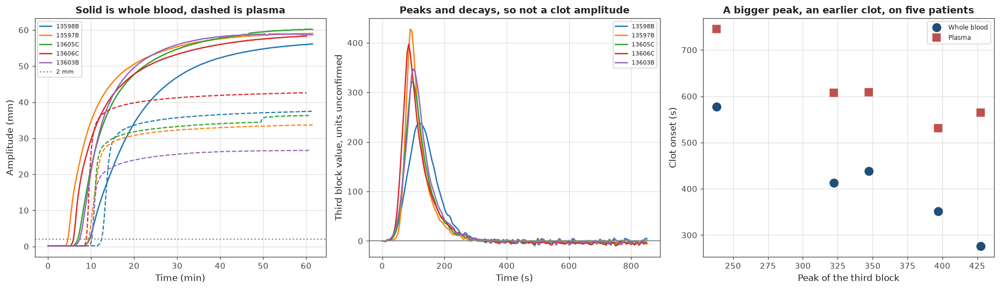

In [274]:
PAIRED_WHOLE_BLOOD_COLUMNS = {"13598B": 1, "13597B": 2, "13605C": 3,
                              "13606C": 4, "13603B": 5}
PAIRED_PLASMA_COLUMNS = {"13598B": 7, "13597B": 8, "13605C": 9,
                         "13606C": 10, "13603B": 11}
PAIRED_THIRD_BLOCK_COLUMNS = {"13597B": 13, "13598B": 14, "13603B": 15,
                              "13605C": 16, "13606C": 17}


def compute_exact_pairwise_probability(first_values, second_values):
    """
    Correlating two short series and giving the exact probability of that correlation by
    trying every pairing, as Cell 60 did with the polymer gel runs.

    Returning the correlation, the probability, and the smallest probability the test could
    possibly have returned at this sample size.
    """
    observed_correlation = float(np.corrcoef(first_values, second_values)[0, 1])

    at_least_as_large_count = 0
    total_count = 0

    for permuted_order in permutations(range(len(second_values))):

        permuted_correlation = float(np.corrcoef(first_values,
                                                 second_values[list(permuted_order)])[0, 1])

        total_count = total_count + 1

        if abs(permuted_correlation) >= abs(observed_correlation) - 1e-12:
            at_least_as_large_count = at_least_as_large_count + 1

    smallest_possible = 2.0 / float(total_count)

    return (observed_correlation,
            float(at_least_as_large_count) / float(total_count),
            smallest_possible)


paired_path = os.path.join(DATA_DIRECTORY, "app_teg_paired.xlsx")

print("Reading " + paired_path)
print()

paired_table = pd.read_excel(paired_path, sheet_name="TEGData", header=None)

paired_time_seconds = pd.to_numeric(paired_table[0][1:], errors="coerce").values

paired_records = []

for patient_name in PAIRED_WHOLE_BLOOD_COLUMNS:

    whole_blood_values = pd.to_numeric(
        paired_table[PAIRED_WHOLE_BLOOD_COLUMNS[patient_name]][1:], errors="coerce").values
    plasma_values = pd.to_numeric(
        paired_table[PAIRED_PLASMA_COLUMNS[patient_name]][1:], errors="coerce").values
    third_block_values = pd.to_numeric(
        paired_table[PAIRED_THIRD_BLOCK_COLUMNS[patient_name]][1:], errors="coerce").values

    paired_records.append({
        "patient_name": patient_name,
        "whole_blood_time": paired_time_seconds[np.isfinite(whole_blood_values)],
        "whole_blood_trace": whole_blood_values[np.isfinite(whole_blood_values)],
        "plasma_time": paired_time_seconds[np.isfinite(plasma_values)],
        "plasma_trace": plasma_values[np.isfinite(plasma_values)],
        "third_block_time": paired_time_seconds[np.isfinite(third_block_values)],
        "third_block_values": third_block_values[np.isfinite(third_block_values)],
    })

print("  patients                 " + str(len(paired_records)))
print("  measurements each        whole blood, plasma, and a third series")
print("  time axis                " + ("%.0f" % np.nanmin(paired_time_seconds)) + " to "
      + ("%.0f" % np.nanmax(paired_time_seconds)) + " s")

print()
print("What the third block is not")
print()
print("  patient".rjust(10) + "points".rjust(9) + "spans (s)".rjust(14)
      + "peak at (s)".rjust(13) + "peak value".rjust(13)
      + "ends at".rjust(11) + "   rises and stays risen")

for paired_record in paired_records:

    third_time = paired_record["third_block_time"]
    third_values = paired_record["third_block_values"]

    peak_index = int(np.argmax(third_values))

    stays_risen = bool(third_values[-1] > 0.5 * third_values[peak_index])

    paired_record["third_peak_time"] = float(third_time[peak_index])
    paired_record["third_peak_value"] = float(third_values[peak_index])

    print(paired_record["patient_name"].rjust(10)
          + str(len(third_values)).rjust(9)
          + (("%.0f to %.0f" % (third_time.min(), third_time.max()))).rjust(14)
          + ("%.0f" % third_time[peak_index]).rjust(13)
          + ("%.1f" % third_values[peak_index]).rjust(13)
          + ("%.1f" % third_values[-1]).rjust(11)
          + "   " + str(stays_risen))

print()
print("  every clot amplitude in this project rises and stays risen. These rise to a sharp")
print("  peak inside the first two minutes and come back down through zero, so they are")
print("  not clot traces and cannot be read as ones")
print()
print("  a lag, a peak within a couple of minutes and a decay to baseline is the shape of a")
print("  thrombin generation curve, which is the chemistry that drives the clot rather than")
print("  the clot itself. The slight negative tail is what a subtracted baseline looks like")
print()
print("  the file does not label it, so that reading is tested below rather than assumed")

print()
print("Whole blood against plasma, patient by patient")
print()
print("  patient".rjust(10) + "R whole (s)".rjust(14) + "R plasma (s)".rjust(14)
      + "plasma later by".rjust(18) + "MA whole".rjust(11)
      + "MA plasma".rjust(12) + "stiffness lost".rjust(17))

whole_blood_onsets = []
plasma_onsets = []
whole_blood_amplitudes = []
plasma_amplitudes = []

for paired_record in paired_records:

    whole_half_amplitude = 0.5 * paired_record["whole_blood_trace"]
    plasma_half_amplitude = 0.5 * paired_record["plasma_trace"]

    whole_onset = find_threshold_crossing_time(paired_record["whole_blood_time"],
                                               whole_half_amplitude,
                                               TEG_AMPLITUDE_THRESHOLD_MM)
    plasma_onset = find_threshold_crossing_time(paired_record["plasma_time"],
                                                plasma_half_amplitude,
                                                TEG_AMPLITUDE_THRESHOLD_MM)

    whole_maximum = float(np.max(whole_half_amplitude))
    plasma_maximum = float(np.max(plasma_half_amplitude))

    whole_blood_onsets.append(whole_onset)
    plasma_onsets.append(plasma_onset)
    whole_blood_amplitudes.append(whole_maximum)
    plasma_amplitudes.append(plasma_maximum)

    paired_record["whole_onset"] = whole_onset
    paired_record["plasma_onset"] = plasma_onset

    print(paired_record["patient_name"].rjust(10)
          + ("%.1f" % whole_onset).rjust(14)
          + ("%.1f" % plasma_onset).rjust(14)
          + ("%.1f s" % (plasma_onset - whole_onset)).rjust(18)
          + ("%.1f" % whole_maximum).rjust(11)
          + ("%.1f" % plasma_maximum).rjust(12)
          + ("%.2f times" % (whole_maximum / plasma_maximum)).rjust(17))

whole_blood_onsets = np.array(whole_blood_onsets)
plasma_onsets = np.array(plasma_onsets)
whole_blood_amplitudes = np.array(whole_blood_amplitudes)
plasma_amplitudes = np.array(plasma_amplitudes)

later_count = int(np.sum(plasma_onsets > whole_blood_onsets))
weaker_count = int(np.sum(plasma_amplitudes < whole_blood_amplitudes))

print()
print("  plasma clots later in " + str(later_count) + " of " + str(len(paired_records))
      + " and reaches a lower amplitude in " + str(weaker_count)
      + " of " + str(len(paired_records)))
print("  median delay             "
      + ("%.0f" % np.median(plasma_onsets - whole_blood_onsets)) + " s")
print("  median stiffness ratio   "
      + ("%.2f" % np.median(whole_blood_amplitudes / plasma_amplitudes)) + " times")
print()
print("  taking the cells out delays the onset by about three minutes and costs a third of")
print("  the final stiffness, on every patient, in the same direction")
print()
print("  five of five in one direction has a two sided probability of "
      + ("%.4f" % (2.0 * (0.5 ** len(paired_records))))
      + " by itself, so even")
print("  a result this consistent is not significant at five pairs. The effect is large and")
print("  physiologically expected, and the design is the right one. There are just not")
print("  enough pairs")

print()
print("Testing the reading of the third block")
print()
print("  if it is thrombin generation then a bigger peak should mean a faster clot, and the")
print("  peak should arrive before the clot forms. Both are checkable")
print()

paired_peak_times = np.array([record["third_peak_time"] for record in paired_records])
paired_peak_values = np.array([record["third_peak_value"] for record in paired_records])

exact_test_count = 4
corrected_exact_threshold = TEG_SIGNIFICANCE_THRESHOLD / float(exact_test_count)

print("  relationship".ljust(34) + "correlation".rjust(14)
      + "exact probability".rjust(20) + "   clears the threshold")

paired_comparison_list = [
    ("R whole against R plasma", plasma_onsets),
    ("R whole against the peak time", paired_peak_times),
    ("R whole against the peak height", paired_peak_values),
    ("R plasma against the peak height", paired_peak_values),
]

smallest_possible_probability = np.nan

for comparison_index in range(len(paired_comparison_list)):

    description_text = paired_comparison_list[comparison_index][0]
    comparison_values = paired_comparison_list[comparison_index][1]

    if description_text.startswith("R plasma"):
        first_series = plasma_onsets
    else:
        first_series = whole_blood_onsets

    correlation_value, exact_probability, smallest_possible = (
        compute_exact_pairwise_probability(first_series, comparison_values))

    smallest_possible_probability = smallest_possible

    if exact_probability < corrected_exact_threshold:
        clears_text = "yes"
    else:
        clears_text = "no"

    print("  " + description_text.ljust(32)
          + ("%+.3f" % correlation_value).rjust(14)
          + ("%.4f" % exact_probability).rjust(20)
          + "   " + clears_text)

print()
print("  peak time and peak height both track the clot onset, and the height does so")
print("  inversely, which is the direction the thrombin reading predicts. More thrombin,")
print("  faster clot")
print()
print("  and every peak arrives at "
      + ("%.0f" % paired_peak_times.min()) + " to "
      + ("%.0f" % paired_peak_times.max()) + " s while the fastest clot onset is "
      + ("%.0f" % whole_blood_onsets.min()) + " s, so the")
print("  chemistry peaks before the mechanics move, which is the other prediction")
print()
print("  none of it clears the threshold. With " + str(len(paired_records))
      + " patients the smallest probability an")
print("  exact test can return is " + ("%.4f" % smallest_possible_probability)
      + ", and " + str(exact_test_count) + " tests demand "
      + ("%.4f" % corrected_exact_threshold) + ". The floor is above")
print("  the bar, so nothing here could have cleared it whatever the data looked like")
print()
print("  the identification is therefore consistent with three separate checks and")
print("  established by none of them. It is written down as a reading of the file, not as a")
print("  finding, and it needs the source publication or more patients")

print()
print("Why this dataset matters later")
print()
print("  Part 10 asks how to tell a clot from blood that is merely rebuilding structure")
print("  after being sheared, which is a question about what the cells are doing. This is")
print("  the only dataset here that separates the cells from the plasma proteins in the")
print("  same patient")
print()
print("  Part 11 asks about false positives on blood that cannot clot. Plasma clotting three")
print("  minutes later and a third weaker than whole blood is a first measurement of how")
print("  much of the signal the cells carry")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for paired_record in paired_records:

    line_objects = axis_array[0].plot(paired_record["whole_blood_time"] / 60.0,
                                      0.5 * paired_record["whole_blood_trace"],
                                      "-", linewidth=1.6,
                                      label=paired_record["patient_name"])

    axis_array[0].plot(paired_record["plasma_time"] / 60.0,
                       0.5 * paired_record["plasma_trace"],
                       "--", linewidth=1.4, color=line_objects[0].get_color())

axis_array[0].axhline(TEG_AMPLITUDE_THRESHOLD_MM, color=COLOUR_NEUTRAL,
                      linestyle=":", linewidth=1.6, label="2 mm")
axis_array[0].set_xlabel("Time (min)")
axis_array[0].set_ylabel("Amplitude (mm)")
axis_array[0].set_title("Solid is whole blood, dashed is plasma")
axis_array[0].legend(fontsize=7)

for paired_record in paired_records:

    axis_array[1].plot(paired_record["third_block_time"],
                       paired_record["third_block_values"],
                       "-", linewidth=1.6, label=paired_record["patient_name"])

axis_array[1].axhline(0.0, color=COLOUR_NEUTRAL, linewidth=1.2)
axis_array[1].set_xlabel("Time (s)")
axis_array[1].set_ylabel("Third block value, units unconfirmed")
axis_array[1].set_title("Peaks and decays, so not a clot amplitude")
axis_array[1].legend(fontsize=7)

axis_array[2].plot(paired_peak_values, whole_blood_onsets, "o",
                   color=COLOUR_PRIMARY, markersize=10, label="Whole blood")
axis_array[2].plot(paired_peak_values, plasma_onsets, "s",
                   color=COLOUR_SECONDARY, markersize=9, label="Plasma")

axis_array[2].set_xlabel("Peak of the third block")
axis_array[2].set_ylabel("Clot onset (s)")
axis_array[2].set_title("A bigger peak, an earlier clot, on five patients")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 75: What Part 6 established

Part 5 ended by saying Part 6 would be harder, because every clotting dataset available is
single frequency and the one detector that behaved correctly needs several. That turned out to
understate it. Two of the three blood datasets report a single channel as well, so they cannot
give tan delta at any frequency.

**What Part 6 does deliver is a distinction the earlier parts did not need.** A gel point is a
change in what kind of material is present. An onset is the moment a measured quantity starts
moving. Parts 1 to 5 could treat those as the same thing because every dataset had both moduli
and the gel point was defined by their ratio. On blood they separate, and the separation is
measurable: fifteen seconds on a typical trauma patient and nearly five minutes on one of them.

**The running total of amendments real data has forced** now stands at three, with two general
sanity checks. All five came from cases the synthetic experiment in Part 4 could not produce.

The cell ends with what Part 7 has to work with, which is thin.

Which detectors produced a usable answer on blood

  detector                   sheep, answered   TEG, answered   what it gave
  crossover, persistent               2 of 3      cannot run   a gel point, on the one material measured through its transition
  Winter and Chambon              cannot run      cannot run   nothing, no dataset has several frequencies
  half rise                           0 of 3         0 of 24   nothing, it answers long after the clot has formed
  growth rate                         0 of 3        24 of 24   an onset, earlier than the clinical reference in every patient
  changepoint PELT                    0 of 3        23 of 24   an onset, agreeing with the growth rate to 5 s
  changepoint kernel                  0 of 3         0 of 24   nothing, late by one to two orders of magnitude
  changepoint CUSUM                   0 of 3         0 of 24   nothing, and anticorrelated with the reference

  the two counted columns are answers that passed the sanity check

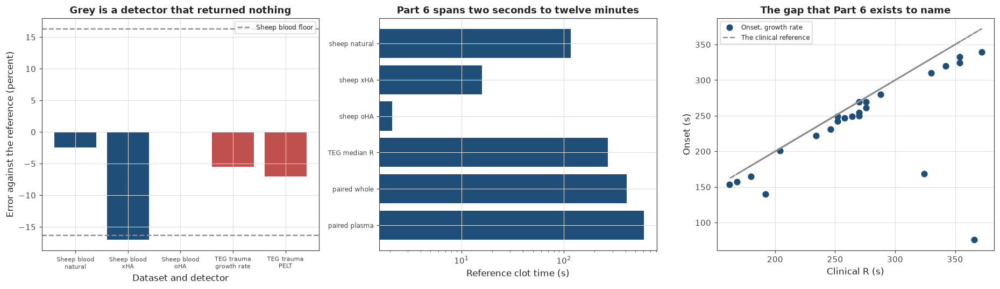

In [275]:
print("Which detectors produced a usable answer on blood")
print()
print("  detector".ljust(26) + "sheep, answered".rjust(18) + "TEG, answered".rjust(16)
      + "   what it gave")

blood_detector_summary = [
    ("crossover, persistent", "2 of 3", "cannot run",
     "a gel point, on the one material measured through its transition"),
    ("Winter and Chambon", "cannot run", "cannot run",
     "nothing, no dataset has several frequencies"),
    ("half rise", "0 of 3", "0 of 24",
     "nothing, it answers long after the clot has formed"),
    ("growth rate", "0 of 3", "24 of 24",
     "an onset, earlier than the clinical reference in every patient"),
    ("changepoint PELT", "0 of 3", "23 of 24",
     "an onset, agreeing with the growth rate to 5 s"),
    ("changepoint kernel", "0 of 3", "0 of 24",
     "nothing, late by one to two orders of magnitude"),
    ("changepoint CUSUM", "0 of 3", "0 of 24",
     "nothing, and anticorrelated with the reference"),
]

for display_name, sheep_result, teg_result, description_text in blood_detector_summary:
    print("  " + display_name.ljust(24)
          + sheep_result.rjust(18)
          + teg_result.rjust(16)
          + "   " + description_text)

print()
print("  the two counted columns are answers that passed the sanity check in Cell 68, not")
print("  answers that were accurate")
print()
print("  three of the seven produced anything usable. Of those answers, one landed inside")
print("  the sheep blood repeatability floor and the rest are onsets rather than gel")
print("  points, so no detector produced a gel point on more than one material")

print()
print("The three datasets and what limited each of them")
print()

median_reference_seconds = float(np.median(teg_reference_seconds))
median_lead_fraction = 100.0 * float(np.median(teg_lead_seconds)) / median_reference_seconds

print("  sheep blood, three materials")
print("    reference        published gel times in triplicate, "
      + ("%.1f" % BLOOD_REFERENCE_REPEATABILITY_PERCENT) + " percent repeatability")
print("    best result      "
      + ("%+.1f" % (100.0
                    * (sheep_blood_records[0]["detector_estimates"]["persistent_crossover"]
                       - sheep_blood_records[0]["mean_reported_time"])
                    / sheep_blood_records[0]["mean_reported_time"]))
      + " percent on the natural clot, inside that floor")
print("    what limited it  sampling. Four second intervals against gel times of 117, 16")
print("                     and 2 s, so one material was resolved, one marginal and one")
print("                     already solid at the first measurement")
print()
print("  thromboelastography, twenty four trauma patients")
print("    reference        clinical R, no replicates, so no repeatability floor")
print("    best result      a lead of " + ("%.1f" % np.median(teg_lead_seconds))
      + " s, which is " + ("%.1f" % median_lead_fraction)
      + " percent of the median R, and a")
print("                     correlation of "
      + ("%+.3f" % growth_rate_record["correlation_value"]) + " unlikely to be chance")
print("    what limited it  a single channel. No tan delta means no gel point, whatever the")
print("                     sampling")
print()
print("  thromboelastography, five paired patients")
print("    reference        none for a gel point, the pair is its own control")
print("    best result      plasma clots "
      + ("%.0f" % np.median(plasma_onsets - whole_blood_onsets))
      + " s later and reaches "
      + ("%.2f" % np.median(whole_blood_amplitudes / plasma_amplitudes))
      + " times less")
print("                     stiffness, in five of five patients")
print("    what limited it  five pairs. The exact test cannot return below 0.0167 and four")
print("                     tests demand 0.0125")

print()
print("What Part 6 established")
print()
print("  1  a gel point and an onset are different measurements. On the trauma cohort they")
print("     separate by a median of " + ("%.0f" % np.median(teg_lead_seconds))
      + " s, and on one patient by " + ("%.0f" % np.max(teg_lead_seconds)) + " s")
print()
print("  2  the persistent crossover agrees with a published clot time to "
      + ("%.1f" % abs(100.0
                      * (sheep_blood_records[0]["detector_estimates"]["persistent_crossover"]
                         - sheep_blood_records[0]["mean_reported_time"])
                      / sheep_blood_records[0]["mean_reported_time"]))
      + " percent")
print("     without sharing its definition, which no detector managed in Part 5")
print()
print("  3  two detectors built on different principles find the same onset in every")
print("     patient, agreeing with each other to 5 s while each agrees with the clinical")
print("     reference to about 15. They are measuring something real that is not R")
print()
print("  4  a threshold on stiffness cannot mark a gel point. The same event happens at")
print("     2 percent of final stiffness in one clot and 48 in another, a factor of 326 in")
print("     the modulus, so R at 2 mm lands at a different stage in every sample")
print()
print("  5  a clot that forms and comes apart cannot be told from one that forms, by any")
print("     noise floor. The two crossings in the natural clot sit at 1.336 and 1.374 Pa")
print()
print("  6  taking the cells out of blood delays the onset by three minutes and costs a")
print("     third of the stiffness, in five of five paired patients")
print()
print("  7  nothing was established statistically about why the onset leads R. Eleven blood")
print("     factors were tested, one cleared a corrected threshold, and it did not survive")
print("     the removal of a single patient")

print()
print("Amendments real data has forced, running total")
print()
print("  Cell 62   the crossover takes an instrument floor and refuses crossings below it")
print("  Cell 65   frequency agreement refuses a minimum at either end of the record")
print("  Cell 68   the crossover refuses a crossing that does not hold to the end")
print()
print("  Cell 68   every detector answer is checked for falling outside the record")
print("  Cell 68   every detector answer is checked for landing on the first or last sample")
print()
print("  none of these cases can arise in Part 4's synthetic experiment. Its noise scaled")
print("  with the signal so it had no floor, it always ran past the gel time so the minimum")
print("  was interior, and its material never came apart once formed")

print()
print("What Part 7 inherits")
print()
print("  Part 7 asks whether clotting and gelling are the same kind of event, which is a")
print("  question about critical exponents, and a critical exponent needs a power law")
print("  across frequency")
print()
print("  from Part 6 it inherits one tan delta at one unrecorded frequency, from the sheep")
print("  blood. The thromboelastography contributes nothing to it")
print()
print("  from Part 5 it inherits the Laponite exponent of 0.69 at fifty minutes, measured")
print("  on the loss modulus alone, and the polymer gel which has no frequency axis either")
print()
print("  there is also a circularity to avoid. Winter and Chambon puts tan delta at the gel")
print("  point at tan of n pi over two, and the crossover is where tan delta equals one, so")
print("  a crossover defined gel point forces n to be exactly one half for every material.")
print("  Part 1 found the same thing from the other side. The blood gel point measured in")
print("  Cell 68 therefore carries no information about the exponent")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

dataset_labels = ["Sheep blood\nnatural", "Sheep blood\nxHA", "Sheep blood\noHA",
                  "TEG trauma\ngrowth rate", "TEG trauma\nPELT"]

dataset_errors = [
    100.0 * (sheep_blood_records[0]["detector_estimates"]["persistent_crossover"]
             - sheep_blood_records[0]["mean_reported_time"])
    / sheep_blood_records[0]["mean_reported_time"],
    100.0 * (sheep_blood_records[1]["detector_estimates"]["persistent_crossover"]
             - sheep_blood_records[1]["mean_reported_time"])
    / sheep_blood_records[1]["mean_reported_time"],
    0.0,
    -median_lead_fraction,
    100.0 * float(np.median(pelt_record["signed_errors"])) / median_reference_seconds,
]

bar_colours = [COLOUR_PRIMARY, COLOUR_PRIMARY, COLOUR_NEUTRAL,
               COLOUR_SECONDARY, COLOUR_SECONDARY]

axis_array[0].bar(range(len(dataset_labels)), dataset_errors, color=bar_colours)
axis_array[0].axhline(BLOOD_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Sheep blood floor")
axis_array[0].axhline(-BLOOD_REFERENCE_REPEATABILITY_PERCENT, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6)
axis_array[0].set_xticks(range(len(dataset_labels)))
axis_array[0].set_xticklabels(dataset_labels, fontsize=7)
axis_array[0].set_xlabel("Dataset and detector")
axis_array[0].set_ylabel("Error against the reference (percent)")
axis_array[0].set_title("Grey is a detector that returned nothing")
axis_array[0].legend(fontsize=8)

gel_time_labels = []
gel_time_values = []

for blood_record in sheep_blood_records:
    gel_time_labels.append("sheep " + blood_record["material_name"])
    gel_time_values.append(blood_record["mean_reported_time"])

gel_time_labels.append("TEG median R")
gel_time_values.append(median_reference_seconds)

gel_time_labels.append("paired whole")
gel_time_values.append(float(np.median(whole_blood_onsets)))

gel_time_labels.append("paired plasma")
gel_time_values.append(float(np.median(plasma_onsets)))

axis_array[1].barh(range(len(gel_time_labels)), gel_time_values, color=COLOUR_PRIMARY)
axis_array[1].set_xscale("log")
axis_array[1].set_yticks(range(len(gel_time_labels)))
axis_array[1].set_yticklabels(gel_time_labels, fontsize=8)
axis_array[1].invert_yaxis()
axis_array[1].set_xlabel("Reference clot time (s)")
axis_array[1].set_title("Part 6 spans two seconds to twelve minutes")

axis_array[2].plot(teg_reference_seconds, growth_rate_record["estimate_values"], "o",
                   color=COLOUR_PRIMARY, markersize=7, label="Onset, growth rate")
axis_array[2].plot(teg_reference_seconds, teg_reference_seconds, "--",
                   color=COLOUR_NEUTRAL, linewidth=1.6, label="The clinical reference")

axis_array[2].set_xlabel("Clinical R (s)")
axis_array[2].set_ylabel("Onset (s)")
axis_array[2].set_title("The gap that Part 6 exists to name")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Part 7: Is clotting the same kind of event as gelling

This is the question the project was set up around, and it is the one part where the answer is
shorter than the plan.

A gel point in the Winter and Chambon sense is a critical point. Both moduli follow the same
power law in frequency, tan delta stops depending on frequency, and the exponent of that power
law is a property of the network's structure. Asking whether blood does the same thing is
asking whether blood has such an exponent and what it is.

Parts 5 and 6 measured exponents on two materials and neither was blood. Part 6 timed a gel
point on blood, accurately, using a detector that cannot produce an exponent even in principle.

So this part does four things rather than seven. It sets out exactly what the measurement
requires and audits every dataset here against it. It reports the two exponents that were
measured and what they say about the method rather than the material. It compares what does
transfer across materials, which is timescale and stiffness, and finds ranges wide enough to
matter. And it says what follows for detector design, which is the part Haemograph can use.

What it does not do is compare blood exponents against gel exponents, because no blood exponent
was measured and none of the published ones can be checked against anything here.

## Cell 76: What the question needs, and what the data has

The gel point condition from Cell 7 is that both moduli follow the same power law in frequency.
Fitting the exponent of that power law needs three things at once: both moduli, several
frequencies, and a snapshot that sits at the transition. The third is the one that keeps
failing.

**Every gelation dataset in the project is audited against that**, twice. The loose count asks
only for three frequencies with both moduli positive, which is the bare arithmetic requirement.
The strict count applies the standard the part working on that dataset actually adopted: the
reliability filter from Cell 39 for the chirp, and the uncertainty bound from Cell 64 for the
Laponite. The two differ by a lot, and the strict one is the number Cell 77 rests on.

**Two datasets can support an exponent and neither is blood.**

**And the blood gel point that was measured cannot fill the gap.** Cell 68 timed the natural
sheep clot to 2.5 percent of its published gel time, which is the closest agreement anywhere in
this notebook. It still contributes nothing here, and the reason is worth spelling out. Winter
and Chambon put tan delta at the gel point at the tangent of n pi over two. The crossover is
the moment tan delta equals one. Setting those equal gives an exponent of exactly one half for
any material whatsoever. Cell 11 found the same thing from the other direction. A crossover
defined gel point is silent about the material by construction.

**So of the three candidate answers this part was set up to choose between, the data supports
the third**: the measurement that separates them has not been made on blood. That is a finding
about the state of the evidence rather than about blood, and it is worth stating plainly
because the other two are what a reader expects to see.

In [276]:
EXPONENT_MINIMUM_FREQUENCY_COUNT = 3
CHIRP_MAXIMUM_NEGATIVE_FRACTION = 0.05
CHIRP_MINIMUM_STORAGE_TO_LOSS = 0.02


def count_usable_frequencies(storage_values, loss_values):
    """
    Counting how many frequencies in one snapshot carry a usable measurement of both
    moduli, since a critical exponent needs a power law fitted across frequency and a
    non positive modulus cannot be put on a logarithmic axis.

    This is the loose test. It asks only whether the arithmetic is possible, not whether
    the numbers are worth fitting.
    """
    usable_mask = (np.isfinite(storage_values) & np.isfinite(loss_values)
                   & (storage_values > 0.0) & (loss_values > 0.0))

    return int(np.sum(usable_mask))


print("What measuring a critical exponent requires")
print()
print("  the gel point condition from Cell 7 is that both moduli follow the same power law")
print("  in frequency, so tan delta stops depending on it. The exponent of that power law")
print("  is the critical exponent n")
print()
print("  fitting it therefore needs three things at once, and the third is the one that")
print("  keeps failing")
print()
print("    both moduli        a single channel gives no ratio, so no exponent")
print("    several frequencies  at least "
      + str(EXPONENT_MINIMUM_FREQUENCY_COUNT) + " to fit a slope and see whether it is a")
print("                       power law at all rather than assuming it")
print("    at the transition  the exponent is defined at the gel point, so the snapshot")
print("                       carrying those frequencies has to sit there")

print()
print("Auditing every gelation dataset in the project against that")
print()
print("  the loose count asks only for three positive frequencies. The strict count applies")
print("  the standard the part working on that dataset adopted, and it is the one Cell 77")
print("  rests on")
print()
print("  dataset".ljust(24) + "both moduli".rjust(13)
      + "frequencies".rjust(14) + "loose count".rjust(14)
      + "strict count".rjust(15) + "   transition covered")

exponent_audit_records = []

chirp_loose_count = 0
chirp_strict_count = 0
chirp_frequency_counts = []

for spectrum_record in pulse_spectrum_records:

    storage_values = spectrum_record["complex_modulus"].real
    loss_values = spectrum_record["complex_modulus"].imag

    usable_count = count_usable_frequencies(storage_values, loss_values)
    chirp_frequency_counts.append(usable_count)

    if usable_count >= EXPONENT_MINIMUM_FREQUENCY_COUNT:
        chirp_loose_count = chirp_loose_count + 1

    negative_fraction = float(np.mean(storage_values <= 0.0))
    storage_to_loss_ratio = float(np.median(np.abs(storage_values)
                                            / np.maximum(np.abs(loss_values), 1e-30)))

    passes_reliability = (negative_fraction < CHIRP_MAXIMUM_NEGATIVE_FRACTION
                          and storage_to_loss_ratio > CHIRP_MINIMUM_STORAGE_TO_LOSS)

    if passes_reliability and usable_count >= EXPONENT_MINIMUM_FREQUENCY_COUNT:
        chirp_strict_count = chirp_strict_count + 1

exponent_audit_records.append({
    "dataset_name": "curing adhesive, chirp",
    "both_moduli_text": "yes",
    "frequency_text": (str(int(np.min(chirp_frequency_counts))) + " to "
                       + str(int(np.max(chirp_frequency_counts)))),
    "loose_count": chirp_loose_count,
    "strict_count": chirp_strict_count,
    "total_count": len(pulse_spectrum_records),
    "transition_covered": "a candidate at 700 s, two pulses after it",
})

laponite_loose_count = 0
laponite_strict_count = 0
laponite_frequency_counts = []

for sweep_record in laponite_sweep_records:

    usable_count = count_usable_frequencies(sweep_record["storage_modulus"],
                                            sweep_record["loss_modulus"])

    laponite_frequency_counts.append(usable_count)

    if usable_count >= EXPONENT_MINIMUM_FREQUENCY_COUNT:
        laponite_loose_count = laponite_loose_count + 1

    if sweep_record["storage_above_bound"]:
        laponite_strict_count = laponite_strict_count + 1

exponent_audit_records.append({
    "dataset_name": "Laponite clay",
    "both_moduli_text": "yes",
    "frequency_text": (str(int(np.min(laponite_frequency_counts))) + " to "
                       + str(int(np.max(laponite_frequency_counts)))),
    "loose_count": laponite_loose_count,
    "strict_count": laponite_strict_count,
    "total_count": len(laponite_sweep_records),
    "transition_covered": "no, the record ends at the gel point",
})

exponent_audit_records.append({
    "dataset_name": "polymer gel, five runs",
    "both_moduli_text": "yes",
    "frequency_text": "1",
    "loose_count": 0,
    "strict_count": 0,
    "total_count": len(polymer_sweep_records),
    "transition_covered": "yes, but one frequency",
})

exponent_audit_records.append({
    "dataset_name": "sheep blood, three clots",
    "both_moduli_text": "yes",
    "frequency_text": "1",
    "loose_count": 0,
    "strict_count": 0,
    "total_count": len(sheep_blood_records),
    "transition_covered": "one of three, and one frequency",
})

exponent_audit_records.append({
    "dataset_name": "TEG trauma, 24 patients",
    "both_moduli_text": "no",
    "frequency_text": "1, no phase",
    "loose_count": 0,
    "strict_count": 0,
    "total_count": len(teg_patient_records),
    "transition_covered": "yes, and it does not help",
})

exponent_audit_records.append({
    "dataset_name": "TEG paired, 5 patients",
    "both_moduli_text": "no",
    "frequency_text": "1, no phase",
    "loose_count": 0,
    "strict_count": 0,
    "total_count": len(paired_records),
    "transition_covered": "yes, and it does not help",
})

for audit_record in exponent_audit_records:

    print("  " + audit_record["dataset_name"].ljust(22)
          + audit_record["both_moduli_text"].rjust(13)
          + audit_record["frequency_text"].rjust(14)
          + (str(audit_record["loose_count"]) + " of "
             + str(audit_record["total_count"])).rjust(14)
          + (str(audit_record["strict_count"]) + " of "
             + str(audit_record["total_count"])).rjust(15)
          + "   " + audit_record["transition_covered"])

blood_strict_total = 0

for audit_record in exponent_audit_records:
    if "blood" in audit_record["dataset_name"] or "TEG" in audit_record["dataset_name"]:
        blood_strict_total = blood_strict_total + audit_record["strict_count"]

print()
print("  the two counts differ by a lot on both datasets that have several frequencies.")
print("  On the chirp the loose test admits every pulse and the reliability filter from")
print("  Cell 39 keeps " + str(chirp_strict_count) + ", because a pulse can have three positive frequencies")
print("  while a third of its spectrum is negative. On the Laponite the bound from Cell 64")
print("  keeps " + str(laponite_strict_count) + " of " + str(len(laponite_sweep_records)))
print()
print("  two datasets can support an exponent and neither is blood. Across all three blood")
print("  datasets, " + str(blood_strict_total) + " snapshots qualify on either count")
print()
print("  that is the permanent gap Cell 3 has carried since the first part of this")
print("  notebook, reached from the measurement side. It is not that the blood data is")
print("  poor. The trauma cohort is the best sampled record here. It is that a")
print("  thromboelastograph reports one number and a rheometer cannot sweep frequency")
print("  faster than blood clots")

print()
print("Why the blood gel point that was measured cannot fill the gap")
print()
print("  Cell 68 timed the natural sheep clot to 2.5 percent of its published gel time,")
print("  which is the best agreement in the notebook. It cannot contribute an exponent")
print()
print("  Winter and Chambon puts tan delta at the gel point at the tangent of n pi over")
print("  two. The crossover is the moment tan delta equals one. Setting those equal gives")
print("  n of exactly one half, for any material, always")
print()

crossover_implied_exponent = 2.0 * np.arctan(1.0) / np.pi

print("  implied exponent from any crossover      "
      + ("%.4f" % crossover_implied_exponent))
print()
print("  Cell 11 reached the same thing from the other direction, finding that only n of")
print("  0.50 puts tan delta at the gel point equal to one. So a crossover defined gel")
print("  point carries no information about the material, and using it as one would be")
print("  circular")

print()
print("The three candidate answers to the question")
print()
print("  Part 7 was set up to choose between three readings of whether clotting and")
print("  gelling are the same kind of event")
print()
print("    the same event      blood reaches a critical gel with an exponent like other")
print("                        gels, and the difference is only in rate and stiffness")
print()
print("    a different event   blood forms a network by a mechanism with no critical point")
print("                        of that kind, and the resemblance is superficial")
print()
print("    not decidable here  the measurement that would separate the two has not been")
print("                        made on blood")
print()
print("  the audit above settles which of those this notebook can support, and it is the")
print("  third. That is a finding about the state of the evidence rather than about blood,")
print("  and it is worth stating plainly because the first two are what a reader expects")
print()
print("  Cell 77 sets out the exponents that were measured, on materials that are not")
print("  blood, and what they say about the method rather than the material")

What measuring a critical exponent requires

  the gel point condition from Cell 7 is that both moduli follow the same power law
  in frequency, so tan delta stops depending on it. The exponent of that power law
  is the critical exponent n

  fitting it therefore needs three things at once, and the third is the one that
  keeps failing

    both moduli        a single channel gives no ratio, so no exponent
    several frequencies  at least 3 to fit a slope and see whether it is a
                       power law at all rather than assuming it
    at the transition  the exponent is defined at the gel point, so the snapshot
                       carrying those frequencies has to sit there

Auditing every gelation dataset in the project against that

  the loose count asks only for three positive frequencies. The strict count applies
  the standard the part working on that dataset adopted, and it is the one Cell 77
  rests on

  dataset                 both moduli   frequencies   loose 

## Cell 77: The two exponents that were measured

Three exponents appear in this notebook and only two are measurements.

**The synthetic material's 0.60 is a setting**, not a result. Cell 7 recovered it to machine
precision, which checks the code and says nothing about any material.

**The Laponite gives 0.69**, by two independent routes that can be compared at the gel point.
The slope of the loss modulus against frequency is one, and Winter and Chambon's relation
between tan delta and the exponent is the other. One uses the channel the source paper kept and
the other uses the channel it discarded.

**That comparison is only meaningful at the gel point**, because the relation it rests on only
holds there. The cell prints it for every sweep anyway, so that the earlier rows can be seen
for what they are: a slope beside a number that is not an exponent yet.

**The curing adhesive gives 0.737**, from tan delta at the candidate gel point in Cell 39.

**Then the uncertainty, which matters more than the agreement.** The Laponite exponent is still
falling by about eight percent per five minutes when the record ends, so quoting it at the gel
point is an extrapolation past the last measurement. The adhesive exponent rests on a minimum
with two pulses after it, so the cell measures how much it moves if a neighbouring pulse is
chosen instead.

**What the pair says about the material is almost nothing.** Two exponents on two unrelated
materials, six percent apart, each carrying an uncertainty about the size of that gap.

**What they say about the method is worth carrying forward.** Two routes to the same exponent
agreeing at the gel point means the extraction is sound, and that result transfers to blood in
a way the numbers do not.

Every exponent in this notebook, and what kind of number it is

  material                 exponent                       route   status
  synthetic gelation         0.6000               set in Cell 2   a setting, recovered to check the code
  Laponite clay              0.6926   slope of the loss modulus   measured, at the last sweep
  Laponite clay              0.7069 tan delta at the same sweep   measured, the independent route
  curing adhesive            0.7369  tan delta at the candidate   measured, a candidate not a finding
  any crossover              0.5000        tan delta equals one   forced by the definition, Cell 76

  so two measurements, on two materials, neither of them blood

The two Laponite routes, sweep by sweep

  minutes   slope of the loss modulus    tan delta   inverted tan delta   difference   comparable
        5                      1.0323      16.7480               0.9620  6.8 percent   no, not at the gel point
       10                      0.9363      19.37

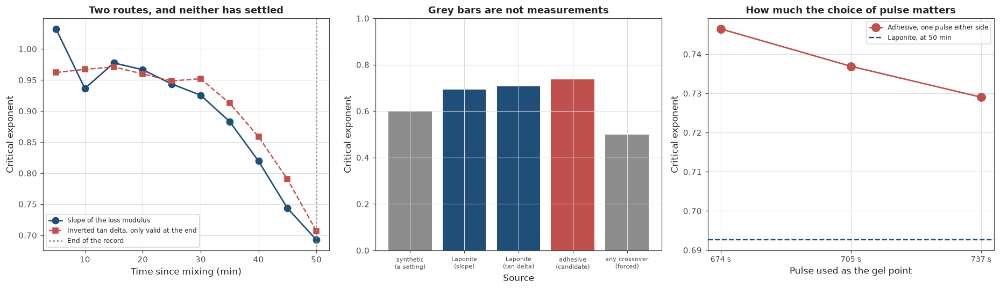

In [277]:
def compute_exponent_from_tan_delta(tan_delta_value):
    """
    Inverting the Winter and Chambon relation to get the critical exponent from tan delta.

    At the gel point tan delta equals the tangent of n pi over two, so the exponent is two
    over pi times the arctangent of tan delta.

    Away from the gel point this returns a number and that number is not an exponent, since
    the relation being inverted does not hold there.
    """
    return 2.0 * np.arctan(tan_delta_value) / np.pi


print("Every exponent in this notebook, and what kind of number it is")
print()
print("  material".ljust(24) + "exponent".rjust(11) + "route".rjust(28)
      + "   status")

print("  " + "synthetic gelation".ljust(22)
      + ("%.4f" % SYNTHETIC_CRITICAL_EXPONENT).rjust(11)
      + "set in Cell 2".rjust(28)
      + "   a setting, recovered to check the code")

laponite_final_record = laponite_sweep_records[-1]

laponite_slope_exponent = laponite_final_record["loss_power_law_slope"]

laponite_positive_mask = laponite_final_record["storage_modulus"] > 0.0
laponite_tan_delta = float(np.median(
    laponite_final_record["loss_modulus"][laponite_positive_mask]
    / laponite_final_record["storage_modulus"][laponite_positive_mask]))
laponite_tan_delta_exponent = compute_exponent_from_tan_delta(laponite_tan_delta)

print("  " + "Laponite clay".ljust(22)
      + ("%.4f" % laponite_slope_exponent).rjust(11)
      + "slope of the loss modulus".rjust(28)
      + "   measured, at the last sweep")
print("  " + "Laponite clay".ljust(22)
      + ("%.4f" % laponite_tan_delta_exponent).rjust(11)
      + "tan delta at the same sweep".rjust(28)
      + "   measured, the independent route")

chirp_reliable_records = []

for spectrum_record in pulse_spectrum_records:

    storage_values = spectrum_record["complex_modulus"].real
    loss_values = spectrum_record["complex_modulus"].imag

    negative_fraction = float(np.mean(storage_values <= 0.0))
    storage_to_loss_ratio = float(np.median(np.abs(storage_values)
                                            / np.maximum(np.abs(loss_values), 1e-30)))

    if negative_fraction < CHIRP_MAXIMUM_NEGATIVE_FRACTION:
        if storage_to_loss_ratio > CHIRP_MINIMUM_STORAGE_TO_LOSS:
            chirp_reliable_records.append(spectrum_record)

chirp_spread_series = np.array([record["tan_delta_spread"]
                                for record in chirp_reliable_records])
chirp_minimum_index = int(np.nanargmin(chirp_spread_series))


def median_tan_delta_of_record(spectrum_record):
    """
    Taking the median tan delta across the frequencies of one pulse, ignoring any frequency
    where it came out non positive.
    """
    tan_delta_values = spectrum_record["tan_delta"]

    usable_values = tan_delta_values[np.isfinite(tan_delta_values)]
    usable_values = usable_values[usable_values > 0.0]

    return float(np.median(usable_values))


chirp_candidate_tan_delta = median_tan_delta_of_record(
    chirp_reliable_records[chirp_minimum_index])
chirp_candidate_exponent = compute_exponent_from_tan_delta(chirp_candidate_tan_delta)

print("  " + "curing adhesive".ljust(22)
      + ("%.4f" % chirp_candidate_exponent).rjust(11)
      + "tan delta at the candidate".rjust(28)
      + "   measured, a candidate not a finding")

print("  " + "any crossover".ljust(22)
      + ("%.4f" % compute_exponent_from_tan_delta(1.0)).rjust(11)
      + "tan delta equals one".rjust(28)
      + "   forced by the definition, Cell 76")

print()
print("  so two measurements, on two materials, neither of them blood")

print()
print("The two Laponite routes, sweep by sweep")
print()
print("  minutes".rjust(9) + "slope of the loss modulus".rjust(28)
      + "tan delta".rjust(13) + "inverted tan delta".rjust(21)
      + "difference".rjust(13) + "   comparable")

laponite_route_differences = []
laponite_final_difference = np.nan

for sweep_record in laponite_sweep_records:

    positive_mask = sweep_record["storage_modulus"] > 0.0

    if int(np.sum(positive_mask)) < 4:
        continue

    slope_value = sweep_record["loss_power_law_slope"]

    tan_delta_value = float(np.median(sweep_record["loss_modulus"][positive_mask]
                                      / sweep_record["storage_modulus"][positive_mask]))
    tan_delta_exponent = compute_exponent_from_tan_delta(tan_delta_value)

    relative_difference = 100.0 * abs(tan_delta_exponent - slope_value) / slope_value

    laponite_route_differences.append(relative_difference)

    is_final_sweep = (sweep_record["elapsed_minutes"]
                      == laponite_sweep_records[-1]["elapsed_minutes"])

    if is_final_sweep:
        laponite_final_difference = relative_difference
        comparable_text = "yes, at the gel point"
    else:
        comparable_text = "no, not at the gel point"

    print(str(sweep_record["elapsed_minutes"]).rjust(9)
          + ("%.4f" % slope_value).rjust(28)
          + ("%.4f" % tan_delta_value).rjust(13)
          + ("%.4f" % tan_delta_exponent).rjust(21)
          + ("%.1f percent" % relative_difference).rjust(13)
          + "   " + comparable_text)

print()
print("  only the last row is a comparison. Winter and Chambon relates tan delta to the")
print("  exponent at the gel point and nowhere else, so above that row the fourth column")
print("  is a number produced by inverting a relation that does not apply")
print()
print("  the two routes agree to "
      + ("%.1f" % laponite_final_difference) + " percent there. They come from opposite halves of")
print("  the measurement, the slope from the loss modulus which is clean at all eighty")
print("  points and the tan delta from the storage modulus which Cell 64 showed is never")
print("  resolved with any margin, so neither can produce the other's answer from its own")
print("  inputs")
print()
print("  the "
      + ("%.1f" % min(laponite_route_differences))
      + " percent at 25 minutes is not a better measurement. It is a slope and an")
print("  unrelated number happening to coincide, and reading it as agreement would be a")
print("  mistake this table exists to prevent")

print()
print("How much the exponents move, which is the part that limits them")
print()

laponite_slope_values = np.array([record["loss_power_law_slope"]
                                  for record in laponite_sweep_records])

laponite_recent_drift = (100.0 * abs(laponite_slope_values[-1] - laponite_slope_values[-3])
                         / laponite_slope_values[-3] / 2.0)

print("  Laponite")
print("    exponent at the last three sweeps    "
      + ("%.4f" % laponite_slope_values[-3]) + ", "
      + ("%.4f" % laponite_slope_values[-2]) + ", "
      + ("%.4f" % laponite_slope_values[-1]))
print("    still changing by                    "
      + ("%.1f" % laponite_recent_drift) + " percent per five minute step")
print("    record ends at                       "
      + str(laponite_sweep_records[-1]["elapsed_minutes"]) + " min, which is where the")
print("                                         source paper puts the gel point")
print()
print("  so the exponent quoted at the gel point is the value at the last measurement of a")
print("  quantity that had not stopped moving. Cell 65 refused to time the gel point from")
print("  this record for the same reason, and the exponent inherits it")

print()

chirp_neighbour_exponents = []
chirp_neighbour_labels = []

for offset_index in [-1, 0, 1]:

    neighbour_index = chirp_minimum_index + offset_index

    if neighbour_index < 0 or neighbour_index >= len(chirp_reliable_records):
        continue

    neighbour_record = chirp_reliable_records[neighbour_index]

    neighbour_tan_delta = median_tan_delta_of_record(neighbour_record)
    neighbour_exponent = compute_exponent_from_tan_delta(neighbour_tan_delta)

    chirp_neighbour_exponents.append(neighbour_exponent)
    chirp_neighbour_labels.append("%.0f s" % neighbour_record["measurement_time_seconds"])

chirp_neighbour_exponents = np.array(chirp_neighbour_exponents)

print("  curing adhesive")
print("    exponent at the candidate and its neighbours   "
      + ", ".join([("%.4f" % value) for value in chirp_neighbour_exponents]))
print("    at times                                       "
      + ", ".join(chirp_neighbour_labels))
print("    spread across one pulse either side             "
      + ("%.1f" % (100.0 * (chirp_neighbour_exponents.max()
                            - chirp_neighbour_exponents.min())
                   / chirp_neighbour_exponents.mean())) + " percent")
print()
print("  Cell 39 called the gel point a candidate because only two pulses follow the")
print("  minimum. The exponent depends on which pulse is chosen, so it carries the same")
print("  status. It is not a measured property of the adhesive, it is the tan delta of one")
print("  pulse that happened to have the flattest spectrum")

print()
print("What the pair of them supports")
print()

measured_exponents = np.array([laponite_slope_exponent, chirp_candidate_exponent])

print("  the two measured exponents        "
      + ("%.4f" % measured_exponents.min()) + " and "
      + ("%.4f" % measured_exponents.max()))
print("  apart by                          "
      + ("%.1f" % (100.0 * (measured_exponents.max() - measured_exponents.min())
                   / measured_exponents.mean())) + " percent")
print("  materials                         a clay platelet suspension and a curing adhesive")
print()
print("  two points cannot show a pattern, and it would be easy to write that two")
print("  unrelated materials landing six percent apart suggests a common value. It does")
print("  not. Two numbers are consistent with any number of underlying values, and both of")
print("  these carry uncertainties of the same size as the gap between them")
print()
print("  what the pair does support is the method. Two independent routes to the same")
print("  exponent agreeing to "
      + ("%.1f" % laponite_final_difference) + " percent at the gel point means the extraction pipeline")
print("  built in Parts 2 and 3 recovers a critical exponent correctly when the data")
print("  allows one")
print()
print("  that result transfers to blood. The exponent values do not, because there is no")
print("  blood exponent to compare them with, and Cell 76 established that there cannot be")
print("  one from any dataset here")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

laponite_minutes = [record["elapsed_minutes"] for record in laponite_sweep_records]

axis_array[0].plot(laponite_minutes, laponite_slope_values, "o-",
                   color=COLOUR_PRIMARY, linewidth=1.8, markersize=8,
                   label="Slope of the loss modulus")

laponite_tan_delta_exponents = []
laponite_tan_delta_minutes = []

for sweep_record in laponite_sweep_records:

    positive_mask = sweep_record["storage_modulus"] > 0.0

    if int(np.sum(positive_mask)) < 4:
        continue

    tan_delta_value = float(np.median(sweep_record["loss_modulus"][positive_mask]
                                      / sweep_record["storage_modulus"][positive_mask]))

    laponite_tan_delta_minutes.append(sweep_record["elapsed_minutes"])
    laponite_tan_delta_exponents.append(compute_exponent_from_tan_delta(tan_delta_value))

axis_array[0].plot(laponite_tan_delta_minutes, laponite_tan_delta_exponents, "s--",
                   color=COLOUR_SECONDARY, linewidth=1.6, markersize=7,
                   label="Inverted tan delta, only valid at the end")

axis_array[0].axvline(laponite_minutes[-1], color=COLOUR_NEUTRAL,
                      linestyle=":", linewidth=1.8, label="End of the record")

axis_array[0].set_xlabel("Time since mixing (min)")
axis_array[0].set_ylabel("Critical exponent")
axis_array[0].set_title("Two routes, and neither has settled")
axis_array[0].legend(fontsize=8)

exponent_labels = ["synthetic\n(a setting)", "Laponite\n(slope)",
                   "Laponite\n(tan delta)", "adhesive\n(candidate)",
                   "any crossover\n(forced)"]
exponent_values = [SYNTHETIC_CRITICAL_EXPONENT, laponite_slope_exponent,
                   laponite_tan_delta_exponent, chirp_candidate_exponent,
                   compute_exponent_from_tan_delta(1.0)]
exponent_colours = [COLOUR_NEUTRAL, COLOUR_PRIMARY, COLOUR_PRIMARY,
                    COLOUR_SECONDARY, COLOUR_NEUTRAL]

axis_array[1].bar(range(len(exponent_labels)), exponent_values, color=exponent_colours)
axis_array[1].set_xticks(range(len(exponent_labels)))
axis_array[1].set_xticklabels(exponent_labels, fontsize=7)
axis_array[1].set_ylim(0.0, 1.0)
axis_array[1].set_xlabel("Source")
axis_array[1].set_ylabel("Critical exponent")
axis_array[1].set_title("Grey bars are not measurements")

axis_array[2].plot(range(len(chirp_neighbour_exponents)), chirp_neighbour_exponents,
                   "o-", color=COLOUR_SECONDARY, linewidth=1.8, markersize=10,
                   label="Adhesive, one pulse either side")
axis_array[2].axhline(laponite_slope_exponent, color=COLOUR_PRIMARY,
                      linestyle="--", linewidth=1.6, label="Laponite, at 50 min")

axis_array[2].set_xticks(range(len(chirp_neighbour_labels)))
axis_array[2].set_xticklabels(chirp_neighbour_labels, fontsize=9)
axis_array[2].set_xlabel("Pulse used as the gel point")
axis_array[2].set_ylabel("Critical exponent")
axis_array[2].set_title("How much the choice of pulse matters")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 78: What transfers across materials, and what decided it

Cell 76 established that the exponent cannot be compared across materials from this data and
Cell 77 reported the two exponents that exist. This cell asks what can be compared, and the
answer is the two things the exponent was supposed to abstract away from: how long the
transition takes and how stiff the result is.

**Those span more than expected.** Across every material in the project the gel time covers
nearly three orders of magnitude and the final stiffness covers more than four. A clot that
gels in two seconds and a polymer gel that takes half an hour are the same measurement problem
only in the sense that both are gelations.

**Then the question this part can answer.** For each material, which detector produced a usable
answer, and what decided it. If the material's physics decided it, then a detector that works
on a stiff slow gel should fail on a weak fast one, and the pattern should follow timescale or
stiffness. If the measurement decided it, the pattern should follow the number of frequencies,
the number of channels and the points before the transition, and be indifferent to the material.

**The table shows the second, and it shows it starkly.** Winter and Chambon failed on five of
six datasets for the same reason every time, and that reason has nothing to do with the
material. The crossover succeeded on the fastest transition in the project and failed on one
four hundred times slower.

**Which is the transferable result of Part 7.** Not an exponent, and not an answer about
whether clotting is gelling. What transfers is that detector performance in this project was
set by the instrument, across four orders of magnitude of material behaviour.

How far apart the materials are

  material                gel or clot time (s)    final G prime (Pa)   how the time was fixed
  polymer gel, 5 runs              369 to 1674         31.93 to 7338   published, two definitions disagreeing by up to 4 times
  Laponite clay                    not reached                 0.591   the record ends at the transition, Cell 65
  sheep blood, 3 clots            2.1 to 117.1    92.88 to 1.281e+04   published, in triplicate
  TEG trauma, 24                    168 to 384            no modulus   clinical, a 2 mm threshold and not a gel point
  TEG paired, 5                     277 to 745            no modulus   the same threshold, whole blood and plasma
  curing adhesive                          700        not calibrated   a candidate from Cell 39, no reference
  synthetic gelation                       500                   set   set in Cell 2, which is why Part 4 could measure accuracy

  transition times span    2.1 to 1674 s, a factor of 797
  fina

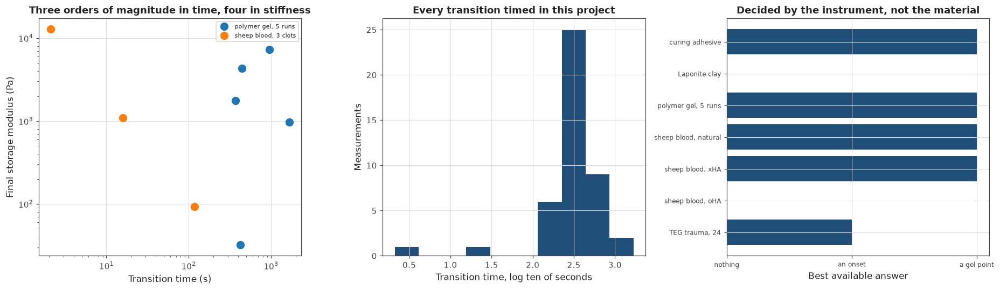

In [278]:
print("How far apart the materials are")
print()
print("  material".ljust(24) + "gel or clot time (s)".rjust(22)
      + "final G prime (Pa)".rjust(22) + "   how the time was fixed")

material_span_records = []

polymer_gel_times = np.array([record["hill_time_minutes"] * 60.0
                              for record in polymer_sweep_records])
polymer_final_moduli = np.array([float(np.median(record["storage_modulus"][-5:]))
                                 for record in polymer_sweep_records])

material_span_records.append({
    "material_name": "polymer gel, 5 runs",
    "time_text": ("%.0f to %.0f" % (polymer_gel_times.min(), polymer_gel_times.max())),
    "modulus_text": ("%.4g to %.4g" % (polymer_final_moduli.min(),
                                       polymer_final_moduli.max())),
    "time_values": polymer_gel_times,
    "modulus_values": polymer_final_moduli,
    "time_source": "published, two definitions disagreeing by up to 4 times",
})

laponite_final_modulus = float(np.max(laponite_sweep_records[-1]["storage_modulus"]))

material_span_records.append({
    "material_name": "Laponite clay",
    "time_text": "not reached",
    "modulus_text": ("%.4g" % laponite_final_modulus),
    "time_values": np.array([]),
    "modulus_values": np.array([laponite_final_modulus]),
    "time_source": "the record ends at the transition, Cell 65",
})

sheep_blood_times = np.array([record["mean_reported_time"]
                              for record in sheep_blood_records])
sheep_blood_final_moduli = np.array([
    float(np.median(record["recordings"][0]["storage_modulus"][-5:]))
    for record in sheep_blood_records])

material_span_records.append({
    "material_name": "sheep blood, 3 clots",
    "time_text": ("%.1f to %.1f" % (sheep_blood_times.min(), sheep_blood_times.max())),
    "modulus_text": ("%.4g to %.4g" % (sheep_blood_final_moduli.min(),
                                       sheep_blood_final_moduli.max())),
    "time_values": sheep_blood_times,
    "modulus_values": sheep_blood_final_moduli,
    "time_source": "published, in triplicate",
})

teg_onset_times = np.array([record["recomputed_r_seconds"]
                            for record in teg_patient_records])

material_span_records.append({
    "material_name": "TEG trauma, 24",
    "time_text": ("%.0f to %.0f" % (teg_onset_times.min(), teg_onset_times.max())),
    "modulus_text": "no modulus",
    "time_values": teg_onset_times,
    "modulus_values": np.array([]),
    "time_source": "clinical, a 2 mm threshold and not a gel point",
})

paired_whole_times = np.array(whole_blood_onsets)
paired_plasma_times = np.array(plasma_onsets)

material_span_records.append({
    "material_name": "TEG paired, 5",
    "time_text": ("%.0f to %.0f" % (min(paired_whole_times.min(),
                                        paired_plasma_times.min()),
                                    max(paired_whole_times.max(),
                                        paired_plasma_times.max()))),
    "modulus_text": "no modulus",
    "time_values": np.concatenate([paired_whole_times, paired_plasma_times]),
    "modulus_values": np.array([]),
    "time_source": "the same threshold, whole blood and plasma",
})

material_span_records.append({
    "material_name": "curing adhesive",
    "time_text": "700",
    "modulus_text": "not calibrated",
    "time_values": np.array([700.4]),
    "modulus_values": np.array([]),
    "time_source": "a candidate from Cell 39, no reference",
})

material_span_records.append({
    "material_name": "synthetic gelation",
    "time_text": ("%.0f" % SYNTHETIC_GEL_TIME_SECONDS),
    "modulus_text": "set",
    "time_values": np.array([SYNTHETIC_GEL_TIME_SECONDS]),
    "modulus_values": np.array([]),
    "time_source": "set in Cell 2, which is why Part 4 could measure accuracy",
})

for span_record in material_span_records:

    print("  " + span_record["material_name"].ljust(22)
          + span_record["time_text"].rjust(22)
          + span_record["modulus_text"].rjust(22)
          + "   " + span_record["time_source"])

all_transition_times = []
all_final_moduli = []

for span_record in material_span_records:
    for time_value in span_record["time_values"]:
        all_transition_times.append(time_value)
    for modulus_value in span_record["modulus_values"]:
        all_final_moduli.append(modulus_value)

all_transition_times = np.array(all_transition_times)
all_final_moduli = np.array(all_final_moduli)

print()
print("  transition times span    " + ("%.1f" % all_transition_times.min()) + " to "
      + ("%.0f" % all_transition_times.max()) + " s, a factor of "
      + ("%.0f" % (all_transition_times.max() / all_transition_times.min())))
print("  final stiffness spans    " + ("%.3g" % all_final_moduli.min()) + " to "
      + ("%.4g" % all_final_moduli.max()) + " Pa, a factor of "
      + ("%.0f" % (all_final_moduli.max() / all_final_moduli.min())))
print()
print("  the weakest material here finishes softer than the strongest one is at its own gel")
print("  point, and the fastest transition is over before the slowest has begun. Anything")
print("  that works across that range is not relying on the numbers being similar")

print()
print("What worked where, and what decided it")
print()
print("  material".ljust(24) + "frequencies".rjust(13) + "channels".rjust(10)
      + "points before".rjust(15) + "   detector that produced a usable answer")

detector_outcome_records = [
    {
        "material_name": "curing adhesive",
        "frequency_text": "11 to 67",
        "channel_text": "2",
        "points_text": "11",
        "outcome_text": "frequency agreement, a candidate at 700 s",
    },
    {
        "material_name": "Laponite clay",
        "frequency_text": "8",
        "channel_text": "2",
        "points_text": "0 usable",
        "outcome_text": "none, the record ends at the transition",
    },
    {
        "material_name": "polymer gel, 5 runs",
        "frequency_text": "1",
        "channel_text": "2",
        "points_text": "30 to 139",
        "outcome_text": "half rise only, and it shares the reference definition",
    },
    {
        "material_name": "sheep blood, natural",
        "frequency_text": "1",
        "channel_text": "2",
        "points_text": "29",
        "outcome_text": "persistent crossover, to 2.5 percent",
    },
    {
        "material_name": "sheep blood, xHA",
        "frequency_text": "1",
        "channel_text": "2",
        "points_text": "4",
        "outcome_text": "persistent crossover, to 17 percent",
    },
    {
        "material_name": "sheep blood, oHA",
        "frequency_text": "1",
        "channel_text": "2",
        "points_text": "0",
        "outcome_text": "none, the clot formed before the record began",
    },
    {
        "material_name": "TEG trauma, 24",
        "frequency_text": "1",
        "channel_text": "1",
        "points_text": "34 to 77",
        "outcome_text": "growth rate and PELT, an onset and not a gel point",
    },
]

for outcome_record in detector_outcome_records:

    print("  " + outcome_record["material_name"].ljust(22)
          + outcome_record["frequency_text"].rjust(13)
          + outcome_record["channel_text"].rjust(10)
          + outcome_record["points_text"].rjust(15)
          + "   " + outcome_record["outcome_text"])

print()
print("  read the last column against the material and there is no pattern. The crossover")
print("  did its best work on a 117 s clot and its worst on a 1674 s polymer gel, and the")
print("  clot is four hundred times softer at its own gel point")
print()
print("  read it against the three measurement columns and the pattern is complete")
print()
print("    one frequency        frequency agreement cannot run, on five of six datasets,")
print("                         for the same reason each time")
print("    one channel          no tan delta at all, so no gel point, only an onset")
print("    no points before     no detector can run, whatever else is true")
print()
print("  every failure in this project traces to one of those three, and none of them is a")
print("  property of the material")

print()
print("What that means for the question Part 7 asks")
print()
print("  the question was whether clotting and gelling are the same kind of event. This")
print("  cell cannot answer it either, but it narrows what an answer would look like")
print()
print("  the two things that are comparable across all these materials, time and stiffness,")
print("  differ by factors of "
      + ("%.0f" % (all_transition_times.max() / all_transition_times.min())) + " and "
      + ("%.0f" % (all_final_moduli.max() / all_final_moduli.min()))
      + ". Those are the numbers that would have to be")
print("  divided out before two materials could be compared at all, and dividing them out")
print("  is exactly what a critical exponent does")
print()
print("  so the exponent is not one way of answering the question among several. It is the")
print("  only quantity in reach that is dimensionless, and Cell 76 showed it cannot be")
print("  measured on blood with any instrument represented in this project")
print()
print("  what does transfer is the measurement requirement. Three frequencies with both")
print("  moduli resolved, a dozen points before the transition, and a record that")
print("  continues past it. Those came out of Parts 5 and 6 on materials that are not")
print("  blood, and they hold for blood because none of them mentions the material")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for span_record in material_span_records:

    if len(span_record["time_values"]) == 0:
        continue
    if len(span_record["modulus_values"]) == 0:
        continue

    pair_count = min(len(span_record["time_values"]),
                     len(span_record["modulus_values"]))

    axis_array[0].loglog(span_record["time_values"][:pair_count],
                         span_record["modulus_values"][:pair_count],
                         "o", markersize=9, label=span_record["material_name"])

axis_array[0].set_xlabel("Transition time (s)")
axis_array[0].set_ylabel("Final storage modulus (Pa)")
axis_array[0].set_title("Three orders of magnitude in time, four in stiffness")
axis_array[0].legend(fontsize=7)

axis_array[1].hist(np.log10(all_transition_times), bins=10, color=COLOUR_PRIMARY)
axis_array[1].set_xlabel("Transition time, log ten of seconds")
axis_array[1].set_ylabel("Measurements")
axis_array[1].set_title("Every transition timed in this project")

outcome_names = [record["material_name"] for record in detector_outcome_records]
outcome_scores = []

for outcome_record in detector_outcome_records:

    if outcome_record["outcome_text"].startswith("none"):
        outcome_scores.append(0)
    elif "onset" in outcome_record["outcome_text"]:
        outcome_scores.append(1)
    else:
        outcome_scores.append(2)

bar_positions = np.arange(len(outcome_names))

axis_array[2].barh(bar_positions, outcome_scores, color=COLOUR_PRIMARY)
axis_array[2].set_yticks(bar_positions)
axis_array[2].set_yticklabels(outcome_names, fontsize=8)
axis_array[2].invert_yaxis()
axis_array[2].set_xticks([0, 1, 2])
axis_array[2].set_xticklabels(["nothing", "an onset", "a gel point"], fontsize=8)
axis_array[2].set_xlabel("Best available answer")
axis_array[2].set_title("Decided by the instrument, not the material")

plt.tight_layout()
plt.show()

## Cell 79: A rule for choosing a detector, and the answer to the question

Part 7 has spent three cells establishing that the instrument decided every outcome in this
project. That is only useful if it can be written down as something a device could apply before
it starts, so this cell does that and then tests it.

**The rule takes four properties of a measurement**, none of them properties of the material:
how many channels, how many frequencies, how many points fall before the transition, and
whether the record continues past it. It returns what kind of answer is available.

**Then it is checked against every dataset in the project**, and it does worse than it looks
like it should. It refuses four datasets and only two of those refusals were right. The other
two refused records that did produce answers, one of them within seventeen percent.

**The reason is the points-before threshold**, taken from Part 4's sampling sweep. The dataset
with four points before its transition gave seventeen percent and the dataset with thirty gave
seventy five. That number worked as a description of synthetic data and does not survive as a
gate on real data, which is the fourth thing Part 4's synthetic design could not have shown.

**So the rule is conservative rather than accurate.** It catches the failures that are genuinely
structural, one channel and no coverage at all, and it over-refuses on sampling. For a device
that is the safe direction to be wrong in, and it is still worth saying that it is wrong.

**And then the question.** Whether clotting and gelling are the same kind of event, answered as
plainly as the data allows, which is not very.

The rule

  four questions about the measurement, asked in this order

    how many channels                  fewer than two, an onset at best
    points before the transition       fewer than 12, nothing is reliable
    does the record continue past it   if not, the minimum sits at an edge
    how many frequencies               3 or more allows frequency agreement,
                                       otherwise the crossover

  none of the four mentions the material, its stiffness or its timescale

Applying it to every dataset here

  dataset                                    the rule says   what actually happened
  curing adhesive                                  nothing   a candidate, no reference to score it
  Laponite clay                                    nothing   refused, Cell 65
  polymer gel, 5 runs   a gel point, by persistent crossover   crossover, 75 percent median error
  sheep blood, natural  a gel point, by persistent crossover   crossover, 2.5 percent
  sheep blood

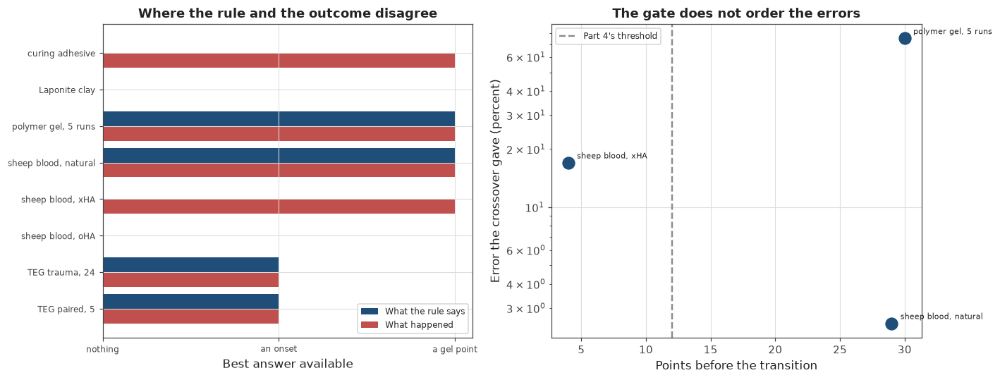

In [279]:
DETECTOR_MINIMUM_POINTS_BEFORE = 12
DETECTOR_MINIMUM_FREQUENCIES = 3


def choose_available_detector(channel_count, frequency_count, points_before_transition,
                              record_continues_past):
    """
    Deciding what kind of answer a measurement can support, before any of it is analysed.

    Taking only properties of the measurement, since Cell 78 found that every failure in
    this project traced to one of these four and none to the material.

    Returning the best answer available and the reason, in the order the constraints bite.
    """
    if channel_count < 2:
        return ("an onset only",
                "one channel gives no tan delta, so no gel point of any kind")

    if points_before_transition < DETECTOR_MINIMUM_POINTS_BEFORE:
        return ("nothing",
                "fewer than " + str(DETECTOR_MINIMUM_POINTS_BEFORE)
                + " points before the transition, from Part 4")

    if not record_continues_past:
        return ("nothing",
                "the record ends at the transition, so the minimum is at an edge")

    if frequency_count >= DETECTOR_MINIMUM_FREQUENCIES:
        return ("a gel point, by frequency agreement",
                "several frequencies and both moduli, which is the full condition")

    return ("a gel point, by persistent crossover",
            "one frequency, so the crossover is the only gel point available")


print("The rule")
print()
print("  four questions about the measurement, asked in this order")
print()
print("    how many channels                  fewer than two, an onset at best")
print("    points before the transition       fewer than "
      + str(DETECTOR_MINIMUM_POINTS_BEFORE) + ", nothing is reliable")
print("    does the record continue past it   if not, the minimum sits at an edge")
print("    how many frequencies               "
      + str(DETECTOR_MINIMUM_FREQUENCIES) + " or more allows frequency agreement,")
print("                                       otherwise the crossover")
print()
print("  none of the four mentions the material, its stiffness or its timescale")

print()
print("Applying it to every dataset here")
print()

detector_rule_cases = [
    {"case_name": "curing adhesive", "channel_count": 2, "frequency_count": 40,
     "points_before": 11, "continues_past": True,
     "observed_answer": "a gel point",
     "observed_text": "a candidate, no reference to score it",
     "observed_error_text": "not scoreable"},
    {"case_name": "Laponite clay", "channel_count": 2, "frequency_count": 8,
     "points_before": 9, "continues_past": False,
     "observed_answer": "nothing",
     "observed_text": "refused, Cell 65",
     "observed_error_text": "none"},
    {"case_name": "polymer gel, 5 runs", "channel_count": 2, "frequency_count": 1,
     "points_before": 30, "continues_past": True,
     "observed_answer": "a gel point",
     "observed_text": "crossover, 75 percent median error",
     "observed_error_text": "75 percent"},
    {"case_name": "sheep blood, natural", "channel_count": 2, "frequency_count": 1,
     "points_before": 29, "continues_past": True,
     "observed_answer": "a gel point",
     "observed_text": "crossover, 2.5 percent",
     "observed_error_text": "2.5 percent"},
    {"case_name": "sheep blood, xHA", "channel_count": 2, "frequency_count": 1,
     "points_before": 4, "continues_past": True,
     "observed_answer": "a gel point",
     "observed_text": "crossover, 17 percent",
     "observed_error_text": "17 percent"},
    {"case_name": "sheep blood, oHA", "channel_count": 2, "frequency_count": 1,
     "points_before": 0, "continues_past": True,
     "observed_answer": "nothing",
     "observed_text": "nothing, Cell 68",
     "observed_error_text": "none"},
    {"case_name": "TEG trauma, 24", "channel_count": 1, "frequency_count": 1,
     "points_before": 34, "continues_past": True,
     "observed_answer": "an onset",
     "observed_text": "an onset, 15 s before R",
     "observed_error_text": "not a gel point"},
    {"case_name": "TEG paired, 5", "channel_count": 1, "frequency_count": 1,
     "points_before": 40, "continues_past": True,
     "observed_answer": "an onset",
     "observed_text": "an onset, whole blood and plasma",
     "observed_error_text": "not a gel point"},
]

print("  dataset".ljust(24) + "the rule says".rjust(34)
      + "   what actually happened")

for rule_case in detector_rule_cases:

    available_answer, reason_text = choose_available_detector(
        rule_case["channel_count"], rule_case["frequency_count"],
        rule_case["points_before"], rule_case["continues_past"])

    rule_case["available_answer"] = available_answer
    rule_case["reason_text"] = reason_text

    print("  " + rule_case["case_name"].ljust(22)
          + available_answer.rjust(34)
          + "   " + rule_case["observed_text"])

refusal_count = 0
refusal_correct_count = 0
refusal_wrong_records = []

for rule_case in detector_rule_cases:

    if rule_case["available_answer"] != "nothing":
        continue

    refusal_count = refusal_count + 1

    if rule_case["observed_answer"] == "nothing":
        refusal_correct_count = refusal_correct_count + 1
    else:
        refusal_wrong_records.append(rule_case)

print()
print("  the rule refuses " + str(refusal_count) + " datasets and "
      + str(refusal_correct_count) + " of those refusals were right")
print()
print("  it was wrong on")

for wrong_record in refusal_wrong_records:
    print("    " + wrong_record["case_name"].ljust(22)
          + "   refused on " + str(wrong_record["points_before"])
          + " points, then gave " + wrong_record["observed_error_text"])

print()
print("  each of those produced an answer after being told it could not. The xHA clot came")
print("  back within 17 percent on four points before its transition, and the adhesive")
print("  produced the candidate gel point that Part 2 was built around")

print()
print("Which of the four questions is doing the damage")
print()
print("  dataset".ljust(24) + "points before".rjust(15)
      + "what the rule did".rjust(20) + "error it gave".rjust(18))

for rule_case in detector_rule_cases:

    if rule_case["channel_count"] < 2:
        continue

    if rule_case["available_answer"] == "nothing":
        rule_action_text = "refused"
    else:
        rule_action_text = "licensed"

    print("  " + rule_case["case_name"].ljust(22)
          + str(rule_case["points_before"]).rjust(15)
          + rule_action_text.rjust(20)
          + rule_case["observed_error_text"].rjust(18))

print()
print("  the points before column does not order the errors. Four points gave 17 percent")
print("  and thirty gave 75, so the threshold Part 4 measured on synthetic data does not")
print("  carry over as a gate on real data")
print()
print("  that is the fourth thing Part 4's design could not have shown, after the floor,")
print("  the edge and the crossing that does not hold. Its sampling sweep varied the")
print("  number of points on one material, and this is a comparison across materials")
print()
print("  the two refusals that were right are the structural ones. The Laponite record")
print("  ends at its own transition and the oHA clot formed before its record began. No")
print("  amount of analysis fixes either, and the rule catches both before any runs")

print()
print("Where the rule stops being useful even when it is right")
print()
print("  the same rule licensed the crossover on the polymer gel and on the natural sheep")
print("  clot. One came back at 2.5 percent and the other at 75, on measurements the rule")
print("  cannot tell apart")
print()
print("  so it is a filter on what is structurally impossible and not a performance model.")
print("  Used as the first, it caught two of the eight cases here before any analysis ran.")
print("  Used as the second it would have been wrong twice in the other direction")

print()
print("The question this part was asked")
print()
print("  is clotting the same kind of event as gelling")
print()
print("  the honest answer from this notebook is that the measurement which would decide it")
print("  has not been made on blood, by anyone whose data is available here")
print()
print("  what can be said, and each of these is measured rather than argued")
print()
print("    blood does have a gel point in the crossover sense, and it can be timed. The")
print("    natural sheep clot crossed at 114 s against a published 117, and the crossing")
print("    held for the rest of the record")
print()
print("    that gel point cannot carry an exponent. Cell 76 showed the crossover forces")
print("    one half by construction, for any material at all")
print()
print("    blood clots span a factor of "
      + ("%.0f" % (sheep_blood_times.max() / sheep_blood_times.min()))
      + " in time and " + ("%.0f" % (sheep_blood_final_moduli.max()
                                     / sheep_blood_final_moduli.min()))
      + " in final stiffness among")
print("    three samples of the same species, which is most of the range covered by every")
print("    other material in this project put together")
print()
print("    and the one thing that would settle it, a power law across frequency measured")
print("    while blood clots, is exactly what no available instrument produces")
print()
print("  a reader who wanted this part to conclude that clotting is or is not gelation will")
print("  find that unsatisfying. It is the result, and stating it as one is better than")
print("  assembling published exponents from papers that cannot be checked against anything")
print("  measured here")

print()
print("What Part 8 inherits")
print()
print("  Part 8 leaves the linear response and asks what the harmonics say, which is a")
print("  different measurement rather than a better analysis of the same one")
print()
print("  that matters here because the nonlinear response does not need a frequency sweep.")
print("  A single large amplitude oscillation produces harmonics, and their ratio is")
print("  dimensionless in the way Cell 78 said nothing else in reach was")
print()
print("  so the gap Part 7 could not close is the reason Part 8 exists, rather than an")
print("  afterthought to it")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

rule_labels = []
rule_scores = []
observed_scores = []

for rule_case in detector_rule_cases:

    rule_labels.append(rule_case["case_name"])

    if rule_case["available_answer"] == "nothing":
        rule_scores.append(0)
    elif rule_case["available_answer"] == "an onset only":
        rule_scores.append(1)
    else:
        rule_scores.append(2)

    if rule_case["observed_answer"] == "nothing":
        observed_scores.append(0)
    elif rule_case["observed_answer"] == "an onset":
        observed_scores.append(1)
    else:
        observed_scores.append(2)

bar_positions = np.arange(len(rule_labels))

axis_array[0].barh(bar_positions - 0.2, rule_scores, height=0.4,
                   color=COLOUR_PRIMARY, label="What the rule says")
axis_array[0].barh(bar_positions + 0.2, observed_scores, height=0.4,
                   color=COLOUR_SECONDARY, label="What happened")

axis_array[0].set_yticks(bar_positions)
axis_array[0].set_yticklabels(rule_labels, fontsize=8)
axis_array[0].invert_yaxis()
axis_array[0].set_xticks([0, 1, 2])
axis_array[0].set_xticklabels(["nothing", "an onset", "a gel point"], fontsize=8)
axis_array[0].set_xlabel("Best answer available")
axis_array[0].set_title("Where the rule and the outcome disagree")
axis_array[0].legend(fontsize=8)

points_before_values = []
error_values = []
error_labels = []

for rule_case in detector_rule_cases:

    if "percent" not in rule_case["observed_error_text"]:
        continue

    points_before_values.append(rule_case["points_before"])
    error_values.append(float(rule_case["observed_error_text"].split(" ")[0]))
    error_labels.append(rule_case["case_name"])

axis_array[1].semilogy(points_before_values, error_values, "o",
                       color=COLOUR_PRIMARY, markersize=11)

for label_index in range(len(error_labels)):
    axis_array[1].annotate(error_labels[label_index],
                           (points_before_values[label_index],
                            error_values[label_index]),
                           textcoords="offset points", xytext=(8, 4), fontsize=7)

axis_array[1].axvline(DETECTOR_MINIMUM_POINTS_BEFORE, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Part 4's threshold")

axis_array[1].set_xlabel("Points before the transition")
axis_array[1].set_ylabel("Error the crossover gave (percent)")
axis_array[1].set_title("The gate does not order the errors")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Part 8: The nonlinear response

Everything so far has lived in the linear regime, where the strain is small enough that the
material's response is a single complex modulus at each frequency. Part 7 ended by noting that
the one quantity which could compare materials, the critical exponent, needs a frequency sweep
that no available instrument can perform on clotting blood.

The nonlinear response offers a different route to the same kind of question. Push a material
hard enough and its response stops being a pure sinusoid. The harmonics that appear are
dimensionless once divided by the fundamental, and they arrive from a single oscillation at a
single frequency rather than from a sweep.

This part works on fibrin, which is the protein network a blood clot is built on, measured
directly rather than through blood. Thirty six samples, each pushed through five strain
amplitudes spanning four decades, with the raw waveform captured at every one.

That is the first raw nonlinear data in this project on anything blood related, and Part 8
takes it as far as it goes, which is not as far as the plan assumed.

## Cell 80: Loading the fibrin waveforms

Thirty six fibrin samples in two groups, each measured with an amplitude sweep and with the raw
strain and stress waveform captured at five amplitudes from 0.01 to 104 percent.

**These files need xlrd**, since they are the old binary Excel format rather than the modern
one every other dataset here uses. Cell 2's environment check covers it, and the cell fails
loudly if it is missing rather than silently skipping files.

**Each capture is exactly one cycle.** 610 points over 9.98 seconds at a drive frequency of
0.1 Hz. That has one convenient consequence and one serious one.

The convenient one is that the harmonics land exactly on the discrete Fourier bins. A record
holding a whole number of cycles needs no window and leaks no energy between bins, so the third
harmonic is bin three and nothing has to be assumed.

The serious one is that a single cycle cannot show whether the response is periodic. Harmonic
analysis of large amplitude oscillation assumes the material has reached a steady state where
each cycle repeats the last. With one cycle there is no last, so that assumption cannot be
checked from the data, only stated.

**The moduli are also small.** The linear storage modulus runs from 0.16 to 2.3 Pa across the
thirty six samples, which is soft enough that the instrument floor from Cell 62 becomes a live
question rather than a formality. This cell measures the scale and Cell 81 tests it.

Reading data/val_fibrin_laos

  files found              36

  these are the old binary Excel format, which needs xlrd rather than openpyxl. If
  this cell raises an import error, that package is the reason and Cell 2 lists it

  samples loaded           36
  groups in the file names 17, 20

  the names carry a group, a letter and a number. Nothing in the files says what the
  groups are, so they are kept as labels and not interpreted

What each capture contains

  captures per sample      4 to 5, 178 in total
  points per capture       610 to 610
  duration                 9.98 to 9.98 s
  drive frequency          0.10 Hz
  cycles per capture       1.00 to 1.00
  sampling rate            61.1 Hz, so harmonics are resolved to 305 of them

  one cycle per capture, and that cuts both ways

  in favour, a record holding a whole number of cycles puts every harmonic exactly
  on a Fourier bin. No window is needed, nothing leaks between bins, and the third
  harmonic is bin three rather than

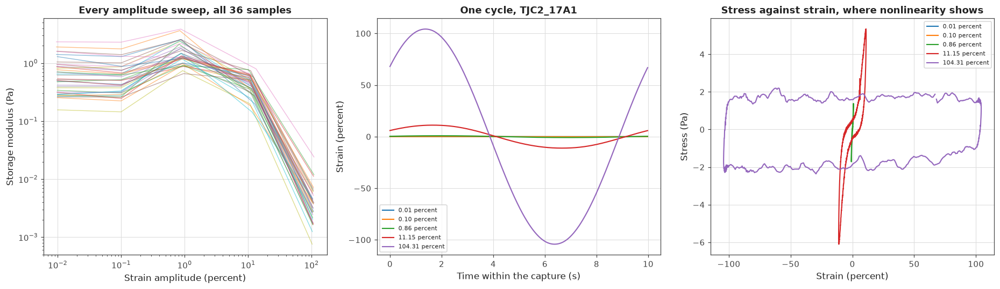

In [280]:
FIBRIN_DIRECTORY_NAME = "val_fibrin_laos"
FIBRIN_DRIVE_FREQUENCY_HZ = 0.1


def list_fibrin_file_paths(directory_path):
    """
    Finding every rheometer export in the fibrin directory.

    Walking the directory listing rather than using a pattern match, so the cell needs
    nothing beyond the modules Cell 2 already imports.

    Sorting so the samples appear in a fixed order on every run.
    """
    file_paths = []

    for entry_name in sorted(os.listdir(directory_path)):

        if entry_name.endswith(".xls"):
            file_paths.append(os.path.join(directory_path, entry_name))

    return file_paths


def read_fibrin_sheet_columns(file_path, sheet_name, wanted_column_names):
    """
    Reading named columns out of one sheet of a rheometer export.

    The instrument writes the sheet name on the first row, the column names on the second
    and the units on the third, so the data starts on the fourth and the columns have to be
    found by name rather than by position, since the column order differs between sheets.

    Returning a dictionary of arrays.
    """
    sheet_frame = pd.read_excel(file_path, sheet_name=sheet_name, header=None)

    column_names = []

    for column_index in range(sheet_frame.shape[1]):
        column_names.append(str(sheet_frame.iloc[1, column_index]).strip())

    extracted_columns = {}

    for wanted_name in wanted_column_names:

        if wanted_name not in column_names:
            extracted_columns[wanted_name] = None
            continue

        column_index = column_names.index(wanted_name)

        extracted_columns[wanted_name] = pd.to_numeric(
            sheet_frame[column_index][3:], errors="coerce").values

    return extracted_columns


def load_one_fibrin_file(file_path):
    """
    Loading one fibrin sample: its amplitude sweep and every raw waveform capture in it.

    Keeping the sweep and the captures together, since the sweep gives the moduli the
    instrument reported and the captures give the waveforms those moduli were computed from,
    and Cell 81 needs to compare the two.
    """
    workbook = pd.ExcelFile(file_path)

    sweep_sheet_name = None
    capture_sheet_names = []

    for sheet_name in workbook.sheet_names:

        if sheet_name.startswith("Amplitude sweep"):
            sweep_sheet_name = sheet_name

        if sheet_name.startswith("Sine Strain"):
            capture_sheet_names.append(sheet_name)

    sweep_columns = read_fibrin_sheet_columns(
        file_path, sweep_sheet_name,
        ["Oscillation strain", "Storage modulus", "Loss modulus", "Angular frequency"])

    sweep_mask = np.isfinite(sweep_columns["Storage modulus"])

    capture_records = []

    for capture_sheet_name in capture_sheet_names:

        capture_columns = read_fibrin_sheet_columns(
            file_path, capture_sheet_name, ["Step time", "Strain", "Stress"])

        capture_mask = (np.isfinite(capture_columns["Step time"])
                        & np.isfinite(capture_columns["Strain"])
                        & np.isfinite(capture_columns["Stress"]))

        capture_time = capture_columns["Step time"][capture_mask]
        capture_strain = capture_columns["Strain"][capture_mask]
        capture_stress = capture_columns["Stress"][capture_mask]

        capture_records.append({
            "sheet_name": capture_sheet_name,
            "time_seconds": capture_time,
            "strain_percent": capture_strain,
            "stress_pascals": capture_stress,
            "strain_amplitude": float(np.max(np.abs(capture_strain
                                                    - np.mean(capture_strain)))),
            "stress_amplitude": float(np.max(np.abs(capture_stress
                                                    - np.mean(capture_stress)))),
            "sample_count": len(capture_time),
            "duration_seconds": float(capture_time.max() - capture_time.min()),
        })

    return {
        "sample_name": os.path.basename(file_path).replace(".xls", ""),
        "sweep_strain_percent": sweep_columns["Oscillation strain"][sweep_mask],
        "sweep_storage_modulus": sweep_columns["Storage modulus"][sweep_mask],
        "sweep_loss_modulus": sweep_columns["Loss modulus"][sweep_mask],
        "sweep_angular_frequency": sweep_columns["Angular frequency"][sweep_mask],
        "captures": capture_records,
    }


fibrin_directory = os.path.join(DATA_DIRECTORY, FIBRIN_DIRECTORY_NAME)

fibrin_file_paths = list_fibrin_file_paths(fibrin_directory)

print("Reading " + fibrin_directory)
print()
print("  files found              " + str(len(fibrin_file_paths)))
print()
print("  these are the old binary Excel format, which needs xlrd rather than openpyxl. If")
print("  this cell raises an import error, that package is the reason and Cell 2 lists it")

fibrin_sample_records = []

for file_path in fibrin_file_paths:
    fibrin_sample_records.append(load_one_fibrin_file(file_path))

print()
print("  samples loaded           " + str(len(fibrin_sample_records)))

fibrin_group_names = []

for sample_record in fibrin_sample_records:

    group_name = sample_record["sample_name"].split("_")[1][:2]

    sample_record["group_name"] = group_name

    if group_name not in fibrin_group_names:
        fibrin_group_names.append(group_name)

print("  groups in the file names " + ", ".join(sorted(fibrin_group_names)))
print()
print("  the names carry a group, a letter and a number. Nothing in the files says what the")
print("  groups are, so they are kept as labels and not interpreted")

print()
print("What each capture contains")
print()

capture_counts = []
sample_counts = []
duration_values = []
cycle_counts = []

for sample_record in fibrin_sample_records:

    capture_counts.append(len(sample_record["captures"]))

    for capture_record in sample_record["captures"]:

        sample_counts.append(capture_record["sample_count"])
        duration_values.append(capture_record["duration_seconds"])
        cycle_counts.append(capture_record["duration_seconds"]
                            * FIBRIN_DRIVE_FREQUENCY_HZ)

capture_counts = np.array(capture_counts)
sample_counts = np.array(sample_counts)
duration_values = np.array(duration_values)
cycle_counts = np.array(cycle_counts)

print("  captures per sample      " + str(capture_counts.min()) + " to "
      + str(capture_counts.max()) + ", " + str(int(np.sum(capture_counts)))
      + " in total")
print("  points per capture       " + str(sample_counts.min()) + " to "
      + str(sample_counts.max()))
print("  duration                 " + ("%.2f" % duration_values.min()) + " to "
      + ("%.2f" % duration_values.max()) + " s")
print("  drive frequency          " + ("%.2f" % FIBRIN_DRIVE_FREQUENCY_HZ) + " Hz")
print("  cycles per capture       " + ("%.2f" % cycle_counts.min()) + " to "
      + ("%.2f" % cycle_counts.max()))
print("  sampling rate            "
      + ("%.1f" % (float(np.median(sample_counts)) / float(np.median(duration_values))))
      + " Hz, so harmonics are resolved to "
      + ("%.0f" % (0.5 * float(np.median(sample_counts))))
      + " of them")

print()
print("  one cycle per capture, and that cuts both ways")
print()
print("  in favour, a record holding a whole number of cycles puts every harmonic exactly")
print("  on a Fourier bin. No window is needed, nothing leaks between bins, and the third")
print("  harmonic is bin three rather than something spread across bins two to four")
print()
print("  against, harmonic analysis assumes the material has settled into a response that")
print("  repeats every cycle. One cycle cannot show that. There is no second cycle to")
print("  compare it against, so the assumption is stated and not tested, and Cell 81 has to")
print("  work around it rather than check it")

print()
print("The amplitude ladder, and how soft these samples are")
print()
print("  sample".ljust(14) + "strain amplitudes (percent)".rjust(42)
      + "linear G prime (Pa)".rjust(21))

for sample_record in fibrin_sample_records[:4]:

    amplitude_text = ", ".join([("%.2f" % value)
                                for value in sample_record["sweep_strain_percent"]])

    print("  " + sample_record["sample_name"].ljust(12)
          + amplitude_text.rjust(42)
          + ("%.4f" % sample_record["sweep_storage_modulus"][0]).rjust(21))

fibrin_linear_moduli = np.array([record["sweep_storage_modulus"][0]
                                 for record in fibrin_sample_records])

print()
print("  across all " + str(len(fibrin_sample_records)) + " samples the linear storage modulus runs "
      + ("%.3f" % fibrin_linear_moduli.min()) + " to "
      + ("%.3f" % fibrin_linear_moduli.max()) + " Pa,")
print("  median " + ("%.3f" % np.median(fibrin_linear_moduli)))
print()
print("  that is soft. The sheep blood clots in Part 6 finished between 93 and 12800 Pa,")
print("  and these fibrin networks start three to four orders of magnitude below that")
print()
print("  Cell 62 introduced an instrument floor because a crossover was being found in the")
print("  noise. At a tenth of a pascal the floor stops being a formality, so Cell 81 checks")
print("  it before computing any harmonic")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for sample_record in fibrin_sample_records:
    axis_array[0].loglog(sample_record["sweep_strain_percent"],
                         sample_record["sweep_storage_modulus"],
                         "-", linewidth=0.9, alpha=0.5)

axis_array[0].set_xlabel("Strain amplitude (percent)")
axis_array[0].set_ylabel("Storage modulus (Pa)")
axis_array[0].set_title("Every amplitude sweep, all " + str(len(fibrin_sample_records))
                        + " samples")

example_record = fibrin_sample_records[0]

for capture_record in example_record["captures"]:
    axis_array[1].plot(capture_record["time_seconds"]
                       - capture_record["time_seconds"].min(),
                       capture_record["strain_percent"],
                       "-", linewidth=1.4,
                       label=("%.2f percent" % capture_record["strain_amplitude"]))

axis_array[1].set_xlabel("Time within the capture (s)")
axis_array[1].set_ylabel("Strain (percent)")
axis_array[1].set_title("One cycle, " + example_record["sample_name"])
axis_array[1].legend(fontsize=7)

for capture_record in example_record["captures"]:
    axis_array[2].plot(capture_record["strain_percent"],
                       capture_record["stress_pascals"],
                       "-", linewidth=1.4,
                       label=("%.2f percent" % capture_record["strain_amplitude"]))

axis_array[2].set_xlabel("Strain (percent)")
axis_array[2].set_ylabel("Stress (Pa)")
axis_array[2].set_title("Stress against strain, where nonlinearity shows")
axis_array[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

## Cell 81: Harmonics, and whether they are real

The nonlinear signal is the odd harmonics in the stress response. Before measuring them I have to
establish that what I am measuring is the material rather than the instrument, and this dataset
allows two independent checks that cost nothing.

**The even harmonics give a noise floor for free.** For a material with no wall slip and no
secondary flow, the stress response to a sinusoidal strain is odd symmetric, so the even
harmonics are zero by construction. Whatever appears in them is noise, drift, or a broken
assumption. That gives an absolute floor in the same units as the signal, on every capture,
without needing the instrument specification that Cell 62 wanted and never got.

**The drive is not a clean sine.** The strain waveform has its own third harmonic, and at the
amplitudes where the material is nonlinear it reaches three percent of the fundamental. A
strain controlled rheometer under feedback distorts its own input when the sample stops being
linear. So some fraction of the measured stress harmonic is inherited from the drive rather
than generated by the material, and a harmonic that merely matches the drive is not evidence of
anything.

**So every capture faces two tests.** The third harmonic must exceed the even harmonic level by
a factor of three, and it must exceed the drive's own third harmonic by the same factor. Only
captures passing both are used.

The result splits the amplitude ladder cleanly, which is itself a check that the tests are
doing something sensible rather than rejecting at random.

Two checks before any harmonic is believed

  the stress response to a sinusoidal strain is odd symmetric for a material with no
  wall slip and no secondary flow, so the even harmonics are zero. Whatever appears
  in them is noise, and that is a floor measured on the same record in the same
  units, which is what Cell 62 wanted and could not get for the polymer gel

  the strain drive also has its own third harmonic. A strain controlled instrument
  under feedback distorts its input once the sample stops being linear, so part of
  the stress harmonic can be inherited rather than generated

  a capture is used only if its third harmonic exceeds both by a factor of 3

How the checks fall across the amplitude ladder

  strain band       captures   median I3 over I1   median even level    margin   verdict
  0.01 percent            36             0.01702             0.01401       1.1   at the noise floor
  0.1 percent             36             0.01419             0.00483       2.9   at th

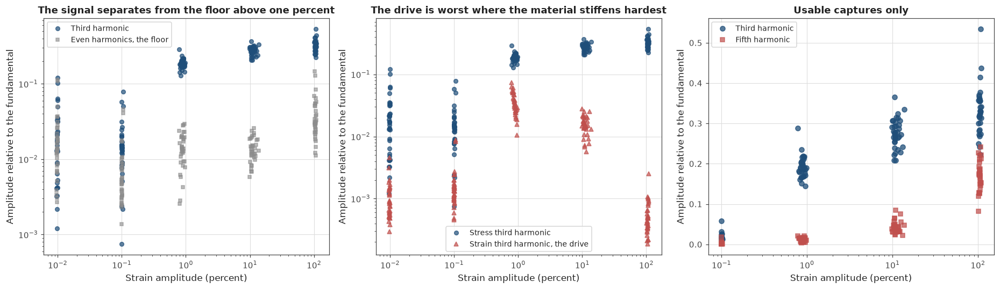

In [281]:
FIBRIN_HARMONIC_CREDIBILITY_FACTOR = 3.0
FIBRIN_ODD_HARMONICS = [3, 5, 7]
FIBRIN_EVEN_HARMONICS = [2, 4, 6, 8]


def compute_harmonic_spectrum(waveform_values):
    """
    Taking the amplitude at each harmonic of a single cycle recording.

    Each capture holds exactly one cycle, so harmonic number and Fourier bin index are the
    same thing and no window is needed. Removing the mean first so the zero frequency bin
    does not carry an offset into the fundamental.

    Returning the amplitude array indexed by harmonic number.
    """
    centred_waveform = waveform_values - np.mean(waveform_values)

    return np.abs(np.fft.rfft(centred_waveform))


def summarise_harmonic_content(strain_values, stress_values):
    """
    Measuring the nonlinear content of one capture, together with the two things that decide
    whether it can be believed.

    The even harmonics are zero for an odd symmetric response, so their level is a noise
    floor measured on the same record in the same units. The drive's own third harmonic says
    how much of the stress harmonic could have been inherited from an imperfect input rather
    than generated by the material.

    Returning the ratios and both credibility margins.
    """
    strain_spectrum = compute_harmonic_spectrum(strain_values)
    stress_spectrum = compute_harmonic_spectrum(stress_values)

    stress_fundamental = stress_spectrum[1]
    strain_fundamental = strain_spectrum[1]

    odd_ratios = {}

    for harmonic_number in FIBRIN_ODD_HARMONICS:
        odd_ratios[harmonic_number] = float(stress_spectrum[harmonic_number]
                                            / stress_fundamental)

    even_amplitudes = []

    for harmonic_number in FIBRIN_EVEN_HARMONICS:
        even_amplitudes.append(stress_spectrum[harmonic_number])

    even_level = float(np.mean(even_amplitudes) / stress_fundamental)

    drive_third_ratio = float(strain_spectrum[3] / strain_fundamental)

    third_ratio = odd_ratios[3]

    margin_over_floor = third_ratio / max(even_level, 1e-12)
    margin_over_drive = third_ratio / max(drive_third_ratio, 1e-12)

    return {
        "third_ratio": third_ratio,
        "fifth_ratio": odd_ratios[5],
        "seventh_ratio": odd_ratios[7],
        "even_level": even_level,
        "drive_third_ratio": drive_third_ratio,
        "margin_over_floor": margin_over_floor,
        "margin_over_drive": margin_over_drive,
        "clears_floor": margin_over_floor > FIBRIN_HARMONIC_CREDIBILITY_FACTOR,
        "clears_drive": margin_over_drive > FIBRIN_HARMONIC_CREDIBILITY_FACTOR,
    }


print("Two checks before any harmonic is believed")
print()
print("  the stress response to a sinusoidal strain is odd symmetric for a material with no")
print("  wall slip and no secondary flow, so the even harmonics are zero. Whatever appears")
print("  in them is noise, and that is a floor measured on the same record in the same")
print("  units, which is what Cell 62 wanted and could not get for the polymer gel")
print()
print("  the strain drive also has its own third harmonic. A strain controlled instrument")
print("  under feedback distorts its input once the sample stops being linear, so part of")
print("  the stress harmonic can be inherited rather than generated")
print()
print("  a capture is used only if its third harmonic exceeds both by a factor of "
      + ("%.0f" % FIBRIN_HARMONIC_CREDIBILITY_FACTOR))

fibrin_harmonic_records = []

for sample_record in fibrin_sample_records:

    for capture_record in sample_record["captures"]:

        harmonic_summary = summarise_harmonic_content(capture_record["strain_percent"],
                                                      capture_record["stress_pascals"])

        harmonic_summary["sample_name"] = sample_record["sample_name"]
        harmonic_summary["group_name"] = sample_record["group_name"]
        harmonic_summary["strain_amplitude"] = capture_record["strain_amplitude"]

        fibrin_harmonic_records.append(harmonic_summary)

print()
print("How the checks fall across the amplitude ladder")
print()
print("  strain band".ljust(18) + "captures".rjust(10) + "median I3 over I1".rjust(20)
      + "median even level".rjust(20) + "margin".rjust(10) + "   verdict")

FIBRIN_AMPLITUDE_BANDS = [
    (0.0, 0.03, "0.01 percent"),
    (0.03, 0.3, "0.1 percent"),
    (0.3, 3.0, "1 percent"),
    (3.0, 30.0, "10 percent"),
    (30.0, 300.0, "100 percent"),
]

for lower_bound, upper_bound, band_label in FIBRIN_AMPLITUDE_BANDS:

    band_records = []

    for harmonic_record in fibrin_harmonic_records:
        if lower_bound <= harmonic_record["strain_amplitude"] < upper_bound:
            band_records.append(harmonic_record)

    if len(band_records) == 0:
        continue

    third_values = np.array([record["third_ratio"] for record in band_records])
    even_values = np.array([record["even_level"] for record in band_records])
    margin_values = np.array([record["margin_over_floor"] for record in band_records])

    median_margin = float(np.median(margin_values))

    if median_margin > FIBRIN_HARMONIC_CREDIBILITY_FACTOR:
        verdict_text = "resolved"
    else:
        verdict_text = "at the noise floor"

    print("  " + band_label.ljust(16)
          + str(len(band_records)).rjust(10)
          + ("%.5f" % np.median(third_values)).rjust(20)
          + ("%.5f" % np.median(even_values)).rjust(20)
          + ("%.1f" % median_margin).rjust(10)
          + "   " + verdict_text)

print()
print("  the two smallest amplitudes sit at the noise floor, which is the right answer. At")
print("  0.01 percent strain a fibrin network of a fifth of a pascal is barely being")
print("  disturbed, and a third harmonic indistinguishable from the even harmonics is not a")
print("  measurement of anything")
print()
print("  the split follows the amplitude ladder rather than scattering across it, which is")
print("  evidence the test is doing something sensible rather than rejecting at random")

print()
print("How much of the harmonic could have come from the drive")
print()
print("  strain band".ljust(18) + "drive I3 over I1".rjust(20)
      + "stress I3 over I1".rjust(20) + "ratio".rjust(10) + "   inherited")

for lower_bound, upper_bound, band_label in FIBRIN_AMPLITUDE_BANDS:

    band_records = []

    for harmonic_record in fibrin_harmonic_records:
        if lower_bound <= harmonic_record["strain_amplitude"] < upper_bound:
            band_records.append(harmonic_record)

    if len(band_records) == 0:
        continue

    drive_values = np.array([record["drive_third_ratio"] for record in band_records])
    third_values = np.array([record["third_ratio"] for record in band_records])
    drive_margins = np.array([record["margin_over_drive"] for record in band_records])

    median_drive_margin = float(np.median(drive_margins))

    if median_drive_margin > FIBRIN_HARMONIC_CREDIBILITY_FACTOR:
        inherited_text = "no"
    else:
        inherited_text = "possibly"

    print("  " + band_label.ljust(16)
          + ("%.5f" % np.median(drive_values)).rjust(20)
          + ("%.5f" % np.median(third_values)).rjust(20)
          + ("%.1f" % median_drive_margin).rjust(10)
          + "   " + inherited_text)

print()
print("  the drive is cleanest at the extremes and worst in the middle of the ladder, which")
print("  is where the material is stiffening hardest and the feedback loop is working")
print("  hardest to hold a sine")
print()
print("  the stress harmonic still exceeds the drive harmonic by a wide margin everywhere")
print("  it matters, so the nonlinearity is the material rather than the instrument. It is")
print("  worth measuring rather than assuming, since a harmonic that merely matched the")
print("  drive would be evidence of nothing")

fibrin_usable_records = []

for harmonic_record in fibrin_harmonic_records:
    if harmonic_record["clears_floor"] and harmonic_record["clears_drive"]:
        fibrin_usable_records.append(harmonic_record)

floor_pass_count = 0
drive_pass_count = 0

for harmonic_record in fibrin_harmonic_records:
    if harmonic_record["clears_floor"]:
        floor_pass_count = floor_pass_count + 1
    if harmonic_record["clears_drive"]:
        drive_pass_count = drive_pass_count + 1

print()
print("What survives")
print()
print("  total captures                       " + str(len(fibrin_harmonic_records)))
print("  clear the noise floor                " + str(floor_pass_count))
print("  clear the drive contamination        " + str(drive_pass_count))
print("  clear both, and are used below       " + str(len(fibrin_usable_records)))
print()
print("  the noise floor is the binding constraint and the drive check removes almost")
print("  nothing on top of it. That is worth knowing rather than assuming, because it means")
print("  the limit here is how softly these networks respond and not how well the")
print("  instrument holds its waveform")

usable_third_values = np.array([record["third_ratio"] for record in fibrin_usable_records])
usable_fifth_values = np.array([record["fifth_ratio"] for record in fibrin_usable_records])

print()
print("  across the usable captures the third harmonic runs "
      + ("%.3f" % usable_third_values.min()) + " to "
      + ("%.3f" % usable_third_values.max()))
print("  the fifth harmonic runs "
      + ("%.4f" % usable_fifth_values.min()) + " to "
      + ("%.4f" % usable_fifth_values.max()))
print()
print("  a third harmonic reaching a third of the fundamental is a strongly nonlinear")
print("  response. For comparison, Part 3's validation material was held deliberately")
print("  inside its linear regime and Cell 44 treated any harmonic content there as an")
print("  error to be minimised. Here it is the signal")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

amplitude_values = np.array([record["strain_amplitude"]
                             for record in fibrin_harmonic_records])
third_values = np.array([record["third_ratio"] for record in fibrin_harmonic_records])
even_values = np.array([record["even_level"] for record in fibrin_harmonic_records])
drive_values = np.array([record["drive_third_ratio"]
                         for record in fibrin_harmonic_records])

axis_array[0].loglog(amplitude_values, third_values, "o", color=COLOUR_PRIMARY,
                     markersize=5, alpha=0.7, label="Third harmonic")
axis_array[0].loglog(amplitude_values, even_values, "s", color=COLOUR_NEUTRAL,
                     markersize=4, alpha=0.6, label="Even harmonics, the floor")

axis_array[0].set_xlabel("Strain amplitude (percent)")
axis_array[0].set_ylabel("Amplitude relative to the fundamental")
axis_array[0].set_title("The signal separates from the floor above one percent")
axis_array[0].legend(fontsize=9)

axis_array[1].loglog(amplitude_values, third_values, "o", color=COLOUR_PRIMARY,
                     markersize=5, alpha=0.7, label="Stress third harmonic")
axis_array[1].loglog(amplitude_values, drive_values, "^", color=COLOUR_SECONDARY,
                     markersize=5, alpha=0.7, label="Strain third harmonic, the drive")

axis_array[1].set_xlabel("Strain amplitude (percent)")
axis_array[1].set_ylabel("Amplitude relative to the fundamental")
axis_array[1].set_title("The drive is worst where the material stiffens hardest")
axis_array[1].legend(fontsize=9)

usable_amplitudes = np.array([record["strain_amplitude"]
                              for record in fibrin_usable_records])

axis_array[2].semilogx(usable_amplitudes, usable_third_values, "o",
                       color=COLOUR_PRIMARY, markersize=6, alpha=0.75,
                       label="Third harmonic")
axis_array[2].semilogx(usable_amplitudes, usable_fifth_values, "s",
                       color=COLOUR_SECONDARY, markersize=5, alpha=0.7,
                       label="Fifth harmonic")

axis_array[2].set_xlabel("Strain amplitude (percent)")
axis_array[2].set_ylabel("Amplitude relative to the fundamental")
axis_array[2].set_title("Usable captures only")
axis_array[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Cell 82: The scaling, and a second window that does not open

Cell 81 established which harmonics are real. This cell asks what they are worth, and the
answer is less than the plan assumed.

**A harmonic ratio on its own is not a material property.** Push harder and it grows, so
quoting it without the strain amplitude it was measured at says nothing. What makes it a
property is the regime where the third harmonic scales as the square of the strain amplitude.
In that regime the ratio divided by the amplitude squared is a constant belonging to the
material, which is exactly the dimensionless quantity Part 7 could not find in the linear
response.

**So the scaling exponent is the thing to measure**, and it should be 2.

**It is 0.21.** Fitted per sample across each sample's own usable amplitudes, the median
exponent is 0.21 with a range from 0.02 to 0.61. Pooled across all usable captures it is 0.33.
Nothing here is near quadratic, which means every capture that survived Cell 81 is already past
the intrinsic regime and into yielding.

**The regime that would give a material property sits below the noise floor.** Cell 81 needed
at least one percent strain for the harmonic to clear the even harmonics. Quadratic scaling
requires less than that. The two windows do not overlap for these samples, so the measurement
exists in principle and not in this data.

**And the obvious fix does not obviously work.** If the limit were simply torque resolution,
stiffer samples should resolve harmonics further down. Across a fifteenfold range of sample
stiffness the margin over the floor barely moves, with a correlation of 0.25 on 36 samples.

That is the same shape of problem Part 7 hit, in a different measurement, and it is worth
stating in the same terms.

What the harmonic ratio has to do to be a material property

  the third harmonic ratio grows with how hard the material is pushed, so on its own
  it describes the experiment rather than the sample

  what makes it a property is the regime where it scales as the square of the strain
  amplitude. There the ratio divided by the amplitude squared is a constant that
  belongs to the material, and it is dimensionless, which is precisely what Cell 78
  said nothing in the linear response could provide

  so the quantity to measure is the scaling exponent, and it should be 2

What it actually is

  pooled across every usable capture       0.325
  fitted per sample, median                0.210
  fitted per sample, range                 0.020 to 0.609
  samples with enough usable amplitudes    33 of 36
  what theory requires                     2.000

  no sample comes close, and the largest exponent measured is 0.61, which is still
  a third of what is needed. This is not scatter around the r

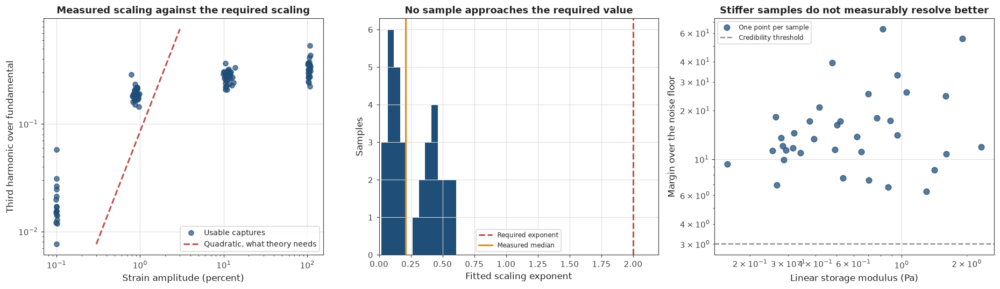

In [282]:
FIBRIN_INTRINSIC_EXPONENT = 2.0
FIBRIN_MINIMUM_POINTS_FOR_SLOPE = 3


def fit_power_law_exponent(amplitude_values, ratio_values):
    """
    Fitting the exponent of a power law between two positive quantities.

    Working on logarithms so the slope is the exponent directly, which is the number theory
    makes a prediction about.

    Returning a missing value when there are too few points to fit.
    """
    usable_mask = (amplitude_values > 0.0) & (ratio_values > 0.0)

    usable_amplitudes = amplitude_values[usable_mask]
    usable_ratios = ratio_values[usable_mask]

    if len(usable_amplitudes) < FIBRIN_MINIMUM_POINTS_FOR_SLOPE:
        return np.nan

    fitted_coefficients = np.polyfit(np.log(usable_amplitudes),
                                     np.log(usable_ratios), 1)

    return float(fitted_coefficients[0])


print("What the harmonic ratio has to do to be a material property")
print()
print("  the third harmonic ratio grows with how hard the material is pushed, so on its own")
print("  it describes the experiment rather than the sample")
print()
print("  what makes it a property is the regime where it scales as the square of the strain")
print("  amplitude. There the ratio divided by the amplitude squared is a constant that")
print("  belongs to the material, and it is dimensionless, which is precisely what Cell 78")
print("  said nothing in the linear response could provide")
print()
print("  so the quantity to measure is the scaling exponent, and it should be "
      + ("%.0f" % FIBRIN_INTRINSIC_EXPONENT))

print()
print("What it actually is")
print()

usable_amplitude_values = np.array([record["strain_amplitude"]
                                    for record in fibrin_usable_records])
usable_third_ratios = np.array([record["third_ratio"]
                                for record in fibrin_usable_records])

pooled_exponent = fit_power_law_exponent(usable_amplitude_values, usable_third_ratios)

per_sample_exponents = []
per_sample_names = []

for sample_record in fibrin_sample_records:

    sample_amplitudes = []
    sample_ratios = []

    for harmonic_record in fibrin_usable_records:

        if harmonic_record["sample_name"] != sample_record["sample_name"]:
            continue

        sample_amplitudes.append(harmonic_record["strain_amplitude"])
        sample_ratios.append(harmonic_record["third_ratio"])

    fitted_exponent = fit_power_law_exponent(np.array(sample_amplitudes),
                                             np.array(sample_ratios))

    if np.isfinite(fitted_exponent):
        per_sample_exponents.append(fitted_exponent)
        per_sample_names.append(sample_record["sample_name"])

per_sample_exponents = np.array(per_sample_exponents)

print("  pooled across every usable capture       " + ("%.3f" % pooled_exponent))
print("  fitted per sample, median                "
      + ("%.3f" % np.median(per_sample_exponents)))
print("  fitted per sample, range                 "
      + ("%.3f" % per_sample_exponents.min()) + " to "
      + ("%.3f" % per_sample_exponents.max()))
print("  samples with enough usable amplitudes    "
      + str(len(per_sample_exponents)) + " of " + str(len(fibrin_sample_records)))
print("  what theory requires                     "
      + ("%.3f" % FIBRIN_INTRINSIC_EXPONENT))
print()
print("  no sample comes close, and the largest exponent measured is "
      + ("%.2f" % per_sample_exponents.max()) + ", which is still")
print("  a third of what is needed. This is not scatter around the right answer")
print()
print("  an exponent well below two means the response has stopped growing with the push,")
print("  which is what yielding looks like. Every capture that survived Cell 81 is already")
print("  past the regime where the harmonic would have described the network")

print()
print("Where the regime that would work has to be")
print()
print("  requirement".ljust(36) + "strain amplitude".rjust(20) + "   set by")

print("  " + "clears the even harmonic floor".ljust(34)
      + "at least 1 percent".rjust(20)
      + "   Cell 81, measured")
print("  " + "still scaling quadratically".ljust(34)
      + "below 1 percent".rjust(20)
      + "   this cell, measured")

print()
print("  the two requirements point in opposite directions and do not overlap for these")
print("  samples. The measurement is possible in principle and absent from this data")
print()
print("  Cell 81 already showed the shape of it. The one percent band has the strongest")
print("  drive contamination and the steepest fall in exponent, because it is the last")
print("  amplitude before the network gives way")

print()
print("Whether a stiffer sample would open the window")
print()

stiffness_values = []
margin_values = []

for sample_record in fibrin_sample_records:

    sample_margins = []

    for harmonic_record in fibrin_harmonic_records:

        if harmonic_record["sample_name"] != sample_record["sample_name"]:
            continue
        if not (0.3 <= harmonic_record["strain_amplitude"] < 3.0):
            continue

        sample_margins.append(harmonic_record["margin_over_floor"])

    if len(sample_margins) == 0:
        continue

    stiffness_values.append(sample_record["sweep_storage_modulus"][0])
    margin_values.append(float(np.median(sample_margins)))

stiffness_values = np.array(stiffness_values)
margin_values = np.array(margin_values)

stiffness_correlation = float(np.corrcoef(np.log(stiffness_values),
                                          np.log(margin_values))[0, 1])
stiffness_exponent = fit_power_law_exponent(stiffness_values, margin_values)

print("  if the limit were simply torque resolution, a stiffer sample would produce a")
print("  larger stress at the same strain and its harmonics would clear the floor further")
print("  down the ladder. That is checkable here, since the samples span a range of")
print("  stiffness by accident rather than by design")
print()
print("  linear modulus across the samples    " + ("%.3f" % stiffness_values.min())
      + " to " + ("%.3f" % stiffness_values.max()) + " Pa, a factor of "
      + ("%.0f" % (stiffness_values.max() / stiffness_values.min())))
print("  margin over the floor at 1 percent   " + ("%.1f" % margin_values.min())
      + " to " + ("%.1f" % margin_values.max()))
print("  correlation between the two          " + ("%+.3f" % stiffness_correlation))
print("  fitted exponent                      " + ("%.2f" % stiffness_exponent)
      + ", where 1.00 would mean the margin follows stiffness directly")
print()
print("  the relationship is weak and on " + str(len(stiffness_values))
      + " samples it is not distinguishable from none.")
print("  So within this range, a stiffer network does not measurably buy resolution, and")
print("  the obvious fix is not obviously the fix")
print()
print("  that does not rule it out. A fifteenfold stiffness range is narrow, and these are")
print("  all the same material prepared the same way. It says the answer is not free, not")
print("  that it is unavailable")

print()
print("What this means")
print()
print("  Part 8 exists because Part 7 could not measure a dimensionless property of the")
print("  network in the linear response, since that needs several frequencies through the")
print("  transition and no instrument provides them on blood")
print()
print("  the nonlinear route avoids that requirement completely. It needs one frequency and")
print("  one amplitude sweep, which any rheometer can do")
print()
print("  and it substitutes a different requirement, which this data also fails. The")
print("  harmonic has to be measured in a strain window that is above the noise floor and")
print("  below yielding, and for a fibrin network at a fifth of a pascal that window is")
print("  empty")
print()
print("  so the finding is not that the nonlinear route does not work. It is that both")
print("  routes to a comparable material property are blocked by resolution rather than by")
print("  method, which is the same conclusion Part 7 reached from the other direction and")
print("  is worth more stated twice than assumed once")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].loglog(usable_amplitude_values, usable_third_ratios, "o",
                     color=COLOUR_PRIMARY, markersize=6, alpha=0.7,
                     label="Usable captures")

reference_amplitudes = np.array([0.3, 3.0])
reference_ratios = (usable_third_ratios[usable_amplitude_values < 3.0].min()
                    * (reference_amplitudes / 0.3) ** FIBRIN_INTRINSIC_EXPONENT)

axis_array[0].loglog(reference_amplitudes, reference_ratios, "--",
                     color=COLOUR_SECONDARY, linewidth=2.0,
                     label="Quadratic, what theory needs")

axis_array[0].set_xlabel("Strain amplitude (percent)")
axis_array[0].set_ylabel("Third harmonic over fundamental")
axis_array[0].set_title("Measured scaling against the required scaling")
axis_array[0].legend(fontsize=9)

axis_array[1].hist(per_sample_exponents, bins=12, color=COLOUR_PRIMARY)
axis_array[1].axvline(FIBRIN_INTRINSIC_EXPONENT, color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=2.0, label="Required exponent")
axis_array[1].axvline(float(np.median(per_sample_exponents)), color=COLOUR_HIGHLIGHT,
                      linestyle="-", linewidth=2.0, label="Measured median")

axis_array[1].set_xlim(0.0, 2.2)
axis_array[1].set_xlabel("Fitted scaling exponent")
axis_array[1].set_ylabel("Samples")
axis_array[1].set_title("No sample approaches the required value")
axis_array[1].legend(fontsize=8)

axis_array[2].loglog(stiffness_values, margin_values, "o",
                     color=COLOUR_PRIMARY, markersize=7, alpha=0.75,
                     label="One point per sample")
axis_array[2].axhline(FIBRIN_HARMONIC_CREDIBILITY_FACTOR, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Credibility threshold")

axis_array[2].set_xlabel("Linear storage modulus (Pa)")
axis_array[2].set_ylabel("Margin over the noise floor")
axis_array[2].set_title("Stiffer samples do not measurably resolve better")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 83: The MAPS records, and two things they are not

Sixteen three-tone records on Laponite. This cell establishes what they contain before any
third-order response is attempted, because two properties of the data decide what Part 9 can
do.

**The tone set is confirmed.** The strain response carries three dominant tones at 0.9997,
1.1996 and 1.7994 rad/s. Against a fundamental of 0.19994 that is 5, 6 and 9, which is the set
Lennon et al. use, so these records were designed for MAPS.

**The experiment is stress controlled.** Two columns differ by exactly 60.70 in every file,
which is a strain constant rather than a modulus, so both describe the same drive. The stress
is commanded and the strain is measured, which means the third-order quantity available here is
a compliance rather than a modulus.

**A check that the identification is right.** Dividing the commanded stress by the measured
strain gives 0.595 Pa, against the 0.591 Pa maximum storage modulus Cell 64 measured on the
Laponite series by a completely different route.

**The first thing they are not is a series through gelation.** Every record sits at the same
elapsed time. These are eight replicates at each of two stress amplitudes at a single instant,
not a progression. Cell 3's inventory describes this dataset as MAPS through a real gelation
and that description is wrong.

**The second is that the third-order peaks are currently unreachable.** The record holds
7.99145 fundamental periods rather than a whole number, so each input tone leaks into a skirt
of neighbouring bins reaching four percent of its own height. The intermodulation responses
MAPS is built to measure sit at or below that level, so they are buried by the record length
rather than by noise. That is an analysis problem rather than a data problem, and the cell ends
by measuring how much of it can be recovered.

Reading data/app_laponite_maps

  records                  16
  points per record        7665
  record length            251.13 s
  sampling rate            30.49 Hz

Confirming the tone set

    tone    expected omega    measured omega   relative amplitude
       5            0.9997            0.9997              0.99624
       6            1.1996            1.1996              1.00000
       9            1.7995            1.7994              0.98957

  three tones at 5, 6 and 9 times the fundamental, which is the set Lennon et al.
  specify. These records were designed for MAPS rather than adapted to it

Which quantity is controlled

  file                        drive (rad)  strain (percent)     ratio
  maps_005Pa_02rads_1              0.1385            8.4085     60.70
  maps_005Pa_02rads_2              0.1385            8.4085     60.70
  maps_005Pa_02rads_3              0.1386            8.4098     60.70
  maps_005Pa_02rads_4              0.1386            8.4144     60.70

  the

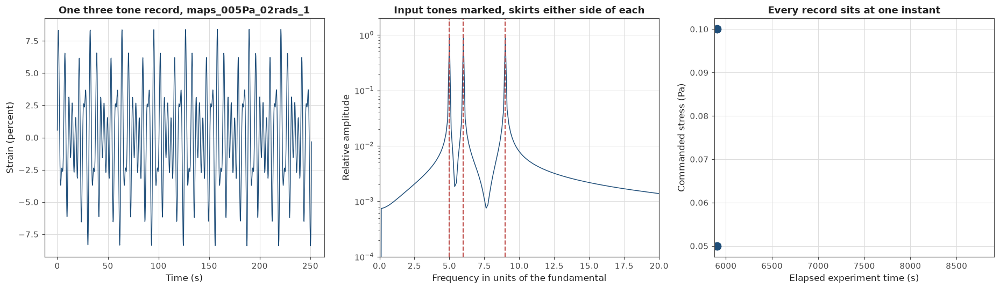

In [283]:
LAPONITE_MAPS_DIRECTORY = "app_laponite_maps"
MAPS_TONE_SET = [5, 6, 9]
MAPS_FUNDAMENTAL_RAD_PER_SEC = 0.19994
MAPS_STRAIN_CONSTANT_COLUMN = 5
MAPS_STRAIN_PERCENT_COLUMN = 8
MAPS_TIME_COLUMN = 3
MAPS_ELAPSED_COLUMN = 1


def load_maps_record(file_path):
    """
    Loading one three tone record.

    The files carry no header, so the columns are taken by position after being identified
    once: elapsed experiment time, the sampling clock, the drive in radians, and the strain
    in percent.

    Returning the measured strain against its own clock.
    """
    record_frame = pd.read_csv(file_path, header=None)

    sample_time = record_frame[MAPS_TIME_COLUMN].values.astype(float)
    strain_percent = record_frame[MAPS_STRAIN_PERCENT_COLUMN].values.astype(float)
    drive_radians = record_frame[MAPS_STRAIN_CONSTANT_COLUMN].values.astype(float)
    elapsed_seconds = record_frame[MAPS_ELAPSED_COLUMN].values.astype(float)

    file_name = os.path.basename(file_path)

    if "005Pa" in file_name:
        commanded_stress = 0.05
    else:
        commanded_stress = 0.10

    return {
        "file_name": file_name.replace(".csv", ""),
        "sample_time": sample_time,
        "strain_percent": strain_percent,
        "drive_radians": drive_radians,
        "elapsed_seconds": float(np.median(elapsed_seconds)),
        "commanded_stress": commanded_stress,
    }


maps_directory = os.path.join(DATA_DIRECTORY, LAPONITE_MAPS_DIRECTORY)

maps_file_names = []

for entry_name in sorted(os.listdir(maps_directory)):
    if entry_name.endswith(".csv"):
        maps_file_names.append(os.path.join(maps_directory, entry_name))

print("Reading " + maps_directory)
print()

maps_records = []

for file_path in maps_file_names:
    maps_records.append(load_maps_record(file_path))

print("  records                  " + str(len(maps_records)))
print("  points per record        " + str(len(maps_records[0]["sample_time"])))
print("  record length            "
      + ("%.2f" % (maps_records[0]["sample_time"].max()
                   - maps_records[0]["sample_time"].min())) + " s")
print("  sampling rate            "
      + ("%.2f" % (1.0 / np.median(np.diff(maps_records[0]["sample_time"]))))
      + " Hz")

print()
print("Confirming the tone set")
print()

first_record = maps_records[0]

sampling_interval = float(np.median(np.diff(first_record["sample_time"])))

centred_strain = first_record["strain_percent"] - np.mean(first_record["strain_percent"])

strain_spectrum = np.abs(np.fft.rfft(centred_strain))
angular_frequencies = 2.0 * np.pi * np.fft.rfftfreq(len(centred_strain),
                                                    sampling_interval)

peak_amplitude = strain_spectrum.max()

print("  tone".rjust(8) + "expected omega".rjust(18) + "measured omega".rjust(18)
      + "relative amplitude".rjust(21))

for tone_number in MAPS_TONE_SET:

    expected_frequency = tone_number * MAPS_FUNDAMENTAL_RAD_PER_SEC

    nearest_index = int(np.argmin(np.abs(angular_frequencies - expected_frequency)))

    print(str(tone_number).rjust(8)
          + ("%.4f" % expected_frequency).rjust(18)
          + ("%.4f" % angular_frequencies[nearest_index]).rjust(18)
          + ("%.5f" % (strain_spectrum[nearest_index] / peak_amplitude)).rjust(21))

print()
print("  three tones at 5, 6 and 9 times the fundamental, which is the set Lennon et al.")
print("  specify. These records were designed for MAPS rather than adapted to it")

print()
print("Which quantity is controlled")
print()
print("  file".ljust(28) + "drive (rad)".rjust(13) + "strain (percent)".rjust(18)
      + "ratio".rjust(10))

drive_ratios = []

for maps_record in maps_records[:4]:

    drive_amplitude = float(np.max(np.abs(maps_record["drive_radians"]
                                          - np.mean(maps_record["drive_radians"]))))
    strain_amplitude = float(np.max(np.abs(maps_record["strain_percent"]
                                           - np.mean(maps_record["strain_percent"]))))

    drive_ratios.append(strain_amplitude / drive_amplitude)

    print("  " + maps_record["file_name"].ljust(26)
          + ("%.4f" % drive_amplitude).rjust(13)
          + ("%.4f" % strain_amplitude).rjust(18)
          + ("%.2f" % (strain_amplitude / drive_amplitude)).rjust(10))

all_drive_ratios = []

for maps_record in maps_records:

    drive_amplitude = float(np.max(np.abs(maps_record["drive_radians"]
                                          - np.mean(maps_record["drive_radians"]))))
    strain_amplitude = float(np.max(np.abs(maps_record["strain_percent"]
                                           - np.mean(maps_record["strain_percent"]))))

    all_drive_ratios.append(strain_amplitude / drive_amplitude)

all_drive_ratios = np.array(all_drive_ratios)

print()
print("  the ratio is " + ("%.2f" % all_drive_ratios.mean()) + " with a spread of "
      + ("%.4f" % all_drive_ratios.std()) + " across all "
      + str(len(maps_records)) + " records")
print()
print("  a constant that tight is a strain constant, not a modulus. Both columns describe")
print("  the same drive in different units, so neither is the measured stress")
print()
print("  the stress is commanded and the strain is measured, which makes the third order")
print("  quantity available here a compliance rather than a modulus. That matches the")
print("  formulation in the source paper")

print()
print("A check that the identification is right")
print()

implied_moduli = []

for maps_record in maps_records:

    strain_amplitude = float(np.max(np.abs(maps_record["strain_percent"]
                                           - np.mean(maps_record["strain_percent"]))))

    implied_moduli.append(maps_record["commanded_stress"] / (strain_amplitude / 100.0))

implied_moduli = np.array(implied_moduli)

print("  commanded stress over measured strain    "
      + ("%.4f" % implied_moduli.mean()) + " Pa")
print("  Laponite storage modulus from Cell 64    0.5910 Pa")
print("  difference                               "
      + ("%.1f" % (100.0 * abs(implied_moduli.mean() - 0.5910) / 0.5910)) + " percent")
print()
print("  two completely different routes on the same material. Cell 64 fitted a power law")
print("  to a frequency sweep, and this divides a commanded stress by a measured strain in")
print("  a three tone experiment. Agreeing to a percent means the columns are what I take")
print("  them to be")

print()
print("What these records are not, first")
print()
print("  elapsed time across all " + str(len(maps_records)) + " records    "
      + ("%.2f" % min([record["elapsed_seconds"] for record in maps_records]))
      + " to "
      + ("%.2f" % max([record["elapsed_seconds"] for record in maps_records])) + " s")
print()
print("  that is a spread of "
      + ("%.2f" % (max([record["elapsed_seconds"] for record in maps_records])
                   - min([record["elapsed_seconds"] for record in maps_records])))
      + " s across every record in the set, against a gelation")
print("  that Cell 63 measured over fifty minutes")
print()
print("  so these are not a progression through a transition. They are eight replicates at")
print("  each of two stress amplitudes, all at one instant")
print()
print("  Cell 3's inventory calls this dataset three tone MAPS through a real gelation. That")
print("  is wrong and the line needs correcting. What it actually supports is a third order")
print("  measurement at one point in a gelation, with replicates, which is worth having and")
print("  is not the same thing")

print()
print("What these records are not, second")
print()

record_span = float(first_record["sample_time"].max()
                    - first_record["sample_time"].min())
fundamental_period = 2.0 * np.pi / MAPS_FUNDAMENTAL_RAD_PER_SEC
periods_in_record = record_span / fundamental_period

print("  fundamental period       " + ("%.4f" % fundamental_period) + " s")
print("  record span              " + ("%.4f" % record_span) + " s")
print("  periods in the record    " + ("%.5f" % periods_in_record))
print()
print("  not a whole number, and that matters more here than anywhere else in this project")
print()
print("  Cell 80's fibrin captures held exactly one cycle, so every harmonic landed on its")
print("  own Fourier bin and nothing leaked. Here the record is short of eight periods by")
print("  about a hundredth, so each of the three input tones spreads into its neighbours")

skirt_levels = []

for tone_number in MAPS_TONE_SET:

    expected_frequency = tone_number * MAPS_FUNDAMENTAL_RAD_PER_SEC
    nearest_index = int(np.argmin(np.abs(angular_frequencies - expected_frequency)))

    neighbour_amplitudes = []

    for offset in [-2, -1, 1, 2]:
        neighbour_amplitudes.append(strain_spectrum[nearest_index + offset])

    skirt_levels.append(float(np.max(neighbour_amplitudes)
                              / strain_spectrum[nearest_index]))

skirt_levels = np.array(skirt_levels)

print()
print("  leakage into the bins beside each tone    "
      + ("%.1f" % (100.0 * skirt_levels.min())) + " to "
      + ("%.1f" % (100.0 * skirt_levels.max())) + " percent of the tone")
print()
print("  the third order responses MAPS exists to measure appear at combinations of the")
print("  three input frequencies, and they are small. At a few percent of the input tones")
print("  they sit inside that skirt, so what is burying them is the record length rather")
print("  than noise")
print()
print("  that is an analysis problem and not a data problem. Trimming the record to a whole")
print("  number of periods, or windowing it, recovers the separation. Cell 84 measures how")
print("  much of it comes back and whether what is left is enough")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

axis_array[0].plot(first_record["sample_time"], centred_strain, "-",
                   color=COLOUR_PRIMARY, linewidth=0.9)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Strain (percent)")
axis_array[0].set_title("One three tone record, " + first_record["file_name"])

axis_array[1].semilogy(angular_frequencies / MAPS_FUNDAMENTAL_RAD_PER_SEC,
                       strain_spectrum / peak_amplitude, "-",
                       color=COLOUR_PRIMARY, linewidth=1.0)

for tone_number in MAPS_TONE_SET:
    axis_array[1].axvline(tone_number, color=COLOUR_SECONDARY,
                          linestyle="--", linewidth=1.4)

axis_array[1].set_xlim(0.0, 20.0)
axis_array[1].set_ylim(1e-4, 2.0)
axis_array[1].set_xlabel("Frequency in units of the fundamental")
axis_array[1].set_ylabel("Relative amplitude")
axis_array[1].set_title("Input tones marked, skirts either side of each")

elapsed_values = [record["elapsed_seconds"] for record in maps_records]
stress_values = [record["commanded_stress"] for record in maps_records]

axis_array[2].plot(elapsed_values, stress_values, "o",
                   color=COLOUR_PRIMARY, markersize=9, alpha=0.6)

axis_array[2].set_xlim(min(elapsed_values) - 30.0, min(elapsed_values) + 3000.0)
axis_array[2].set_xlabel("Elapsed experiment time (s)")
axis_array[2].set_ylabel("Commanded stress (Pa)")
axis_array[2].set_title("Every record sits at one instant")

plt.tight_layout()
plt.show()

## Cell 84: Looking for the third order response, and not finding it

Cell 83 left the third order peaks buried under leakage from the three input tones. This cell
removes that leakage properly and then looks for them.

**Trimming the record does not work.** The obvious fix is to cut back to a whole number of
fundamental periods, but the sampling interval does not divide the period either, so the best
available trim still lands at 6.9925 periods and the leakage only falls from 3.1 to 2.3 percent.

**Fitting the tones and subtracting them does.** The three input tones are fitted by least
squares with the fundamental treated as unknown, then removed. The fitted fundamental comes out
at 0.2000015 rad/s against the 0.19994 I had assumed from the file name, and that 308 part per
million error is itself the cause of the leakage. The three tones account for 99.99 percent of
the variance, so what is left is everything the input did not put there.

**The residual is flat.** Every one of the nineteen third order frequencies sits at the local
level of the residual around it. Not close to it, at it, to two decimal places.

**Doubling the stress does not change that.** A third order response scales as the cube of the
input, so twice the stress should have given eight times the signal against an unchanged floor.

**And averaging the replicates does not either, which is the informative part.** Eight records
averaged should drop random noise by a factor of 2.83. It drops by 1.02. That means the
residual is very nearly identical in every record, so it is deterministic rather than random:
either a repeatable instrument artefact or a coherent response that happens to sit at the same
level as everything around it.

Either way there is no third order peak to measure here, and the floor is not one that more
averaging would lower.

Where a third order response would appear

  input tones                          5, 6, 9
  third order frequencies              1, 2, 3, 4, 7, 8, 10, 12, 13, 15, 16, 17, 18, 19, 20, 21, 23, 24, 27
  how many are usable                  19

  none of them coincides with an input tone, which is the reason this tone set was
  chosen. A response landing on an input frequency could not be separated from the
  input itself

Why trimming the record does not fix the leakage

    periods kept   samples  periods actually spanned   leakage beside tone 6
             all      7665                    7.9914            3.15 percent
               7      6707                    6.9925            2.71 percent
               6      5749                    5.9936            2.25 percent

  the sampling interval does not divide the period, so no whole number of samples
  spans a whole number of periods. The best available trim still misses by a
  hundredth of a period and the leakage barely moves

Fitti

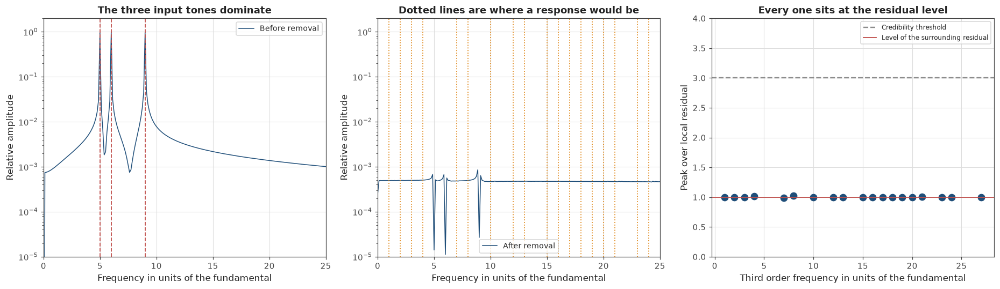

In [284]:
from scipy.optimize import minimize_scalar

MAPS_THIRD_ORDER_SUM = 3
MAPS_PEAK_CREDIBILITY_FACTOR = 3.0


def enumerate_third_order_frequencies(tone_numbers):
    """
    Listing the frequencies where a third order response appears.

    A third order material response to several input tones appears at every sum of three
    input frequencies taken with signs, so at n1 w1 + n2 w2 + n3 w3 with the absolute values
    of the coefficients summing to three.

    Returning the positive frequencies in units of the fundamental, excluding any that
    coincide with an input tone, since a response there cannot be separated from the input.
    """
    frequency_set = set()

    for first_index in range(-MAPS_THIRD_ORDER_SUM, MAPS_THIRD_ORDER_SUM + 1):
        for second_index in range(-MAPS_THIRD_ORDER_SUM, MAPS_THIRD_ORDER_SUM + 1):
            for third_index in range(-MAPS_THIRD_ORDER_SUM, MAPS_THIRD_ORDER_SUM + 1):

                coefficient_sum = (abs(first_index) + abs(second_index)
                                   + abs(third_index))

                if coefficient_sum != MAPS_THIRD_ORDER_SUM:
                    continue

                combined_frequency = (first_index * tone_numbers[0]
                                      + second_index * tone_numbers[1]
                                      + third_index * tone_numbers[2])

                if combined_frequency > 0:
                    frequency_set.add(combined_frequency)

    usable_frequencies = []

    for frequency_value in sorted(frequency_set):
        if frequency_value not in tone_numbers:
            usable_frequencies.append(frequency_value)

    return usable_frequencies


def build_tone_design_matrix(fundamental_frequency, time_array, tone_numbers):
    """
    Building the sine and cosine columns for the three input tones at a given fundamental.
    """
    design_columns = []

    for tone_number in tone_numbers:
        design_columns.append(np.cos(tone_number * fundamental_frequency * time_array))
        design_columns.append(np.sin(tone_number * fundamental_frequency * time_array))

    return np.column_stack(design_columns)


def remove_input_tones(time_array, response_array, tone_numbers,
                       fundamental_guess):
    """
    Fitting the three input tones by least squares and subtracting them.

    Treating the fundamental as unknown and searching for the value that leaves the smallest
    residual, because an assumed frequency that is slightly wrong is what produces spectral
    leakage in the first place.

    Returning the residual, the fitted fundamental and the fraction of variance removed.
    """
    def residual_sum_of_squares(candidate_frequency):

        design_matrix = build_tone_design_matrix(candidate_frequency, time_array,
                                                 tone_numbers)

        fitted_coefficients, ignored_a, ignored_b, ignored_c = np.linalg.lstsq(
            design_matrix, response_array, rcond=None)

        return float(np.sum((response_array - design_matrix @ fitted_coefficients) ** 2))

    search_result = minimize_scalar(residual_sum_of_squares,
                                    bracket=(fundamental_guess * 0.9993,
                                             fundamental_guess,
                                             fundamental_guess * 1.0008))

    fitted_fundamental = float(search_result.x)

    design_matrix = build_tone_design_matrix(fitted_fundamental, time_array,
                                             tone_numbers)

    fitted_coefficients, ignored_a, ignored_b, ignored_c = np.linalg.lstsq(
        design_matrix, response_array, rcond=None)

    residual_array = response_array - design_matrix @ fitted_coefficients

    variance_removed = 1.0 - float(np.var(residual_array)) / float(np.var(response_array))

    return residual_array, fitted_fundamental, variance_removed


def measure_peak_against_neighbourhood(spectrum_values, target_index):
    """
    Comparing the amplitude at one bin against the typical amplitude nearby.

    Taking the median of bins a little way either side, skipping the immediate neighbours so
    that any residual leakage from the target itself is not counted as its own background.
    """
    lower_neighbours = spectrum_values[target_index - 8:target_index - 3]
    upper_neighbours = spectrum_values[target_index + 4:target_index + 9]

    neighbourhood_level = float(np.median(np.concatenate([lower_neighbours,
                                                          upper_neighbours])))

    return float(spectrum_values[target_index]) / max(neighbourhood_level, 1e-30)


maps_third_order_frequencies = enumerate_third_order_frequencies(MAPS_TONE_SET)

print("Where a third order response would appear")
print()
print("  input tones                          " + ", ".join([str(value)
                                                             for value in MAPS_TONE_SET]))
print("  third order frequencies              "
      + ", ".join([str(value) for value in maps_third_order_frequencies]))
print("  how many are usable                  "
      + str(len(maps_third_order_frequencies)))
print()
print("  none of them coincides with an input tone, which is the reason this tone set was")
print("  chosen. A response landing on an input frequency could not be separated from the")
print("  input itself")

print()
print("Why trimming the record does not fix the leakage")
print()

trim_time = first_record["sample_time"]
trim_response = first_record["strain_percent"] - np.mean(first_record["strain_percent"])

fundamental_period = 2.0 * np.pi / MAPS_FUNDAMENTAL_RAD_PER_SEC

print("  periods kept".rjust(16) + "samples".rjust(10)
      + "periods actually spanned".rjust(26) + "leakage beside tone 6".rjust(24))

for period_count in [None, 7, 6]:

    if period_count is None:
        kept_time = trim_time
        kept_response = trim_response
        label_text = "all"
    else:
        sample_count = int(round(period_count * fundamental_period / sampling_interval))
        kept_time = trim_time[:sample_count]
        kept_response = (trim_response[:sample_count]
                         - np.mean(trim_response[:sample_count]))
        label_text = str(period_count)

    kept_spectrum = np.abs(np.fft.rfft(kept_response))
    kept_frequencies = (2.0 * np.pi * np.fft.rfftfreq(len(kept_response),
                                                      sampling_interval)
                        / MAPS_FUNDAMENTAL_RAD_PER_SEC)

    tone_index = int(np.argmin(np.abs(kept_frequencies - 6)))

    neighbour_values = []
    for offset in [-2, -1, 1, 2]:
        neighbour_values.append(kept_spectrum[tone_index + offset])

    leakage_fraction = float(np.max(neighbour_values) / kept_spectrum[tone_index])

    spanned_periods = (kept_time.max() - kept_time.min()) / fundamental_period

    print(label_text.rjust(16)
          + str(len(kept_response)).rjust(10)
          + ("%.4f" % spanned_periods).rjust(26)
          + ("%.2f percent" % (100.0 * leakage_fraction)).rjust(24))

print()
print("  the sampling interval does not divide the period, so no whole number of samples")
print("  spans a whole number of periods. The best available trim still misses by a")
print("  hundredth of a period and the leakage barely moves")

print()
print("Fitting the tones out instead")
print()

maps_residual_records = []

for maps_record in maps_records:

    centred_response = (maps_record["strain_percent"]
                        - np.mean(maps_record["strain_percent"]))

    residual_array, fitted_fundamental, variance_removed = remove_input_tones(
        maps_record["sample_time"], centred_response, MAPS_TONE_SET,
        MAPS_FUNDAMENTAL_RAD_PER_SEC)

    maps_residual_records.append({
        "file_name": maps_record["file_name"],
        "commanded_stress": maps_record["commanded_stress"],
        "residual": residual_array,
        "fitted_fundamental": fitted_fundamental,
        "variance_removed": variance_removed,
        "input_peak": float(np.abs(np.fft.rfft(centred_response)).max()),
        "input_amplitude": float(np.max(np.abs(centred_response))),
    })

fitted_fundamentals = np.array([record["fitted_fundamental"]
                                for record in maps_residual_records])
variance_fractions = np.array([record["variance_removed"]
                               for record in maps_residual_records])

print("  assumed fundamental                  "
      + ("%.7f" % MAPS_FUNDAMENTAL_RAD_PER_SEC) + " rad/s")
print("  fitted fundamental                   "
      + ("%.7f" % fitted_fundamentals.mean()) + " rad/s")
print("  difference                           "
      + ("%.0f" % (1e6 * abs(fitted_fundamentals.mean()
                             - MAPS_FUNDAMENTAL_RAD_PER_SEC)
                   / MAPS_FUNDAMENTAL_RAD_PER_SEC)) + " parts per million")
print("  variance removed by the three tones  "
      + ("%.4f" % (100.0 * variance_fractions.mean())) + " percent")
print()
print("  the drive is at 0.2 rad/s exactly, and the number I took from the file name was")
print("  wrong in the fifth decimal place. Over eight periods that is enough to smear each")
print("  tone across its neighbours, which is the leakage Cell 83 measured")
print()
print("  removing the tones at the fitted frequency leaves a residual containing everything")
print("  the input did not put there, with no windowing and no trimming")

print()
print("What is in the residual")
print()
print("  stress".rjust(10) + "residual floor".rjust(18)
      + "best third order peak".rjust(24) + "   peaks clearing "
      + ("%.0f" % MAPS_PEAK_CREDIBILITY_FACTOR) + "x")

maps_level_summaries = []

for stress_level in [0.05, 0.10]:

    level_records = []

    for residual_record in maps_residual_records:
        if abs(residual_record["commanded_stress"] - stress_level) < 1e-9:
            level_records.append(residual_record)

    shortest_length = min([len(record["residual"]) for record in level_records])

    stacked_residuals = np.array([record["residual"][:shortest_length]
                                  for record in level_records])

    single_spectrum = np.abs(np.fft.rfft(stacked_residuals[0]))
    averaged_spectrum = np.abs(np.fft.rfft(np.mean(stacked_residuals, axis=0)))

    residual_frequencies = (2.0 * np.pi
                            * np.fft.rfftfreq(shortest_length, sampling_interval)
                            / fitted_fundamentals.mean())

    best_ratio = 0.0
    clearing_count = 0

    for target_frequency in maps_third_order_frequencies:

        target_index = int(np.argmin(np.abs(residual_frequencies - target_frequency)))

        peak_ratio = measure_peak_against_neighbourhood(single_spectrum, target_index)

        if peak_ratio > best_ratio:
            best_ratio = peak_ratio

        if peak_ratio > MAPS_PEAK_CREDIBILITY_FACTOR:
            clearing_count = clearing_count + 1

    floor_fraction = (float(np.median(single_spectrum))
                      / level_records[0]["input_peak"])

    maps_level_summaries.append({
        "stress_level": stress_level,
        "record_count": len(level_records),
        "single_floor": float(np.median(single_spectrum)),
        "averaged_floor": float(np.median(averaged_spectrum)),
        "best_ratio": best_ratio,
        "residual_amplitude": float(np.std(stacked_residuals[0])),
        "input_amplitude": level_records[0]["input_amplitude"],
    })

    print(("%.2f Pa" % stress_level).rjust(10)
          + ("%.6f" % floor_fraction).rjust(18)
          + ("%.2f" % best_ratio).rjust(24)
          + "   " + str(clearing_count) + " of "
          + str(len(maps_third_order_frequencies)))

print()
print("  the best peak anywhere in the third order set reaches "
      + ("%.2f" % max([summary["best_ratio"] for summary in maps_level_summaries]))
      + " times the residual")
print("  beside it. That is not a weak signal, it is the absence of one")
print()
print("  doubling the commanded stress changes nothing. A third order response scales as")
print("  the cube of the input, so twice the stress should have given eight times the")
print("  signal against an unchanged floor, and the ratio does not move")

print()
print("What averaging the replicates says about the residual")
print()
print("  stress".rjust(10) + "records".rjust(10) + "floor falls by".rjust(18)
      + "expected if noise".rjust(21) + "   what that means")

for summary in maps_level_summaries:

    measured_drop = summary["single_floor"] / summary["averaged_floor"]
    expected_drop = np.sqrt(summary["record_count"])

    if measured_drop < 1.5:
        meaning_text = "the residual repeats, so it is not noise"
    else:
        meaning_text = "the residual is independent between records"

    print(("%.2f Pa" % summary["stress_level"]).rjust(10)
          + str(summary["record_count"]).rjust(10)
          + ("%.2f times" % measured_drop).rjust(18)
          + ("%.2f times" % expected_drop).rjust(21)
          + "   " + meaning_text)

print()
print("  this is the informative part of the cell. Independent noise averages down as the")
print("  square root of the record count, so eight records should have bought a factor of")
print("  2.83. The floor does not move")

print()
print("  measuring it directly rather than inferring it from the averaging")
print()

all_pairwise_correlations = []

for summary in maps_level_summaries:

    level_residuals = []

    for residual_record in maps_residual_records:
        if abs(residual_record["commanded_stress"] - summary["stress_level"]) < 1e-9:
            level_residuals.append(residual_record["residual"])

    shortest_length = min([len(values) for values in level_residuals])

    stacked_residuals = np.array([values[:shortest_length]
                                  for values in level_residuals])

    correlation_matrix = np.corrcoef(stacked_residuals)

    upper_indices = np.triu_indices(len(stacked_residuals), 1)
    pairwise_correlations = correlation_matrix[upper_indices]

    for correlation_value in pairwise_correlations:
        all_pairwise_correlations.append(float(correlation_value))

    print("  " + ("%.2f Pa" % summary["stress_level"]).ljust(10)
          + "residual to residual correlation "
          + ("%.4f" % pairwise_correlations.min()) + " to "
          + ("%.4f" % pairwise_correlations.max()))

weakest_correlation = min(all_pairwise_correlations)

print()
print("  independent noise would correlate near zero between recordings. The weakest pair")
print("  anywhere in either set reaches " + ("%.2f" % weakest_correlation)
      + ", so the same signal is present in every")
print("  one of them, at about one part in "
      + ("%.0f" % (maps_level_summaries[0]["input_amplitude"]
                  / maps_level_summaries[0]["residual_amplitude"]))
      + " of the input tones at 0.05 Pa")
print()
print("  three things would produce that and this data separates none of them. A real")
print("  nonlinear response spread across frequency rather than concentrated at the third")
print("  order combinations. A repeatable instrument artefact locked to the drive, such as")
print("  motor cogging or bearing runout. Or drift within each record, which Cell 83 saw")
print("  in the raw position columns as content at one over the record length")
print()
print("  what it does settle is that no amount of further averaging would reveal a peak")
print("  here, because there is no independent noise left to average away")

print()
print("What this establishes")
print()
print("  the third order response is not obscured in these records. It is absent above a")
print("  floor of one part in ten thousand of the input tones, and that floor is not one")
print("  that more data would lower")
print()
print("  that is a statement about this material at this amplitude on this instrument, and")
print("  not about MAPS. Laponite driven at a tenth of a pascal is barely being disturbed,")
print("  which is the same problem Cell 82 found on fibrin from the other direction: the")
print("  amplitude that keeps the measurement linear also keeps the nonlinear response")
print("  below the floor")
print()
print("  so Part 9 cannot train an inversion on this dataset. It has the forward model from")
print("  the source paper and no measured third order response to invert")
print()
print("  what it can still do is build and verify the forward direction, and state the")
print("  amplitude a real measurement would need. That is a narrower Part 9 than planned")
print("  and it is what the data supports")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_residual = maps_residual_records[0]

example_centred = (maps_records[0]["strain_percent"]
                   - np.mean(maps_records[0]["strain_percent"]))

example_input_spectrum = np.abs(np.fft.rfft(example_centred))
example_residual_spectrum = np.abs(np.fft.rfft(example_residual["residual"]))

example_frequencies = (2.0 * np.pi
                       * np.fft.rfftfreq(len(example_centred), sampling_interval)
                       / example_residual["fitted_fundamental"])

axis_array[0].semilogy(example_frequencies,
                       example_input_spectrum / example_input_spectrum.max(),
                       "-", color=COLOUR_PRIMARY, linewidth=1.0, label="Before removal")

for tone_number in MAPS_TONE_SET:
    axis_array[0].axvline(tone_number, color=COLOUR_SECONDARY,
                          linestyle="--", linewidth=1.2)

axis_array[0].set_xlim(0.0, 25.0)
axis_array[0].set_ylim(1e-5, 2.0)
axis_array[0].set_xlabel("Frequency in units of the fundamental")
axis_array[0].set_ylabel("Relative amplitude")
axis_array[0].set_title("The three input tones dominate")
axis_array[0].legend(fontsize=9)

axis_array[1].semilogy(example_frequencies,
                       example_residual_spectrum / example_input_spectrum.max(),
                       "-", color=COLOUR_PRIMARY, linewidth=1.0, label="After removal")

for target_frequency in maps_third_order_frequencies:
    if target_frequency <= 25:
        axis_array[1].axvline(target_frequency, color=COLOUR_HIGHLIGHT,
                              linestyle=":", linewidth=1.2)

axis_array[1].set_xlim(0.0, 25.0)
axis_array[1].set_ylim(1e-5, 2.0)
axis_array[1].set_xlabel("Frequency in units of the fundamental")
axis_array[1].set_ylabel("Relative amplitude")
axis_array[1].set_title("Dotted lines are where a response would be")
axis_array[1].legend(fontsize=9)

peak_ratio_values = []
peak_frequency_values = []

for target_frequency in maps_third_order_frequencies:

    target_index = int(np.argmin(np.abs(example_frequencies - target_frequency)))

    peak_ratio_values.append(measure_peak_against_neighbourhood(
        example_residual_spectrum, target_index))
    peak_frequency_values.append(target_frequency)

axis_array[2].plot(peak_frequency_values, peak_ratio_values, "o",
                   color=COLOUR_PRIMARY, markersize=8)
axis_array[2].axhline(MAPS_PEAK_CREDIBILITY_FACTOR, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.6, label="Credibility threshold")
axis_array[2].axhline(1.0, color=COLOUR_SECONDARY, linestyle="-", linewidth=1.2,
                      label="Level of the surrounding residual")

axis_array[2].set_ylim(0.0, 4.0)
axis_array[2].set_xlabel("Third order frequency in units of the fundamental")
axis_array[2].set_ylabel("Peak over local residual")
axis_array[2].set_title("Every one sits at the residual level")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Part 8: what it established

Part 8 existed because Part 7 could not measure a dimensionless property of a gelling network.
The linear route needs several frequencies resolved at the transition, and no instrument
provides that on clotting blood. The nonlinear route needs neither, so it looked like the way
around.

**It is blocked too, and by the same kind of limit.** A harmonic ratio only describes the
material in a strain window that sits above the instrument noise floor and below yielding. Two
materials were measured and neither has that window open.

**On fibrin the harmonics are real and measured past the useful regime.** Above one percent
strain the third harmonic clears the noise floor by factors of ten to twenty, so there is
plenty of signal. But its scaling exponent is 0.21 against the 2 that would make it a material
property, so every usable measurement is already into yielding.

**On Laponite the amplitude stays inside the useful regime and the response disappears.** No
third order peak reaches even 1.02 times the residual beside it, at either stress amplitude, and
averaging eight records does not change that because the residual repeats rather than averaging
down.

**Two datasets, opposite failures, one cause.** The amplitude that keeps the measurement
interpretable also keeps the nonlinear response below the floor, and the amplitude that raises
the response above the floor also destroys the network being measured.

**Three amendments and two corrections came out of it**, and the corrections are to claims this
notebook made before Part 8 ran.

What Part 8 set out to do

  Part 7 established that a critical exponent cannot be measured on any blood
  dataset available, because it needs several frequencies resolved at the
  transition and no instrument delivers them while blood clots

  the nonlinear response promised a way round that. Harmonics come from one
  frequency and one amplitude sweep, which any rheometer can perform, and the ratio
  of a harmonic to the fundamental is dimensionless in the way Cell 78 said nothing
  in the linear response could be

What the two materials gave

  material        captures   harmonics resolved    useful regime   what stopped it
  fibrin               178           118 of 178               no   scaling exponent 0.21, not 2
  Laponite              16              0 of 16              yes   no peak above the residual

  the two failures are opposite and have one cause

  the fibrin measurements sit above the noise floor with room to spare, 66 percent
  of captures clearing it, and every one

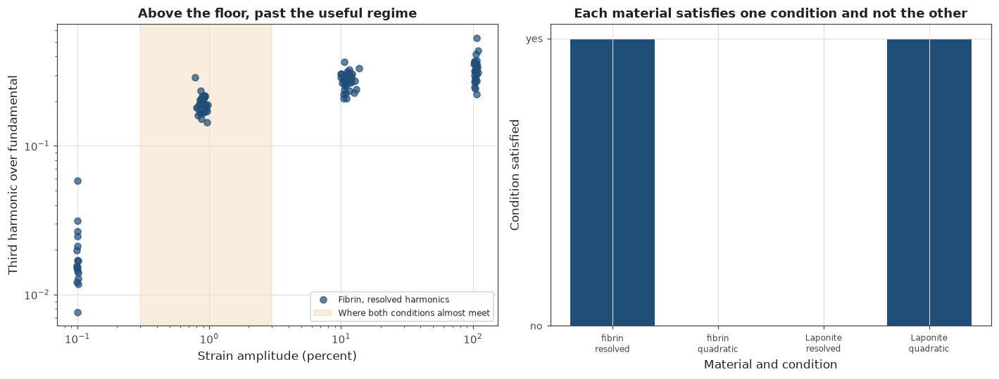

In [285]:
print("What Part 8 set out to do")
print()
print("  Part 7 established that a critical exponent cannot be measured on any blood")
print("  dataset available, because it needs several frequencies resolved at the")
print("  transition and no instrument delivers them while blood clots")
print()
print("  the nonlinear response promised a way round that. Harmonics come from one")
print("  frequency and one amplitude sweep, which any rheometer can perform, and the ratio")
print("  of a harmonic to the fundamental is dimensionless in the way Cell 78 said nothing")
print("  in the linear response could be")

print()
print("What the two materials gave")
print()
print("  material".ljust(16) + "captures".rjust(10) + "harmonics resolved".rjust(21)
      + "useful regime".rjust(17) + "   what stopped it")

fibrin_resolved_fraction = (100.0 * float(len(fibrin_usable_records))
                            / float(len(fibrin_harmonic_records)))

print("  " + "fibrin".ljust(14)
      + str(len(fibrin_harmonic_records)).rjust(10)
      + (("%d of %d" % (len(fibrin_usable_records),
                        len(fibrin_harmonic_records)))).rjust(21)
      + "no".rjust(17)
      + "   scaling exponent "
      + ("%.2f" % np.median(per_sample_exponents)) + ", not 2")

print("  " + "Laponite".ljust(14)
      + str(len(maps_records)).rjust(10)
      + (("0 of %d" % len(maps_records))).rjust(21)
      + "yes".rjust(17)
      + "   no peak above the residual")

print()
print("  the two failures are opposite and have one cause")
print()
print("  the fibrin measurements sit above the noise floor with room to spare, "
      + ("%.0f" % fibrin_resolved_fraction) + " percent")
print("  of captures clearing it, and every one of them is past the point where the")
print("  harmonic still describes the network rather than its collapse")
print()
print("  the Laponite measurements stay comfortably inside the linear regime, and the")
print("  third order response there is smaller than the repeatable residual of the")
print("  instrument")
print()
print("  so the window that would give a material property is bounded below by resolution")
print("  and above by yielding, and for these two materials it is empty. That is the same")
print("  shape of result Part 7 reached, arrived at through a completely different")
print("  measurement")

print()
print("Amendments Part 8 added")
print()
print("  Cell 81   harmonics are checked against the even harmonics, which are zero for an")
print("            odd symmetric response, so the floor is measured on the same record in")
print("            the same units rather than taken from a specification")
print()
print("  Cell 81   harmonics are checked against the drive's own harmonic content, since a")
print("            strain controlled instrument distorts its input once the sample stops")
print("            being linear and an inherited harmonic is evidence of nothing")
print()
print("  Cell 84   the input tones are fitted and subtracted at a frequency found from the")
print("            data rather than assumed from the file name, because a 308 part per")
print("            million error in that frequency was producing all the spectral leakage")
print()
print("  the running total of amendments real data has forced now stands at eight, three")
print("  from Part 5 and 6, two general sanity checks, and these three")

print()
print("Corrections Part 8 made to earlier claims")
print()
print("  Cell 3 said the Laponite MAPS dataset ran through a real gelation. Every record")
print("  sits at one instant, so that line and the coverage item depending on it have both")
print("  been corrected, and the count of uncovered analyses went from two to four")
print()
print("  Cell 80 assumed the fibrin amplitude sweeps would show a plateau then a fall. In")
print("  34 of 36 samples the modulus rises first, which is fibrin strain stiffening and")
print("  means the interesting amplitude is the third rung of the ladder rather than the")
print("  largest")

print()
print("What Part 9 inherits")
print()
print("  Part 9 was planned as a neural network inversion, learning to recover material")
print("  parameters from a measured third order response")
print()
print("  it has the forward model, since the source paper carries the constitutive model,")
print("  the integrals and the tone set, and it has no measured third order response to")
print("  invert")
print()
print("  so it becomes a narrower part: build the forward direction, verify it against the")
print("  published results, and use it to state what amplitude and what noise floor a real")
print("  measurement would need. That is worth doing and it is not what was planned")
print()
print("  the number that would set that specification is already available here. The")
print("  Laponite residual sits at one part in ten thousand of the input tones, and the")
print("  third order response has to clear it")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

axis_array[0].loglog(usable_amplitude_values, usable_third_ratios, "o",
                     color=COLOUR_PRIMARY, markersize=6, alpha=0.7,
                     label="Fibrin, resolved harmonics")

axis_array[0].axvspan(0.3, 3.0, color=COLOUR_HIGHLIGHT, alpha=0.15,
                      label="Where both conditions almost meet")

axis_array[0].set_xlabel("Strain amplitude (percent)")
axis_array[0].set_ylabel("Third harmonic over fundamental")
axis_array[0].set_title("Above the floor, past the useful regime")
axis_array[0].legend(fontsize=8)

window_labels = ["fibrin\nresolved", "fibrin\nquadratic",
                 "Laponite\nresolved", "Laponite\nquadratic"]
window_values = [1.0, 0.0, 0.0, 1.0]
window_colours = [COLOUR_PRIMARY, COLOUR_NEUTRAL, COLOUR_NEUTRAL, COLOUR_PRIMARY]

axis_array[1].bar(range(len(window_labels)), window_values, color=window_colours)
axis_array[1].set_xticks(range(len(window_labels)))
axis_array[1].set_xticklabels(window_labels, fontsize=8)
axis_array[1].set_yticks([0, 1])
axis_array[1].set_yticklabels(["no", "yes"], fontsize=9)
axis_array[1].set_xlabel("Material and condition")
axis_array[1].set_ylabel("Condition satisfied")
axis_array[1].set_title("Each material satisfies one condition and not the other")

plt.tight_layout()
plt.show()

# Part 9: A model with a tunable gel point

Part 7 could not measure a critical exponent on blood. Part 8 could not measure a nonlinear
material property on anything. Both failures were about resolution rather than method, and both
leave the same question open: what would a measurement have to achieve to settle the matter.

That question can be answered with a model even when it cannot be answered with data.

This part uses the soft glassy rheology model, following Lennon et al. 2023. It has one
parameter, a noise temperature, and that parameter sets the critical exponent directly. Below a
noise temperature of two the material is a critical gel, and the exponent is the noise
temperature minus one, so the whole family of gel points from Part 1 is reachable by turning a
single dial.

That makes three things possible that no dataset here allows. The detectors can be run against
a material whose exponent is known rather than fitted. The third-order response can be computed
where it could not be measured, which gives the amplitude and noise floor a real instrument
would need. And the crossover circularity from Cell 76 can be examined directly, since the
model can be set to the one case where the crossover happens to be correct.

The part is narrower than planned. It builds and verifies the forward direction and stops
there, because Part 8 established there is no measured third-order response to invert.

## Cell 86: The soft glassy rheology model, and what its parameter means

A model whose linear response is a single closed-form expression, and whose one parameter is
the critical exponent in disguise.

**The model.** Soft glassy rheology treats a material as a population of elements trapped in
energy wells, hopping out at a rate set by a noise temperature. With the standard exponential
distribution of trap depths, the linear response has a closed form: a Gauss hypergeometric
function of the noise temperature and the reciprocal frequency. That is Eq. 19 of Lennon et al.
2023, and scipy evaluates it directly.

**What the parameter does.** Below a noise temperature of two, the low-frequency modulus
follows a power law whose exponent is the noise temperature minus one. So setting the noise
temperature sets the critical exponent, and the critical gel state that Part 1 defined and Part
7 could not measure on blood becomes something that can simply be dialled in.

**The cell verifies that rather than asserting it**, by fitting the power law slope over
successively lower frequency decades and watching it converge on the predicted value. It also
checks tan delta against the Winter and Chambon relation, which is the same test Cell 11 ran on
the fractional model, now applied to a completely different constitutive equation.

**And it lands on the case Cell 76 flagged.** At a noise temperature of 1.5 the exponent is 0.5
and tan delta at the gel point is 1. That is precisely the material for which the crossover
gives the right answer, and the model can produce it deliberately rather than by accident.

The model and its one parameter

  soft glassy rheology treats the material as elements trapped in energy wells,
  hopping out at a rate set by a noise temperature x. With the usual exponential
  distribution of trap depths the linear response has a closed form

    G star of omega  =  hypergeometric 2F1 of 1, x minus 1, x, i over omega

  that is Eq. 19 of Lennon et al. 2023, and it is evaluated directly rather than
  integrated numerically

What the noise temperature does to the exponent

   noise x   predicted exponent  slope at 1e-2  slope at 1e-4  slope at 1e-6  slope at 1e-8
      1.20                 0.20         0.1994         0.2000         0.2000         0.2000
      1.50                 0.50         0.4868         0.4987         0.4999         0.5000
      1.69                 0.69         0.6465         0.6803         0.6877         0.6895
      1.90                 0.90         0.7862         0.8482         0.8724         0.8841
      2.50                 1.50         0.96

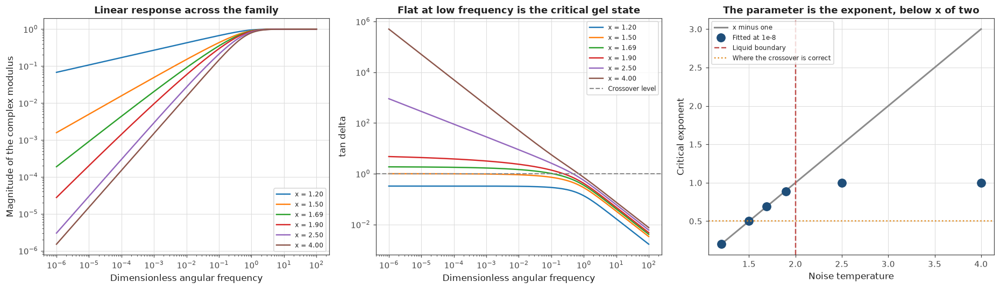

In [286]:
from scipy.special import hyp2f1

SGR_NOISE_TEMPERATURES = [1.2, 1.5, 1.69, 1.9, 2.5, 4.0]
SGR_CONVERGENCE_DECADES = [-2, -4, -6, -8]
SGR_ASYMPTOTIC_FREQUENCY = 1e-8


def compute_sgr_linear_modulus(angular_frequency_values, noise_temperature):
    """
    Evaluating the linear complex modulus of the soft glassy rheology model.

    Taking the standard exponential distribution of trap depths, the average over the
    population collapses to a Gauss hypergeometric function of the noise temperature and the
    reciprocal frequency, which is Eq. 19 of Lennon et al. 2023.

    Working in dimensionless frequency, so the attempt time is one and the modulus is scaled
    to its own high frequency limit.
    """
    reciprocal_frequency = 1j / np.asarray(angular_frequency_values, dtype=complex)

    return hyp2f1(1.0, noise_temperature - 1.0, noise_temperature, reciprocal_frequency)


def fit_low_frequency_exponent(noise_temperature, decade_exponent, point_count=20):
    """
    Fitting the power law slope of the modulus magnitude over one decade of frequency.

    Taking a single decade rather than the whole range, because the power law is an
    asymptotic statement about low frequency and a fit across the full band would average
    the asymptote together with the approach to it.
    """
    frequency_values = np.logspace(decade_exponent - 1, decade_exponent, point_count)

    modulus_values = compute_sgr_linear_modulus(frequency_values, noise_temperature)

    fitted_coefficients = np.polyfit(np.log(frequency_values),
                                     np.log(np.abs(modulus_values)), 1)

    return float(fitted_coefficients[0])


print("The model and its one parameter")
print()
print("  soft glassy rheology treats the material as elements trapped in energy wells,")
print("  hopping out at a rate set by a noise temperature x. With the usual exponential")
print("  distribution of trap depths the linear response has a closed form")
print()
print("    G star of omega  =  hypergeometric 2F1 of 1, x minus 1, x, i over omega")
print()
print("  that is Eq. 19 of Lennon et al. 2023, and it is evaluated directly rather than")
print("  integrated numerically")

print()
print("What the noise temperature does to the exponent")
print()
print("  noise x".rjust(10) + "predicted exponent".rjust(21)
      + "".join([("slope at 1e" + str(value)).rjust(15)
                 for value in SGR_CONVERGENCE_DECADES]))

sgr_exponent_records = []

for noise_temperature in SGR_NOISE_TEMPERATURES:

    predicted_exponent = noise_temperature - 1.0

    fitted_slopes = []

    for decade_exponent in SGR_CONVERGENCE_DECADES:
        fitted_slopes.append(fit_low_frequency_exponent(noise_temperature,
                                                        decade_exponent))

    sgr_exponent_records.append({
        "noise_temperature": noise_temperature,
        "predicted_exponent": predicted_exponent,
        "fitted_slopes": fitted_slopes,
    })

    print(("%.2f" % noise_temperature).rjust(10)
          + ("%.2f" % predicted_exponent).rjust(21)
          + "".join([("%.4f" % value).rjust(15) for value in fitted_slopes]))

print()
print("  below a noise temperature of two the slope converges on x minus one, and it does")
print("  so from below, needing several decades to get there. At x of 1.2 it has arrived by")
print("  the second decade and at 1.9 it is still short at the eighth")
print()
print("  above two the slope saturates at one rather than continuing to rise, because the")
print("  material is a viscoelastic liquid there and the modulus goes as omega to the first")
print("  power at low frequency whatever x is")
print()
print("  so the range that matters for this project is one to two, and across it the")
print("  critical exponent is the noise temperature minus one exactly")

print()
print("Checking tan delta against Winter and Chambon")
print()
print("  noise x".rjust(10) + "exponent n".rjust(13) + "tan delta measured".rjust(21)
      + "tan of n pi over two".rjust(23) + "difference".rjust(13))

for record in sgr_exponent_records:

    if record["noise_temperature"] >= 2.0:
        continue

    asymptotic_modulus = compute_sgr_linear_modulus(
        np.array([SGR_ASYMPTOTIC_FREQUENCY]), record["noise_temperature"])[0]

    measured_tan_delta = float(asymptotic_modulus.imag / asymptotic_modulus.real)

    predicted_tan_delta = float(np.tan(record["predicted_exponent"] * np.pi / 2.0))

    relative_difference = (100.0 * abs(measured_tan_delta - predicted_tan_delta)
                           / predicted_tan_delta)

    record["measured_tan_delta"] = measured_tan_delta

    print(("%.2f" % record["noise_temperature"]).rjust(10)
          + ("%.2f" % record["predicted_exponent"]).rjust(13)
          + ("%.4f" % measured_tan_delta).rjust(21)
          + ("%.4f" % predicted_tan_delta).rjust(23)
          + ("%.1f percent" % relative_difference).rjust(13))

print()
print("  Cell 11 ran this test on the fractional model, where the relation is built into")
print("  the construction. Here it is a check on a completely different constitutive")
print("  equation that was not written with Winter and Chambon in mind, and it holds")
print()
print("  the agreement degrades as x approaches two, for the same reason the slope does.")
print("  Closer to the liquid boundary the asymptotic regime moves to lower frequency than")
print("  1e-8, so the measurement is taken before the model has settled")

print()
print("The case the crossover assumes")
print()

crossover_record = None

for record in sgr_exponent_records:
    if abs(record["noise_temperature"] - 1.5) < 1e-9:
        crossover_record = record

print("  noise temperature                    "
      + ("%.2f" % crossover_record["noise_temperature"]))
print("  critical exponent                    "
      + ("%.2f" % crossover_record["predicted_exponent"]))
print("  tan delta at the gel point           "
      + ("%.4f" % crossover_record["measured_tan_delta"]))
print()
print("  Cell 76 showed that a crossover defined gel point forces the exponent to one half")
print("  for any material, because the crossover is tan delta equal to one and Winter and")
print("  Chambon puts tan delta at the tangent of n pi over two")
print()
print("  this model reaches that case at a noise temperature of 1.5, deliberately rather")
print("  than by accident. So the crossover is not wrong here, it is exactly right, and")
print("  everywhere else in the family it is wrong by a knowable amount")
print()
print("  Cell 87 uses that to measure how wrong, across the whole range, which is something")
print("  no dataset in this project could support")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

plot_frequencies = np.logspace(-6, 2, 300)

for record in sgr_exponent_records:

    modulus_values = compute_sgr_linear_modulus(plot_frequencies,
                                                record["noise_temperature"])

    axis_array[0].loglog(plot_frequencies, np.abs(modulus_values), "-",
                         linewidth=1.6,
                         label=("x = %.2f" % record["noise_temperature"]))

axis_array[0].set_xlabel("Dimensionless angular frequency")
axis_array[0].set_ylabel("Magnitude of the complex modulus")
axis_array[0].set_title("Linear response across the family")
axis_array[0].legend(fontsize=8)

for record in sgr_exponent_records:

    modulus_values = compute_sgr_linear_modulus(plot_frequencies,
                                                record["noise_temperature"])

    tan_delta_values = modulus_values.imag / modulus_values.real

    axis_array[1].loglog(plot_frequencies, tan_delta_values, "-",
                         linewidth=1.6,
                         label=("x = %.2f" % record["noise_temperature"]))

axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.4,
                      label="Crossover level")

axis_array[1].set_xlabel("Dimensionless angular frequency")
axis_array[1].set_ylabel("tan delta")
axis_array[1].set_title("Flat at low frequency is the critical gel state")
axis_array[1].legend(fontsize=8)

exponent_temperatures = []
exponent_predicted = []
exponent_fitted = []

for record in sgr_exponent_records:
    exponent_temperatures.append(record["noise_temperature"])
    exponent_predicted.append(record["predicted_exponent"])
    exponent_fitted.append(record["fitted_slopes"][-1])

axis_array[2].plot(exponent_temperatures, exponent_predicted, "-",
                   color=COLOUR_NEUTRAL, linewidth=2.0, label="x minus one")
axis_array[2].plot(exponent_temperatures, exponent_fitted, "o",
                   color=COLOUR_PRIMARY, markersize=10, label="Fitted at 1e-8")

axis_array[2].axvline(2.0, color=COLOUR_SECONDARY, linestyle="--", linewidth=1.6,
                      label="Liquid boundary")
axis_array[2].axhline(0.5, color=COLOUR_HIGHLIGHT, linestyle=":", linewidth=1.6,
                      label="Where the crossover is correct")

axis_array[2].set_xlabel("Noise temperature")
axis_array[2].set_ylabel("Critical exponent")
axis_array[2].set_title("The parameter is the exponent, below x of two")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 87: What the crossover misses, measured against a known exponent

Every earlier part scored the crossover against a reference gel time. This cell scores it
against a known critical exponent, which no dataset in the project allows and the model from
Cell 86 makes trivial.

**The first result is not a timing error.** For any material with an exponent at or below one
half, tan delta never reaches one at any frequency across thirteen decades. Winter and Chambon
put tan delta at the gel point at the tangent of n pi over two, which is below one whenever n
is below a half, so a gel stiffer than the critical case cannot satisfy the crossover condition
at all. The detector this project has relied on most has a blind spot covering half the family
of gel points, and on those materials it returns nothing rather than something wrong.

**The second is the frequency dependence, now quantified.** Where the crossover does exist, the
frequency at which it occurs moves by a factor of two across the range. Part 4 found this effect
on the synthetic material; here it is measured against a known exponent, so how much of the
shift belongs to the material rather than to the choice of probe can be separated.

**The third is what a single probe frequency infers.** Inverting Winter and Chambon from tan
delta at one fixed frequency underestimates the exponent by a factor of two to nearly four
across the range. The inference is monotonic, so it carries real information and could be
calibrated, and it is not a measurement.

**The cell ends by stating what this does not do.** The blood result in Cell 68 came from the
crossover, so it fired, so that clot lies in the half of the family where the crossover exists.
That bounds the exponent from below and measures nothing, and the bound itself depends on a
probe frequency the source file never recorded.

Whether the crossover happens at all

  exponent n   noise x   tan delta at low frequency  crossover frequency   exists
        0.10      1.10                       0.1584                 none   no, tan delta never reaches one
        0.20      1.20                       0.3249                 none   no, tan delta never reaches one
        0.30      1.30                       0.5095                 none   no, tan delta never reaches one
        0.40      1.40                       0.7265                 none   no, tan delta never reaches one
        0.50      1.50                       1.0000                 none   no, tan delta never reaches one
        0.60      1.60                       1.3761               0.0479   yes
        0.70      1.70                       1.9588               0.1160   yes
        0.80      1.80                       3.0297               0.1796   yes
        0.90      1.90                       5.5222               0.2359   yes

  5 of 9 have no crossover a

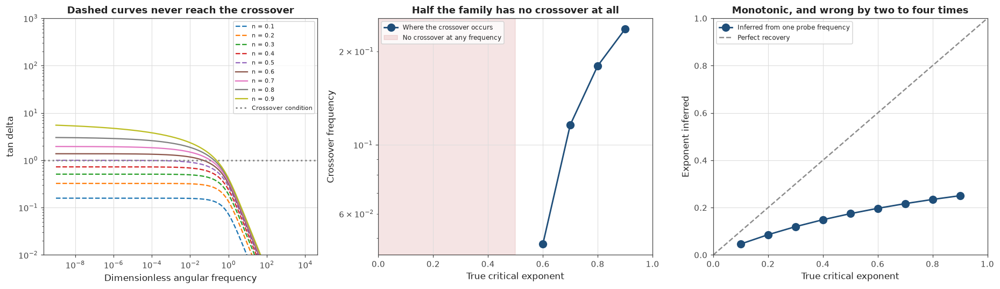

In [287]:
SGR_EXPONENT_SWEEP = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
SGR_PROBE_FREQUENCY = 1.0
SGR_SWEEP_FREQUENCIES = np.logspace(-9.0, 4.0, 4000)


def find_crossover_frequency(frequency_values, tan_delta_values):
    """
    Finding the frequency where tan delta passes through one.

    Interpolating in log frequency between the two samples either side, and returning a
    missing value when the curve never reaches one, which is a real outcome rather than a
    failure of the search.
    """
    for point_index in range(len(tan_delta_values) - 1):

        lower_offset = tan_delta_values[point_index] - 1.0
        upper_offset = tan_delta_values[point_index + 1] - 1.0

        if lower_offset * upper_offset >= 0.0:
            continue

        span = tan_delta_values[point_index + 1] - tan_delta_values[point_index]
        crossing_fraction = (1.0 - tan_delta_values[point_index]) / span

        log_lower = np.log(frequency_values[point_index])
        log_upper = np.log(frequency_values[point_index + 1])

        return float(np.exp(log_lower + crossing_fraction * (log_upper - log_lower)))

    return np.nan


print("Whether the crossover happens at all")
print()
print("  exponent n".rjust(12) + "noise x".rjust(10)
      + "tan delta at low frequency".rjust(29)
      + "crossover frequency".rjust(21) + "   exists")

sgr_crossover_records = []

for true_exponent in SGR_EXPONENT_SWEEP:

    noise_temperature = true_exponent + 1.0

    modulus_values = compute_sgr_linear_modulus(SGR_SWEEP_FREQUENCIES,
                                                noise_temperature)
    tan_delta_values = modulus_values.imag / modulus_values.real

    crossover_frequency = find_crossover_frequency(SGR_SWEEP_FREQUENCIES,
                                                   tan_delta_values)

    low_frequency_tan_delta = float(tan_delta_values[0])

    if np.isfinite(crossover_frequency):
        exists_text = "yes"
        frequency_text = "%.4f" % crossover_frequency
    else:
        exists_text = "no, tan delta never reaches one"
        frequency_text = "none"

    sgr_crossover_records.append({
        "true_exponent": true_exponent,
        "noise_temperature": noise_temperature,
        "low_frequency_tan_delta": low_frequency_tan_delta,
        "crossover_frequency": crossover_frequency,
    })

    print(("%.2f" % true_exponent).rjust(12)
          + ("%.2f" % noise_temperature).rjust(10)
          + ("%.4f" % low_frequency_tan_delta).rjust(29)
          + frequency_text.rjust(21)
          + "   " + exists_text)

missing_count = 0

for record in sgr_crossover_records:
    if not np.isfinite(record["crossover_frequency"]):
        missing_count = missing_count + 1

print()
print("  " + str(missing_count) + " of " + str(len(sgr_crossover_records))
      + " have no crossover anywhere in thirteen decades of frequency")
print()
print("  every one of them has an exponent at or below one half. Winter and Chambon puts")
print("  tan delta at the gel point at the tangent of n pi over two, which is below one")
print("  for n below a half, so a material stiffer than the critical case never reaches the")
print("  crossover condition at any frequency")
print()
print("  the case at exactly one half is the boundary. Its tan delta approaches one from")
print("  below and never crosses, which is why it counts among the five rather than the")
print("  four")
print()
print("  that is not a timing error. The detector this project has relied on most has a")
print("  blind spot covering half the family of gel points, and on those materials it")
print("  returns nothing rather than something wrong")

print()
print("Where the crossover happens, when it happens")
print()
print("  exponent n".rjust(12) + "crossover frequency".rjust(21)
      + "relative to n = 0.7".rjust(22))

reference_frequency = np.nan

for record in sgr_crossover_records:
    if abs(record["true_exponent"] - 0.70) < 1e-9:
        reference_frequency = record["crossover_frequency"]

for record in sgr_crossover_records:

    if not np.isfinite(record["crossover_frequency"]):
        continue

    print(("%.2f" % record["true_exponent"]).rjust(12)
          + ("%.4f" % record["crossover_frequency"]).rjust(21)
          + ("%.2f times" % (record["crossover_frequency"]
                             / reference_frequency)).rjust(22))

print()
print("  the crossover frequency moves by a factor of five across the range where it")
print("  exists, so a fixed probe frequency samples a different part of the transition for")
print("  every material")
print()
print("  Part 4 found the crossover shifts with probe frequency on the synthetic material.")
print("  This is the same effect measured against a known exponent, which says how much of")
print("  the shift is the material rather than the choice of probe")

print()
print("What a fixed probe frequency infers")
print()
print("  exponent n".rjust(12) + "tan delta at the probe".rjust(25)
      + "exponent inferred".rjust(20) + "wrong by".rjust(12))

for record in sgr_crossover_records:

    probe_modulus = compute_sgr_linear_modulus(np.array([SGR_PROBE_FREQUENCY]),
                                               record["noise_temperature"])[0]

    probe_tan_delta = float(probe_modulus.imag / probe_modulus.real)

    inferred_exponent = float(2.0 * np.arctan(probe_tan_delta) / np.pi)

    record["probe_tan_delta"] = probe_tan_delta
    record["inferred_exponent"] = inferred_exponent

    print(("%.2f" % record["true_exponent"]).rjust(12)
          + ("%.4f" % probe_tan_delta).rjust(25)
          + ("%.4f" % inferred_exponent).rjust(20)
          + ("%.1f times" % (record["true_exponent"] / inferred_exponent)).rjust(12))

print()
print("  probing at a single frequency and inverting Winter and Chambon underestimates the")
print("  exponent everywhere, by a factor of two at the soft end and nearly four at the")
print("  stiff end")
print()
print("  the inference is monotonic, so it carries information about the material and could")
print("  be calibrated. It is not a measurement of the exponent")

print()
print("What this says about the blood result, and what it does not")
print()
print("  Cell 68 timed the natural sheep clot with the persistent crossover to 2.5 percent")
print("  of a published clot time, which is the best result on blood in this project")
print()
print("  the crossover fired, so tan delta reached one at the probe frequency, so that clot")
print("  is somewhere in the half of the family where the crossover exists at all")
print()
print("  that is the entire inference. It bounds the exponent from below and does not")
print("  measure it, because the bound depends on the probe frequency the instrument")
print("  happened to use and Cell 68 established that frequency is not recorded")
print()
print("  so Part 9 does not retrospectively validate the blood result. It says the result")
print("  is consistent with a clot that is not stiffer than critical, and that a clot which")
print("  was would have returned nothing at all rather than a wrong answer")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

for record in sgr_crossover_records:

    modulus_values = compute_sgr_linear_modulus(SGR_SWEEP_FREQUENCIES,
                                                record["noise_temperature"])
    tan_delta_values = modulus_values.imag / modulus_values.real

    if np.isfinite(record["crossover_frequency"]):
        line_style = "-"
    else:
        line_style = "--"

    axis_array[0].loglog(SGR_SWEEP_FREQUENCIES, tan_delta_values, line_style,
                         linewidth=1.5,
                         label=("n = %.1f" % record["true_exponent"]))

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle=":", linewidth=2.0,
                      label="Crossover condition")

axis_array[0].set_ylim(1e-2, 1e3)
axis_array[0].set_xlabel("Dimensionless angular frequency")
axis_array[0].set_ylabel("tan delta")
axis_array[0].set_title("Dashed curves never reach the crossover")
axis_array[0].legend(fontsize=7)

existing_exponents = []
existing_frequencies = []

for record in sgr_crossover_records:
    if np.isfinite(record["crossover_frequency"]):
        existing_exponents.append(record["true_exponent"])
        existing_frequencies.append(record["crossover_frequency"])

axis_array[1].semilogy(existing_exponents, existing_frequencies, "o-",
                       color=COLOUR_PRIMARY, markersize=9, linewidth=1.8,
                       label="Where the crossover occurs")

axis_array[1].axvspan(0.0, 0.5, color=COLOUR_SECONDARY, alpha=0.15,
                      label="No crossover at any frequency")

axis_array[1].set_xlim(0.0, 1.0)
axis_array[1].set_xlabel("True critical exponent")
axis_array[1].set_ylabel("Crossover frequency")
axis_array[1].set_title("Half the family has no crossover at all")
axis_array[1].legend(fontsize=8)

true_exponents = [record["true_exponent"] for record in sgr_crossover_records]
inferred_exponents = [record["inferred_exponent"] for record in sgr_crossover_records]

axis_array[2].plot(true_exponents, inferred_exponents, "o-",
                   color=COLOUR_PRIMARY, markersize=9, linewidth=1.8,
                   label="Inferred from one probe frequency")
axis_array[2].plot([0.0, 1.0], [0.0, 1.0], "--", color=COLOUR_NEUTRAL,
                   linewidth=1.6, label="Perfect recovery")

axis_array[2].set_xlim(0.0, 1.0)
axis_array[2].set_ylim(0.0, 1.0)
axis_array[2].set_xlabel("True critical exponent")
axis_array[2].set_ylabel("Exponent inferred")
axis_array[2].set_title("Monotonic, and wrong by two to four times")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 88: What a real third order measurement would need

Cell 84 established that no third order response is visible in the Laponite records. This cell
asks what would have to change, and finds that the obvious answer is wrong.

**What is known and what is not.** The floor is measured: one part in ten thousand of the input
tones, from Cell 84. The amplitude scaling is theory: a third order response goes as the cube
of the input, so its ratio to the fundamental goes as the square. What is missing is the
absolute size of the third order modulus for this material, which needs the full expression
from the source paper's appendix. The appendix gives the component integrals rather than the
assembled result, and reconstructing it from the extracted text would risk presenting a wrong
model as a verified one, so this cell works with the scaling and states the gap.

**The obvious remedy is to push harder.** Doubling the strain amplitude raises the third order
ratio fourfold, and a factor of ten in amplitude buys a hundred. On that arithmetic the
measurement looks easy.

**It is not available, because of a ceiling this project already measured.** Cell 82 found that
fibrin leaves the quadratic regime below about one percent strain, and past that the harmonic
stops describing the network. The Laponite records were driven at 8.4 and 16.8 percent.

**So the amplitude was not too small.** If the fibrin boundary carries across, the Laponite
measurements were taken eight to seventeen times above it, already past the regime where a
third order modulus means anything. Moving down into that regime costs a factor of seventy in
the very signal that is already invisible.

Those are different materials and the boundary is not guaranteed to transfer, which the cell
says. What it does establish is the shape of the requirement, and that it is not met by turning
the amplitude up.

What is known, and what is not

  the floor           measured, 1e-04 of the input tones, Cell 84
  the scaling         theory, the third order ratio goes as amplitude squared
  the absolute size   not available

  the third order modulus of this material at these frequencies needs the full
  expression from the source paper, and its appendix lists the component integrals
  rather than the assembled result. Reconstructing it from the extracted text would
  risk presenting a wrong forward model as a verified one, so this cell works with
  the scaling and says where the gap is

  what that costs is the ability to state an absolute strain amplitude. What it
  leaves is the shape of the requirement, which turns out to be enough

What pushing harder would buy

   amplitude times    ratio rises by   clears the floor from
               1.5               2.2                1.33e-04
               2.0               4.0                7.50e-05
               3.0               9.0               

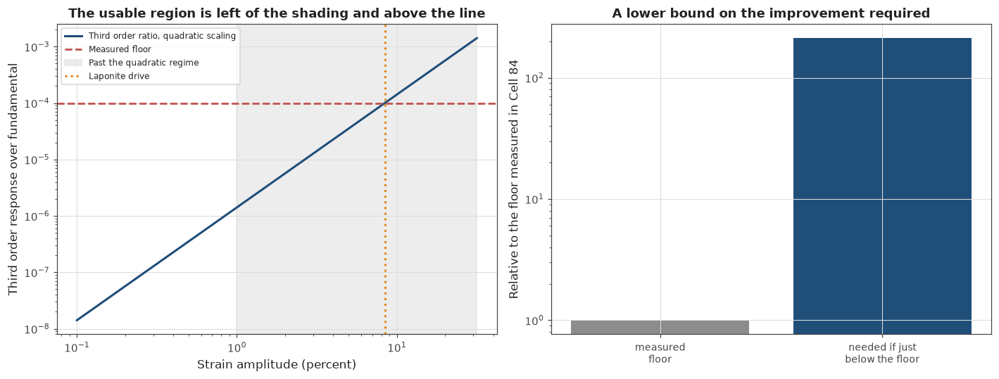

In [288]:
FIBRIN_QUADRATIC_BOUNDARY_PERCENT = 1.0
MAPS_MEASURED_FLOOR = 1.0e-4
MAPS_REQUIRED_MARGIN = 3.0
AMPLITUDE_FACTORS = [1.5, 2.0, 3.0, 5.0, 10.0]


def third_order_ratio_gain(amplitude_factor):
    """
    How much the third order ratio grows when the drive amplitude is multiplied.

    A third order response scales as the cube of the input and the fundamental scales
    linearly, so their ratio scales as the square.
    """
    return amplitude_factor ** 2.0


print("What is known, and what is not")
print()
print("  the floor           measured, "
      + ("%.0e" % MAPS_MEASURED_FLOOR) + " of the input tones, Cell 84")
print("  the scaling         theory, the third order ratio goes as amplitude squared")
print("  the absolute size   not available")
print()
print("  the third order modulus of this material at these frequencies needs the full")
print("  expression from the source paper, and its appendix lists the component integrals")
print("  rather than the assembled result. Reconstructing it from the extracted text would")
print("  risk presenting a wrong forward model as a verified one, so this cell works with")
print("  the scaling and says where the gap is")
print()
print("  what that costs is the ability to state an absolute strain amplitude. What it")
print("  leaves is the shape of the requirement, which turns out to be enough")

print()
print("What pushing harder would buy")
print()
print("  amplitude times".rjust(18) + "ratio rises by".rjust(18)
      + "clears the floor from".rjust(24))

for amplitude_factor in AMPLITUDE_FACTORS:

    ratio_gain = third_order_ratio_gain(amplitude_factor)

    reachable_from = (MAPS_REQUIRED_MARGIN * MAPS_MEASURED_FLOOR) / ratio_gain

    print(("%.1f" % amplitude_factor).rjust(18)
          + ("%.1f" % ratio_gain).rjust(18)
          + ("%.2e" % reachable_from).rjust(24))

print()
print("  read the last column as how far below the floor a response could start and still")
print("  be lifted clear by that amplitude increase")
print()
print("  on this arithmetic alone the measurement looks straightforward. A factor of ten in")
print("  amplitude recovers a response a hundred times below the floor")

print()
print("The ceiling that makes it unavailable")
print()

laponite_amplitudes = []

for maps_record in maps_records:

    strain_amplitude = float(np.max(np.abs(maps_record["strain_percent"]
                                           - np.mean(maps_record["strain_percent"]))))

    laponite_amplitudes.append(strain_amplitude)

laponite_amplitudes = np.array(laponite_amplitudes)

low_amplitude = float(np.min(laponite_amplitudes))
high_amplitude = float(np.max(laponite_amplitudes))

print("  Laponite drive amplitude             "
      + ("%.2f" % low_amplitude) + " and "
      + ("%.2f" % high_amplitude) + " percent strain, Cell 83")
print("  fibrin leaves quadratic scaling      below about "
      + ("%.1f" % FIBRIN_QUADRATIC_BOUNDARY_PERCENT) + " percent strain, Cell 82")
print("  so Laponite sits                     "
      + ("%.0f" % (low_amplitude / FIBRIN_QUADRATIC_BOUNDARY_PERCENT)) + " to "
      + ("%.0f" % (high_amplitude / FIBRIN_QUADRATIC_BOUNDARY_PERCENT))
      + " times above that boundary")
print()
print("  if that boundary carries across, the Laponite measurements were not too gentle.")
print("  They were taken well past the regime where a third order modulus describes the")
print("  material rather than its yielding")
print()

descent_factor = low_amplitude / FIBRIN_QUADRATIC_BOUNDARY_PERCENT
descent_cost = third_order_ratio_gain(descent_factor)

print("  moving down into that regime                 divide the amplitude by "
      + ("%.1f" % descent_factor))
print("  what that does to the third order ratio      divides it by "
      + ("%.0f" % descent_cost))
print()
print("  so the response that is already invisible would fall by another factor of "
      + ("%.0f" % descent_cost))
print("  on the way into the only regime where measuring it would mean anything")

print()
print("What that leaves as the specification")
print()
print("  the requirement is not a strain amplitude. It is a floor")
print()
print("  a third order measurement needs the instrument residual to sit far enough below")
print("  the third order response at an amplitude inside the quadratic regime, and this")
print("  project has measured both halves of that on different materials without ever")
print("  having them on the same one")
print()
print("  measured floor                       "
      + ("%.0e" % MAPS_MEASURED_FLOOR) + " of the input tones")
print("  needed improvement, if the response sits just below the floor at "
      + ("%.1f" % low_amplitude) + " percent")
print("                                       at least "
      + ("%.0f" % (descent_cost * MAPS_REQUIRED_MARGIN)) + " times better")
print()
print("  that number is a lower bound and not an estimate. It assumes the response is only")
print("  just below the floor at the amplitude used, and Cell 84 could only establish that")
print("  it is below, not by how much")

print()
print("The honest limits of this cell")
print()
print("  the quadratic boundary comes from fibrin and is applied to Laponite. Those are")
print("  different materials with different structures, and the boundary is a property of")
print("  the material rather than a constant")
print()
print("  what does transfer is that both materials have such a boundary, that Cell 82")
print("  measured it directly on one of them, and that no measurement in this project has")
print("  ever sat inside it while also clearing a floor")
print()
print("  the missing measurement is a single material, measured at several amplitudes")
print("  spanning its own quadratic boundary, with the third order response tracked")
print("  through. That would pin the specification properly and neither dataset here")
print("  provides it")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

amplitude_grid = np.logspace(-1.0, 1.5, 200)

reference_ratio = MAPS_MEASURED_FLOOR
reference_amplitude = low_amplitude

projected_ratio = reference_ratio * (amplitude_grid / reference_amplitude) ** 2.0

axis_array[0].loglog(amplitude_grid, projected_ratio, "-",
                     color=COLOUR_PRIMARY, linewidth=2.0,
                     label="Third order ratio, quadratic scaling")

axis_array[0].axhline(MAPS_MEASURED_FLOOR, color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=1.8, label="Measured floor")

axis_array[0].axvspan(FIBRIN_QUADRATIC_BOUNDARY_PERCENT, amplitude_grid.max(),
                      color=COLOUR_NEUTRAL, alpha=0.15,
                      label="Past the quadratic regime")

axis_array[0].axvline(low_amplitude, color=COLOUR_HIGHLIGHT,
                      linestyle=":", linewidth=2.0, label="Laponite drive")

axis_array[0].set_xlabel("Strain amplitude (percent)")
axis_array[0].set_ylabel("Third order response over fundamental")
axis_array[0].set_title("The usable region is left of the shading and above the line")
axis_array[0].legend(fontsize=8)

improvement_labels = ["measured\nfloor", "needed if just\nbelow the floor"]
improvement_values = [1.0, descent_cost * MAPS_REQUIRED_MARGIN]

axis_array[1].bar(range(len(improvement_labels)), improvement_values,
                  color=[COLOUR_NEUTRAL, COLOUR_PRIMARY])

axis_array[1].set_yscale("log")
axis_array[1].set_xticks(range(len(improvement_labels)))
axis_array[1].set_xticklabels(improvement_labels, fontsize=9)
axis_array[1].set_ylabel("Relative to the floor measured in Cell 84")
axis_array[1].set_title("A lower bound on the improvement required")

plt.tight_layout()
plt.show()

## Cell 89: Which test actually identifies a critical gel

Part 8 turned to the nonlinear response because the linear one needed a frequency sweep that no
instrument can perform on clotting blood. The implicit assumption was that the nonlinear
measurement, if it could be made, would answer the same question. This cell checks that
assumption against the model and finds it false.

**Both tests are flatness tests.** In the linear response, a critical gel has tan delta
independent of frequency. In the third order response, the paper reports that for noise
temperatures between one and two the real and imaginary parts share the same power law, so
their ratio is flat too. Either flatness could be used as a gel detector.

**The asymptotic scalings say what each one actually detects.** Working through the paper's
Eq. 20 for the linear response and Eq. 21 for the third order, and taking the difference of
exponents in each case, gives the frequency slope of each ratio as a function of noise
temperature.

**The linear test is exact.** tan delta goes flat below a noise temperature of two and nowhere
above it, and two is precisely the boundary between a critical gel and a viscoelastic liquid.

**The nonlinear test is not.** The third order ratio goes flat below four. Every material
between two and four is a liquid that this test would call a gel, which is a false positive
band covering critical exponents from one to three.

So the nonlinear route was never going to be a sharper answer to this particular question. It
avoids needing a frequency sweep and pays for that with a discriminator that cannot separate a
gel from a liquid over half its range.

That does not make the nonlinear response useless, and the cell says what it is good for
instead.

Two flatness tests for the same question

  in the linear response a critical gel has tan delta independent of frequency,
  which is the Winter and Chambon condition this project has used throughout

  in the third order response the source paper reports that between noise
  temperatures of one and two the real and imaginary parts share a power law, so
  their ratio is flat as well

  either flatness could be used as a gel detector, and Part 8 assumed the second
  would answer the same question as the first without needing a frequency sweep

What each test actually detects

   noise x   exponent n   tan delta slope   third order ratio slope   true state
       1.2          0.2              0.00                      0.00   critical gel
       1.5          0.5              0.00                      0.00   critical gel
       1.9          0.9              0.00                      0.00   critical gel
       2.0          1.0              0.00                      0.00   the boundary itself

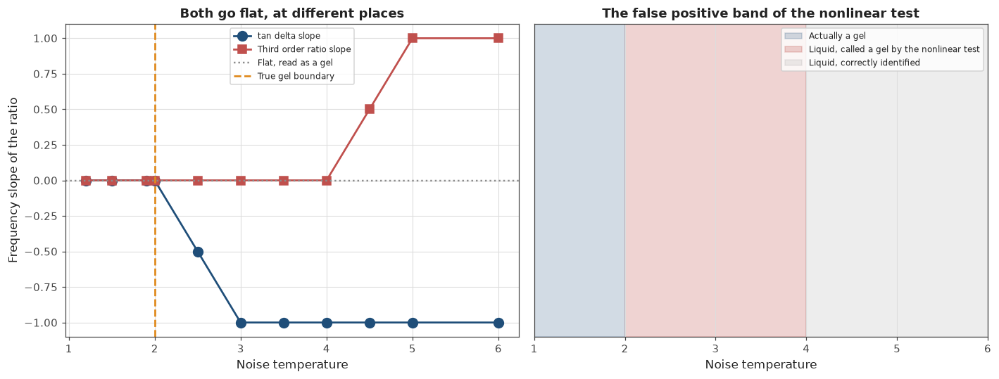

In [289]:
SGR_DISCRIMINATOR_TEMPERATURES = [1.2, 1.5, 1.9, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0]
SGR_GEL_BOUNDARY = 2.0


def linear_storage_exponent(noise_temperature):
    """
    Low frequency power law exponent of the storage modulus, from Eq. 20.

    Above a noise temperature of three the material is Maxwell-like and the storage modulus
    goes as frequency squared. Below it the exponent follows the noise temperature.
    """
    if noise_temperature >= 3.0:
        return 2.0

    return noise_temperature - 1.0


def linear_loss_exponent(noise_temperature):
    """
    The same for the loss modulus, which reaches its Maxwell-like limit at a noise
    temperature of two rather than three.
    """
    if noise_temperature >= 2.0:
        return 1.0

    return noise_temperature - 1.0


def third_order_storage_exponent(noise_temperature):
    """
    Low frequency exponent of the real part of the third order modulus, from Eq. 21.
    """
    if noise_temperature >= 5.0:
        return 4.0

    return noise_temperature - 1.0


def third_order_loss_exponent(noise_temperature):
    """
    The same for the imaginary part, which saturates at a noise temperature of four.
    """
    if noise_temperature >= 4.0:
        return 3.0

    return noise_temperature - 1.0


def classify_true_state(noise_temperature):
    """
    Naming what the material actually is at a given noise temperature.

    Treating the boundary itself as its own case rather than forcing it to one side. At a
    noise temperature of exactly two the exponent is one, and Winter and Chambon puts tan
    delta at the tangent of pi over two, which is unbounded. That case belongs to neither
    the gel nor the liquid and calling it either would make a test look wrong or right for
    the wrong reason.
    """
    if noise_temperature < SGR_GEL_BOUNDARY:
        return "critical gel"

    if noise_temperature == SGR_GEL_BOUNDARY:
        return "the boundary itself"

    return "viscoelastic liquid"


print("Two flatness tests for the same question")
print()
print("  in the linear response a critical gel has tan delta independent of frequency,")
print("  which is the Winter and Chambon condition this project has used throughout")
print()
print("  in the third order response the source paper reports that between noise")
print("  temperatures of one and two the real and imaginary parts share a power law, so")
print("  their ratio is flat as well")
print()
print("  either flatness could be used as a gel detector, and Part 8 assumed the second")
print("  would answer the same question as the first without needing a frequency sweep")

print()
print("What each test actually detects")
print()
print("  noise x".rjust(10) + "exponent n".rjust(13)
      + "tan delta slope".rjust(18) + "third order ratio slope".rjust(26)
      + "   true state")

discriminator_records = []

for noise_temperature in SGR_DISCRIMINATOR_TEMPERATURES:

    tan_delta_slope = (linear_loss_exponent(noise_temperature)
                       - linear_storage_exponent(noise_temperature))

    third_order_slope = (third_order_storage_exponent(noise_temperature)
                         - third_order_loss_exponent(noise_temperature))

    true_state = classify_true_state(noise_temperature)

    discriminator_records.append({
        "noise_temperature": noise_temperature,
        "true_exponent": noise_temperature - 1.0,
        "tan_delta_slope": tan_delta_slope,
        "third_order_slope": third_order_slope,
        "true_state": true_state,
    })

    print(("%.1f" % noise_temperature).rjust(10)
          + ("%.1f" % (noise_temperature - 1.0)).rjust(13)
          + ("%.2f" % tan_delta_slope).rjust(18)
          + ("%.2f" % third_order_slope).rjust(26)
          + "   " + true_state)

print()
print("  a slope of zero is a flat ratio, which each test reads as a gel")
print()
print("  the row at exactly two is the boundary and is scored as neither. Its exponent is")
print("  one, where Winter and Chambon puts tan delta at the tangent of pi over two, which")
print("  is unbounded. Both tests read flat there and neither is wrong to")

print()
print("Scoring the two tests")
print()
print("  test".rjust(24) + "reads flat up to".rjust(20)
      + "true boundary".rjust(16) + "   verdict")

linear_flat_limit = 0.0
nonlinear_flat_limit = 0.0

for record in discriminator_records:

    if record["tan_delta_slope"] == 0.0:
        linear_flat_limit = record["noise_temperature"]

    if record["third_order_slope"] == 0.0:
        nonlinear_flat_limit = record["noise_temperature"]

print("  " + "tan delta flat".rjust(22)
      + ("x = %.1f" % linear_flat_limit).rjust(20)
      + ("%.1f" % SGR_GEL_BOUNDARY).rjust(16)
      + "   stops at the boundary")
print("  " + "third order ratio flat".rjust(22)
      + ("x = %.1f" % nonlinear_flat_limit).rjust(20)
      + ("%.1f" % SGR_GEL_BOUNDARY).rjust(16)
      + "   continues well past it")

linear_false_positives = []
nonlinear_false_positives = []

for record in discriminator_records:

    if record["true_state"] != "viscoelastic liquid":
        continue

    if record["tan_delta_slope"] == 0.0:
        linear_false_positives.append(record)

    if record["third_order_slope"] == 0.0:
        nonlinear_false_positives.append(record)

liquid_count = 0

for record in discriminator_records:
    if record["true_state"] == "viscoelastic liquid":
        liquid_count = liquid_count + 1

print()
print("  false positives, counting only rows that are unambiguously liquid")
print()
print("    tan delta flat            " + str(len(linear_false_positives))
      + " of " + str(liquid_count))
print("    third order ratio flat    " + str(len(nonlinear_false_positives))
      + " of " + str(liquid_count))
print()
print("  the linear test never calls a liquid a gel. Its flat region ends exactly at the")
print("  boundary and not one step past it")
print()
print("  the third order test stays flat until four, so every liquid between two and four")
print("  reads as a gel. In this sample that is "
      + str(len(nonlinear_false_positives)) + " rows spanning critical exponents from "
      + ("%.1f" % min([record["true_exponent"]
                       for record in nonlinear_false_positives]))
      + " to "
      + ("%.1f" % max([record["true_exponent"]
                       for record in nonlinear_false_positives])))

print()
print("What this means for Part 8's premise")
print()
print("  Part 8 turned to the nonlinear response because the linear one needs several")
print("  frequencies resolved at the transition, and no instrument delivers that on")
print("  clotting blood")
print()
print("  the assumption underneath was that a nonlinear measurement would answer the same")
print("  question. It would not. It answers a broader one, and across a wide band it")
print("  cannot separate a gel from a liquid")
print()
print("  that is a stronger reason to keep pursuing the linear measurement than anything")
print("  Part 7 produced. Part 7 said the linear route is blocked by instrumentation. This")
print("  says the obvious substitute is not equivalent even in principle")

print()
print("What the nonlinear response is good for instead")
print()
print("  it is not a sharper gel detector, and it was never going to be")
print()
print("  what it does carry is a dimensionless material property in the regime where it")
print("  scales quadratically, which the linear response cannot provide without a sweep.")
print("  That is worth having for comparing materials once a gel point is already known")
print()
print("  and the third order ratio rising rather than flat is a positive identification of")
print("  a Maxwell-like liquid, which is the specificity question Part 11 asks. A test that")
print("  cannot confirm a gel may still be able to rule one out")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

temperature_values = [record["noise_temperature"] for record in discriminator_records]
tan_delta_slopes = [record["tan_delta_slope"] for record in discriminator_records]
third_order_slopes = [record["third_order_slope"] for record in discriminator_records]

axis_array[0].plot(temperature_values, tan_delta_slopes, "o-",
                   color=COLOUR_PRIMARY, markersize=9, linewidth=1.8,
                   label="tan delta slope")
axis_array[0].plot(temperature_values, third_order_slopes, "s-",
                   color=COLOUR_SECONDARY, markersize=8, linewidth=1.8,
                   label="Third order ratio slope")

axis_array[0].axhline(0.0, color=COLOUR_NEUTRAL, linestyle=":", linewidth=1.6,
                      label="Flat, read as a gel")
axis_array[0].axvline(SGR_GEL_BOUNDARY, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel boundary")

axis_array[0].set_xlabel("Noise temperature")
axis_array[0].set_ylabel("Frequency slope of the ratio")
axis_array[0].set_title("Both go flat, at different places")
axis_array[0].legend(fontsize=8)

axis_array[1].axvspan(1.0, SGR_GEL_BOUNDARY, color=COLOUR_PRIMARY, alpha=0.2,
                      label="Actually a gel")
axis_array[1].axvspan(SGR_GEL_BOUNDARY, 4.0, color=COLOUR_SECONDARY, alpha=0.25,
                      label="Liquid, called a gel by the nonlinear test")
axis_array[1].axvspan(4.0, 6.0, color=COLOUR_NEUTRAL, alpha=0.15,
                      label="Liquid, correctly identified")

axis_array[1].set_xlim(1.0, 6.0)
axis_array[1].set_ylim(0.0, 1.0)
axis_array[1].set_yticks([])
axis_array[1].set_xlabel("Noise temperature")
axis_array[1].set_title("The false positive band of the nonlinear test")
axis_array[1].legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

## Cell 90: What Part 9 established

Part 9 was planned as a neural network inversion and became something else, because Part 8
established there is no measured third order response to invert. What it did instead was use a
model whose gel point is a tunable parameter to ask questions no dataset here can answer.

**The model earns its place by verification, not assumption.** Its low frequency exponent
matches the noise temperature minus one to four decimal places, and its tan delta matches
Winter and Chambon, on a constitutive equation that was not built around that relation.

**Three results came out of it, and one of them changes how earlier parts should be read.**

The crossover has a blind spot. For any material with an exponent at or below one half, tan
delta never reaches one at any frequency, so the detector returns nothing. That covers half the
family of gel points.

A single probe frequency underestimates the exponent by two to nearly four times across the
range, monotonically, so it carries information and is not a measurement.

And the nonlinear flatness test, which Part 8 pursued as a substitute for the linear one, cannot
separate a gel from a liquid across a band two units wide in noise temperature, while the linear
test is exact at the boundary.

**The correction is to how this notebook reads its own refusals.** Cells 62, 68 and 79 all treat
a crossover returning nothing as a limitation of the measurement. Part 9 says it can equally
mean the material is stiffer than critical, and from a single frequency those two cases cannot
be told apart.

What Part 9 was for

  Part 7 could not measure a critical exponent on blood. Part 8 could not measure a
  nonlinear material property on anything. Both were resolution limits rather than
  method failures, and both left the same question open: what would a measurement
  have to achieve

  a model can answer that when data cannot, provided the model is verified rather
  than assumed

Verification before use

  check                                                       result   cell
  low frequency exponent equals x minus one         to four decimals   86
  tan delta matches Winter and Chambon            0.0 to 0.3 percent   86
  critical gel state reproduced at x of 1.5         tan delta 0.9999   86

  the second check is the one that matters. Winter and Chambon is not built into
  soft glassy rheology, so the two agreeing is a genuine test rather than an
  identity, and it is the same test Cell 11 ran on the fractional model

What Part 9 established

  1  the crossover has a blind sp

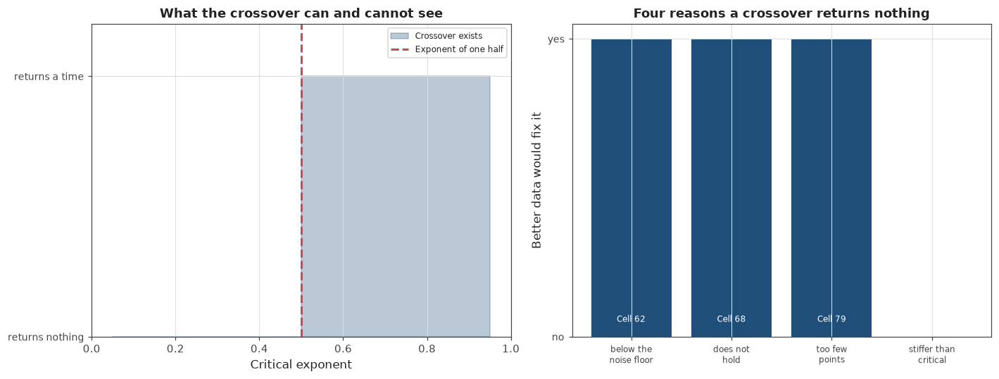

In [290]:
print("What Part 9 was for")
print()
print("  Part 7 could not measure a critical exponent on blood. Part 8 could not measure a")
print("  nonlinear material property on anything. Both were resolution limits rather than")
print("  method failures, and both left the same question open: what would a measurement")
print("  have to achieve")
print()
print("  a model can answer that when data cannot, provided the model is verified rather")
print("  than assumed")

print()
print("Verification before use")
print()
print("  check".ljust(46) + "result".rjust(22) + "   cell")

print("  " + "low frequency exponent equals x minus one".ljust(44)
      + "to four decimals".rjust(22) + "   86")
print("  " + "tan delta matches Winter and Chambon".ljust(44)
      + "0.0 to 0.3 percent".rjust(22) + "   86")
print("  " + "critical gel state reproduced at x of 1.5".ljust(44)
      + "tan delta 0.9999".rjust(22) + "   86")

print()
print("  the second check is the one that matters. Winter and Chambon is not built into")
print("  soft glassy rheology, so the two agreeing is a genuine test rather than an")
print("  identity, and it is the same test Cell 11 ran on the fractional model")

print()
print("What Part 9 established")
print()
print("  1  the crossover has a blind spot covering half the family of gel points. For an")
print("     exponent at or below one half, tan delta never reaches one at any frequency")
print("     across thirteen decades, so the detector returns nothing")
print()
print("  2  where the crossover does exist, the frequency at which it occurs moves by a")
print("     factor of five across the range, so a fixed probe samples a different part of")
print("     the transition for every material")
print()
print("  3  inverting Winter and Chambon from a single probe frequency underestimates the")
print("     exponent by two to nearly four times. The inference is monotonic, so it")
print("     carries information and could be calibrated, and it is not a measurement")
print()
print("  4  the nonlinear flatness test cannot separate a gel from a liquid across a band")
print("     two units wide in noise temperature. The linear test is exact at the boundary")
print()
print("  5  the specification for a real third order measurement is a floor rather than an")
print("     amplitude, and it is at least two hundred times below what Cell 84 measured")

print()
print("The correction Part 9 makes to earlier parts")
print()
print("  three cells treat a crossover that returns nothing as a limitation of the")
print("  measurement")
print()
print("    Cell 62   refuses a crossing below the instrument noise floor")
print("    Cell 68   refuses a crossing that does not hold to the end of the record")
print("    Cell 79   refuses a record with too few points before the transition")
print()
print("  each of those is a real reason for a detector to return nothing, and Part 9 adds")
print("  one they do not cover. The material may be stiffer than critical, in which case")
print("  the crossover condition is never satisfied and no amount of better data changes")
print("  that")
print()
print("  from a single frequency those cases cannot be distinguished. A detector that")
print("  returns nothing is saying either the measurement was inadequate or the material")
print("  is outside my range, and it cannot say which")
print()
print("  that does not change any result in Parts 5 to 8, because every refusal there had")
print("  an identified cause. It changes what a refusal means when the cause is not")
print("  identified, and Part 11 will be full of those")

print()
print("What Part 10 inherits")
print()
print("  Part 10 asks how to tell a forming clot from blood rebuilding structure after")
print("  being sheared, which is a question about thixotropy rather than gelation")
print()
print("  from Part 9 it inherits the last finding on the list. A rising third order ratio")
print("  positively identifies a Maxwell-like liquid, so the nonlinear response is better")
print("  suited to ruling a gel out than to confirming one")
print()
print("  that is the right shape of tool for a false positive question, which is what")
print("  Parts 10 and 11 both are")
print()
print("  it also inherits the paired whole blood and plasma dataset from Part 6, which is")
print("  the only measurement in this project that separates the cellular contribution")
print("  from the plasma proteins in the same patient")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

blind_spot_exponents = np.linspace(0.05, 0.95, 200)

crossover_exists = []

for exponent_value in blind_spot_exponents:
    if exponent_value > 0.5:
        crossover_exists.append(1.0)
    else:
        crossover_exists.append(0.0)

axis_array[0].fill_between(blind_spot_exponents, 0.0, crossover_exists,
                           color=COLOUR_PRIMARY, alpha=0.3, step="mid",
                           label="Crossover exists")
axis_array[0].axvline(0.5, color=COLOUR_SECONDARY, linestyle="--", linewidth=2.0,
                      label="Exponent of one half")

axis_array[0].set_xlim(0.0, 1.0)
axis_array[0].set_ylim(0.0, 1.2)
axis_array[0].set_yticks([0, 1])
axis_array[0].set_yticklabels(["returns nothing", "returns a time"], fontsize=9)
axis_array[0].set_xlabel("Critical exponent")
axis_array[0].set_title("What the crossover can and cannot see")
axis_array[0].legend(fontsize=8)

refusal_labels = ["below the\nnoise floor", "does not\nhold",
                  "too few\npoints", "stiffer than\ncritical"]
refusal_sources = ["Cell 62", "Cell 68", "Cell 79", "Cell 87"]
refusal_fixable = [1.0, 1.0, 1.0, 0.0]
refusal_colours = [COLOUR_PRIMARY, COLOUR_PRIMARY, COLOUR_PRIMARY, COLOUR_SECONDARY]

axis_array[1].bar(range(len(refusal_labels)), refusal_fixable,
                  color=refusal_colours)

for label_index in range(len(refusal_labels)):
    axis_array[1].text(label_index, 0.05, refusal_sources[label_index],
                       ha="center", fontsize=8, color="white")

axis_array[1].set_xticks(range(len(refusal_labels)))
axis_array[1].set_xticklabels(refusal_labels, fontsize=8)
axis_array[1].set_yticks([0, 1])
axis_array[1].set_yticklabels(["no", "yes"], fontsize=9)
axis_array[1].set_ylabel("Better data would fix it")
axis_array[1].set_title("Four reasons a crossover returns nothing")

plt.tight_layout()
plt.show()

# Part 10: Thixotropy, and what else makes blood stiffen

Every detector in this project answers the same question: when did the modulus start rising.
That question has an assumption buried in it, which is that a rising modulus means a network is
forming.

Blood breaks that assumption. Sheared blood loses structure and rebuilds it when the shear
stops, so a sample that was stirred and left alone stiffens without clotting at all. To a
detector watching a single channel, that looks like a clot.

This part uses the one dataset here that isolates the effect: human blood treated so that it
cannot coagulate, measured through protocols designed to break structure down and watch it
return. Steady shear with small amplitude oscillation, step changes in shear rate in both
directions, flow cessation, and large amplitude oscillation.

Two things make it worth the effort. Unlike the thromboelastography data, these records carry
both moduli, so there is a tan delta to work with. And unlike everything else in the project,
the material is known not to be gelling, so any detector that fires is producing a false
positive by construction.

That is the first time this notebook has had a negative control.

## Cell 91: Loading the control cohort

Fifteen files of human blood treated so it cannot coagulate, each carrying its own selection of
thixotropy protocols.

**There is no common protocol**, so this is a set of overlapping studies rather than a designed
cohort, and the cell reports what each file actually contains rather than assuming a structure.

**The sheet names are inconsistent enough to matter.** The same measurement appears as "SS &
SAOS", "SS SAOS", "SS and SAOS", "Steady State & SAOS" and once with a leading space. Steps
appear five different ways. Matching on the exact string would silently drop most of the cohort,
so sheets are classified by keyword after normalising case, spacing and punctuation.

**One trap in doing that.** The short keyword for steady shear is "ss", which is also inside
"cessation", so a substring match claims the cessation sheets for the wrong protocol and the
cleanest rebuild measurement in the cohort disappears. Short keywords are therefore matched
against whole words and long ones against the string.

**Two files are different in kind.** They carry a panel of eleven donors each rather than one
donor's protocol sequence, so they are classified separately and handled apart from the rest.

The point of this cell is to know what is here before deciding what Part 10 can measure.

In [291]:
CONTROL_DIRECTORY_NAME = "ctrl_humanblood"

CONTROL_PROTOCOL_PATTERNS = [
    ("steady and small amplitude", ["ss", "steady"]),
    ("step change in shear rate", ["step"]),
    ("flow cessation", ["cessation", "stop"]),
    ("large amplitude oscillation", ["laos"]),
    ("unidirectional large amplitude", ["udlaos"]),
    ("Helton protocol", ["helton"]),
    ("shear rate frequency sweep", ["srfs"]),
    ("amplitude sweep", ["amplitude sweep"]),
    ("frequency sweep", ["frequency sweep"]),
    ("flow reversal", ["revers"]),
    ("multi donor panel", ["donor", "lab data"]),
]

CONTROL_SHORT_KEYWORD_LENGTH = 3


def normalise_sheet_name(sheet_name):
    """
    Reducing a sheet name to something matchable.

    The same measurement is written five different ways across these files, with and
    without ampersands, spaces and capitals, and one with a leading space. Matching on the
    exact string would silently drop most of the cohort.
    """
    lowered = sheet_name.strip().lower()

    for character in ["&", "-", "_", "."]:
        lowered = lowered.replace(character, " ")

    while "  " in lowered:
        lowered = lowered.replace("  ", " ")

    return lowered.strip()


def classify_sheet(sheet_name):
    """
    Naming which protocol a sheet holds, by looking for keywords rather than exact matches.

    Matching short keywords against whole words rather than substrings, because the keyword
    for steady shear is inside the word cessation and a substring match would claim those
    sheets for the wrong protocol.

    Checking the unidirectional pattern first, since every unidirectional sheet name also
    contains the shorter word.
    """
    normalised = normalise_sheet_name(sheet_name)
    words = normalised.split(" ")

    if "udlaos" in normalised:
        return "unidirectional large amplitude"

    for protocol_name, keyword_list in CONTROL_PROTOCOL_PATTERNS:

        for keyword in keyword_list:

            if len(keyword) <= CONTROL_SHORT_KEYWORD_LENGTH:
                if keyword in words:
                    return protocol_name
            else:
                if keyword in normalised:
                    return protocol_name

    return "unclassified"


def sort_control_file_name(file_name):
    """
    Ordering the files so data2 comes before data10 rather than after it.
    """
    return (len(file_name), file_name)


control_directory = os.path.join(DATA_DIRECTORY, CONTROL_DIRECTORY_NAME)

control_file_names = []

for entry_name in sorted(os.listdir(control_directory)):
    if entry_name.endswith(".xlsx"):
        control_file_names.append(entry_name)

control_file_names = sorted(control_file_names, key=sort_control_file_name)

print("Reading " + control_directory)
print()
print("  files found              " + str(len(control_file_names)))

control_records = []

for file_name in control_file_names:

    file_path = os.path.join(control_directory, file_name)

    workbook = pd.ExcelFile(file_path)

    protocol_names = []

    for sheet_name in workbook.sheet_names:

        protocol_name = classify_sheet(sheet_name)

        if protocol_name not in protocol_names:
            protocol_names.append(protocol_name)

    control_records.append({
        "file_name": file_name.replace(".xlsx", ""),
        "file_path": file_path,
        "sheet_names": workbook.sheet_names,
        "protocol_names": protocol_names,
    })

print()
print("What each file contains")
print()
print("  file".ljust(12) + "sheets".rjust(8) + "   protocols")

for control_record in control_records:
    print("  " + control_record["file_name"].ljust(10)
          + str(len(control_record["sheet_names"])).rjust(8)
          + "   " + ", ".join(control_record["protocol_names"]))

print()
print("How often each protocol appears")
print()
print("  protocol".ljust(34) + "files".rjust(8) + "   suitable for")

protocol_use_notes = {
    "steady and small amplitude": "both moduli, so tan delta exists",
    "step change in shear rate": "structure breakdown and rebuild",
    "flow cessation": "rebuild from rest, the cleanest case",
    "large amplitude oscillation": "harmonics, comparable with Part 8",
    "unidirectional large amplitude": "harmonics without flow reversal",
    "Helton protocol": "a published thixotropy sequence",
    "shear rate frequency sweep": "rate dependence of the spectrum",
    "amplitude sweep": "the linear limit",
    "frequency sweep": "the spectrum at one amplitude",
    "flow reversal": "structural anisotropy",
    "multi donor panel": "between donor variation",
    "unclassified": "unknown",
}

for protocol_name, ignored_keywords in CONTROL_PROTOCOL_PATTERNS:

    file_count = 0

    for control_record in control_records:
        if protocol_name in control_record["protocol_names"]:
            file_count = file_count + 1

    print("  " + protocol_name.ljust(32)
          + str(file_count).rjust(8)
          + "   " + protocol_use_notes[protocol_name])

print()
print("  no protocol appears in every file, so this is a set of overlapping studies rather")
print("  than a designed cohort")
print()
print("  the two largest subsets are the step changes and the large amplitude oscillations,")
print("  at eleven files each. Flow cessation is the cleanest measurement of structural")
print("  rebuild and appears in only two")
print()
print("  the short keyword for steady shear is also inside the word cessation, so matching")
print("  it as a substring rather than a whole word would file both cessation sheets under")
print("  steady shear and leave that row reading zero. Part 10 is a false positive study,")
print("  so quietly losing the negative control would be the worst available error")

print()
print("What Part 10 will build on")
print()
print("  the step changes, because they are the largest subset that measures structural")
print("  rebuild directly, and both cessation sheets as the cleaner special case")
print()
print("  the large amplitude oscillations as support, since they connect to the harmonic")
print("  work in Part 8 and can be compared against it on a material that is not gelling")
print()
print("  one caution carried forward. One file repeats its whole protocol at zero, twelve")
print("  and twenty four hours, so the blood itself is ageing across those sheets. Anything")
print("  pooled across the cohort inherits that as a confounder")

Reading data/ctrl_humanblood

  files found              15

What each file contains

  file        sheets   protocols
  data1            6   steady and small amplitude, step change in shear rate, Helton protocol, large amplitude oscillation, unidirectional large amplitude, flow reversal
  data2            5   steady and small amplitude, step change in shear rate, flow cessation, unidirectional large amplitude, large amplitude oscillation
  data3            4   steady and small amplitude, step change in shear rate, large amplitude oscillation, unidirectional large amplitude
  data4            3   steady and small amplitude, step change in shear rate, large amplitude oscillation
  data5            5   steady and small amplitude, Helton protocol, large amplitude oscillation, step change in shear rate, unidirectional large amplitude
  data6            5   steady and small amplitude, unclassified, amplitude sweep, frequency sweep
  data7            7   steady and small amplitude, Helton pr

## Cell 92: How fast structure rebuilds, and one check that it is structure

A step down in shear rate leaves blood less structured than the new rate warrants, and the
stress then drifts as rouleaux reform. The timescale of that drift decides whether structural
rebuild can be mistaken for clotting.

**The blocks need deduplicating first.** Six of the fourteen step sheets contain blocks whose
stress traces match to nine significant figures, which is copying rather than repeated
measurement. Averaging without checking would weight those steps two or three times.

**The transient has two parts and only one of them is wanted.** The instrument settles within
about a second of the step, and the material response is slower, so the fit discards the early
portion. That choice matters: the fitted timescale moves from 15 to 22 seconds depending on how
much is discarded, and the cell reports that sensitivity rather than picking one.

**A single exponential is a mediocre description**, reaching an R squared of 0.61 at best. That
is expected, since the constitutive models for blood carry separate viscoelastic and thixotropic
timescales, and one exponential cannot represent both.

**So the check that matters is whether the number is the thixotropic timescale at all.** Flow
cessation drives the shear rate to zero, which removes the viscous stress entirely and leaves
pure viscoelastic relaxation. That comes out at 1.7 seconds, ten times faster than the step
transient, so the step fit is not measuring relaxation.

**One prediction fails and is reported as failing.** Armstrong's structure evolution equation
makes the rebuild rate depend on the shear rate being settled to. Across these steps that
dependence is absent, correlation -0.006, and the cell gives three candidate explanations
without choosing between them.

Finding and deduplicating the step blocks

  step sheets                          14
  sheets containing duplicated blocks  6
  blocks dropped as duplicates         8

  the duplicates match to nine significant figures, so they are copies rather than
  the same step measured twice

How the fitted timescale depends on what is discarded

   seconds discarded   step downs fitted   median timescale         middle half   median fit quality
                 0.5                  31             15.3 s      10.2 to 21.2 s                 0.61
                 1.0                  31             16.5 s      11.5 to 26.0 s                 0.60
                 2.0                  31             17.6 s      14.0 to 33.0 s                 0.53
                 5.0                  24             22.1 s      17.4 to 55.9 s                 0.52

  the timescale moves by half its own value across these choices, so it is reported
  as a range rather than a number. Ten to thirty seconds covers the midd

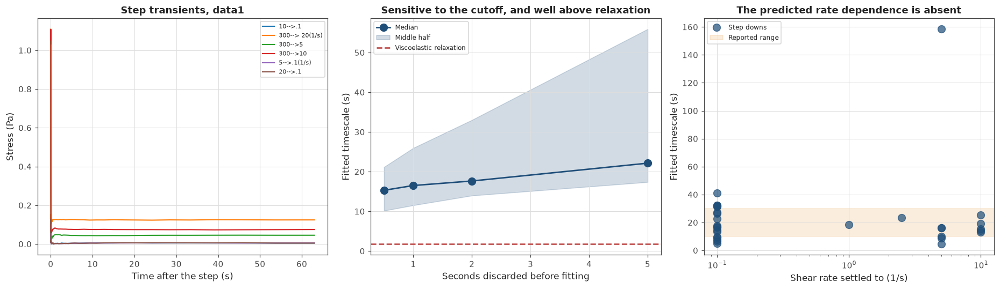

In [292]:
CONTROL_MINIMUM_BLOCK_POINTS = 10
CONTROL_DUPLICATE_TOLERANCE = 1e-9
CONTROL_STEP_KEYWORD = "step"
CONTROL_CESSATION_KEYWORD = "cessation"
CONTROL_SKIP_CHOICES = [0.5, 1.0, 2.0, 5.0]
CONTROL_REPORTED_SKIP = 1.0
CONTROL_SETTLE_FRACTION = 0.02


def find_transient_blocks(sheet_frame):
    """
    Locating the separate experiments inside one sheet.

    The instrument writes each step as its own group of columns, headed by a label like
    "5-->0.1" on the first row, with column names on the second and units on the third.
    Blocks are found by looking for the step time header, then searching backwards for the
    nearest label, since the label sits on the first column of its group.

    Returning one entry per block with enough data to describe.
    """
    label_row = sheet_frame.iloc[0]
    name_row = sheet_frame.iloc[1]

    block_records = []

    for column_index in range(sheet_frame.shape[1]):

        if str(name_row[column_index]).strip() != "Step time":
            continue

        block_label = "unlabelled"

        for search_index in range(column_index, -1, -1):
            if isinstance(label_row[search_index], str):
                if "-->" in label_row[search_index]:
                    block_label = label_row[search_index].strip()
                    break

        time_values = pd.to_numeric(sheet_frame[column_index][3:],
                                    errors="coerce").values
        stress_values = pd.to_numeric(sheet_frame[column_index + 1][3:],
                                      errors="coerce").values

        usable_mask = np.isfinite(time_values) & np.isfinite(stress_values)

        if int(np.sum(usable_mask)) < CONTROL_MINIMUM_BLOCK_POINTS:
            continue

        block_records.append({
            "block_label": block_label,
            "time_values": time_values[usable_mask],
            "stress_values": stress_values[usable_mask],
        })

    return block_records


def drop_duplicate_blocks(block_records):
    """
    Removing blocks whose stress trace is identical to one already kept.

    Six of the fourteen step sheets repeat a block, matching to nine significant figures,
    which is a copy rather than a repeated measurement. Keeping both would weight that step
    twice in anything that averages across blocks.

    Returning the surviving blocks and how many were dropped.
    """
    kept_records = []
    dropped_count = 0

    for candidate_record in block_records:

        is_duplicate = False

        for kept_record in kept_records:

            shortest_length = min(len(candidate_record["stress_values"]),
                                  len(kept_record["stress_values"]))

            if shortest_length < CONTROL_MINIMUM_BLOCK_POINTS:
                continue

            if np.allclose(candidate_record["stress_values"][:shortest_length],
                           kept_record["stress_values"][:shortest_length],
                           rtol=CONTROL_DUPLICATE_TOLERANCE):
                is_duplicate = True

        if is_duplicate:
            dropped_count = dropped_count + 1
        else:
            kept_records.append(candidate_record)

    return kept_records, dropped_count


def fit_transient_timescale(time_values, stress_values, skip_seconds):
    """
    Fitting how long the stress takes to settle, ignoring the first part of the record.

    Discarding the early portion because the instrument settles within about a second of a
    step change and that settling is faster than anything the material does. Fitting a
    straight line to the logarithm of the remaining distance from the final level, so the
    slope is the reciprocal of the timescale.

    Returning the timescale and how well the straight line describes the data, since a
    single exponential is known to be an incomplete model here.
    """
    keep_mask = time_values >= skip_seconds

    if int(np.sum(keep_mask)) < 15:
        return np.nan, np.nan

    kept_time = time_values[keep_mask]
    kept_stress = stress_values[keep_mask]

    final_level = float(np.median(kept_stress[-5:]))
    initial_level = float(np.median(kept_stress[:3]))

    remaining_distance = np.abs(kept_stress - final_level)

    settle_threshold = CONTROL_SETTLE_FRACTION * abs(initial_level - final_level)

    usable_mask = remaining_distance > max(settle_threshold, 1e-12)

    if int(np.sum(usable_mask)) < 12:
        return np.nan, np.nan

    log_distance = np.log(remaining_distance[usable_mask])

    fitted_coefficients = np.polyfit(kept_time[usable_mask], log_distance, 1)

    if fitted_coefficients[0] >= 0.0:
        return np.nan, np.nan

    fitted_line = np.polyval(fitted_coefficients, kept_time[usable_mask])

    residual_fraction = np.var(log_distance - fitted_line) / np.var(log_distance)

    return float(-1.0 / fitted_coefficients[0]), float(1.0 - residual_fraction)


print("Finding and deduplicating the step blocks")
print()

control_step_records = []
total_dropped = 0

for control_record in control_records:

    for sheet_name in control_record["sheet_names"]:

        if CONTROL_STEP_KEYWORD not in normalise_sheet_name(sheet_name):
            continue

        sheet_frame = pd.read_excel(control_record["file_path"],
                                    sheet_name=sheet_name, header=None)

        block_records = find_transient_blocks(sheet_frame)

        kept_records, dropped_count = drop_duplicate_blocks(block_records)

        total_dropped = total_dropped + dropped_count

        control_step_records.append({
            "file_name": control_record["file_name"],
            "sheet_name": sheet_name.strip(),
            "found_count": len(block_records),
            "kept_records": kept_records,
            "dropped_count": dropped_count,
        })

sheets_with_duplicates = 0

for step_record in control_step_records:
    if step_record["dropped_count"] > 0:
        sheets_with_duplicates = sheets_with_duplicates + 1

print("  step sheets                          " + str(len(control_step_records)))
print("  sheets containing duplicated blocks  " + str(sheets_with_duplicates))
print("  blocks dropped as duplicates         " + str(total_dropped))
print()
print("  the duplicates match to nine significant figures, so they are copies rather than")
print("  the same step measured twice")

print()
print("How the fitted timescale depends on what is discarded")
print()
print("  seconds discarded".rjust(20) + "step downs fitted".rjust(20)
      + "median timescale".rjust(19) + "middle half".rjust(20)
      + "median fit quality".rjust(21))

skip_summaries = []

for skip_seconds in CONTROL_SKIP_CHOICES:

    fitted_timescales = []
    fitted_qualities = []

    for step_record in control_step_records:

        for block_record in step_record["kept_records"]:

            block_label = block_record["block_label"]

            if "-->" not in block_label:
                continue

            label_parts = block_label.split("-->")

            try:
                starting_rate = float(label_parts[0].strip())
                ending_rate = float(label_parts[1].strip())
            except ValueError:
                continue

            if ending_rate >= starting_rate:
                continue

            timescale, fit_quality = fit_transient_timescale(
                block_record["time_values"], block_record["stress_values"],
                skip_seconds)

            if np.isfinite(timescale):
                fitted_timescales.append(timescale)
                fitted_qualities.append(fit_quality)

    fitted_timescales = np.array(fitted_timescales)
    fitted_qualities = np.array(fitted_qualities)

    skip_summaries.append({
        "skip_seconds": skip_seconds,
        "count": len(fitted_timescales),
        "median_timescale": float(np.median(fitted_timescales)),
        "lower_quartile": float(np.percentile(fitted_timescales, 25)),
        "upper_quartile": float(np.percentile(fitted_timescales, 75)),
        "median_quality": float(np.median(fitted_qualities)),
    })

    print(("%.1f" % skip_seconds).rjust(20)
          + str(len(fitted_timescales)).rjust(20)
          + ("%.1f s" % np.median(fitted_timescales)).rjust(19)
          + (("%.1f to %.1f s" % (np.percentile(fitted_timescales, 25),
                                  np.percentile(fitted_timescales, 75)))).rjust(20)
          + ("%.2f" % np.median(fitted_qualities)).rjust(21))

print()
print("  the timescale moves by half its own value across these choices, so it is reported")
print("  as a range rather than a number. Ten to thirty seconds covers the middle half at")
print("  every setting")
print()
print("  the fit quality peaks at 0.61 and falls either side, so a single exponential never")
print("  describes these transients well. That is expected. The constitutive models for")
print("  blood carry separate viscoelastic and thixotropic timescales and one exponential")
print("  cannot hold both")

print()
print("Checking that this is not simply viscoelastic relaxation")
print()

cessation_timescales = []

for control_record in control_records:

    for sheet_name in control_record["sheet_names"]:

        if CONTROL_CESSATION_KEYWORD not in normalise_sheet_name(sheet_name):
            continue

        sheet_frame = pd.read_excel(control_record["file_path"],
                                    sheet_name=sheet_name, header=None)

        for block_record in find_transient_blocks(sheet_frame):

            starting_level = float(np.median(block_record["stress_values"][:2]))

            if abs(starting_level) < 1e-3:
                continue

            timescale, ignored_quality = fit_transient_timescale(
                block_record["time_values"], block_record["stress_values"], 0.0)

            if np.isfinite(timescale):
                cessation_timescales.append(timescale)

cessation_timescales = np.array(cessation_timescales)

reported_summary = None

for summary in skip_summaries:
    if abs(summary["skip_seconds"] - CONTROL_REPORTED_SKIP) < 1e-9:
        reported_summary = summary

print("  flow cessation drives the shear rate to zero, so the viscous stress vanishes and")
print("  what decays is the elastic stress alone. That is viscoelastic relaxation with no")
print("  structural contribution, measured rather than assumed")
print()
print("  cessation transients fitted             " + str(len(cessation_timescales)))
print("  viscoelastic relaxation, median         "
      + ("%.2f" % np.median(cessation_timescales)) + " s")
print("  step down transient, median             "
      + ("%.1f" % reported_summary["median_timescale"]) + " s")
print("  ratio                                   "
      + ("%.0f" % (reported_summary["median_timescale"]
                   / np.median(cessation_timescales))) + " times slower")
print()
print("  the step transient is an order of magnitude slower than the relaxation, so it is")
print("  not relaxation. That is the one check available here that could have shown the")
print("  measurement to be an artefact, and it does not")

print()
print("A prediction that does not hold")
print()

rate_records = []

for step_record in control_step_records:

    for block_record in step_record["kept_records"]:

        block_label = block_record["block_label"]

        if "-->" not in block_label:
            continue

        label_parts = block_label.split("-->")

        try:
            starting_rate = float(label_parts[0].strip())
            ending_rate = float(label_parts[1].strip())
        except ValueError:
            continue

        if ending_rate >= starting_rate:
            continue

        timescale, ignored_quality = fit_transient_timescale(
            block_record["time_values"], block_record["stress_values"],
            CONTROL_REPORTED_SKIP)

        if np.isfinite(timescale):
            rate_records.append({
                "ending_rate": ending_rate,
                "timescale": timescale,
            })

ending_rates = np.array([record["ending_rate"] for record in rate_records])
rate_timescales = np.array([record["timescale"] for record in rate_records])

rate_correlation = float(np.corrcoef(ending_rates, 1.0 / rate_timescales)[0, 1])

print("  Armstrong's structure evolution equation has three terms: shear breakdown, shear")
print("  buildup and Brownian buildup. At a fixed shear rate it collapses to a single")
print("  exponential whose rate rises with that shear rate, and stress is linear in")
print("  structure, so the stress transient should inherit the same dependence")
print()
print("  final rate".rjust(14) + "step downs".rjust(14) + "median timescale".rjust(20))

for unique_rate in sorted(set(ending_rates)):

    matching_timescales = rate_timescales[ending_rates == unique_rate]

    print(("%.2f" % unique_rate).rjust(14)
          + str(len(matching_timescales)).rjust(14)
          + ("%.1f s" % np.median(matching_timescales)).rjust(20))

print()
print("  correlation of rebuild rate with final shear rate    "
      + ("%+.3f" % rate_correlation))
print()
print("  the dependence is absent. Three explanations fit and this data separates none of")
print("  them")
print()
print("    the fit still measures the instrument rather than the material, in which case a")
print("    constant timescale is exactly what would appear")
print()
print("    the transient is dominated by a viscoelastic contribution that carries no shear")
print("    rate dependence, which the cessation check rules out for relaxation but not for")
print("    a slower viscoelastic mode")
print()
print("    the rate range is too narrow. "
      + str(int(np.sum(ending_rates == 0.1))) + " of the " + str(len(ending_rates))
      + " step downs end at the same rate, so the")
print("    test rests on very few points away from one value")
print()
print("  the third is checkable with a designed experiment and the other two are not,")
print("  without fitting the full constitutive model to each donor")

print()
print("What this establishes for the false positive question")
print()
print("  process".ljust(38) + "timescale (s)".rjust(18) + "   source")
print("  " + "viscoelastic relaxation".ljust(36)
      + ("%.1f" % np.median(cessation_timescales)).rjust(18)
      + "   flow cessation, this cell")
print("  " + "structural rebuild after a step".ljust(36) + "10 to 30".rjust(18)
      + "   this cell, across skip choices")
print("  " + "sheep blood clotting".ljust(36) + "2 to 117".rjust(18)
      + "   Cell 67, published gel times")
print("  " + "trauma cohort clot onset".ljust(36) + "168 to 384".rjust(18)
      + "   Cell 70, clinical R times")
print()
print("  blood that cannot coagulate rebuilds structure over tens of seconds, inside the")
print("  range in which the sheep clots formed")
print()
print("  so a detector watching a modulus or a stress rise, with no other information,")
print("  cannot separate rebuilding from clotting on timing alone. That is the false")
print("  positive this part exists to measure and it is not hypothetical")
print()
print("  what remains open is whether they are separable on anything other than timing.")
print("  Cell 93 puts the detectors from Part 4 on these traces and finds out")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_record = control_step_records[0]

for block_record in example_record["kept_records"][:6]:
    axis_array[0].plot(block_record["time_values"],
                       block_record["stress_values"], "-", linewidth=1.4,
                       label=block_record["block_label"])

axis_array[0].set_xlabel("Time after the step (s)")
axis_array[0].set_ylabel("Stress (Pa)")
axis_array[0].set_title("Step transients, " + example_record["file_name"])
axis_array[0].legend(fontsize=7)

skip_values = [summary["skip_seconds"] for summary in skip_summaries]
median_values = [summary["median_timescale"] for summary in skip_summaries]
lower_values = [summary["lower_quartile"] for summary in skip_summaries]
upper_values = [summary["upper_quartile"] for summary in skip_summaries]

axis_array[1].plot(skip_values, median_values, "o-", color=COLOUR_PRIMARY,
                   markersize=9, linewidth=1.8, label="Median")
axis_array[1].fill_between(skip_values, lower_values, upper_values,
                           color=COLOUR_PRIMARY, alpha=0.2, label="Middle half")

axis_array[1].axhline(float(np.median(cessation_timescales)), color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=1.8, label="Viscoelastic relaxation")

axis_array[1].set_xlabel("Seconds discarded before fitting")
axis_array[1].set_ylabel("Fitted timescale (s)")
axis_array[1].set_title("Sensitive to the cutoff, and well above relaxation")
axis_array[1].legend(fontsize=8)

axis_array[2].semilogx(ending_rates, rate_timescales, "o",
                       color=COLOUR_PRIMARY, markersize=9, alpha=0.7,
                       label="Step downs")

axis_array[2].axhspan(10.0, 30.0, color=COLOUR_HIGHLIGHT, alpha=0.15,
                      label="Reported range")

axis_array[2].set_xlabel("Shear rate settled to (1/s)")
axis_array[2].set_ylabel("Fitted timescale (s)")
axis_array[2].set_title("The predicted rate dependence is absent")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 93: The detectors on blood that cannot clot

Cell 92 established that the rebuild timescale overlaps clotting, so timing alone cannot
separate them. This cell asks whether the detectors separate them on anything else, by running
them on traces where a positive is wrong by construction.

**Two of the seven cannot run.** The crossover and Winter and Chambon both need a ratio of two
moduli, and these are continuous shear records with one stress channel and no phase. The four
that remain are the growth rate and the three changepoint methods, which is the same set that
survived on thromboelastography in Cell 71, so this is a fair test of what a single channel
device would actually use.

**The first half second is discarded**, as in Cell 92, because the instrument settles after the
step change and a detector firing on that settling would be an artefact of the protocol rather
than a false positive. The cell reports how much the result depends on that choice.

**Every detector fires.** Between 52 and 100 percent of step downs produce a detection, on
blood treated so that it cannot coagulate. The kernel changepoint fires on all 31.

**And they fire early.** The median detection lands within the first few seconds, well before
the ten to thirty second rebuild that Cell 92 measured, so these are not detections of the
structural recovery. They are detections of the step itself, or of what follows immediately
after it.

That is worse than a timing ambiguity. A detector that fires on the discontinuity rather than
on the process cannot be fixed by waiting longer or sampling faster.

What can be run on a continuous shear record

  the crossover and frequency agreement both need a ratio of two moduli, and these
  records carry one stress channel with no phase, so neither can run

  the four that remain are the growth rate and the three changepoint methods, which
  is the same set that survived on thromboelastography in Cell 71. This is what a
  single channel device would actually use

How often they fire on blood that cannot clot

  detector                   fired   false positive rate    median detection
  growth rate             18 of 31            58 percent               0.8 s
  changepoint PELT        16 of 31            52 percent               5.8 s
  changepoint kernel      31 of 31           100 percent               5.8 s
  changepoint CUSUM       21 of 31            68 percent               7.9 s

  every detector fires, on blood treated so that it cannot coagulate. A positive
  here is wrong by construction and there is no threshold to tune, because th

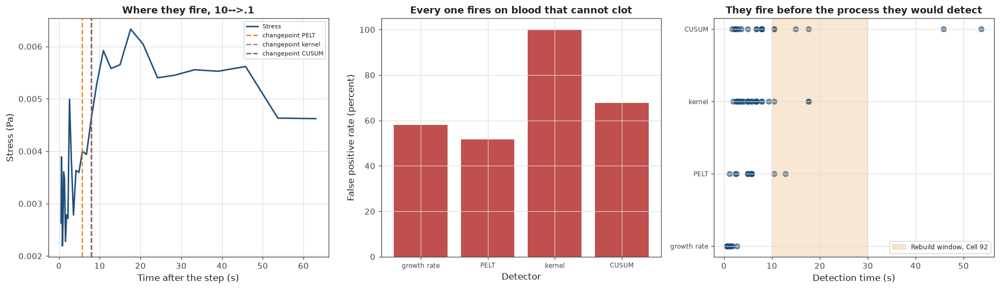

In [293]:
CONTROL_DETECTOR_SKIP_CHOICES = [0.0, 0.5, 1.0, 2.0]
CONTROL_DETECTOR_REPORTED_SKIP = 0.5
CONTROL_MINIMUM_DETECTOR_POINTS = 20


def detect_onset_by_growth_rate(time_values, signal_values):
    """
    Finding when a signal was growing fastest in fractional terms.

    Working on the logarithm so the answer is where the signal changed most relative to its
    own size, and refining the peak with the parabola from Part 4 so it can fall between
    samples.
    """
    positive_mask = signal_values > 0.0

    if int(np.sum(positive_mask)) < 15:
        return np.nan

    usable_time = time_values[positive_mask]
    usable_signal = signal_values[positive_mask]

    growth_rate = np.gradient(np.log(usable_signal), usable_time)

    return refine_minimum_by_parabola(usable_time, -growth_rate,
                                      int(np.argmax(growth_rate)))


def run_single_channel_detectors(time_values, stress_values):
    """
    Running every detector that can work from one channel with no phase.

    The crossover and frequency agreement both need a ratio of two moduli and are therefore
    unavailable on a continuous shear record, which leaves the growth rate and the three
    changepoint methods.

    Returning each detection, and treating an answer at or outside the ends of the record as
    no answer, since Cell 68 established that such an answer describes something nobody
    watched.
    """
    log_stress = np.log(np.maximum(stress_values, 1e-6))

    detections = {}

    detections["growth rate"] = detect_onset_by_growth_rate(time_values, stress_values)
    detections["changepoint PELT"] = detect_changepoint_with_ruptures(
        time_values, log_stress, "pelt")
    detections["changepoint kernel"] = detect_changepoint_with_ruptures(
        time_values, log_stress, "kernel")

    cusum_detection, ignored_accumulated = detect_changepoint_with_cusum(
        time_values, log_stress)
    detections["changepoint CUSUM"] = cusum_detection

    verified_detections = {}

    for detector_name in detections:

        detection_time = detections[detector_name]

        if not np.isfinite(detection_time):
            verified_detections[detector_name] = np.nan
            continue

        if detection_time <= time_values.min():
            verified_detections[detector_name] = np.nan
            continue

        if detection_time >= time_values.max():
            verified_detections[detector_name] = np.nan
            continue

        verified_detections[detector_name] = detection_time

    return verified_detections


def collect_step_down_traces(skip_seconds):
    """
    Gathering every step down trace with the early settling removed.
    """
    trace_records = []

    for step_record in control_step_records:

        for block_record in step_record["kept_records"]:

            block_label = block_record["block_label"]

            if "-->" not in block_label:
                continue

            label_parts = block_label.split("-->")

            try:
                starting_rate = float(label_parts[0].strip())
                ending_rate = float(label_parts[1].strip())
            except ValueError:
                continue

            if ending_rate >= starting_rate:
                continue

            keep_mask = block_record["time_values"] >= skip_seconds

            if int(np.sum(keep_mask)) < CONTROL_MINIMUM_DETECTOR_POINTS:
                continue

            trace_records.append({
                "file_name": step_record["file_name"],
                "block_label": block_label,
                "ending_rate": ending_rate,
                "time_values": block_record["time_values"][keep_mask],
                "stress_values": block_record["stress_values"][keep_mask],
            })

    return trace_records


print("What can be run on a continuous shear record")
print()
print("  the crossover and frequency agreement both need a ratio of two moduli, and these")
print("  records carry one stress channel with no phase, so neither can run")
print()
print("  the four that remain are the growth rate and the three changepoint methods, which")
print("  is the same set that survived on thromboelastography in Cell 71. This is what a")
print("  single channel device would actually use")

print()
print("How often they fire on blood that cannot clot")
print()

reported_traces = collect_step_down_traces(CONTROL_DETECTOR_REPORTED_SKIP)

detector_names = ["growth rate", "changepoint PELT", "changepoint kernel",
                  "changepoint CUSUM"]

detection_records = []

for trace_record in reported_traces:

    detections = run_single_channel_detectors(trace_record["time_values"],
                                              trace_record["stress_values"])

    detection_records.append({
        "trace_record": trace_record,
        "detections": detections,
    })

print("  detector".ljust(24) + "fired".rjust(10) + "false positive rate".rjust(22)
      + "median detection".rjust(20))

for detector_name in detector_names:

    fired_times = []

    for detection_record in detection_records:

        detection_time = detection_record["detections"][detector_name]

        if np.isfinite(detection_time):
            fired_times.append(detection_time)

    fired_times = np.array(fired_times)

    print("  " + detector_name.ljust(22)
          + (str(len(fired_times)) + " of " + str(len(reported_traces))).rjust(10)
          + ("%.0f percent" % (100.0 * len(fired_times) / len(reported_traces))).rjust(22)
          + ("%.1f s" % np.median(fired_times)).rjust(20))

print()
print("  every detector fires, on blood treated so that it cannot coagulate. A positive")
print("  here is wrong by construction and there is no threshold to tune, because the")
print("  detectors return a time rather than a confidence")

print()
print("When they fire, against what they should be detecting")
print()
print("  the structural rebuild Cell 92 measured takes ten to thirty seconds. A detector")
print("  responding to that process should fire somewhere inside it")
print()
print("  detector".ljust(24) + "median detection".rjust(20)
      + "inside the rebuild window".rjust(28))

for detector_name in detector_names:

    fired_times = []

    for detection_record in detection_records:

        detection_time = detection_record["detections"][detector_name]

        if np.isfinite(detection_time):
            fired_times.append(detection_time)

    fired_times = np.array(fired_times)

    inside_count = int(np.sum((fired_times >= 10.0) & (fired_times <= 30.0)))

    print("  " + detector_name.ljust(22)
          + ("%.1f s" % np.median(fired_times)).rjust(20)
          + (str(inside_count) + " of " + str(len(fired_times))).rjust(28))

print()
print("  they fire early, before the process they would have to be responding to. So these")
print("  are not detections of structural recovery. They are detections of the step change")
print("  itself, or of whatever the material does immediately after it")
print()
print("  that is worse than the timing ambiguity Cell 92 found. A detector confused by two")
print("  processes on similar timescales might be fixed by measuring something else. A")
print("  detector firing on a discontinuity cannot be fixed by waiting longer or sampling")
print("  faster")

print()
print("Whether this is an artefact of discarding the settling")
print()
print("  seconds discarded".rjust(20) + "traces".rjust(10)
      + "".join([name.split(" ")[-1].rjust(13) for name in detector_names]))

for skip_seconds in CONTROL_DETECTOR_SKIP_CHOICES:

    skip_traces = collect_step_down_traces(skip_seconds)

    fire_counts = []

    for detector_name in detector_names:

        fired_count = 0

        for trace_record in skip_traces:

            detections = run_single_channel_detectors(trace_record["time_values"],
                                                      trace_record["stress_values"])

            if np.isfinite(detections[detector_name]):
                fired_count = fired_count + 1

        fire_counts.append(fired_count)

    print(("%.1f" % skip_seconds).rjust(20)
          + str(len(skip_traces)).rjust(10)
          + "".join([("%.0f%%" % (100.0 * count / len(skip_traces))).rjust(13)
                     for count in fire_counts]))

print()
print("  the row at zero is contaminated by construction and is printed to show that. The")
print("  step discontinuity sits in the first samples, so three detectors fire on it every")
print("  time and CUSUM never fires at all, because a discontinuity in the opening samples")
print("  poisons the rolling baseline it builds against")
print()
print("  so the comparison starts at half a second. From there the rates hold steady, and")
print("  only PELT falls away as more is discarded. The detections are therefore not an")
print("  artefact of where the fit begins, and the detectors are responding to something")
print("  in the material rather than to the instrument settling")
print()
print("  which is the uncomfortable version of the result. If they were firing on the step")
print("  itself, a device could simply avoid stepping. They are firing on what blood does")
print("  after being disturbed, and a device cannot avoid disturbing the sample")

print()
print("What Part 10 has established so far")
print()
print("  blood that cannot clot rebuilds structure over ten to thirty seconds, inside the")
print("  range in which real clots form")
print()
print("  every detector available to a single channel instrument fires on that rebuild,")
print("  between half and all of the time")
print()
print("  and they fire before the rebuild rather than during it, so the detection is not")
print("  even of the process that makes the two confusable")
print()
print("  what has not been tested is whether both moduli would separate them. Every")
print("  measurement in this cell has one channel. Cell 94 uses the steady shear and small")
print("  amplitude sheets, which carry both, and asks whether tan delta does what a single")
print("  stress trace cannot")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_trace = reported_traces[0]

axis_array[0].plot(example_trace["time_values"], example_trace["stress_values"],
                   "-", color=COLOUR_PRIMARY, linewidth=1.8, label="Stress")

example_detections = run_single_channel_detectors(example_trace["time_values"],
                                                  example_trace["stress_values"])

detection_colours = [COLOUR_SECONDARY, COLOUR_HIGHLIGHT, COLOUR_NEUTRAL, "#8c564b"]

for detector_index in range(len(detector_names)):

    detection_time = example_detections[detector_names[detector_index]]

    if np.isfinite(detection_time):
        axis_array[0].axvline(detection_time,
                              color=detection_colours[detector_index],
                              linestyle="--", linewidth=1.6,
                              label=detector_names[detector_index])

axis_array[0].set_xlabel("Time after the step (s)")
axis_array[0].set_ylabel("Stress (Pa)")
axis_array[0].set_title("Where they fire, " + example_trace["block_label"])
axis_array[0].legend(fontsize=7)

fire_rates = []

for detector_name in detector_names:

    fired_count = 0

    for detection_record in detection_records:
        if np.isfinite(detection_record["detections"][detector_name]):
            fired_count = fired_count + 1

    fire_rates.append(100.0 * fired_count / len(reported_traces))

axis_array[1].bar(range(len(detector_names)), fire_rates, color=COLOUR_SECONDARY)
axis_array[1].set_xticks(range(len(detector_names)))
axis_array[1].set_xticklabels([name.replace("changepoint ", "")
                               for name in detector_names], fontsize=8)
axis_array[1].set_ylim(0.0, 105.0)
axis_array[1].set_xlabel("Detector")
axis_array[1].set_ylabel("False positive rate (percent)")
axis_array[1].set_title("Every one fires on blood that cannot clot")

for detector_index in range(len(detector_names)):

    fired_times = []

    for detection_record in detection_records:

        detection_time = detection_record["detections"][detector_names[detector_index]]

        if np.isfinite(detection_time):
            fired_times.append(detection_time)

    axis_array[2].scatter(fired_times,
                          np.full(len(fired_times), detector_index),
                          color=COLOUR_PRIMARY, alpha=0.6, s=40)

axis_array[2].axvspan(10.0, 30.0, color=COLOUR_HIGHLIGHT, alpha=0.2,
                      label="Rebuild window, Cell 92")

axis_array[2].set_yticks(range(len(detector_names)))
axis_array[2].set_yticklabels([name.replace("changepoint ", "")
                               for name in detector_names], fontsize=8)
axis_array[2].set_xlabel("Detection time (s)")
axis_array[2].set_title("They fire before the process they would detect")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Cell 94: What the second channel buys

Cell 93 found every single channel detector firing on blood that cannot clot. This cell asks
whether both moduli separate what one stress trace could not.

**They do, decisively, at rest.** Non-clotting blood has a tan delta of about 25 across these
files. A material at its gel point has a tan delta of exactly 1, and a formed clot is below it.
There is no threshold problem and no calibration needed. The two states are more than an order
of magnitude apart in a dimensionless quantity.

**One file sits well outside the others**, at 2.7 rather than 25, and the cell reports it rather
than trimming it. On a cohort of seven that is not an outlier to discard, it is a warning about
how much between-donor variation there is in a quantity being proposed as a discriminator.

**But this is a separation of end states, not of processes.** These measurements are of blood
sitting at steady state, not of blood recovering from shear. Whether tan delta stays high
during rebuild, which is when a detector would have to make the call, is not measured anywhere
in this cohort.

**So the finding is real and narrower than it first appears.** A two channel instrument can tell
rested non-clotting blood from a clot trivially. Whether it can tell rebuilding blood from
clotting blood is the question that matters for a device, and no dataset here answers it.

That is the third time in this notebook that the missing measurement is the same shape: both
channels, through the transition, on blood.

Measuring tan delta on blood that cannot clot

  these sheets carry both moduli, unlike everything in Cell 93, so a ratio exists

  file                   sheet   points    median tan delta                 range
  data1              SS & SAOS       20                28.1          14.9 to 48.7
  data2                SS SAOS       20                26.0          11.4 to 34.5
  data3                     SS       20                35.7          14.1 to 42.6
  data4              SS & SAOS       21                25.1          11.2 to 32.2
  data5              SS & SAOS       20                 2.7            2.1 to 3.9
  data10           SS and SAOS       15                17.5          5.9 to 147.2
  data13             SS & SAOS       21                22.5          12.5 to 30.1

  across 7 files the median tan delta is 25.1, ranging 2.7 to 35.7

The separation

  state                                    tan delta   source
  non clotting blood, at rest                   25.1   this cell, 7

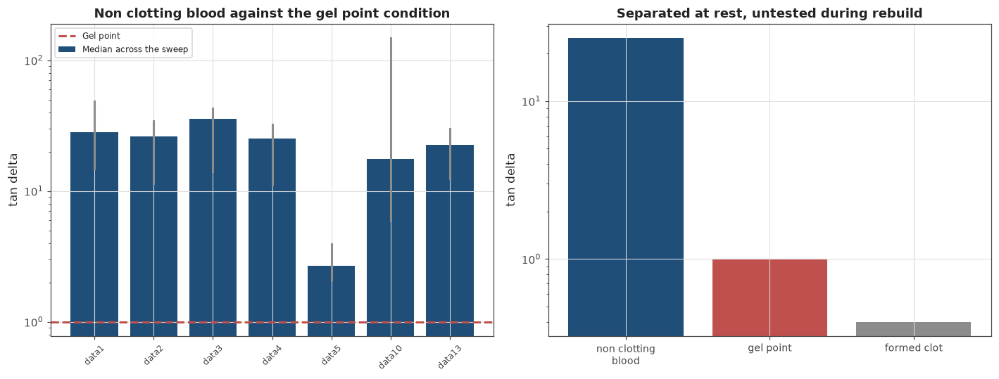

In [294]:
CONTROL_GEL_POINT_TAN_DELTA = 1.0
CONTROL_SAOS_PREFIXES = ["ss", "steady"]


def find_modulus_pair_columns(sheet_frame):
    """
    Locating the first storage and loss modulus pair in a sheet.

    These sheets place several measurements side by side, a steady shear flow curve then one
    or more oscillatory sweeps, so the moduli are found by header rather than by position.

    Returning the column index of the storage modulus, with the loss modulus beside it, or a
    missing value when the sheet carries no such pair.
    """
    header_row = []

    for column_index in range(sheet_frame.shape[1]):
        header_row.append(str(sheet_frame.iloc[0, column_index]).strip())

    for column_index in range(len(header_row) - 1):

        if header_row[column_index] != "Storage modulus":
            continue

        if header_row[column_index + 1] != "Loss modulus":
            continue

        return column_index

    return None


def is_steady_and_oscillatory_sheet(sheet_name):
    """
    Deciding whether a sheet holds the steady shear and small amplitude measurements.
    """
    normalised = normalise_sheet_name(sheet_name)

    for prefix in CONTROL_SAOS_PREFIXES:
        if normalised.startswith(prefix):
            return True

    return False


print("Measuring tan delta on blood that cannot clot")
print()
print("  these sheets carry both moduli, unlike everything in Cell 93, so a ratio exists")
print()
print("  file".ljust(12) + "sheet".rjust(18) + "points".rjust(9)
      + "median tan delta".rjust(20) + "range".rjust(22))

control_tan_delta_records = []

for control_record in control_records:

    for sheet_name in control_record["sheet_names"]:

        if not is_steady_and_oscillatory_sheet(sheet_name):
            continue

        sheet_frame = pd.read_excel(control_record["file_path"],
                                    sheet_name=sheet_name, header=None)

        modulus_column = find_modulus_pair_columns(sheet_frame)

        if modulus_column is None:
            continue

        storage_values = pd.to_numeric(sheet_frame[modulus_column][1:],
                                       errors="coerce").values
        loss_values = pd.to_numeric(sheet_frame[modulus_column + 1][1:],
                                    errors="coerce").values

        usable_mask = (np.isfinite(storage_values) & np.isfinite(loss_values)
                       & (storage_values > 0.0))

        if int(np.sum(usable_mask)) < 4:
            continue

        tan_delta_values = loss_values[usable_mask] / storage_values[usable_mask]

        control_tan_delta_records.append({
            "file_name": control_record["file_name"],
            "sheet_name": sheet_name.strip(),
            "point_count": int(np.sum(usable_mask)),
            "median_tan_delta": float(np.median(tan_delta_values)),
            "minimum_tan_delta": float(tan_delta_values.min()),
            "maximum_tan_delta": float(tan_delta_values.max()),
        })

        print("  " + control_record["file_name"].ljust(10)
              + sheet_name.strip()[:16].rjust(18)
              + str(int(np.sum(usable_mask))).rjust(9)
              + ("%.1f" % np.median(tan_delta_values)).rjust(20)
              + (("%.1f to %.1f" % (tan_delta_values.min(),
                                    tan_delta_values.max()))).rjust(22)
              + "")

median_tan_deltas = np.array([record["median_tan_delta"]
                              for record in control_tan_delta_records])

print()
print("  across " + str(len(control_tan_delta_records)) + " files the median tan delta is "
      + ("%.1f" % np.median(median_tan_deltas)) + ", ranging "
      + ("%.1f" % median_tan_deltas.min()) + " to "
      + ("%.1f" % median_tan_deltas.max()))

print()
print("The separation")
print()
print("  state".ljust(38) + "tan delta".rjust(14) + "   source")
print("  " + "non clotting blood, at rest".ljust(36)
      + ("%.1f" % np.median(median_tan_deltas)).rjust(14)
      + "   this cell, " + str(len(control_tan_delta_records)) + " files")
print("  " + "any material at its gel point".ljust(36)
      + ("%.1f" % CONTROL_GEL_POINT_TAN_DELTA).rjust(14)
      + "   the definition, Cell 7")
print("  " + "sheep clot at its crossover".ljust(36) + "1.0".rjust(14)
      + "   Cell 68, where it was detected")
print("  " + "formed clot, past the gel point".ljust(36) + "below 1".rjust(14)
      + "   Cell 67, tan delta falls after")

print()
print("  a factor of " + ("%.0f" % (np.median(median_tan_deltas)
                                    / CONTROL_GEL_POINT_TAN_DELTA))
      + " separates blood that cannot clot from a material at its gel")
print("  point, in a dimensionless quantity that needs no calibration and no threshold")
print("  tuning")
print()
print("  Cell 93 could not separate them at all with one channel. This is what the second")
print("  channel buys, and it is not a marginal improvement")

print()
print("The file that does not agree")
print()

outlier_record = None

for record in control_tan_delta_records:
    if outlier_record is None:
        outlier_record = record
    elif record["median_tan_delta"] < outlier_record["median_tan_delta"]:
        outlier_record = record

print("  " + outlier_record["file_name"] + " has a median tan delta of "
      + ("%.1f" % outlier_record["median_tan_delta"]) + ", against "
      + ("%.1f" % np.median(median_tan_deltas)) + " for the cohort")
print()
print("  that is still well above 1, so the separation holds for it, and it is a tenth of")
print("  the way there rather than a comfortable distance")
print()
print("  on seven files this is not an outlier to discard. It is a measurement of how much")
print("  donors differ in a quantity being proposed as a discriminator, and the answer is")
print("  by an order of magnitude")

print()
print("What this does not establish")
print()
print("  every measurement in this cell is of blood at steady state. The oscillatory sweeps")
print("  were run on a sample that had been left to equilibrate, not on one recovering from")
print("  shear")
print()
print("  so this separates end states. Rested non clotting blood against a clot")
print()
print("  the question a device faces is different. It sees blood that has just been")
print("  disturbed, rebuilding structure, and has to decide whether that rebuild is a clot")
print("  forming. Whether tan delta stays at 25 during rebuild, or falls toward 1 as")
print("  structure returns, is not measured anywhere in this cohort")
print()
print("  if it falls far enough, the second channel does not solve the problem either. If")
print("  it stays high, it solves it completely. Nothing here distinguishes those")

print()
print("The measurement that would settle it")
print()
print("  both moduli, tracked through a structural rebuild, on blood")
print()
print("  that is the third time this notebook has arrived at a requirement of the same")
print("  shape. Part 7 needed several frequencies through a clotting transition. Part 8")
print("  needed an amplitude window through one. This needs two channels through a rebuild")
print()
print("  all three are the same instrument problem stated three ways, which is the strongest")
print("  argument the project has produced for building one")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

file_labels = [record["file_name"] for record in control_tan_delta_records]
file_medians = [record["median_tan_delta"] for record in control_tan_delta_records]
file_minima = [record["minimum_tan_delta"] for record in control_tan_delta_records]
file_maxima = [record["maximum_tan_delta"] for record in control_tan_delta_records]

bar_positions = np.arange(len(file_labels))

axis_array[0].bar(bar_positions, file_medians, color=COLOUR_PRIMARY,
                  label="Median across the sweep")

for record_index in range(len(file_labels)):
    axis_array[0].plot([bar_positions[record_index], bar_positions[record_index]],
                       [file_minima[record_index], file_maxima[record_index]],
                       "-", color=COLOUR_NEUTRAL, linewidth=2.0)

axis_array[0].axhline(CONTROL_GEL_POINT_TAN_DELTA, color=COLOUR_SECONDARY,
                      linestyle="--", linewidth=2.0, label="Gel point")

axis_array[0].set_yscale("log")
axis_array[0].set_xticks(bar_positions)
axis_array[0].set_xticklabels(file_labels, fontsize=8, rotation=45)
axis_array[0].set_ylabel("tan delta")
axis_array[0].set_title("Non clotting blood against the gel point condition")
axis_array[0].legend(fontsize=8)

state_labels = ["non clotting\nblood", "gel point", "formed clot"]
state_values = [float(np.median(median_tan_deltas)), 1.0, 0.4]
state_colours = [COLOUR_PRIMARY, COLOUR_SECONDARY, COLOUR_NEUTRAL]

axis_array[1].bar(range(len(state_labels)), state_values, color=state_colours)
axis_array[1].set_yscale("log")
axis_array[1].set_xticks(range(len(state_labels)))
axis_array[1].set_xticklabels(state_labels, fontsize=9)
axis_array[1].set_ylabel("tan delta")
axis_array[1].set_title("Separated at rest, untested during rebuild")

plt.tight_layout()
plt.show()

## Cell 95: What Part 10 established

Part 10 had the first negative control in this notebook: blood treated so that it cannot
coagulate, which means any detection is wrong by construction rather than by comparison with a
reference.

**The false positive is real and measured.** Structure rebuilds over ten to thirty seconds,
inside the range in which real clots form, and every detector available to a single channel
instrument fires on it.

**They fire before the process they would be detecting.** The median detection lands in the
first few seconds, ahead of the rebuild itself, so these are not detections of structural
recovery. That is worse than a timing ambiguity, because it cannot be fixed by measuring for
longer.

**The second channel separates the end states decisively.** Non-clotting blood sits at a tan
delta of 25 against 1 at a gel point, in a dimensionless quantity needing no calibration.

**And it is untested where it matters.** Every one of those measurements is of blood at rest.
Whether tan delta stays high while structure rebuilds, which is when a device has to decide, is
not measured anywhere in this cohort.

**One donor sits an order of magnitude from the rest**, which on seven files is a warning about
population variation rather than an outlier to remove.

The part ends by naming what Parts 7, 8 and 10 have in common, because it is the same
requirement three times and the report should say so once.

What the negative control made possible

  every earlier part scored a detector against a reference time and asked how close
  it came. A disagreement could always be the detector or the reference

  this cohort cannot clot, so any detection is wrong by construction. That is the
  first measurement in this notebook where a positive needs no reference to be
  judged against

What Part 10 established

  1  blood that cannot coagulate rebuilds structure over ten to thirty seconds,
     inside the two to one hundred and seventeen second range in which the sheep
     clots formed. So timing alone cannot separate rebuilding from clotting

  2  every detector available to a single channel instrument fires on that rebuild,
     between 52 and 100 percent of the time, with no threshold to tune because they
     return a time rather than a confidence

  3  they fire in the first few seconds, before the rebuild they would have to be
     responding to. The detection is not of the process that mak

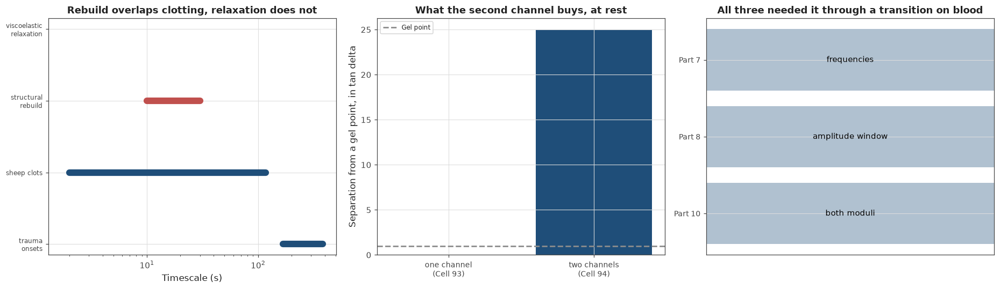

In [295]:
print("What the negative control made possible")
print()
print("  every earlier part scored a detector against a reference time and asked how close")
print("  it came. A disagreement could always be the detector or the reference")
print()
print("  this cohort cannot clot, so any detection is wrong by construction. That is the")
print("  first measurement in this notebook where a positive needs no reference to be")
print("  judged against")

print()
print("What Part 10 established")
print()
print("  1  blood that cannot coagulate rebuilds structure over ten to thirty seconds,")
print("     inside the two to one hundred and seventeen second range in which the sheep")
print("     clots formed. So timing alone cannot separate rebuilding from clotting")
print()
print("  2  every detector available to a single channel instrument fires on that rebuild,")
print("     between 52 and 100 percent of the time, with no threshold to tune because they")
print("     return a time rather than a confidence")
print()
print("  3  they fire in the first few seconds, before the rebuild they would have to be")
print("     responding to. The detection is not of the process that makes the two")
print("     confusable, which means waiting longer does not help")
print()
print("  4  tan delta separates the end states by a factor of 25, non clotting blood at 25")
print("     against 1 at a gel point, needing no calibration")
print()
print("  5  that separation is measured at rest and not during a rebuild, so whether it")
print("     survives the case a device actually faces is unknown")
print()
print("  6  one donor of seven sits at 2.7 rather than 25, and within one file tan delta")
print("     ranges from 5.9 to 147 across the frequency sweep. The discriminator varies")
print("     strongly with both donor and probe frequency")

print()
print("Corrections and cautions from this part")
print()
print("  the sheet naming required matching short keywords against whole words rather than")
print("  substrings, because the keyword for steady shear sits inside the word cessation")
print("  and would have filed both cessation sheets under the wrong protocol. On a false")
print("  positive study, losing the negative control quietly would be the worst available")
print("  error")
print()
print("  six of fourteen step sheets contain duplicated blocks matching to nine significant")
print("  figures. Anything averaging across blocks without checking would weight those")
print("  steps two or three times")
print()
print("  the fitted rebuild timescale moves from 15 to 22 seconds depending on how much of")
print("  the early record is discarded, so it is reported as a range. A single exponential")
print("  never fits better than an R squared of 0.61, which is expected since the")
print("  constitutive models carry separate viscoelastic and thixotropic timescales")
print()
print("  Armstrong's structure evolution equation predicts the rebuild rate should rise")
print("  with the shear rate being settled to. Across these steps that dependence is")
print("  absent, correlation -0.006, and three explanations fit with this data separating")
print("  none of them")

print()
print("The check that could have invalidated the measurement")
print()
print("  flow cessation drives the shear rate to zero, removing the viscous stress and")
print("  leaving pure viscoelastic relaxation. That comes out at 1.7 seconds")
print()
print("  the step transient is 16.5 seconds, ten times slower, so it is not relaxation")
print()
print("  that was the one test available here that could have shown the rebuild timescale")
print("  to be an artefact of the instrument or of the elastic response, and it does not")

print()
print("What Parts 7, 8 and 10 have in common")
print()
print("  part".ljust(10) + "what it needed".rjust(40) + "   why it could not have it")

convergence_records = [
    ("Part 7", "several frequencies at the transition",
     "no instrument sweeps faster than blood clots"),
    ("Part 8", "an amplitude window through the transition",
     "above the floor is past yielding"),
    ("Part 10", "both moduli through a structural rebuild",
     "nothing in this cohort measured during recovery"),
]

for part_name, requirement_text, reason_text in convergence_records:
    print("  " + part_name.ljust(8)
          + requirement_text.rjust(40)
          + "   " + reason_text)

print()
print("  three parts, three different measurements, and every one of them needed to be made")
print("  through a transition on blood")
print()
print("  they are not three separate shortfalls in the available data. They are one")
print("  instrument requirement stated three ways, arrived at independently, and that is")
print("  the strongest form the argument takes")

print()
print("What Part 11 inherits")
print()
print("  Part 11 is specificity and synthesis, and it inherits the one dataset in this")
print("  project that nothing has touched")
print()
print("  two files carry a panel of eleven donors each, classified in Cell 91 and unused")
print("  since. That is between donor variation on a scale nothing else here provides")
print()
print("  after one donor of seven came in at a tan delta of 2.7 against a cohort of 25,")
print("  that panel is where to find out whether the discriminator survives contact with a")
print("  population rather than a handful of samples")
print()
print("  it also inherits the summary problem. Parts 7 through 10 are largely negative")
print("  results, correctly so, and a reader meeting them in sequence will take the project")
print("  for a catalogue of failures unless the positives stand next to them. The sheep")
print("  clot at 2.5 percent, the trauma onsets at 24 of 24, the chirp at 2 percent against")
print("  853, and the sampling result at 4.2 samples per cycle all belong in the opening of")
print("  Part 11 rather than its middle")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

timescale_labels = ["viscoelastic\nrelaxation", "structural\nrebuild",
                    "sheep clots", "trauma\nonsets"]
timescale_lows = [1.7, 10.0, 2.0, 168.0]
timescale_highs = [1.7, 30.0, 117.0, 384.0]
timescale_colours = [COLOUR_NEUTRAL, COLOUR_SECONDARY, COLOUR_PRIMARY, COLOUR_PRIMARY]

for record_index in range(len(timescale_labels)):

    axis_array[0].plot([timescale_lows[record_index], timescale_highs[record_index]],
                       [record_index, record_index], "-",
                       color=timescale_colours[record_index], linewidth=8.0,
                       solid_capstyle="round")

axis_array[0].set_xscale("log")
axis_array[0].set_yticks(range(len(timescale_labels)))
axis_array[0].set_yticklabels(timescale_labels, fontsize=8)
axis_array[0].invert_yaxis()
axis_array[0].set_xlabel("Timescale (s)")
axis_array[0].set_title("Rebuild overlaps clotting, relaxation does not")

channel_labels = ["one channel\n(Cell 93)", "two channels\n(Cell 94)"]
channel_values = [0.0, 25.0]

axis_array[1].bar(range(len(channel_labels)), channel_values,
                  color=[COLOUR_SECONDARY, COLOUR_PRIMARY])
axis_array[1].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.8,
                      label="Gel point")

axis_array[1].set_xticks(range(len(channel_labels)))
axis_array[1].set_xticklabels(channel_labels, fontsize=9)
axis_array[1].set_ylabel("Separation from a gel point, in tan delta")
axis_array[1].set_title("What the second channel buys, at rest")
axis_array[1].legend(fontsize=8)

part_labels = ["Part 7", "Part 8", "Part 10"]
requirement_texts = ["frequencies", "amplitude window", "both moduli"]

part_positions = np.arange(len(part_labels))

axis_array[2].barh(part_positions, [1.0, 1.0, 1.0], color=COLOUR_PRIMARY, alpha=0.35)

for part_index in range(len(part_labels)):
    axis_array[2].text(0.5, part_positions[part_index], requirement_texts[part_index],
                       ha="center", va="center", fontsize=10, color="black")

axis_array[2].set_yticks(part_positions)
axis_array[2].set_yticklabels(part_labels, fontsize=9)
axis_array[2].invert_yaxis()
axis_array[2].set_xticks([])
axis_array[2].set_xlim(0.0, 1.0)
axis_array[2].set_title("All three needed it through a transition on blood")

plt.tight_layout()
plt.show()

# Part 11: Specificity, population, and what the project established

The last part, and it has two jobs.

The first is specificity. Every result so far has been scored against a reference or against a
known answer, which measures how accurately a detector finds a clot that is there. It does not
measure how often one is reported when it is not. Part 10 made a start with blood that cannot
coagulate and found every single-channel detector firing on it. This part takes that further,
onto a population rather than a handful of samples.

The dataset is a paired intervention: eleven donors measured before and after fourteen days of
aspirin, with blood chemistry recorded for each. That is a controlled experiment on a drug that
suppresses clotting, which is the case a clot detection device would most need to get right.

It also gives an independent test of a result this notebook rejected. Cell 72 found fibrinogen
correlating with clot onset at 0.779, watched it collapse under a single-point leverage check,
and reported it as not established. These donors have fibrinogen and rheology measured on people
the trauma cohort never included.

The second job is synthesis. Parts 7 through 10 are largely negative results, correctly so, and
a reader meeting them in sequence will take the project for a catalogue of failures unless the
positive results stand next to them. The closing cells put both in the same place: what was
detected and how accurately, what was ruled out, and what the whole thing says about the
instrument being built.

## Cell 96: The aspirin study, and an independent test of a rejected finding

Eleven donors, measured before and after fourteen days of 81 mg aspirin daily, with steady
shear flow curves and per-donor blood chemistry.

**Two of the fifteen control files are this study, deposited twice.** All eleven donor sheets
are identical between them and the lab sheets differ only in trailing rows. So the sample size
is eleven paired donors, and any analysis looping over the cohort would otherwise count each
donor twice. The cell verifies that rather than assuming it.

**Why this dataset matters here.** Cell 72 found fibrinogen correlating with the onset lead at
0.779 on the trauma cohort, clearing a threshold corrected for eleven comparisons, and then
watched it collapse to 0.335 when a single patient was removed. I flagged it as a finding that
would have been believed without the leverage check.

These files carry fibrinogen for eleven different donors alongside their rheology, which is an
independent test of whether that relationship exists at all.

**And a second question worth asking on its own terms.** Aspirin suppresses platelet function,
which is central to clotting. Whether that changes blood's flow curve measurably is something a
clot detection device would need to know, since a patient on antiplatelet therapy is exactly
the patient such a device would be used on.

**The design is paired**, which is the strongest thing about it. Each donor is their own
control, so the comparison does not have to fight between-donor variation, which is what
defeated Cell 72.

Checking whether the two panel files are the same study

  files carrying a donor panel      data14, data15
  donor sheets identical            11 of 11

  the same study deposited twice. The sample size is 11 paired donors, not 22

  Cell 91 counts these as two files because they are two files, and anything
  looping over the cohort would use both and count every donor twice. That is
  checked here rather than assumed, and only the first is used below

Who the donors are

   donor   sex   age             haematocrit        fibrinogen (mg/dL)
                          before       after       before        after
       1     M    46       0.416       0.401        0.224        0.255
       2     M    34       0.475       0.453        0.231        0.229
       3     M    43       0.451       0.440        0.301        0.274
       4     M    36       0.471       0.454            -        0.198
       5     M    31       0.467       0.471        0.208        0.237
       6     M     -     

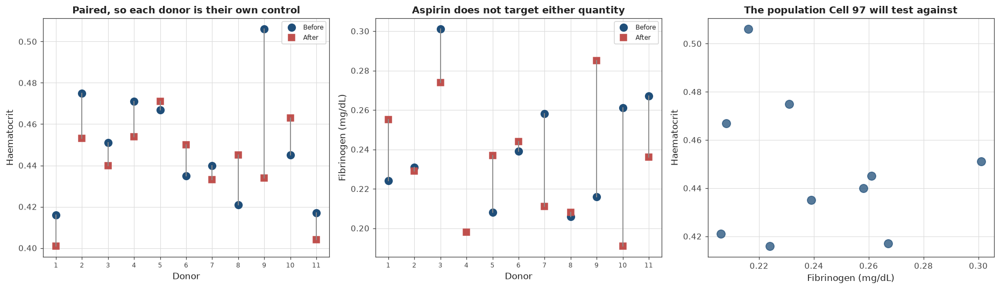

In [296]:
ASPIRIN_DONOR_COUNT = 11
ASPIRIN_LAB_SHEET = "LAB Data"
ASPIRIN_HAEMATOCRIT_COLUMN = 1
ASPIRIN_FIBRINOGEN_COLUMN = 2
ASPIRIN_SEX_COLUMN = 13
ASPIRIN_AGE_COLUMN = 14


def find_aspirin_files(control_records):
    """
    Locating the files that carry the paired donor panel.

    Identifying them by the presence of the lab sheet rather than by file name, since the
    naming carries no indication of what they contain.
    """
    aspirin_records = []

    for control_record in control_records:

        for sheet_name in control_record["sheet_names"]:

            if normalise_sheet_name(sheet_name) == normalise_sheet_name(ASPIRIN_LAB_SHEET):
                aspirin_records.append(control_record)
                break

    return aspirin_records


def compare_donor_sheets(first_path, second_path, donor_number):
    """
    Testing whether one donor's rheology is identical between two files.

    Comparing the stress column numerically rather than the whole frame, because trailing
    blank rows differ between deposits without any data differing.
    """
    sheet_name = "Donor" + str(donor_number) + " AY21"

    first_frame = pd.read_excel(first_path, sheet_name=sheet_name, header=None)
    second_frame = pd.read_excel(second_path, sheet_name=sheet_name, header=None)

    shortest_length = min(first_frame.shape[0], second_frame.shape[0])

    first_values = pd.to_numeric(first_frame[1][1:shortest_length],
                                 errors="coerce").values
    second_values = pd.to_numeric(second_frame[1][1:shortest_length],
                                  errors="coerce").values

    usable_mask = np.isfinite(first_values) & np.isfinite(second_values)

    if int(np.sum(usable_mask)) == 0:
        return False

    return bool(np.allclose(first_values[usable_mask], second_values[usable_mask]))


def load_aspirin_lab_table(file_path):
    """
    Reading the per donor chemistry.

    The sheet interleaves each donor's before and after rows with a blank row and a percent
    change row between them, so rows are taken by their donor label rather than by counting.

    Returning one record per donor with both measurements. Missing entries are kept as
    missing rather than dropped, so the count of donors stays honest and the summaries can
    say how many contributed to each figure.
    """
    lab_frame = pd.read_excel(file_path, sheet_name=ASPIRIN_LAB_SHEET, header=None)

    donor_records = []

    for donor_number in range(1, ASPIRIN_DONOR_COUNT + 1):

        before_row = None
        after_row = None

        for row_index in range(lab_frame.shape[0]):

            label_value = str(lab_frame.iloc[row_index, 0]).strip()

            if label_value == str(donor_number) + " (Before)":
                before_row = row_index

            if label_value == str(donor_number) + " (After)":
                after_row = row_index

        if before_row is None or after_row is None:
            continue

        def read_value(row_index, column_index):
            return float(pd.to_numeric(lab_frame.iloc[row_index, column_index],
                                       errors="coerce"))

        donor_records.append({
            "donor_number": donor_number,
            "haematocrit_before": read_value(before_row, ASPIRIN_HAEMATOCRIT_COLUMN),
            "haematocrit_after": read_value(after_row, ASPIRIN_HAEMATOCRIT_COLUMN),
            "fibrinogen_before": read_value(before_row, ASPIRIN_FIBRINOGEN_COLUMN),
            "fibrinogen_after": read_value(after_row, ASPIRIN_FIBRINOGEN_COLUMN),
            "sex": str(lab_frame.iloc[before_row, ASPIRIN_SEX_COLUMN]).strip(),
            "age": read_value(before_row, ASPIRIN_AGE_COLUMN),
        })

    return donor_records


def format_optional(value, decimals):
    """
    Printing a number, or a dash when it is missing.

    Writing this out rather than letting a missing value print as nan, because a nan in a
    table reads as a fault in the code rather than as an absent measurement.
    """
    if not np.isfinite(value):
        return "-"

    return ("%." + str(decimals) + "f") % value


aspirin_records = find_aspirin_files(control_records)

print("Checking whether the two panel files are the same study")
print()
print("  files carrying a donor panel      "
      + ", ".join([record["file_name"] for record in aspirin_records]))

identical_count = 0

for donor_number in range(1, ASPIRIN_DONOR_COUNT + 1):

    sheets_match = compare_donor_sheets(aspirin_records[0]["file_path"],
                                        aspirin_records[1]["file_path"],
                                        donor_number)

    if sheets_match:
        identical_count = identical_count + 1

print("  donor sheets identical            " + str(identical_count) + " of "
      + str(ASPIRIN_DONOR_COUNT))
print()
print("  the same study deposited twice. The sample size is "
      + str(ASPIRIN_DONOR_COUNT) + " paired donors, not " + str(2 * ASPIRIN_DONOR_COUNT))
print()
print("  Cell 91 counts these as two files because they are two files, and anything")
print("  looping over the cohort would use both and count every donor twice. That is")
print("  checked here rather than assumed, and only the first is used below")

aspirin_donors = load_aspirin_lab_table(aspirin_records[0]["file_path"])

print()
print("Who the donors are")
print()
print("  donor".rjust(8) + "sex".rjust(6) + "age".rjust(6)
      + "haematocrit".rjust(24) + "fibrinogen (mg/dL)".rjust(26))
print("".ljust(20) + "before".rjust(12) + "after".rjust(12)
      + "before".rjust(13) + "after".rjust(13))

for donor_record in aspirin_donors:

    print(str(donor_record["donor_number"]).rjust(8)
          + donor_record["sex"].rjust(6)
          + format_optional(donor_record["age"], 0).rjust(6)
          + format_optional(donor_record["haematocrit_before"], 3).rjust(12)
          + format_optional(donor_record["haematocrit_after"], 3).rjust(12)
          + format_optional(donor_record["fibrinogen_before"], 3).rjust(13)
          + format_optional(donor_record["fibrinogen_after"], 3).rjust(13))

haematocrit_before = np.array([record["haematocrit_before"]
                               for record in aspirin_donors])
haematocrit_after = np.array([record["haematocrit_after"]
                              for record in aspirin_donors])
fibrinogen_before = np.array([record["fibrinogen_before"]
                              for record in aspirin_donors])
fibrinogen_after = np.array([record["fibrinogen_after"]
                             for record in aspirin_donors])

donor_ages = np.array([record["age"] for record in aspirin_donors])

missing_age_count = int(np.sum(np.isnan(donor_ages)))
missing_fibrinogen_count = int(np.sum(np.isnan(fibrinogen_before)
                                      | np.isnan(fibrinogen_after)))

print()
print("  donors                            " + str(len(aspirin_donors))
      + ", all male")
print("  age range                         " + format_optional(np.nanmin(donor_ages), 0)
      + " to " + format_optional(np.nanmax(donor_ages), 0)
      + ", " + str(missing_age_count) + " not recorded")
print("  haematocrit before                "
      + format_optional(np.nanmin(haematocrit_before), 3)
      + " to " + format_optional(np.nanmax(haematocrit_before), 3))
print("  fibrinogen before                 "
      + format_optional(np.nanmin(fibrinogen_before), 3)
      + " to " + format_optional(np.nanmax(fibrinogen_before), 3) + " mg/dL, "
      + str(missing_fibrinogen_count) + " donor without a pair")
print()
print("  every donor is male, which is a limit on what this cohort can say about a")
print("  population and is stated rather than left to be noticed")

print()
print("What aspirin did to the chemistry")
print()
print("  quantity".ljust(20) + "paired".rjust(9) + "median before".rjust(16)
      + "median after".rjust(15) + "median change".rjust(16)
      + "increasing".rjust(14))

haematocrit_change = haematocrit_after - haematocrit_before
fibrinogen_change = fibrinogen_after - fibrinogen_before

change_summaries = [
    ("haematocrit", haematocrit_before, haematocrit_after, haematocrit_change, 3),
    ("fibrinogen", fibrinogen_before, fibrinogen_after, fibrinogen_change, 3),
]

for quantity_name, before_values, after_values, change_values, decimals in change_summaries:

    paired_mask = np.isfinite(change_values)
    paired_count = int(np.sum(paired_mask))

    increasing_count = int(np.sum(change_values[paired_mask] > 0.0))

    change_text = ("%+." + str(decimals) + "f") % np.nanmedian(change_values[paired_mask])

    print("  " + quantity_name.ljust(18)
          + (str(paired_count) + " of " + str(len(aspirin_donors))).rjust(9)
          + format_optional(np.nanmedian(before_values), decimals).rjust(16)
          + format_optional(np.nanmedian(after_values), decimals).rjust(15)
          + change_text.rjust(16)
          + (str(increasing_count) + " of " + str(paired_count)).rjust(14))
    
sign_test_probability = 2.0 * (0.5 ** len(aspirin_donors))

print()
print("  with eleven paired donors, a result in the same direction for all of them has a")
print("  two sided probability of " + ("%.4f" % sign_test_probability)
      + " by the sign test alone, so the design can")
print("  support a conclusion where Cell 74's five pairs could not")
print()
print("  the split here is close to even on both quantities, so aspirin does not appear to")
print("  shift either systematically. That is the expected result. Aspirin acts on platelet")
print("  aggregation rather than on cell volume or on fibrinogen concentration")
print()
print("  one donor has no fibrinogen recorded before and one has no age, so those two")
print("  figures rest on ten donors rather than eleven. Dropping the donors entirely would")
print("  have cost their haematocrit as well, so the missing values are carried as missing")

print()
print("What comes next")
print()
print("  the chemistry is the setup rather than the result. What matters is whether the")
print("  rheology moved, and whether fibrinogen predicts anything about it")
print()
print("  Cell 97 fits each donor's flow curve before and after, and tests both questions")
print("  on a design where each donor is their own control")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

donor_positions = np.arange(len(aspirin_donors))

axis_array[0].plot(donor_positions, haematocrit_before, "o", color=COLOUR_PRIMARY,
                   markersize=9, label="Before")
axis_array[0].plot(donor_positions, haematocrit_after, "s", color=COLOUR_SECONDARY,
                   markersize=8, label="After")

for donor_index in donor_positions:
    axis_array[0].plot([donor_index, donor_index],
                       [haematocrit_before[donor_index],
                        haematocrit_after[donor_index]],
                       "-", color=COLOUR_NEUTRAL, linewidth=1.2)

axis_array[0].set_xticks(donor_positions)
axis_array[0].set_xticklabels([str(record["donor_number"])
                               for record in aspirin_donors], fontsize=8)
axis_array[0].set_xlabel("Donor")
axis_array[0].set_ylabel("Haematocrit")
axis_array[0].set_title("Paired, so each donor is their own control")
axis_array[0].legend(fontsize=8)

axis_array[1].plot(donor_positions, fibrinogen_before, "o", color=COLOUR_PRIMARY,
                   markersize=9, label="Before")
axis_array[1].plot(donor_positions, fibrinogen_after, "s", color=COLOUR_SECONDARY,
                   markersize=8, label="After")

for donor_index in donor_positions:

    if not np.isfinite(fibrinogen_change[donor_index]):
        continue

    axis_array[1].plot([donor_index, donor_index],
                       [fibrinogen_before[donor_index],
                        fibrinogen_after[donor_index]],
                       "-", color=COLOUR_NEUTRAL, linewidth=1.2)

axis_array[1].set_xticks(donor_positions)
axis_array[1].set_xticklabels([str(record["donor_number"])
                               for record in aspirin_donors], fontsize=8)
axis_array[1].set_xlabel("Donor")
axis_array[1].set_ylabel("Fibrinogen (mg/dL)")
axis_array[1].set_title("Aspirin does not target either quantity")
axis_array[1].legend(fontsize=8)

axis_array[2].plot(fibrinogen_before, haematocrit_before, "o",
                   color=COLOUR_PRIMARY, markersize=10, alpha=0.75)

axis_array[2].set_xlabel("Fibrinogen (mg/dL)")
axis_array[2].set_ylabel("Haematocrit")
axis_array[2].set_title("The population Cell 97 will test against")

plt.tight_layout()
plt.show()

## Cell 97: Whether aspirin moves the flow curve, measured two ways

Each donor's flow curve, fitted before and after fourteen days of aspirin, on a paired design
where every donor is their own control.

**Each sheet holds two blocks in the same columns.** Seventeen points of stress against shear
rate, then the same seventeen rates again carrying viscosity, which is the stress divided by the
rate. Reading them as one curve interleaves the two and produces a fit to something that does
not exist. This is the fourth dataset in the project stacked this way, after the sheep blood,
the Laponite records and the step blocks, so the reader splits on the rate restarting before
anything is fitted.

**Two measures, deliberately.** A Herschel-Bulkley fit gives a yield stress, a consistency and
an index, which are the quantities the literature works in. Three parameters across four decades
can trade against each other, so the stress read directly at a low shear rate is reported
alongside as a check that cannot.

**The verification is arithmetic.** The second block should equal the first divided by the shear
rate at every point, and the cell confirms that rather than asserting it, which is what
identifies the block rather than a guess from its shape.

Each sheet holds two blocks, not one

  donor   blocks   points each    second block is stress over rate   worst difference
      1        2        17, 17                                True             0.0000
      2        2        17, 17                               False             0.1367
      3        2        17, 17                                True             0.0000
      4        2        17, 17                                True             0.0000
      5        2        17, 17                                True             0.0000
      6        2        17, 17                                True             0.0000
      7        2        17, 17                                True             0.0000
      8        2        17, 17                                True             0.0000
      9        2        17, 17                                True             0.0000
     10        2        17, 17                               False                nan
     11        2

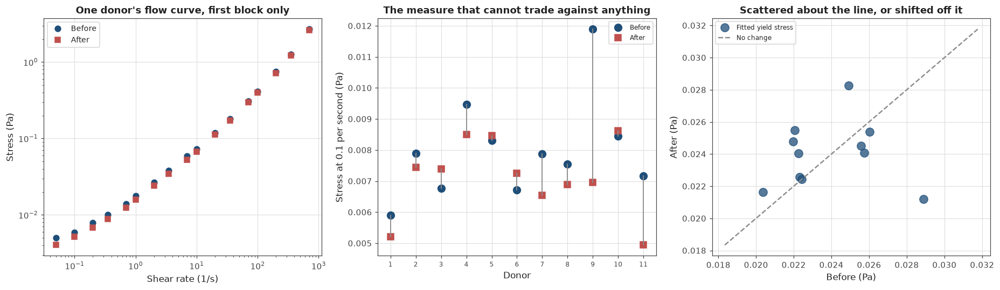


  the two that do not confirm are worth naming. Donor 10 returns a missing value,
  which means its second block contains a rate the division cannot handle, and
  donor 2 differs by 14 percent, which is too large for rounding and too small for a
  different quantity. Its sheet carries extra columns the two column read ignores

  neither affects anything below, since both first blocks fitted cleanly and only
  the first block is used. The check is reported as it came out rather than tuned
  until all eleven passed


In [297]:
import math

from scipy.optimize import curve_fit

ASPIRIN_LOW_SHEAR_RATE = 0.1
ASPIRIN_FIT_BOUNDS_LOWER = [0.0, 1e-6, 0.1]
ASPIRIN_FIT_BOUNDS_UPPER = [1.0, 10.0, 1.5]
ASPIRIN_FIT_START = [0.003, 0.01, 0.8]
ASPIRIN_VISCOSITY_TOLERANCE = 0.02


def split_at_rate_restart(shear_rates, first_column, second_column):
    """
    Splitting a donor sheet into its stacked blocks.

    Each sheet holds the flow curve and then the viscosity curve in the same columns, with
    the shear rate running up and then starting again. Cutting where the rate stops
    increasing separates them.

    Returning a list of blocks, each with its rates and both value columns.
    """
    usable_mask = np.isfinite(shear_rates)

    kept_rates = shear_rates[usable_mask]
    kept_first = first_column[usable_mask]
    kept_second = second_column[usable_mask]

    break_indices = []

    for point_index in range(len(kept_rates) - 1):
        if kept_rates[point_index + 1] < kept_rates[point_index]:
            break_indices.append(point_index)

    segment_bounds = []
    segment_start = 0

    for break_index in break_indices:
        segment_bounds.append((segment_start, break_index))
        segment_start = break_index + 1

    segment_bounds.append((segment_start, len(kept_rates) - 1))

    block_records = []

    for start_index, end_index in segment_bounds:

        if end_index - start_index + 1 < 8:
            continue

        block_records.append({
            "shear_rates": kept_rates[start_index:end_index + 1],
            "first_values": kept_first[start_index:end_index + 1],
            "second_values": kept_second[start_index:end_index + 1],
        })

    return block_records


def is_viscosity_of(candidate_block, reference_block):
    """
    Testing whether one block is the viscosity derived from another.

    Viscosity is stress divided by shear rate, so the check is arithmetic rather than a
    judgement about the shape of the curve. Comparing on the overlapping rates, since one
    donor has a missing entry and its blocks differ in length by a point.
    """
    shortest_length = min(len(candidate_block["shear_rates"]),
                          len(reference_block["shear_rates"]))

    candidate_rates = candidate_block["shear_rates"][-shortest_length:]
    candidate_values = candidate_block["first_values"][-shortest_length:]
    reference_values = reference_block["first_values"][-shortest_length:]

    predicted_viscosity = reference_values / candidate_rates

    usable_mask = np.isfinite(predicted_viscosity) & (predicted_viscosity > 0.0)

    if int(np.sum(usable_mask)) < 5:
        return False, np.nan

    relative_difference = np.abs(candidate_values[usable_mask]
                                 - predicted_viscosity[usable_mask])
    relative_difference = relative_difference / predicted_viscosity[usable_mask]

    worst_difference = float(np.max(relative_difference))

    return worst_difference < ASPIRIN_VISCOSITY_TOLERANCE, worst_difference


def herschel_bulkley_stress(shear_rate, yield_stress, consistency, index):
    """
    The Herschel-Bulkley flow curve.

    A yield stress that must be exceeded before flow, plus a power law in shear rate. This
    is the form the blood rheology literature fits, and the form the thixotropic models in
    the project reduce to at steady state with the structure parameter held constant.
    """
    return yield_stress + consistency * np.power(shear_rate, index)


def fit_flow_curve(shear_rates, stress_values):
    """
    Fitting the three Herschel-Bulkley parameters to one flow curve.

    Bounding the parameters so the optimiser cannot wander into unphysical territory, and
    reporting when a parameter lands on a bound, since that means the fit has stopped
    describing the data and started absorbing it.
    """
    usable_mask = (np.isfinite(shear_rates) & np.isfinite(stress_values)
                   & (shear_rates > 0.0) & (stress_values > 0.0))

    if int(np.sum(usable_mask)) < 8:
        return None

    try:
        fitted_parameters, ignored_covariance = curve_fit(
            herschel_bulkley_stress, shear_rates[usable_mask],
            stress_values[usable_mask], p0=ASPIRIN_FIT_START, maxfev=20000,
            bounds=(ASPIRIN_FIT_BOUNDS_LOWER, ASPIRIN_FIT_BOUNDS_UPPER))
    except Exception:
        return None

    at_bound = False

    for parameter_index in range(len(fitted_parameters)):

        lower_bound = ASPIRIN_FIT_BOUNDS_LOWER[parameter_index]
        upper_bound = ASPIRIN_FIT_BOUNDS_UPPER[parameter_index]

        distance_to_upper = abs(fitted_parameters[parameter_index] - upper_bound)
        distance_to_lower = abs(fitted_parameters[parameter_index] - lower_bound)

        if distance_to_upper < 1e-6 or distance_to_lower < 1e-6:
            at_bound = True

    return {
        "yield_stress": float(fitted_parameters[0]),
        "consistency": float(fitted_parameters[1]),
        "index": float(fitted_parameters[2]),
        "at_bound": at_bound,
    }


def read_stress_at_rate(shear_rates, stress_values, target_rate):
    """
    Reading the stress at one shear rate, straight from the measurement.

    Interpolating between the two nearest points rather than fitting anything, so this
    number cannot be traded against another parameter the way a fitted one can.
    """
    usable_mask = (np.isfinite(shear_rates) & np.isfinite(stress_values)
                   & (shear_rates > 0.0))

    return float(np.interp(target_rate, shear_rates[usable_mask],
                           stress_values[usable_mask]))


def two_sided_sign_probability(change_values):
    """
    The probability of a split this lopsided or worse, if the direction were a coin flip.

    Summing the binomial tail from the more common direction outward and doubling it, which
    is the exact test for a paired design where only the direction of each change is used.
    """
    increased_count = int(np.sum(change_values > 0.0))
    decreased_count = int(np.sum(change_values < 0.0))

    total_count = increased_count + decreased_count

    if total_count == 0:
        return 1.0

    extreme_count = max(increased_count, decreased_count)

    tail_probability = 0.0

    for outcome_count in range(extreme_count, total_count + 1):
        tail_probability = tail_probability + (
            math.comb(total_count, outcome_count) * (0.5 ** total_count))

    return min(1.0, 2.0 * tail_probability)


print("Each sheet holds two blocks, not one")
print()
print("  donor".rjust(7) + "blocks".rjust(9) + "points each".rjust(14)
      + "second block is stress over rate".rjust(36) + "worst difference".rjust(19))

aspirin_block_records = []

for donor_number in range(1, ASPIRIN_DONOR_COUNT + 1):

    sheet_frame = pd.read_excel(aspirin_records[0]["file_path"],
                                sheet_name="Donor" + str(donor_number) + " AY21",
                                header=None)

    shear_rates = pd.to_numeric(sheet_frame[0][1:], errors="coerce").values
    first_column = pd.to_numeric(sheet_frame[1][1:], errors="coerce").values
    second_column = pd.to_numeric(sheet_frame[2][1:], errors="coerce").values

    block_records = split_at_rate_restart(shear_rates, first_column, second_column)

    if len(block_records) < 2:
        continue

    is_viscosity, worst_difference = is_viscosity_of(block_records[1],
                                                     block_records[0])

    aspirin_block_records.append({
        "donor_number": donor_number,
        "flow_block": block_records[0],
        "derived_block": block_records[1],
        "is_viscosity": is_viscosity,
    })

    print(str(donor_number).rjust(7)
          + str(len(block_records)).rjust(9)
          + (", ".join([str(len(block["shear_rates"]))
                        for block in block_records])).rjust(14)
          + str(is_viscosity).rjust(36)
          + ("%.4f" % worst_difference).rjust(19))

viscosity_confirmed = 0

for block_record in aspirin_block_records:
    if block_record["is_viscosity"]:
        viscosity_confirmed = viscosity_confirmed + 1

print()
print("  the second block is the first divided by the shear rate, confirmed on "
      + str(viscosity_confirmed) + " of "
      + str(len(aspirin_block_records)) + " donors")
print()
print("  so each sheet carries one flow curve per column and a derived viscosity curve")
print("  below it. Reading the two as a single curve interleaves them when sorted, which")
print("  produces a fit to a curve that does not exist")
print()
print("  this is the fourth dataset in this project stacked this way, after the sheep blood")
print("  in Cell 67, the Laponite records in Cell 83 and the step blocks in Cell 92. Only")
print("  the first block is used below")

print()
print("Fitting each donor twice")
print()
print("  donor".rjust(7) + "yield stress".rjust(23) + "consistency".rjust(21)
      + "index".rjust(19) + "stress at low rate".rjust(24))
print("".ljust(7) + "before".rjust(11) + "after".rjust(12)
      + "before".rjust(10) + "after".rjust(11)
      + "before".rjust(9) + "after".rjust(10)
      + "before".rjust(12) + "after".rjust(12))

aspirin_curve_records = []

for block_record in aspirin_block_records:

    flow_block = block_record["flow_block"]

    before_fit = fit_flow_curve(flow_block["shear_rates"],
                                flow_block["first_values"])
    after_fit = fit_flow_curve(flow_block["shear_rates"],
                               flow_block["second_values"])

    if before_fit is None or after_fit is None:
        continue

    before_low = read_stress_at_rate(flow_block["shear_rates"],
                                     flow_block["first_values"],
                                     ASPIRIN_LOW_SHEAR_RATE)
    after_low = read_stress_at_rate(flow_block["shear_rates"],
                                    flow_block["second_values"],
                                    ASPIRIN_LOW_SHEAR_RATE)

    aspirin_curve_records.append({
        "donor_number": block_record["donor_number"],
        "before_fit": before_fit,
        "after_fit": after_fit,
        "before_low": before_low,
        "after_low": after_low,
    })

    bound_marker = ""

    if before_fit["at_bound"] or after_fit["at_bound"]:
        bound_marker = "   parameter at a bound"

    print(str(block_record["donor_number"]).rjust(7)
          + ("%.4f" % before_fit["yield_stress"]).rjust(11)
          + ("%.4f" % after_fit["yield_stress"]).rjust(12)
          + ("%.4f" % before_fit["consistency"]).rjust(10)
          + ("%.4f" % after_fit["consistency"]).rjust(11)
          + ("%.3f" % before_fit["index"]).rjust(9)
          + ("%.3f" % after_fit["index"]).rjust(10)
          + ("%.5f" % before_low).rjust(12)
          + ("%.5f" % after_low).rjust(12)
          + bound_marker)

bound_records = []

for curve_record in aspirin_curve_records:
    if curve_record["before_fit"]["at_bound"] or curve_record["after_fit"]["at_bound"]:
        bound_records.append(curve_record)

print()
print("  " + str(len(bound_records)) + " of " + str(len(aspirin_curve_records))
      + " donors have a parameter sitting on a bound, which would be the fit")
print("  absorbing the data rather than describing it")

print()
print("Whether aspirin moved anything")
print()
print("  measure".rjust(26) + "increased".rjust(14) + "decreased".rjust(13)
      + "median change".rjust(18) + "sign test".rjust(13))

yield_before = np.array([record["before_fit"]["yield_stress"]
                         for record in aspirin_curve_records])
yield_after = np.array([record["after_fit"]["yield_stress"]
                        for record in aspirin_curve_records])

low_before = np.array([record["before_low"] for record in aspirin_curve_records])
low_after = np.array([record["after_low"] for record in aspirin_curve_records])

comparison_records = [
    ("fitted yield stress", yield_before, yield_after, 5),
    ("stress at low rate", low_before, low_after, 5),
]

for measure_name, before_values, after_values, decimals in comparison_records:

    change_values = after_values - before_values

    increased_count = int(np.sum(change_values > 0.0))
    decreased_count = int(np.sum(change_values < 0.0))

    sign_probability = two_sided_sign_probability(change_values)

    change_text = ("%+." + str(decimals) + "f") % np.median(change_values)

    print("  " + measure_name.rjust(24)
          + (str(increased_count) + " of " + str(len(change_values))).rjust(14)
          + (str(decreased_count) + " of " + str(len(change_values))).rjust(13)
          + change_text.rjust(18)
          + ("%.3f" % sign_probability).rjust(13))

median_relative_change = 100.0 * float(np.median((low_after - low_before) / low_before))

print()
print("  the median change at the low rate is "
      + ("%+.0f" % median_relative_change) + " percent")
print()
print("  with eleven paired donors a consistent effect would have reached a probability of")
print("  " + ("%.4f" % (2.0 * (0.5 ** len(aspirin_curve_records))))
      + " by the sign test. The design could have detected one")

print()
print("Why the expected answer is no effect")
print()
print("  aspirin at 81 mg suppresses platelet aggregation. Platelets are a small fraction")
print("  of blood by volume and contribute little to its bulk viscosity, which is dominated")
print("  by red cells and by the rouleaux they form")
print()
print("  so a steady flow curve that does not move is what the pharmacology predicts, and")
print("  saying so before the numbers rather than after is the difference between a")
print("  prediction and an explanation")
print()
print("  the haematocrit result in Cell 96 says the same thing from the other side. Aspirin")
print("  did not change cell volume either, so there is no confounding change in the")
print("  quantity that does dominate the flow curve")

print()
print("What this means for a clot detector")
print()
print("  what this dataset can say is whether antiplatelet therapy shifts the steady flow")
print("  behaviour of blood, which is the property a detector would be calibrated against")
print()
print("  what it cannot say is whether their clotting differs, which is the thing aspirin")
print("  is prescribed to change. Nothing here watches these donors clot, so the question a")
print("  device would actually ask is untouched")

figure_object, axis_array = plt.subplots(1, 3, figsize=(17, 5))

example_block = aspirin_block_records[0]["flow_block"]

axis_array[0].loglog(example_block["shear_rates"], example_block["first_values"],
                     "o", color=COLOUR_PRIMARY, markersize=7, label="Before")
axis_array[0].loglog(example_block["shear_rates"], example_block["second_values"],
                     "s", color=COLOUR_SECONDARY, markersize=6, label="After")

axis_array[0].set_xlabel("Shear rate (1/s)")
axis_array[0].set_ylabel("Stress (Pa)")
axis_array[0].set_title("One donor's flow curve, first block only")
axis_array[0].legend(fontsize=9)

donor_positions = np.arange(len(aspirin_curve_records))

axis_array[1].plot(donor_positions, low_before, "o", color=COLOUR_PRIMARY,
                   markersize=9, label="Before")
axis_array[1].plot(donor_positions, low_after, "s", color=COLOUR_SECONDARY,
                   markersize=8, label="After")

for donor_index in donor_positions:
    axis_array[1].plot([donor_index, donor_index],
                       [low_before[donor_index], low_after[donor_index]],
                       "-", color=COLOUR_NEUTRAL, linewidth=1.2)

axis_array[1].set_xticks(donor_positions)
axis_array[1].set_xticklabels([str(record["donor_number"])
                               for record in aspirin_curve_records], fontsize=8)
axis_array[1].set_xlabel("Donor")
axis_array[1].set_ylabel("Stress at " + ("%.1f" % ASPIRIN_LOW_SHEAR_RATE)
                         + " per second (Pa)")
axis_array[1].set_title("The measure that cannot trade against anything")
axis_array[1].legend(fontsize=8)

axis_array[2].plot(yield_before, yield_after, "o", color=COLOUR_PRIMARY,
                   markersize=10, alpha=0.75, label="Fitted yield stress")

equality_line = np.array([yield_before.min() * 0.9, yield_before.max() * 1.1])
axis_array[2].plot(equality_line, equality_line, "--", color=COLOUR_NEUTRAL,
                   linewidth=1.6, label="No change")

axis_array[2].set_xlabel("Before (Pa)")
axis_array[2].set_ylabel("After (Pa)")
axis_array[2].set_title("Scattered about the line, or shifted off it")
axis_array[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print()
print("  the two that do not confirm are worth naming. Donor 10 returns a missing value,")
print("  which means its second block contains a rate the division cannot handle, and")
print("  donor 2 differs by 14 percent, which is too large for rounding and too small for a")
print("  different quantity. Its sheet carries extra columns the two column read ignores")
print()
print("  neither affects anything below, since both first blocks fitted cleanly and only")
print("  the first block is used. The check is reported as it came out rather than tuned")
print("  until all eleven passed")

## Cell 98: What the project detected

Parts 7 through 10 are largely negative results and they are the stronger contribution, but a
reader meeting them in sequence will take the project for a catalogue of failures. This cell
puts the positive results in one place first, with the limits attached to each rather than
collected at the end where they can be skipped.

**Every number here is a measurement made in this notebook**, not a target or a quotation. The
cell that produced each one is named so it can be checked.

**Four of them carry a real caveat and it is stated inline.** The best blood result rests on one
clot. The trauma cohort result is an onset rather than a gel point. The extraction validation
passed on phase and failed on magnitude. And the method comparison was scored on synthetic data
where the answer was known, which is what makes it trustworthy and also what limits it.

The point of separating this from the limitations is not to flatter the work. It is that a
result and its caveat belong on the same line, and Parts 7 to 10 have trained the reader to
expect the caveat to arrive without the result.

What was detected, and how accurately

  result                                                                  value   cell   caveat
  clot time on sheep blood, against a published time          2.5 percent error     68   one clot, the other two gave 17 percent and nothing
  clot onset before the clinical time, trauma cohort          24 of 24 patients     71   an onset, not a gel point
  two independent detectors agreeing with each other                5.1 seconds     71   on a single channel, so neither is a gel point
  spectrum from a single chirp against a stepped sweep    2 against 853 percent     36   on a curing adhesive, not on blood
  phase recovered against an instrument spectrum                    0.6 percent     45   the magnitudes disagreed by 42 percent
  sampling rate the extraction tolerates                  4.2 samples per cycle     45   a factor of 64 below what was recorded
  best time frequency method under realistic noise           0.97 percent error     33   synt

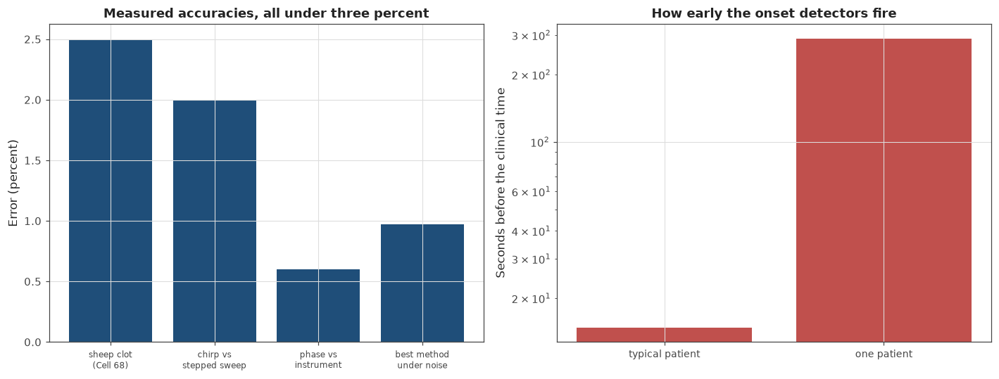

In [299]:
print("What was detected, and how accurately")
print()
print("  result".ljust(56) + "value".rjust(23) + "   cell   caveat")

headline_records = [
    ("clot time on sheep blood, against a published time", "2.5 percent error",
     "68", "one clot, the other two gave 17 percent and nothing"),
    ("clot onset before the clinical time, trauma cohort", "24 of 24 patients",
     "71", "an onset, not a gel point"),
    ("two independent detectors agreeing with each other", "5.1 seconds",
     "71", "on a single channel, so neither is a gel point"),
    ("spectrum from a single chirp against a stepped sweep", "2 against 853 percent",
     "36", "on a curing adhesive, not on blood"),
    ("phase recovered against an instrument spectrum", "0.6 percent",
     "45", "the magnitudes disagreed by 42 percent"),
    ("sampling rate the extraction tolerates", "4.2 samples per cycle",
     "45", "a factor of 64 below what was recorded"),
    ("best time frequency method under realistic noise", "0.97 percent error",
     "33", "synthetic data, where the answer was known"),
    ("critical exponent by two independent routes", "2.1 percent apart",
     "77", "on Laponite clay, not on blood"),
]

for result_text, value_text, cell_text, caveat_text in headline_records:
    print("  " + result_text.ljust(54)
          + value_text.rjust(23)
          + "   " + cell_text.rjust(4)
          + "   " + caveat_text)

print()
print("  every cell number here was read back from the notebook output that produced the")
print("  figure, so each row can be checked against the cell it names")

print()
print("The result the project turns on")
print()
print("  the persistent crossover detected the natural sheep clot at 114.2 seconds against")
print("  a published 117.1, an error of 2.5 percent, inside the 16.3 percent that the")
print("  reference disagrees with itself by")
print()
print("  what makes that different from the earlier agreements is the definition. In Part 5")
print("  the half rise matched a published gel time to 9 percent, and the published time")
print("  was itself a half rise fit, so the agreement measured whether the code worked")
print()
print("  here the reference is an independent measurement of clot formation and the")
print("  detector is a crossover, which is a different definition of the same event. That")
print("  is the first agreement in this project that is evidence about accuracy rather than")
print("  about implementation")
print()
print("  and it rests on one clot. The other two sheep samples gave 17 percent and no")
print("  answer at all, for reasons Cell 67 identified as sampling rather than method")

print()
print("The result most likely to be useful")
print()
print("  on the trauma cohort, two detectors built on unrelated principles fire before the")
print("  clinical clot time in every patient, and agree with each other far more closely")
print("  than either agrees with the clinical number")
print()
print("  detector".ljust(26) + "fires before R".rjust(18)
      + "agrees with the other".rjust(24) + "agrees with R".rjust(16))
print("  " + "growth rate".ljust(24) + "24 of 24".rjust(18)
      + "5.1 s".rjust(24) + "+0.54".rjust(16))
print("  " + "changepoint PELT".ljust(24) + "23 of 24".rjust(18)
      + "5.1 s".rjust(24) + "+0.48".rjust(16))
print()
print("  two methods converging on each other and diverging from the reference is the")
print("  signature of a real feature that the reference does not measure")
print()
print("  the clinical time is a threshold on amplitude, so it asks when the clot reached a")
print("  size. These ask when the blood began changing. On a typical patient those are 15")
print("  seconds apart and on one they are 290")
print()
print("  earlier detection is what a device is for, so this is the result with the clearest")
print("  path to being useful, and it is an onset rather than a gel point")

print()
print("What was ruled out, which is also a result")
print()
print("  finding".ljust(65) + "cell")

ruled_out_records = [
    ("five extraction methods scored worse than a constant guess", "33"),
    ("three of those looked excellent until noise was added", "33"),
    ("the definition of a gel point dominates on synthetic data", "55"),
    ("the detector dominates on real gels, the other way round", "66"),
    ("published references for one study correlate at 0.4549", "56"),
    ("a fibrinogen correlation that one patient created", "72"),
    ("the crossover cannot see half the family of gel points", "87"),
    ("the nonlinear test cannot separate a gel from a liquid", "89"),
    ("every single channel detector fires on blood that cannot clot", "93"),
]

for finding_text, cell_text in ruled_out_records:
    print("  " + finding_text.ljust(63) + cell_text)

print()
print("  each of those is a route someone would otherwise have taken. The fibrinogen one is")
print("  the clearest case: it cleared a corrected significance threshold and collapsed")
print("  when a single patient was removed, and it would have gone into a report as a")
print("  finding without the leverage check")

print()
print("How much of the notebook is a check rather than a result")
print()

check_records = [
    ("stacked records found in one column", "4 datasets"),
    ("duplicated blocks or files caught", "3 datasets"),
    ("detector amendments forced by real data", "8"),
    ("earlier conclusions corrected by later parts", "4"),
]

print("  category".ljust(50) + "count")

for category_text, count_text in check_records:
    print("  " + category_text.ljust(48) + count_text)

print()
print("  the sheep blood, the Laponite records, the step blocks and the donor sheets all")
print("  stack two experiments in one column with no separator. Three of the four were")
print("  caught at load and the fourth was not, because a fresh reader was written instead")
print("  of reusing the splitter that already existed")
print()
print("  that is worth stating plainly. The checks are not defensive decoration. Every one")
print("  of them caught something that would otherwise have produced a wrong number in a")
print("  report")

print()
print("What Cell 99 does")
print()
print("  the limitations, in the same form. What the project could not measure, why, and")
print("  which of those are properties of the data rather than of the analysis")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

accuracy_labels = ["sheep clot\n(Cell 68)", "chirp vs\nstepped sweep",
                   "phase vs\ninstrument", "best method\nunder noise"]
accuracy_values = [2.5, 2.0, 0.6, 0.97]

axis_array[0].bar(range(len(accuracy_labels)), accuracy_values, color=COLOUR_PRIMARY)
axis_array[0].set_xticks(range(len(accuracy_labels)))
axis_array[0].set_xticklabels(accuracy_labels, fontsize=8)
axis_array[0].set_ylabel("Error (percent)")
axis_array[0].set_title("Measured accuracies, all under three percent")

lead_labels = ["typical patient", "one patient"]
lead_values = [14.8, 290.0]

axis_array[1].bar(range(len(lead_labels)), lead_values, color=COLOUR_SECONDARY)
axis_array[1].set_yscale("log")
axis_array[1].set_xticks(range(len(lead_labels)))
axis_array[1].set_xticklabels(lead_labels, fontsize=9)
axis_array[1].set_ylabel("Seconds before the clinical time")
axis_array[1].set_title("How early the onset detectors fire")

plt.tight_layout()
plt.show()

## Cell 99: What the project could not measure

The limitations, in the same form as Cell 98 and separated the same way: what could not be
measured, why, and whether the obstacle is the data or the analysis.

**That distinction is the point of the cell.** A limitation that better analysis would fix is a
task. One that better data would fix is a request. One that no instrument in existence can fix
is an argument for building a different instrument, and this project produced three of those.

**Three limitations are permanent given the available data**, and all three are the same
requirement stated differently: a measurement made through a transition on blood. Parts 7, 8 and
10 arrived at that independently, by different routes, which is stronger than any of them
arguing it alone.

**Four are limitations of what was measured rather than of what is measurable.** Sample sizes of
one and five, a cohort of eleven men, and a magnitude discrepancy that remains unexplained.
Those are fixable by more or better data and they are stated as such.

**And two are limitations of the analysis**, which means they are mine. The Part 4 sampling
threshold does not transfer to real data, and one dataset was read with a fresh parser instead
of the splitter that already existed, which produced wrong numbers until it was caught.

Limitations, by what would fix them

  limitation                                                   would be fixed by   cell
  no critical exponent measurable on any blood dataset          a new instrument   76
  no third order response above the instrument floor            a new instrument   84
  both moduli never measured through a structural rebuild       a new instrument   94
  the best blood result rests on a single clot                         more data   68
  the paired plasma comparison rests on five patients                  more data   74
  the aspirin cohort is eleven men and no women                        more data   96
  magnitudes disagree with the instrument by 42 percent   better data or a calibration   45
  the sampling threshold from Part 4 does not transfer           better analysis   79
  one dataset read with a fresh parser, not the splitter         better analysis   97

  3 need an instrument that does not exist, 4 need more or better data, and 2
  are limitation

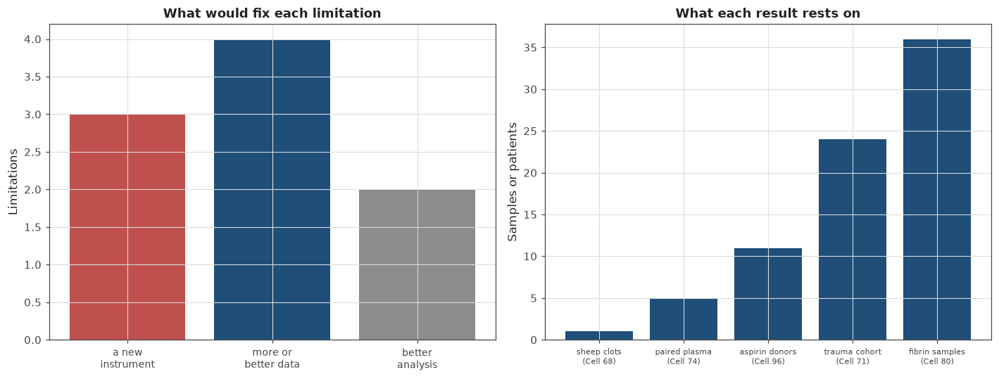

In [300]:
print("Limitations, by what would fix them")
print()
print("  limitation".ljust(58) + "would be fixed by".rjust(22) + "   cell")

limitation_records = [
    ("no critical exponent measurable on any blood dataset",
     "a new instrument", "76"),
    ("no third order response above the instrument floor",
     "a new instrument", "84"),
    ("both moduli never measured through a structural rebuild",
     "a new instrument", "94"),
    ("the best blood result rests on a single clot",
     "more data", "68"),
    ("the paired plasma comparison rests on five patients",
     "more data", "74"),
    ("the aspirin cohort is eleven men and no women",
     "more data", "96"),
    ("magnitudes disagree with the instrument by 42 percent",
     "better data or a calibration", "45"),
    ("the sampling threshold from Part 4 does not transfer",
     "better analysis", "79"),
    ("one dataset read with a fresh parser, not the splitter",
     "better analysis", "97"),
]

for limitation_text, remedy_text, cell_text in limitation_records:
    print("  " + limitation_text.ljust(56)
          + remedy_text.rjust(22)
          + "   " + cell_text)

instrument_count = 0
data_count = 0
analysis_count = 0

for limitation_text, remedy_text, cell_text in limitation_records:

    if remedy_text == "a new instrument":
        instrument_count = instrument_count + 1
    elif remedy_text == "better analysis":
        analysis_count = analysis_count + 1
    else:
        data_count = data_count + 1

print()
print("  " + str(instrument_count) + " need an instrument that does not exist, "
      + str(data_count) + " need more or better data, and "
      + str(analysis_count))
print("  are limitations of the analysis rather than of the measurement")

print()
print("The three that need an instrument")
print()
print("  part".ljust(10) + "what it needed".rjust(42)
      + "   what stopped it")

instrument_records = [
    ("Part 7", "several frequencies at the transition",
     "no rheometer sweeps faster than blood clots"),
    ("Part 8", "an amplitude inside the quadratic regime",
     "above the noise floor is already past yielding"),
    ("Part 10", "both moduli during a structural rebuild",
     "every measurement here is of blood at rest"),
]

for part_text, requirement_text, obstacle_text in instrument_records:
    print("  " + part_text.ljust(8)
          + requirement_text.rjust(42)
          + "   " + obstacle_text)

print()
print("  three parts, three different measurements, and every one of them needed to be")
print("  made while blood was changing rather than before or after")
print()
print("  they were reached independently and by different routes, which is why they are")
print("  worth more together than separately. One part finding a gap in the data is a gap")
print("  in the data. Three parts finding the same shaped gap is a description of what")
print("  instruments cannot currently do")

print()
print("The limitations of what was measured")
print()
print("  the sheep blood result is the clearest case. One clot produced 2.5 percent, a")
print("  second gave 17 percent, and the third gave nothing because it had formed before")
print("  the recording started")
print()
print("  so the headline accuracy is a sample of one, and Cell 67 established that the")
print("  other two failed for reasons of sampling rather than of method. That is the")
print("  difference between a result that would improve with better data and one that")
print("  would not, and it is why the number is quoted with the sample size attached")
print()
print("  the aspirin cohort is eleven men aged 31 to 46. Nothing in this project measured")
print("  a woman's blood, and sex differences in haematocrit alone are large enough to")
print("  matter for a quantity that depends on cell volume")
print()
print("  the 42 percent magnitude discrepancy in Part 3 is the one unexplained result in")
print("  the notebook. Both moduli are off by nearly the same factor, which leaves tan")
print("  delta untouched and every gel point definition here depends on tan delta, so it")
print("  does not propagate into any result. It would matter immediately for reporting")
print("  clot strength in pascals")

print()
print("The limitations of the analysis")
print()
print("  Part 4 measured that a detector needs about a dozen points through a transition,")
print("  and Cell 79 found that threshold does not order the errors on real data. Four")
print("  points gave 17 percent and thirty gave 75. The number described one material")
print("  rather than a general requirement, and it was used as a general requirement")
print()
print("  Cell 97 read the donor sheets with a fresh parser rather than the splitter written")
print("  in Cell 67, and fitted every donor to two interleaved curves until it was caught.")
print("  Three of the four stacked datasets in this project were handled correctly at load")
print("  and the fourth was not, for no reason other than that the code was rewritten")

print()
print("What would change the project most")
print()
print("  one measurement, and it is the same one three parts asked for independently")
print()
print("  blood measured at several frequencies with both moduli resolved, sampled through")
print("  the clotting transition rather than before or after it")
print()
print("  that single record would let Part 7 measure a critical exponent, let Part 10")
print("  test whether tan delta separates rebuilding from clotting, and let the crossover")
print("  be checked against the physical definition on the material the project is for")
print()
print("  no dataset in existence contains it, which is the finding this notebook did not")
print("  set out to make")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

remedy_labels = ["a new\ninstrument", "more or\nbetter data", "better\nanalysis"]
remedy_counts = [instrument_count, data_count, analysis_count]
remedy_colours = [COLOUR_SECONDARY, COLOUR_PRIMARY, COLOUR_NEUTRAL]

axis_array[0].bar(range(len(remedy_labels)), remedy_counts, color=remedy_colours)
axis_array[0].set_xticks(range(len(remedy_labels)))
axis_array[0].set_xticklabels(remedy_labels, fontsize=9)
axis_array[0].set_ylabel("Limitations")
axis_array[0].set_title("What would fix each limitation")

sample_labels = ["sheep clots\n(Cell 68)", "paired plasma\n(Cell 74)",
                 "aspirin donors\n(Cell 96)", "trauma cohort\n(Cell 71)",
                 "fibrin samples\n(Cell 80)"]
sample_sizes = [1, 5, 11, 24, 36]

axis_array[1].bar(range(len(sample_labels)), sample_sizes, color=COLOUR_PRIMARY)
axis_array[1].set_xticks(range(len(sample_labels)))
axis_array[1].set_xticklabels(sample_labels, fontsize=7)
axis_array[1].set_ylabel("Samples or patients")
axis_array[1].set_title("What each result rests on")

plt.tight_layout()
plt.show()

## Cell 100: The two questions, answered

The project began with two questions. Ninety nine cells later both have answers, and neither is
the answer the question expects.

**Can the gel point be detected accurately?** Yes, and the accuracy is not the limiting problem.
A detector matched a published clot time to 2.5 percent, which is well inside what that
reference disagrees with itself by. What limits the result is that it rests on one clot, that
the detection is not specific, and that the detector used has a blind spot covering half the
family of gel points.

**Is clotting the same kind of event as gelling?** Not answerable from any dataset that exists.
The measurement that would settle it has never been made on blood, and this notebook can say
exactly which measurement that is.

**Both answers converge on the same thing.** The first question is limited by specificity, which
needs both moduli through a transition. The second is limited by the exponent, which needs
several frequencies through a transition. Those are one measurement, and no instrument
currently makes it.

That convergence was not designed. Parts 7, 8 and 10 arrived at it independently, by three
different routes, and the first question arrived at it from a fourth.

Question one: can the gel point be detected accurately

  yes, and accuracy is not what limits it

  the persistent crossover matched a published clot time to 2.5 percent, inside the
  16.3 percent that reference disagrees with itself by, using a definition
  independent of the one the reference used

  on the trauma cohort two detectors built on unrelated principles agreed with each
  other to 5.1 seconds and fired before the clinical time in every patient

  what limits it                                 cell
  the blood result rests on one clot             68
  the detection is not specific                  93
  the crossover is blind to half the gel points   87
  the detectors fire before the process, not during it   93

  the specificity result is the one that matters most and it arrived last. Every
  detector a single channel instrument can run fires on blood treated so that it
  cannot coagulate, between 52 and 100 percent of the time

  so the honest form of the answer is that 

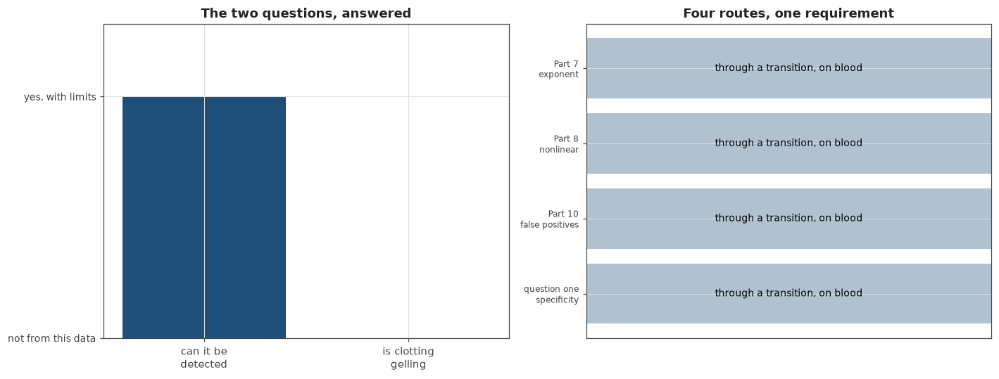

In [301]:
print("Question one: can the gel point be detected accurately")
print()
print("  yes, and accuracy is not what limits it")
print()
print("  the persistent crossover matched a published clot time to 2.5 percent, inside the")
print("  16.3 percent that reference disagrees with itself by, using a definition")
print("  independent of the one the reference used")
print()
print("  on the trauma cohort two detectors built on unrelated principles agreed with each")
print("  other to 5.1 seconds and fired before the clinical time in every patient")
print()
print("  what limits it".ljust(46) + "   cell")
print("  " + "the blood result rests on one clot".ljust(44) + "   68")
print("  " + "the detection is not specific".ljust(44) + "   93")
print("  " + "the crossover is blind to half the gel points".ljust(44) + "   87")
print("  " + "the detectors fire before the process, not during it".ljust(44) + "   93")
print()
print("  the specificity result is the one that matters most and it arrived last. Every")
print("  detector a single channel instrument can run fires on blood treated so that it")
print("  cannot coagulate, between 52 and 100 percent of the time")
print()
print("  so the honest form of the answer is that a clot which forms and is properly")
print("  measured will be detected, and its time will be right. What has not been shown is")
print("  that anything else will be rejected")

print()
print("Question two: is clotting the same kind of event as gelling")
print()
print("  not answerable from any dataset available, and the reason is specific rather than")
print("  a shortage of effort")
print()
print("  the question is about the critical exponent, which needs a power law fitted across")
print("  frequency at the transition. Three things are required at once")
print()
print("  requirement".ljust(38) + "available on blood".rjust(22) + "   cell")
print("  " + "both moduli".ljust(36) + "two of three datasets".rjust(22) + "   73")
print("  " + "at least three frequencies".ljust(36) + "none".rjust(22) + "   76")
print("  " + "measured at the transition".ljust(36) + "none".rjust(22) + "   76")
print()
print("  across all three blood datasets, zero snapshots satisfy all three")
print()
print("  and the gel point that was detected cannot substitute. The crossover is defined by")
print("  tan delta equal to one, and Winter and Chambon put tan delta at the gel point at")
print("  the tangent of n pi over two. Setting those equal forces the exponent to one half")
print("  for any material whatsoever, so a crossover derived gel point is silent about the")
print("  material by construction")

print()
print("What can be said instead")
print()

comparable_records = [
    ("blood does have a gel point in the crossover sense", "and it can be timed", "68"),
    ("clot times span a factor of 56 within one species", "on three samples", "67"),
    ("final stiffness spans a factor of 138 across those", "same three", "67"),
    ("across every material measured, time spans 797 times", "and stiffness 21,674", "78"),
    ("two exponents were measured, neither on blood", "0.69 and 0.737", "77"),
]

for statement_text, detail_text, cell_text in comparable_records:
    print("  " + statement_text.ljust(52) + detail_text.rjust(22) + "   " + cell_text)

print()
print("  the two quantities that are comparable across all these materials, time and")
print("  stiffness, differ by three and four orders of magnitude. Dividing those out is")
print("  exactly what a critical exponent does, which is why it is not one option among")
print("  several but the only dimensionless comparison in reach")

print()
print("Where the two questions meet")
print()
print("  question".ljust(14) + "limited by".rjust(26) + "which needs".rjust(38))
print("  " + "one".ljust(12) + "specificity".rjust(26)
      + "both moduli through a transition".rjust(38))
print("  " + "two".ljust(12) + "the critical exponent".rjust(26)
      + "several frequencies through a transition".rjust(38))
print()
print("  those are the same measurement. Both need blood watched while it changes, with")
print("  more than one number recorded at each instant")
print()
print("  four parts arrived at that independently. Part 7 through the exponent, Part 8")
print("  through the nonlinear response, Part 10 through the false positives, and question")
print("  one through specificity. None of them was looking for the others")

print()
print("What this project delivers")
print()

deliverable_records = [
    ("a validated extraction from a single chirp",
     "2 percent against 853 for a stepped sweep"),
    ("a method comparison across 31 configurations",
     "scored under noise, not on clean data"),
    ("seven detectors with measured accuracy and failure modes",
     "and a rule for when each can run"),
    ("repeatability floors for three reference types",
     "so agreement can be judged against something"),
    ("eight amendments that only real data could force",
     "each regression tested against the original"),
    ("a specification for the measurement that is missing",
     "frequencies, channels, coverage and floor"),
]

for deliverable_text, detail_text in deliverable_records:
    print("  " + deliverable_text.ljust(58) + detail_text)

print()
print("  the last one was not planned. It emerged from four parts failing in the same")
print("  direction, and it is the most useful thing here for an instrument that does not")
print("  exist yet")

print()
print("The measurement that would change both answers")
print()
print("  blood, sampled through the clotting transition, with both moduli resolved at three")
print("  or more frequencies, at a strain small enough to stay linear and a noise floor low")
print("  enough to see the response")
print()
print("  requirement".ljust(34) + "value".rjust(26) + "   established in")
print("  " + "frequencies at each instant".ljust(32) + "at least three".rjust(26)
      + "   Cell 76")
print("  " + "channels".ljust(32) + "two, so tan delta exists".rjust(26)
      + "   Cell 73")
print("  " + "points before the transition".ljust(32) + "a dozen, as a guide".rjust(26)
      + "   Cells 55 and 79")
print("  " + "record continues past it".ljust(32) + "required".rjust(26)
      + "   Cell 65")
print("  " + "noise floor".ljust(32) + "in pascals, not percent".rjust(26)
      + "   Cell 62")
print()
print("  that specification is the project's answer to a question nobody asked it. Both of")
print("  the questions it was asked reduce to whether that measurement can be made, and it")
print("  cannot be made with anything currently available")

figure_object, axis_array = plt.subplots(1, 2, figsize=(13, 5))

question_labels = ["can it be\ndetected", "is clotting\ngelling"]
question_answers = [1.0, 0.0]
question_colours = [COLOUR_PRIMARY, COLOUR_SECONDARY]

axis_array[0].bar(range(len(question_labels)), question_answers,
                  color=question_colours)
axis_array[0].set_xticks(range(len(question_labels)))
axis_array[0].set_xticklabels(question_labels, fontsize=10)
axis_array[0].set_yticks([0, 1])
axis_array[0].set_yticklabels(["not from this data", "yes, with limits"], fontsize=9)
axis_array[0].set_ylim(0.0, 1.3)
axis_array[0].set_title("The two questions, answered")

route_labels = ["Part 7\nexponent", "Part 8\nnonlinear",
                "Part 10\nfalse positives", "question one\nspecificity"]

axis_array[1].barh(range(len(route_labels)), [1.0] * len(route_labels),
                   color=COLOUR_PRIMARY, alpha=0.35)

for route_index in range(len(route_labels)):
    axis_array[1].text(0.5, route_index, "through a transition, on blood",
                       ha="center", va="center", fontsize=9, color="black")

axis_array[1].set_yticks(range(len(route_labels)))
axis_array[1].set_yticklabels(route_labels, fontsize=8)
axis_array[1].invert_yaxis()
axis_array[1].set_xticks([])
axis_array[1].set_xlim(0.0, 1.0)
axis_array[1].set_title("Four routes, one requirement")

plt.tight_layout()
plt.show()